---
title: "Step 2.2. SHAP-informed Cox models: sequential discovery"
description: |
  This notebook continues the completed Full-Cox comparison from step 2.1.
  It applies the accepted XGBoost/TreeSHAP selection rules, preserves complete
  categorical families, and retains first-imputation collinearity and proportional-hazards diagnostics,
  then prepares every sequential candidate for matched CV and repeated calibration.
  Later interactions and functional forms must retain the preceding accepted
  specification. Development imputations are reused across internal CV folds;
  the complete preprocessing and selection workflow is not independently
  validated by that CV. The current execution stage is identified explicitly.
date: last-modified
author: "Andres Gonzalez-Santa Cruz"
bibliography: [_lit/refs.bib]
csl: "_lit/american-medical-association.csl" # (Optional: citation style, e.g., APA)
toc: true
toc-location: left
toc-float: true
format:
  html:
    css: ["_lib/styles.scss", "_lib/prediction_metrics_compact.css"]
    code-fold: true
    embed-resources: true
    theme: 
      - journal #https://quarto.org/docs/output-formats/html-themes-more.html
    fig-cap-location: top  
    toc: true
    toc-location: left
execute:
  error: false       # Stop at the first execution error
  echo: true         # Show R code in the output
  warning: true      # Show warnings
  message: true      # Show messages from the code
  freeze: auto       # Use cache to speed up rendering if there are no changes
editor: source
execute-dir: project
lightbox: auto
---

## Entry from 06
The investigator instructed continuation after reviewing 06. The Full reference retains treatment-modality and rule-violation/undetermined-discharge strata. Its calibration tradeoff remains visible below. This does not automatically stratify the SHAP-informed models: their original diagnostic sequence is preserved.

This notebook reuses the five completed-development imputations and the accepted 03 selection. It does not refit imputers, XGBoost tuning, TreeSHAP or rank bootstrap. The first executable stage prepares formulas and first-imputation diagnostics. Later predictive comparisons, interactions and functional forms require their own sequential decisions; preparation is not their completion.

**Current checkpoint:** all 16 remaining single-change comparisons are executed, alongside the two completed age trials. The final sources and decision flowchart are below. The investigator-authorized rule retains b/e; any changed published rounding remains explicitly flagged for a separate manuscript review.

**Actual fitting run:** 4,900 predictive fits and 80 descriptive AICc fits; 77.72 minutes; peak sampled R working set 10.39 GiB. The immutable evidence is [07_remaining_execution.json](../docs/07_remaining_execution.json). A later presentation replay reads those saved results and reports zero **new** fits.


In [1]:
#| label: shap-config-and-environment
#| message: false
.t0 <- proc.time()
# Preserve Unicode labels when the Windows startup locale falls back to C.
if (.Platform$OS.type == "windows") stopifnot(nzchar(Sys.setlocale("LC_CTYPE", "English_United States.utf8")))
# Locate the only configuration file from either the project or notebook directory.
root <- normalizePath(getwd(), winslash = "/", mustWork = TRUE)
while (!file.exists(file.path(root, "config.yml"))) {
  parent <- dirname(root)
  if (identical(parent, root)) stop("config.yml was not found.", call. = FALSE)
  root <- parent
}
config <- yaml::read_yaml(file.path(root, "config.yml"))
resolve_path <- function(value) {
  absolute <- grepl("^([A-Za-z]:[/\\\\]|/|\\\\\\\\)", value)
  normalizePath(if (absolute) value else file.path(root, value), winslash = "/", mustWork = FALSE)
}
source_path <- function(name) resolve_path(config$sources[[name]])
object_dir <- resolve_path(config$paths$objects)
stopifnot(dir.exists(object_dir))
table_dir <- resolve_path(config$paths$tables)
# Limit threads before scientific namespaces load and verify the selected R environment.
threads <- as.integer(config$imputation$threads)
Sys.setenv(OMP_NUM_THREADS = threads, OPENBLAS_NUM_THREADS = threads, MKL_NUM_THREADS = threads, R_RANGER_NUM_THREADS = threads)
options(Ncpus = threads, ranger.num.threads = threads)
lock <- jsonlite::read_json(resolve_path(config$runtime$r_lock), simplifyVector = FALSE)
packages <- c("yaml", "jsonlite", "nanoparquet", "digest", "ps", "xml2", "future", "survival", "rms", "janitor", "ggplot2")
stopifnot(as.character(getRversion()) == lock$R$Version)
display_packages <- c("htmltools", "knitr", "IRdisplay")
for (package in c(packages, display_packages)) {
  if (!requireNamespace(package, quietly = TRUE)) stop("Missing package: ", package, call. = FALSE)
  expected <- lock$Packages[[package]]$Version
  if (is.null(expected) || utils::packageVersion(package) != base::package_version(expected)) stop("Package version differs from lock: ", package, call. = FALSE)
}
if (requireNamespace("future", quietly = TRUE)) future::plan(future::sequential)
set.seed(as.integer(config$imputation$seed))
written <- character()
run_started <- Sys.time()
# Reuse the original htmltools/knitr table pattern, with scrolling and immediate notebook display.
show_table <- function(data, caption) {
  widget <- htmltools::browsable(htmltools::tags$div(class = "article2-table", role = "region", tabindex = 0, `aria-label` = caption, style = "max-height:420px;overflow:auto;max-width:100%;border:1px solid #ddd;padding:0.4rem;margin-bottom:0.8rem;", htmltools::HTML(knitr::kable(data, format = "html", caption = caption, row.names = FALSE, digits = 4, escape = TRUE))))
  IRdisplay::display_html(as.character(widget))
  invisible(widget)
}
show_table(data.frame(Package = c(packages, display_packages), Version = vapply(c(packages, display_packages), function(x) as.character(utils::packageVersion(x)), character(1L))), "Verified execution packages")
memory <- ps::ps_system_memory()
show_table(data.frame(Item = c("Total RAM (GiB)", "Available RAM (GiB)", "Threads"), Value = c(memory$total / 1024^3, memory$avail / 1024^3, threads)), "Resources before execution")
cat("Kernel process:", Sys.getpid(), "\n")
shap_settings <- config$cox_shap
initial_review_accepted <- FALSE
stopifnot(shap_settings$mode %in% c("prepare", "diagnostics"), threads <= 2L)
cat("Stage:", shap_settings$mode, "| Threads:", threads, "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Package,Version
yaml,2.3.10
jsonlite,1.9.1
nanoparquet,0.4.2
digest,0.6.37
ps,1.9.3
xml2,1.3.8
future,1.67.0
survival,3.6.4
rms,8.0.0
janitor,2.2.1


Item,Value
Total RAM (GiB),95.6941
Available RAM (GiB),62.2250
Threads,2.0000


Kernel process: 91920 


Stage: diagnostics | Threads: 2 


Elapsed: 0.052 minutes


In [2]:
#| label: shap-review-completed-full-reference
#| message: false
.t0 <- proc.time()
# Read completed results rather than fitting the Full reference again.
entry <- jsonlite::read_json(source_path("cox_performance_execution"), simplifyVector = TRUE)
stopifnot(identical(entry$status, "complete_comparisons_pending_investigator_choice"), entry$snapshot$metric_control_max < 1e-8, entry$snapshot$calibration_control_max < 1e-8)
stopifnot(identical(entry$snapshot$performance_signature, shap_settings$reference_performance_signature))
reference_metrics <- entry$snapshot$metrics
reference_calibration <- entry$snapshot$calibration
show_table(entry$snapshot$sequential, "06 entry checkpoint: sequential changes already reviewed")
show_table(reference_metrics[reference_metrics$Stage == "stratified", c("Outcome", "Horizon", "C", "IBS")], "Full reference carried forward from 06")
show_table(reference_calibration[reference_calibration$Stage == "stratified", ], "Full reference calibration; stratification did not improve every metric")
cat("Continuation authorized; the Full reference is retained. No new candidate is selected by this cell.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,From,To,Horizon,Delta_C,Delta_IBS
readmission,full,reduced,6,0.0000,0e+00
readmission,full,reduced,12,0.0000,0e+00
readmission,full,reduced,36,0.0001,0e+00
readmission,full,reduced,60,0.0000,0e+00
readmission,reduced,stratified,6,0.0011,-1e-04
readmission,reduced,stratified,12,0.0002,0e+00
readmission,reduced,stratified,36,-0.0002,0e+00
readmission,reduced,stratified,60,-0.0001,0e+00
death,full,reduced,6,0.0002,0e+00
death,full,reduced,12,0.0002,0e+00


Outcome,Horizon,C,IBS
readmission,6,0.6437,0.0387
readmission,12,0.6312,0.0610
readmission,36,0.6146,0.1085
readmission,60,0.6094,0.1333
death,6,0.7835,0.0044
death,12,0.7663,0.0064
death,36,0.7652,0.0144
death,60,0.7634,0.0218


Outcome,Stage,Horizon,ICI,ECE,EO
readmission,stratified,6,0.0065,0.0021,0.9899
readmission,stratified,12,0.0080,0.0027,0.9901
readmission,stratified,36,0.0096,0.0040,0.9882
readmission,stratified,60,0.0102,0.0050,0.9849
death,stratified,6,0.0024,0.0007,1.0069
death,stratified,12,0.0031,0.0010,1.0096
death,stratified,36,0.0067,0.0022,1.0142
death,stratified,60,0.0090,0.0023,1.0244


Continuation authorized; the Full reference is retained. No new candidate is selected by this cell.


Elapsed: 0.001 minutes


In [3]:
#| label: shap-load-completed-development
#| message: false
.t0 <- proc.time()
# Reuse the exact development matrices exported by 06; retain the fixed patient order.
matrix_bundle <- readRDS(source_path("cox_development_matrices"))
stopifnot(identical(matrix_bundle$signature, shap_settings$reference_cox_signature))
py_corrected_datasets <- matrix_bundle$value
rm(matrix_bundle)
split <- nanoparquet::read_parquet(source_path("split"))
split <- split[order(split$row_id), ]
train <- as.logical(split$is_train)
expected_ids <- as.integer(split$row_id[train])
stopifnot(length(py_corrected_datasets) == 5L, !anyDuplicated(expected_ids))
for (d in py_corrected_datasets) {
  stopifnot(identical(as.integer(d$row_id), expected_ids), identical(names(d), names(py_corrected_datasets[[1L]])))
  stopifnot(!anyNA(d[setdiff(names(d), "center_id")]))
  for (v in c("readmit_event", "readmit_time_from_disch_m", "death_event", "death_time_from_disch_m")) stopifnot(identical(d[[v]], py_corrected_datasets[[1L]][[v]]))
}
show_table(data.frame(Imputation = seq_along(py_corrected_datasets), Development_rows = vapply(py_corrected_datasets, nrow, integer(1L)), Columns = vapply(py_corrected_datasets, ncol, integer(1L))), "Verified 06 matrices: no new imputation or encoding")
cat("Preprocessing was fitted to complete development before CV. Internal CV does not independently validate that preprocessing.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Imputation,Development_rows,Columns
1,70521,76
2,70521,76
3,70521,76
4,70521,76
5,70521,76


Preprocessing was fitted to complete development before CV. Internal CV does not independently validate that preprocessing.


Elapsed: 0.016 minutes


## Fixed predictor-selection rule
Use stability of at least 90% in the top 45, then an upper bootstrap rank of at most 20 for readmission or at least 10% of maximum importance for mortality. The implemented historical selector is deterministic; its optional CV confirmation does not select predictors by stepwise C-index or AIC.

When one category of a nominal variable passes, include the original complete category family. Treatment modality enters only as a stratum. This explains why SHAP signals and Cox columns have different counts. First substance remains at its selected level, following the original exception.

In [4]:
#| label: shap-original-encoding-contract
#| message: false
.t0 <- proc.time()
# Reuse the original reference categories, dummy construction and first-substance grouping.
cox_columns <- c(
"adm_age_rec3", "porc_pobr", "dit_m", "national_foreign",
  "ethnicity", "dg_psiq_cie_10_instudy", "dg_psiq_cie_10_dg",
  "dx_f3_mood", "dx_f6_personality", "dx_f_any_severe_mental",
  "any_phys_dx", "polysubstance_strict",
  "sex_rec_woman", "cohabitation_family_of_origin",
  "cohabitation_with_couple_children", "cohabitation_others",
  "sub_dep_icd10_status_drug_dependence",
  "any_violence_1_domestic_violence_sex_abuse", "tr_outcome_referral",
  "tr_outcome_dropout", "tr_outcome_adm_discharge_rule_violation_undet",
  "tr_outcome_adm_discharge_adm_reasons",
  "adm_motive_sanitary_sector", "adm_motive_another_sud_facility_fonodrogas_senda_previene",
  "adm_motive_justice_sector", "adm_motive_other", "first_sub_used_alcohol",
  "first_sub_used_cocaine_paste", "first_sub_used_cocaine_powder", "first_sub_used_other",
  "primary_sub_mod_cocaine_paste", "primary_sub_mod_cocaine_powder",
   "primary_sub_mod_alcohol", "primary_sub_mod_others",
  "tipo_de_vivienda_rec2_other_unknown", "plan_type_corr_pg_pr",
  "plan_type_corr_m_pr", "plan_type_corr_pg_pai", "plan_type_corr_m_pai",
  "occupation_condition_corr24_unemployed", "occupation_condition_corr24_inactive",
  "marital_status_rec_single", "marital_status_rec_separated_divorced_annulled_widowed",
  "tenure_status_household_renting",
  "tenure_status_household_others",
  "tenure_status_household_stays_temporarily_with_a_relative",
  "tenure_status_household_illegal_settlement",
  "urbanicity_cat_2_mixed",
  "urbanicity_cat_1_rural",
  "evaluacindelprocesoteraputico_logro_intermedio", "evaluacindelprocesoteraputico_logro_minimo",
  "eva_consumo_logro_intermedio", "eva_consumo_logro_minimo",
  "eva_fam_logro_intermedio", "eva_fam_logro_minimo",
  "eva_relinterp_logro_intermedio", "eva_relinterp_logro_minimo",
  "eva_ocupacion_logro_intermedio", "eva_ocupacion_logro_minimo",
  "eva_sm_logro_intermedio", "eva_sm_logro_minimo",
  "eva_fisica_logro_intermedio", "eva_fisica_logro_minimo",
  "eva_transgnorma_logro_intermedio", "eva_transgnorma_logro_minimo",
  "prim_sub_freq_rec_2_2_6_days_wk",
  "prim_sub_freq_rec_3_daily",
  "ed_attainment_corr_2_completed_high_school_or_less",
  "ed_attainment_corr_3_completed_primary_school_or_less"
)
DUMMY_REFERENCE <- c(
sex_rec = "man",
  plan_type_corr = "pg-pab",
  marital_status_rec = "married/cohabiting",
  cohabitation = "alone",
  sub_dep_icd10_status = "hazardous consumption",
  tr_outcome = "completion",
  adm_motive = "spontaneous consultation",
  tipo_de_vivienda_rec2 = "formal housing",
  occupation_condition_corr24 = "employed",
  any_violence = "0.No domestic violence/sex abuse",
  first_sub_used = "marijuana",
  primary_sub_mod = "marijuana",
  tenure_status_household = "owner/transferred dwellings/pays dividends",
  urbanicity_cat = "3.Urban",
  evaluacindelprocesoteraputico = "logro alto",
  eva_consumo = "logro alto",
  eva_fam = "logro alto",
  eva_relinterp = "logro alto",
  eva_ocupacion = "logro alto",
  eva_sm = "logro alto",
  eva_fisica = "logro alto",
  eva_transgnorma = "logro alto",
  prim_sub_freq_rec = "1.\u22641 day/wk",
  ed_attainment_corr = "1-More than high school"
)
set_reference_levels <- function(df, refs = DUMMY_REFERENCE) {
  for (col in intersect(names(refs), names(df))) {
    values <- trimws(as.character(df[[col]]))
    ref <- refs[[col]]
    cats <- unique(values)
    df[[col]] <- if (ref %in% cats) {
      factor(values, levels = c(ref, cats[cats != ref]), ordered = FALSE)
    } else {
      factor(values, ordered = FALSE)
    }
  }
  df
}
make_dummies <- function(df) {
  cat_cols <- names(df)[vapply(df, function(x) is.character(x) || is.factor(x), logical(1))]
  if (!length(cat_cols)) return(df)
  cat_df <- as.data.frame(df[cat_cols], stringsAsFactors = FALSE)
  cat_df[] <- lapply(cat_df, function(x) {
    x <- factor(x)
    x <- addNA(x, ifany = TRUE)
    lev <- levels(x)
    lev[is.na(lev)] <- "__MISSING__"
    levels(x) <- paste0("_", lev)
    x
  })
  mm <- model.matrix(~ ., data = cat_df) |> as.data.frame(check.names = FALSE)
  mm[["(Intercept)"]] <- NULL
  cbind(df[setdiff(names(df), cat_cols)], mm)
}
collapse_first_sub_used_other <- function(df) {
  cols_to_group <- c(
    "first_sub_used_opioids", "first_sub_used_others",
    "first_sub_used_hallucinogens", "first_sub_used_inhalants",
    "first_sub_used_tranquilizers_hypnotics",
    "first_sub_used_amphetamine_type_stimulants"
  )
  cols_present <- intersect(cols_to_group, names(df))
  df$first_sub_used_other <- if (length(cols_present)) {
    as.integer(rowSums(df[cols_present], na.rm = TRUE) > 0)
  } else {
    0L
  }
  df
}
# Only model predictors enter dummy encoding; identities and outcomes remain metadata.
natural_predictors <- cox_columns[seq_len(12L)]
predictors <- setdiff(cox_columns, grep("^plan_type_corr_", cox_columns, value = TRUE))
endpoint_columns <- c("readmit_event", "readmit_time_from_disch_m", "death_event", "death_time_from_disch_m")
encode_development <- function(data, keep) {
  stopifnot(length(keep) == nrow(data), !anyNA(keep))
  input <- data[keep, unique(c(natural_predictors, names(DUMMY_REFERENCE))), drop = FALSE]
  stopifnot(!anyNA(input))
  encoded <- collapse_first_sub_used_other(janitor::clean_names(make_dummies(set_reference_levels(input))))
  missing <- setdiff(cox_columns, names(encoded))
  if (length(missing)) stop("Missing encoded Cox columns: ", paste(missing, collapse = ", "))
  encoded <- encoded[cox_columns]
  encoded[endpoint_columns] <- data[keep, endpoint_columns, drop = FALSE]
  # Preserve the original numeric metadata conversion without creating missing values.
  encoded$center_id <- as.numeric(as.character(data$center_id[keep]))
  stopifnot(identical(is.na(encoded$center_id), is.na(data$center_id[keep])))
  encoded$row_id <- which(keep)
  plan_columns <- grep("^plan_type_corr_", names(encoded), value = TRUE)
  stopifnot(all(rowSums(encoded[plan_columns]) <= 1))
  plan_from_dummies <- rep("pg-pab", nrow(encoded))
  for (plan in c("pg-pr", "m-pr", "pg-pai", "m-pai")) plan_from_dummies[encoded[[paste0("plan_type_corr_", gsub("-", "_", plan))]] == 1] <- plan
  stopifnot(identical(as.character(input$plan_type_corr), plan_from_dummies))
  encoded$plan_type_strata <- factor(plan_from_dummies)
  for (v in c("readmit_time_from_disch_m", "death_time_from_disch_m")) encoded[[v]][encoded[[v]] <= 0] <- 1e-6
  stopifnot(!anyNA(encoded[c(cox_columns, endpoint_columns, "plan_type_strata", "row_id")]), nrow(encoded) == sum(keep))
  encoded
}
# Bind strata in the formula environment: namespace-qualified strata inside the formula is not used.
formula_environment <- new.env(parent = asNamespace("survival"))
make_cox_formula <- function(outcome, terms = predictors, extra_stratum = FALSE) {
  response <- if (outcome == "readmission") "Surv(readmit_time_from_disch_m, readmit_event)" else "Surv(death_time_from_disch_m, death_event)"
  rhs <- c(terms, "strata(plan_type_strata)", if (extra_stratum) "strata(tr_outcome_adm_discharge_rule_violation_undet)")
  stats::as.formula(paste(response, "~", paste(rhs, collapse = " + ")), env = formula_environment)
}
removed_collinear <- "evaluacindelprocesoteraputico_logro_minimo"
discharge_stratum <- "tr_outcome_adm_discharge_rule_violation_undet"
cox_formulas <- lapply(c("readmission", "death"), function(outcome) list(full = make_cox_formula(outcome), reduced = make_cox_formula(outcome, setdiff(predictors, removed_collinear)), stratified = make_cox_formula(outcome, setdiff(predictors, c(removed_collinear, discharge_stratum)), TRUE)))
names(cox_formulas) <- c("readmission", "death")
stopifnot(length(predictors) == 65L, !"phys_dx_instudy" %in% predictors, "any_phys_dx" %in% predictors)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [5]:
#| label: shap-english-labels-and-display
#| message: false
.t0 <- proc.time()
# Apply English names only to display copies; technical names, coding and models stay intact.
variable_labels <- utils::read.csv(source_path("variable_labels"), stringsAsFactors = FALSE, check.names = FALSE, fileEncoding = "UTF-8")
stopifnot(!anyDuplicated(variable_labels$technical_name), all(cox_columns %in% variable_labels$technical_name), all(nzchar(variable_labels$display_label)))
term_labels <- stats::setNames(variable_labels$display_label, variable_labels$technical_name)
term_labels["plan_type_strata"] <- "Treatment setting"
display_term <- function(x, width = NULL) {
  key <- sub("TRUE$", "", as.character(x))
  label <- unname(term_labels[key])
  label[is.na(label)] <- as.character(x)[is.na(label)]
  if (is.null(width)) return(label)
  vapply(label, function(value) paste(strwrap(value, width = width), collapse = "\n"), character(1L))
}
if (!exists("show_table_original", inherits = FALSE)) show_table_original <- show_table
# The established dictionary is reused for every diagnostic display.
show_table <- function(data, caption) {
  for (column in intersect(c("Term", "Variable", "Variable1", "Variable2", "Predictor"), names(data))) data[[column]] <- display_term(data[[column]])
  show_table_original(data, caption)
}
# Render at a fixed size and discard temporary diagnostic images after display.
show_diagnostic_png <- function(draw, width, height) {
  image_path <- tempfile(fileext = ".png")
  on.exit(unlink(image_path), add = TRUE)
  grDevices::png(image_path, width = width, height = height, res = 110)
  tryCatch(draw(), finally = grDevices::dev.off())
  IRdisplay::display_png(file = image_path)
}
cat("Display dictionary covers all", length(cox_columns), "encoded columns. No predictor, category, reference level or model formula was changed.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Display dictionary covers all 69 encoded columns. No predictor, category, reference level or model formula was changed.


Elapsed: 0.000 minutes


In [6]:
#| label: shap-read-reviewed-treeshap-sources
#| message: false
.t0 <- proc.time()
# Validate the accepted 03 tables and recompute their deterministic eligibility flags.
stopifnot(all(c("3a23ecf2c677", "91562d3f6d49") %in% unlist(config$xgboost_combined$accepted_discrepancy_signatures)))
selected_source <- utils::read.csv(source_path("cox_shap_predictors"), stringsAsFactors = FALSE, check.names = FALSE)
interaction_source <- utils::read.csv(source_path("cox_shap_interactions"), stringsAsFactors = FALSE, check.names = FALSE)
historical_source <- utils::read.csv(source_path("combined_original_predictors"), stringsAsFactors = FALSE, check.names = FALSE)
as_flag <- function(x) as.character(x) %in% c("TRUE", "True", "true", "1")
pass_rule <- as_flag(selected_source$stable_freq_ge_90pct) & ifelse(selected_source$outcome == "Readmission", selected_source$rank_ci97p5 <= config$xgboost_combined$readmission_rank_ci_upper_max, selected_source$rel_to_max_pct >= config$xgboost_combined$mortality_importance_percent_of_max_min)
stopifnot(identical(pass_rule, as_flag(selected_source$qualifies_main_rule)))
ordinary_rule <- pass_rule & !startsWith(selected_source$feature, "plan_type")
stopifnot(identical(ordinary_rule, as_flag(selected_source$qualifies_etable3)))
show_table(selected_source[ordinary_rule, c("outcome", "feature", "rank_ci97p5", "rel_to_max_pct")], "Accepted 03 signals before complete-category expansion")
show_table(interaction_source[c("outcome", "main_feature", "interactor", "abs_corr", "smd_binarized")], "Accepted interaction candidates from 03; not yet Cox terms")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

outcome,feature,rank_ci97p5,rel_to_max_pct
Readmission,primary_sub_mod_cocaine_paste,1,100.0000
Readmission,adm_age_rec3,2,86.1615
Readmission,porc_pobr,3,80.8107
Readmission,sex_rec_woman,4,77.4986
Readmission,ethnicity,7,59.4849
Readmission,dit_m,8,51.0295
Readmission,eva_consumo,9,50.3699
Readmission,ed_attainment_corr,10,43.3516
Readmission,occupation_condition_corr24_unemployed,11,38.0870
Readmission,dg_psiq_cie_10_dg,12,29.9269


outcome,main_feature,interactor,abs_corr,smd_binarized
Death,primary_sub_mod_alcohol,adm_age_rec3,0.2264,-0.4252
Death,occupation_condition_corr24_unemployed,adm_age_rec3,0.1315,0.2319
Death,primary_sub_mod_alcohol,prim_sub_freq_rec,0.1314,-0.1913
Death,cohabitation_with_couple_children,adm_age_rec3,0.1278,0.2127
Death,any_phys_dx,primary_sub_mod_alcohol,0.1122,-0.2384
Death,eva_fisica,adm_age_rec3,0.1024,-0.1590
Readmission,primary_sub_mod_cocaine_powder,first_sub_used_alcohol,0.1454,-0.2940
Readmission,eva_consumo,tr_outcome_referral,0.1335,0.4227
Readmission,sex_rec_woman,primary_sub_mod_others,0.1220,-0.9194


Elapsed: 0.001 minutes


In [7]:
#| label: shap-complete-families-and-formulas
#| message: false
.t0 <- proc.time()
# Preserve the original complete-family resolver and its first-substance exception.
CFG <- list(exclude_prefixes = "plan_type")
FAMILY_MAP <- list()
FAMILY_GROUPS <- c("primary_sub_mod", "tr_outcome", "adm_motive", "occupation_condition_corr24", "marital_status_rec", "tenure_status_household", "cohabitation", "urbanicity_cat")
resolve_columns <- function(feature, data, exclude = CFG$exclude_prefixes) {
  if (length(exclude) && any(startsWith(feature, exclude))) return(character(0))      # via strata
  if (!is.null(FAMILY_MAP[[feature]])) return(intersect(FAMILY_MAP[[feature]], names(data)))
  # nominal multi-level family -> bring ALL its categories
  grp <- FAMILY_GROUPS[vapply(FAMILY_GROUPS, function(s) startsWith(feature, s), logical(1))]
  if (length(grp)) {
    stem <- grp[which.max(nchar(grp))]
    cols <- names(data)[startsWith(names(data), paste0(stem, "_"))]
    cols <- cols[!grepl("(_score|_any)$", cols)]
    if (length(exclude))
      cols <- cols[!vapply(cols, function(cc) any(startsWith(cc, exclude)), logical(1))]
    if (length(cols)) return(cols)
  }
  if (feature %in% names(data)) return(feature)                                       # binary/continuous/factor
  fam <- names(data)[startsWith(names(data), paste0(feature, "_"))]                   # ordinal dummies var_*
  fam <- fam[!grepl("(_score|_any)$", fam)]
  if (length(fam)) return(fam)
  warning(sprintf("Variable '%s' not found in data; skipped.", feature))
  character(0)
}
outcome_tags <- c(readmission = "Readmission", death = "Death")
rule_columns <- function(table, outcome) {
  keep <- table$outcome == outcome_tags[[outcome]] & as_flag(table$stable_freq_ge_90pct)
  keep <- keep & if (outcome == "readmission") table$rank_ci97p5 <= 20 else table$rel_to_max_pct >= 10
  features <- table$feature[which(keep)]
  features <- features[!startsWith(features, "plan_type")]
  mapping <- lapply(features, function(f) {
    columns <- resolve_columns(f, py_corrected_datasets[[1L]])
    stopifnot(length(columns) > 0L)
    data.frame(Outcome = outcome, SHAP_feature = f, Cox_column = columns)
  })
  mapping <- do.call(rbind, mapping)
  list(features = features, columns = unique(mapping$Cox_column), mapping = mapping)
}
new_selection <- lapply(names(outcome_tags), function(o) rule_columns(selected_source, o))
old_selection <- lapply(names(outcome_tags), function(o) rule_columns(historical_source, o))
names(new_selection) <- names(old_selection) <- names(outcome_tags)
shap_formula <- function(outcome, columns, strata = "plan_type_strata") {
  response <- if (outcome == "readmission") "Surv(readmit_time_from_disch_m, readmit_event)" else "Surv(death_time_from_disch_m, death_event)"
  stats::as.formula(paste(response, "~", paste(c(setdiff(columns, strata), paste0("strata(", strata, ")")), collapse = " + ")), env = formula_environment)
}
shap_formulas <- lapply(names(outcome_tags), function(o) shap_formula(o, new_selection[[o]]$columns))
historical_shap_formulas <- lapply(names(outcome_tags), function(o) shap_formula(o, old_selection[[o]]$columns))
names(shap_formulas) <- names(historical_shap_formulas) <- names(outcome_tags)
formula_mapping <- do.call(rbind, lapply(new_selection, `[[`, "mapping"))
formula_mapping$Predictor <- display_term(formula_mapping$Cox_column)
show_table(formula_mapping, "Trace every accepted SHAP signal to its Cox columns")
selection_comparison <- do.call(rbind, lapply(names(outcome_tags), function(o) data.frame(Outcome = o, Previous_signals = length(old_selection[[o]]$features), Current_signals = length(new_selection[[o]]$features), Previous_columns = length(old_selection[[o]]$columns), Current_columns = length(new_selection[[o]]$columns), Added_columns = paste(setdiff(new_selection[[o]]$columns, old_selection[[o]]$columns), collapse = "; "), Removed_columns = paste(setdiff(old_selection[[o]]$columns, new_selection[[o]]$columns), collapse = "; "))))
show_table(selection_comparison, "Formula changes inherited from the accepted 03 selection")
for (o in names(shap_formulas)) { cat(o, "initial formula:\n"); print(shap_formulas[[o]]) }
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,SHAP_feature,Cox_column,Predictor
readmission,primary_sub_mod_cocaine_paste,primary_sub_mod_cocaine_paste,Cocaine paste (primary at admission)
readmission,primary_sub_mod_cocaine_paste,primary_sub_mod_cocaine_powder,Cocaine hydrochloride (primary at admission)
readmission,primary_sub_mod_cocaine_paste,primary_sub_mod_alcohol,Alcohol (primary at admission)
readmission,primary_sub_mod_cocaine_paste,primary_sub_mod_others,Other substance (primary at admission)
readmission,adm_age_rec3,adm_age_rec3,"Age at admission, yr"
readmission,porc_pobr,porc_pobr,Communal poverty rate
readmission,sex_rec_woman,sex_rec_woman,Women
readmission,ethnicity,ethnicity,Recorded Indigenous ethnicity
readmission,dit_m,dit_m,"Treatment episode length, mo"
readmission,eva_consumo,eva_consumo_logro_intermedio,"Discharge evaluation, substance use: intermediate achievement"


Outcome,Previous_signals,Current_signals,Previous_columns,Current_columns,Added_columns,Removed_columns
readmission,18,18,28,28,,
death,7,11,15,26,eva_fisica_logro_intermedio; eva_fisica_logro_minimo; tr_outcome_referral; tr_outcome_dropout; tr_outcome_adm_discharge_rule_violation_undet; tr_outcome_adm_discharge_adm_reasons; adm_motive_sanitary_sector; adm_motive_another_sud_facility_fonodrogas_senda_previene; adm_motive_justice_sector; adm_motive_other; sex_rec_woman,


readmission initial formula:
Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + 
    primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + 
    primary_sub_mod_others + adm_age_rec3 + porc_pobr + sex_rec_woman + 
    ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + 
    ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + 
    occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + 
    dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + 
    polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + 
    tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + 
    tr_outcome_adm_discharge_adm_reasons + evaluacindelprocesoteraputico_logro_intermedio + 
    evaluacindelprocesoteraputico_logro_minimo + prim_sub_freq_rec_2_2_6_days_wk + 
    prim_sub_freq_rec_3_daily + strata(plan_type_strata)


Elapsed: 0.001 minutes


In [8]:
#| label: shap-verify-historical-formula-control
#| message: false
.t0 <- proc.time()
# Match the deterministic historical selection to saved final formulas, reversing only the original PH/collinearity step.
historical_risk <- readRDS(source_path("cox_c_control"))
formula_controls <- lapply(names(outcome_tags), function(o) {
  saved <- stats::as.formula(historical_risk$f_txt[[o]][["shap"]], env = formula_environment)
  restored <- if (o == "readmission") stats::update(saved, . ~ . - strata(tr_outcome_adm_discharge_rule_violation_undet) + tr_outcome_adm_discharge_rule_violation_undet + evaluacindelprocesoteraputico_logro_minimo) else stats::update(saved, . ~ . - strata(any_phys_dx) + any_phys_dx)
  equal <- setequal(attr(stats::terms(restored), "term.labels"), attr(stats::terms(historical_shap_formulas[[o]]), "term.labels"))
  stopifnot(equal)
  data.frame(Outcome = o, Historical_terms_reproduced = equal, Model_columns = length(old_selection[[o]]$columns))
})
show_table(do.call(rbind, formula_controls), "Historical formula control passed before fitting new candidates")
rm(historical_risk)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Historical_terms_reproduced,Model_columns
readmission,TRUE,28
death,TRUE,15


Elapsed: 0.011 minutes


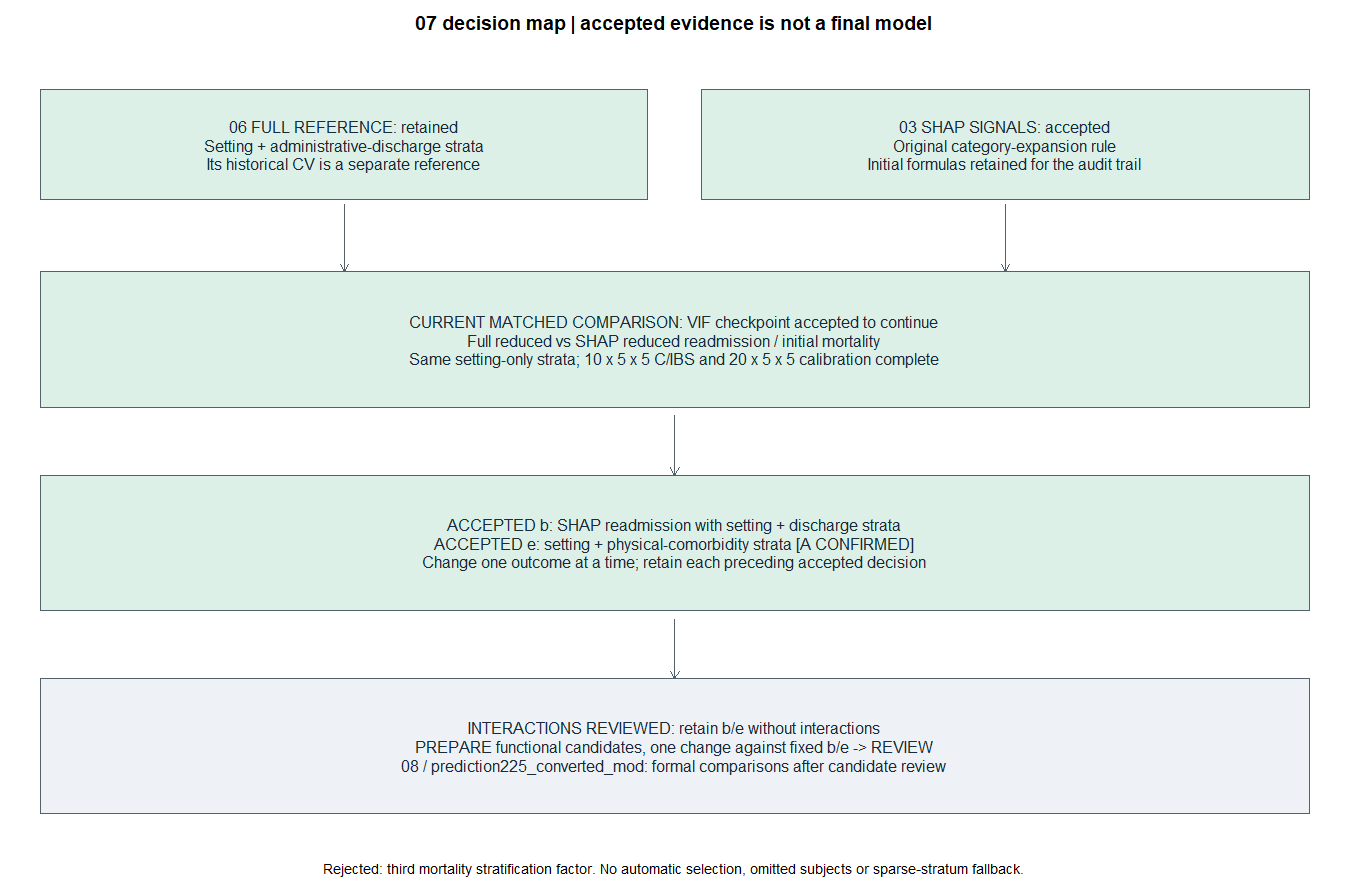

Elapsed: 0.000 minutes


In [9]:
#| label: shap-discovery-flowchart
#| message: false
.t0 <- proc.time()
# Reuse base graphics for compact embedded decision diagrams; status is written as well as coloured.
decision_canvas <- function(title) {
  graphics::par(mar = c(0, 0, 2, 0))
  graphics::plot.new(); graphics::plot.window(xlim = c(0, 1), ylim = c(0, 1), xaxs = "i", yaxs = "i")
  graphics::title(main = title, cex.main = 1.05)
}
decision_box <- function(x1, x2, y, text, status = "pending", h = 0.065, cex = 0.86) {
  colors <- c(accepted = "#ddf0e8", prepared = "#fff0c2", pending = "#eef1f5", review = "#dceaf8", rejected = "#f5dddd")
  graphics::rect(x1, y - h, x2, y + h, col = colors[[status]], border = "#52616b")
  graphics::text((x1 + x2) / 2, y, text, cex = cex, col = "#172b3a")
}
decision_arrow <- function(x1, y1, x2 = x1, y2) graphics::arrows(x1, y1, x2, y2, length = 0.075, col = "#52616b")
show_diagnostic_png(function() {
  decision_canvas("07 decision map | accepted evidence is not a final model")
  decision_box(0.03, 0.48, 0.88, "06 FULL REFERENCE: retained\nSetting + administrative-discharge strata\nIts historical CV is a separate reference", "accepted")
  decision_box(0.52, 0.97, 0.88, "03 SHAP SIGNALS: accepted\nOriginal category-expansion rule\nInitial formulas retained for the audit trail", "accepted")
  decision_arrow(0.255, 0.81, 0.255, 0.73); decision_arrow(0.745, 0.81, 0.745, 0.73)
  decision_box(0.03, 0.97, 0.65, "CURRENT MATCHED COMPARISON: VIF checkpoint accepted to continue\nFull reduced vs SHAP reduced readmission / initial mortality\nSame setting-only strata; 10 x 5 x 5 C/IBS and 20 x 5 x 5 calibration complete", "accepted", h = 0.08)
  decision_arrow(0.5, 0.56, y2 = 0.49)
  decision_box(0.03, 0.97, 0.41, "ACCEPTED b: SHAP readmission with setting + discharge strata\nACCEPTED e: setting + physical-comorbidity strata [A CONFIRMED]\nChange one outcome at a time; retain each preceding accepted decision", "accepted", h = 0.08)
  decision_arrow(0.5, 0.32, y2 = 0.25)
  decision_box(0.03, 0.97, 0.17, "INTERACTIONS REVIEWED: retain b/e without interactions\nPREPARE functional candidates, one change against fixed b/e -> REVIEW\n08 / prediction225_converted_mod: formal comparisons after candidate review", "pending", h = 0.08)
  graphics::text(0.5, 0.025, "Rejected: third mortality stratification factor. No automatic selection, omitted subjects or sparse-stratum fallback.", cex = 0.76)
}, 1350L, 890L)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


## First-imputation diagnostics
These retain the original test scope. The historical formulas and imputations are a numerical control, not competing new candidates. Current formulas use the accepted new SHAP selection. No term is removed and no additional stratum is adopted automatically.

VIF/PH outputs and plots belong to this stage. Later performance comparisons use all five imputations. A historical/new change at the reported precision is flagged for investigator review before accepting the next specification.

In [10]:
#| label: shap-diagnostic-cache-and-functions
#| message: false
.t0 <- proc.time()
# Store each initial fitted model and its diagnostics once, with explicit input and formula signatures.
diagnostics <- list()
new_model_fits <- 0L
new_ph_tests <- 0L
shap_input_hashes <- vapply(c("cox_development_matrices", "schema_reference", "cox_shap_predictors", "cox_shap_interactions"), function(n) digest::digest(file = source_path(n), algo = "sha256"), character(1L))
shap_signature <- substr(digest::digest(list(shap_input_hashes, lapply(shap_formulas, deparse), lock$Packages$survival$Version, lock$Packages$rms$Version, ties = "efron", ph_transform = "km", ph_imputation = 1L), algo = "sha256"), 1L, 12L)
shap_cache <- function(name, compute) {
  hits <- list.files(object_dir, pattern = paste0("^shap07_", name, "_[0-9-]+_", shap_signature, "\\.rds$"), full.names = TRUE)
  stopifnot(length(hits) <= 1L)
  if (length(hits)) {
    saved <- readRDS(hits[[1L]])
    stopifnot(identical(saved$signature, shap_signature))
    return(saved$value)
  }
  if (identical(shap_settings$performance_mode, "prepare")) stop("Preparation requires an existing diagnostic cache: ", name, call. = FALSE)
  value <- compute()
  destination <- file.path(object_dir, paste0("shap07_", name, "_", format(Sys.Date(), "%Y-%m-%d"), "_", shap_signature, ".rds"))
  saveRDS(list(signature = shap_signature, value = value), destination, compress = TRUE, version = 3L)
  written <<- c(written, destination)
  value
}
fit_diagnostic <- function(data, formula, key) shap_cache(key, function() {
  fit <- survival::coxph(formula, data = data, ties = "efron", x = TRUE, y = TRUE, model = TRUE)
  new_model_fits <<- new_model_fits + 1L
  stopifnot(all(is.finite(stats::coef(fit))), fit$n == nrow(data))
  ph <- survival::cox.zph(fit)
  new_ph_tests <<- new_ph_tests + 1L
  vif <- rms::vif(fit)
  list(fit = fit, ph = ph, vif = data.frame(Term = sub("TRUE$", "", names(vif)), VIF = as.numeric(vif)))
})
ph_frame <- function(test, outcome) data.frame(Outcome = outcome, Term = sub("TRUE$", "", rownames(test$table)), Chi_square = test$table[, "chisq"], df = test$table[, "df"], p = test$table[, "p"], row.names = NULL)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.011 minutes


In [11]:
#| label: shap-read-original-ph-reference
#| message: false
.t0 <- proc.time()
# Read the actual stored PH outputs, not a manually transcribed reference table.
original_notebook <- jsonlite::read_json(source_path("combined_downstream_notebook"), simplifyVector = FALSE)
ph_reference <- do.call(rbind, lapply(names(outcome_tags), function(o) {
  label <- if (o == "readmission") "shap-criteria-nph" else "shap-criteria-nph2"
  hit <- Filter(function(cell) startsWith(paste(unlist(cell$source), collapse = ""), paste0("#| label: ", label, "\n")), original_notebook$cells)
  stopifnot(length(hit) == 1L)
  text <- paste(unlist(lapply(hit[[1L]]$outputs, function(x) c(x$text, x$data[["text/plain"]]))), collapse = "")
  lines <- strsplit(text, "\n", fixed = TRUE)[[1L]]
  lines <- lines[grepl("^[[:alnum:]_]+[[:space:]]+[0-9]", lines)]
  parsed <- lapply(strsplit(trimws(lines), "[[:space:]]+"), function(x) data.frame(Outcome = o, Term = x[1L], Previous = as.numeric(x[2L]), Previous_df = as.integer(x[3L]), Previous_p = as.numeric(sub("^<", "", tail(x, 1L)))))
  stopifnot(length(parsed) == length(old_selection[[o]]$columns) + 1L)
  do.call(rbind, parsed)
}))
show_table(ph_reference[ph_reference$Term %in% c("GLOBAL", discharge_stratum, "any_phys_dx"), ], "Stored original SHAP PH references")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Term,Previous,Previous_df,Previous_p
readmission,Administrative discharge: rule violation or undetermined reason,59.4501,1,0.0000
readmission,GLOBAL,167.1085,28,0.0000
death,Any selected physical comorbidity recorded,15.1308,1,0.0001
death,GLOBAL,34.5286,15,0.0029


Elapsed: 0.001 minutes


In [12]:
#| label: shap-run-first-imputation-diagnostics
#| message: false
.t0 <- proc.time()
# Verify historical PH output before considering current diagnostics reportable.
ph_comparison <- data.frame()
historical_ph_control <- data.frame()
review_pending <- FALSE
if (identical(shap_settings$mode, "diagnostics")) {
  historical_data <- encode_development(nanoparquet::read_parquet(source_path("schema_reference")), train)
  for (o in names(outcome_tags)) {
    old_diagnostic <- fit_diagnostic(historical_data, historical_shap_formulas[[o]], paste0("historical_", o, "_initial"))
    check <- merge(ph_reference[ph_reference$Outcome == o, ], ph_frame(old_diagnostic$ph, o), by = c("Outcome", "Term"), sort = FALSE)
    stopifnot(nrow(check) == nrow(old_diagnostic$ph$table), all(check$Previous_df == check$df), max(abs(check$Previous - check$Chi_square)) < 0.00006)
    historical_ph_control <- rbind(historical_ph_control, check)
  }
  show_table(historical_ph_control, "Historical numerical control: original SHAP PH tests reproduced")
  for (o in names(outcome_tags)) {
    diagnostics[[o]] <- fit_diagnostic(py_corrected_datasets[[1L]], shap_formulas[[o]], paste0("current_", o, "_initial"))
    show_table(diagnostics[[o]]$vif[order(-diagnostics[[o]]$vif$VIF), ], paste(o, "first-imputation VIF; no automatic removal"))
    current <- ph_frame(diagnostics[[o]]$ph, o)
    show_table(current, paste(o, "first-imputation PH tests; no automatic strata"))
    comparison <- merge(ph_reference[ph_reference$Outcome == o, ], current, by = c("Outcome", "Term"), all = TRUE, sort = FALSE)
    comparison$Difference <- comparison$Chi_square - comparison$Previous
    # Apply reported precision only to published entries; keep intermediate screening changes explicit.
    comparison$Published_eTable10 <- comparison$Term == "GLOBAL" | comparison$Term == if (o == "readmission") discharge_stratum else "any_phys_dx"
    comparison$PH_screening_changed <- !is.na(comparison$Previous_p) & (comparison$Previous_p < 0.05) != (comparison$p < 0.05)
    published_change <- comparison$Published_eTable10 & (round(comparison$Chi_square, 2) != round(comparison$Previous, 2) | comparison$df != comparison$Previous_df)
    comparison$Classification <- ifelse(is.na(comparison$Previous), "new term from accepted 03 selection", ifelse(is.na(comparison$Chi_square), "removed term", ifelse(published_change | comparison$PH_screening_changed, "substantial", "trivial")))
    ph_comparison <- rbind(ph_comparison, comparison)
  }
  show_table(ph_comparison, "Historical versus current diagnostics; changes in mortality include the accepted predictor expansion")
  # Export only the four published eTable 10 SHAP entries; full intermediate diagnostics remain in HTML.
  published <- ph_comparison[(ph_comparison$Outcome == "readmission" & ph_comparison$Term %in% c("GLOBAL", discharge_stratum)) | (ph_comparison$Outcome == "death" & ph_comparison$Term %in% c("GLOBAL", "any_phys_dx")), ]
  stopifnot(nrow(published) == 4L)
  published$Previous_reported <- round(published$Previous, 2)
  published$New_reported <- round(published$Chi_square, 2)
  destination <- file.path(table_dir, paste0("eTable10_SHAP_initial_PH_previous_vs_clean_", format(Sys.Date(), "%Y-%m-%d"), "_", shap_signature, ".csv"))
  utils::write.csv(published, destination, row.names = FALSE, fileEncoding = "UTF-8")
  written <- c(written, destination)
  initial_review_required <- any(ph_comparison$Classification == "substantial")
  initial_review_accepted <- shap_signature %in% unlist(shap_settings$accepted_initial_diagnostic_signatures)
  review_pending <- initial_review_required && !initial_review_accepted
  cat(if (review_pending) "Investigator review required before subsequent scientific comparisons.\n" else "Initial diagnostic checkpoint accepted; sequential candidate evaluation is authorized.\n")
} else cat("Preparation verified. First-imputation diagnostic fitting is the next execution stage.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Term,Previous,Previous_df,Previous_p,Chi_square,df,p
readmission,Cocaine paste (primary at admission),0.1012,1,0.7504,0.1012,1,0.7504
readmission,Cocaine hydrochloride (primary at admission),0.0569,1,0.8115,0.0569,1,0.8115
readmission,Alcohol (primary at admission),0.2409,1,0.6236,0.2409,1,0.6236
readmission,Other substance (primary at admission),3.6326,1,0.0567,3.6326,1,0.0567
readmission,"Age at admission, yr",5.4793,1,0.0192,5.4793,1,0.0192
readmission,Communal poverty rate,0.4622,1,0.4966,0.4622,1,0.4966
readmission,Women,1.0721,1,0.3005,1.0721,1,0.3005
readmission,Recorded Indigenous ethnicity,4.3548,1,0.0369,4.3548,1,0.0369
readmission,"Treatment episode length, mo",21.6215,1,0.0000,21.6215,1,0.0000
readmission,"Discharge evaluation, substance use: intermediate achievement",1.4606,1,0.2268,1.4606,1,0.2268


Term,VIF
"Discharge evaluation, therapeutic process: minimum achievement",11.3038
"Discharge evaluation, mental health: minimum achievement",7.3695
"Discharge evaluation, substance use: minimum achievement",6.7310
"Discharge evaluation, therapeutic process: intermediate achievement",6.5583
Cocaine paste (primary at admission),5.1152
Alcohol (primary at admission),4.6221
"Discharge evaluation, mental health: intermediate achievement",4.6163
Discharge: dropout,3.8696
Cocaine hydrochloride (primary at admission),3.7899
"Discharge evaluation, substance use: intermediate achievement",3.6970


Outcome,Term,Chi_square,df,p
readmission,Cocaine paste (primary at admission),0.1026,1,0.7487
readmission,Cocaine hydrochloride (primary at admission),0.0570,1,0.8113
readmission,Alcohol (primary at admission),0.2431,1,0.6220
readmission,Other substance (primary at admission),3.6429,1,0.0563
readmission,"Age at admission, yr",5.4876,1,0.0192
readmission,Communal poverty rate,0.4628,1,0.4963
readmission,Women,1.0662,1,0.3018
readmission,Recorded Indigenous ethnicity,4.3522,1,0.0370
readmission,"Treatment episode length, mo",21.6099,1,0.0000
readmission,"Discharge evaluation, substance use: intermediate achievement",1.4643,1,0.2262


Term,VIF
Alcohol (primary at admission),7.5493
Cocaine paste (primary at admission),6.1319
"Discharge evaluation, physical health: minimum achievement",3.6404
Cocaine hydrochloride (primary at admission),3.5371
"Use frequency, primary substance: daily",3.4370
"Discharge evaluation, occupation: minimum achievement",3.3895
"Use frequency, primary substance: 2-6 days/week",3.3349
Discharge: dropout,2.9227
"Discharge evaluation, physical health: intermediate achievement",2.4554
Lives with family of origin,2.2481


Outcome,Term,Chi_square,df,p
death,"Age at admission, yr",0.0636,1,0.8009
death,Cocaine paste (primary at admission),0.7453,1,0.3880
death,Cocaine hydrochloride (primary at admission),0.6350,1,0.4255
death,Alcohol (primary at admission),0.8100,1,0.3681
death,Other substance (primary at admission),0.0263,1,0.8711
death,"Use frequency, primary substance: 2-6 days/week",0.7447,1,0.3881
death,"Use frequency, primary substance: daily",1.6998,1,0.1923
death,Unemployed,1.5940,1,0.2068
death,Economically inactive,0.0384,1,0.8447
death,Any selected physical comorbidity recorded,15.1231,1,0.0001


Outcome,Term,Previous,Previous_df,Previous_p,Chi_square,df,p,Difference,Published_eTable10,PH_screening_changed,Classification
readmission,Cocaine paste (primary at admission),0.1012,1,0.7504,0.1026,1,0.7487,0.0014,FALSE,FALSE,trivial
readmission,Cocaine hydrochloride (primary at admission),0.0569,1,0.8115,0.0570,1,0.8113,0.0001,FALSE,FALSE,trivial
readmission,Alcohol (primary at admission),0.2409,1,0.6236,0.2431,1,0.6220,0.0022,FALSE,FALSE,trivial
readmission,Other substance (primary at admission),3.6326,1,0.0567,3.6429,1,0.0563,0.0103,FALSE,FALSE,trivial
readmission,"Age at admission, yr",5.4793,1,0.0192,5.4876,1,0.0192,0.0083,FALSE,FALSE,trivial
readmission,Communal poverty rate,0.4622,1,0.4966,0.4628,1,0.4963,0.0006,FALSE,FALSE,trivial
readmission,Women,1.0721,1,0.3005,1.0662,1,0.3018,-0.0059,FALSE,FALSE,trivial
readmission,Recorded Indigenous ethnicity,4.3548,1,0.0369,4.3522,1,0.0370,-0.0026,FALSE,FALSE,trivial
readmission,"Treatment episode length, mo",21.6215,1,0.0000,21.6099,1,0.0000,-0.0116,FALSE,FALSE,trivial
readmission,"Discharge evaluation, substance use: intermediate achievement",1.4606,1,0.2268,1.4643,1,0.2262,0.0037,FALSE,FALSE,trivial


Initial diagnostic checkpoint accepted; sequential candidate evaluation is authorized.


Elapsed: 0.036 minutes


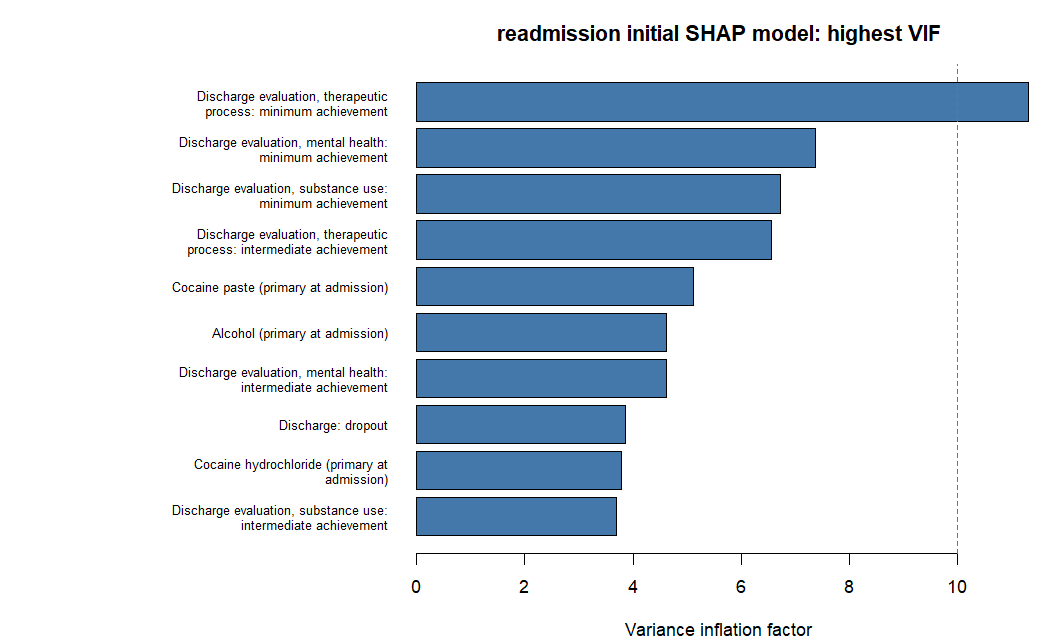

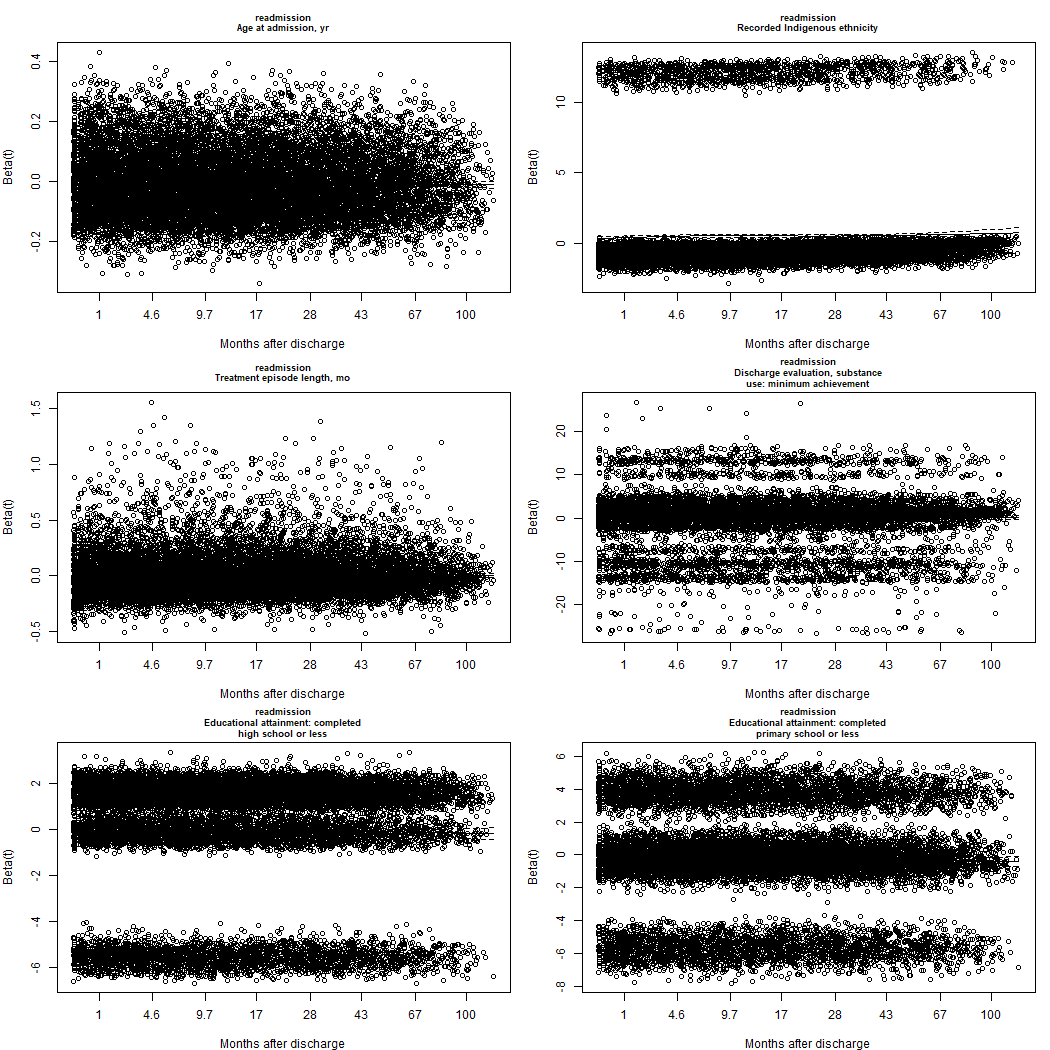

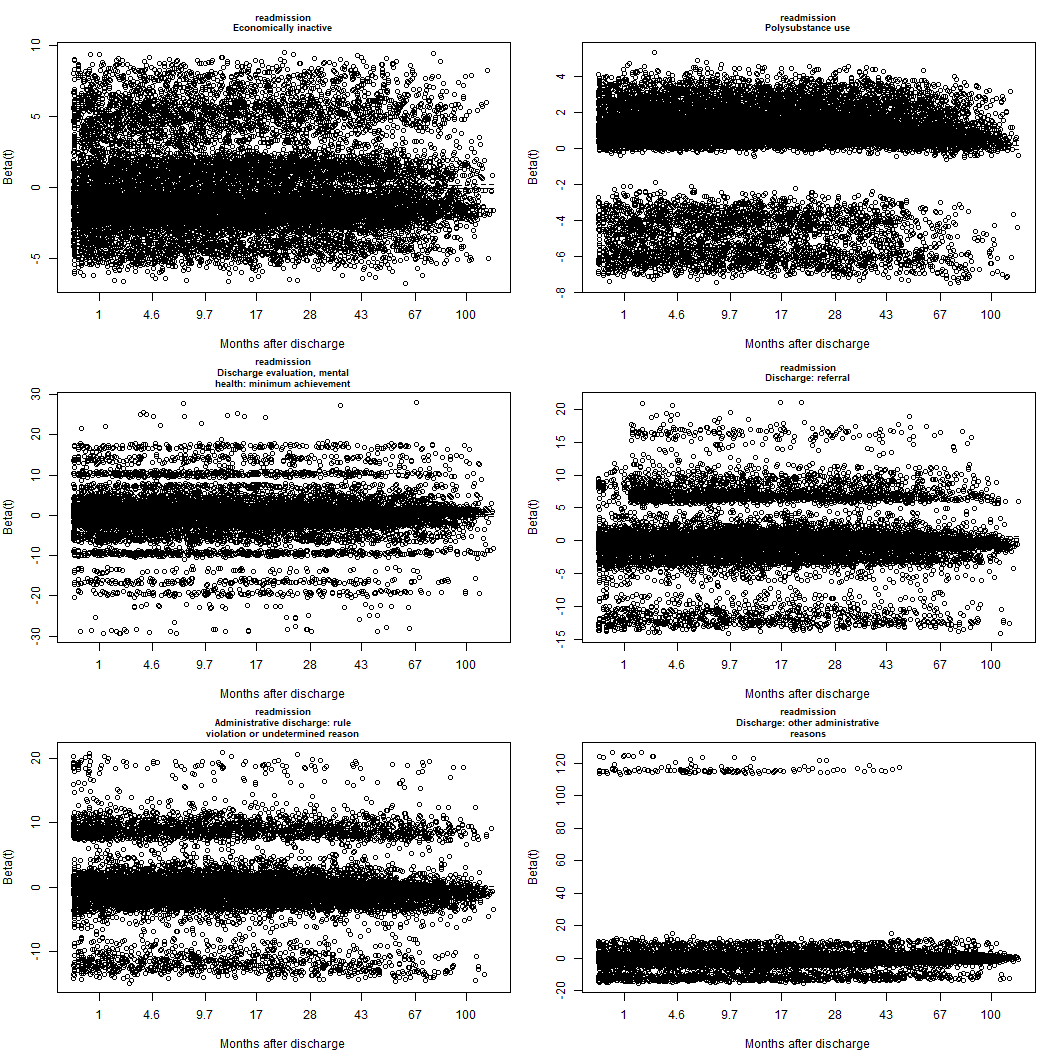

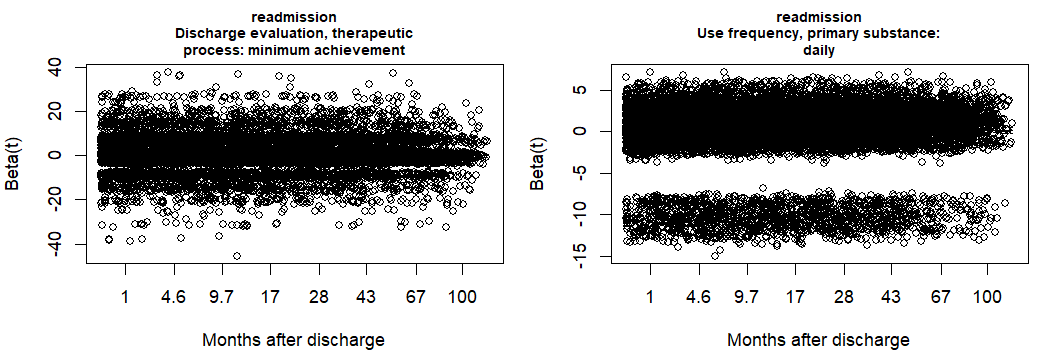

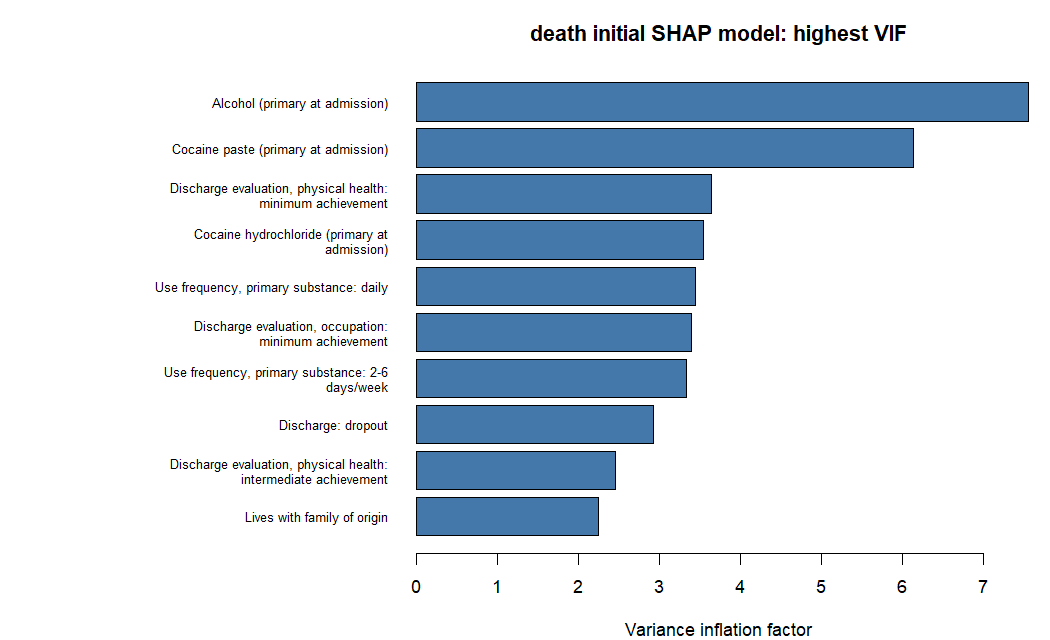

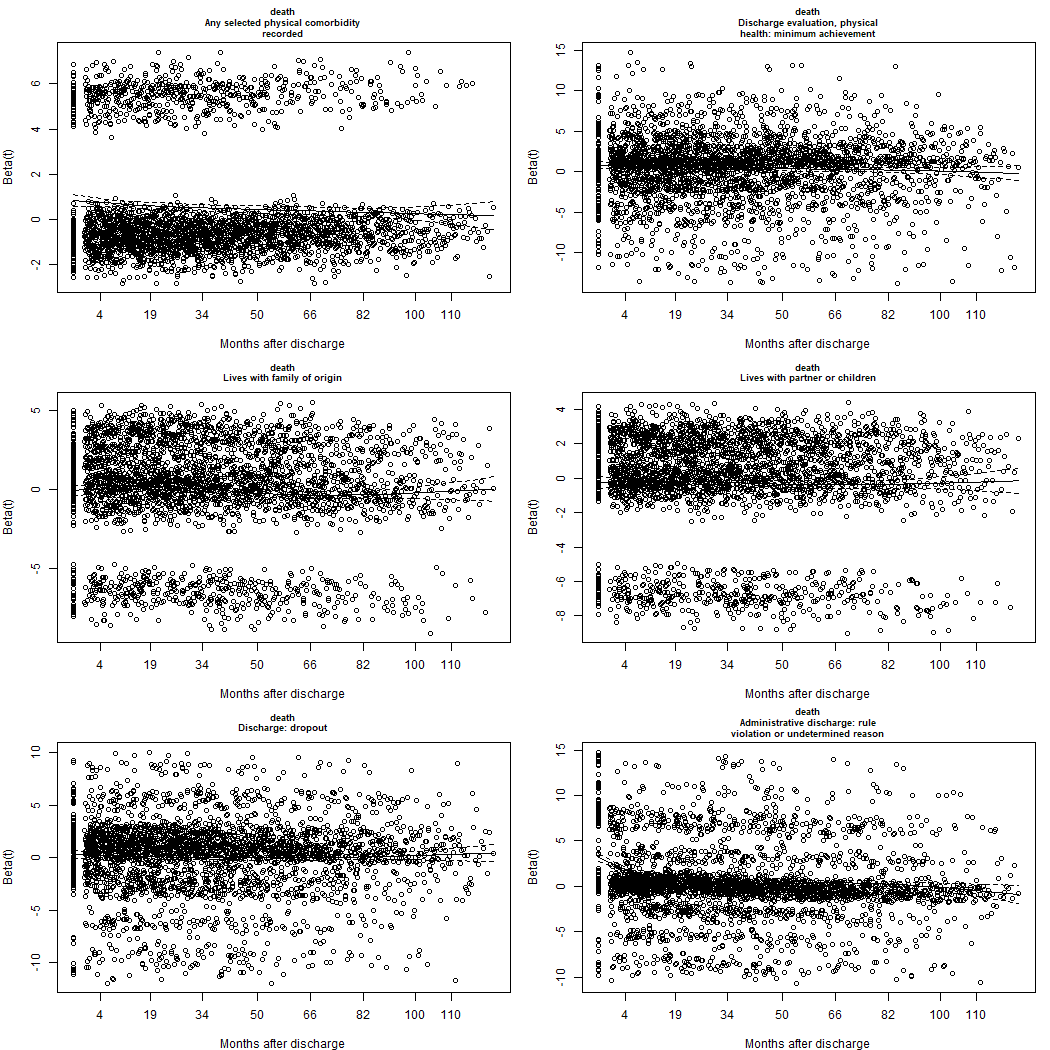

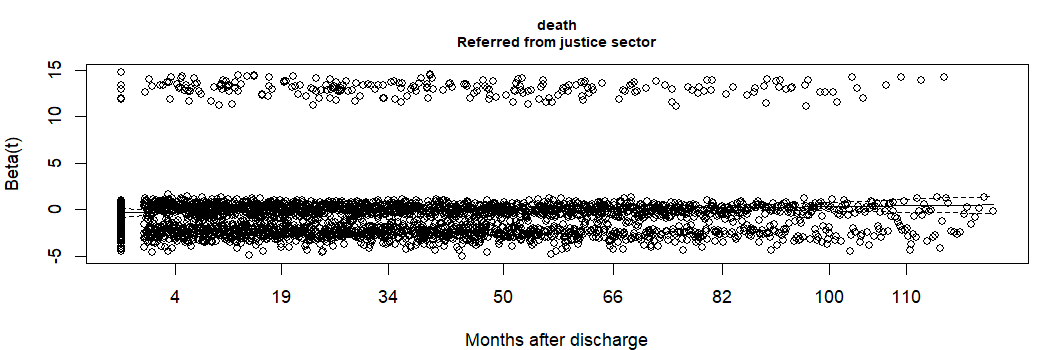

Elapsed: 0.039 minutes


In [13]:
#| label: shap-diagnostic-figures
#| message: false
.t0 <- proc.time()
# Use the already fitted diagnostics; display all significant terms in compact pages.
if (length(diagnostics)) for (o in names(diagnostics)) {
  result <- diagnostics[[o]]
  high <- head(result$vif[order(-result$vif$VIF), ], 10L)
  show_diagnostic_png(function() {
    graphics::par(mar = c(4, 19, 3, 1))
    graphics::barplot(rev(high$VIF), names.arg = display_term(rev(high$Term), 40L), horiz = TRUE, las = 1, cex.names = 0.70, col = "#4477aa", main = paste(o, "initial SHAP model: highest VIF"), xlab = "Variance inflation factor")
    graphics::abline(v = 10, lty = 2, col = "#bb5566")
  }, 1050L, 640L)
  terms <- setdiff(rownames(result$ph$table)[result$ph$table[, "p"] < 0.05], "GLOBAL")
  pages <- split(terms, ceiling(seq_along(terms) / 6L))
  for (page in pages) show_diagnostic_png(function() {
    graphics::par(mfrow = c(ceiling(length(page) / 2L), min(2L, length(page))), mar = c(4, 4, 3, 1))
    for (term in page) graphics::plot(result$ph, var = match(term, rownames(result$ph$table)), main = paste(o, display_term(term, 35L), sep = "\n"), ylab = rep("Beta(t)", ncol(result$ph$y)), xlab = "Months after discharge", cex.main = 0.75)
  }, 1050L, 350L * ceiling(length(page) / 2L))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

## Sequential candidate diagnostics
The initial diagnostic checkpoint was accepted. Readmission is evaluated without the high-VIF term first and with the discharge stratum next; mortality first adds physical-comorbidity strata. These are candidate fits, not final model choices. The original fixed-rule readmission update combined removal and stratification; its reduced-only intermediate is made explicit here at the investigator's request. Stored historical controls and newly regenerated historical-input references are labelled separately.

Current candidate PH statistics are exploratory first-imputation diagnostics. Predictive comparisons still require the agreed five-imputation CV and repeated calibration. A PH p-value alone does not select a model.

In [14]:
#| label: shap-sequential-candidate-formulas
#| message: false
.t0 <- proc.time()
# Evaluate the requested separate readmission steps without selecting the final specification.
run_sequential <- isTRUE(shap_settings$sequential_diagnostics) && identical(shap_settings$mode, "diagnostics")
sequential_diagnostics <- list()
sequential_summary <- data.frame()
sequential_comparison <- data.frame()
sequential_review_pending <- FALSE
sequential_candidate_formulas <- function(base) {
  reduced <- stats::update(base$readmission, . ~ . - evaluacindelprocesoteraputico_logro_minimo)
  list(readmission = list(initial = base$readmission, reduced = reduced, discharge_stratum = stats::update(reduced, . ~ . - tr_outcome_adm_discharge_rule_violation_undet + strata(tr_outcome_adm_discharge_rule_violation_undet))), death = list(initial = base$death, physical_stratum = stats::update(base$death, . ~ . - any_phys_dx + strata(any_phys_dx))))
}
candidate_formulas <- sequential_candidate_formulas(shap_formulas)
historical_candidate_formulas <- sequential_candidate_formulas(historical_shap_formulas)
formula_terms <- function(formula) attr(stats::terms(formula), "term.labels")
formula_strata <- function(formula) sub("^strata\\((.*)\\)$", "\\1", grep("^strata\\(", formula_terms(formula), value = TRUE))
# Check every change explicitly, including the saved final response and both strata.
stopifnot(setequal(setdiff(formula_terms(candidate_formulas$readmission$initial), formula_terms(candidate_formulas$readmission$reduced)), removed_collinear))
stopifnot(setequal(formula_strata(candidate_formulas$readmission$discharge_stratum), c("plan_type_strata", discharge_stratum)))
stopifnot(setequal(formula_strata(candidate_formulas$death$physical_stratum), c("plan_type_strata", "any_phys_dx")))
historical_saved <- readRDS(source_path("cox_c_control"))
for (o in names(outcome_tags)) {
  expected <- stats::as.formula(historical_saved$f_txt[[o]][["shap"]], env = formula_environment)
  actual <- tail(historical_candidate_formulas[[o]], 1L)[[1L]]
  stopifnot(setequal(formula_terms(actual), formula_terms(expected)), identical(deparse(actual[[2L]]), deparse(expected[[2L]])))
}
rm(historical_saved)
sequential_signature <- substr(digest::digest(list(shap_signature, lapply(candidate_formulas, function(x) lapply(x, deparse)), lapply(historical_candidate_formulas, function(x) lapply(x, deparse)), method = "first-imputation PH/VIF, efron, km"), algo = "sha256"), 1L, 12L)
for (o in names(candidate_formulas)) for (stage in names(candidate_formulas[[o]])) {
  cat(o, stage, if (o == "readmission" && stage == "initial") "earlier diagnostic formula (superseded by VIF removal):\n" else "current base or pending candidate formula (see status below):\n"); print(candidate_formulas[[o]][[stage]])
}
show_table(do.call(rbind, lapply(names(candidate_formulas), function(o) do.call(rbind, lapply(names(candidate_formulas[[o]]), function(stage) {
  f <- candidate_formulas[[o]][[stage]]
  data.frame(Outcome = o, Stage = stage, Ordinary_terms = sum(!grepl("^strata\\(", formula_terms(f))), Strata = paste(display_term(formula_strata(f)), collapse = "; "), Status = if (o == "readmission" && stage == "initial") "Earlier diagnostic formula; VIF term subsequently removed" else if ((o == "readmission" && stage == "reduced") || (o == "death" && stage == "initial")) "VIF checkpoint accepted to continue; not a final model" else "Candidate; see its outcome-specific predictive checkpoint before selection")
})))), "Exact strata by candidate; no treatment-completion stratum")
cat("The original fixed-rule readmission update combined removal and stratification. The reduced-only candidate is the investigator-requested separate intermediate, not a stored historical result.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

readmission initial earlier diagnostic formula (superseded by VIF removal):
Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + 
    primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + 
    primary_sub_mod_others + adm_age_rec3 + porc_pobr + sex_rec_woman + 
    ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + 
    ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + 
    occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + 
    dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + 
    polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + 
    tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + 
    tr_outcome_adm_discharge_adm_reasons + evaluacindelprocesoteraputico_logro_intermedio + 
    evaluacindelprocesoteraputico_logro_minimo + prim_sub_freq_rec_2_2_6_days_wk + 
    prim_s

Outcome,Stage,Ordinary_terms,Strata,Status
readmission,initial,28,Treatment setting,Earlier diagnostic formula; VIF term subsequently removed
readmission,reduced,27,Treatment setting,VIF checkpoint accepted to continue; not a final model
readmission,discharge_stratum,26,Treatment setting; Administrative discharge: rule violation or undetermined reason,Candidate; see its outcome-specific predictive checkpoint before selection
death,initial,26,Treatment setting,VIF checkpoint accepted to continue; not a final model
death,physical_stratum,25,Treatment setting; Any selected physical comorbidity recorded,Candidate; see its outcome-specific predictive checkpoint before selection


The original fixed-rule readmission update combined removal and stratification. The reduced-only candidate is the investigator-requested separate intermediate, not a stored historical result.


Elapsed: 0.012 minutes


## Familiar model names and current state
The retained models are **b: SHAP readmission** and **e: SHAP mortality**, without interactions and with linear age. The final section brings together the completed functional-form comparisons and the recorded C/IBS rule. Earlier preparation tables describe the discovery sequence; they are not the final execution status.

| Model | Familiar name | State |
|---|---|---|
| a | Full readmission | Reference from 06: setting + rule violation/undetermined discharge; collinear term excluded |
| b | SHAP readmission, no interactions | Retained: setting + rule violation/undetermined discharge; collinear term excluded |
| c | SHAP readmission with interactions | Evaluated; investigator retained b |
| d | Full mortality | Reference from 06: setting + rule violation/undetermined discharge; collinear term excluded |
| e | SHAP mortality, no interactions | Retained: setting + physical comorbidity; collinear term excluded |
| f | SHAP mortality with interactions | Evaluated; investigator retained e |

The a reference follows the original `update-model-to-gvif` and `update-model-to-nph` sequence. The predictor set in e is the reviewed selection from 03; it is not assumed identical to historical e. Historical versus clean numerical differences remain separate from the decision to retain a formula. No Word document is modified.


In [15]:
#| label: shap-thesis-model-key
#| message: true
.t0 <- proc.time()
# Keep thesis object names as aliases of the verified current formulas; interactions are constructed after the accepted checkpoint is verified.
formula_readmit_updated2 <- cox_formulas$readmission$stratified
formula_shap_readmit_clean_updated <- candidate_formulas$readmission$discharge_stratum
formula_death_updated2 <- cox_formulas$death$stratified
formula_shap_death_rule2 <- candidate_formulas$death$physical_stratum
thesis_formulas <- list(a = formula_readmit_updated2, b = formula_shap_readmit_clean_updated, d = formula_death_updated2, e = formula_shap_death_rule2)
stopifnot(all(vapply(thesis_formulas, function(f) !removed_collinear %in% all.vars(f), logical(1L))))
thesis_model_key <- data.frame(Model = names(thesis_formulas), Thesis_object = c("formula_readmit_updated2", "formula_shap_readmit_clean_updated", "formula_death_updated2", "formula_shap_death_rule2"), Family = c("Full readmission", "SHAP readmission", "Full mortality", "SHAP mortality"), Ordinary_terms = vapply(thesis_formulas, function(f) sum(!grepl("^strata\\(", formula_terms(f))), integer(1L)), Strata = vapply(thesis_formulas, function(f) paste(display_term(formula_strata(f)), collapse = "; "), character(1L)), Status = c("Reference retained from 06", "Accepted to continue; no interactions", "Reference retained from 06", "Accepted A; setting + physical strata; no interactions"))
show_table(thesis_model_key, "Thesis names: actual current formulas; the collinear minimum-achievement term is excluded from all four")
cat("Models c and f are prepared below from accepted b/e; neither has been fitted or selected. Model e uses the updated predictor selection already reviewed in 03.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Model,Thesis_object,Family,Ordinary_terms,Strata,Status
a,formula_readmit_updated2,Full readmission,63,Treatment setting; Administrative discharge: rule violation or undetermined reason,Reference retained from 06
b,formula_shap_readmit_clean_updated,SHAP readmission,26,Treatment setting; Administrative discharge: rule violation or undetermined reason,Accepted to continue; no interactions
d,formula_death_updated2,Full mortality,63,Treatment setting; Administrative discharge: rule violation or undetermined reason,Reference retained from 06
e,formula_shap_death_rule2,SHAP mortality,25,Treatment setting; Any selected physical comorbidity recorded,Accepted A; setting + physical strata; no interactions


Models c and f are prepared below from accepted b/e; neither has been fitted or selected. Model e uses the updated predictor selection already reviewed in 03.


Elapsed: 0.000 minutes


In [16]:
#| label: shap-sequential-historical-ph-control
#| message: false
.t0 <- proc.time()
# Reproduce the stored post-physical-stratum mortality PH table before fitting current candidates.
historical_sequential <- list()
stored_post_ph <- data.frame()
post_ph_control <- data.frame()
if (run_sequential) {
  stopifnot(!review_pending, initial_review_accepted)
  first_line <- "cox.zph(coxph(formula_shap_death_rule2, data = py_corrected_datasets[[1]]))"
  hit <- Filter(function(cell) startsWith(trimws(paste(unlist(cell$source), collapse = "")), first_line), original_notebook$cells)
  stopifnot(length(hit) == 1L)
  text <- paste(unlist(lapply(hit[[1L]]$outputs, function(x) c(x$text, x$data[["text/plain"]]))), collapse = "")
  lines <- strsplit(text, "\n", fixed = TRUE)[[1L]]
  lines <- lines[grepl("^[[:alnum:]_]+[[:space:]]+[0-9]", lines)]
  stored_post_ph <- do.call(rbind, lapply(strsplit(trimws(lines), "[[:space:]]+"), function(x) data.frame(Term = x[1L], Previous = as.numeric(x[2L]), Previous_df = as.integer(x[3L]), Previous_p = as.numeric(sub("^<", "", tail(x, 1L))))))
  old <- fit_diagnostic(historical_data, historical_candidate_formulas$death$physical_stratum, paste0("historical_death_physical_stratum_", sequential_signature))
  historical_sequential$death_physical_stratum <- old
  post_ph_control <- merge(stored_post_ph, ph_frame(old$ph, "death"), by = "Term", sort = FALSE)
  stopifnot(nrow(post_ph_control) == nrow(old$ph$table), all(post_ph_control$Previous_df == post_ph_control$df), max(abs(post_ph_control$Previous - post_ph_control$Chi_square)) <= 0.00050001, max(abs(post_ph_control$Previous_p - post_ph_control$p)) <= 0.00050001)
  show_table(post_ph_control, "Stored historical mortality PH after physical-comorbidity strata: numerical control passed")
  # These readmission references are newly regenerated from historical inputs; no stored post-update PH table exists.
  for (stage in c("reduced", "discharge_stratum")) historical_sequential[[paste0("readmission_", stage)]] <- fit_diagnostic(historical_data, historical_candidate_formulas$readmission[[stage]], paste0("historical_readmission_", stage, "_", sequential_signature))
  cat("Readmission historical-input candidate diagnostics were regenerated, not read from stored historical PH outputs. The initial historical PH and final formula controls already passed.\n")
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Term,Previous,Previous_df,Previous_p,Outcome,Chi_square,df,p
"Age at admission, yr",0.213,1,0.645,death,0.2128,1,0.6446
Cocaine paste (primary at admission),0.203,1,0.652,death,0.2033,1,0.6521
Cocaine hydrochloride (primary at admission),0.970,1,0.325,death,0.9698,1,0.3247
Alcohol (primary at admission),0.215,1,0.643,death,0.2147,1,0.6431
Other substance (primary at admission),0.188,1,0.665,death,0.1877,1,0.6648
"Use frequency, primary substance: 2-6 days/week",0.456,1,0.499,death,0.4564,1,0.4993
"Use frequency, primary substance: daily",1.076,1,0.300,death,1.0761,1,0.2996
Unemployed,1.698,1,0.193,death,1.6975,1,0.1926
Economically inactive,0.308,1,0.579,death,0.3084,1,0.5786
"Discharge evaluation, occupation: intermediate achievement",0.509,1,0.476,death,0.5086,1,0.4757


Readmission historical-input candidate diagnostics were regenerated, not read from stored historical PH outputs. The initial historical PH and final formula controls already passed.


Elapsed: 0.008 minutes


In [17]:
#| label: shap-sequential-candidate-diagnostics
#| message: false
.t0 <- proc.time()
# Use only the first completed-development imputation, preserving the approved diagnostic scope.
if (run_sequential) {
  stopifnot(!review_pending, nrow(post_ph_control) > 0L)
  for (o in names(candidate_formulas)) for (stage in names(candidate_formulas[[o]])) {
    key <- paste(o, stage, sep = "_")
    result <- if (stage == "initial") diagnostics[[o]] else fit_diagnostic(py_corrected_datasets[[1L]], candidate_formulas[[o]][[stage]], paste0("current_", key, "_", sequential_signature))
    sequential_diagnostics[[key]] <- result
    row <- result$ph$table["GLOBAL", ]
    sequential_summary <- rbind(sequential_summary, data.frame(Outcome = o, Stage = stage, Ordinary_terms = length(stats::coef(result$fit)), Strata = paste(display_term(formula_strata(candidate_formulas[[o]][[stage]])), collapse = "; "), Maximum_VIF = max(result$vif$VIF), PH_chisq = row[["chisq"]], PH_df = row[["df"]], PH_p = row[["p"]]))
    if (stage == "initial") next
    show_table(result$vif[order(-result$vif$VIF), ], paste(o, stage, "candidate VIF"))
    current <- ph_frame(result$ph, o)
    show_table(current, paste(o, stage, "candidate PH; no automatic additional strata"))
    previous <- if (o == "death") stored_post_ph else {
      old <- ph_frame(historical_sequential[[key]]$ph, o)
      data.frame(Term = old$Term, Previous = old$Chi_square, Previous_df = old$df, Previous_p = old$p)
    }
    comparison <- merge(previous, current, by = "Term", all = TRUE, sort = FALSE)
    comparison$Stage <- stage
    comparison$Reference_source <- if (o == "death") "Stored original post-stratum output" else "Regenerated historical-input candidate; not previously stored"
    comparison$Difference <- comparison$Chi_square - comparison$Previous
    comparison$Screening_changed <- !is.na(comparison$Previous_p) & (comparison$Previous_p < 0.05) != (comparison$p < 0.05)
    comparison$Classification <- ifelse(is.na(comparison$Previous), "New term from accepted 03 selection", ifelse(comparison$Screening_changed, "Substantial diagnostic screening change; review", "Trivial for this intermediate diagnostic decision"))
    sequential_comparison <- rbind(sequential_comparison, comparison)
  }
  show_table(sequential_summary, "Candidate diagnostic summary; different PH degrees of freedom are not a performance comparison")
  show_table(sequential_comparison, "Previous versus new post-adjustment diagnostics; reference provenance is explicit")
  sequential_review_pending <- any(sequential_comparison$Screening_changed, na.rm = TRUE)
  sequential_review_accepted <- sequential_signature %in% unlist(shap_settings$accepted_sequential_diagnostic_signatures)
  review_pending <- sequential_review_pending && !sequential_review_accepted
  if (review_pending) cat("New diagnostic checkpoint: review changes before adding another mortality stratum or starting predictive comparisons.\n")
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Term,VIF
"Discharge evaluation, mental health: minimum achievement",5.7015
Cocaine paste (primary at admission),5.1152
"Discharge evaluation, substance use: minimum achievement",4.9570
Alcohol (primary at admission),4.6221
"Discharge evaluation, mental health: intermediate achievement",3.9396
Cocaine hydrochloride (primary at admission),3.7899
Discharge: dropout,3.6239
"Use frequency, primary substance: daily",3.1948
"Discharge evaluation, substance use: intermediate achievement",3.1574
"Use frequency, primary substance: 2-6 days/week",3.0418


Outcome,Term,Chi_square,df,p
readmission,Cocaine paste (primary at admission),0.1025,1,0.7488
readmission,Cocaine hydrochloride (primary at admission),0.0571,1,0.8111
readmission,Alcohol (primary at admission),0.2429,1,0.6221
readmission,Other substance (primary at admission),3.6425,1,0.0563
readmission,"Age at admission, yr",5.4870,1,0.0192
readmission,Communal poverty rate,0.4623,1,0.4966
readmission,Women,1.0660,1,0.3019
readmission,Recorded Indigenous ethnicity,4.3517,1,0.0370
readmission,"Treatment episode length, mo",21.6104,1,0.0000
readmission,"Discharge evaluation, substance use: intermediate achievement",1.4647,1,0.2262


Term,VIF
"Discharge evaluation, mental health: minimum achievement",5.6838
Cocaine paste (primary at admission),5.0982
"Discharge evaluation, substance use: minimum achievement",4.9409
Alcohol (primary at admission),4.6146
"Discharge evaluation, mental health: intermediate achievement",3.9141
Cocaine hydrochloride (primary at admission),3.7852
"Use frequency, primary substance: daily",3.1922
"Discharge evaluation, substance use: intermediate achievement",3.1397
Discharge: dropout,3.0690
"Use frequency, primary substance: 2-6 days/week",3.0395


Outcome,Term,Chi_square,df,p
readmission,Cocaine paste (primary at admission),0.4283,1,0.5128
readmission,Cocaine hydrochloride (primary at admission),0.0032,1,0.9550
readmission,Alcohol (primary at admission),0.5850,1,0.4444
readmission,Other substance (primary at admission),3.5853,1,0.0583
readmission,"Age at admission, yr",7.1241,1,0.0076
readmission,Communal poverty rate,1.2892,1,0.2562
readmission,Women,1.2839,1,0.2572
readmission,Recorded Indigenous ethnicity,4.1156,1,0.0425
readmission,"Treatment episode length, mo",19.1634,1,0.0000
readmission,"Discharge evaluation, substance use: intermediate achievement",0.3883,1,0.5332


Term,VIF
Alcohol (primary at admission),7.4904
Cocaine paste (primary at admission),6.0955
"Discharge evaluation, physical health: minimum achievement",3.6281
Cocaine hydrochloride (primary at admission),3.5321
"Use frequency, primary substance: daily",3.4059
"Discharge evaluation, occupation: minimum achievement",3.3813
"Use frequency, primary substance: 2-6 days/week",3.3099
Discharge: dropout,2.9069
"Discharge evaluation, physical health: intermediate achievement",2.4498
Lives with family of origin,2.2461


Outcome,Term,Chi_square,df,p
death,"Age at admission, yr",0.1921,1,0.6612
death,Cocaine paste (primary at admission),0.3210,1,0.5710
death,Cocaine hydrochloride (primary at admission),0.9886,1,0.3201
death,Alcohol (primary at admission),0.3147,1,0.5748
death,Other substance (primary at admission),0.2092,1,0.6474
death,"Use frequency, primary substance: 2-6 days/week",0.2743,1,0.6005
death,"Use frequency, primary substance: daily",0.8519,1,0.3560
death,Unemployed,1.6721,1,0.1960
death,Economically inactive,0.4244,1,0.5147
death,"Discharge evaluation, occupation: intermediate achievement",0.3016,1,0.5829


Outcome,Stage,Ordinary_terms,Strata,Maximum_VIF,PH_chisq,PH_df,PH_p
readmission,initial,28,Treatment setting,11.3038,166.9323,28,0
readmission,reduced,27,Treatment setting,5.7015,166.7518,27,0
readmission,discharge_stratum,26,Treatment setting; Administrative discharge: rule violation or undetermined reason,5.6838,106.3777,26,0
death,initial,26,Treatment setting,7.5493,136.8134,26,0
death,physical_stratum,25,Treatment setting; Any selected physical comorbidity recorded,7.4904,121.6458,25,0


Term,Previous,Previous_df,Previous_p,Outcome,Chi_square,df,p,Stage,Reference_source,Difference,Screening_changed,Classification
Cocaine paste (primary at admission),0.1011,1,0.7505,readmission,0.1025,1,0.7488,reduced,Regenerated historical-input candidate; not previously stored,0.0014,FALSE,Trivial for this intermediate diagnostic decision
Cocaine hydrochloride (primary at admission),0.0570,1,0.8114,readmission,0.0571,1,0.8111,reduced,Regenerated historical-input candidate; not previously stored,0.0002,FALSE,Trivial for this intermediate diagnostic decision
Alcohol (primary at admission),0.2408,1,0.6237,readmission,0.2429,1,0.6221,reduced,Regenerated historical-input candidate; not previously stored,0.0022,FALSE,Trivial for this intermediate diagnostic decision
Other substance (primary at admission),3.6322,1,0.0567,readmission,3.6425,1,0.0563,reduced,Regenerated historical-input candidate; not previously stored,0.0103,FALSE,Trivial for this intermediate diagnostic decision
"Age at admission, yr",5.4788,1,0.0192,readmission,5.4870,1,0.0192,reduced,Regenerated historical-input candidate; not previously stored,0.0082,FALSE,Trivial for this intermediate diagnostic decision
Communal poverty rate,0.4617,1,0.4968,readmission,0.4623,1,0.4966,reduced,Regenerated historical-input candidate; not previously stored,0.0006,FALSE,Trivial for this intermediate diagnostic decision
Women,1.0719,1,0.3005,readmission,1.0660,1,0.3019,reduced,Regenerated historical-input candidate; not previously stored,-0.0060,FALSE,Trivial for this intermediate diagnostic decision
Recorded Indigenous ethnicity,4.3544,1,0.0369,readmission,4.3517,1,0.0370,reduced,Regenerated historical-input candidate; not previously stored,-0.0026,FALSE,Trivial for this intermediate diagnostic decision
"Treatment episode length, mo",21.6221,1,0.0000,readmission,21.6104,1,0.0000,reduced,Regenerated historical-input candidate; not previously stored,-0.0116,FALSE,Trivial for this intermediate diagnostic decision
"Discharge evaluation, substance use: intermediate achievement",1.4609,1,0.2268,readmission,1.4647,1,0.2262,reduced,Regenerated historical-input candidate; not previously stored,0.0038,FALSE,Trivial for this intermediate diagnostic decision


Elapsed: 0.011 minutes


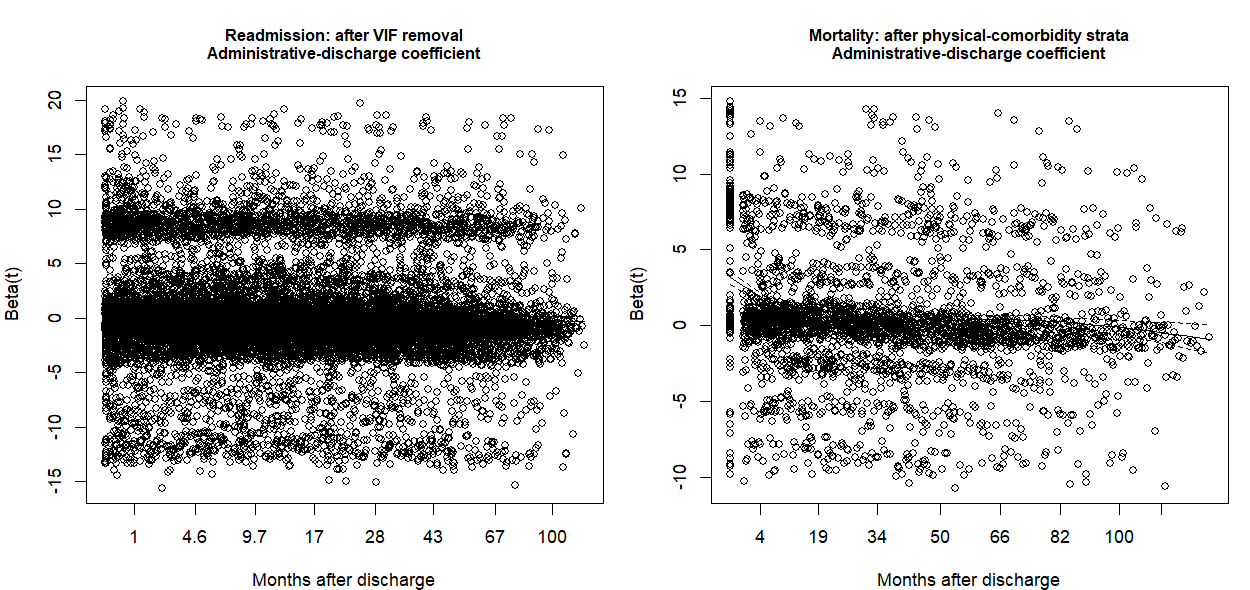

The readmission discharge coefficient is absent after becoming a stratum; its earlier residual plot remains visible above. No post-stratum coefficient is invented.


Elapsed: 0.003 minutes


In [18]:
#| label: shap-sequential-diagnostic-plots
#| message: false
.t0 <- proc.time()
# Display selected residual curves from cached candidates, without fitting extra Cox models.
if (run_sequential) {
  plot_specs <- list(list(key = "readmission_reduced", term = discharge_stratum, title = "Readmission: after VIF removal\nAdministrative-discharge coefficient"), list(key = "death_physical_stratum", term = discharge_stratum, title = "Mortality: after physical-comorbidity strata\nAdministrative-discharge coefficient"))
  show_diagnostic_png(function() {
    graphics::par(mfrow = c(1L, 2L), mar = c(4, 4, 4, 1))
    for (spec in plot_specs) {
      test <- sequential_diagnostics[[spec$key]]$ph
      term <- which(sub("TRUE$", "", rownames(test$table)) == spec$term)
      stopifnot(length(term) == 1L)
      graphics::plot(test, var = term, main = spec$title, cex.main = 0.85, ylab = rep("Beta(t)", ncol(test$y)), xlab = "Months after discharge")
    }
  }, 1250L, 590L)
  cat("The readmission discharge coefficient is absent after becoming a stratum; its earlier residual plot remains visible above. No post-stratum coefficient is invented.\n")
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

## Published initial PH panels
Panels B of eFigures 3 and 4 use the initial SHAP formulas, before the additional strata. Their original smoothers use every event time, with no percentile trimming. Colours, labels and axis limits improve legibility; the numerical smoothers preserve the original method.

In [19]:
#| label: shap-mortality-additional-discharge-candidate
#| message: false
.t0 <- proc.time()
# Retain the previously executed diagnostic of the now-rejected third mortality stratification factor.
triple_candidate_evaluated <- FALSE
if (run_sequential && isTRUE(shap_settings$evaluate_mortality_discharge_candidate)) {
  candidate_formulas$death$physical_discharge_strata <- stats::update(candidate_formulas$death$physical_stratum, . ~ . - tr_outcome_adm_discharge_rule_violation_undet + strata(tr_outcome_adm_discharge_rule_violation_undet))
  formula <- candidate_formulas$death$physical_discharge_strata
  stopifnot(setequal(formula_strata(formula), c("plan_type_strata", "any_phys_dx", discharge_stratum)))
  key <- paste0("current_death_physical_discharge_strata_", substr(digest::digest(deparse(formula), algo = "sha256"), 1L, 12L))
  result <- fit_diagnostic(py_corrected_datasets[[1L]], formula, key)
  sequential_diagnostics$death_physical_discharge_strata <- result
  row <- result$ph$table["GLOBAL", ]
  sequential_summary <- rbind(sequential_summary, data.frame(Outcome = "death", Stage = "physical_discharge_strata", Ordinary_terms = length(stats::coef(result$fit)), Strata = paste(display_term(formula_strata(formula)), collapse = "; "), Maximum_VIF = max(result$vif$VIF), PH_chisq = row[["chisq"]], PH_df = row[["df"]], PH_p = row[["p"]]))
  print(formula)
  show_table(ph_frame(result$ph, "death"), "Mortality candidate: treatment setting, physical comorbidity and discharge strata")
  show_table(result$vif[order(-result$vif$VIF), ], "Mortality three-stratum candidate: VIF")
  show_table(sequential_summary, "Recorded candidate diagnostics; the third mortality factor is subsequently excluded for sparse support")
  triple_candidate_evaluated <- TRUE
  review_pending <- FALSE
  cat("Archived diagnostic only: the investigator rejected this third mortality stratification factor because of sparse event support. It will not enter predictive evaluation.\n")
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Term,Chi_square,df,p
death,"Age at admission, yr",0.0058,1,0.9394
death,Cocaine paste (primary at admission),1.0251,1,0.3113
death,Cocaine hydrochloride (primary at admission),1.3214,1,0.2503
death,Alcohol (primary at admission),0.9115,1,0.3397
death,Other substance (primary at admission),0.2595,1,0.6104
death,"Use frequency, primary substance: 2-6 days/week",0.4781,1,0.4893
death,"Use frequency, primary substance: daily",1.2493,1,0.2637
death,Unemployed,1.3688,1,0.2420
death,Economically inactive,0.5958,1,0.4402
death,"Discharge evaluation, occupation: intermediate achievement",0.5991,1,0.4389


Term,VIF
Alcohol (primary at admission),7.4784
Cocaine paste (primary at admission),6.0875
"Discharge evaluation, physical health: minimum achievement",3.6245
Cocaine hydrochloride (primary at admission),3.5323
"Use frequency, primary substance: daily",3.4037
"Discharge evaluation, occupation: minimum achievement",3.3737
"Use frequency, primary substance: 2-6 days/week",3.3075
"Discharge evaluation, physical health: intermediate achievement",2.4491
Discharge: dropout,2.3813
Lives with family of origin,2.2480


Outcome,Stage,Ordinary_terms,Strata,Maximum_VIF,PH_chisq,PH_df,PH_p
readmission,initial,28,Treatment setting,11.3038,166.9323,28,0.0000
readmission,reduced,27,Treatment setting,5.7015,166.7518,27,0.0000
readmission,discharge_stratum,26,Treatment setting; Administrative discharge: rule violation or undetermined reason,5.6838,106.3777,26,0.0000
death,initial,26,Treatment setting,7.5493,136.8134,26,0.0000
death,physical_stratum,25,Treatment setting; Any selected physical comorbidity recorded,7.4904,121.6458,25,0.0000
death,physical_discharge_strata,24,Treatment setting; Any selected physical comorbidity recorded; Administrative discharge: rule violation or undetermined reason,7.4784,41.7433,24,0.0138


Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + primary_sub_mod_cocaine_paste + 
    primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + 
    primary_sub_mod_others + prim_sub_freq_rec_2_2_6_days_wk + 
    prim_sub_freq_rec_3_daily + occupation_condition_corr24_unemployed + 
    occupation_condition_corr24_inactive + eva_ocupacion_logro_intermedio + 
    eva_ocupacion_logro_minimo + eva_fisica_logro_intermedio + 
    eva_fisica_logro_minimo + cohabitation_family_of_origin + 
    cohabitation_with_couple_children + cohabitation_others + 
    tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + 
    adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + 
    adm_motive_justice_sector + adm_motive_other + sex_rec_woman + 
    strata(plan_type_strata) + strata(any_phys_dx) + strata(tr_outcome_adm_discharge_rule_violation_undet)
<environment: 0x00000245ea3702d8>
Archived diagnostic only: the investigator rejec

Elapsed: 0.002 minutes


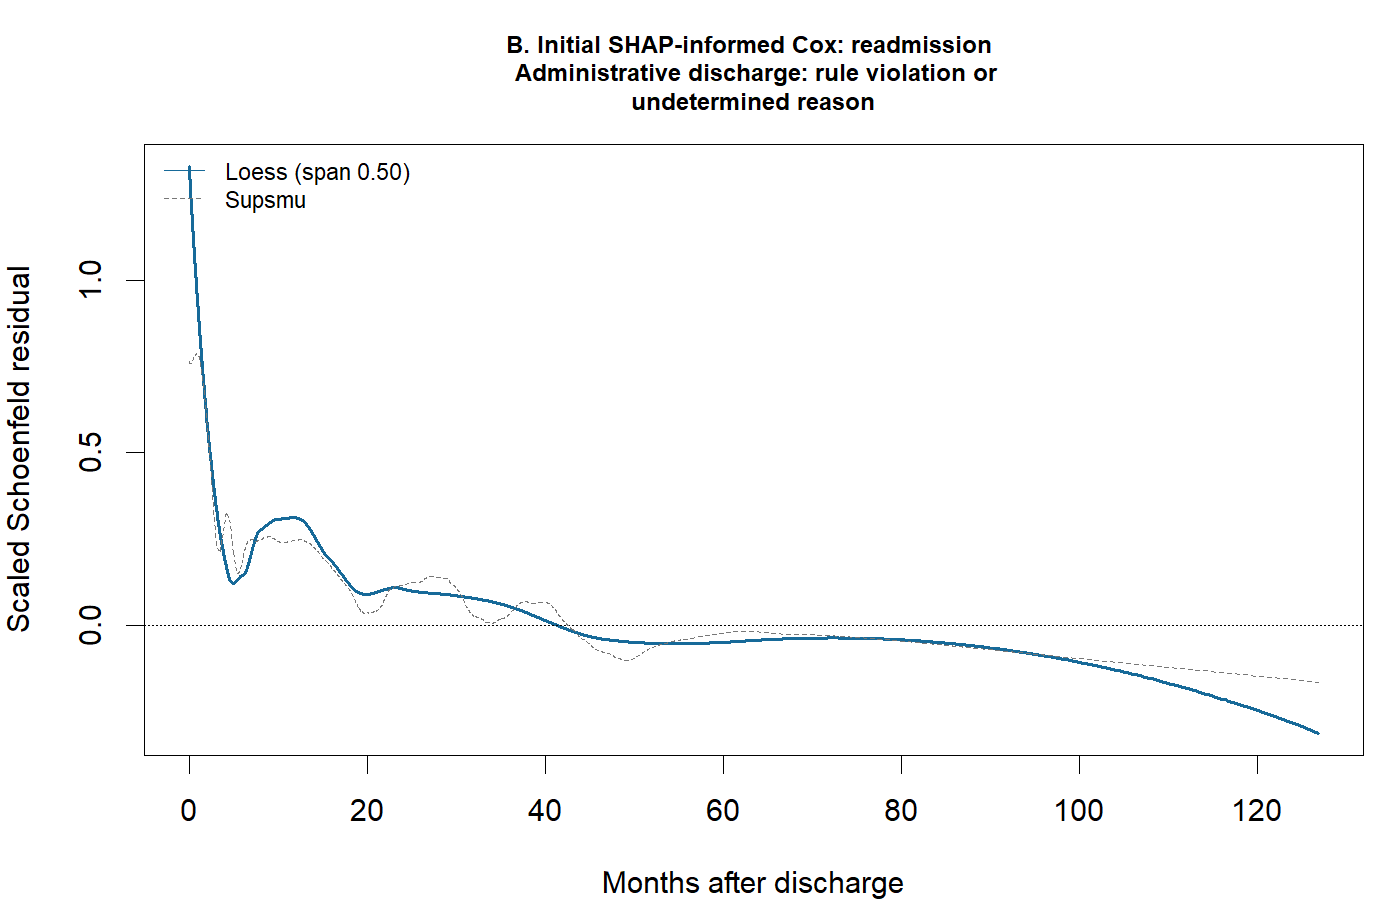

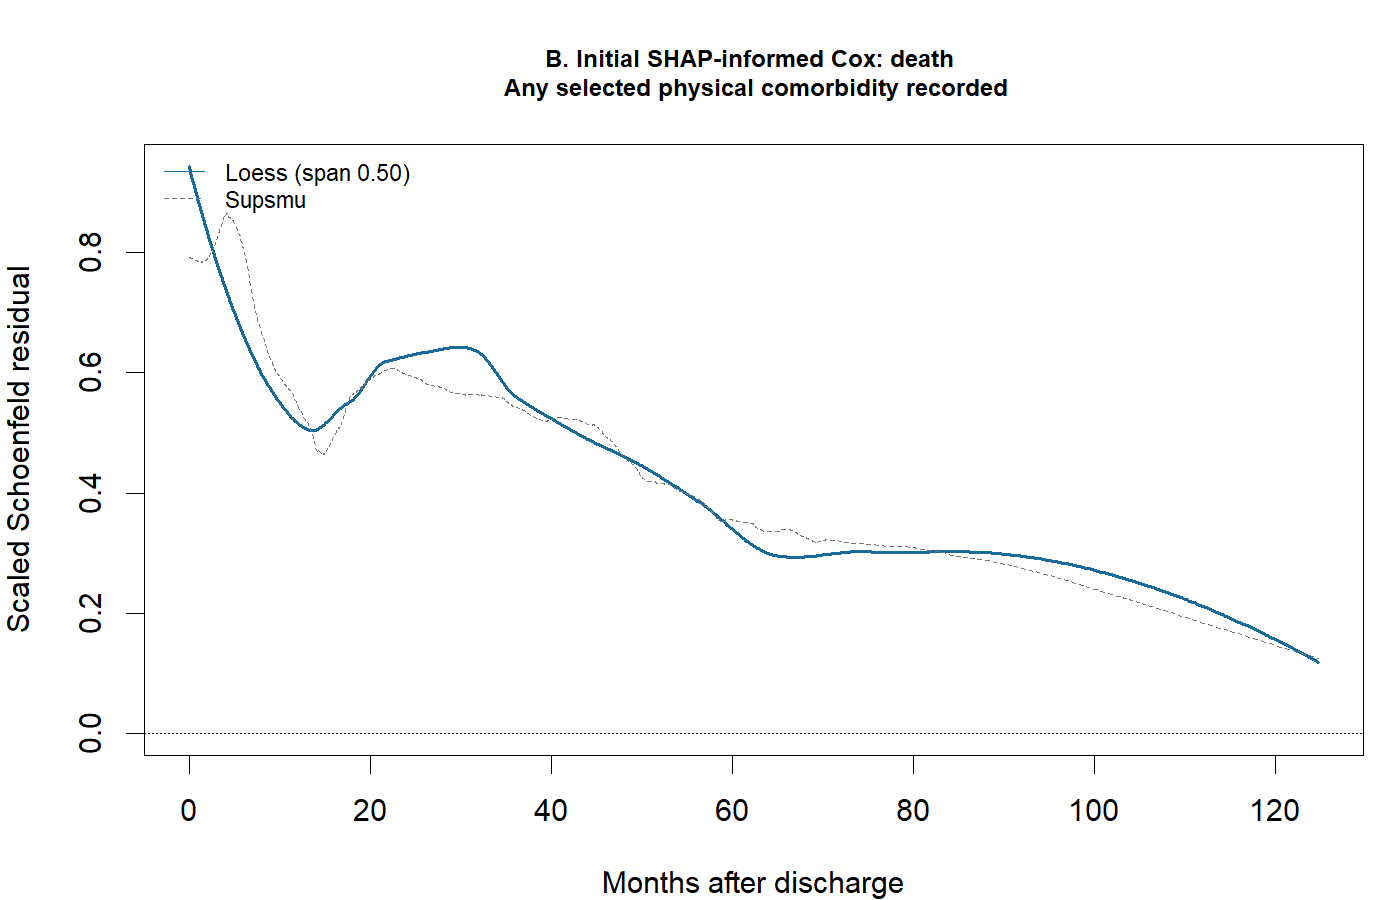

Elapsed: 0.002 minutes


In [20]:
#| label: shap-export-initial-ph-panels
#| message: false
.t0 <- proc.time()
# Preserve the original panel-B smoothers: every event time, loess span 0.50 and supsmu, before additional strata.
if (length(diagnostics) && initial_review_accepted) for (o in names(diagnostics)) {
  term <- if (o == "readmission") discharge_stratum else "any_phys_dx"
  curves <- shap_cache(paste0("figure_B_", o, "_all_times_span050"), function() {
    res <- stats::residuals(diagnostics[[o]]$fit, type = "scaledsch")
    column <- which(sub("TRUE$", "", colnames(res)) == term)
    stopifnot(length(column) == 1L)
    time <- as.numeric(rownames(res))
    y <- res[, column]
    stopifnot(all(is.finite(time)), all(is.finite(y)))
    smoother <- stats::loess(y ~ time, span = 0.50)
    ord <- order(time)
    supersmoother <- stats::supsmu(time, y)
    rbind(data.frame(Method = "Loess, span 0.50", Time_months = time[ord], Residual = stats::fitted(smoother)[ord]), data.frame(Method = "Supsmu", Time_months = supersmoother$x, Residual = supersmoother$y))
  })
  prefix <- paste0(if (o == "readmission") "eFigure3" else "eFigure4", "_panelB_SHAP_PH_", format(Sys.Date(), "%Y-%m-%d"), "_", shap_signature)
  csv_path <- file.path(table_dir, paste0(prefix, "_source.csv"))
  png_path <- file.path(resolve_path(config$paths$figures), paste0(prefix, ".png"))
  # Reuse already generated panel files during replay; the numerical curves are signature-checked above.
  if (!file.exists(csv_path)) { utils::write.csv(curves, csv_path, row.names = FALSE, fileEncoding = "UTF-8"); written <- c(written, csv_path) }
  if (!file.exists(png_path)) {
    grDevices::png(png_path, width = 1400, height = 900, res = 180)
    graphics::par(mar = c(4, 4, 4, 1))
    a <- curves[curves$Method == "Loess, span 0.50", ]
    b <- curves[curves$Method == "Supsmu", ]
    graphics::plot(a$Time_months, a$Residual, type = "l", col = "#176a99", lwd = 2, ylim = range(c(curves$Residual, 0)), xlab = "Months after discharge", ylab = "Scaled Schoenfeld residual", main = paste("B. Initial SHAP-informed Cox:", o, "\n", display_term(term, 55L)), cex.main = 0.80)
    graphics::abline(h = 0, lty = 3)
    graphics::lines(b$Time_months, b$Residual, lty = 2, col = "#777777")
    graphics::legend("topleft", legend = c("Loess (span 0.50)", "Supsmu"), col = c("#176a99", "#777777"), lty = c(1, 2), bty = "n", cex = 0.75)
    grDevices::dev.off()
    written <- c(written, png_path)
  }
  IRdisplay::display_png(file = png_path)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

## Subsequent steps and execution boundaries
The stored PH diagnostics follow the original sequence in the first imputation. The third mortality stratification factor remains rejected because of sparse event support; its diagnostic output remains an audit record.

The predictive sequence is: completed VIF comparison; accepted b; accepted e/A after the subgroup calibration audit; completed c/f preparation and outcome-specific comparisons; investigator decisions to retain b/e; functional candidate review (current stage). Full references from 06 remain distinct from the setting-only Full comparators used here to isolate SHAP selection and VIF removal.

The removed term `evaluacindelprocesoteraputico_logro_minimo` stays excluded from subsequent ordinary terms and products. Its appearance in earlier diagnostic/audit formulas does not reintroduce it. The investigator requested direct evaluation of C/IBS/calibration for interactions, without new PH/VIF tests at this checkpoint. The already excluded collinear term remains excluded. Finite fits/predictions and complete coverage are still required.

Interactions follow `shap-criteria-int-final`: absolute correlation at least 0.10, absolute binarized SMD at least 0.15, rank range at most 8 (or missing), correlation change at most 0.05 (or missing), different families and no treatment-setting family. FDR and combined-effect flags in the enriched table were not eligibility filters. Physical assessment by age passes the original SMD 0.15 rule although its combined-effect flag uses 0.20 and is false. No threshold is changed.

Ordinal signals expand to their encoded indicators; a screened dummy retains only that dummy. Strong hierarchy retains both main effects. Exclude the actual stratifier, not every member of its family: referral remains eligible in b, while any_phys_dx products are excluded in e.

**Explicit AJ partners before any run:** original `shap-criteria-int2-cal` omitted `formula_death`, so its helper reused the readmission RHS for mortality. That historical result is not a separately specified c/f pair. Current 07 already passes both formulas explicitly: the completed readmission comparison was b/e versus c/e, with e fixed. The subsequent mortality comparison was b/e versus b/f, with accepted b fixed. Original results remain intact; historical discrepancies will be reviewed rather than hidden.

Functional candidates now carry the accepted additive b/e formulas forward; their predictive evaluation has not run. The original branch returned to additive formulas and used fold-wise risk C and IBS integrated from month 3, unlike current pooled OOF C and IBS from zero. The current functional plan explicitly retains the established 07 scoring engines for matched b/e comparisons. Historical estimates stay separate; no spline fitting occurs in preparation.


### Later interaction and functional-form decisions
Read this as the planned sequence, not completed results. Each **REVIEW** is an investigator checkpoint; rejection retains the previously accepted formula. Interactions may increase structural complexity even when the total coefficient count stays below Full. The original quantitative interaction filters are preserved in the discovery record; the final eligibility list depends on the strata accepted immediately beforehand.


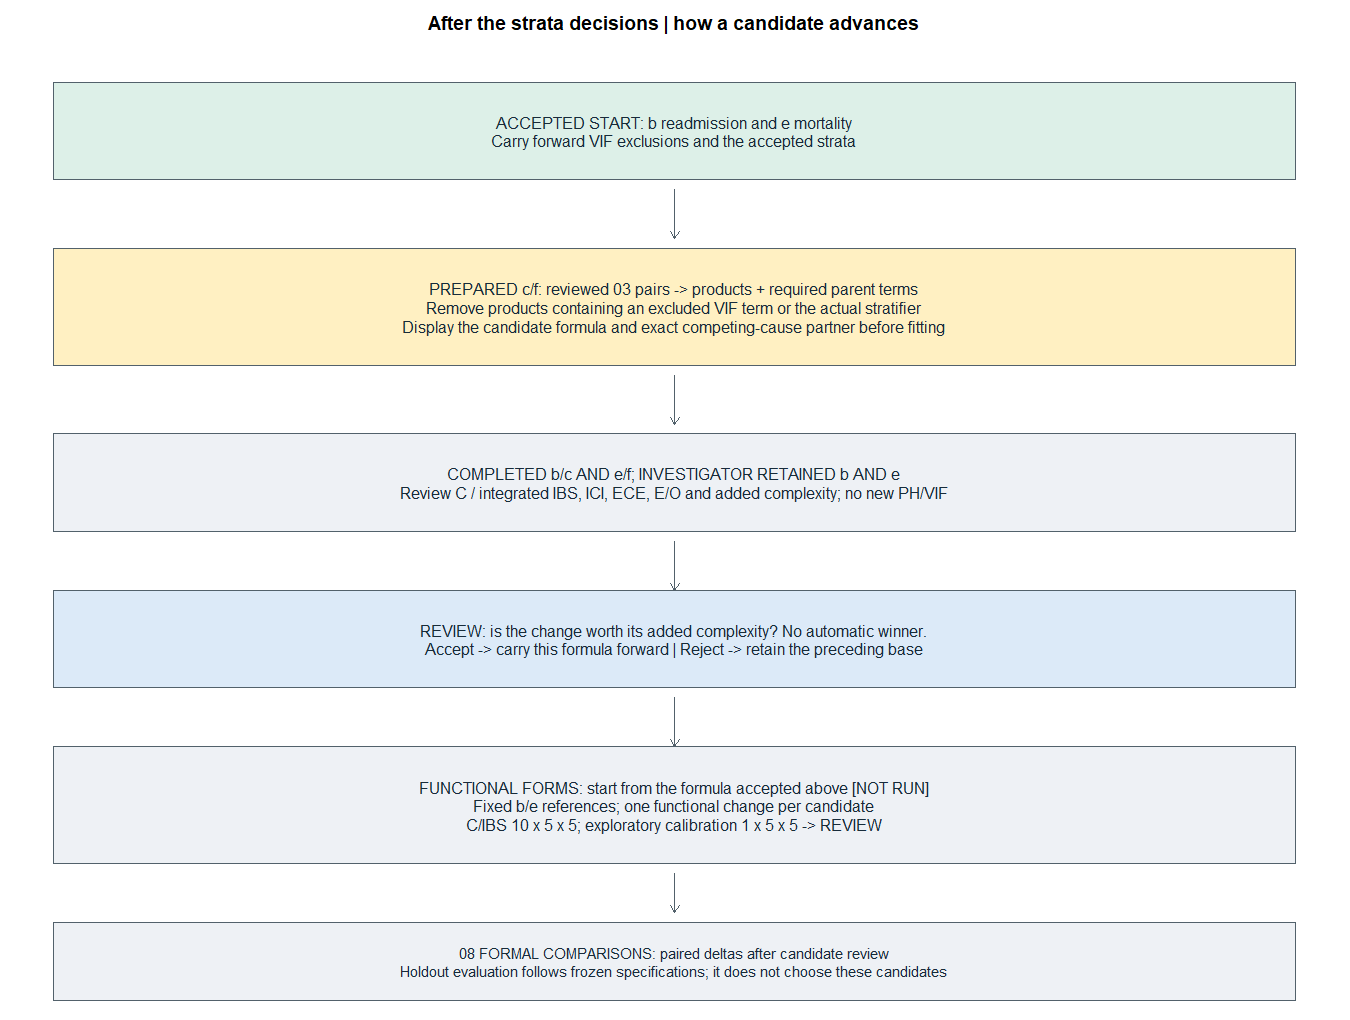

Elapsed: 0.001 minutes


In [21]:
#| label: shap-interactions-decision-flowchart
#| message: false
.t0 <- proc.time()
# Show the investigator checkpoints before any interaction or functional-form fitting.
show_diagnostic_png(function() {
  decision_canvas("After the strata decisions | how a candidate advances")
  decision_box(0.04, 0.96, 0.91, "ACCEPTED START: b readmission and e mortality\nCarry forward VIF exclusions and the accepted strata", "accepted", h = 0.05)
  decision_arrow(0.5, 0.85, y2 = 0.80)
  decision_box(0.04, 0.96, 0.73, "PREPARED c/f: reviewed 03 pairs -> products + required parent terms\nRemove products containing an excluded VIF term or the actual stratifier\nDisplay the candidate formula and exact competing-cause partner before fitting", "prepared", h = 0.06)
  decision_arrow(0.5, 0.66, y2 = 0.61)
  decision_box(0.04, 0.96, 0.55, "COMPLETED b/c AND e/f; INVESTIGATOR RETAINED b AND e\nReview C / integrated IBS, ICI, ECE, E/O and added complexity; no new PH/VIF", "pending", h = 0.05)
  decision_arrow(0.5, 0.49, y2 = 0.44)
  decision_box(0.04, 0.96, 0.39, "REVIEW: is the change worth its added complexity? No automatic winner.\nAccept -> carry this formula forward | Reject -> retain the preceding base", "review", h = 0.05)
  decision_arrow(0.5, 0.33, y2 = 0.28)
  decision_box(0.04, 0.96, 0.22, "FUNCTIONAL FORMS: start from the formula accepted above [NOT RUN]\nFixed b/e references; one functional change per candidate\nC/IBS 10 x 5 x 5; exploratory calibration 1 x 5 x 5 -> REVIEW", "pending", h = 0.06)
  decision_arrow(0.5, 0.15, y2 = 0.11)
  decision_box(0.04, 0.96, 0.06, "08 FORMAL COMPARISONS: paired deltas after candidate review\nHoldout evaluation follows frozen specifications; it does not choose these candidates", "pending", h = 0.04, cex = 0.82)
}, 1350L, 1020L)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


In [22]:
#| label: shap-interaction-expansion-preview
#| message: false
.t0 <- proc.time()
# Preserve original family exclusions and eligibility; diagnostic flags are not filters.
interaction_family <- function(x) {
  patterns <- c(plan_type = "^plan_type_corr_", adm_motive = "^adm_motive_", tr_outcome = "^tr_outcome_", primary_sub_mod = "^primary_sub_mod_", first_sub_used = "^first_sub_used_", marital_status = "^marital_status_", occupation_condition = "^occupation_condition_", cohabitation = "^cohabitation_", tipo_vivienda = "^tipo_de_vivienda_", dx_psiq = "^dx_", dg_psiq = "^dg_psiq_", eva_consumo = "^eva_consumo", eva_sm = "^eva_sm", eva_fam = "^eva_fam", eva_ocupacion = "^eva_ocupacion", eva_relinterp = "^eva_relinterp", eva_transgnorma = "^eva_transgnorma", sub_dep = "^sub_dep_icd10_", prim_sub_freq = "^prim_sub_freq", education = "^ed_attainment", tenure = "^tenure_status", sex = "^sex_rec_", age = "^adm_age", dit_m = "^dit_m$", ethnicity = "^ethnicity$", polysubstance = "^polysubstance", any_phys_dx = "^any_phys_dx$", evaluacindelproceso = "^evaluacindelproceso")
  hits <- names(patterns)[vapply(patterns, grepl, logical(1L), x = x)]
  if (length(hits)) hits[[1L]] else x
}
interaction_columns <- function(feature) {
  if (feature %in% names(py_corrected_datasets[[1L]])) return(feature)
  columns <- names(py_corrected_datasets[[1L]])[startsWith(names(py_corrected_datasets[[1L]]), paste0(feature, "_"))]
  stopifnot(length(columns) > 0L)
  columns
}
interaction_source$Original_rule <- with(interaction_source, abs_corr >= 0.10 & !is.na(smd_binarized) & abs(smd_binarized) >= 0.15 & (is.na(rank_range) | rank_range <= 8) & (is.na(abs_corr_delta) | abs_corr_delta <= 0.05))
family_main <- vapply(interaction_source$main_feature, interaction_family, character(1L))
family_interactor <- vapply(interaction_source$interactor, interaction_family, character(1L))
interaction_source$Original_rule <- interaction_source$Original_rule & family_main != "plan_type" & family_interactor != "plan_type" & family_main != family_interactor
stopifnot(!anyNA(interaction_source$Original_rule))
interaction_bases <- list(Readmission = formula_shap_readmit_clean_updated, Death = formula_shap_death_rule2)
interaction_preview <- do.call(rbind, lapply(seq_len(nrow(interaction_source)), function(i) {
  row <- interaction_source[i, ]
  stopifnot(row$outcome %in% names(interaction_bases))
  products <- as.vector(outer(interaction_columns(row$main_feature), interaction_columns(row$interactor), paste, sep = ":"))
  strata <- formula_strata(interaction_bases[[row$outcome]])
  do.call(rbind, lapply(products, function(product) {
    parents <- strsplit(product, ":", fixed = TRUE)[[1L]]
    reason <- if (!row$Original_rule) "Excluded: original screening rule" else if (any(parents %in% removed_collinear)) "Excluded: removed VIF term" else if (any(parents %in% strata)) "Excluded: actual stratifier" else "Prepared: eligible product"
    data.frame(Outcome = row$outcome, SHAP_pair = paste(row$main_feature, row$interactor, sep = " x "), Product = product, Label = paste(display_term(parents), collapse = " x "), Status = reason, Eligible = reason == "Prepared: eligible product", stringsAsFactors = FALSE)
  }))
}))
canonical_terms <- function(x) vapply(strsplit(x, ":", fixed = TRUE), function(parts) paste(sort(parts), collapse = ":"), character(1L))
stopifnot(!anyDuplicated(paste(interaction_preview$Outcome, canonical_terms(interaction_preview$Product))))
show_table(interaction_preview[, c("Outcome", "SHAP_pair", "Product", "Label", "Status")], "Interaction eligibility resolved for accepted b/e; no model fitted")
cat("Physical-comorbidity x alcohol is excluded because physical comorbidity is a stratum in e. Physical assessment at discharge is a different variable and remains eligible with age. Referral remains an ordinary predictor in b.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)

Outcome,SHAP_pair,Product,Label,Status
Death,primary_sub_mod_alcohol x adm_age_rec3,primary_sub_mod_alcohol:adm_age_rec3,"Alcohol (primary at admission) x Age at admission, yr",Prepared: eligible product
Death,occupation_condition_corr24_unemployed x adm_age_rec3,occupation_condition_corr24_unemployed:adm_age_rec3,"Unemployed x Age at admission, yr",Prepared: eligible product
Death,primary_sub_mod_alcohol x prim_sub_freq_rec,primary_sub_mod_alcohol:prim_sub_freq_rec_2_2_6_days_wk,"Alcohol (primary at admission) x Use frequency, primary substance: 2-6 days/week",Prepared: eligible product
Death,primary_sub_mod_alcohol x prim_sub_freq_rec,primary_sub_mod_alcohol:prim_sub_freq_rec_3_daily,"Alcohol (primary at admission) x Use frequency, primary substance: daily",Prepared: eligible product
Death,cohabitation_with_couple_children x adm_age_rec3,cohabitation_with_couple_children:adm_age_rec3,"Lives with partner or children x Age at admission, yr",Prepared: eligible product
Death,any_phys_dx x primary_sub_mod_alcohol,any_phys_dx:primary_sub_mod_alcohol,Any selected physical comorbidity recorded x Alcohol (primary at admission),Excluded: actual stratifier
Death,eva_fisica x adm_age_rec3,eva_fisica_logro_intermedio:adm_age_rec3,"Discharge evaluation, physical health: intermediate achievement x Age at admission, yr",Prepared: eligible product
Death,eva_fisica x adm_age_rec3,eva_fisica_logro_minimo:adm_age_rec3,"Discharge evaluation, physical health: minimum achievement x Age at admission, yr",Prepared: eligible product
Readmission,primary_sub_mod_cocaine_powder x first_sub_used_alcohol,primary_sub_mod_cocaine_powder:first_sub_used_alcohol,"Cocaine hydrochloride (primary at admission) x Alcohol, first substance used",Prepared: eligible product
Readmission,eva_consumo x tr_outcome_referral,eva_consumo_logro_intermedio:tr_outcome_referral,"Discharge evaluation, substance use: intermediate achievement x Discharge: referral",Prepared: eligible product


Physical-comorbidity x alcohol is excluded because physical comorbidity is a stratum in e. Physical assessment at discharge is a different variable and remains eligible with age. Referral remains an ordinary predictor in b.


Elapsed: 0.000 minutes


## Investigator decision: do not pursue the third mortality stratification factor
Decision recorded: 2026-10-06T16:06:45-03:00.

The investigator decided **not to pursue treatment-setting + physical-comorbidity + administrative-discharge strata for mortality**. The support audit found a group of 23 development participants with two deaths; 11 of the 250 training fits defined by the fixed ten-repeat C/IBS partitions had at least one stratum with no deaths. These are training fits, not 11 distinct strata or 250 independent samples. A similar overall C/IBS would not establish reliable probabilities for this sparse group. The third factor was not predictively evaluated; its exclusion is a documented support/parsimony decision, not an observed loss of predictive performance.

The previously executed first-imputation PH/VIF diagnostic and support flags remain visible for traceability. The triple candidate is excluded from subsequent predictive evaluation. Nobody is removed, strata are not merged, no fallback is applied, and seeds are not redrawn. The preceding mortality candidate keeps administrative discharge as an ordinary predictor when treatment setting and physical comorbidity are strata; its residual NPH and calibration still require review. This decision does not automatically select that two-factor model.

**VIF clarification:** the completed Full-initial versus SHAP-initial C/IBS comparison preceded removal of the high-VIF term. The existing rule flags VIF >= 10, not VIF < 10. The term is minimum therapeutic-process achievement. Its VIF in the initial Full models is 13.0349 for readmission and 13.2006 for mortality. The initial SHAP readmission maximum is 11.3038 and becomes 5.7015 in the already-defined reduced candidate. Initial SHAP mortality already has maximum VIF 7.5493. The next formula checkpoint must identify whether it uses the initial or VIF-reduced models; initial C/IBS must not be presented as reduced-model results. Sources: executed `cox-full-models-and-vif` in 06 and `shap-sequential-candidate-diagnostics` in this notebook.

The saved first-imputation reduced Full fits were also checked directly with `rms::vif`: maximum VIF 9.3511 for readmission and 9.0968 for mortality. No refitting was needed. Thus the already-defined reduced Full specifications resolve the flagged VIF threshold. Sources: the `cox_readmission_reduced_imp1` and `cox_death_reduced_imp1` caches with signature `fcd1bd763f13`. This check does not convert initial-model C/IBS into reduced-model results.


## Predictive evaluation, one investigator checkpoint at a time
The approved C/IBS design is **10 repetitions x 5 folds x 5 completed-development imputations**. Repeat 1 reproduces the original partitions. Repeats 2-10 use the original event-by-treatment-setting fold algorithm with deterministic, non-overlapping seeds. Partitions differ between imputations and are shared by every candidate. Predictions are pooled across imputations within each repetition; C and integrated IBS are scored within that repetition; the ten metrics are averaged. Averaging all repetitions' predictions is not substituted for repeated CV.

**Completed:** initial Full versus initial SHAP, followed by VIF-resolved Full versus SHAP with the same setting-only strata. The VIF checkpoint includes C/IBS and **20 x 5 x 5 calibration**, and the investigator accepted continuation. **Completed and accepted: model b**, SHAP readmission with setting plus discharge strata. **Completed, review pending: model e**, SHAP mortality with setting plus physical-comorbidity strata, keeping b fixed. The third mortality factor remains rejected. No fallback, stratum merging, patient omission, new imputation, tuning, SHAP or bootstrap is introduced.

IBS is the preserved Graf time integral from zero to each horizon, divided by that horizon, on a 0.25-month grid. It is not the mean of a few horizon Brier scores. Readmission uses the preserved net-survival arm with competing-risk-aware weights; AJ calibration uses CIF, a different probability target. Complete-development imputation and SHAP selection precede internal CV: this is **not independent validation of the complete preprocessing and selection workflow**.

The investigator explicitly authorized model e on 2026-10-06. The current step is `mortality_physical`, with `performance_mode: mortality_stratum`; existing results are reused from cache. This comparison is completed and awaiting review. It does not authorize interaction models c/f. The actual evaluation took 45.88 minutes and fitted 1750 predictive Cox models; a subsequent presentation replay fits none. C/IBS uses at most eight single-thread processes, budgets 5 GiB per worker and reserves 20 GiB. These are planning limits, not operating-system quotas. The existing complete calibration engines and shared AJ binning are preserved.

### Why the rejected mortality third factor is separate
The two-factor candidate (setting plus physical comorbidity) retains administrative discharge as an ordinary predictor for everyone. It still needs predictive review. Adding discharge as a third factor would split ten baseline-risk groups into twenty. The recorded support audit found a group of 23 people with two deaths and zero-event training strata in some fixed partitions. The investigator rejected that extra factor; no people are removed and no different formula is substituted for sparse groups. Residual NPH is recorded rather than declared harmless. The prediction-focused literature and its limits are retained in the manuscript folder's `obs_oct_27.md`.


In [23]:
#| label: shap-performance-contract
#| message: true
.t0 <- proc.time()
# Keep scoring definitions and source fingerprints separate from the diagnostic cache.
performance_settings <- config$cox_performance
performance_settings$mode <- shap_settings$performance_mode
performance_settings$c_ibs_repeats <- as.integer(shap_settings$c_ibs_repeats)
performance_settings$workers <- as.integer(shap_settings$c_ibs_workers)
# Only the next investigator checkpoint is enabled; later candidates remain prepared.
stopifnot(shap_settings$performance_step %in% c("initial_selection", "vif_resolved", "readmission_discharge", "mortality_physical"), performance_settings$c_ibs_repeats == 10L)
if (performance_settings$mode == "full") stop("Review the initial-selection C/IBS checkpoint before enabling calibration or later stages.", call. = FALSE)
performance_formulas <- candidate_formulas
for (outcome in names(performance_formulas)) performance_formulas[[outcome]]$full_initial <- cox_formulas[[outcome]]$full
performance_candidates <- expand.grid(Outcome = c("readmission", "death"), Stage = c("full_initial", "initial"), stringsAsFactors = FALSE)
performance_by_repetition <- list()
performance_coverage <- list()
stopifnot(performance_settings$mode %in% c("prepare", "c_ibs", "vif_comparison", "readmission_stratum", "mortality_stratum", "full"), length(py_corrected_datasets) == 5L, triple_candidate_evaluated)
stopifnot(performance_settings$folds == 5L, performance_settings$n_imputations == 5L, performance_settings$calibration_repeats == 20L, performance_settings$threads == threads)
performance_horizons <- as.numeric(unlist(performance_settings$horizons_months))
performance_grid <- sort(unique(c(0, seq(0.25, max(performance_horizons), by = performance_settings$ibs_grid_step_months), performance_horizons)))
performance_packages <- c("pec", "riskRegression", "prodlim", "future.apply", "caret")
for (package in performance_packages) stopifnot(utils::packageVersion(package) == base::package_version(lock$Packages[[package]]$Version))
future::plan(future::sequential)
performance_source <- jsonlite::read_json(source_path("cox_shap_notebook"), simplifyVector = FALSE)
performance_code <- vapply(performance_source$cells, function(cell) paste(unlist(cell$source), collapse = ""), character(1L))
engine_labels <- c("shap-performance-classical-metric-functions", "shap-performance-aj-calibration-engine", "shap-performance-death-calibration-engine", "shap-performance-functions", "shap-performance-repeat-contract")
engine_code <- vapply(engine_labels, function(x) {
  hit <- performance_code[grepl(paste0("#| label: ", x, "\n"), performance_code, fixed = TRUE)]
  stopifnot(length(hit) == 1L)
  hit
}, character(1L))
performance_input_hashes <- vapply(c("cox_development_matrices", "cox_fold_control"), function(x) digest::digest(file = source_path(x), algo = "sha256"), character(1L))
performance_signature <- substr(digest::digest(list(performance_input_hashes, engine_code, performance_settings[c("fold_contract", "folds", "n_imputations", "calibration_repeats", "horizons_months", "ibs_grid_step_months", "seed", "c_ibs_repeats")], lock$Packages[c("survival", "pec", "riskRegression", "prodlim", "caret")], RNGkind()), algo = "sha256"), 1L, 12L)
performance_new_fits <- 0L
interaction_allowed <- character()
performance_results <- list()
performance_calibration_readmission <- list()
performance_calibration_death <- list()
record_performance_fits <- function(n) performance_new_fits <<- performance_new_fits + as.integer(n)
performance_formula_key <- function(outcome, stage) paste(outcome, substr(digest::digest(deparse(performance_formulas[[outcome]][[stage]]), algo = "sha256"), 1L, 12L), sep = "_")
performance_cache <- function(name, compute) {
  hits <- list.files(object_dir, pattern = paste0("^perf07_", name, "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE)
  stopifnot(length(hits) <= 1L)
  if (length(hits)) {
    cached <- readRDS(hits[[1L]])
    stopifnot(identical(cached$signature, performance_signature))
    return(cached$value)
  }
  # Later checkpoints may only fit their newly approved formula; missing previous caches must be restored.
  if (shap_settings$performance_step %in% c("readmission_discharge", "mortality_physical")) {
    allowed <- c(paste0("metrics_", performance_formula_key("readmission", "discharge_stratum"), "_r"), paste0("oof_", performance_formula_key("readmission", "discharge_stratum"), "_r"), paste("cal_aj", performance_formula_key("readmission", "discharge_stratum"), performance_formula_key("death", "initial"), sep = "_"))
    if (identical(shap_settings$performance_step, "mortality_physical")) allowed <- c(paste0("metrics_", performance_formula_key("death", "physical_stratum"), "_r"), paste0("oof_", performance_formula_key("death", "physical_stratum"), "_r"), paste("cal_aj", performance_formula_key("readmission", "discharge_stratum"), performance_formula_key("death", "physical_stratum"), sep = "_"), paste0("cal_km_", performance_formula_key("death", "physical_stratum")))
    interaction_authorized <- shap_settings$interaction_mode %in% c("readmission", "mortality") && any(startsWith(name, interaction_allowed))
    if (!interaction_authorized && (performance_settings$mode == "prepare" || !any(startsWith(name, allowed)))) stop(paste("Earlier checkpoint cache is missing or this fit is not scheduled:", name), call. = FALSE)
  }
  started <- Sys.time()
  value <- compute()
  destination <- file.path(object_dir, paste0("perf07_", name, "_", Sys.Date(), "_", performance_signature, ".rds"))
  # Write once per independent task; an interrupted save must not look like a complete cache.
  temporary <- paste0(destination, ".tmp-", Sys.getpid())
  saveRDS(list(signature = performance_signature, value = value), temporary, compress = TRUE, version = 3L)
  stopifnot(file.rename(temporary, destination))
  written <<- c(written, destination)
  cat(format(Sys.time(), "%H:%M:%S"), "| saved", name, "| seconds", round(as.numeric(difftime(Sys.time(), started, units = "secs")), 2), "\n")
  flush.console()
  value
}
candidate_names <- list(readmission = c(initial = "Setting strata", reduced = "Setting strata; collinear term removed", discharge_stratum = "Setting and discharge strata"), death = c(initial = "Setting strata", physical_stratum = "Setting and physical-comorbidity strata", physical_discharge_strata = "Setting, physical-comorbidity and discharge strata"))
calibration_pairs <- data.frame(Pair = c("initial", "readmission_reduced", "readmission_discharge", "death_physical", "death_physical_discharge"), Readmission = c("initial", "reduced", "discharge_stratum", "discharge_stratum", "discharge_stratum"), Death = c("initial", "initial", "initial", "physical_stratum", "physical_discharge_strata"))
stopifnot(all(vapply(names(candidate_names), function(o) identical(names(candidate_names[[o]]), names(candidate_formulas[[o]])), logical(1L))))
show_table(calibration_pairs, "Original prepared AJ pairs; current investigator exclusions are applied before predictive scheduling")
show_table(data.frame(Component = c("Uno C", "Readmission IBS", "Mortality IBS", "Readmission calibration", "Mortality calibration"), Definition = c("Horizon risk 1-S(h); pool survival across five imputations before scoring", "Historical net-survival predictions with competing-risk-aware Graf weights; integral from zero on the 0.25-month grid", "All-cause survival and classical Graf integration on the same grid", "Cause-specific predicted CIF versus AJ; all 20 x 5 x 5", "All-cause risk versus KM; all 20 x 5 x 5")), "Preserved evaluation definitions; readmission IBS and calibration have different probability targets")
cat("Performance mode:", performance_settings$mode, "| Signature:", performance_signature, "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Pair,Readmission,Death
initial,initial,initial
readmission_reduced,reduced,initial
readmission_discharge,discharge_stratum,initial
death_physical,discharge_stratum,physical_stratum
death_physical_discharge,discharge_stratum,physical_discharge_strata


Component,Definition
Uno C,Horizon risk 1-S(h); pool survival across five imputations before scoring
Readmission IBS,Historical net-survival predictions with competing-risk-aware Graf weights; integral from zero on the 0.25-month grid
Mortality IBS,All-cause survival and classical Graf integration on the same grid
Readmission calibration,Cause-specific predicted CIF versus AJ; all 20 x 5 x 5
Mortality calibration,All-cause risk versus KM; all 20 x 5 x 5


Performance mode: prepare | Signature: a9e685eb9086 


Elapsed: 0.037 minutes


In [24]:
#| label: shap-performance-classical-metric-functions
#| message: true
.t0 <- proc.time()
# Preserve the original scoring definition: .ibc_to01
.ibc_to01 <- function(x) if (is.logical(x)) as.integer(x) else as.integer(as.numeric(x) > 0)
# Preserve the original scoring definition: ibs_classical_grid
ibs_classical_grid <- function(max_horizon = 60, step = 0.25, horizons = NULL) {
    stopifnot(step > 0, max_horizon > 0)
    sort(unique(c(0, seq(step, max_horizon, by = step), max_horizon, horizons)))
}
# Preserve the original scoring definition: .ibc_G_train
.ibc_G_train <- function(time_train, event_train, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time_train, 1 - .ibc_to01(event_train)) ~ 1)
    tau <- {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe))
            max(safe)
        else Inf
    }
    list(tau = tau, at = function(tt) {
        req <- pmax(as.numeric(tt), 0)
        u <- sort(unique(req))
        g <- as.numeric(summary(sf, times = u, extend = TRUE)$surv)
        if (length(g) != length(u)) stop("Censoring lookup returned an unexpected length.", call. = FALSE)
        i <- match(req, u)
        if (anyNA(i)) stop("Censoring lookup could not restore request order.", call. = FALSE)
        pmax(g[i], g_min)
    })
}
# Preserve the original scoring definition: .ibc_contrib
.ibc_contrib <- function(G, time_te, event_te, surv_te, grid_pos, eps = 1e-08) {
    Tt <- as.numeric(time_te)
    Dt <- .ibc_to01(event_te)
    stopifnot(ncol(surv_te) == length(grid_pos), nrow(surv_te) == length(Tt))
    g_event <- G$at(pmax(Tt - eps, 0))
    out <- matrix(0, length(Tt), length(grid_pos))
    for (j in seq_along(grid_pos)) {
        t0 <- grid_pos[j]
        S0 <- surv_te[, j]
        Y0 <- as.numeric(Tt > t0)
        w <- ifelse(Tt <= t0 & Dt == 1L, 1/g_event, ifelse(Tt > t0, 1/G$at(t0), 0))
        out[, j] <- w * (Y0 - S0)^2
    }
    out
}
# Preserve the original scoring definition: .ibc_trap_weights
.ibc_trap_weights <- function(grid_pos, horizons) {
    W <- matrix(0, length(grid_pos), length(horizons))
    for (k in seq_along(horizons)) {
        keep <- which(grid_pos <= horizons[k] + 1e-12)
        if (!length(keep))
            next
        d <- diff(c(0, grid_pos[keep]))
        m <- length(d)
        w <- d/2
        if (m > 1L)
            w[seq_len(m - 1L)] <- w[seq_len(m - 1L)] + d[-1L]/2
        W[keep, k] <- w
    }
    W
}
# Preserve the original scoring definition: ibs_classical_point
ibs_classical_point <- function(pred, horizons = c(3, 6, 12, 36, 60), g_min = 0.05) {
    grid <- pred$grid
    pos <- which(grid > 0)
    grid_pos <- grid[pos]
    G <- .ibc_G_train(pred$y_train$time, pred$y_train$event, g_min = g_min)
    usable <- horizons <= min(G$tau, max(pred$y_train$time, na.rm = TRUE))
    C <- .ibc_contrib(G, pred$y_test$time, pred$y_test$event, pred$S[, pos, drop = FALSE], grid_pos)
    W <- .ibc_trap_weights(grid_pos, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons,
        tau_ipcw = G$tau, brier_curve = data.frame(time_months = grid_pos, brier = colMeans(C)))
}
# Preserve the original scoring definition: ibs_classical_readmit
ibs_classical_readmit <- function(pred, horizons = c(3, 6, 12, 36, 60), method = c("aalen-johansen", "ipcw"), g_min = 0.05,
    eps = 1e-08) {
    method <- match.arg(method)
    stopifnot(exists(".ibsb_contrib_readmit_aj", mode = "function"))
    cc <- if (method == "aalen-johansen") {
        .ibsb_contrib_readmit_aj(pred$S, pred$rt_val, pred$re_val, pred$dt_val, pred$de_val, pred$rt_tr, pred$re_tr, pred$dt_tr,
            pred$de_tr, pred$grid, g_min, eps)
    }
    else {
        .ibsb_contrib_readmit_ipcw(pred$S, pred$rt_val, pred$re_val, pred$rt_tr, pred$re_tr, pred$grid, g_min, eps)
    }
    pos <- which(cc$grid > 0)
    gp <- cc$grid[pos]
    C <- cc$C[, pos, drop = FALSE]
    usable <- horizons <= max(gp) + 1e-08
    W <- .ibc_trap_weights(gp, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons,
        method = method, grid_max_kept = max(gp), brier_curve = data.frame(time_months = gp, brier = colMeans(C)))
}
# Preserve the original scoring definition: %||%
`%||%` <- function(a, b) if (is.null(a) || length(a) == 0L) b else a
# Preserve the original scoring definition: .ibsb_to01
.ibsb_to01 <- function(x) as.integer(as.numeric(x) > 0)
# Preserve the original scoring definition: .ibsb_G_fun
.ibsb_G_fun <- function(time, cens_event, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time, cens_event) ~ 1)
    list(fun = function(tt) {
        requested_times <- pmax(as.numeric(tt), 0)
        unique_times <- sort(unique(requested_times))
        g_unique <- as.numeric(summary(sf, times = unique_times, extend = TRUE)$surv)
        if (length(g_unique) != length(unique_times)) stop("Censoring-survival lookup returned an unexpected length.", call. = FALSE)
        lookup_index <- match(requested_times, unique_times)
        if (anyNA(lookup_index)) stop("Censoring-survival lookup could not restore request order.", call. = FALSE)
        pmax(g_unique[lookup_index], g_min)
    }, tau = {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe)) max(safe) else NA_real_
    })
}
# Preserve the original scoring definition: .ibsb_cr
.ibsb_cr <- function(readmit_time, readmit_event, death_time, death_event) {
    rt <- as.numeric(readmit_time)
    re <- .ibsb_to01(readmit_event)
    dt <- as.numeric(death_time)
    de <- .ibsb_to01(death_event)
    ftime <- pmin(rt, dt)
    r_first <- re == 1L & is.finite(ftime) & abs(rt - ftime) <= 1e-08
    d_first <- de == 1L & is.finite(ftime) & abs(dt - ftime) <= 1e-08
    fstatus <- rep(0L, length(ftime))
    fstatus[r_first & !d_first] <- 1L
    fstatus[d_first & !r_first] <- 2L
    fstatus[r_first & d_first] <- 2L
    list(ftime = ftime, fstatus = fstatus)
}
# Preserve the original scoring definition: .ibsb_contrib_readmit_aj
.ibsb_contrib_readmit_aj <- function(surv_val, rt_val, re_val, dt_val, de_val, rt_tr, re_tr, dt_tr, de_tr, grid, g_min, eps) {
    cr_v <- .ibsb_cr(rt_val, re_val, dt_val, de_val)
    cr_t <- .ibsb_cr(rt_tr, re_tr, dt_tr, de_tr)
    G <- .ibsb_G_fun(cr_t$ftime, as.integer(cr_t$fstatus == 0L), g_min = g_min)
    tau <- G$tau %||% NA_real_
    tmax_train <- max(cr_t$ftime, na.rm = TRUE)
    keep <- grid <= (if (is.finite(tau))
        tau
    else max(grid)) & grid <= tmax_train
    gk <- grid[keep]
    ft <- cr_v$ftime
    fs <- cr_v$fstatus
    C <- matrix(0, nrow = length(ft), ncol = length(gk))
    for (j in seq_along(gk)) {
        t0 <- gk[j]
        is_readmit <- fs == 1L & ft <= t0
        is_death <- fs == 2L & ft <= t0
        is_efree <- ft > t0
        Y0 <- as.numeric(!is_readmit)
        w <- ifelse(is_readmit | is_death, 1/G$fun(pmax(ft - eps, 0)), ifelse(is_efree, 1/G$fun(t0), 0))
        C[, j] <- w * (Y0 - surv_val[, which(keep)[j]])^2
    }
    list(C = C, grid = gk)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [25]:
#| label: shap-performance-aj-calibration-engine
.calibration_definition_start <- proc.time()
# Define the historical calibration engine with resumable tasks and completeness guards.
calibrate_cscox_aj_grouped_corr <- function(formula_readmit, formula_death = NULL, data, times = c(12, 36, 60), readmit_time_var = "readmit_time_from_disch_m",
    readmit_event_var = "readmit_event", death_time_var = "death_time_from_disch_m", death_event_var = "death_event", n_imputations = NULL,
    validation = c("apparent", "cv"), folds = 5L, n_repeats = 10L, g = 10L, min_bin_n = 20L, compute_ici = FALSE, ici_times = NULL,
    ici_df = 4L, seed = 2125L, tie_action = c("death_first", "readmit_first", "drop", "error"), verbose = TRUE, make_plots = TRUE,
    parallel_cv = TRUE, parallel_calibration = parallel_cv, future_scheduling = 2, debug_fit = FALSE, ici_span = 0.75, cache_prefix = NULL) {
    if (!is.null(cache_prefix) && isTRUE(parallel_cv))
        stop("Calibration task caching requires parallel_cv = FALSE.", call. = FALSE)
    if (!requireNamespace("survival", quietly = TRUE))
        stop("Package 'survival' is required.")
    if (!requireNamespace("riskRegression", quietly = TRUE))
        stop("Package 'riskRegression' is required.")
    if (!requireNamespace("prodlim", quietly = TRUE))
        stop("Package 'prodlim' is required.")
    if (isTRUE(compute_ici) && !requireNamespace("splines", quietly = TRUE))
        stop("Package 'splines' is required when compute_ici = TRUE.")
    if (!inherits(formula_readmit, "formula"))
        stop("'formula_readmit' must be a formula.")
    if (!is.null(formula_death) && !inherits(formula_death, "formula"))
        stop("'formula_death' must be NULL or a formula.")
    validation <- match.arg(validation)
    tie_action <- match.arg(tie_action)
    if (!is.numeric(times) || length(times) == 0L || any(!is.finite(times)) || any(times < 0)) {
        stop("'times' must be a non-empty numeric vector of non-negative finite values.")
    }
    times <- sort(unique(as.numeric(times)))
    folds <- as.integer(folds)
    n_repeats <- as.integer(n_repeats)
    g <- as.integer(g)
    min_bin_n <- as.integer(min_bin_n)
    ici_df <- as.integer(ici_df)
    if (is.null(ici_times)) {
        ici_times <- times
    }
    else {
        if (!is.numeric(ici_times) || any(!is.finite(ici_times)))
            stop("'ici_times' must be numeric.")
        ici_times <- sort(unique(as.numeric(ici_times)))
    }
    if (any(!ici_times %in% times))
        stop("'ici_times' must be a subset of 'times'.")
    if (validation == "cv" && folds < 2L)
        stop("'folds' must be >= 2 when validation = 'cv'.")
    if (n_repeats < 1L)
        stop("'n_repeats' must be >= 1.")
    if (g < 1L)
        stop("'g' must be >= 1.")
    if (min_bin_n < 1L)
        stop("'min_bin_n' must be >= 1.")
    if (ici_df < 1L)
        stop("'ici_df' must be >= 1.")
    if (validation == "apparent" && n_repeats != 1L) {
        if (isTRUE(verbose))
            message("validation = 'apparent': using a single run and ignoring n_repeats > 1.")
        n_repeats <- 1L
    }
    .msg <- function(...) {
        if (isTRUE(verbose))
            message(...)
    }
    .as_df_list <- function(x, n_imputations = NULL) {
        if (is.data.frame(x)) {
            out <- list(as.data.frame(x))
        }
        else if (is.list(x) && length(x) > 0L && all(vapply(x, is.data.frame, logical(1)))) {
            out <- lapply(x, as.data.frame)
        }
        else {
            stop("'data' must be a data.frame or a list of data.frames.")
        }
        if (!is.null(n_imputations)) {
            out <- out[seq_len(min(as.integer(n_imputations), length(out)))]
        }
        out
    }
    .run_stats <- function(x, probs = c(0.025, 0.975), type = 8) {
        x <- x[is.finite(x)]
        n <- length(x)
        if (n == 0L) {
            return(c(mean = NA_real_, sd = NA_real_, min = NA_real_, p025 = NA_real_, p975 = NA_real_, max = NA_real_, n = 0L))
        }
        q <- stats::quantile(x, probs = c(0, probs, 1), na.rm = TRUE, names = FALSE, type = type)
        c(mean = mean(x), sd = if (n > 1L) stats::sd(x) else 0, min = q[1], p025 = q[2], p975 = q[3], max = q[4], n = n)
    }
    .coerce_event01 <- function(x, varname) {
        if (is.logical(x))
            return(as.integer(x))
        if (is.factor(x))
            x <- as.character(x)
        if (is.character(x)) {
            out <- rep(NA_integer_, length(x))
            ok <- !is.na(x)
            x0 <- trimws(tolower(x[ok]))
            out_ok <- ifelse(x0 %in% c("1", "true", "yes", "y"), 1L, ifelse(x0 %in% c("0", "false", "no", "n"), 0L, NA_integer_))
            bad_nonmissing <- is.na(out_ok)
            if (any(bad_nonmissing)) {
                bad_vals <- unique(x[ok][bad_nonmissing])
                stop("Variable '", varname, "' contains non-missing values that cannot be coerced to 0/1: ", paste(utils::head(bad_vals,
                  10), collapse = ", "))
            }
            out[ok] <- out_ok
            return(out)
        }
        if (is.numeric(x) || is.integer(x)) {
            ux <- unique(stats::na.omit(x))
            if (!all(ux %in% c(0, 1))) {
                stop("Variable '", varname, "' must contain only 0/1 values (besides NA).")
            }
            return(as.integer(x))
        }
        stop("Variable '", varname, "' must be logical, numeric/integer 0/1, factor, or character.")
    }
    .rhs_formula <- function(formula_obj) {
        f_rhs <- stats::formula(stats::delete.response(stats::terms(formula_obj)))
        environment(f_rhs) <- environment(formula_obj)
        f_rhs
    }
    .build_hist_formula <- function(rhs_formula) {
        f_hist <- stats::update.formula(rhs_formula, prodlim::Hist(.ftime, .fstatus) ~ .)
        env <- new.env(parent = globalenv())
        env$strata <- survival::strata
        if (exists("strat", envir = asNamespace("riskRegression"), inherits = FALSE)) {
            env$strat <- get("strat", envir = asNamespace("riskRegression"), inherits = FALSE)
        }
        environment(f_hist) <- env
        f_hist
    }
    .make_first_event_data <- function(d) {
        req <- c(readmit_time_var, readmit_event_var, death_time_var, death_event_var)
        miss <- setdiff(req, names(d))
        if (length(miss) > 0L)
            stop("Missing required columns: ", paste(miss, collapse = ", "))
        tr <- d[[readmit_time_var]]
        td <- d[[death_time_var]]
        er <- .coerce_event01(d[[readmit_event_var]], readmit_event_var)
        ed <- .coerce_event01(d[[death_event_var]], death_event_var)
        if (!is.numeric(tr) || !is.numeric(td))
            stop("Time variables must be numeric.")
        if (any(tr < 0, na.rm = TRUE) || any(td < 0, na.rm = TRUE))
            stop("Negative follow-up times are not allowed.")
        d$.tr_raw <- tr
        d$.td_raw <- td
        d$.er_raw <- er
        d$.ed_raw <- ed
        .ftime <- pmin(tr, td)
        r_at_first <- (er == 1L) & !is.na(er) & !is.na(.ftime) & (abs(tr - .ftime) <= 1e-08)
        d_at_first <- (ed == 1L) & !is.na(ed) & !is.na(.ftime) & (abs(td - .ftime) <= 1e-08)
        .fstatus <- rep(0L, length(.ftime))
        .fstatus[r_at_first & !d_at_first] <- 1L
        .fstatus[d_at_first & !r_at_first] <- 2L
        both_at_first <- r_at_first & d_at_first
        n_ties <- sum(both_at_first, na.rm = TRUE)
        if (n_ties > 0L) {
            if (tie_action == "error") {
                stop("Found ", n_ties, " simultaneous readmission/death first events.")
            }
            else if (tie_action == "death_first") {
                .msg("Found ", n_ties, " ties; assigning them to death-first.")
                .fstatus[both_at_first] <- 2L
            }
            else if (tie_action == "readmit_first") {
                .msg("Found ", n_ties, " ties; assigning them to readmission-first.")
                .fstatus[both_at_first] <- 1L
            }
            else if (tie_action == "drop") {
                .msg("Found ", n_ties, " ties; they will be dropped by unified filtering.")
                .fstatus[both_at_first] <- NA_integer_
            }
        }
        d$.ftime <- .ftime
        d$.fstatus <- .fstatus
        d
    }
    .analysis_mask <- function(d0, rhs_readmit, rhs_death) {
        mf_readmit <- stats::model.frame(rhs_readmit, data = d0, na.action = stats::na.pass)
        mf_death <- stats::model.frame(rhs_death, data = d0, na.action = stats::na.pass)
        stats::complete.cases(d0[, c(".ftime", ".fstatus"), drop = FALSE]) & stats::complete.cases(mf_readmit) & stats::complete.cases(mf_death)
    }
    .validate_analysis_data <- function(dcc, validation, folds) {
        n <- nrow(dcc)
        n1 <- sum(dcc$.fstatus == 1L, na.rm = TRUE)
        n2 <- sum(dcc$.fstatus == 2L, na.rm = TRUE)
        if (n == 0L)
            stop("No complete cases remain after unified filtering.")
        if (n1 < 1L)
            stop("No readmission-first events remain in the analysis cohort.")
        if (n2 < 1L)
            stop("No death-first events remain in the analysis cohort.")
        if (validation == "cv") {
            if (folds > n)
                stop("'folds' cannot exceed the analysis sample size.")
            if (n1 < 2L)
                stop("Cross-validation is not feasible: fewer than 2 readmission-first events remain.")
            if (n2 < 2L)
                stop("Cross-validation is not feasible: fewer than 2 death-first events remain.")
        }
        invisible(TRUE)
    }
    .make_stratified_folds <- function(status, folds, seed_local) {
        set.seed(seed_local)
        n <- length(status)
        if (folds > n)
            stop("'folds' cannot exceed sample size.")
        fold_id <- integer(n)
        classes <- sort(unique(status))
        offset <- 0L
        for (cl in classes) {
            idx <- which(status == cl)
            idx <- sample(idx, length(idx), replace = FALSE)
            assign <- ((seq_along(idx) - 1L + offset)%%folds) + 1L
            fold_id[idx] <- assign
            offset <- (offset + length(idx))%%folds
        }
        tab <- tabulate(fold_id, nbins = folds)
        while (any(tab == 0L)) {
            empty_fold <- which(tab == 0L)[1L]
            donor_fold <- which.max(tab)
            donor_idx <- which(fold_id == donor_fold)
            move_idx <- sample(donor_idx, 1L)
            fold_id[move_idx] <- empty_fold
            tab <- tabulate(fold_id, nbins = folds)
        }
        for (k in seq_len(folds)) {
            tr_status <- status[fold_id != k]
            if (sum(tr_status == 1L, na.rm = TRUE) == 0L)
                stop("Invalid fold split: training fold ", k, " has zero readmission-first events.")
            if (sum(tr_status == 2L, na.rm = TRUE) == 0L)
                stop("Invalid fold split: training fold ", k, " has zero death-first events.")
            if (sum(fold_id == k) == 0L)
                stop("Invalid fold split: test fold ", k, " is empty.")
        }
        fold_id
    }
    .fit_csc_and_predict <- function(train_data, test_data, f1, f2, times) {
        fit <- tryCatch(riskRegression::CSC(list(f1, f2), data = train_data), error = function(e) stop("riskRegression::CSC failed.\nOriginal error: ",
            e$message))
        pred <- riskRegression::predictRisk(object = fit, newdata = test_data, times = times, cause = 1)
        if (is.null(dim(pred))) {
            pred <- matrix(pred, nrow = nrow(test_data), byrow = TRUE)
        }
        else {
            pred <- as.matrix(pred)
        }
        if (nrow(pred) != nrow(test_data) || ncol(pred) != length(times)) {
            stop("Predicted matrix has wrong dimensions: expected ", nrow(test_data), "x", length(times), ", got ", nrow(pred),
                "x", ncol(pred), ".")
        }
        if (any(!is.finite(pred)))
            stop("Non-finite predicted risks were produced. Calibration would be invalid.")
        pred <- pmin(pmax(pred, 0), 1)
        colnames(pred) <- paste0("t_", times)
        pred
    }
    .run_one_fold_csc <- function(task, analysis_data, times, M, f1, f2) {
        compute <- function() {
            tr_idx <- task$tr_idx
            te_idx <- task$te_idx
            pred_sum <- matrix(0, nrow = length(te_idx), ncol = length(times))
            for (m in seq_len(M)) {
                pred_m <- tryCatch(.fit_csc_and_predict(train_data = analysis_data[[m]][tr_idx, , drop = FALSE], test_data = analysis_data[[m]][te_idx,
                  , drop = FALSE], f1 = f1, f2 = f2, times = times), error = function(e) {
                  stop("Parallel task failed at repetition=", task$r, ", fold=", task$k, ", imputation=", m, ": ", conditionMessage(e),
                    call. = FALSE)
                })
                pred_sum <- pred_sum + pred_m
            }
            value <- list(r = task$r, te_idx = te_idx, pred_fold_avg = pred_sum/M)
            record_performance_fits(2L * M)
            value
        }
        task_name <- paste0(if (is.null(cache_prefix))
            "cal_readmission"
        else cache_prefix, "_r", sprintf("%02d", task$r), "_f", sprintf("%02d", task$k))
        cat(sprintf("[%s] %s start (fit or cache)\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value <- if (is.null(cache_prefix))
            compute()
        else performance_cache(task_name, compute)
        cat(sprintf("[%s] %s complete\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value
    }
    .run_one_calibration_repetition <- function(rep_obj, rep_total, times, reference_data, reference_observed, common_cutpoints,
        common_bin_maps, min_bin_n, compute_ici, ici_times, ici_df, n_input, n_analysis, n_dropped, n_readmit, n_death, M) {
        r <- rep_obj$repetition
        pred_r <- rep_obj$pred
        curves_rep <- list()
        metrics_rep <- list()
        for (j in seq_along(times)) {
            t_horizon <- times[j]
            pred_vec <- pred_r[, j]
            calib_obj <- .grouped_calibration(d = reference_data, pred_vec = pred_vec, t_horizon = t_horizon, cutpoints = common_cutpoints[[j]],
                bin_map = common_bin_maps[[j]], min_bin_n = min_bin_n)
            calib_df <- calib_obj$curve
            if (is.null(calib_df) || nrow(calib_df) == 0L) {
                warning("No calibration bins survived for repetition ", r, " at time ", t_horizon, ".", call. = FALSE)
                next
            }
            obs_row <- reference_observed[reference_observed$time_months == t_horizon, , drop = FALSE]
            ece <- stats::weighted.mean(abs(calib_df$mean_predicted - calib_df$observed), w = calib_df$n_patients, na.rm = TRUE)
            if (isTRUE(compute_ici) && t_horizon %in% ici_times && length(calib_obj$obs_lookup) > 0L) {
                ici_obj <- .compute_ici_loess(pred_vec = pred_vec, bins = calib_obj$bins, obs_lookup = calib_obj$obs_lookup,
                  loess_span = ici_span)
            }
            else {
                ici_obj <- list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_)
            }
            mean_pred <- mean(pred_vec, na.rm = TRUE)
            eo_ratio <- if (is.na(obs_row$observed[1]) || obs_row$observed[1] <= 0)
                NA_real_
            else mean_pred/obs_row$observed[1]
            calib_df$repetition <- r
            calib_df$time_months <- t_horizon
            curves_rep[[length(curves_rep) + 1L]] <- calib_df
            metrics_rep[[length(metrics_rep) + 1L]] <- data.frame(repetition = r, time_months = t_horizon, ici = ici_obj$ici,
                e50 = ici_obj$e50, e90 = ici_obj$e90, emax = ici_obj$emax, ece = ece, eo_ratio = eo_ratio, mean_predicted = mean_pred,
                observed = obs_row$observed[1], observed_lower = obs_row$observed_lower[1], observed_upper = obs_row$observed_upper[1],
                n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit, n_death = n_death,
                n_used_calibration = calib_obj$n_used, n_excluded_calibration = calib_obj$n_excluded, n_bins = nrow(calib_df),
                n_imputations = M, stringsAsFactors = FALSE)
        }
        list(repetition = r, rep_total = rep_total, curves = curves_rep, metrics = metrics_rep)
    }
    .make_cutpoints <- function(x, g = 10L) {
        x <- x[is.finite(x)]
        if (length(x) == 0L)
            return(numeric(0))
        if (length(unique(x)) == 1L)
            return(numeric(0))
        probs <- seq(0, 1, length.out = g + 1L)
        q <- stats::quantile(x, probs = probs, na.rm = TRUE, names = FALSE, type = 8)
        unique(q[-c(1, length(q))])
    }
    .assign_bins <- function(x, cutpoints) {
        bins <- rep(NA_integer_, length(x))
        ok <- is.finite(x)
        if (!any(ok))
            return(bins)
        if (length(cutpoints) == 0L) {
            bins[ok] <- 1L
        }
        else {
            bins[ok] <- findInterval(x[ok], vec = cutpoints, all.inside = TRUE) + 1L
        }
        bins
    }
    .build_global_bin_map <- function(x, cutpoints, min_bin_n) {
        bins0 <- .assign_bins(x, cutpoints)
        levs <- sort(unique(stats::na.omit(bins0)))
        if (length(levs) == 0L)
            return(integer(0))
        groups <- lapply(levs, function(z) z)
        counts_full <- tabulate(bins0[!is.na(bins0)], nbins = max(levs))
        counts <- as.numeric(counts_full[levs])
        repeat {
            n_groups <- length(groups)
            if (n_groups == 1L)
                break
            small <- which(counts < min_bin_n)
            if (length(small) == 0L)
                break
            g_idx <- small[1L]
            if (g_idx == 1L) {
                target <- 2L
            }
            else if (g_idx == n_groups) {
                target <- n_groups - 1L
            }
            else {
                target <- if (counts[g_idx - 1L] <= counts[g_idx + 1L])
                  g_idx - 1L
                else g_idx + 1L
            }
            groups[[target]] <- sort(c(groups[[target]], groups[[g_idx]]))
            counts[target] <- counts[target] + counts[g_idx]
            keep <- setdiff(seq_len(n_groups), g_idx)
            groups <- groups[keep]
            counts <- counts[keep]
        }
        n_orig_bins <- if (length(cutpoints) == 0L)
            1L
        else length(cutpoints) + 1L
        bin_map <- rep(NA_integer_, n_orig_bins)
        if (length(groups) == 1L && counts[1L] < min_bin_n)
            return(bin_map)
        for (i in seq_along(groups)) {
            bin_map[unlist(groups[[i]], use.names = FALSE)] <- i
        }
        bin_map
    }
    .apply_bin_map <- function(bins, bin_map) {
        out <- rep(NA_integer_, length(bins))
        ok <- !is.na(bins) & bins >= 1L & bins <= length(bin_map)
        if (any(ok))
            out[ok] <- bin_map[bins[ok]]
        out
    }
    .state_position <- function(pstate_obj, states, target) {
        cn <- if (is.null(dim(pstate_obj)))
            names(pstate_obj)
        else colnames(pstate_obj)
        if (!is.null(cn)) {
            idx <- match(target, cn)
            if (!is.na(idx))
                return(idx)
        }
        idx <- match(target, states)
        if (is.na(idx))
            stop("Could not locate state '", target, "' in survfit output.")
        ncols <- if (is.null(dim(pstate_obj)))
            length(pstate_obj)
        else ncol(pstate_obj)
        if (ncols == length(states) + 1L)
            return(idx + 1L)
        if (ncols == length(states))
            return(idx)
        stop("Unexpected pstate structure: ", ncols, " columns for ", length(states), " states.")
    }
    .aj_cif_readmit <- function(d, t_horizon) {
        d$.status_factor <- factor(d$.fstatus, levels = 0:2, labels = c("censor", "readmit", "death"))
        fit <- survival::survfit(survival::Surv(.ftime, .status_factor) ~ 1, data = d, conf.int = 0.95)
        s <- summary(fit, times = t_horizon, extend = TRUE)
        if (length(s$pstate) == 0L)
            return(list(risk = 0, lower = 0, upper = 0))
        state_pos <- .state_position(s$pstate, fit$states, "readmit")
        if (is.null(dim(s$pstate))) {
            risk <- as.numeric(s$pstate[state_pos])
            lower <- if (!is.null(s$lower) && length(s$lower) >= state_pos)
                as.numeric(s$lower[state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && length(s$upper) >= state_pos)
                as.numeric(s$upper[state_pos])
            else NA_real_
        }
        else {
            risk <- as.numeric(s$pstate[1, state_pos])
            lower <- if (!is.null(s$lower) && ncol(s$lower) >= state_pos)
                as.numeric(s$lower[1, state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && ncol(s$upper) >= state_pos)
                as.numeric(s$upper[1, state_pos])
            else NA_real_
        }
        if (is.na(lower))
            lower <- risk
        if (is.na(upper))
            upper <- risk
        list(risk = pmin(pmax(risk, 0), 1), lower = pmin(pmax(lower, 0), 1), upper = pmin(pmax(upper, 0), 1))
    }
    .grouped_calibration <- function(d, pred_vec, t_horizon, cutpoints, bin_map, min_bin_n) {
        bins0 <- .assign_bins(pred_vec, cutpoints)
        bins <- .apply_bin_map(bins0, bin_map)
        levs <- sort(unique(stats::na.omit(bins)))
        if (length(levs) == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec)), bins = bins, obs_lookup = numeric(0)))
        }
        out <- vector("list", length(levs))
        keep_idx <- 0L
        for (b in levs) {
            idx <- which(bins == b)
            if (length(idx) < min_bin_n)
                next
            obs <- .aj_cif_readmit(d[idx, , drop = FALSE], t_horizon)
            keep_idx <- keep_idx + 1L
            out[[keep_idx]] <- data.frame(bin = b, mean_predicted = mean(pred_vec[idx], na.rm = TRUE), observed = obs$risk,
                n_patients = length(idx), stringsAsFactors = FALSE)
        }
        if (keep_idx == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec)), bins = bins, obs_lookup = numeric(0)))
        }
        curve <- do.call(rbind, out[seq_len(keep_idx)])
        obs_lookup <- stats::setNames(curve$observed, as.character(curve$bin))
        list(curve = curve, n_used = sum(curve$n_patients), n_excluded = sum(is.finite(pred_vec)) - sum(curve$n_patients),
            bins = bins, obs_lookup = obs_lookup)
    }
    .compute_ici_loess <- function(pred_vec, bins, obs_lookup, loess_span = 0.75) {
        obs_individual <- obs_lookup[as.character(bins)]
        valid <- !is.na(obs_individual) & is.finite(pred_vec)
        if (sum(valid) < 10L) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_))
        }
        pv <- pred_vec[valid]
        ov <- as.numeric(obs_individual[valid])
        lo <- tryCatch(stats::loess(ov ~ pv, span = loess_span, control = stats::loess.control(surface = "interpolate")),
            error = function(e) NULL)
        if (is.null(lo)) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_))
        }
        abs_err <- abs(stats::fitted(lo) - pv)
        list(ici = mean(abs_err, na.rm = TRUE), e50 = as.numeric(stats::quantile(abs_err, probs = 0.5, na.rm = TRUE, names = FALSE,
            type = 8)), e90 = as.numeric(stats::quantile(abs_err, probs = 0.9, na.rm = TRUE, names = FALSE, type = 8)), emax = max(abs_err,
            na.rm = TRUE))
    }
    .pool_summary <- function(by_repetition) {
        if (nrow(by_repetition) == 0L)
            return(by_repetition)
        time_levels <- sort(unique(by_repetition$time_months))
        out <- lapply(time_levels, function(tt) {
            z <- by_repetition[by_repetition$time_months == tt, , drop = FALSE]
            ici_st <- .run_stats(z$ici)
            e50_st <- .run_stats(z$e50)
            e90_st <- .run_stats(z$e90)
            emax_st <- .run_stats(z$emax)
            ece_st <- .run_stats(z$ece)
            eo_st <- .run_stats(z$eo_ratio)
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = tt, ici_mean = unname(ici_st["mean"]), ici_sd = unname(ici_st["sd"]), ici_min = unname(ici_st["min"]),
                ici_p025 = unname(ici_st["p025"]), ici_p975 = unname(ici_st["p975"]), ici_max = unname(ici_st["max"]), e50_mean = unname(e50_st["mean"]),
                e50_sd = unname(e50_st["sd"]), e50_min = unname(e50_st["min"]), e50_p025 = unname(e50_st["p025"]), e50_p975 = unname(e50_st["p975"]),
                e50_max = unname(e50_st["max"]), e90_mean = unname(e90_st["mean"]), e90_sd = unname(e90_st["sd"]), e90_min = unname(e90_st["min"]),
                e90_p025 = unname(e90_st["p025"]), e90_p975 = unname(e90_st["p975"]), e90_max = unname(e90_st["max"]), emax_mean = unname(emax_st["mean"]),
                emax_sd = unname(emax_st["sd"]), emax_min = unname(emax_st["min"]), emax_p025 = unname(emax_st["p025"]),
                emax_p975 = unname(emax_st["p975"]), emax_max = unname(emax_st["max"]), ece_mean = unname(ece_st["mean"]),
                ece_sd = unname(ece_st["sd"]), ece_min = unname(ece_st["min"]), ece_p025 = unname(ece_st["p025"]), ece_p975 = unname(ece_st["p975"]),
                ece_max = unname(ece_st["max"]), eo_mean = unname(eo_st["mean"]), eo_sd = unname(eo_st["sd"]), eo_min = unname(eo_st["min"]),
                eo_p025 = unname(eo_st["p025"]), eo_p975 = unname(eo_st["p975"]), eo_max = unname(eo_st["max"]), mean_pred = unname(mp_st["mean"]),
                mean_pred_sd = unname(mp_st["sd"]), mean_pred_min = unname(mp_st["min"]), mean_pred_p025 = unname(mp_st["p025"]),
                mean_pred_p975 = unname(mp_st["p975"]), mean_pred_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]),
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]),
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_runs = nrow(z), n_imp = M,
                stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months), , drop = FALSE]
    }
    .pool_curves <- function(curves_df) {
        if (nrow(curves_df) == 0L)
            return(curves_df)
        key <- paste(curves_df$time_months, curves_df$bin, sep = "___")
        spl <- split(curves_df, key)
        out <- lapply(spl, function(z) {
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = unique(z$time_months), bin = unique(z$bin), mean_predicted = unname(mp_st["mean"]),
                mean_predicted_sd = unname(mp_st["sd"]), mean_predicted_min = unname(mp_st["min"]), mean_predicted_p025 = unname(mp_st["p025"]),
                mean_predicted_p975 = unname(mp_st["p975"]), mean_predicted_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]),
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]),
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_total = sum(z$n_patients,
                  na.rm = TRUE), n_runs = nrow(z), n_imp = M, stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months, out$bin), , drop = FALSE]
    }
    data_list <- .as_df_list(data, n_imputations = n_imputations)
    M <- length(data_list)
    rhs_readmit <- .rhs_formula(formula_readmit)
    rhs_death <- if (is.null(formula_death))
        .rhs_formula(formula_readmit)
    else .rhs_formula(formula_death)
    f_readmit <- .build_hist_formula(rhs_readmit)
    f_death <- .build_hist_formula(rhs_death)
    effective_repeats <- if (validation == "cv")
        n_repeats
    else 1L
    .msg("Using ", M, " imputed dataset(s).")
    .msg("Validation: ", validation)
    if (validation == "cv")
        .msg("Repetitions: ", effective_repeats, " | same fold split across imputations within each repetition.")
    if (isTRUE(compute_ici)) {
        .msg("ICI: enabled at horizons ", paste(ici_times, collapse = ", "), ".")
    }
    else {
        .msg("ICI: disabled.")
    }
    d0_list <- lapply(data_list, .make_first_event_data)
    if (M > 1L) {
        ref0 <- d0_list[[1L]]
        for (m in 2:M) {
            if (nrow(d0_list[[m]]) != nrow(ref0))
                stop("All imputations must have the same number of rows and row order.")
            same_ftime <- isTRUE(all.equal(ref0$.ftime, d0_list[[m]]$.ftime, tolerance = 1e-08, check.attributes = FALSE))
            same_fstatus <- identical(ref0$.fstatus, d0_list[[m]]$.fstatus)
            if (!same_ftime || !same_fstatus) {
                stop("Outcome/time information differs across imputations. This workflow assumes only predictors were imputed.")
            }
        }
    }
    mask_list <- lapply(d0_list, function(d0) .analysis_mask(d0, rhs_readmit, rhs_death))
    keep_all <- Reduce(`&`, mask_list)
    n_input <- nrow(d0_list[[1L]])
    n_analysis <- sum(keep_all)
    n_dropped <- n_input - n_analysis
    if (n_dropped > 0L) {
        .msg("Dropping ", n_dropped, " rows due to missing outcomes/times/model covariates in at least one imputation.")
    }
    analysis_data <- lapply(d0_list, function(d0) {
        out <- d0[keep_all, , drop = FALSE]
        rownames(out) <- NULL
        out
    })
    .needed_cols <- unique(c(".ftime", ".fstatus", all.vars(rhs_readmit), all.vars(rhs_death)))
    analysis_data <- lapply(analysis_data, function(d) {
        d[, intersect(.needed_cols, names(d)), drop = FALSE]
    })
    reference_data <- analysis_data[[1L]]
    .validate_analysis_data(reference_data, validation, folds)
    n_readmit <- sum(reference_data$.fstatus == 1L, na.rm = TRUE)
    n_death <- sum(reference_data$.fstatus == 2L, na.rm = TRUE)
    reference_observed <- do.call(rbind, lapply(times, function(tt) {
        obs <- .aj_cif_readmit(reference_data, tt)
        data.frame(time_months = tt, observed = obs$risk, observed_lower = obs$lower, observed_upper = obs$upper, stringsAsFactors = FALSE)
    }))
    reference_data <- reference_data[, c(".ftime", ".fstatus"), drop = FALSE]
    pred_rep_list <- list()
    if (validation == "apparent") {
        .msg("Fitting apparent predictions averaged across imputations...", appendLF = FALSE)
        pred_sum <- matrix(0, nrow = n_analysis, ncol = length(times))
        for (m in seq_len(M)) {
            pred_sum <- pred_sum + .fit_csc_and_predict(train_data = analysis_data[[m]], test_data = analysis_data[[m]],
                f1 = f_readmit, f2 = f_death, times = times)
        }
        pred_avg <- pred_sum/M
        colnames(pred_avg) <- paste0("t_", times)
        pred_rep_list[[1L]] <- list(repetition = 1L, pred = pred_avg)
        .msg(" done")
    }
    else {
        task_list <- unlist(lapply(seq_len(effective_repeats), function(r) {
            fold_id <- .make_stratified_folds(reference_data$.fstatus, folds = folds, seed_local = seed + r)
            lapply(seq_len(folds), function(k) {
                list(r = r, k = k, tr_idx = which(fold_id != k), te_idx = which(fold_id == k))
            })
        }), recursive = FALSE)
        if (parallel_cv) {
            if (!requireNamespace("future.apply", quietly = TRUE)) {
                stop("Package 'future.apply' is required when parallel_cv = TRUE.")
            }
            .msg("Running CV predictions in parallel across ", length(task_list), " repetition x fold tasks...", appendLF = FALSE)
            task_results <- future.apply::future_lapply(X = task_list, FUN = .run_one_fold_csc, analysis_data = analysis_data,
                times = times, M = M, f1 = f_readmit, f2 = f_death, future.seed = TRUE, future.globals = FALSE, future.packages = c("survival",
                  "riskRegression", "prodlim"), future.scheduling = future_scheduling)
            .msg(" done")
        }
        else {
            .msg("Running CV predictions sequentially across ", length(task_list), " repetition x fold tasks...", appendLF = FALSE)
            task_results <- lapply(X = task_list, FUN = .run_one_fold_csc, analysis_data = analysis_data, times = times,
                M = M, f1 = f_readmit, f2 = f_death)
            .msg(" done")
        }
        for (r in seq_len(effective_repeats)) {
            pred_avg <- matrix(NA_real_, nrow = n_analysis, ncol = length(times))
            r_hits <- task_results[vapply(task_results, function(x) x$r, integer(1L)) == r]
            for (res in r_hits) {
                pred_avg[res$te_idx, ] <- res$pred_fold_avg
            }
            if (any(!is.finite(pred_avg)))
                stop("Non-finite predictions remained after averaging across imputations in repetition ", r, ".")
            colnames(pred_avg) <- paste0("t_", times)
            pred_rep_list[[length(pred_rep_list) + 1L]] <- list(repetition = r, pred = pred_avg)
        }
    }
    common_cutpoints <- vector("list", length(times))
    common_bin_maps <- vector("list", length(times))
    names(common_cutpoints) <- paste0("t_", times)
    names(common_bin_maps) <- paste0("t_", times)
    for (j in seq_along(times)) {
        pooled_preds_j <- unlist(lapply(pred_rep_list, function(obj) obj$pred[, j]), use.names = FALSE)
        cuts_j <- .make_cutpoints(pooled_preds_j, g = g)
        common_cutpoints[[j]] <- cuts_j
        common_bin_maps[[j]] <- .build_global_bin_map(x = pooled_preds_j, cutpoints = cuts_j, min_bin_n = min_bin_n)
    }
    if (isTRUE(parallel_calibration) && length(pred_rep_list) > 1L) {
        if (!requireNamespace("future.apply", quietly = TRUE)) {
            stop("Package 'future.apply' is required when parallel_calibration = TRUE.")
        }
        .msg("Calibrating ", length(pred_rep_list), " repetitions in parallel...", appendLF = FALSE)
        rep_results <- future.apply::future_lapply(X = pred_rep_list, FUN = .run_one_calibration_repetition, rep_total = length(pred_rep_list),
            times = times, reference_data = reference_data, reference_observed = reference_observed, common_cutpoints = common_cutpoints,
            common_bin_maps = common_bin_maps, min_bin_n = min_bin_n, compute_ici = compute_ici, ici_times = ici_times, ici_df = ici_df,
            n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit, n_death = n_death,
            M = M, future.seed = TRUE, future.globals = FALSE, future.packages = c("survival"), future.scheduling = future_scheduling)
        .msg(" done")
    }
    else {
        rep_results <- vector("list", length(pred_rep_list))
        for (rep_idx in seq_along(pred_rep_list)) {
            rep_obj <- pred_rep_list[[rep_idx]]
            r <- rep_obj$repetition
            .msg("Calibrating repetition ", r, "/", length(pred_rep_list), "...", appendLF = FALSE)
            rep_results[[rep_idx]] <- .run_one_calibration_repetition(rep_obj = rep_obj, rep_total = length(pred_rep_list),
                times = times, reference_data = reference_data, reference_observed = reference_observed, common_cutpoints = common_cutpoints,
                common_bin_maps = common_bin_maps, min_bin_n = min_bin_n, compute_ici = compute_ici, ici_times = ici_times,
                ici_df = ici_df, n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit,
                n_death = n_death, M = M)
            .msg(" done")
        }
    }
    curves_all <- do.call(c, lapply(rep_results, function(x) x$curves))
    metrics_all <- do.call(c, lapply(rep_results, function(x) x$metrics))
    if (is.null(curves_all))
        curves_all <- list()
    if (is.null(metrics_all))
        metrics_all <- list()
    by_repetition <- if (length(metrics_all) > 0L)
        do.call(rbind, metrics_all)
    else data.frame()
    curves_df <- if (length(curves_all) > 0L)
        do.call(rbind, curves_all)
    else data.frame()
    if (isTRUE(compute_ici) && nrow(by_repetition) > 0L) {
        ici_rows <- by_repetition$time_months %in% ici_times
        if (any(ici_rows) && all(is.na(by_repetition$ici[ici_rows]))) {
            warning("ICI/E50/E90/Emax could not be computed for the requested ICI horizons.", call. = FALSE)
        }
    }
    pooled_summary <- if (nrow(by_repetition) > 0L)
        .pool_summary(by_repetition)
    else data.frame()
    pooled_curves <- if (nrow(curves_df) > 0L)
        .pool_curves(curves_df)
    else data.frame()
    plot_list <- list()
    combined_plot <- NULL
    if (isTRUE(make_plots) && nrow(pooled_curves) > 0L && requireNamespace("ggplot2", quietly = TRUE)) {
        for (tt in times) {
            pdat <- pooled_curves[pooled_curves$time_months == tt, , drop = FALSE]
            rdat <- curves_df[curves_df$time_months == tt, , drop = FALSE]
            if (nrow(pdat) == 0L)
                next
            lim_max <- max(c(rdat$mean_predicted, rdat$observed, pdat$mean_predicted_p975, pdat$observed_p975), na.rm = TRUE)
            lim_max <- max(0.05, lim_max * 1.05)
            srow <- pooled_summary[pooled_summary$time_months == tt, , drop = FALSE]
            subtxt <- if (nrow(srow) == 1L) {
                paste0("Validation: ", validation, if (validation == "cv")
                  paste0(" | repetitions = ", effective_repeats)
                else "", if (M > 1L)
                  paste0(" | imputations averaged = ", M)
                else "", if (isTRUE(compute_ici) && tt %in% ici_times) {
                  paste0(" | ICI mean = ", formatC(srow$ici_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$ici_sd,
                    digits = 4, format = "f"))
                }
                else {
                  " | ICI not computed"
                }, " | E/O mean = ", formatC(srow$eo_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$eo_sd, digits = 4,
                  format = "f"))
            }
            else {
                paste0("Validation: ", validation)
            }
            p <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
                ggplot2::geom_line(data = rdat, ggplot2::aes(x = mean_predicted, y = observed, group = repetition), color = "gray70",
                  alpha = 0.55, linewidth = 0.4) + ggplot2::geom_ribbon(data = pdat, ggplot2::aes(x = mean_predicted, ymin = observed_p025,
                ymax = observed_p975, group = 1), fill = "gray70", alpha = 0.25) + ggplot2::geom_line(data = pdat, ggplot2::aes(x = mean_predicted,
                y = observed, group = 1), color = "steelblue", linewidth = 0.9) + ggplot2::geom_point(data = pdat, ggplot2::aes(x = mean_predicted,
                y = observed), size = 2.5, shape = 21, fill = "white", color = "steelblue") + ggplot2::coord_equal(xlim = c(0,
                lim_max), ylim = c(0, lim_max)) + ggplot2::labs(title = paste0(tt, " months"), subtitle = subtxt, x = "Predicted CIF of readmission",
                y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
            plot_list[[paste0("month_", tt)]] <- p
        }
        combined_plot <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
            ggplot2::geom_line(data = curves_df, ggplot2::aes(x = mean_predicted, y = observed, group = interaction(time_months,
                repetition)), color = "gray70", alpha = 0.5, linewidth = 0.35) + ggplot2::geom_ribbon(data = pooled_curves,
            ggplot2::aes(x = mean_predicted, ymin = observed_p025, ymax = observed_p975, group = time_months), fill = "gray70",
            alpha = 0.25) + ggplot2::geom_line(data = pooled_curves, ggplot2::aes(x = mean_predicted, y = observed, group = time_months),
            color = "steelblue", linewidth = 0.85) + ggplot2::geom_point(data = pooled_curves, ggplot2::aes(x = mean_predicted,
            y = observed), size = 1.8, color = "steelblue") + ggplot2::facet_wrap(~time_months, scales = "free") + ggplot2::labs(title = "Grouped calibration of cause-specific Cox predictions",
            subtitle = paste0("Gray lines = repetitions | Gray ribbon = pointwise 2.5th-97.5th percentile across repetitions | Blue = mean",
                if (validation == "cv")
                  paste0(" | repeated ", folds, "-fold CV x ", effective_repeats)
                else ""), x = "Predicted CIF of readmission", y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
    }
    structure(list(by_repetition = by_repetition, by_run = by_repetition, pooled_summary = pooled_summary, calibration_curves = pooled_curves,
        raw_curves = curves_df, reference_observed = reference_observed, plots = plot_list, combined_plot = combined_plot,
        cutpoints = common_cutpoints, bin_maps = common_bin_maps, settings = list(times = times, readmit_time_var = readmit_time_var,
            readmit_event_var = readmit_event_var, death_time_var = death_time_var, death_event_var = death_event_var, n_imputations = M,
            validation = validation, folds = if (validation == "cv") folds else NA_integer_, n_repeats = effective_repeats,
            n_runs_total = effective_repeats, g = g, min_bin_n = min_bin_n, compute_ici = isTRUE(compute_ici), ici_times = ici_times,
            ici_df = ici_df, tie_action = tie_action, parallel_cv = parallel_cv, parallel_calibration = parallel_calibration,
            future_scheduling = future_scheduling, debug_fit = debug_fit, workflow = "parallel by repetition x fold for prediction; optional parallel calibration by repetition; same folds across imputations; average held-out predictions across imputations; variability across repetitions")),
        class = "cscox_aj_grouped_calibration_corr")
}
print.cscox_aj_grouped_calibration_corr <- function(x, ...) {
    cat("Grouped calibration: cause-specific Cox vs Aalen-Johansen\n")
    cat("========================================================\n")
    cat("Validation :", x$settings$validation, "\n")
    if (!is.na(x$settings$folds))
        cat("Folds      :", x$settings$folds, "\n")
    if (!is.null(x$settings$n_repeats))
        cat("Repetitions:", x$settings$n_repeats, "\n")
    cat("Imputations:", x$settings$n_imputations, "\n")
    if (!is.null(x$settings$n_runs_total))
        cat("Runs total :", x$settings$n_runs_total, "\n")
    cat("Groups     :", x$settings$g, "\n")
    cat("Min bin n  :", x$settings$min_bin_n, "\n")
    cat("ICI        :", if (isTRUE(x$settings$compute_ici))
        "enabled"
    else "disabled", "\n")
    if (isTRUE(x$settings$compute_ici)) {
        cat("ICI times  :", paste(x$settings$ici_times, collapse = ", "), "\n")
        cat("ICI df     :", x$settings$ici_df, "\n")
    }
    cat("\n")
    if (is.null(x$pooled_summary) || nrow(x$pooled_summary) == 0L) {
        cat("No pooled summary available.\n")
        return(invisible(x))
    }
    cat("Variability across repetitions:\n")
    print(x$pooled_summary[, c("time_months", "ici_mean", "ici_sd", "ici_p025", "ici_p975", "e50_mean", "e50_sd", "e50_p025",
        "e50_p975", "e90_mean", "e90_sd", "e90_p025", "e90_p975", "ece_mean", "ece_sd", "ece_p025", "ece_p975", "eo_mean",
        "eo_sd", "eo_p025", "eo_p975", "n_runs", "n_imp")], row.names = FALSE)
    cat("\nNotes:\n")
    cat("  - Each repetition uses the same fold split across all imputations.\n")
    cat("  - Models are fit separately within each imputation; held-out predictions are averaged across imputations.\n")
    cat("  - Thin gray lines are repetition-specific calibration curves.\n")
    cat("  - Gray ribbon is the pointwise 2.5th-97.5th percentile band across repetitions.\n")
    cat("  - Blue points/line are the mean calibration curve across repetitions.\n")
    cat("  - ICI, E50, and E90 are only computed when requested.\n")
    cat("  - These summaries describe split-to-split variability, not formal bootstrap optimism correction.\n")
    cat("  - ECE is grouped expected calibration error.\n")
    cat("  - E/O is mean predicted / observed probability.\n")
    invisible(x)
}
plot.cscox_aj_grouped_calibration_corr <- function(x, horizon = NULL, ...) {
    if (is.null(horizon)) {
        if (is.null(x$combined_plot))
            stop("No combined plot stored in object.")
        return(x$combined_plot)
    }
    nm <- paste0("month_", horizon)
    if (!nm %in% names(x$plots))
        stop("Requested horizon not found.")
    x$plots[[nm]]
}
cat(sprintf("Definition time: %.3f minutes\n", (proc.time()[[3L]] - .calibration_definition_start[[3L]]) / 60))

Definition time: 0.000 minutes


In [26]:
#| label: shap-performance-death-calibration-engine
.calibration_definition_start <- proc.time()
# Define the historical calibration engine with resumable tasks and completeness guards.
calibrate_death_km_grouped <- function(formula, data, times = c(6, 12, 36, 60), time_col = "death_time_from_disch_m", event_col = "death_event",
    validation = "cv", folds = 5L, n_repeats = 20L, g = 10L, min_bin_n = 20L, loess_span = 0.75, parallel_cv = TRUE, verbose = TRUE,
    seed = NULL, cache_prefix = NULL) {
    if (!is.null(cache_prefix) && isTRUE(parallel_cv))
        stop("Calibration task caching requires parallel_cv = FALSE.", call. = FALSE)
    stopifnot(requireNamespace("survival", quietly = TRUE))
    stopifnot(requireNamespace("riskRegression", quietly = TRUE))
    stopifnot(requireNamespace("prodlim", quietly = TRUE))
    stopifnot(requireNamespace("future.apply", quietly = TRUE))
    if (!identical(validation, "cv"))
        stop("Only validation = 'cv' is implemented.", call. = FALSE)
    if (!is.list(data) || length(data) == 0L)
        stop("'data' must be a non-empty list of imputed data frames.", call. = FALSE)
    folds <- as.integer(folds)
    n_repeats <- as.integer(n_repeats)
    g <- as.integer(g)
    n_imp <- length(data)
    needed_cols <- unique(c(all.vars(formula), time_col, event_col))
    formula_str <- paste(deparse(formula, width.cutoff = 500L), collapse = " ")
    rm(formula)
    data_trimmed <- lapply(data, function(d) {
        df <- as.data.frame(d)
        df[, intersect(needed_cols, names(df)), drop = FALSE]
    })
    rm(data)
    n_obs <- nrow(data_trimmed[[1L]])
    time_obs <- data_trimmed[[1L]][[time_col]]
    event_obs <- as.integer(data_trimmed[[1L]][[event_col]])
    .make_folds <- function(n, k, rep_seed) {
        if (!is.null(rep_seed))
            set.seed(rep_seed)
        ids <- sample(rep(seq_len(k), length.out = n))
        lapply(seq_len(k), function(f) which(ids == f))
    }
    fold_assignments <- lapply(seq_len(n_repeats), function(r) {
        .make_folds(n_obs, folds, if (!is.null(seed))
            seed + r
        else NULL)
    })
    .metrics_at_time <- function(pred_vec, t_horizon) {
        cuts <- unique(stats::quantile(pred_vec, probs = seq(0, 1, length.out = g + 1L), na.rm = TRUE, names = FALSE, type = 8))
        cuts <- cuts[-c(1L, length(cuts))]
        bins <- if (length(cuts) > 0L)
            findInterval(pred_vec, cuts, all.inside = TRUE) + 1L
        else rep(1L, length(pred_vec))
        sf_all <- survival::survfit(survival::Surv(time_obs, event_obs) ~ 1)
        obs_at_t <- summary(sf_all, times = t_horizon, extend = TRUE)$surv
        obs_overall <- if (length(obs_at_t) > 0L)
            1 - obs_at_t[[1L]]
        else NA_real_
        unique_bins <- sort(unique(bins))
        obs_by_bin <- vapply(unique_bins, function(b) {
            idx <- which(bins == b)
            if (length(idx) < min_bin_n)
                return(NA_real_)
            sf_b <- survival::survfit(survival::Surv(time_obs[idx], event_obs[idx]) ~ 1)
            obs_b <- summary(sf_b, times = t_horizon, extend = TRUE)$surv
            if (length(obs_b) > 0L)
                1 - obs_b[[1L]]
            else NA_real_
        }, numeric(1L))
        bin_pred <- vapply(unique_bins, function(b) mean(pred_vec[bins == b], na.rm = TRUE), numeric(1L))
        bin_n <- vapply(unique_bins, function(b) sum(bins == b), integer(1L))
        keep <- !is.na(obs_by_bin) & bin_n >= min_bin_n
        ece <- if (any(keep))
            stats::weighted.mean(abs(bin_pred[keep] - obs_by_bin[keep]), w = bin_n[keep], na.rm = TRUE)
        else NA_real_
        obs_individual <- obs_by_bin[match(bins, unique_bins)]
        ici <- tryCatch({
            valid <- !is.na(obs_individual) & is.finite(pred_vec)
            if (sum(valid) < 10L) {
                NA_real_
            }
            else {
                lo <- stats::loess(obs_individual[valid] ~ pred_vec[valid], span = loess_span, control = stats::loess.control(surface = "interpolate"))
                mean(abs(stats::fitted(lo) - pred_vec[valid]), na.rm = TRUE)
            }
        }, error = function(e) NA_real_)
        eo_ratio <- if (!is.na(obs_overall) && obs_overall > 0)
            mean(pred_vec, na.rm = TRUE)/obs_overall
        else NA_real_
        list(ici = ici, ece = ece, eo_ratio = eo_ratio, mean_pred = mean(pred_vec, na.rm = TRUE), observed = obs_overall,
            n_bins = sum(keep), curve_data = data.frame(bin = unique_bins[keep], mean_predicted = bin_pred[keep], observed = obs_by_bin[keep],
                n_patients = bin_n[keep], stringsAsFactors = FALSE))
    }
    tasks <- vector("list", n_repeats * folds)
    k <- 0L
    for (r in seq_len(n_repeats)) {
        for (fi in seq_len(folds)) {
            k <- k + 1L
            tasks[[k]] <- list(r = r, fi = fi)
        }
    }
    if (verbose) {
        cat(sprintf("\ncalibrate_death_km_grouped: %d repeats x %d folds x %d imputations = %d fits (%d tasks)\n", n_repeats,
            folds, n_imp, n_repeats * folds * n_imp, length(tasks)))
        flush.console()
    }
    .run_task <- function(task) {
        compute <- function() {
            value <- tryCatch({
                r <- task$r
                fi <- task$fi
                test_idx <- fold_assignments[[r]][[fi]]
                train_idx <- setdiff(seq_len(n_obs), test_idx)
                formula_local <- stats::as.formula(formula_str, env = asNamespace("survival"))
                risk_sum <- matrix(0, nrow = length(test_idx), ncol = length(times))
                n_valid <- 0L
                for (mi in seq_along(data_trimmed)) {
                  df_imp <- data_trimmed[[mi]]
                  fit <- tryCatch(survival::coxph(formula_local, data = df_imp[train_idx, , drop = FALSE], x = TRUE, y = TRUE,
                    model = TRUE), error = function(e) {
                    warning(sprintf("[r=%d fi=%d mi=%d] coxph failed: %s", r, fi, mi, conditionMessage(e)))
                    NULL
                  })
                  if (is.null(fit))
                    next
                  risk_hat <- tryCatch(riskRegression::predictRisk(fit, newdata = df_imp[test_idx, , drop = FALSE], times = times),
                    error = function(e) {
                      warning(sprintf("[r=%d fi=%d mi=%d] predictRisk: %s", r, fi, mi, conditionMessage(e)))
                      NULL
                    })
                  if (is.null(risk_hat))
                    next
                  risk_sum <- risk_sum + risk_hat
                  n_valid <- n_valid + 1L
                }
                if (n_valid != n_imp)
                  stop(sprintf("Incomplete mortality calibration task: %d of %d imputations succeeded.", n_valid, n_imp),
                    call. = FALSE)
                if (n_valid == 0L)
                  return(NULL)
                list(r = r, fi = fi, test_idx = test_idx, risk_mat = risk_sum/n_valid)
            }, error = function(e) {
                warning(sprintf("[TASK r=%d fi=%d] FATAL: %s", task$r, task$fi, conditionMessage(e)))
                NULL
            })
            if (is.null(value))
                stop("Incomplete mortality calibration task; no result was cached.", call. = FALSE)
            record_performance_fits(n_imp)
            value
        }
        task_name <- paste0(if (is.null(cache_prefix))
            "cal_death"
        else cache_prefix, "_r", sprintf("%02d", task$r), "_f", sprintf("%02d", task$fi))
        cat(sprintf("[%s] %s start (fit or cache)\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value <- if (is.null(cache_prefix))
            compute()
        else performance_cache(task_name, compute)
        cat(sprintf("[%s] %s complete\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value
    }
    if (verbose) {
        cat("  Pre-flight: running task 1 sequentially...\n")
        flush.console()
        pf <- tryCatch(.run_task(tasks[[1L]]), error = function(e) e)
        if (inherits(pf, "error")) {
            stop(sprintf("Pre-flight task 1 FAILED: %s", conditionMessage(pf)), call. = FALSE)
        }
        else if (is.null(pf)) {
            warning("Pre-flight task 1 returned NULL (n_valid=0). Check formula variables and data.")
        }
        else {
            cat(sprintf("  Pre-flight OK: risk_mat dim=%dx%d\n", nrow(pf$risk_mat), ncol(pf$risk_mat)))
            flush.console()
        }
    }
    .prev_maxsize <- getOption("future.globals.maxSize")
    options(future.globals.maxSize = +Inf)
    on.exit(options(future.globals.maxSize = .prev_maxsize), add = TRUE)
    if (parallel_cv) {
        task_results <- future.apply::future_lapply(tasks, .run_task, future.seed = if (!is.null(seed))
            seed
        else TRUE, future.globals = FALSE, future.packages = c("survival", "splines", "riskRegression", "prodlim"), future.chunk.size = ceiling(length(tasks)/20L))
    }
    else {
        task_results <- lapply(tasks, .run_task)
    }
    n_failed <- sum(vapply(task_results, is.null, logical(1L)))
    if (n_failed != 0L)
        stop("Incomplete mortality calibration tasks; pooled results were not computed.", call. = FALSE)
    if (verbose && n_failed > 0L)
        message(sprintf("  WARNING: %d/%d tasks returned NULL (coxph failed)", n_failed, length(tasks)))
    all_reps <- lapply(seq_len(n_repeats), function(r) {
        rep_tasks <- Filter(function(res) !is.null(res) && res$r == r, task_results)
        if (length(rep_tasks) == 0L)
            return(NULL)
        risk_final <- matrix(NA_real_, nrow = n_obs, ncol = length(times))
        for (res in rep_tasks) risk_final[res$test_idx, ] <- res$risk_mat
        if (anyNA(risk_final))
            return(NULL)
        if (verbose) {
            cat(sprintf("  Pooling repetition %d/%d\r", r, n_repeats))
            flush.console()
        }
        horizon_out <- lapply(seq_along(times), function(j) {
            m <- .metrics_at_time(risk_final[, j], times[j])
            metrics <- data.frame(time_months = times[j], ici = m$ici, ece = m$ece, eo_ratio = m$eo_ratio, mean_pred = m$mean_pred,
                observed = m$observed, n_bins = m$n_bins, stringsAsFactors = FALSE)
            curves <- if (nrow(m$curve_data) > 0L)
                cbind(data.frame(time_months = times[j], repetition = r, stringsAsFactors = FALSE), m$curve_data)
            else NULL
            list(metrics = metrics, curves = curves)
        })
        list(metrics = do.call(rbind.data.frame, lapply(horizon_out, `[[`, "metrics")), curves = do.call(rbind.data.frame,
            Filter(Negate(is.null), lapply(horizon_out, `[[`, "curves"))))
    })
    if (verbose)
        cat("\n")
    all_reps <- Filter(Negate(is.null), all_reps)
    if (length(all_reps) != n_repeats)
        stop("Incomplete mortality calibration repetitions; pooled results were not computed.", call. = FALSE)
    if (length(all_reps) == 0L)
        stop(sprintf("All %d repetitions failed. %d/%d tasks returned NULL. Verify formula variables exist in data.", n_repeats,
            n_failed, length(tasks)), call. = FALSE)
    all_df <- do.call(rbind.data.frame, lapply(all_reps, `[[`, "metrics"))
    all_curves_raw <- do.call(rbind.data.frame, Filter(Negate(is.null), lapply(all_reps, `[[`, "curves")))
    pooled <- do.call(rbind.data.frame, lapply(times, function(t) {
        sub <- all_df[all_df$time_months == t, , drop = FALSE]
        data.frame(time_months = t, ici_mean = mean(sub$ici, na.rm = TRUE), ici_sd = if (nrow(sub) > 1L)
            stats::sd(sub$ici, na.rm = TRUE)
        else 0, ici_median = stats::median(sub$ici, na.rm = TRUE), ece_mean = mean(sub$ece, na.rm = TRUE), ece_sd = if (nrow(sub) >
            1L)
            stats::sd(sub$ece, na.rm = TRUE)
        else 0, eo_mean = mean(sub$eo_ratio, na.rm = TRUE), eo_sd = if (nrow(sub) > 1L)
            stats::sd(sub$eo_ratio, na.rm = TRUE)
        else 0, mean_pred_mean = mean(sub$mean_pred, na.rm = TRUE), observed_mean = mean(sub$observed, na.rm = TRUE), n_bins_mean = mean(sub$n_bins,
            na.rm = TRUE), n_reps = sum(!is.na(sub$ici)), stringsAsFactors = FALSE)
    }))
    if (verbose) {
        cat("\n  Pooled calibration summary:\n")
        print(pooled[, c("time_months", "ici_mean", "ici_sd", "ece_mean", "eo_mean")])
        flush.console()
    }
    flat <- data.frame(time_months = pooled$time_months, ici = pooled$ici_mean, ici_sd = pooled$ici_sd, ece = pooled$ece_mean,
        ece_sd = pooled$ece_sd, eo_ratio = pooled$eo_mean, eo_ratio_sd = pooled$eo_sd, mean_pred = pooled$mean_pred_mean,
        observed = pooled$observed_mean, n_bins = pooled$n_bins_mean, stringsAsFactors = FALSE)
    calibration_curves <- if (nrow(all_curves_raw) > 0L) {
        key <- paste(all_curves_raw$time_months, all_curves_raw$bin, sep = "___")
        spl <- split(all_curves_raw, key)
        out_curves <- lapply(spl, function(z) {
            mp <- z$mean_predicted
            ob <- z$observed
            data.frame(time_months = unique(z$time_months), bin = unique(z$bin), mean_predicted = mean(mp, na.rm = TRUE),
                observed = mean(ob, na.rm = TRUE), observed_sd = if (length(ob) > 1L)
                  stats::sd(ob, na.rm = TRUE)
                else 0, observed_lower = as.numeric(stats::quantile(ob, 0.025, na.rm = TRUE)), observed_upper = as.numeric(stats::quantile(ob,
                  0.975, na.rm = TRUE)), n_patients = mean(z$n_patients, na.rm = TRUE), n_reps = sum(!is.na(ob)), stringsAsFactors = FALSE)
        })
        out_curves <- do.call(rbind.data.frame, out_curves)
        out_curves[order(out_curves$time_months, out_curves$mean_predicted), , drop = FALSE]
    }
    else {
        data.frame()
    }
    list(pooled_summary = pooled, rep_results = all_df, flat = flat, calibration_curves = calibration_curves)
}
cat(sprintf("Definition time: %.3f minutes\n", (proc.time()[[3L]] - .calibration_definition_start[[3L]]) / 60))

Definition time: 0.000 minutes


In [27]:
#| label: shap-performance-historical-metric-control
#| message: true
.t0 <- proc.time()
# Re-score saved risks before trusting clean-data metrics; no historical refits or bootstrap.
historical_risk <- readRDS(source_path("cox_c_control"))
historical_ibs <- readRDS(source_path("cox_ibs_control"))$points
historical_ibs_extension <- readRDS(source_path("cox_ibs_extension_control"))$points
historical_c_reference <- utils::read.csv(source_path("cox_c_reference"), stringsAsFactors = FALSE)
historical_ibs_reference <- utils::read.csv(source_path("cox_ibs_reference"), stringsAsFactors = FALSE)
historical_final_stage <- c(readmission = "discharge_stratum", death = "physical_stratum")
metric_control <- list()
previous_metrics <- list()
historical_subject_coverage <- list()
historical_rt <- as.numeric(historical_risk$time$readmission)
historical_re <- as.numeric(historical_risk$event$readmission)
historical_dt <- as.numeric(historical_risk$time$death)
historical_de <- as.numeric(historical_risk$event$death)
for (outcome in c("readmission", "death")) {
  stage <- historical_final_stage[[outcome]]
  key <- "shap"
  arm <- if (outcome == "readmission") "readmission::shap::net-risk" else "mortality::shap-death"
  point <- if (arm %in% names(historical_ibs_extension)) historical_ibs_extension[[arm]] else historical_ibs[[arm]]
  stopifnot(!is.null(point))
  # Match actual model terms, not just historical object names.
  expected_terms <- attr(stats::terms(stats::as.formula(historical_risk$f_txt[[outcome]][[key]], env = asNamespace("survival"))), "term.labels")
  stopifnot(setequal(expected_terms, attr(stats::terms(historical_candidate_formulas[[outcome]][[stage]]), "term.labels")))
  marker_matrix <- historical_risk$risk[[outcome]][[key]]
  if (outcome == "death") {
    brier <- .ibc_contrib(.ibc_G_train(historical_dt, historical_de), historical_dt, historical_de, 1 - marker_matrix, historical_risk$eval_times)
  } else {
    brier <- .ibsb_contrib_readmit_aj(1 - marker_matrix, historical_rt, historical_re, historical_dt, historical_de, historical_rt, historical_re, historical_dt, historical_de, historical_risk$eval_times, 0.05, 1e-8)$C
  }
  brier_previous <- point$brier_curve$brier[match(historical_risk$eval_times, point$brier_curve$time_months)]
  metric_control[[length(metric_control) + 1L]] <- data.frame(Outcome = outcome, Stage = stage, Component = "Brier with re-estimated G", Maximum_absolute_difference = max(abs(colMeans(brier) - brier_previous)))
  integrated <- as.numeric(point$brier_curve$brier %*% .ibc_trap_weights(point$brier_curve$time_months, performance_horizons)) / performance_horizons
  reference_ibs <- historical_ibs_reference[historical_ibs_reference$arm == arm, , drop = FALSE]
  expected_ibs <- reference_ibs$ibs_oof[match(performance_horizons, reference_ibs$horizon_months)]
  metric_control[[length(metric_control) + 1L]] <- data.frame(Outcome = outcome, Stage = stage, Component = "IBS integration", Maximum_absolute_difference = max(abs(integrated - expected_ibs)))
  keep <- Reduce(function(a, b) a & b, historical_risk$ok[[outcome]]) & is.finite(historical_risk$time[[outcome]]) & is.finite(historical_risk$event[[outcome]])
  historical_subject_coverage[[outcome]] <- data.frame(Outcome = outcome, Input_rows = length(keep), Rows_scored_by_historical_C = sum(keep), Rows_not_scored = sum(!keep))
  tm <- as.numeric(historical_risk$time[[outcome]][keep])
  ev <- as.numeric(historical_risk$event[[outcome]][keep])
  previous_c <- numeric(length(performance_horizons))
  for (j in seq_along(performance_horizons)) {
    horizon <- performance_horizons[j]
    marker <- as.numeric(marker_matrix[keep, match(horizon, historical_risk$eval_times)])
    recomputed <- unname(survival::concordance(survival::Surv(tm, ev) ~ marker, timewt = "n/G2", reverse = TRUE, ymax = horizon)$concordance)
    expected <- historical_c_reference$C[historical_c_reference$outcome == outcome & historical_c_reference$model == key & historical_c_reference$horizon == horizon]
    stopifnot(length(expected) == 1L)
    previous_c[j] <- expected
    metric_control[[length(metric_control) + 1L]] <- data.frame(Outcome = outcome, Stage = stage, Component = paste("Risk C at", horizon, "months"), Maximum_absolute_difference = abs(recomputed - expected))
  }
  previous_metrics[[length(previous_metrics) + 1L]] <- data.frame(Outcome = outcome, Stage = stage, Horizon = performance_horizons, C = previous_c, IBS = expected_ibs)
}
metric_control <- do.call(rbind, metric_control)
previous_metrics <- do.call(rbind, previous_metrics)
stopifnot(all(is.finite(metric_control$Maximum_absolute_difference)), max(metric_control$Maximum_absolute_difference) < 1e-8)
historical_subject_coverage <- do.call(rbind, historical_subject_coverage)
show_table(historical_subject_coverage, "Actual historical C-index inclusion mask; omitted rows are reported, never inferred from helper code alone")
show_table(metric_control, "Historical numerical control: C, censoring weights/Brier at saved horizons, and dense-grid integration")
# Restore historical CV partitions by row index and verify outcome/order alignment.
historical_dual <- readRDS(source_path("cox_fold_control"))
historical_fold_assignments <- historical_dual$fold_assignments
historical_folds <- lapply(seq_len(5L), function(i) lapply(seq_len(5L), function(k) {
  hits <- Filter(function(x) x$imp_idx == i && x$fold_idx == k, historical_dual$raw_predictions)
  stopifnot(length(hits) == 1L)
  as.integer(hits[[1L]]$original_val_idx)
}))
for (fm in historical_folds) stopifnot(identical(sort(unlist(fm)), seq_len(nrow(py_corrected_datasets[[1L]]))))
for (d in py_corrected_datasets) stopifnot(identical(as.numeric(d$readmit_time_from_disch_m), historical_rt), identical(as.numeric(d$death_time_from_disch_m), historical_dt), identical(as.numeric(d$readmit_event), historical_re), identical(as.numeric(d$death_event), historical_de))
cat("Numerical controls passed. Historical partitions restored; every candidate uses the same partitions.\n")
rm(historical_risk, historical_ibs, historical_ibs_extension, historical_dual, marker_matrix, brier)
invisible(gc())
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Input_rows,Rows_scored_by_historical_C,Rows_not_scored
readmission,70521,70521,0
death,70521,70521,0


Outcome,Stage,Component,Maximum_absolute_difference
readmission,discharge_stratum,Brier with re-estimated G,0
readmission,discharge_stratum,IBS integration,0
readmission,discharge_stratum,Risk C at 6 months,0
readmission,discharge_stratum,Risk C at 12 months,0
readmission,discharge_stratum,Risk C at 36 months,0
readmission,discharge_stratum,Risk C at 60 months,0
death,physical_stratum,Brier with re-estimated G,0
death,physical_stratum,IBS integration,0
death,physical_stratum,Risk C at 6 months,0
death,physical_stratum,Risk C at 12 months,0


Numerical controls passed. Historical partitions restored; every candidate uses the same partitions.


Elapsed: 0.057 minutes


In [28]:
#| label: shap-performance-historical-calibration-control
#| message: true
.t0 <- proc.time()
# Reaggregate the saved SHAP calibration; names alone do not identify the death partner.
calibration_control_path <- source_path("cox_calibration_control")
stopifnot(identical(digest::digest(file = calibration_control_path, algo = "sha256"), "3637c87c68af9785136b528647cb87d52ed544418dbafaea658ced9bc47310db"))
historical_calibration <- readRDS(calibration_control_path)
calibration_control_rows <- list()
for (outcome in c("readmission", "death")) {
  result <- if (outcome == "readmission") historical_calibration$cal_readmit$shap_clean else historical_calibration$cal_death_full$shap_clean
  runs <- if (outcome == "readmission") result$by_repetition else result$rep_results
  pooled <- result$pooled_summary
  stopifnot(identical(as.numeric(pooled$time_months), performance_horizons))
  if (outcome == "readmission") stopifnot(result$settings$n_imputations == 5L, result$settings$folds == 5L, result$settings$n_repeats == 20L, all(pooled$n_runs == 20L), all(pooled$n_imp == 5L))
  if (outcome == "death") stopifnot(all(pooled$n_reps == 20L))
  for (horizon in performance_horizons) {
    at_time <- runs[runs$time_months == horizon, c("ici", "ece", "eo_ratio"), drop = FALSE]
    stopifnot(nrow(at_time) == 20L, all(is.finite(as.matrix(at_time))))
    restored <- colMeans(at_time)
    stored <- unlist(pooled[pooled$time_months == horizon, c("ici_mean", "ece_mean", "eo_mean"), drop = FALSE], use.names = FALSE)
    stopifnot(isTRUE(all.equal(unname(restored), stored, tolerance = 1e-12)))
    calibration_control_rows[[length(calibration_control_rows) + 1L]] <- data.frame(Outcome = outcome, Stage = historical_final_stage[[outcome]], Horizon = horizon, ICI = restored[[1L]], ECE = restored[[2L]], EO = restored[[3L]], Maximum_absolute_difference = max(abs(restored - stored)))
  }
}
calibration_historical_control <- do.call(rbind, calibration_control_rows)
show_table(calibration_historical_control, "Historical SHAP calibration control: reaggregate all 20 saved repetitions, without historical refitting")
cat("Table 2 readmission calibration uses SHAP readmission plus SHAP death with physical-comorbidity strata (original ici-readmit-models), not the differently paired dual result also named shap_clean.\n")
rm(historical_calibration, result, runs, pooled)
invisible(gc())
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Stage,Horizon,ICI,ECE,EO,Maximum_absolute_difference
readmission,discharge_stratum,6,0.0068,0.0024,0.9911,0
readmission,discharge_stratum,12,0.0078,0.0029,0.9913,0
readmission,discharge_stratum,36,0.0092,0.0050,0.9893,0
readmission,discharge_stratum,60,0.0095,0.0065,0.9859,0
death,physical_stratum,6,0.0017,0.0007,1.0073,0
death,physical_stratum,12,0.0027,0.0010,1.0092,0
death,physical_stratum,36,0.0067,0.0024,1.0151,0
death,physical_stratum,60,0.0094,0.0026,1.0277,0


Table 2 readmission calibration uses SHAP readmission plus SHAP death with physical-comorbidity strata (original ici-readmit-models), not the differently paired dual result also named shap_clean.


Elapsed: 0.019 minutes


In [29]:
#| label: shap-performance-repeat-contract
#| message: true
.t0 <- proc.time()
# Preserve the exact original imputation-specific algorithm, including its fixed stratification labels.
make_performance_folds <- function() lapply(seq_len(performance_settings$c_ibs_repeats), function(repetition) {
  lapply(seq_len(5L), function(i) {
    assignment <- historical_fold_assignments[historical_fold_assignments$Imp == i, ]
    assignment <- assignment[order(assignment$Row), ]
    stopifnot(identical(as.integer(assignment$Row), seq_len(nrow(py_corrected_datasets[[i]]))))
    set.seed(performance_settings$seed + 5L * (repetition - 1L) + i - 1L)
    folds <- unname(lapply(caret::createFolds(factor(assignment$StratLabel), k = 5L, list = TRUE, returnTrain = FALSE), as.integer))
    stopifnot(identical(sort(unlist(folds)), seq_len(nrow(py_corrected_datasets[[i]]))))
    if (repetition == 1L) stopifnot(identical(folds, historical_folds[[i]]))
    folds
  })
})
performance_folds <- make_performance_folds()
stopifnot(identical(performance_folds, make_performance_folds()))
fold_signatures <- vapply(performance_folds, digest::digest, character(1L), algo = "sha256")
stopifnot(!anyDuplicated(fold_signatures))
show_table(data.frame(Repetition = seq_len(10L), First_imputation_seed = performance_settings$seed + 5L * (seq_len(10L) - 1L), Last_imputation_seed = performance_settings$seed + 5L * (seq_len(10L) - 1L) + 4L, Fold_signature = substr(fold_signatures, 1L, 12L)), "Ten fixed partitions, shared between candidates; the first exactly reproduces the original")
cat("RNG:", paste(RNGkind(), collapse = ", "), "| caret:", as.character(utils::packageVersion("caret")), "\n")
cat("Pool five imputation predictions within each repetition; score C and integrated IBS; then average the ten metric values. Repetition variability is not a bootstrap confidence interval.\n")
cat("No new imputation, tuning or SHAP is performed. Complete-development preprocessing remains shared within internal CV.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Repetition,First_imputation_seed,Last_imputation_seed,Fold_signature
1,2125,2129,ecd6b69239f4
2,2130,2134,eacf6950ecf6
3,2135,2139,6e9f9261cb70
4,2140,2144,e3c75ad2ff39
5,2145,2149,d2d7aed00e93
6,2150,2154,77294116c512
7,2155,2159,b7bcec2def8f
8,2160,2164,938df17c9479
9,2165,2169,47cf9386e550
10,2170,2174,60dacc59681c


RNG: Mersenne-Twister, Inversion, Rejection | caret: 7.0.1 


Pool five imputation predictions within each repetition; score C and integrated IBS; then average the ten metric values. Repetition variability is not a bootstrap confidence interval.


No new imputation, tuning or SHAP is performed. Complete-development preprocessing remains shared within internal CV.


Elapsed: 0.059 minutes


In [30]:
#| label: shap-performance-functions
#| message: true
.t0 <- proc.time()
# Check observed joint strata directly; candidate names do not encode the number of strata.
strata_codes <- function(data, columns) as.character(do.call(interaction, c(unname(data[columns]), list(drop = TRUE, sep = ":"))))
assert_prediction_coverage <- function(count, expected = 1L) {
  missing <- sum(count == 0L)
  unexpected <- sum(count != expected)
  if (unexpected) stop(sprintf("Prediction coverage failed: %d missing subjects; %d subjects have unexpected prediction counts. No omission or fallback is allowed.", missing, unexpected), call. = FALSE)
  invisible(TRUE)
}
performance_oof <- function(outcome, stage, repetition) performance_cache(sprintf("oof_%s_r%02d", performance_formula_key(outcome, stage), repetition), function() {
  accumulated <- matrix(0, nrow(py_corrected_datasets[[1L]]), length(performance_grid))
  strata_columns <- formula_strata(performance_formulas[[outcome]][[stage]])
  for (i in seq_along(py_corrected_datasets)) {
    predicted_count <- integer(nrow(accumulated))
    for (k in seq_len(5L)) {
      validation_rows <- performance_folds[[repetition]][[i]][[k]]
      d <- py_corrected_datasets[[i]]
      training_strata <- strata_codes(d[-validation_rows, , drop = FALSE], strata_columns)
      validation_strata <- strata_codes(d[validation_rows, , drop = FALSE], strata_columns)
      unsupported <- sum(!validation_strata %in% training_strata)
      if (unsupported) stop(sprintf("%s %s r%d imp%d fold%d: %d validation subjects have unsupported strata; nobody was omitted.", outcome, stage, repetition, i, k, unsupported), call. = FALSE)
      fit <- survival::coxph(performance_formulas[[outcome]][[stage]], data = d[-validation_rows, , drop = FALSE], ties = "efron", x = TRUE, y = TRUE, model = TRUE, na.action = stats::na.fail)
      stopifnot(fit$n == nrow(d) - length(validation_rows), all(is.finite(stats::coef(fit))))
      baseline <- survival::basehaz(fit, centered = FALSE)
      n_strata <- if (is.null(baseline$strata)) 1L else nlevels(droplevels(factor(baseline$strata)))
      stopifnot(n_strata == length(unique(training_strata)))
      predicted <- as.matrix(pec::predictSurvProb(fit, newdata = d[validation_rows, , drop = FALSE], times = performance_grid))
      stopifnot(identical(dim(predicted), c(length(validation_rows), length(performance_grid))), all(is.finite(predicted)), min(predicted) >= 0, max(predicted) <= 1)
      accumulated[validation_rows, ] <- accumulated[validation_rows, ] + predicted
      predicted_count[validation_rows] <- predicted_count[validation_rows] + 1L
      record_performance_fits(1L)
    }
    assert_prediction_coverage(predicted_count)
  }
  accumulated / length(py_corrected_datasets)
})
performance_score <- function(outcome, stage, repetition) {
  survival_matrix <- performance_oof(outcome, stage, repetition)
  d <- py_corrected_datasets[[1L]]
  stopifnot(identical(dim(survival_matrix), c(nrow(d), length(performance_grid))), all(is.finite(survival_matrix)))
  if (outcome == "readmission") {
    time <- d$readmit_time_from_disch_m
    event <- as.integer(d$readmit_event)
    pred <- list(S = survival_matrix, grid = performance_grid, rt_val = time, re_val = event, dt_val = d$death_time_from_disch_m, de_val = as.integer(d$death_event), rt_tr = time, re_tr = event, dt_tr = d$death_time_from_disch_m, de_tr = as.integer(d$death_event))
    scored <- ibs_classical_readmit(pred, performance_horizons, method = "aalen-johansen")
  } else {
    time <- d$death_time_from_disch_m
    event <- as.integer(d$death_event)
    pred <- list(S = survival_matrix, grid = performance_grid, y_train = list(time = time, event = event), y_test = list(time = time, event = event))
    scored <- ibs_classical_point(pred, performance_horizons)
  }
  concordance <- vapply(performance_horizons, function(h) {
    marker <- 1 - survival_matrix[, match(h, performance_grid)]
    unname(survival::concordance(survival::Surv(time, event) ~ marker, timewt = "n/G2", reverse = TRUE, ymax = h)$concordance)
  }, numeric(1L))
  stopifnot(all(is.finite(concordance)), all(is.finite(scored$ibs$ibs)))
  list(table = data.frame(Outcome = outcome, Stage = stage, Repetition = repetition, Horizon = performance_horizons, C = concordance, IBS = scored$ibs$ibs), scored_ibs = scored, coverage = data.frame(Outcome = outcome, Stage = stage, Repetition = repetition, Expected = nrow(d), Predicted = nrow(survival_matrix), Omitted = 0L))
}
# Reuse the completed Full reference for the identical first partition; additional partitions require new fits.
performance_task <- function(task) {
  before_fits <- performance_new_fits
  before_written <- written
  outcome <- task$Outcome
  stage <- task$Stage
  repetition <- task$Repetition
  if (stage == "full_initial" && repetition == 1L) {
    found <- list.files(object_dir, pattern = paste0("^perf06_metrics_", outcome, "_full_[0-9-]+_", shap_settings$reference_performance_signature, "\\.rds$"), full.names = TRUE)
    stopifnot(length(found) == 1L, identical(performance_folds[[1L]], historical_folds))
    saved <- readRDS(found[[1L]])
    stopifnot(identical(saved$signature, shap_settings$reference_performance_signature))
    result <- saved$value
    reference <- reference_metrics[reference_metrics$Outcome == outcome & reference_metrics$Stage == "full", ]
    stopifnot(identical(as.numeric(result$table$Horizon), as.numeric(reference$Horizon)), max(abs(result$table$C - reference$C), abs(result$table$IBS - reference$IBS)) < 1e-12)
    result$table$Stage <- stage
    result$table$Repetition <- repetition
    result$coverage <- data.frame(Outcome = outcome, Stage = stage, Repetition = repetition, Expected = nrow(py_corrected_datasets[[1L]]), Predicted = nrow(py_corrected_datasets[[1L]]), Omitted = 0L)
  } else result <- performance_cache(sprintf("metrics_%s_r%02d", performance_formula_key(outcome, stage), repetition), function() performance_score(outcome, stage, repetition))
  list(table = result$table, coverage = result$coverage, new_fits = performance_new_fits - before_fits, written = setdiff(written, before_written))
}
performance_parallel <- function(tasks, worker = performance_task) {
  # Independent repetitions use separate processes; each process has one native thread.
  available <- ps::ps_system_memory()$avail / 1024^3
  memory_workers <- floor((available - shap_settings$reserve_memory_gib) / shap_settings$worker_memory_gib)
  workers <- min(performance_settings$workers, length(tasks), memory_workers)
  if (workers < 1L) stop("Insufficient free RAM for one worker plus the configured reserve.", call. = FALSE)
  old_plan <- future::plan()
  thread_names <- c("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "R_RANGER_NUM_THREADS")
  old_threads <- Sys.getenv(thread_names, unset = NA_character_)
  old_options <- options(future.globals.maxSize = shap_settings$worker_memory_gib * 1024^3)
  on.exit({
    future::plan(old_plan)
    options(old_options)
    for (j in seq_along(thread_names)) if (is.na(old_threads[j])) Sys.unsetenv(thread_names[j]) else do.call(Sys.setenv, stats::setNames(list(old_threads[j]), thread_names[j]))
  }, add = TRUE)
  do.call(Sys.setenv, stats::setNames(as.list(rep("1", length(thread_names))), thread_names))
  future::plan(future::multisession, workers = workers)
  cat("Parallel workers:", workers, "| Native threads per worker: 1 | Reserved free RAM (GiB):", shap_settings$reserve_memory_gib, "\n")
  future.apply::future_lapply(tasks, function(task) {
    options(Ncpus = 1L, ranger.num.threads = 1L)
    if (ps::ps_system_memory()$avail / 1024^3 < shap_settings$reserve_memory_gib) stop("Free RAM fell below the configured reserve; remaining work is stopped, completed caches are retained.", call. = FALSE)
    worker(task)
  }, future.seed = TRUE, future.scheduling = Inf)
}
# Run each distinct mortality calibration once and retain every AJ pair in the sequential contract.
run_readmission_calibration <- function(pair_name) {
  if (performance_settings$mode != "full") {
    cat("Prepared only: readmission calibration", pair_name, "has not run.\n")
    return(invisible(NULL))
  }
  pair <- calibration_pairs[calibration_pairs$Pair == pair_name, ]
  stopifnot(nrow(pair) == 1L, max(metric_control$Maximum_absolute_difference) < 1e-8)
  key <- paste("cal_aj", performance_formula_key("readmission", pair$Readmission), performance_formula_key("death", pair$Death), sep = "_")
  value <- performance_cache(key, function() calibrate_cscox_aj_grouped_corr(formula_readmit = candidate_formulas$readmission[[pair$Readmission]], formula_death = candidate_formulas$death[[pair$Death]], data = py_corrected_datasets, times = performance_horizons, n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = performance_settings$calibration_repeats, compute_ici = TRUE, ici_times = performance_horizons, g = 10L, min_bin_n = 20L, ici_span = 0.75, tie_action = "death_first", seed = performance_settings$seed, make_plots = FALSE, parallel_cv = FALSE, parallel_calibration = FALSE, verbose = FALSE, cache_prefix = key))
  stopifnot(value$settings$n_imputations == 5L, value$settings$n_repeats == 20L, nrow(value$by_repetition) == 80L, all(is.finite(as.matrix(value$pooled_summary[, c("ici_mean", "ece_mean", "eo_mean")]))))
  performance_calibration_readmission[[pair_name]] <<- value
  show_table(value$pooled_summary, paste("Readmission AJ calibration:", pair_name, "(20 x 5 x 5)"))
  invisible(NULL)
}
run_death_calibration <- function(stage) {
  if (performance_settings$mode != "full") {
    cat("Prepared only: mortality calibration", stage, "has not run.\n")
    return(invisible(NULL))
  }
  stopifnot(max(metric_control$Maximum_absolute_difference) < 1e-8)
  key <- paste0("cal_km_", performance_formula_key("death", stage))
  value <- performance_cache(key, function() calibrate_death_km_grouped(formula = candidate_formulas$death[[stage]], data = py_corrected_datasets, times = performance_horizons, validation = "cv", folds = 5L, n_repeats = performance_settings$calibration_repeats, g = 10L, min_bin_n = 20L, loess_span = 0.75, seed = performance_settings$seed, parallel_cv = FALSE, verbose = FALSE, cache_prefix = key))
  stopifnot(all(value$pooled_summary$n_reps == 20L), nrow(value$rep_results) == 80L, all(is.finite(as.matrix(value$pooled_summary[, c("ici_mean", "ece_mean", "eo_mean")]))))
  performance_calibration_death[[stage]] <<- value
  show_table(value$pooled_summary, paste("Mortality KM calibration:", stage, "(20 x 5 x 5)"))
  invisible(NULL)
}
# Flag sparse information separately from missing strata, without fitting models or excluding subjects.
support_rows <- list()
for (outcome in names(performance_formulas)) for (stage in names(performance_formulas[[outcome]])) {
  columns <- formula_strata(performance_formulas[[outcome]][[stage]])
  minimum_n <- minimum_events <- Inf
  unsupported_total <- zero_event_folds <- 0L
  for (i in seq_len(5L)) {
    d <- py_corrected_datasets[[i]]
    codes <- strata_codes(d, columns)
    events <- if (outcome == "readmission") as.integer(d$readmit_event) else as.integer(d$death_event)
    groups <- sort(unique(codes))
    group_id <- match(codes, groups)
    for (repetition in seq_len(10L)) for (k in seq_len(5L)) {
      val <- performance_folds[[repetition]][[i]][[k]]
      counts <- tabulate(group_id[-val], nbins = length(groups))
      event_counts <- tabulate(group_id[-val][events[-val] == 1L], nbins = length(groups))
      minimum_n <- min(minimum_n, counts)
      minimum_events <- min(minimum_events, event_counts)
      unsupported_total <- unsupported_total + sum(counts[group_id[val]] == 0L)
      zero_event_folds <- zero_event_folds + as.integer(any(event_counts == 0L))
    }
  }
  support_rows[[paste(outcome, stage)]] <- data.frame(Outcome = outcome, Stage = stage, Training_fits_checked = 250L, Minimum_training_stratum_n = minimum_n, Minimum_training_stratum_events = minimum_events, Fits_with_a_zero_event_stratum = zero_event_folds, Unsupported_validation_predictions = unsupported_total, Subjects_omitted = 0L)
}
support_table <- do.call(rbind, support_rows)
show_table(support_table, "Support before fitting: zero-event strata are flagged; subject omissions and fallback are prohibited")
if (any(support_table$Fits_with_a_zero_event_stratum > 0L)) cat("FLAG: at least one candidate has a stratum with no training events. Presence and finite predictions do not guarantee reliable probabilities. No automatic promotion is allowed.\n")
# A single failing check covers omitted and duplicated prediction rows.
stopifnot(inherits(try(assert_prediction_coverage(c(1L, 0L)), silent = TRUE), "try-error"), inherits(try(assert_prediction_coverage(c(1L, 2L)), silent = TRUE), "try-error"))
assert_prediction_coverage(rep(1L, nrow(py_corrected_datasets[[1L]])))
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Stage,Training_fits_checked,Minimum_training_stratum_n,Minimum_training_stratum_events,Fits_with_a_zero_event_stratum,Unsupported_validation_predictions,Subjects_omitted
readmission,initial,250,2262,779,0,0,0
readmission,reduced,250,2262,779,0,0,0
readmission,discharge_stratum,250,183,53,0,0,0
readmission,full_initial,250,2262,779,0,0,0
death,initial,250,2262,86,0,0,0
death,physical_stratum,250,316,12,0,0,0
death,physical_discharge_strata,250,13,0,11,0,0
death,full_initial,250,2262,86,0,0,0


FLAG: at least one candidate has a stratum with no training events. Presence and finite predictions do not guarantee reliable probabilities. No automatic promotion is allowed.


Elapsed: 0.047 minutes


In [31]:
#| label: shap-third-stratum-predictive-exclusion
#| message: true
.t0 <- proc.time()
# Preserve the diagnostic evidence but exclude the rejected mortality candidate from predictive scheduling.
rejected_predictive_candidate <- "physical_discharge_strata"
calibration_pairs <- calibration_pairs[calibration_pairs$Death != rejected_predictive_candidate, , drop = FALSE]
stopifnot(!any(performance_candidates$Stage == rejected_predictive_candidate), !any(calibration_pairs$Death == rejected_predictive_candidate))
support_table$Decision <- ifelse(support_table$Outcome == "death" & support_table$Stage == rejected_predictive_candidate, "Rejected by investigator: sparse event support; diagnostic record only", "Retained for the sequential investigator checkpoints")
show_table(support_table, "Predictive eligibility after the investigator decision; no participants are removed")
show_table(calibration_pairs, "Remaining sequential AJ pairs; the third mortality stratification factor is excluded")
cat("The initial Full-SHAP C/IBS results precede the high-VIF removal. They are not results for the reduced candidates.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Outcome,Stage,Training_fits_checked,Minimum_training_stratum_n,Minimum_training_stratum_events,Fits_with_a_zero_event_stratum,Unsupported_validation_predictions,Subjects_omitted,Decision
readmission,initial,250,2262,779,0,0,0,Retained for the sequential investigator checkpoints
readmission,reduced,250,2262,779,0,0,0,Retained for the sequential investigator checkpoints
readmission,discharge_stratum,250,183,53,0,0,0,Retained for the sequential investigator checkpoints
readmission,full_initial,250,2262,779,0,0,0,Retained for the sequential investigator checkpoints
death,initial,250,2262,86,0,0,0,Retained for the sequential investigator checkpoints
death,physical_stratum,250,316,12,0,0,0,Retained for the sequential investigator checkpoints
death,physical_discharge_strata,250,13,0,11,0,0,Rejected by investigator: sparse event support; diagnostic record only
death,full_initial,250,2262,86,0,0,0,Retained for the sequential investigator checkpoints


Pair,Readmission,Death
initial,initial,initial
readmission_reduced,reduced,initial
readmission_discharge,discharge_stratum,initial
death_physical,discharge_stratum,physical_stratum


The initial Full-SHAP C/IBS results precede the high-VIF removal. They are not results for the reduced candidates.


Elapsed: 0.000 minutes


In [32]:
#| label: shap-performance-resource-estimate
#| message: true
.t0 <- proc.time()
# Reuse measured 06 timings; parallel speedup and working-set limits require observation during the actual run.
resource_pilot <- jsonlite::read_json(source_path("cox_resource_pilot"), simplifyVector = TRUE)
stopifnot(resource_pilot$status == "pilot_complete", resource_pilot$threads == threads)
pilot_times <- resource_pilot$timings_seconds
new_repetitions <- nrow(performance_candidates) * performance_settings$c_ibs_repeats - 2L
serial_seconds <- new_repetitions / 2 * pilot_times[["pilot-full-c-ibs"]]
resource_estimate <- data.frame(Component = c("Next checkpoint: Full versus initial SHAP, both outcomes", "Five retained SHAP candidates: scope estimate only", "AJ calibration: four retained pairs, later checkpoints", "KM calibration: two retained models, later checkpoints"), Fits = c(new_repetitions * 25L, 5L * 10L * 25L, 4L * 20L * 25L * 2L, 2L * 20L * 25L), Estimated_seconds = c(serial_seconds, 5 * 10 / 2 * pilot_times[["pilot-full-c-ibs"]], 4 * 20 * pilot_times[["pilot-calibration-readmission"]], 2 * 20 * pilot_times[["pilot-calibration-death"]]))
resource_estimate$Estimated_hours <- resource_estimate$Estimated_seconds / 3600
show_table(resource_estimate, "Serial cost extrapolated from the measured two-thread pilot; rows are scopes, not an additive schedule")
memory <- ps::ps_system_memory()
available_workers <- min(performance_settings$workers, floor((memory$avail / 1024^3 - shap_settings$reserve_memory_gib) / shap_settings$worker_memory_gib))
show_table(data.frame(Available_RAM_GiB = memory$avail / 1024^3, Maximum_workers = performance_settings$workers, Currently_feasible_workers = max(0L, available_workers), Native_threads_per_worker = 1L, RAM_budget_per_worker_GiB = shap_settings$worker_memory_gib, Reserved_RAM_GiB = shap_settings$reserve_memory_gib, Ideal_parallel_minutes = serial_seconds / 60 / max(1L, available_workers)), "Planning budgets, not enforced operating-system memory quotas or guaranteed speedups")
cat("C/IBS parallelizes independent repetitions. Calibration keeps its existing cache-safe engine until its own resource checkpoint. First-partition Full metrics are reused; nine more Full partitions are required for a paired ten-repeat comparison. No new predictive fits are authorized by prepare mode.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Component,Fits,Estimated_seconds,Estimated_hours
"Next checkpoint: Full versus initial SHAP, both outcomes",950,2938.211,0.8162
Five retained SHAP candidates: scope estimate only,1250,3866.068,1.0739
"AJ calibration: four retained pairs, later checkpoints",4000,13969.334,3.8804
"KM calibration: two retained models, later checkpoints",1000,3507.011,0.9742


Available_RAM_GiB,Maximum_workers,Currently_feasible_workers,Native_threads_per_worker,RAM_budget_per_worker_GiB,Reserved_RAM_GiB,Ideal_parallel_minutes
60.6614,8,8,1,5,20,6.1213


C/IBS parallelizes independent repetitions. Calibration keeps its existing cache-safe engine until its own resource checkpoint. First-partition Full metrics are reused; nine more Full partitions are required for a paired ten-repeat comparison. No new predictive fits are authorized by prepare mode.


Elapsed: 0.000 minutes


In [33]:
#| label: shap-performance-c-ibs-all-candidates
#| message: true
.t0 <- proc.time()
# Execute only the initial-selection checkpoint, with matching treatment-setting strata for both model families.
tasks <- unlist(lapply(seq_len(nrow(performance_candidates)), function(j) lapply(seq_len(performance_settings$c_ibs_repeats), function(r) list(Outcome = performance_candidates$Outcome[j], Stage = performance_candidates$Stage[j], Repetition = r))), recursive = FALSE)
if (performance_settings$mode %in% c("c_ibs", "vif_comparison", "readmission_stratum", "mortality_stratum") || (shap_settings$performance_step %in% c("readmission_discharge", "mortality_physical") && performance_settings$mode == "prepare")) {
  stopifnot(max(metric_control$Maximum_absolute_difference) < 1e-8)
  active <- merge(support_table, performance_candidates, by = c("Outcome", "Stage"))
  stopifnot(nrow(active) == 4L, all(active$Unsupported_validation_predictions == 0L))
  results <- performance_parallel(tasks)
  for (result in results) {
    record_performance_fits(result$new_fits)
    written <- c(written, result$written)
  }
  performance_by_repetition <- do.call(rbind, lapply(results, `[[`, "table"))
  performance_coverage <- do.call(rbind, lapply(results, `[[`, "coverage"))
  stopifnot(nrow(performance_by_repetition) == 160L, !anyDuplicated(performance_by_repetition[, c("Outcome", "Stage", "Repetition", "Horizon")]), all(is.finite(as.matrix(performance_by_repetition[, c("C", "IBS")]))), nrow(performance_coverage) == 40L, all(performance_coverage$Expected == performance_coverage$Predicted), all(performance_coverage$Omitted == 0L))
  means <- stats::aggregate(cbind(C, IBS) ~ Outcome + Stage + Horizon, performance_by_repetition, mean)
  deviations <- stats::aggregate(cbind(C, IBS) ~ Outcome + Stage + Horizon, performance_by_repetition, stats::sd)
  names(deviations)[4:5] <- c("C_SD_between_partitions", "IBS_SD_between_partitions")
  means <- merge(means, deviations, by = c("Outcome", "Stage", "Horizon"))
  means$Repetitions <- performance_settings$c_ibs_repeats
  for (outcome in c("readmission", "death")) for (stage in c("full_initial", "initial")) performance_results[[paste(outcome, stage, sep = "_")]] <- means[means$Outcome == outcome & means$Stage == stage, ]
  show_table(means, "Initial-selection checkpoint: means over ten partitions; SD describes partition variability, not a confidence interval")
  show_table(performance_coverage, "Subject coverage in every repetition: omissions must equal zero")
  review_pending <- TRUE
  cat("Initial-selection C/IBS checkpoint retained. The separately approved VIF-resolved checkpoint follows below; no additional stratum, interaction or functional form is selected here.\n")
} else {
  # Exercise the actual parallel dispatcher on stored first-partition Full results, without fitting any models.
  check_tasks <- list(list(Outcome = "readmission", Stage = "full_initial", Repetition = 1L), list(Outcome = "death", Stage = "full_initial", Repetition = 1L))
  sequential_check <- lapply(check_tasks, performance_task)
  parallel_check <- performance_parallel(check_tasks)
  stopifnot(identical(sequential_check, parallel_check), all(vapply(parallel_check, function(x) x$new_fits == 0L && length(x$written) == 0L, logical(1L))))
  cat("Parallel/cache control passed: identical stored Full metrics, zero new fits. Ten-repeat evaluation is prepared; current step is initial selection only.\n")
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Stage,Horizon,C,IBS,C_SD_between_partitions,IBS_SD_between_partitions,Repetitions
death,full_initial,12,0.7592,0.0065,5e-04,0,10
death,full_initial,36,0.7642,0.0144,3e-04,0,10
death,full_initial,6,0.7660,0.0045,7e-04,0,10
death,full_initial,60,0.7633,0.0219,3e-04,0,10
death,initial,12,0.7601,0.0065,3e-04,0,10
death,initial,36,0.7658,0.0144,2e-04,0,10
death,initial,6,0.7673,0.0046,5e-04,0,10
death,initial,60,0.7639,0.0219,2e-04,0,10
readmission,full_initial,12,0.6309,0.0610,1e-04,0,10
readmission,full_initial,36,0.6147,0.1085,1e-04,0,10


Outcome,Stage,Repetition,Expected,Predicted,Omitted
readmission,full_initial,1,70521,70521,0
readmission,full_initial,2,70521,70521,0
readmission,full_initial,3,70521,70521,0
readmission,full_initial,4,70521,70521,0
readmission,full_initial,5,70521,70521,0
readmission,full_initial,6,70521,70521,0
readmission,full_initial,7,70521,70521,0
readmission,full_initial,8,70521,70521,0
readmission,full_initial,9,70521,70521,0
readmission,full_initial,10,70521,70521,0


Parallel workers: 8 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Initial-selection C/IBS checkpoint retained. The separately approved VIF-resolved checkpoint follows below; no additional stratum, interaction or functional form is selected here.


Elapsed: 0.269 minutes


In [34]:
#| label: shap-performance-aj-initial
#| message: true
.t0 <- proc.time()
# Reuse each completed repetition/fold if execution resumes.
run_readmission_calibration("initial")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Prepared only: readmission calibration initial has not run.


Elapsed: 0.000 minutes


In [35]:
#| label: shap-performance-aj-readmission-reduced
#| message: true
.t0 <- proc.time()
# Reuse each completed repetition/fold if execution resumes.
run_readmission_calibration("readmission_reduced")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Prepared only: readmission calibration readmission_reduced has not run.


Elapsed: 0.000 minutes


In [36]:
#| label: shap-performance-aj-readmission-discharge
#| message: true
.t0 <- proc.time()
# Reuse each completed repetition/fold if execution resumes.
run_readmission_calibration("readmission_discharge")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Prepared only: readmission calibration readmission_discharge has not run.


Elapsed: 0.000 minutes


In [37]:
#| label: shap-performance-aj-death-physical
#| message: true
.t0 <- proc.time()
# Reuse each completed repetition/fold if execution resumes.
run_readmission_calibration("death_physical")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Prepared only: readmission calibration death_physical has not run.


Elapsed: 0.000 minutes


In [38]:
#| label: shap-performance-aj-death-physical-discharge
#| message: true
.t0 <- proc.time()
# Reuse each completed repetition/fold if execution resumes.
cat("Not run: the investigator excluded the third mortality stratification factor because of sparse event support.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Not run: the investigator excluded the third mortality stratification factor because of sparse event support.


Elapsed: 0.000 minutes


In [39]:
#| label: shap-performance-km-initial
#| message: true
.t0 <- proc.time()
# Reuse this all-cause result whenever its mortality specification repeats.
run_death_calibration("initial")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Prepared only: mortality calibration initial has not run.


Elapsed: 0.000 minutes


In [40]:
#| label: shap-performance-km-physical-stratum
#| message: true
.t0 <- proc.time()
# Reuse this all-cause result whenever its mortality specification repeats.
run_death_calibration("physical_stratum")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Prepared only: mortality calibration physical_stratum has not run.


Elapsed: 0.000 minutes


In [41]:
#| label: shap-performance-km-physical-discharge-strata
#| message: true
.t0 <- proc.time()
# Reuse this all-cause result whenever its mortality specification repeats.
cat("Not run: the investigator excluded the third mortality stratification factor because of sparse event support.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Not run: the investigator excluded the third mortality stratification factor because of sparse event support.


Elapsed: 0.000 minutes


In [42]:
#| label: shap-performance-comparison
#| message: true
.t0 <- proc.time()
# Keep point comparisons separate from later paired-bootstrap inference and model selection.
performance_table <- if (length(performance_results)) do.call(rbind, performance_results) else data.frame()
calibration_summary <- data.frame()
performance_steps <- data.frame()
performance_complete <- length(performance_results) == 6L && length(performance_calibration_readmission) == 5L && length(performance_calibration_death) == 3L
# Compare like-for-like strata with paired repeat deltas before any later discovery step.
if (nrow(performance_table) == 16L) {
  full <- performance_by_repetition[performance_by_repetition$Stage == "full_initial", ]
  shap <- performance_by_repetition[performance_by_repetition$Stage == "initial", ]
  paired_initial <- merge(shap, full, by = c("Outcome", "Repetition", "Horizon"), suffixes = c("_SHAP", "_Full"))
  stopifnot(nrow(paired_initial) == 80L)
  paired_initial$Delta_C <- paired_initial$C_SHAP - paired_initial$C_Full
  paired_initial$Delta_IBS <- paired_initial$IBS_SHAP - paired_initial$IBS_Full
  performance_steps <- stats::aggregate(cbind(Delta_C, Delta_IBS) ~ Outcome + Horizon, paired_initial, mean)
  show_table(performance_steps, "Initial SHAP minus Full with identical setting strata and identical ten partitions; no automatic model promotion")
  first <- performance_by_repetition[performance_by_repetition$Repetition == 1L, c("Outcome", "Stage", "Horizon", "C", "IBS")]
  repeat_comparison <- merge(first, performance_table, by = c("Outcome", "Stage", "Horizon"), suffixes = c("_first_partition", "_ten_partition_mean"))
  show_table(repeat_comparison, "Separate the resampling change from model-family differences; these initial specifications are not the final Table 2 SHAP specifications")
}
# Verify every saved calibration task before reporting a complete comparison.
completeness_table <- data.frame()
if (performance_complete) {
  n_participants <- nrow(py_corrected_datasets[[1L]])
  stopifnot(nrow(performance_table) == 24L, !anyDuplicated(performance_table[, c("Outcome", "Stage", "Horizon")]), all(is.finite(as.matrix(performance_table[, c("C", "IBS")]))))
  calibration_items <- c(lapply(calibration_pairs$Pair, function(p) {
    pair <- calibration_pairs[calibration_pairs$Pair == p, ]
    list(outcome = "readmission", name = p, prefix = paste("cal_aj", performance_formula_key("readmission", pair$Readmission), performance_formula_key("death", pair$Death), sep = "_"), value = performance_calibration_readmission[[p]])
  }), lapply(names(candidate_formulas$death), function(stage) list(outcome = "death", name = stage, prefix = paste0("cal_km_", performance_formula_key("death", stage)), value = performance_calibration_death[[stage]])))
  completeness_rows <- list()
  reference_fold_indices <- list()
  for (item in calibration_items) {
    outcome <- item$outcome
    metrics <- if (outcome == "readmission") item$value$by_repetition else item$value$rep_results
    stopifnot(nrow(metrics) == 80L, identical(as.numeric(metrics$time_months), rep(performance_horizons, 20L)), all(is.finite(as.matrix(metrics[, c("ici", "ece", "eo_ratio")]))))
    excluded <- NA_integer_
    if (outcome == "readmission") {
      stopifnot(!anyDuplicated(metrics[, c("repetition", "time_months")]), identical(as.integer(metrics$repetition), rep(seq_len(20L), each = 4L)), all(metrics$n_input == n_participants), all(metrics$n_analysis == n_participants), all(metrics$n_dropped == 0L), all(metrics$n_imputations == 5L), all(metrics$n_used_calibration + metrics$n_excluded_calibration == n_participants))
      excluded <- max(metrics$n_excluded_calibration)
    }
    for (repetition in seq_len(20L)) {
      indices <- integer()
      for (fold in seq_len(5L)) {
        cache_name <- sprintf("%s_r%02d_f%02d", item$prefix, repetition, fold)
        found <- list.files(object_dir, pattern = paste0("^perf07_", cache_name, "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE)
        stopifnot(length(found) == 1L)
        saved <- readRDS(found[[1L]])
        stopifnot(identical(saved$signature, performance_signature), saved$value$r == repetition)
        rows <- if (outcome == "readmission") saved$value$te_idx else saved$value$test_idx
        risk <- if (outcome == "readmission") saved$value$pred_fold_avg else saved$value$risk_mat
        stopifnot(identical(dim(risk), c(length(rows), length(performance_horizons))), all(is.finite(risk)), all(risk >= 0 & risk <= 1), all(rows >= 1L & rows <= n_participants))
        fold_key <- paste(outcome, repetition, fold, sep = "_")
        if (is.null(reference_fold_indices[[fold_key]])) reference_fold_indices[[fold_key]] <- rows else stopifnot(identical(reference_fold_indices[[fold_key]], rows))
        indices <- c(indices, rows)
      }
      stopifnot(length(indices) == n_participants, all(tabulate(indices, nbins = n_participants) == 1L))
    }
    completeness_rows[[paste(outcome, item$name)]] <- data.frame(Outcome = outcome, Candidate_or_pair = item$name, Participants_per_repetition = n_participants, Calibration_repetitions = 20L, Prediction_tasks = 100L, Complete_horizon_metrics = nrow(metrics), Maximum_excluded_from_calibration_bins = excluded)
  }
  completeness_table <- do.call(rbind, completeness_rows)
  stopifnot(nrow(completeness_table) == 8L)
  show_table(completeness_table, "All calibration tasks verified; no cohort exclusions; calibration-bin exclusions are reported separately")
  jsonlite::write_json(list(status = "complete_comparisons_pending_investigator_choice", performance_signature = performance_signature, historical_metric_control_max = max(metric_control$Maximum_absolute_difference), historical_calibration_control_max = max(calibration_historical_control$Maximum_absolute_difference), shared_candidate_calibration_partitions = TRUE, completeness = completeness_table), file.path(resolve_path(config$paths$docs), "07_full_comparison_check.json"), pretty = TRUE, auto_unbox = TRUE, digits = 16)
}
if (nrow(performance_table) == 24L) {
  stopifnot(nrow(performance_table) == 24L)
  paired <- merge(previous_metrics, performance_table, by = c("Outcome", "Stage", "Horizon"), suffixes = c("_previous", "_new"), sort = FALSE)
  stopifnot(nrow(paired) == 8L)
  paired$Delta_C <- paired$C_new - paired$C_previous
  paired$Delta_IBS <- paired$IBS_new - paired$IBS_previous
  show_table(paired, "Historical final SHAP specifications versus their clean-development counterparts; other intermediate candidates have no matching stored metrics")
  step_rows <- list()
  for (outcome in names(candidate_formulas)) {
    stages <- names(candidate_formulas[[outcome]])
    for (j in seq_len(length(stages) - 1L)) {
      a <- performance_table[performance_table$Outcome == outcome & performance_table$Stage == stages[j], ]
      b <- performance_table[performance_table$Outcome == outcome & performance_table$Stage == stages[j + 1L], ]
      b <- b[match(a$Horizon, b$Horizon), ]
      step_rows[[paste(outcome, j)]] <- data.frame(Outcome = outcome, From = stages[j], To = stages[j + 1L], Horizon = a$Horizon, Delta_C = b$C - a$C, Delta_IBS = b$IBS - a$IBS)
    }
  }
  performance_steps <- do.call(rbind, step_rows)
  show_table(performance_steps, "Sequential changes: later minus preceding candidate; higher C and lower IBS are preferred, without automatic selection")
  reference <- reference_metrics[reference_metrics$Stage == "stratified", c("Outcome", "Horizon", "C", "IBS")]
  versus_full <- merge(performance_table, reference, by = c("Outcome", "Horizon"), suffixes = c("_SHAP", "_Full"), sort = FALSE)
  versus_full$Delta_C <- versus_full$C_SHAP - versus_full$C_Full
  versus_full$Delta_IBS <- versus_full$IBS_SHAP - versus_full$IBS_Full
  show_table(versus_full, "Every SHAP candidate versus the completed Full reference; point differences only")
}
if (performance_complete) {
  rows <- list()
  for (pair_name in names(performance_calibration_readmission)) {
    pair <- calibration_pairs[calibration_pairs$Pair == pair_name, ]
    p <- performance_calibration_readmission[[pair_name]]$pooled_summary
    rows[[paste0("readmission_", pair_name)]] <- data.frame(Outcome = "readmission", Stage = pair$Readmission, Partner = pair$Death, Pair = pair_name, Horizon = p$time_months, ICI = p$ici_mean, ECE = p$ece_mean, EO = p$eo_mean)
  }
  for (stage in names(performance_calibration_death)) {
    p <- performance_calibration_death[[stage]]$pooled_summary
    rows[[paste0("death_", stage)]] <- data.frame(Outcome = "death", Stage = stage, Partner = "Not applicable: all-cause model", Pair = stage, Horizon = p$time_months, ICI = p$ici_mean, ECE = p$ece_mean, EO = p$eo_mean)
  }
  calibration_summary <- do.call(rbind, rows)
  stopifnot(nrow(calibration_summary) == 32L, all(is.finite(as.matrix(calibration_summary[, c("ICI", "ECE", "EO")]))))
  show_table(calibration_summary, "Complete calibration comparison; readmission death partners remain explicit")
  matched <- calibration_summary[(calibration_summary$Outcome == "readmission" & calibration_summary$Pair == "death_physical") | (calibration_summary$Outcome == "death" & calibration_summary$Stage == "physical_stratum"), ]
  paired_calibration <- merge(calibration_historical_control, matched, by = c("Outcome", "Stage", "Horizon"), suffixes = c("_previous", "_new"), sort = FALSE)
  stopifnot(nrow(paired_calibration) == 8L)
  for (metric in c("ICI", "ECE", "EO")) paired_calibration[[paste0("Delta_", metric)]] <- paired_calibration[[paste0(metric, "_new")]] - paired_calibration[[paste0(metric, "_previous")]]
  show_table(paired_calibration, "Historical final SHAP calibration versus clean development; same death partner for readmission")
  cat("Every requested comparison is complete. Review all metrics jointly before selecting models for interaction and functional-form exploration.\n")
} else cat("Complete repeated calibration is pending; no predictive candidate has been selected.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Horizon,Delta_C,Delta_IBS
death,6,0.0013,0
readmission,6,0.0022,0
death,12,0.0009,0
readmission,12,0.0017,0
death,36,0.0016,0
readmission,36,-0.0001,0
death,60,0.0006,0
readmission,60,0.0000,0


Outcome,Stage,Horizon,C_first_partition,IBS_first_partition,C_ten_partition_mean,IBS_ten_partition_mean,C_SD_between_partitions,IBS_SD_between_partitions,Repetitions
death,full_initial,12,0.7591,0.0065,0.7592,0.0065,5e-04,0,10
death,full_initial,36,0.7640,0.0144,0.7642,0.0144,3e-04,0,10
death,full_initial,6,0.7659,0.0045,0.7660,0.0045,7e-04,0,10
death,full_initial,60,0.7632,0.0219,0.7633,0.0219,3e-04,0,10
death,initial,12,0.7599,0.0065,0.7601,0.0065,3e-04,0,10
death,initial,36,0.7656,0.0144,0.7658,0.0144,2e-04,0,10
death,initial,6,0.7669,0.0046,0.7673,0.0046,5e-04,0,10
death,initial,60,0.7637,0.0219,0.7639,0.0219,2e-04,0,10
readmission,full_initial,12,0.6309,0.0610,0.6309,0.0610,1e-04,0,10
readmission,full_initial,36,0.6147,0.1085,0.6147,0.1085,1e-04,0,10


Complete repeated calibration is pending; no predictive candidate has been selected.


Elapsed: 0.001 minutes


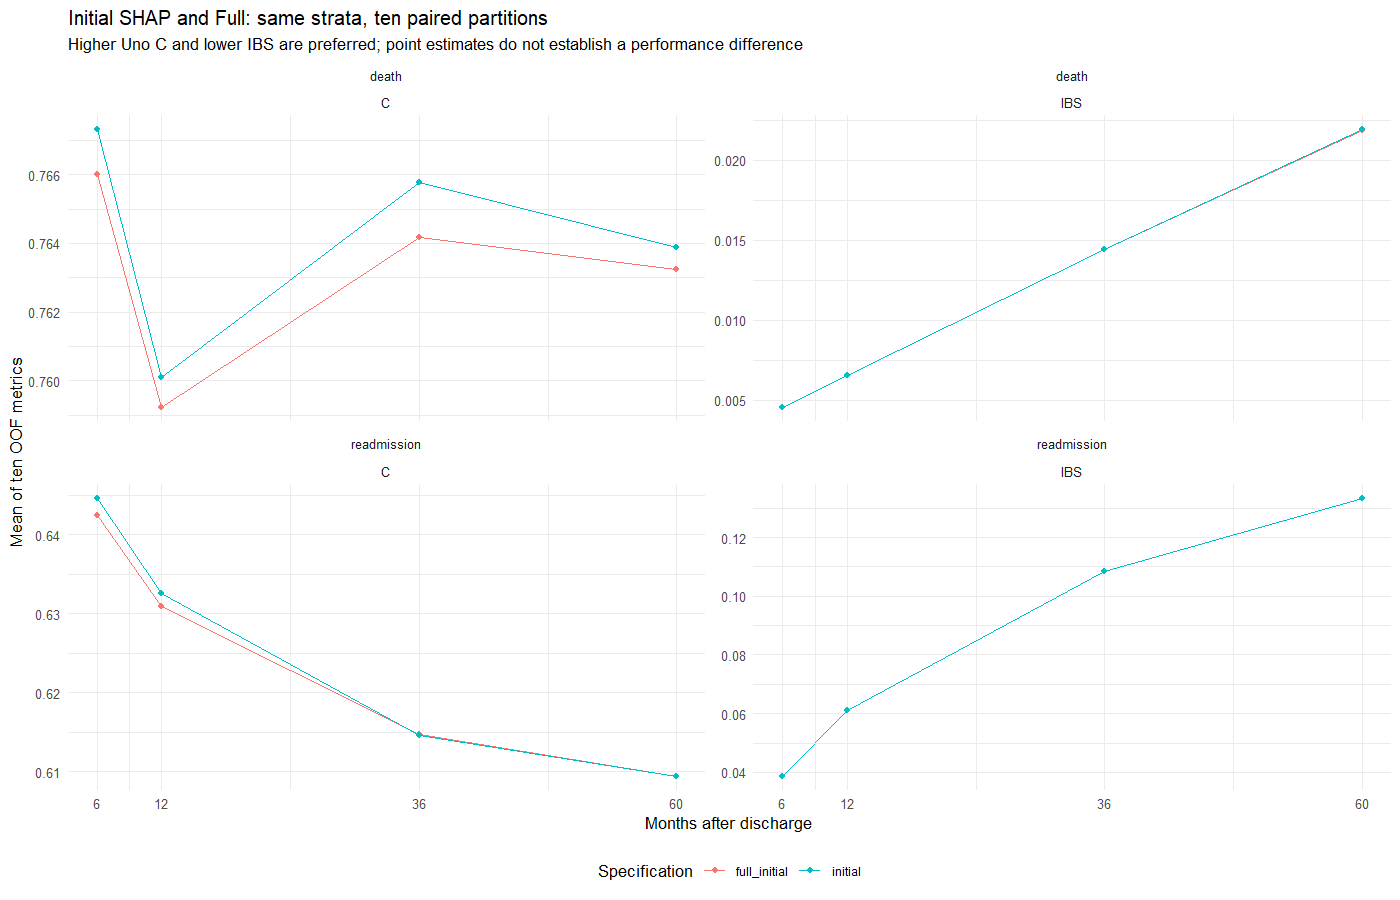

Elapsed: 0.006 minutes


In [43]:
#| label: shap-performance-comparison-figures
#| message: true
.t0 <- proc.time()
# Display compact decision figures in HTML only; do not export exploratory plots.
if (nrow(performance_table)) {
  plots <- performance_table
  long <- do.call(rbind, lapply(c("C", "IBS"), function(m) data.frame(plots[, c("Outcome", "Stage", "Horizon")], Metric = m, Value = plots[[m]])))
  p <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Stage, group = Stage)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(Outcome ~ Metric, scales = "free_y", ncol = 2) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "Initial SHAP and Full: same strata, ten paired partitions", subtitle = "Higher Uno C and lower IBS are preferred; point estimates do not establish a performance difference", x = "Months after discharge", y = "Mean of ten OOF metrics", color = "Specification") + ggplot2::theme_minimal() + ggplot2::theme(legend.position = "bottom", legend.text = ggplot2::element_text(size = 8)) + ggplot2::guides(color = ggplot2::guide_legend(ncol = 2))
  show_diagnostic_png(function() print(p), width = 1400, height = 900)
}
if (nrow(calibration_summary)) {
  long <- do.call(rbind, lapply(c("ICI", "ECE", "EO"), function(m) data.frame(calibration_summary[, c("Outcome", "Pair", "Horizon")], Metric = m, Value = calibration_summary[[m]])))
  p <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Pair, group = Pair)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(Outcome ~ Metric, scales = "free_y", ncol = 3) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "Repeated calibration of every sequential candidate", subtitle = "Lower ICI/ECE and E/O closer to one are preferred; pairs identify both models for readmission", x = "Months after discharge", y = "Mean across 20 repetitions", color = "Candidate or pair") + ggplot2::theme_minimal() + ggplot2::theme(legend.position = "bottom", legend.text = ggplot2::element_text(size = 8)) + ggplot2::guides(color = ggplot2::guide_legend(ncol = 2))
  show_diagnostic_png(function() print(p), width = 1500, height = 1000)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

## Completed VIF-resolved comparison and calibration
The investigator authorized this comparison on 2026-10-06 and subsequently accepted continuation after reviewing its small differences, with ICI prioritised within the joint calibration review.

The completed checkpoint uses reduced Full formulas for both outcomes, reduced SHAP readmission, and unchanged initial SHAP mortality. Only minimum therapeutic-process achievement was removed where it exceeded the study VIF threshold. All four have treatment setting as their sole stratification factor. This separates predictor selection and VIF removal from subsequent NPH adjustments. No additional stratum, interaction or functional form was selected at this checkpoint.

C/IBS used ten paired repetitions, five folds and five completed-development imputations. The initial comparison remains above. The first Full-reduced partition and the SHAP mortality results were reused, with 700 new C/IBS fits. Calibration used twenty repetitions, five folds and five imputations, with Full-reduced results reused from 06 and 1500 new SHAP calibration fits. The complete AJ and KM engines ran as separate single-thread jobs. AJ bins were shared across its twenty repetitions, preserving the original method. These are counts from the completed run, not a request to repeat it.

These intermediate estimates do not replace the final Table 2 specifications or their confidence intervals. Repeated-partition variation is not a bootstrap interval. Complete-development preprocessing still precedes internal CV. The following outputs are restored from cache during preparation replay.


In [44]:
#| label: shap-performance-vif-calibration-functions
#| message: true
.t0 <- proc.time()
# Preserve the completed initial comparison and add the explicitly approved VIF-resolved checkpoint.
vif_checkpoint_enabled <- shap_settings$performance_step %in% c("vif_resolved", "readmission_discharge", "mortality_physical")
vif_run <- vif_checkpoint_enabled && (performance_settings$mode %in% c("vif_comparison", "readmission_stratum", "mortality_stratum") || (shap_settings$performance_step %in% c("readmission_discharge", "mortality_physical") && performance_settings$mode == "prepare"))
vif_complete <- FALSE
vif_metrics <- vif_repetitions <- vif_coverage <- vif_steps <- vif_calibration <- vif_calibration_delta <- vif_completeness <- data.frame()
vif_calibration_values <- list()
vif_candidates <- data.frame(Outcome = c("readmission", "readmission", "death", "death"), Stage = c("full_reduced", "reduced", "full_reduced", "initial"), Model = rep(c("Full", "SHAP"), 2L))
for (outcome in c("readmission", "death")) performance_formulas[[outcome]]$full_reduced <- cox_formulas[[outcome]]$reduced
for (j in seq_len(nrow(vif_candidates))) stopifnot(identical(formula_strata(performance_formulas[[vif_candidates$Outcome[j]]][[vif_candidates$Stage[j]]]), "plan_type_strata"))
stopifnot(!any(vif_candidates$Stage == rejected_predictive_candidate), setequal(setdiff(formula_terms(cox_formulas$readmission$full), formula_terms(cox_formulas$readmission$reduced)), removed_collinear), setequal(setdiff(formula_terms(cox_formulas$death$full), formula_terms(cox_formulas$death$reduced)), removed_collinear))
# Reuse the identical first-partition Full-reduced metrics from 06; all other tasks use the unchanged C/IBS engine.
vif_performance_task <- function(task) {
  if (!(task$Stage == "full_reduced" && task$Repetition == 1L)) return(performance_task(task))
  found <- list.files(object_dir, pattern = paste0("^perf06_metrics_", task$Outcome, "_reduced_[0-9-]+_", shap_settings$reference_performance_signature, "\\.rds$"), full.names = TRUE)
  stopifnot(length(found) == 1L, identical(performance_folds[[1L]], historical_folds))
  saved <- readRDS(found[[1L]])
  stopifnot(identical(saved$signature, shap_settings$reference_performance_signature))
  result <- saved$value
  reference <- reference_metrics[reference_metrics$Outcome == task$Outcome & reference_metrics$Stage == "reduced", ]
  stopifnot(identical(as.numeric(result$table$Horizon), as.numeric(reference$Horizon)), max(abs(result$table$C - reference$C), abs(result$table$IBS - reference$IBS)) < 1e-12)
  result$table$Stage <- task$Stage
  result$table$Repetition <- task$Repetition
  coverage <- data.frame(Outcome = task$Outcome, Stage = task$Stage, Repetition = task$Repetition, Expected = nrow(py_corrected_datasets[[1L]]), Predicted = nrow(py_corrected_datasets[[1L]]), Omitted = 0L)
  list(table = result$table, coverage = coverage, new_fits = 0L, written = character())
}
# Keep each complete calibration engine intact, including the AJ cuts shared across all repetitions.
calibration_rng <- RNGkind()
calibration_checkpoint_task <- function(task) {
  before_fits <- performance_new_fits
  before_written <- written
  previous_rng <- RNGkind()
  on.exit(do.call(RNGkind, as.list(previous_rng)), add = TRUE)
  do.call(RNGkind, as.list(calibration_rng))
  if (task$Kind == "readmission") {
    pair <- calibration_pairs[calibration_pairs$Pair == task$Pair, , drop = FALSE]
    stopifnot(nrow(pair) == 1L, pair$Death != "physical_discharge_strata")
    key <- paste("cal_aj", performance_formula_key("readmission", pair$Readmission), performance_formula_key("death", pair$Death), sep = "_")
    value <- performance_cache(key, function() calibrate_cscox_aj_grouped_corr(formula_readmit = candidate_formulas$readmission[[pair$Readmission]], formula_death = candidate_formulas$death[[pair$Death]], data = py_corrected_datasets, times = performance_horizons, n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = performance_settings$calibration_repeats, compute_ici = TRUE, ici_times = performance_horizons, g = 10L, min_bin_n = 20L, ici_span = 0.75, tie_action = "death_first", seed = performance_settings$seed, make_plots = FALSE, parallel_cv = FALSE, parallel_calibration = FALSE, verbose = FALSE, cache_prefix = key))
  } else {
    stopifnot(task$Kind == "death", task$Pair %in% c("initial", "physical_stratum", "interactions"))
    key <- paste0("cal_km_", performance_formula_key("death", task$Pair))
    value <- performance_cache(key, function() calibrate_death_km_grouped(formula = candidate_formulas$death[[task$Pair]], data = py_corrected_datasets, times = performance_horizons, validation = "cv", folds = 5L, n_repeats = performance_settings$calibration_repeats, g = 10L, min_bin_n = 20L, loess_span = 0.75, seed = performance_settings$seed, parallel_cv = FALSE, verbose = FALSE, cache_prefix = key))
  }
  list(outcome = task$Kind, pair = task$Pair, prefix = key, value = value, new_fits = performance_new_fits - before_fits, written = setdiff(written, before_written))
}
# Check both reused Full-reduced first partitions before launching any new predictive task.
vif_cache_controls <- lapply(c("readmission", "death"), function(outcome) vif_performance_task(list(Outcome = outcome, Stage = "full_reduced", Repetition = 1L)))
stopifnot(all(vapply(vif_cache_controls, function(x) x$new_fits == 0L && length(x$written) == 0L, logical(1L))))
# Verify the actual first-imputation VIF and reuse the already completed Full-reduced calibration.
vif_diagnostic_rows <- list()
for (outcome in c("readmission", "death")) {
  found <- list.files(object_dir, pattern = paste0("^cox_", outcome, "_reduced_imp1_[0-9-]+_", shap_settings$reference_cox_signature, "\\.rds$"), full.names = TRUE)
  stopifnot(length(found) == 1L)
  saved <- readRDS(found[[1L]])
  stopifnot(identical(saved$signature, shap_settings$reference_cox_signature))
  stage <- if (outcome == "readmission") "reduced" else "initial"
  shap_vif <- sequential_diagnostics[[paste(outcome, stage, sep = "_")]]$vif$VIF
  stopifnot(length(shap_vif) > 0L)
  vif_diagnostic_rows[[outcome]] <- data.frame(Outcome = outcome, Model = c("Full", "SHAP"), Stage = c("full_reduced", stage), Maximum_VIF = c(max(rms::vif(saved$value)), max(shap_vif)))
}
vif_diagnostics <- do.call(rbind, vif_diagnostic_rows)
stopifnot(all(is.finite(vif_diagnostics$Maximum_VIF)), all(vif_diagnostics$Maximum_VIF < 10))
show_table(vif_diagnostics, "Approved VIF-resolved specifications: first-imputation diagnostics, identical treatment-setting strata")
found <- list.files(object_dir, pattern = paste0("^perf06_calibration_reduced_[0-9-]+_", shap_settings$reference_performance_signature, "\\.rds$"), full.names = TRUE)
stopifnot(length(found) == 1L)
saved <- readRDS(found[[1L]])
stopifnot(identical(saved$signature, shap_settings$reference_performance_signature))
vif_full_calibration <- saved$value
vif_resource_estimate <- data.frame(Component = c("VIF-resolved C/IBS: new fits only", "SHAP readmission AJ", "SHAP all-cause mortality KM"), New_Cox_fits = c(700L, 1000L, 500L), Maximum_workers = c(performance_settings$workers, 1L, 1L), Serial_minutes_from_pilot = c(28 / 2 * pilot_times[["pilot-full-c-ibs"]], 20 * pilot_times[["pilot-calibration-readmission"]], 20 * pilot_times[["pilot-calibration-death"]]) / 60)
show_table(vif_resource_estimate, "C/IBS uses at most eight workers; the two complete calibration engines run concurrently with one thread each")
cat("RAM available (GiB):", ps::ps_system_memory()$avail / 1024^3, "| Reserve (GiB):", shap_settings$reserve_memory_gib, "| Calibration RNG:", paste(calibration_rng, collapse = ", "), "\n")
cat("Full calibration and first-partition metrics are reused. SHAP mortality C/IBS is unchanged and reused. No third stratum, imputation, tuning, SHAP or bootstrap is run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Outcome,Model,Stage,Maximum_VIF
readmission,Full,full_reduced,9.3511
readmission,SHAP,reduced,5.7015
death,Full,full_reduced,9.0968
death,SHAP,initial,7.5493


Component,New_Cox_fits,Maximum_workers,Serial_minutes_from_pilot
VIF-resolved C/IBS: new fits only,700,8,36.0833
SHAP readmission AJ,1000,1,58.2056
SHAP all-cause mortality KM,500,1,29.2251


RAM available (GiB): 60.19324 | Reserve (GiB): 20 | Calibration RNG: Mersenne-Twister, Inversion, Rejection 


Full calibration and first-partition metrics are reused. SHAP mortality C/IBS is unchanged and reused. No third stratum, imputation, tuning, SHAP or bootstrap is run.


Elapsed: 0.017 minutes


In [45]:
#| label: shap-performance-vif-c-ibs
#| message: true
.t0 <- proc.time()
# Compare the approved formulas on the same ten partitions, retaining every participant.
if (vif_run) {
  tasks <- unlist(lapply(seq_len(nrow(vif_candidates)), function(j) lapply(seq_len(performance_settings$c_ibs_repeats), function(r) list(Outcome = vif_candidates$Outcome[j], Stage = vif_candidates$Stage[j], Repetition = r))), recursive = FALSE)
  stopifnot(max(metric_control$Maximum_absolute_difference) < 1e-8)
  results <- performance_parallel(tasks, worker = vif_performance_task)
  for (result in results) {
    record_performance_fits(result$new_fits)
    written <- c(written, result$written)
  }
  vif_repetitions <- do.call(rbind, lapply(results, `[[`, "table"))
  vif_coverage <- do.call(rbind, lapply(results, `[[`, "coverage"))
  stopifnot(nrow(vif_repetitions) == 160L, !anyDuplicated(vif_repetitions[, c("Outcome", "Stage", "Repetition", "Horizon")]), all(is.finite(as.matrix(vif_repetitions[, c("C", "IBS")]))), nrow(vif_coverage) == 40L, all(vif_coverage$Expected == vif_coverage$Predicted), all(vif_coverage$Omitted == 0L))
  means <- stats::aggregate(cbind(C, IBS) ~ Outcome + Stage + Horizon, vif_repetitions, mean)
  deviations <- stats::aggregate(cbind(C, IBS) ~ Outcome + Stage + Horizon, vif_repetitions, stats::sd)
  names(deviations)[4:5] <- c("C_SD_between_partitions", "IBS_SD_between_partitions")
  vif_metrics <- merge(merge(means, deviations, by = c("Outcome", "Stage", "Horizon")), vif_candidates, by = c("Outcome", "Stage"))
  vif_metrics$Repetitions <- performance_settings$c_ibs_repeats
  paired <- merge(vif_repetitions, vif_candidates, by = c("Outcome", "Stage"))
  paired <- merge(paired[paired$Model == "SHAP", ], paired[paired$Model == "Full", ], by = c("Outcome", "Repetition", "Horizon"), suffixes = c("_SHAP", "_Full"))
  stopifnot(nrow(paired) == 80L)
  paired$Delta_C <- paired$C_SHAP - paired$C_Full
  paired$Delta_IBS <- paired$IBS_SHAP - paired$IBS_Full
  vif_steps <- stats::aggregate(cbind(Delta_C, Delta_IBS) ~ Outcome + Horizon, paired, mean)
  vif_steps$Descriptive_flag <- ifelse(abs(vif_steps$Delta_C) >= 0.01 | abs(vif_steps$Delta_IBS) >= 0.001, "Review: reaches a study magnitude threshold", "Below the study magnitude thresholds; not proof of equivalence")
  show_table(vif_metrics, "VIF-resolved Full versus SHAP: ten-partition means; SD is not a bootstrap interval")
  show_table(vif_steps, "Paired SHAP minus Full differences with the same VIF-resolved formulas used for calibration")
  show_table(vif_coverage, "VIF-resolved C/IBS: complete patient coverage, zero omissions required")
} else cat("Prepared VIF-resolved C/IBS checkpoint; no new predictive fits in prepare mode.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Outcome,Stage,Horizon,C,IBS,C_SD_between_partitions,IBS_SD_between_partitions,Model,Repetitions
death,full_reduced,12,0.7593,0.0065,5e-04,0,Full,10
death,full_reduced,36,0.7643,0.0144,3e-04,0,Full,10
death,full_reduced,6,0.7661,0.0045,8e-04,0,Full,10
death,full_reduced,60,0.7633,0.0219,3e-04,0,Full,10
death,initial,12,0.7601,0.0065,3e-04,0,SHAP,10
death,initial,36,0.7658,0.0144,2e-04,0,SHAP,10
death,initial,6,0.7673,0.0046,5e-04,0,SHAP,10
death,initial,60,0.7639,0.0219,2e-04,0,SHAP,10
readmission,full_reduced,12,0.6309,0.0610,1e-04,0,Full,10
readmission,full_reduced,36,0.6147,0.1085,2e-04,0,Full,10


Outcome,Horizon,Delta_C,Delta_IBS,Descriptive_flag
death,6,0.0012,0,Below the study magnitude thresholds; not proof of equivalence
readmission,6,0.0022,0,Below the study magnitude thresholds; not proof of equivalence
death,12,0.0008,0,Below the study magnitude thresholds; not proof of equivalence
readmission,12,0.0017,0,Below the study magnitude thresholds; not proof of equivalence
death,36,0.0015,0,Below the study magnitude thresholds; not proof of equivalence
readmission,36,-0.0001,0,Below the study magnitude thresholds; not proof of equivalence
death,60,0.0005,0,Below the study magnitude thresholds; not proof of equivalence
readmission,60,0.0000,0,Below the study magnitude thresholds; not proof of equivalence


Outcome,Stage,Repetition,Expected,Predicted,Omitted
readmission,full_reduced,1,70521,70521,0
readmission,full_reduced,2,70521,70521,0
readmission,full_reduced,3,70521,70521,0
readmission,full_reduced,4,70521,70521,0
readmission,full_reduced,5,70521,70521,0
readmission,full_reduced,6,70521,70521,0
readmission,full_reduced,7,70521,70521,0
readmission,full_reduced,8,70521,70521,0
readmission,full_reduced,9,70521,70521,0
readmission,full_reduced,10,70521,70521,0


Parallel workers: 8 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.399 minutes


In [46]:
#| label: shap-performance-vif-calibration
#| message: true
.t0 <- proc.time()
# Run the two complete historical engines concurrently and retain task caches for resumption.
if (vif_run) {
  stopifnot(nrow(vif_metrics) == 16L, max(calibration_historical_control$Maximum_absolute_difference) < 1e-8)
  calibration_tasks <- list(list(Kind = "readmission", Pair = "readmission_reduced"), list(Kind = "death", Pair = "initial"))
  results <- performance_parallel(calibration_tasks, worker = calibration_checkpoint_task)
  for (result in results) {
    record_performance_fits(result$new_fits)
    written <- c(written, result$written)
    vif_calibration_values[[result$outcome]] <- result
  }
  for (outcome in names(vif_calibration_values)) show_table(vif_calibration_values[[outcome]]$value$pooled_summary, paste("VIF-resolved SHAP calibration:", outcome, "20 x 5 x 5"))
} else cat("Prepared VIF-resolved calibration: two complete engines; no new calibration fits in prepare mode.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


time_months,ici_mean,ici_sd,ici_min,ici_p025,ici_p975,ici_max,e50_mean,e50_sd,e50_min,e50_p025,e50_p975,e50_max,e90_mean,e90_sd,e90_min,e90_p025,e90_p975,e90_max,emax_mean,emax_sd,emax_min,emax_p025,emax_p975,emax_max,ece_mean,ece_sd,ece_min,ece_p025,ece_p975,ece_max,eo_mean,eo_sd,eo_min,eo_p025,eo_p975,eo_max,mean_pred,mean_pred_sd,mean_pred_min,mean_pred_p025,mean_pred_p975,mean_pred_max,observed,observed_sd,observed_min,observed_p025,observed_p975,observed_max,n_runs,n_imp
6,0.0064,2e-04,0.0060,0.0060,0.0066,0.0066,0.0014,3e-04,0.0010,0.0010,0.0020,0.0020,0.0206,4e-04,0.0198,0.0198,0.0211,0.0211,0.3633,0.0113,0.3457,0.3457,0.3893,0.3893,0.0018,3e-04,0.0013,0.0013,0.0024,0.0024,0.9919,1e-04,0.9918,0.9918,0.9921,0.9921,0.0720,0,0.0720,0.0720,0.0720,0.0720,0.0726,0,0.0726,0.0726,0.0726,0.0726,20,5
12,0.0075,2e-04,0.0071,0.0071,0.0078,0.0078,0.0014,2e-04,0.0011,0.0011,0.0019,0.0019,0.0229,3e-04,0.0222,0.0222,0.0233,0.0233,0.4608,0.0131,0.4387,0.4387,0.4892,0.4892,0.0026,4e-04,0.0016,0.0016,0.0031,0.0031,0.9919,1e-04,0.9917,0.9917,0.9921,0.9921,0.1136,0,0.1136,0.1136,0.1136,0.1136,0.1146,0,0.1146,0.1146,0.1146,0.1146,20,5
36,0.0091,1e-04,0.0088,0.0088,0.0094,0.0094,0.0034,4e-04,0.0027,0.0027,0.0042,0.0042,0.0218,5e-04,0.0209,0.0209,0.0228,0.0228,0.5558,0.0104,0.5382,0.5382,0.5773,0.5773,0.0046,5e-04,0.0038,0.0038,0.0053,0.0053,0.9891,1e-04,0.9889,0.9889,0.9892,0.9892,0.1997,0,0.1996,0.1996,0.1997,0.1997,0.2019,0,0.2019,0.2019,0.2019,0.2019,20,5
60,0.0096,1e-04,0.0095,0.0095,0.0098,0.0098,0.0041,4e-04,0.0036,0.0036,0.0051,0.0051,0.0213,4e-04,0.0203,0.0203,0.0224,0.0224,0.5698,0.0091,0.5555,0.5555,0.5895,0.5895,0.0065,7e-04,0.0053,0.0053,0.0075,0.0075,0.9848,1e-04,0.9846,0.9846,0.9849,0.9849,0.2425,0,0.2425,0.2425,0.2425,0.2425,0.2462,0,0.2462,0.2462,0.2462,0.2462,20,5


time_months,ici_mean,ici_sd,ici_median,ece_mean,ece_sd,eo_mean,eo_sd,mean_pred_mean,observed_mean,n_bins_mean,n_reps
6,0.0015,1e-04,0.0015,0.0005,1e-04,1.0069,6e-04,0.0069,0.0069,8,20
12,0.0024,1e-04,0.0024,0.0010,1e-04,1.0085,5e-04,0.0108,0.0107,8,20
36,0.0063,1e-04,0.0063,0.0025,2e-04,1.0098,4e-04,0.0288,0.0286,8,20
60,0.0087,1e-04,0.0087,0.0029,2e-04,1.0166,3e-04,0.0460,0.0452,8,20


Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.099 minutes


Outcome,Model,Horizon,C_initial,IBS_initial,C_VIF_resolved,IBS_VIF_resolved,Delta_C,Delta_IBS,Classification
death,Full,12,0.7592,0.0065,0.7593,0.0065,1e-04,0,Same 3-decimal display; intermediate comparison only
death,Full,36,0.7642,0.0144,0.7643,0.0144,1e-04,0,Same 3-decimal display; intermediate comparison only
death,Full,6,0.7660,0.0045,0.7661,0.0045,1e-04,0,Same 3-decimal display; intermediate comparison only
death,Full,60,0.7633,0.0219,0.7633,0.0219,1e-04,0,Same 3-decimal display; intermediate comparison only
death,SHAP,12,0.7601,0.0065,0.7601,0.0065,0e+00,0,Same 3-decimal display; intermediate comparison only
death,SHAP,36,0.7658,0.0144,0.7658,0.0144,0e+00,0,Same 3-decimal display; intermediate comparison only
death,SHAP,6,0.7673,0.0046,0.7673,0.0046,0e+00,0,Same 3-decimal display; intermediate comparison only
death,SHAP,60,0.7639,0.0219,0.7639,0.0219,0e+00,0,Same 3-decimal display; intermediate comparison only
readmission,Full,12,0.6309,0.0610,0.6309,0.0610,1e-04,0,Same 3-decimal display; intermediate comparison only
readmission,Full,36,0.6147,0.1085,0.6147,0.1085,1e-04,0,Same 3-decimal display; intermediate comparison only


Outcome,Repetitions,Prediction_tasks,Participants_per_repetition,Omitted,Full_SHAP_fold_indices_identical,Minimum_predicted_risk,Maximum_predicted_risk,Zero_risk_entries_across_all_repetitions_and_horizons,Maximum_excluded_from_calibration_bins
readmission,20,100,70521,0,TRUE,0.0186,0.8178,0,0
death,20,100,70521,0,TRUE,0.0002,0.7305,0,NA


Outcome,Model,Horizon,ICI,ECE,EO,Partner
readmission,Full,6,0.0060,0.0021,0.9913,Full reduced death
readmission,Full,12,0.0075,0.0025,0.9912,Full reduced death
readmission,Full,36,0.0095,0.0038,0.9883,Full reduced death
readmission,Full,60,0.0103,0.0051,0.9840,Full reduced death
readmission,SHAP,6,0.0064,0.0018,0.9919,SHAP initial death
readmission,SHAP,12,0.0075,0.0026,0.9919,SHAP initial death
readmission,SHAP,36,0.0091,0.0046,0.9891,SHAP initial death
readmission,SHAP,60,0.0096,0.0065,0.9848,SHAP initial death
death,Full,6,0.0016,0.0006,1.0078,All-cause KM: no competing-risk partner
death,Full,12,0.0027,0.0011,1.0098,All-cause KM: no competing-risk partner


Outcome,Horizon,Model_SHAP,ICI_SHAP,ECE_SHAP,EO_SHAP,Partner_SHAP,Model_Full,ICI_Full,ECE_Full,EO_Full,Partner_Full,Delta_ICI,Delta_ECE,Delta_EO
death,12,SHAP,0.0024,0.0010,1.0085,All-cause KM: no competing-risk partner,Full,0.0027,0.0011,1.0098,All-cause KM: no competing-risk partner,-2e-04,-0.0001,-0.0014
death,36,SHAP,0.0063,0.0025,1.0098,All-cause KM: no competing-risk partner,Full,0.0067,0.0024,1.0117,All-cause KM: no competing-risk partner,-4e-04,0.0001,-0.0019
death,6,SHAP,0.0015,0.0005,1.0069,All-cause KM: no competing-risk partner,Full,0.0016,0.0006,1.0078,All-cause KM: no competing-risk partner,-2e-04,-0.0002,-0.0009
death,60,SHAP,0.0087,0.0029,1.0166,All-cause KM: no competing-risk partner,Full,0.0089,0.0026,1.0191,All-cause KM: no competing-risk partner,-2e-04,0.0003,-0.0025
readmission,12,SHAP,0.0075,0.0026,0.9919,SHAP initial death,Full,0.0075,0.0025,0.9912,Full reduced death,0e+00,0.0001,0.0007
readmission,36,SHAP,0.0091,0.0046,0.9891,SHAP initial death,Full,0.0095,0.0038,0.9883,Full reduced death,-3e-04,0.0008,0.0008
readmission,6,SHAP,0.0064,0.0018,0.9919,SHAP initial death,Full,0.0060,0.0021,0.9913,Full reduced death,4e-04,-0.0003,0.0006
readmission,60,SHAP,0.0096,0.0065,0.9848,SHAP initial death,Full,0.0103,0.0051,0.9840,Full reduced death,-7e-04,0.0013,0.0008


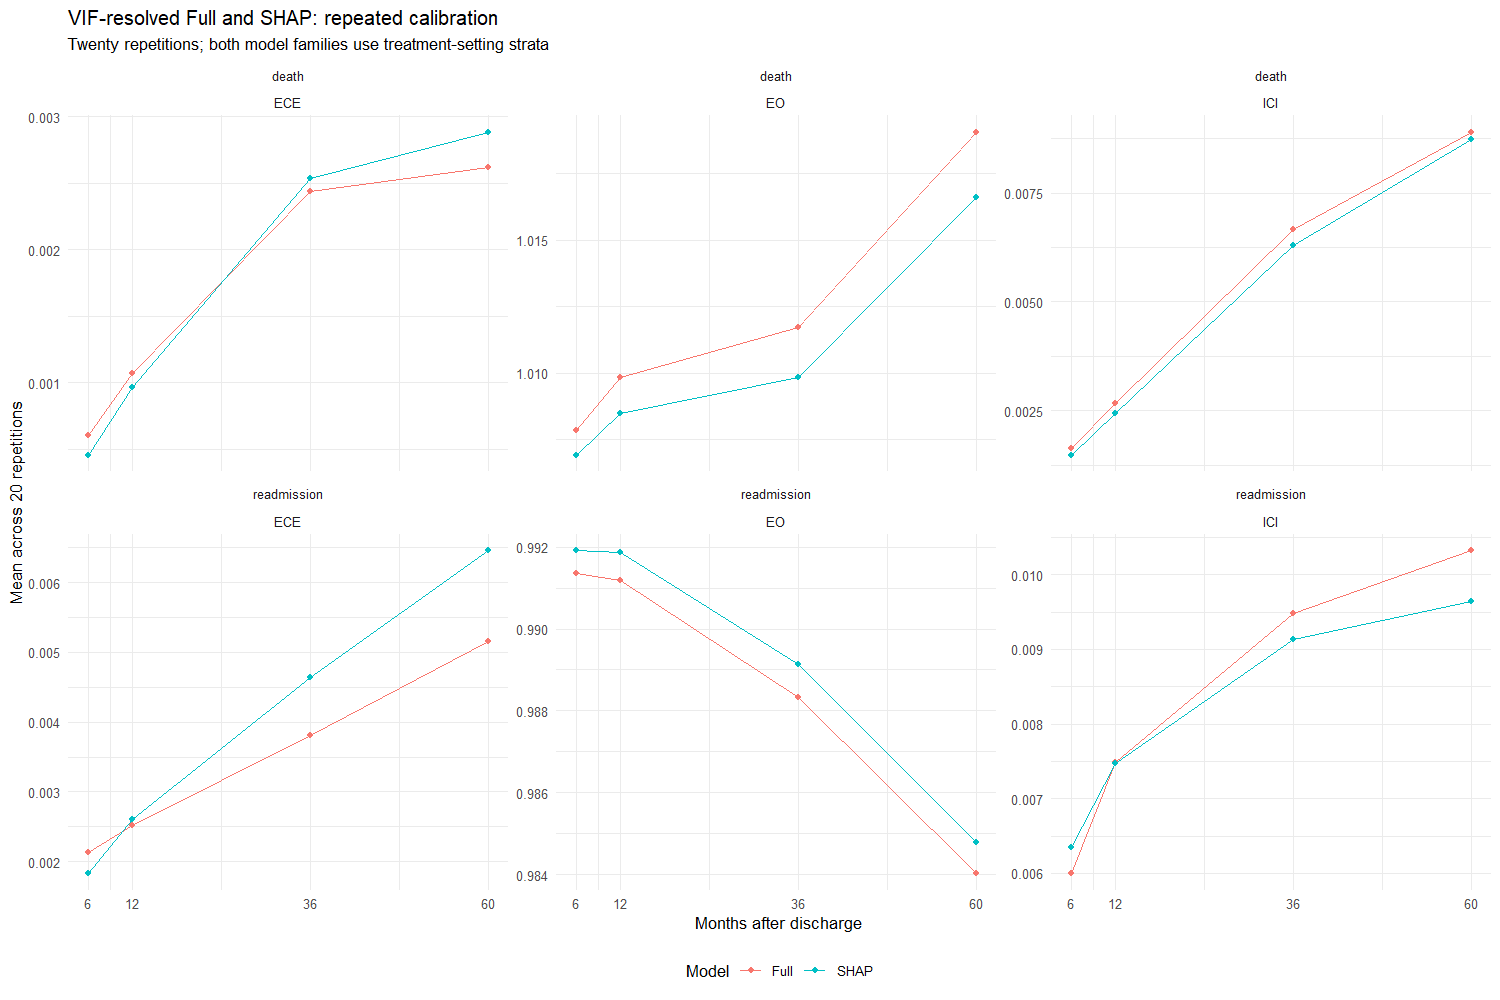

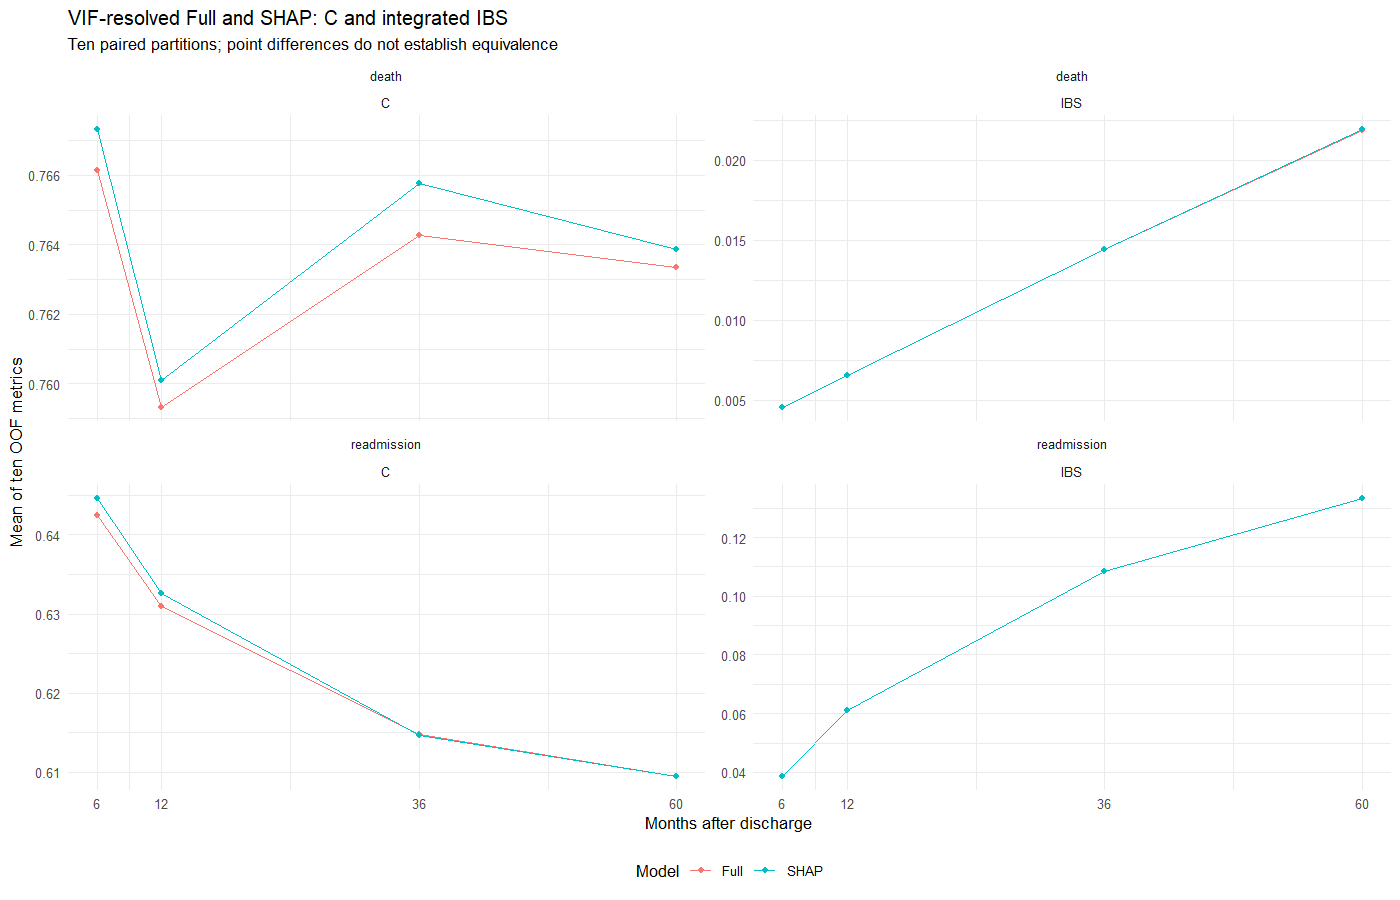

The investigator accepted this VIF checkpoint; all preceding estimates were reused from cache.


Elapsed: 0.572 minutes


In [47]:
#| label: shap-performance-vif-checkpoint
#| message: true
.t0 <- proc.time()
# Check every prediction cache against the paired Full reference before interpreting pooled calibration.
vif_initial_changes <- data.frame()
if (vif_run) {
  n_participants <- nrow(py_corrected_datasets[[1L]])
  calibration_rows <- completeness_rows <- list()
  for (outcome in c("readmission", "death")) {
    item <- vif_calibration_values[[outcome]]
    reference <- vif_full_calibration[[outcome]]
    stopifnot(!is.null(item), !is.null(reference))
    for (model in c("Full", "SHAP")) {
      value <- if (model == "Full") reference else item$value
      metrics <- if (outcome == "readmission") value$by_repetition else value$rep_results
      stopifnot(nrow(metrics) == 80L, identical(as.numeric(metrics$time_months), rep(performance_horizons, 20L)), all(is.finite(as.matrix(metrics[, c("ici", "ece", "eo_ratio")]))))
      if (outcome == "readmission") stopifnot(!anyDuplicated(metrics[, c("repetition", "time_months")]), all(metrics$n_input == n_participants), all(metrics$n_analysis == n_participants), all(metrics$n_dropped == 0L), all(metrics$n_imputations == 5L), all(metrics$n_used_calibration + metrics$n_excluded_calibration == n_participants))
      pooled <- value$pooled_summary
      recalculated <- stats::aggregate(cbind(ici, ece, eo_ratio) ~ time_months, metrics, mean)
      recalculated <- recalculated[match(pooled$time_months, recalculated$time_months), ]
      stopifnot(max(abs(as.matrix(recalculated[, c("ici", "ece", "eo_ratio")]) - as.matrix(pooled[, c("ici_mean", "ece_mean", "eo_mean")]))) < 1e-12)
      calibration_rows[[paste(outcome, model)]] <- data.frame(Outcome = outcome, Model = model, Horizon = pooled$time_months, ICI = pooled$ici_mean, ECE = pooled$ece_mean, EO = pooled$eo_mean, Partner = if (outcome == "death") "All-cause KM: no competing-risk partner" else if (model == "Full") "Full reduced death" else "SHAP initial death")
    }
    minimum_risk <- Inf
    maximum_risk <- -Inf
    zero_predictions <- 0L
    for (repetition in seq_len(20L)) {
      indices <- integer()
      for (fold in seq_len(5L)) {
        suffix <- sprintf("_r%02d_f%02d", repetition, fold)
        current_path <- list.files(object_dir, pattern = paste0("^perf07_", item$prefix, suffix, "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE)
        previous_path <- list.files(object_dir, pattern = paste0("^perf06_cal_", outcome, "_reduced", suffix, "_[0-9-]+_", shap_settings$reference_performance_signature, "\\.rds$"), full.names = TRUE)
        stopifnot(length(current_path) == 1L, length(previous_path) == 1L)
        current <- readRDS(current_path[[1L]])
        previous <- readRDS(previous_path[[1L]])
        stopifnot(identical(current$signature, performance_signature), identical(previous$signature, shap_settings$reference_performance_signature), current$value$r == repetition, previous$value$r == repetition)
        rows <- if (outcome == "readmission") current$value$te_idx else current$value$test_idx
        reference_rows <- if (outcome == "readmission") previous$value$te_idx else previous$value$test_idx
        risk <- if (outcome == "readmission") current$value$pred_fold_avg else current$value$risk_mat
        stopifnot(identical(rows, reference_rows), identical(dim(risk), c(length(rows), length(performance_horizons))), all(is.finite(risk)), all(risk >= 0 & risk <= 1), all(rows >= 1L & rows <= n_participants))
        minimum_risk <- min(minimum_risk, risk)
        maximum_risk <- max(maximum_risk, risk)
        zero_predictions <- zero_predictions + sum(risk == 0)
        indices <- c(indices, rows)
      }
      stopifnot(length(indices) == n_participants)
      assert_prediction_coverage(tabulate(indices, nbins = n_participants))
    }
    bin_excluded <- if (outcome == "readmission") max(item$value$by_repetition$n_excluded_calibration) else NA_integer_
    completeness_rows[[outcome]] <- data.frame(Outcome = outcome, Repetitions = 20L, Prediction_tasks = 100L, Participants_per_repetition = n_participants, Omitted = 0L, Full_SHAP_fold_indices_identical = TRUE, Minimum_predicted_risk = minimum_risk, Maximum_predicted_risk = maximum_risk, Zero_risk_entries_across_all_repetitions_and_horizons = zero_predictions, Maximum_excluded_from_calibration_bins = bin_excluded)
  }
  vif_calibration <- do.call(rbind, calibration_rows)
  vif_completeness <- do.call(rbind, completeness_rows)
  vif_calibration_delta <- merge(vif_calibration[vif_calibration$Model == "SHAP", ], vif_calibration[vif_calibration$Model == "Full", ], by = c("Outcome", "Horizon"), suffixes = c("_SHAP", "_Full"))
  for (metric in c("ICI", "ECE", "EO")) vif_calibration_delta[[paste0("Delta_", metric)]] <- vif_calibration_delta[[paste0(metric, "_SHAP")]] - vif_calibration_delta[[paste0(metric, "_Full")]]
  stopifnot(nrow(vif_calibration) == 16L, nrow(vif_calibration_delta) == 8L)
  initial <- performance_table
  initial$Model <- ifelse(initial$Stage == "full_initial", "Full", "SHAP")
  vif_initial_changes <- merge(initial[, c("Outcome", "Model", "Horizon", "C", "IBS")], vif_metrics[, c("Outcome", "Model", "Horizon", "C", "IBS")], by = c("Outcome", "Model", "Horizon"), suffixes = c("_initial", "_VIF_resolved"))
  stopifnot(nrow(vif_initial_changes) == 16L)
  vif_initial_changes$Delta_C <- vif_initial_changes$C_VIF_resolved - vif_initial_changes$C_initial
  vif_initial_changes$Delta_IBS <- vif_initial_changes$IBS_VIF_resolved - vif_initial_changes$IBS_initial
  vif_initial_changes$Classification <- ifelse(round(vif_initial_changes$C_VIF_resolved, 3) == round(vif_initial_changes$C_initial, 3) & round(vif_initial_changes$IBS_VIF_resolved, 3) == round(vif_initial_changes$IBS_initial, 3), "Same 3-decimal display; intermediate comparison only", "Changed 3-decimal display; investigator review of this intermediate comparison")
  show_table(vif_initial_changes, "Initial versus VIF-resolved C/IBS; these setting-only specifications are not the final published Table 2 specifications")
  show_table(vif_completeness, "Every SHAP calibration task checked against the corresponding Full partition; zero omitted participants")
  show_table(vif_calibration, "Full versus SHAP calibration after resolving VIF; exact death partners remain explicit")
  show_table(vif_calibration_delta, "SHAP minus Full calibration: smaller ICI/ECE and E/O nearer one are preferred")
  # Show the decision evidence without creating separate intermediate figure files.
  long <- do.call(rbind, lapply(c("ICI", "ECE", "EO"), function(metric) data.frame(vif_calibration[, c("Outcome", "Model", "Horizon")], Metric = metric, Value = vif_calibration[[metric]])))
  p <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Model, group = Model)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(Outcome ~ Metric, scales = "free_y", ncol = 3) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "VIF-resolved Full and SHAP: repeated calibration", subtitle = "Twenty repetitions; both model families use treatment-setting strata", x = "Months after discharge", y = "Mean across 20 repetitions", color = "Model") + ggplot2::theme_minimal() + ggplot2::theme(legend.position = "bottom")
  show_diagnostic_png(function() print(p), width = 1500L, height = 1000L)
  long <- do.call(rbind, lapply(c("C", "IBS"), function(metric) data.frame(vif_metrics[, c("Outcome", "Model", "Horizon")], Metric = metric, Value = vif_metrics[[metric]])))
  p <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Model, group = Model)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(Outcome ~ Metric, scales = "free_y", ncol = 2) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "VIF-resolved Full and SHAP: C and integrated IBS", subtitle = "Ten paired partitions; point differences do not establish equivalence", x = "Months after discharge", y = "Mean of ten OOF metrics", color = "Model") + ggplot2::theme_minimal() + ggplot2::theme(legend.position = "bottom")
  show_diagnostic_png(function() print(p), width = 1400L, height = 900L)
  vif_complete <- TRUE
  review_pending <- !shap_settings$performance_step %in% c("readmission_discharge", "mortality_physical")
  if (!review_pending) cat("The investigator accepted this VIF checkpoint; all preceding estimates were reused from cache.\n") else cat("STOP FOR INVESTIGATOR REVIEW: this VIF-resolved checkpoint is complete. Additional strata, interactions and functional forms remain separate later decisions. No published model estimate or confidence interval is replaced here.\n")
} else cat("VIF-resolved comparison and calibration prepared; scientific results remain pending.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


## Interpretation of the completed VIF checkpoint
Executed 2026-10-06T17:15:57.976824-03:00. All four specifications use treatment setting as the sole stratification factor, with first-imputation maximum VIF below 10. Removing the previously flagged term changed C by at most 0.000130570 and integrated IBS by at most 0.000003672. No mean Full-SHAP C/IBS comparison reversed direction. At 60 months, readmission C crosses the three-decimal rounding boundary from 0.609 to 0.610 in both families; the underlying changes are much smaller than 0.001. These are intermediate specifications, not replacements for published estimates.

Calibration is mixed. For readmission, SHAP has lower ICI at 12, 36 and 60 months but higher ICI at six months; grouped ECE is lower at six months and higher at the remaining horizons. For mortality, SHAP has lower ICI at every horizon, whereas grouped ECE is lower at 6 and 12 months and higher at 36 and 60 months. E/O is closer to one for SHAP at every horizon of both outcomes. Smaller ICI/ECE and E/O nearer one are preferred. The grouped calibration outputs contain eight effective groups for each outcome and model family; the nominal g = 10 setting should not be described as ten populated groups. Figure axes vary by panel; small visible separations should be judged using the numerical tables. No single family improves every metric.

The historical numerical controls passed before these comparisons. All 70,521 development participants received finite predictions in every repetition, with identical Full-SHAP partitions and no exclusions from readmission calibration bins. Five complete-development imputations and development-wide SHAP selection still precede internal CV, as agreed; these results do not independently validate the full preprocessing and selection workflow. No additional stratification factor, interaction or functional form has been adopted. The rejected third mortality stratification remains excluded. The investigator has accepted continuation, prioritising ICI while retaining ECE and E/O in the joint review. This is not final model selection; small point differences alone do not establish equivalence.

### Accepted decision: fewer coefficients, similar observed performance
The table and decision map below refer to the **matched setting-only, VIF-resolved comparison**, not to the additionally stratified Full reference from 06. Coefficients count encoded predictors, including dummy columns; they are not a count of original clinical questions. Separate baseline hazards also contribute to model complexity.


Model,Encoded_coefficients,Stratification_factors,Observed_strata,Interaction_products,Participants
Full_readmission,64,1,5,0,70521
SHAP_readmission,27,1,5,0,70521
Full_death,64,1,5,0,70521
SHAP_death,26,1,5,0,70521


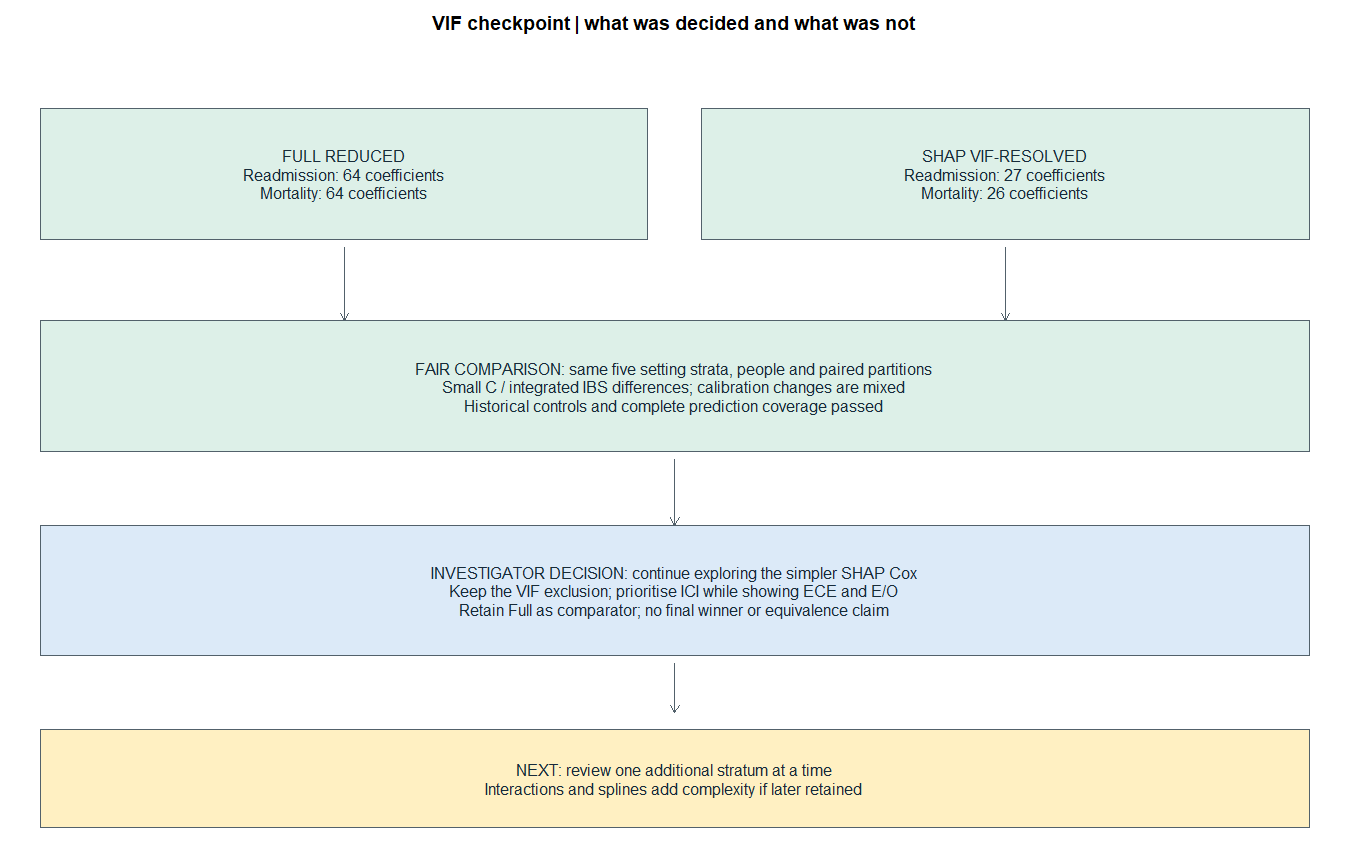

Fewer encoded coefficients simplify the fitted Cox formula, not the preceding ML discovery workflow. No interactions or new spline bases are included in these four formulas.


Elapsed: 0.001 minutes


In [48]:
#| label: shap-vif-complexity-and-decision-flowchart
#| message: false
.t0 <- proc.time()
# Count the current formulas without fitting a model, retaining the excluded term only in historical displays.
current_formulas <- list(Full_readmission = cox_formulas$readmission$reduced, SHAP_readmission = candidate_formulas$readmission$reduced, Full_death = cox_formulas$death$reduced, SHAP_death = candidate_formulas$death$initial)
complexity <- do.call(rbind, lapply(names(current_formulas), function(name) {
  f <- current_formulas[[name]]
  ordinary <- formula_terms(f)[!grepl("^strata\\(", formula_terms(f))]
  strata_variables <- formula_strata(f)
  stopifnot(!removed_collinear %in% all.vars(f), identical(strata_variables, "plan_type_strata"), all(ordinary %in% names(py_corrected_datasets[[1L]])))
  data.frame(Model = name, Encoded_coefficients = length(ordinary), Stratification_factors = length(strata_variables), Observed_strata = length(unique(py_corrected_datasets[[1L]][[strata_variables]])), Interaction_products = sum(grepl(":", ordinary)), Participants = nrow(py_corrected_datasets[[1L]]))
}))
stopifnot(identical(complexity$Encoded_coefficients, c(64L, 27L, 64L, 26L)), all(complexity$Observed_strata == 5L), all(complexity$Interaction_products == 0L))
stopifnot(length(stats::coef(sequential_diagnostics$readmission_reduced$fit)) == complexity$Encoded_coefficients[2L], length(stats::coef(diagnostics$death$fit)) == complexity$Encoded_coefficients[4L])
show_table(complexity, "Current additive specifications: coefficient count, strata and complete-development size")
show_diagnostic_png(function() {
  decision_canvas("VIF checkpoint | what was decided and what was not")
  decision_box(0.03, 0.48, 0.84, "FULL REDUCED\nReadmission: 64 coefficients\nMortality: 64 coefficients", "accepted", h = 0.08)
  decision_box(0.52, 0.97, 0.84, "SHAP VIF-RESOLVED\nReadmission: 27 coefficients\nMortality: 26 coefficients", "accepted", h = 0.08)
  decision_arrow(0.255, 0.75, 0.255, 0.66); decision_arrow(0.745, 0.75, 0.745, 0.66)
  decision_box(0.03, 0.97, 0.58, "FAIR COMPARISON: same five setting strata, people and paired partitions\nSmall C / integrated IBS differences; calibration changes are mixed\nHistorical controls and complete prediction coverage passed", "accepted", h = 0.08)
  decision_arrow(0.5, 0.49, y2 = 0.41)
  decision_box(0.03, 0.97, 0.33, "INVESTIGATOR DECISION: continue exploring the simpler SHAP Cox\nKeep the VIF exclusion; prioritise ICI while showing ECE and E/O\nRetain Full as comparator; no final winner or equivalence claim", "review", h = 0.08)
  decision_arrow(0.5, 0.24, y2 = 0.18)
  decision_box(0.03, 0.97, 0.10, "NEXT: review one additional stratum at a time\nInteractions and splines add complexity if later retained", "prepared", h = 0.06)
}, 1350L, 860L)
cat("Fewer encoded coefficients simplify the fitted Cox formula, not the preceding ML discovery workflow. No interactions or new spline bases are included in these four formulas.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


In [49]:
#| label: shap-performance-table2-source
#| message: true
.t0 <- proc.time()
# Read the authoritative manuscript without editing it; never transfer old intervals to new estimates.
document <- xml2::read_xml(unz(source_path("manuscript"), "word/document.xml"))
namespace <- xml2::xml_ns(document)
table2_node <- xml2::xml_find_all(document, "//w:body/w:p[starts-with(normalize-space(.), 'Table 2.')]/following-sibling::w:tbl[1]", namespace)
stopifnot(length(table2_node) == 1L)
table2_matrix <- do.call(rbind, lapply(xml2::xml_find_all(table2_node, "./w:tr", namespace), function(row) vapply(xml2::xml_find_all(row, "./w:tc", namespace), function(cell) paste(xml2::xml_text(xml2::xml_find_all(cell, ".//w:t", namespace)), collapse = ""), character(1L))))
# Normalize the Unicode minus before matching and numeric conversion.
first_number <- function(x) {
  normalized <- gsub("\u2212", "-", x)
  as.numeric(regmatches(normalized, regexpr("[-+]?[0-9]*[.]?[0-9]+", normalized)))
}
published_rows <- list()
table2_comparison <- data.frame()
for (outcome in c("readmission", "death")) {
  block <- if (outcome == "readmission") "Readmission, SHAP-informed" else "Mortality, SHAP-informed"
  index <- which(table2_matrix[, 1L] == block)
  stopifnot(length(index) == 1L)
  rows <- table2_matrix[index + seq_along(performance_horizons), , drop = FALSE]
  stopifnot(identical(as.numeric(rows[, 1L]), performance_horizons))
  for (i in seq_along(performance_horizons)) for (metric in c("C", "IBS", "ICI", "EO")) {
    value <- first_number(rows[i, match(metric, c("C", "IBS", "ICI", "EO")) + 1L])
    previous <- if (metric %in% c("C", "IBS")) previous_metrics[previous_metrics$Outcome == outcome & previous_metrics$Horizon == performance_horizons[i], metric] else calibration_historical_control[calibration_historical_control$Outcome == outcome & calibration_historical_control$Horizon == performance_horizons[i], metric]
    digits <- if (metric == "EO") 2L else 3L
    stopifnot(length(previous) == 1L, is.finite(value), round(previous, digits) == value)
    published_rows[[length(published_rows) + 1L]] <- data.frame(Manuscript = paste("Table 2:", block), Outcome = outcome, Stage = historical_final_stage[[outcome]], Partner_for_readmission_calibration = if (outcome == "readmission" && metric %in% c("ICI", "EO")) "physical_stratum" else "Not applicable", Horizon = performance_horizons[i], Metric = metric, Previous_published = value, Historical_reproduced = previous, Published_decimals = digits)
  }
}
published_shap_points <- do.call(rbind, published_rows)
show_table(published_shap_points, "Table 2 SHAP point values verified directly against Word and historical sources")
if (performance_complete) {
  table2_comparison <- published_shap_points
  table2_comparison$New <- vapply(seq_len(nrow(table2_comparison)), function(i) {
    row <- table2_comparison[i, ]
    if (row$Metric %in% c("C", "IBS")) return(performance_table[performance_table$Outcome == row$Outcome & performance_table$Stage == row$Stage & performance_table$Horizon == row$Horizon, row$Metric])
    selected <- calibration_summary$Outcome == row$Outcome & calibration_summary$Stage == row$Stage & calibration_summary$Horizon == row$Horizon
    if (row$Outcome == "readmission") selected <- selected & calibration_summary$Pair == "death_physical"
    calibration_summary[selected, row$Metric]
  }, numeric(1L))
  table2_comparison$Difference_from_published <- table2_comparison$New - table2_comparison$Previous_published
  table2_comparison$Difference_from_unrounded_history <- table2_comparison$New - table2_comparison$Historical_reproduced
  table2_comparison$New_rounded <- mapply(round, table2_comparison$New, table2_comparison$Published_decimals)
  table2_comparison$Classification <- ifelse(table2_comparison$New_rounded == table2_comparison$Previous_published, "trivial", "substantial: published rounding changes")
  stopifnot(nrow(table2_comparison) == 32L, all(is.finite(table2_comparison$New)))
  show_table(table2_comparison, "Table 2: previous versus new SHAP points; investigator review precedes any selection")
  destination <- file.path(table_dir, paste0("Table2_SHAP_point_comparison_", Sys.Date(), "_", performance_signature, ".csv"))
  utils::write.csv(table2_comparison, destination, row.names = FALSE, na = "")
  written <- c(written, destination)
  review_pending <- TRUE
  cat("All candidates were evaluated as requested. This checkpoint does not select a model. Review publication-rounding changes and joint performance before further discovery; paired delta bootstrap remains in prediction225.\n")
} else cat("Published points verified. New complete comparisons and confidence intervals remain pending.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Manuscript,Outcome,Stage,Partner_for_readmission_calibration,Horizon,Metric,Previous_published,Historical_reproduced,Published_decimals
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,6,C,0.646,0.6459,3
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,6,IBS,0.039,0.0386,3
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,physical_stratum,6,ICI,0.007,0.0068,3
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,physical_stratum,6,EO,0.990,0.9911,2
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,12,C,0.633,0.6329,3
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,12,IBS,0.061,0.0610,3
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,physical_stratum,12,ICI,0.008,0.0078,3
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,physical_stratum,12,EO,0.990,0.9913,2
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,36,C,0.615,0.6146,3
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,36,IBS,0.108,0.1084,3


Published points verified. New complete comparisons and confidence intervals remain pending.


Elapsed: 0.002 minutes


## Accepted thesis model b: completed readmission comparison
Decision recorded 2026-10-06T17:42:01-03:00. The investigator accepted the small differences and prioritised ICI within the joint calibration review. ECE, E/O, C/IBS, support and residual NPH remain visible; no metric calculation or cutoff changes. Terms removed under the VIF rule remain excluded from later formulas and interaction expansions.

This completed comparison follows the original sequence: readmission with setting strata and the high-VIF term already removed, versus that same formula with administrative discharge (rule violation or undetermined reason) moved from an ordinary coefficient to a second stratification factor. The mortality model stays initial in both AJ evaluations, so the comparison isolates this readmission specification change. Physical-comorbidity strata for mortality remain a later checkpoint. The rejected third mortality stratification remains excluded.

The first-imputation PH/VIF diagnoses are reused. C/IBS remains 10 x 5 x 5 and calibration 20 x 5 x 5; there is no new imputation, tuning, TreeSHAP or bootstrap. The complete readmission comparison was authorized and executed on 2026-10-06; the investigator has now accepted model b for continuation. ICI and E/O from the manuscript use the later physical-stratum death partner; only the applicable readmission C/IBS publication points can be compared at this step. No historical confidence interval is attached to a new estimate.

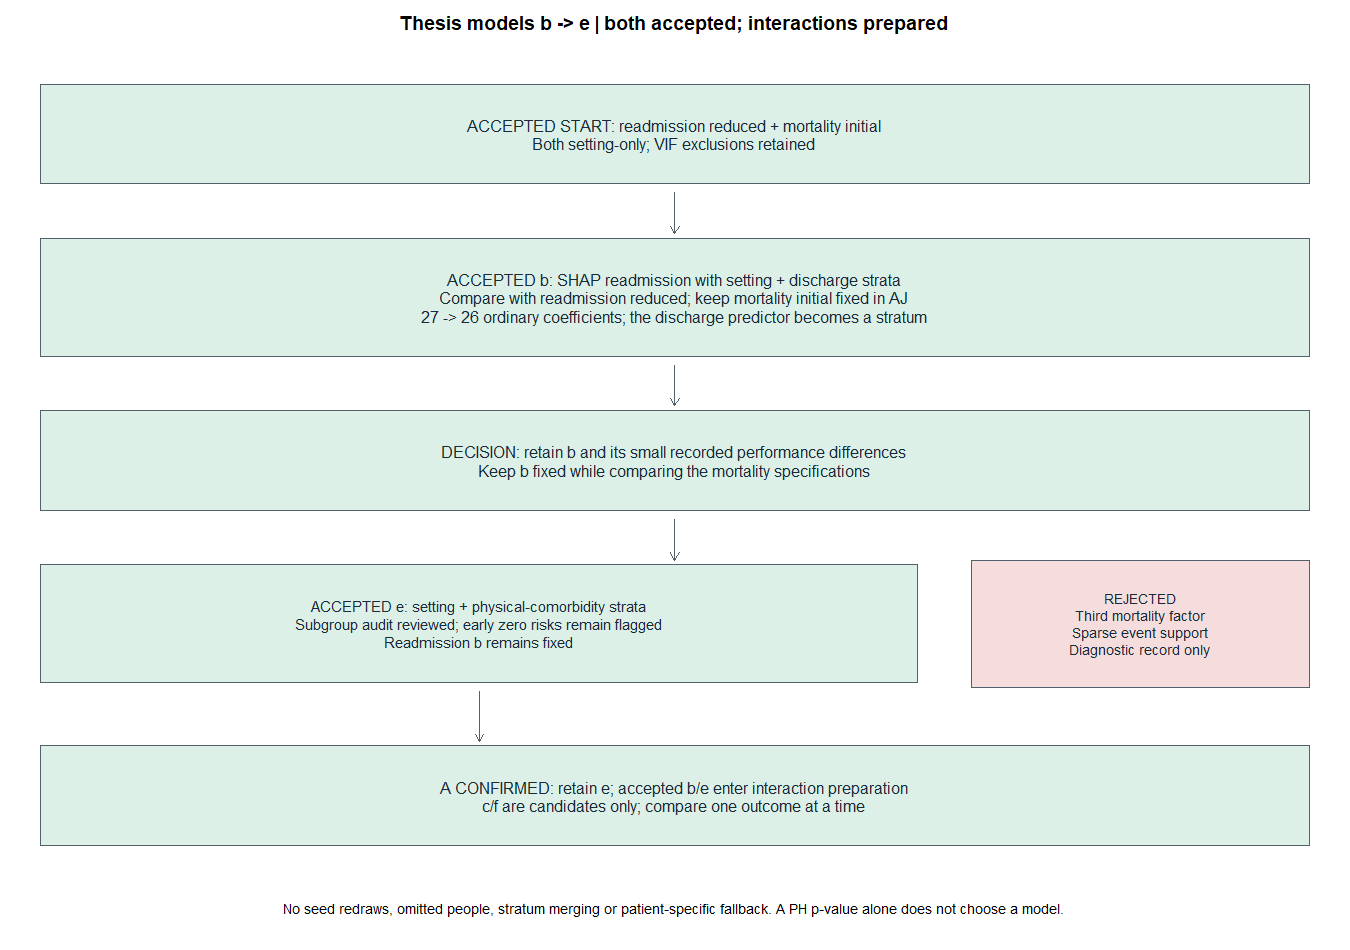

Elapsed: 0.001 minutes


In [50]:
#| label: shap-sequential-strata-decision-flowchart
#| message: false
.t0 <- proc.time()
# Keep each predictive decision separate and label the competing-cause partner explicitly.
show_diagnostic_png(function() {
  decision_canvas("Thesis models b -> e | both accepted; interactions prepared")
  decision_box(0.03, 0.97, 0.90, "ACCEPTED START: readmission reduced + mortality initial\nBoth setting-only; VIF exclusions retained", "accepted", h = 0.055)
  decision_arrow(0.5, 0.835, y2 = 0.79)
  decision_box(0.03, 0.97, 0.72, "ACCEPTED b: SHAP readmission with setting + discharge strata\nCompare with readmission reduced; keep mortality initial fixed in AJ\n27 -> 26 ordinary coefficients; the discharge predictor becomes a stratum", "accepted", h = 0.065)
  decision_arrow(0.5, 0.645, y2 = 0.60)
  decision_box(0.03, 0.97, 0.54, "DECISION: retain b and its small recorded performance differences\nKeep b fixed while comparing the mortality specifications", "accepted", h = 0.055)
  decision_arrow(0.5, 0.475, y2 = 0.43)
  decision_box(0.03, 0.68, 0.36, "ACCEPTED e: setting + physical-comorbidity strata\nSubgroup audit reviewed; early zero risks remain flagged\nReadmission b remains fixed", "accepted", h = 0.065, cex = 0.84)
  decision_box(0.72, 0.97, 0.36, "REJECTED\nThird mortality factor\nSparse event support\nDiagnostic record only", "rejected", h = 0.07, cex = 0.78)
  decision_arrow(0.355, 0.285, y2 = 0.23)
  decision_box(0.03, 0.97, 0.17, "A CONFIRMED: retain e; accepted b/e enter interaction preparation\nc/f are candidates only; compare one outcome at a time", "accepted", h = 0.055)
  graphics::text(0.5, 0.045, "No seed redraws, omitted people, stratum merging or patient-specific fallback. A PH p-value alone does not choose a model.", cex = 0.76)
}, 1350L, 950L)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


In [51]:
#| label: shap-readmission-discharge-contract
#| message: true
.t0 <- proc.time()
# Preserve the accepted VIF exclusions and change only the readmission discharge term.
readmission_step_enabled <- shap_settings$performance_step %in% c("readmission_discharge", "mortality_physical")
readmission_step_review_accepted <- identical(shap_settings$accepted_readmission_performance_signature, performance_signature)
readmission_step_run <- readmission_step_enabled && (identical(performance_settings$mode, "readmission_stratum") || identical(shap_settings$performance_step, "mortality_physical"))
readmission_step_complete <- FALSE
readmission_step_metrics <- readmission_step_repetitions <- readmission_step_coverage <- readmission_step_comparison <- readmission_step_published <- readmission_step_completeness <- data.frame()
readmission_step_calibration <- NULL
readmission_before <- candidate_formulas$readmission$reduced
readmission_after <- candidate_formulas$readmission$discharge_stratum
stopifnot(!removed_collinear %in% all.vars(readmission_before), !removed_collinear %in% all.vars(readmission_after))
stopifnot(setequal(setdiff(formula_terms(readmission_before), formula_terms(readmission_after)), discharge_stratum))
stopifnot(setequal(setdiff(formula_terms(readmission_after), formula_terms(readmission_before)), paste0("strata(", discharge_stratum, ")")))
stopifnot(identical(deparse(readmission_before[[2L]]), deparse(readmission_after[[2L]])), setequal(formula_strata(readmission_after), c("plan_type_strata", discharge_stratum)))
pair <- calibration_pairs[calibration_pairs$Pair == "readmission_discharge", ]
stopifnot(nrow(pair) == 1L, pair$Readmission == "discharge_stratum", pair$Death == "initial")
readmission_step_support <- support_table[support_table$Outcome == "readmission" & support_table$Stage == "discharge_stratum", ]
stopifnot(nrow(readmission_step_support) == 1L, readmission_step_support$Unsupported_validation_predictions == 0L, readmission_step_support$Fits_with_a_zero_event_stratum == 0L)
readmission_step_ph <- do.call(rbind, lapply(c("reduced", "discharge_stratum"), function(stage) {
  diagnostic <- sequential_diagnostics[[paste("readmission", stage, sep = "_")]]
  stopifnot(max(diagnostic$vif$VIF) < 10)
  value <- ph_frame(diagnostic$ph, "readmission")
  value <- value[value$Term %in% c(discharge_stratum, "GLOBAL"), ]
  value$Stage <- stage
  value
}))
show_table(readmission_step_ph, "Stored first-imputation PH: residual discharge NPH precedes this single-factor comparison")
show_table(readmission_step_support, "C/IBS support for discharge strata; AJ folds still require separate completeness checks")
cat("VIF exclusions are permanent for subsequent candidate construction unless explicitly reviewed. ICI has priority in the joint calibration review; ECE and E/O remain visible.\n")
cat("Current comparison: readmission setting plus administrative-discharge strata; the mortality partner stays initial. No physical-comorbidity mortality step is run here.\n")
cat("Full uncached budget: 250 C/IBS and 1000 AJ; existing caches are reused. No new mortality KM. Current free RAM (GiB):", ps::ps_system_memory()$avail / 1024^3, "| Reserve (GiB):", shap_settings$reserve_memory_gib, "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Outcome,Term,Chi_square,df,p,Stage
readmission,Administrative discharge: rule violation or undetermined reason,59.4683,1,0,reduced
readmission,GLOBAL,166.7518,27,0,reduced
readmission,GLOBAL,106.3777,26,0,discharge_stratum


Outcome,Stage,Training_fits_checked,Minimum_training_stratum_n,Minimum_training_stratum_events,Fits_with_a_zero_event_stratum,Unsupported_validation_predictions,Subjects_omitted,Decision
readmission,discharge_stratum,250,183,53,0,0,0,Retained for the sequential investigator checkpoints


VIF exclusions are permanent for subsequent candidate construction unless explicitly reviewed. ICI has priority in the joint calibration review; ECE and E/O remain visible.


Current comparison: readmission setting plus administrative-discharge strata; the mortality partner stays initial. No physical-comorbidity mortality step is run here.


Full uncached budget: 250 C/IBS and 1000 AJ; existing caches are reused. No new mortality KM. Current free RAM (GiB): 58.96241 | Reserve (GiB): 20 


Elapsed: 0.000 minutes


In [52]:
#| label: shap-readmission-discharge-c-ibs
#| message: true
.t0 <- proc.time()
# Reuse every preceding metric and evaluate the new readmission formula on the same ten partitions.
if (readmission_step_run) {
  stopifnot(vif_complete, performance_new_fits == 0L, max(metric_control$Maximum_absolute_difference) < 1e-8)
  tasks <- lapply(seq_len(10L), function(r) list(Outcome = "readmission", Stage = "discharge_stratum", Repetition = r))
  results <- performance_parallel(tasks)
  for (result in results) {
    record_performance_fits(result$new_fits)
    written <- c(written, result$written)
  }
  readmission_step_repetitions <- do.call(rbind, lapply(results, function(x) x$table))
  readmission_step_coverage <- do.call(rbind, lapply(results, function(x) x$coverage))
  stopifnot(nrow(readmission_step_repetitions) == 40L, !anyDuplicated(readmission_step_repetitions[, c("Repetition", "Horizon")]), all(is.finite(as.matrix(readmission_step_repetitions[, c("C", "IBS")]))))
  stopifnot(nrow(readmission_step_coverage) == 10L, all(readmission_step_coverage$Expected == readmission_step_coverage$Predicted), all(readmission_step_coverage$Omitted == 0L))
  readmission_step_metrics <- stats::aggregate(cbind(C, IBS) ~ Horizon, readmission_step_repetitions, mean)
  baseline <- vif_repetitions[vif_repetitions$Outcome == "readmission" & vif_repetitions$Stage == "reduced", ]
  paired <- merge(baseline, readmission_step_repetitions, by = c("Repetition", "Horizon"), suffixes = c("_before", "_after"))
  stopifnot(nrow(paired) == 40L)
  paired$Delta_C <- paired$C_after - paired$C_before
  paired$Delta_IBS <- paired$IBS_after - paired$IBS_before
  readmission_step_comparison <- stats::aggregate(cbind(C_before, C_after, Delta_C, IBS_before, IBS_after, Delta_IBS) ~ Horizon, paired, mean)
  show_table(readmission_step_comparison, "Single change: discharge stratification after VIF removal; ten paired C/IBS repetitions")
  show_table(readmission_step_coverage, "Every participant predicted in every C/IBS repetition; no fallback or exclusions")
} else cat("Readmission discharge-stratum C/IBS is prepared; scheduling confirmation remains pending.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Horizon,C_before,C_after,Delta_C,IBS_before,IBS_after,Delta_IBS
6,0.6446,0.6457,0.0011,0.0387,0.0387,-1e-04
12,0.6326,0.6327,0.0002,0.0610,0.0610,0e+00
36,0.6146,0.6144,-0.0002,0.1085,0.1085,0e+00
60,0.6095,0.6093,-0.0002,0.1333,0.1333,0e+00


Outcome,Stage,Repetition,Expected,Predicted,Omitted
readmission,discharge_stratum,1,70521,70521,0
readmission,discharge_stratum,2,70521,70521,0
readmission,discharge_stratum,3,70521,70521,0
readmission,discharge_stratum,4,70521,70521,0
readmission,discharge_stratum,5,70521,70521,0
readmission,discharge_stratum,6,70521,70521,0
readmission,discharge_stratum,7,70521,70521,0
readmission,discharge_stratum,8,70521,70521,0
readmission,discharge_stratum,9,70521,70521,0
readmission,discharge_stratum,10,70521,70521,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.150 minutes


In [53]:
#| label: shap-readmission-discharge-calibration
#| message: true
.t0 <- proc.time()
# Reuse the proven two-process dispatcher; the mortality job only reads its completed cache.
if (readmission_step_run) {
  stopifnot(nrow(readmission_step_metrics) == 4L, max(calibration_historical_control$Maximum_absolute_difference) < 1e-8)
  tasks <- list(list(Kind = "readmission", Pair = "readmission_discharge"), list(Kind = "death", Pair = "initial"))
  results <- performance_parallel(tasks, worker = calibration_checkpoint_task)
  stopifnot(results[[2L]]$new_fits == 0L, length(results[[2L]]$written) == 0L, identical(results[[2L]]$value$pooled_summary, vif_calibration_values$death$value$pooled_summary))
  for (result in results) {
    record_performance_fits(result$new_fits)
    written <- c(written, result$written)
  }
  readmission_step_calibration <- results[[1L]]
  show_table(readmission_step_calibration$value$pooled_summary, "Readmission AJ after discharge stratification: mortality initial held fixed; 20 x 5 x 5")
} else cat("Readmission discharge-stratum AJ calibration is prepared; no calibration models were fitted.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


time_months,ici_mean,ici_sd,ici_min,ici_p025,ici_p975,ici_max,e50_mean,e50_sd,e50_min,e50_p025,e50_p975,e50_max,e90_mean,e90_sd,e90_min,e90_p025,e90_p975,e90_max,emax_mean,emax_sd,emax_min,emax_p025,emax_p975,emax_max,ece_mean,ece_sd,ece_min,ece_p025,ece_p975,ece_max,eo_mean,eo_sd,eo_min,eo_p025,eo_p975,eo_max,mean_pred,mean_pred_sd,mean_pred_min,mean_pred_p025,mean_pred_p975,mean_pred_max,observed,observed_sd,observed_min,observed_p025,observed_p975,observed_max,n_runs,n_imp
6,0.0068,1e-04,0.0065,0.0065,0.0070,0.0070,0.0017,4e-04,0.0008,0.0008,0.0026,0.0026,0.0208,3e-04,0.0204,0.0204,0.0212,0.0212,0.4216,0.0159,0.3922,0.3922,0.4562,0.4562,0.0023,4e-04,0.0019,0.0019,0.0030,0.0030,0.9910,1e-04,0.9908,0.9908,0.9913,0.9913,0.0719,0,0.0719,0.0719,0.0719,0.0719,0.0726,0,0.0726,0.0726,0.0726,0.0726,20,5
12,0.0078,1e-04,0.0075,0.0075,0.0080,0.0080,0.0021,3e-04,0.0016,0.0016,0.0024,0.0024,0.0232,2e-04,0.0229,0.0229,0.0236,0.0236,0.4710,0.0180,0.4387,0.4387,0.5060,0.5060,0.0029,4e-04,0.0024,0.0024,0.0038,0.0038,0.9912,1e-04,0.9910,0.9910,0.9914,0.9914,0.1136,0,0.1135,0.1135,0.1136,0.1136,0.1146,0,0.1146,0.1146,0.1146,0.1146,20,5
36,0.0092,1e-04,0.0090,0.0090,0.0094,0.0094,0.0036,4e-04,0.0026,0.0026,0.0046,0.0046,0.0218,6e-04,0.0208,0.0208,0.0233,0.0233,0.5541,0.0192,0.5116,0.5116,0.5886,0.5886,0.0047,5e-04,0.0039,0.0039,0.0056,0.0056,0.9893,1e-04,0.9891,0.9891,0.9894,0.9894,0.1997,0,0.1996,0.1996,0.1997,0.1997,0.2019,0,0.2019,0.2019,0.2019,0.2019,20,5
60,0.0095,1e-04,0.0093,0.0093,0.0097,0.0097,0.0038,4e-04,0.0032,0.0032,0.0047,0.0047,0.0215,5e-04,0.0204,0.0204,0.0224,0.0224,0.5718,0.0193,0.5272,0.5272,0.6034,0.6034,0.0065,6e-04,0.0057,0.0057,0.0078,0.0078,0.9859,1e-04,0.9857,0.9857,0.9860,0.9860,0.2428,0,0.2427,0.2427,0.2428,0.2428,0.2462,0,0.2462,0.2462,0.2462,0.2462,20,5


Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.110 minutes


Horizon,C_before,C_after,Delta_C,IBS_before,IBS_after,Delta_IBS,ICI_before,ICI_after,Delta_ICI,ECE_before,ECE_after,Delta_ECE,EO_before,EO_after,Delta_EO,Magnitude_flag
6,0.6446,0.6457,0.0011,0.0387,0.0387,-1e-04,0.0064,0.0068,5e-04,0.0018,0.0023,5e-04,0.9919,0.9910,-0.0009,Below study C/IBS magnitude thresholds; not proof of equivalence
12,0.6326,0.6327,0.0002,0.0610,0.0610,0e+00,0.0075,0.0078,3e-04,0.0026,0.0029,3e-04,0.9919,0.9912,-0.0006,Below study C/IBS magnitude thresholds; not proof of equivalence
36,0.6146,0.6144,-0.0002,0.1085,0.1085,0e+00,0.0091,0.0092,1e-04,0.0046,0.0047,1e-04,0.9891,0.9893,0.0002,Below study C/IBS magnitude thresholds; not proof of equivalence
60,0.6095,0.6093,-0.0002,0.1333,0.1333,0e+00,0.0096,0.0095,-1e-04,0.0065,0.0065,0e+00,0.9848,0.9859,0.0011,Below study C/IBS magnitude thresholds; not proof of equivalence


Participants_per_repetition,Repetitions,Prediction_tasks,Omitted,Paired_fold_indices_identical,Minimum_predicted_risk,Maximum_predicted_risk,Zero_risk_entries,Maximum_excluded_from_calibration_bins
70521,20,100,0,TRUE,0.0181,0.8236,0,0


Manuscript,Outcome,Stage,Partner_for_readmission_calibration,Horizon,Metric,Previous_published,Historical_reproduced,Published_decimals,New,New_first_partition,Difference_from_published,New_rounded,Classification
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,6,C,0.646,0.6459,3,0.6457,0.6458,-3e-04,0.646,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,6,IBS,0.039,0.0386,3,0.0387,0.0386,-3e-04,0.039,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,12,C,0.633,0.6329,3,0.6327,0.6329,-3e-04,0.633,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,12,IBS,0.061,0.0610,3,0.0610,0.0610,0e+00,0.061,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,36,C,0.615,0.6146,3,0.6144,0.6145,-6e-04,0.614,substantial: published rounding changes; review before continuing
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,36,IBS,0.108,0.1084,3,0.1085,0.1084,5e-04,0.108,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,60,C,0.610,0.6096,3,0.6093,0.6095,-7e-04,0.609,substantial: published rounding changes; review before continuing
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,60,IBS,0.133,0.1333,3,0.1333,0.1333,3e-04,0.133,trivial: published rounding unchanged


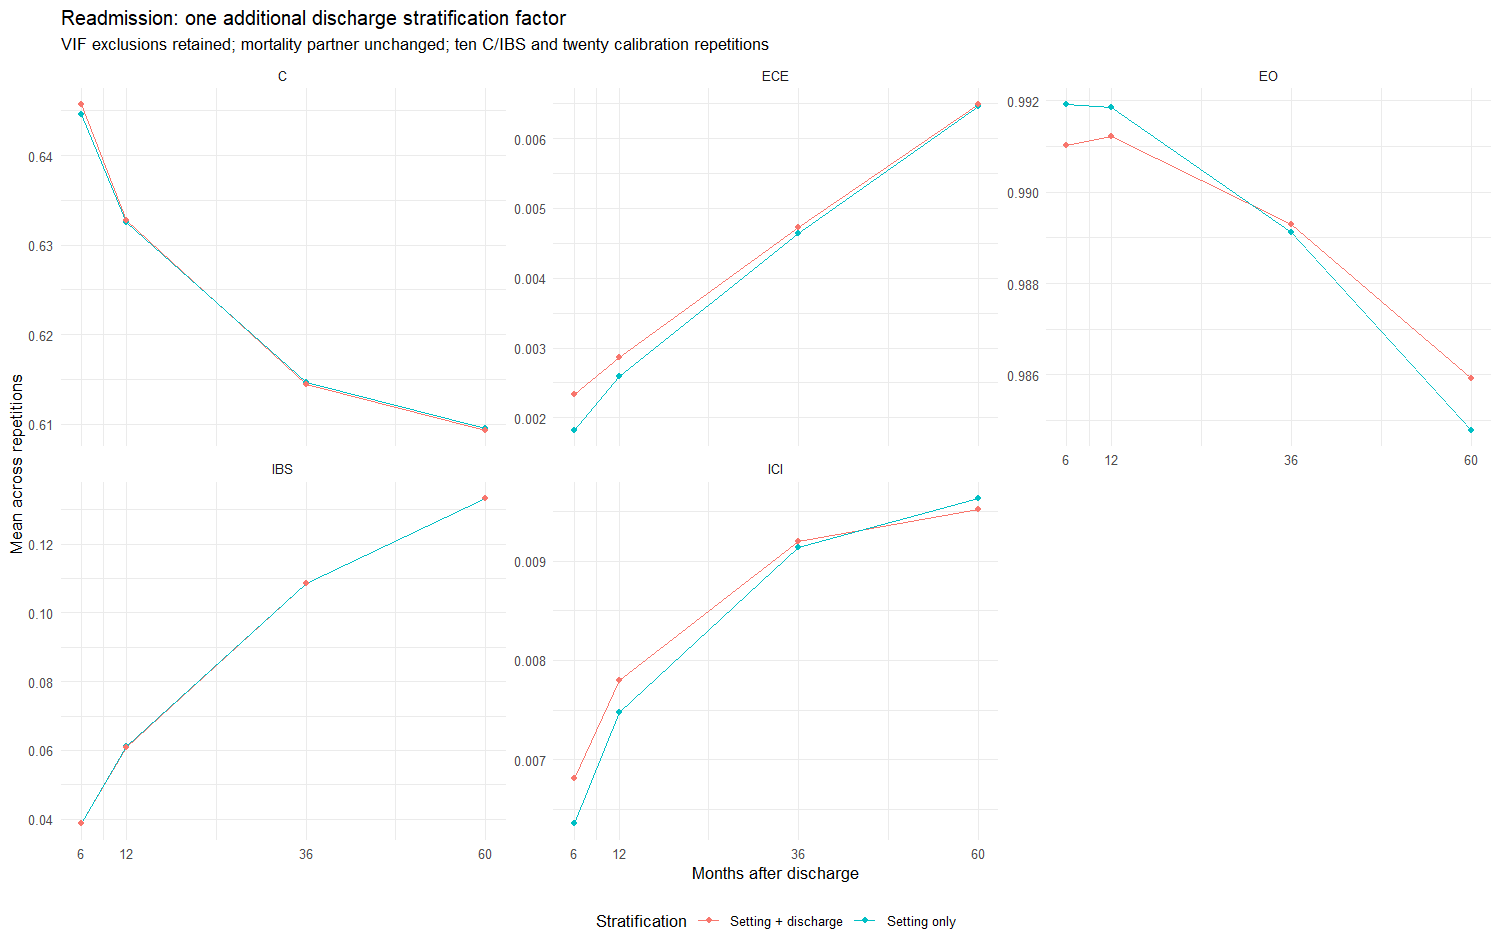

Model b accepted by the investigator: retain readmission setting plus discharge strata and the recorded rounding differences.
Differences from published C/IBS include the accepted preprocessing, predictor-set and repetition changes; the paired before-after table isolates this stratification step. Old confidence intervals remain historical.


Elapsed: 0.384 minutes


In [54]:
#| label: shap-readmission-discharge-checkpoint
#| message: true
.t0 <- proc.time()
# Verify the new AJ tasks against the preceding candidate before comparing performance.
if (readmission_step_run) {
  current <- readmission_step_calibration
  previous <- vif_calibration_values$readmission
  n_participants <- nrow(py_corrected_datasets[[1L]])
  metrics <- current$value$by_repetition
  stopifnot(nrow(metrics) == 80L, !anyDuplicated(metrics[, c("repetition", "time_months")]), identical(as.numeric(metrics$time_months), rep(performance_horizons, 20L)))
  stopifnot(all(is.finite(as.matrix(metrics[, c("ici", "ece", "eo_ratio")]))), all(metrics$n_input == n_participants), all(metrics$n_analysis == n_participants), all(metrics$n_dropped == 0L), all(metrics$n_used_calibration == n_participants), all(metrics$n_excluded_calibration == 0L), all(metrics$n_imputations == 5L))
  pooled <- current$value$pooled_summary
  recalculated <- stats::aggregate(cbind(ici, ece, eo_ratio) ~ time_months, metrics, mean)
  recalculated <- recalculated[match(pooled$time_months, recalculated$time_months), ]
  stopifnot(max(abs(as.matrix(recalculated[, c("ici", "ece", "eo_ratio")]) - as.matrix(pooled[, c("ici_mean", "ece_mean", "eo_mean")]))) < 1e-12)
  minimum_risk <- Inf
  maximum_risk <- -Inf
  zero_predictions <- 0L
  for (repetition in seq_len(20L)) {
    indices <- integer()
    for (fold in seq_len(5L)) {
      suffix <- sprintf("_r%02d_f%02d", repetition, fold)
      paths <- lapply(c(current$prefix, previous$prefix), function(prefix) list.files(object_dir, pattern = paste0("^perf07_", prefix, suffix, "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE))
      stopifnot(all(lengths(paths) == 1L))
      objects <- lapply(paths, function(path) readRDS(path[[1L]]))
      stopifnot(all(vapply(objects, function(x) identical(x$signature, performance_signature) && x$value$r == repetition, logical(1L))))
      rows <- objects[[1L]]$value$te_idx
      risk <- objects[[1L]]$value$pred_fold_avg
      stopifnot(identical(rows, objects[[2L]]$value$te_idx), identical(dim(risk), c(length(rows), length(performance_horizons))), all(is.finite(risk)), all(risk >= 0 & risk <= 1))
      minimum_risk <- min(minimum_risk, risk)
      maximum_risk <- max(maximum_risk, risk)
      zero_predictions <- zero_predictions + sum(risk == 0)
      indices <- c(indices, rows)
    }
    stopifnot(length(indices) == n_participants, all(indices >= 1L & indices <= n_participants))
    assert_prediction_coverage(tabulate(indices, nbins = n_participants))
  }
  readmission_step_completeness <- data.frame(Participants_per_repetition = n_participants, Repetitions = 20L, Prediction_tasks = 100L, Omitted = 0L, Paired_fold_indices_identical = TRUE, Minimum_predicted_risk = minimum_risk, Maximum_predicted_risk = maximum_risk, Zero_risk_entries = zero_predictions, Maximum_excluded_from_calibration_bins = max(metrics$n_excluded_calibration))
  before <- previous$value$pooled_summary
  after <- pooled[match(before$time_months, pooled$time_months), ]
  calibration_change <- data.frame(Horizon = before$time_months, ICI_before = before$ici_mean, ICI_after = after$ici_mean, Delta_ICI = after$ici_mean - before$ici_mean, ECE_before = before$ece_mean, ECE_after = after$ece_mean, Delta_ECE = after$ece_mean - before$ece_mean, EO_before = before$eo_mean, EO_after = after$eo_mean, Delta_EO = after$eo_mean - before$eo_mean)
  readmission_step_comparison <- merge(readmission_step_comparison, calibration_change, by = "Horizon")
  readmission_step_comparison$Magnitude_flag <- ifelse(abs(readmission_step_comparison$Delta_C) >= 0.01 | abs(readmission_step_comparison$Delta_IBS) >= 0.001, "Reaches a study C/IBS magnitude threshold; review", "Below study C/IBS magnitude thresholds; not proof of equivalence")
  show_table(readmission_step_comparison, "Readmission: before versus after discharge stratification; ICI prioritised, all calibration measures retained")
  show_table(readmission_step_completeness, "New AJ tasks match preceding folds exactly; all participants retained")
  # Compare only the Table 2 metrics whose current formula and probability target are available at this step.
  readmission_step_published <- published_shap_points[published_shap_points$Outcome == "readmission" & published_shap_points$Metric %in% c("C", "IBS"), ]
  readmission_step_published$New <- vapply(seq_len(nrow(readmission_step_published)), function(i) {
    row <- readmission_step_published[i, ]
    readmission_step_metrics[readmission_step_metrics$Horizon == row$Horizon, row$Metric]
  }, numeric(1L))
  readmission_step_published$New_first_partition <- vapply(seq_len(nrow(readmission_step_published)), function(i) {
    row <- readmission_step_published[i, ]
    readmission_step_repetitions[readmission_step_repetitions$Repetition == 1L & readmission_step_repetitions$Horizon == row$Horizon, row$Metric]
  }, numeric(1L))
  readmission_step_published$Difference_from_published <- readmission_step_published$New - readmission_step_published$Previous_published
  readmission_step_published$New_rounded <- mapply(round, readmission_step_published$New, readmission_step_published$Published_decimals)
  readmission_step_published$Classification <- ifelse(readmission_step_published$New_rounded == readmission_step_published$Previous_published, "trivial: published rounding unchanged", "substantial: published rounding changes; review before continuing")
  stopifnot(nrow(readmission_step_published) == 8L, all(is.finite(readmission_step_published$New)))
  show_table(readmission_step_published, "Table 2 readmission C/IBS: clean candidate versus published points; no old confidence intervals transferred")
  destination <- file.path(table_dir, paste0("Table2_readmission_C_IBS_discharge_candidate_", Sys.Date(), "_", performance_signature, ".csv"))
  utils::write.csv(readmission_step_published, destination, row.names = FALSE, na = "")
  written <- c(written, destination)
  # Display compact intermediate evidence without exporting separate figure files.
  comparison <- readmission_step_comparison
  long <- do.call(rbind, lapply(c("C", "IBS", "ICI", "ECE", "EO"), function(metric) do.call(rbind, lapply(c("before", "after"), function(stage) data.frame(Horizon = comparison$Horizon, Metric = metric, Model = if (stage == "before") "Setting only" else "Setting + discharge", Value = comparison[[paste(metric, stage, sep = "_")]])))))
  p <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Model, group = Model)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(~Metric, scales = "free_y", ncol = 3) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "Readmission: one additional discharge stratification factor", subtitle = "VIF exclusions retained; mortality partner unchanged; ten C/IBS and twenty calibration repetitions", x = "Months after discharge", y = "Mean across repetitions", color = "Stratification") + ggplot2::theme_minimal() + ggplot2::theme(legend.position = "bottom")
  show_diagnostic_png(function() print(p), width = 1500L, height = 950L)
  readmission_step_complete <- TRUE
  review_pending <- !readmission_step_review_accepted
  if (readmission_step_review_accepted) cat("Model b accepted by the investigator: retain readmission setting plus discharge strata and the recorded rounding differences.\n") else cat("STOP FOR INVESTIGATOR REVIEW: readmission discharge-stratum comparison complete. Published ICI/E/O use the later physical-stratum mortality partner and are not compared prematurely. This checkpoint does not run or select that mortality model.\n")
  cat("Differences from published C/IBS include the accepted preprocessing, predictor-set and repetition changes; the paired before-after table isolates this stratification step. Old confidence intervals remain historical.\n")
} else cat("Readmission discharge checkpoint prepared. No new predictive estimates or published replacements are reported.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


## Accepted mortality decision before interaction testing
**The investigator confirmed A on 2026-10-07: retain model e. Both b and e are accepted bases without interactions or the excluded collinear term.** C/IBS changes between the mortality alternatives were small and mixed. The subgroup audit supported e: the setting-only alternative underestimated early mortality in the physical-comorbidity group, where e improved ICI and mean predicted risk. Its small global ICI advantage remains visible in the comparison below; no global superiority or equivalence is claimed.

Some early risks remain zero in CV strata without training deaths before the horizon. All people and events remain in evaluation, without fallback, probability replacement or stratum merging. The subgroup audit concerns development, not holdout. Whole-development preprocessing remains shared inside CV.

The accepted decision supersedes the earlier recommendation for setting-only mortality. Dated justification and subgroup tables: `docs/07_stage_plan.md` and `docs/07_performance_checkpoint.md`. Exact executed subgroup code/results: `docs/07_mortality_subgroup_check_2026-10-07.json`.

**Status of this earlier checkpoint:** c/f preparation and both predictive comparisons are now complete below. The investigator retained b/e without interactions. The current next step is the functional candidate review. Word and historical intervals remain unchanged.


## Completed comparison: accepted thesis model e
The setting-only SHAP mortality predecessor was compared with e, which uses physical comorbidity as a stratum. A/e is now accepted. The following cells verify and display the saved comparison with b fixed; preparation stops if a required cache is missing.


Outcome,Term,Chi_square,df,p,Stage
death,Any selected physical comorbidity recorded,15.1231,1,1e-04,initial
death,GLOBAL,136.8134,26,0e+00,initial
death,GLOBAL,121.6458,25,0e+00,physical_stratum


Outcome,Stage,Training_fits_checked,Minimum_training_stratum_n,Minimum_training_stratum_events,Fits_with_a_zero_event_stratum,Unsupported_validation_predictions,Subjects_omitted,Decision
death,physical_stratum,250,316,12,0,0,0,Retained for the sequential investigator checkpoints


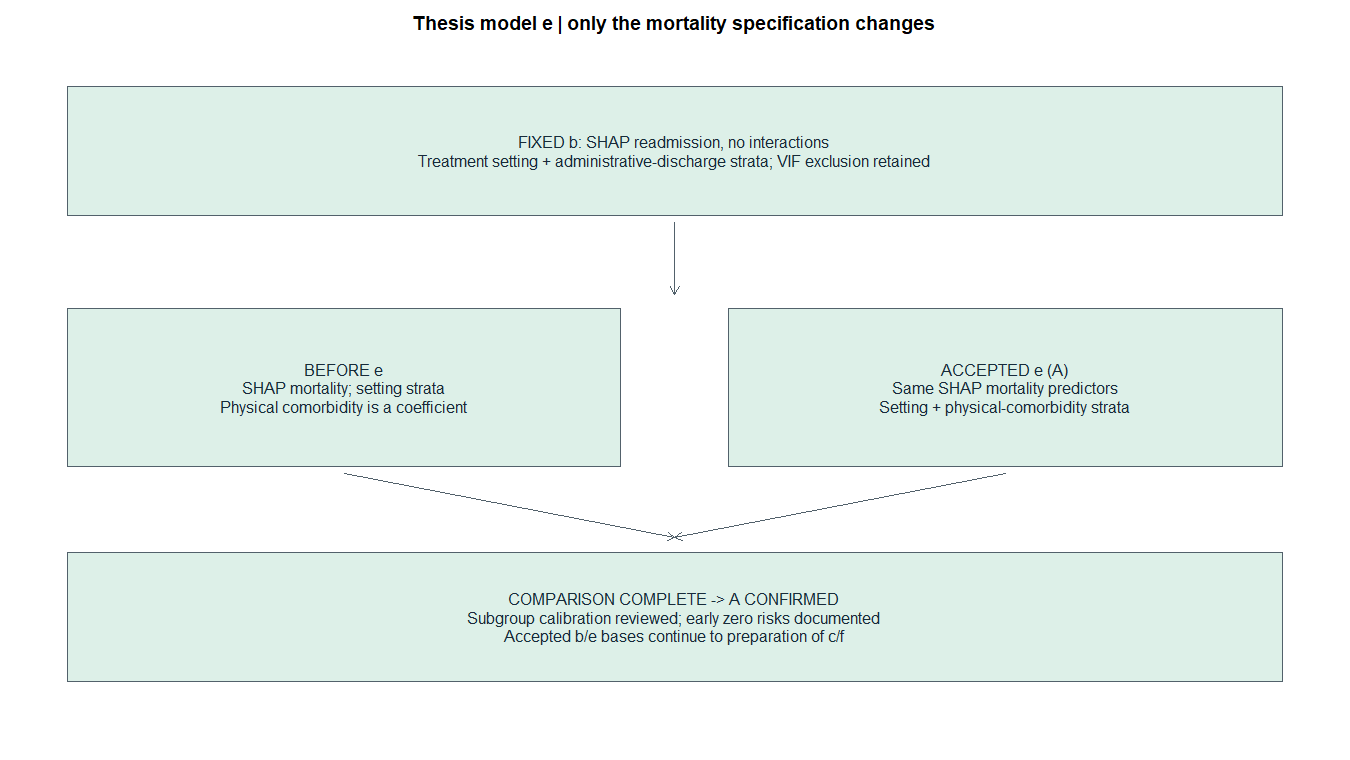

Model e was accepted as A. Preparation reuses its completed comparison; missing caches stop instead of refitting. No new imputation, tuning, TreeSHAP or bootstrap.


Free RAM (GiB): 56.72944 | Reserve: 20 | C/IBS workers: 8 | Two single-thread calibration engines.


Elapsed: 0.001 minutes


In [55]:
#| label: shap-mortality-physical-contract
#| message: true
.t0 <- proc.time()
# Preserve accepted readmission model b and change only the physical-comorbidity term in mortality.
mortality_step_enabled <- identical(shap_settings$performance_step, "mortality_physical")
mortality_step_review_accepted <- identical(shap_settings$accepted_mortality_performance_signature, performance_signature)
mortality_step_run <- mortality_step_enabled && (identical(performance_settings$mode, "mortality_stratum") || mortality_step_review_accepted)
mortality_step_complete <- FALSE
mortality_step_metrics <- mortality_step_repetitions <- mortality_step_coverage <- mortality_step_comparison <- mortality_step_calibration_comparison <- mortality_step_published <- mortality_step_completeness <- data.frame()
mortality_step_calibration <- list()
mortality_zero_horizon <- data.frame()
mortality_before <- candidate_formulas$death$initial
mortality_after <- formula_shap_death_rule2
stopifnot(!removed_collinear %in% all.vars(mortality_before), !removed_collinear %in% all.vars(mortality_after))
stopifnot(setequal(setdiff(formula_terms(mortality_before), formula_terms(mortality_after)), "any_phys_dx"), setequal(setdiff(formula_terms(mortality_after), formula_terms(mortality_before)), "strata(any_phys_dx)"))
stopifnot(identical(deparse(mortality_before[[2L]]), deparse(mortality_after[[2L]])), setequal(formula_strata(mortality_after), c("plan_type_strata", "any_phys_dx")))
pair <- calibration_pairs[calibration_pairs$Pair == "death_physical", ]
stopifnot(nrow(pair) == 1L, pair$Readmission == "discharge_stratum", pair$Death == "physical_stratum")
if (mortality_step_enabled) stopifnot(readmission_step_review_accepted, readmission_step_complete, !review_pending)
mortality_step_support <- support_table[support_table$Outcome == "death" & support_table$Stage == "physical_stratum", ]
stopifnot(nrow(mortality_step_support) == 1L, mortality_step_support$Unsupported_validation_predictions == 0L)
mortality_step_ph <- do.call(rbind, lapply(c("initial", "physical_stratum"), function(stage) {
  diagnostic <- sequential_diagnostics[[paste("death", stage, sep = "_")]]
  stopifnot(max(diagnostic$vif$VIF) < 10)
  value <- ph_frame(diagnostic$ph, "death")
  value <- value[value$Term %in% c("any_phys_dx", "GLOBAL"), ]
  value$Stage <- stage
  value
}))
show_table(mortality_step_ph, "Model e: stored PH evidence before and after physical-comorbidity stratification")
show_table(mortality_step_support, "Model e: stored training support; completed coverage is verified below")
show_diagnostic_png(function() {
  decision_canvas("Thesis model e | only the mortality specification changes")
  decision_box(0.05, 0.95, 0.85, "FIXED b: SHAP readmission, no interactions\nTreatment setting + administrative-discharge strata; VIF exclusion retained", "accepted", h = 0.09)
  decision_arrow(0.5, 0.75, y2 = 0.65)
  decision_box(0.05, 0.46, 0.52, "BEFORE e\nSHAP mortality; setting strata\nPhysical comorbidity is a coefficient", "accepted", h = 0.11)
  decision_box(0.54, 0.95, 0.52, "ACCEPTED e (A)\nSame SHAP mortality predictors\nSetting + physical-comorbidity strata", "accepted", h = 0.11)
  decision_arrow(0.255, 0.40, 0.5, 0.31); decision_arrow(0.745, 0.40, 0.5, 0.31)
  decision_box(0.05, 0.95, 0.20, "COMPARISON COMPLETE -> A CONFIRMED\nSubgroup calibration reviewed; early zero risks documented\nAccepted b/e bases continue to preparation of c/f", "accepted", h = 0.09)
}, 1350L, 760L)
cat("Model e was accepted as A. Preparation reuses its completed comparison; missing caches stop instead of refitting. No new imputation, tuning, TreeSHAP or bootstrap.\n")
cat("Free RAM (GiB):", ps::ps_system_memory()$avail / 1024^3, "| Reserve:", shap_settings$reserve_memory_gib, "| C/IBS workers:", performance_settings$workers, "| Two single-thread calibration engines.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


In [56]:
#| label: shap-mortality-physical-c-ibs
#| message: true
.t0 <- proc.time()
# Compare the setting-only SHAP mortality predecessor with thesis model e on the same ten partitions.
if (mortality_step_run) {
  stopifnot(readmission_step_complete, readmission_step_review_accepted, performance_new_fits == 0L, max(metric_control$Maximum_absolute_difference) < 1e-8)
  tasks <- lapply(seq_len(10L), function(r) list(Outcome = "death", Stage = "physical_stratum", Repetition = r))
  results <- performance_parallel(tasks)
  for (result in results) {
    record_performance_fits(result$new_fits)
    written <- c(written, result$written)
  }
  mortality_step_repetitions <- do.call(rbind, lapply(results, function(x) x$table))
  mortality_step_coverage <- do.call(rbind, lapply(results, function(x) x$coverage))
  stopifnot(nrow(mortality_step_repetitions) == 40L, !anyDuplicated(mortality_step_repetitions[, c("Repetition", "Horizon")]), all(is.finite(as.matrix(mortality_step_repetitions[, c("C", "IBS")]))))
  stopifnot(nrow(mortality_step_coverage) == 10L, all(mortality_step_coverage$Expected == mortality_step_coverage$Predicted), all(mortality_step_coverage$Omitted == 0L))
  mortality_step_metrics <- stats::aggregate(cbind(C, IBS) ~ Horizon, mortality_step_repetitions, mean)
  baseline <- vif_repetitions[vif_repetitions$Outcome == "death" & vif_repetitions$Stage == "initial", ]
  paired <- merge(baseline, mortality_step_repetitions, by = c("Repetition", "Horizon"), suffixes = c("_before", "_after"))
  stopifnot(nrow(paired) == 40L)
  paired$Delta_C <- paired$C_after - paired$C_before
  paired$Delta_IBS <- paired$IBS_after - paired$IBS_before
  mortality_step_comparison <- stats::aggregate(cbind(C_before, C_after, Delta_C, IBS_before, IBS_after, Delta_IBS) ~ Horizon, paired, mean)
  show_table(mortality_step_comparison, "Mortality: SHAP setting-only predecessor versus model e; ten paired C/IBS repetitions")
} else cat("Prepared model e: new mortality C/IBS has not run. Previously completed b results are reused.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Horizon,C_before,C_after,Delta_C,IBS_before,IBS_after,Delta_IBS
6,0.7673,0.7675,2e-04,0.0046,0.0045,0
12,0.7601,0.7605,4e-04,0.0065,0.0065,0
36,0.7658,0.7657,-1e-04,0.0144,0.0144,0
60,0.7639,0.7638,-1e-04,0.0219,0.0219,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.152 minutes


In [57]:
#| label: shap-mortality-physical-calibration
#| message: true
.t0 <- proc.time()
# Keep both original calibration engines; only the mortality formula changes, with model b fixed.
if (mortality_step_run) {
  stopifnot(nrow(mortality_step_metrics) == 4L, max(calibration_historical_control$Maximum_absolute_difference) < 1e-8)
  tasks <- list(list(Kind = "readmission", Pair = "death_physical"), list(Kind = "death", Pair = "physical_stratum"))
  results <- performance_parallel(tasks, worker = calibration_checkpoint_task)
  for (result in results) {
    record_performance_fits(result$new_fits)
    written <- c(written, result$written)
  }
  mortality_step_calibration <- stats::setNames(results, c("readmission", "death"))
  show_table(results[[1L]]$value$pooled_summary, "Readmission calibration: accepted b with accepted e as the competing-cause model")
  show_table(results[[2L]]$value$pooled_summary, "All-cause mortality calibration: accepted e; 20 x 5 x 5")
} else cat("Prepared model e: new KM/AJ calibration has not run; both formulas are explicitly specified.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


time_months,ici_mean,ici_sd,ici_min,ici_p025,ici_p975,ici_max,e50_mean,e50_sd,e50_min,e50_p025,e50_p975,e50_max,e90_mean,e90_sd,e90_min,e90_p025,e90_p975,e90_max,emax_mean,emax_sd,emax_min,emax_p025,emax_p975,emax_max,ece_mean,ece_sd,ece_min,ece_p025,ece_p975,ece_max,eo_mean,eo_sd,eo_min,eo_p025,eo_p975,eo_max,mean_pred,mean_pred_sd,mean_pred_min,mean_pred_p025,mean_pred_p975,mean_pred_max,observed,observed_sd,observed_min,observed_p025,observed_p975,observed_max,n_runs,n_imp
6,0.0068,2e-04,0.0065,0.0065,0.0070,0.0070,0.0016,4e-04,0.0009,0.0009,0.0025,0.0025,0.0208,2e-04,0.0204,0.0204,0.0212,0.0212,0.4214,0.0159,0.3919,0.3919,0.4556,0.4556,0.0024,4e-04,0.0019,0.0019,0.0031,0.0031,0.9910,1e-04,0.9908,0.9908,0.9913,0.9913,0.0719,0,0.0719,0.0719,0.0719,0.0719,0.0726,0,0.0726,0.0726,0.0726,0.0726,20,5
12,0.0078,1e-04,0.0075,0.0075,0.0081,0.0081,0.0021,2e-04,0.0017,0.0017,0.0025,0.0025,0.0231,2e-04,0.0228,0.0228,0.0236,0.0236,0.4707,0.0179,0.4379,0.4379,0.5056,0.5056,0.0029,4e-04,0.0023,0.0023,0.0037,0.0037,0.9912,1e-04,0.9910,0.9910,0.9915,0.9915,0.1136,0,0.1135,0.1135,0.1136,0.1136,0.1146,0,0.1146,0.1146,0.1146,0.1146,20,5
36,0.0092,1e-04,0.0090,0.0090,0.0093,0.0093,0.0036,4e-04,0.0024,0.0024,0.0046,0.0046,0.0218,6e-04,0.0207,0.0207,0.0234,0.0234,0.5532,0.0192,0.5104,0.5104,0.5878,0.5878,0.0049,5e-04,0.0041,0.0041,0.0058,0.0058,0.9893,1e-04,0.9891,0.9891,0.9894,0.9894,0.1997,0,0.1997,0.1997,0.1997,0.1997,0.2019,0,0.2019,0.2019,0.2019,0.2019,20,5
60,0.0095,1e-04,0.0092,0.0092,0.0097,0.0097,0.0038,3e-04,0.0032,0.0032,0.0045,0.0045,0.0214,5e-04,0.0205,0.0205,0.0224,0.0224,0.5707,0.0193,0.5256,0.5256,0.6031,0.6031,0.0064,6e-04,0.0053,0.0053,0.0075,0.0075,0.9859,1e-04,0.9857,0.9857,0.9860,0.9860,0.2428,0,0.2427,0.2427,0.2428,0.2428,0.2462,0,0.2462,0.2462,0.2462,0.2462,20,5


time_months,ici_mean,ici_sd,ici_median,ece_mean,ece_sd,eo_mean,eo_sd,mean_pred_mean,observed_mean,n_bins_mean,n_reps
6,0.0017,1e-04,0.0017,0.0004,1e-04,1.0066,7e-04,0.0069,0.0069,8,20
12,0.0026,1e-04,0.0026,0.0007,1e-04,1.0077,6e-04,0.0108,0.0107,8,20
36,0.0064,1e-04,0.0064,0.0022,2e-04,1.0089,4e-04,0.0288,0.0286,8,20
60,0.0088,2e-04,0.0088,0.0026,3e-04,1.0150,3e-04,0.0459,0.0452,8,20


Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.149 minutes


Horizon,Zero_prediction_entries,Distinct_people,Death_entries_before_horizon,Distinct_people_with_death,Maximum_training_deaths_before_horizon,Setting_codes
6,542,422,14,5,0,m-pai; m-pr
12,119,119,4,4,0,m-pr
36,0,0,0,0,0,
60,0,0,0,0,0,


Horizon,C_before,C_after,Delta_C,IBS_before,IBS_after,Delta_IBS,ICI_before,ICI_after,Delta_ICI,ECE_before,ECE_after,Delta_ECE,EO_before,EO_after,Delta_EO
6,0.7673,0.7675,2e-04,0.0046,0.0045,0,0.0015,0.0017,2e-04,0.0005,0.0004,0e+00,1.0069,1.0066,-0.0003
12,0.7601,0.7605,4e-04,0.0065,0.0065,0,0.0024,0.0026,2e-04,0.0010,0.0007,-2e-04,1.0085,1.0077,-0.0007
36,0.7658,0.7657,-1e-04,0.0144,0.0144,0,0.0063,0.0064,1e-04,0.0025,0.0022,-3e-04,1.0098,1.0089,-0.0009
60,0.7639,0.7638,-1e-04,0.0219,0.0219,0,0.0087,0.0088,1e-04,0.0029,0.0026,-3e-04,1.0166,1.0150,-0.0016


Outcome,Horizon,ICI_before,ICI_after,Delta_ICI,ECE_before,ECE_after,Delta_ECE,EO_before,EO_after,Delta_EO
readmission,6,0.0068,0.0068,0e+00,0.0023,0.0024,0e+00,0.9910,0.9910,0.0000
readmission,12,0.0078,0.0078,0e+00,0.0029,0.0029,0e+00,0.9912,0.9912,0.0000
readmission,36,0.0092,0.0092,0e+00,0.0047,0.0049,1e-04,0.9893,0.9893,0.0000
readmission,60,0.0095,0.0095,0e+00,0.0065,0.0064,-1e-04,0.9859,0.9859,0.0000
death,6,0.0015,0.0017,2e-04,0.0005,0.0004,0e+00,1.0069,1.0066,-0.0003
death,12,0.0024,0.0026,2e-04,0.0010,0.0007,-2e-04,1.0085,1.0077,-0.0007
death,36,0.0063,0.0064,1e-04,0.0025,0.0022,-3e-04,1.0098,1.0089,-0.0009
death,60,0.0087,0.0088,1e-04,0.0029,0.0026,-3e-04,1.0166,1.0150,-0.0016


Outcome,Participants_per_repetition,Repetitions,Prediction_tasks,Omitted,Paired_fold_indices_identical,Minimum_predicted_risk,Maximum_predicted_risk,Zero_risk_entries
readmission,70521,20,100,0,TRUE,0.0181,0.8231,0
death,70521,20,100,0,TRUE,0.0000,0.7784,661


Manuscript,Outcome,Stage,Partner_for_readmission_calibration,Horizon,Metric,Previous_published,Historical_reproduced,Published_decimals,New,Difference_from_published,New_rounded,Classification
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,6,C,0.646,0.6459,3,0.6457,-0.0003,0.646,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,6,IBS,0.039,0.0386,3,0.0387,-0.0003,0.039,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,physical_stratum,6,ICI,0.007,0.0068,3,0.0068,-0.0002,0.007,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,physical_stratum,6,EO,0.990,0.9911,2,0.9910,0.0010,0.990,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,12,C,0.633,0.6329,3,0.6327,-0.0003,0.633,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,12,IBS,0.061,0.0610,3,0.0610,0.0000,0.061,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,physical_stratum,12,ICI,0.008,0.0078,3,0.0078,-0.0002,0.008,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,physical_stratum,12,EO,0.990,0.9913,2,0.9912,0.0012,0.990,trivial: published rounding unchanged
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,36,C,0.615,0.6146,3,0.6144,-0.0006,0.614,substantial: published rounding changes; investigator review
"Table 2: Readmission, SHAP-informed",readmission,discharge_stratum,Not applicable,36,IBS,0.108,0.1084,3,0.1085,0.0005,0.108,trivial: published rounding unchanged


Zero mortality prediction entries with the setting-only predecessor: 0 
Every zero risk above corresponds to no training death before that horizon in the patient's stratum, in all five imputations. All patients remain in evaluation. This does not establish a true zero mortality probability. No fallback or prediction correction was applied.


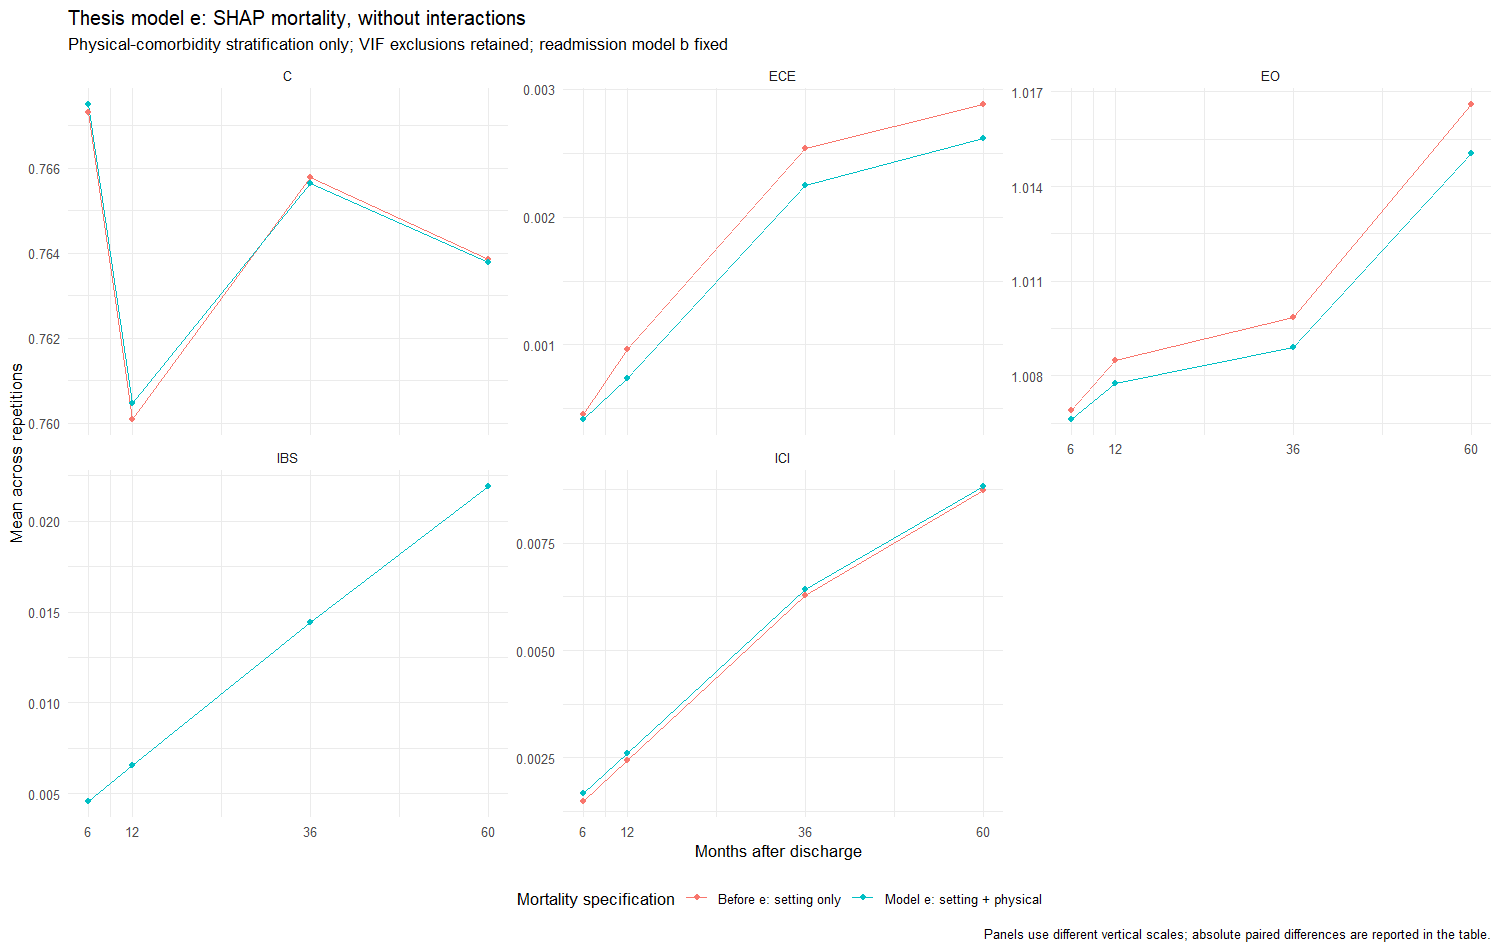

Model e/A accepted after subgroup review. Model b unchanged. Prepare c/f only; their predictive comparison has not run.


Elapsed: 1.049 minutes


In [58]:
#| label: shap-mortality-physical-checkpoint
#| message: true
.t0 <- proc.time()
# Validate every new prediction task against its exact previous fold before reporting candidate b/e.
if (mortality_step_run) {
  n_participants <- nrow(py_corrected_datasets[[1L]])
  before_calibration <- list(readmission = readmission_step_calibration, death = vif_calibration_values$death)
  comparison_rows <- coverage_rows <- zero_rows <- list()
  previous_mortality_zero_entries <- 0L
  for (outcome in c("readmission", "death")) {
    current <- mortality_step_calibration[[outcome]]
    previous <- before_calibration[[outcome]]
    aj <- outcome == "readmission"
    metrics <- if (aj) current$value$by_repetition else current$value$rep_results
    stopifnot(nrow(metrics) == 80L, identical(as.numeric(metrics$time_months), rep(performance_horizons, 20L)), all(is.finite(as.matrix(metrics[, c("ici", "ece", "eo_ratio")]))))
    if (aj) stopifnot(all(metrics$n_input == n_participants), all(metrics$n_analysis == n_participants), all(metrics$n_dropped == 0L), all(metrics$n_used_calibration == n_participants), all(metrics$n_excluded_calibration == 0L), all(metrics$n_imputations == 5L))
    # Check all KM calibration groups too; prediction coverage alone does not certify their inclusion.
    if (!aj) {
      curves <- current$value$calibration_curves
      used <- stats::aggregate(list(n = curves$n_patients * curves$n_reps), list(Horizon = curves$time_months), sum)
      stopifnot(nrow(used) == length(performance_horizons), setequal(used$Horizon, performance_horizons), all(abs(used$n - n_participants * 20L) < 1e-8))
    }
    pooled <- current$value$pooled_summary
    recalculated <- stats::aggregate(cbind(ici, ece, eo_ratio) ~ time_months, metrics, mean)
    recalculated <- recalculated[match(pooled$time_months, recalculated$time_months), ]
    stopifnot(max(abs(as.matrix(recalculated[, c("ici", "ece", "eo_ratio")]) - as.matrix(pooled[, c("ici_mean", "ece_mean", "eo_mean")]))) < 1e-12)
    minimum_risk <- Inf
    maximum_risk <- -Inf
    zero_predictions <- 0L
    for (repetition in seq_len(20L)) {
      indices <- integer()
      for (fold in seq_len(5L)) {
        suffix <- sprintf("_r%02d_f%02d", repetition, fold)
        paths <- lapply(c(current$prefix, previous$prefix), function(prefix) list.files(object_dir, pattern = paste0("^perf07_", prefix, suffix, "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE))
        stopifnot(all(lengths(paths) == 1L))
        objects <- lapply(paths, function(path) readRDS(path[[1L]]))
        stopifnot(all(vapply(objects, function(x) identical(x$signature, performance_signature) && identical(x$value$r, repetition), logical(1L))))
        row_name <- if (aj) "te_idx" else "test_idx"
        risk_name <- if (aj) "pred_fold_avg" else "risk_mat"
        rows <- objects[[1L]]$value[[row_name]]
        risk <- objects[[1L]]$value[[risk_name]]
        stopifnot(identical(rows, objects[[2L]]$value[[row_name]]), identical(dim(risk), c(length(rows), length(performance_horizons))), all(is.finite(risk)), all(risk >= 0 & risk <= 1))
        if (!aj) {
          stopifnot(objects[[1L]]$value$fi == fold)
          previous_mortality_zero_entries <- previous_mortality_zero_entries + sum(objects[[2L]]$value$risk_mat == 0)
          # Flag zero horizon risks without omitting patients or changing their predictions.
          for (h in seq_along(performance_horizons)) {
            ids <- rows[risk[, h] == 0]
            if (!length(ids)) next
            training_deaths <- lapply(py_corrected_datasets, function(di) {
              group <- paste(di$plan_type_strata, di$any_phys_dx, sep = "|")
              counts <- tapply(as.integer(di$death_event[-rows] == 1 & di$death_time_from_disch_m[-rows] <= performance_horizons[h]), group[-rows], sum)
              as.integer(counts[group[ids]])
            })
            di <- py_corrected_datasets[[1L]]
            zero_rows[[length(zero_rows) + 1L]] <- data.frame(Repetition = repetition, Horizon = performance_horizons[h], Index = ids, Setting = as.character(di$plan_type_strata[ids]), Physical = di$any_phys_dx[ids], Maximum_training_deaths = do.call(pmax, training_deaths), Observed_death_before_horizon = di$death_event[ids] == 1 & di$death_time_from_disch_m[ids] <= performance_horizons[h])
          }
        }
        indices <- c(indices, rows)
        minimum_risk <- min(minimum_risk, risk)
        maximum_risk <- max(maximum_risk, risk)
        zero_predictions <- zero_predictions + sum(risk == 0)
      }
      stopifnot(length(indices) == n_participants, all(indices >= 1L & indices <= n_participants))
      assert_prediction_coverage(tabulate(indices, nbins = n_participants))
    }
    before <- previous$value$pooled_summary
    after <- pooled[match(before$time_months, pooled$time_months), ]
    comparison_rows[[outcome]] <- data.frame(Outcome = outcome, Horizon = before$time_months, ICI_before = before$ici_mean, ICI_after = after$ici_mean, Delta_ICI = after$ici_mean - before$ici_mean, ECE_before = before$ece_mean, ECE_after = after$ece_mean, Delta_ECE = after$ece_mean - before$ece_mean, EO_before = before$eo_mean, EO_after = after$eo_mean, Delta_EO = after$eo_mean - before$eo_mean)
    coverage_rows[[outcome]] <- data.frame(Outcome = outcome, Participants_per_repetition = n_participants, Repetitions = 20L, Prediction_tasks = 100L, Omitted = 0L, Paired_fold_indices_identical = TRUE, Minimum_predicted_risk = minimum_risk, Maximum_predicted_risk = maximum_risk, Zero_risk_entries = zero_predictions)
  }
  mortality_step_calibration_comparison <- do.call(rbind, comparison_rows)
  mortality_step_completeness <- do.call(rbind, coverage_rows)
  # Distinguish horizon-specific lack of deaths from a stratum with no deaths over all follow-up.
  zero_detail <- if (length(zero_rows)) do.call(rbind, zero_rows) else data.frame(Horizon = numeric(), Index = integer(), Setting = character(), Maximum_training_deaths = integer(), Observed_death_before_horizon = logical())
  mortality_zero_horizon <- do.call(rbind, lapply(performance_horizons, function(h) {
    z <- zero_detail[zero_detail$Horizon == h, ]
    data.frame(Horizon = h, Zero_prediction_entries = nrow(z), Distinct_people = length(unique(z$Index)), Death_entries_before_horizon = sum(z$Observed_death_before_horizon), Distinct_people_with_death = length(unique(z$Index[z$Observed_death_before_horizon])), Maximum_training_deaths_before_horizon = max(c(0L, z$Maximum_training_deaths)), Setting_codes = paste(sort(unique(z$Setting)), collapse = "; "))
  }))
  stopifnot(!anyNA(zero_detail), all(zero_detail$Maximum_training_deaths == 0L), nrow(zero_detail) == mortality_step_completeness$Zero_risk_entries[mortality_step_completeness$Outcome == "death"])
  show_table(mortality_zero_horizon, "Model e: zero predicted risks by horizon; entries count person x repetition x horizon, not distinct people")
  cat("Zero mortality prediction entries with the setting-only predecessor:", previous_mortality_zero_entries, "\n")
  cat("Every zero risk above corresponds to no training death before that horizon in the patient's stratum, in all five imputations. All patients remain in evaluation. This does not establish a true zero mortality probability. No fallback or prediction correction was applied.\n")
  death_change <- comparison_rows$death
  death_change$Outcome <- NULL
  mortality_step_comparison <- merge(mortality_step_comparison, death_change, by = "Horizon")
  show_table(mortality_step_comparison, "Model e versus its setting-only SHAP predecessor; model b unchanged")
  show_table(mortality_step_calibration_comparison, "Both calibration targets after changing only the mortality specification")
  show_table(mortality_step_completeness, "All participants predicted in all calibration repetitions; no omission or fallback")
  # Report only the now-comparable SHAP b/e points, without transferring historical intervals.
  mortality_step_published <- published_shap_points
  mortality_step_published$New <- vapply(seq_len(nrow(mortality_step_published)), function(i) {
    row <- mortality_step_published[i, ]
    outcome <- row$Outcome
    if (row$Metric %in% c("C", "IBS")) {
      values <- if (outcome == "readmission") readmission_step_metrics else mortality_step_metrics
      return(values[values$Horizon == row$Horizon, row$Metric])
    }
    values <- mortality_step_calibration[[outcome]]$value$pooled_summary
    column <- if (row$Metric == "ICI") "ici_mean" else "eo_mean"
    stopifnot(row$Metric %in% c("ICI", "EO"))
    values[values$time_months == row$Horizon, column]
  }, numeric(1L))
  mortality_step_published$Difference_from_published <- mortality_step_published$New - mortality_step_published$Previous_published
  mortality_step_published$New_rounded <- mapply(round, mortality_step_published$New, mortality_step_published$Published_decimals)
  mortality_step_published$Classification <- ifelse(mortality_step_published$New_rounded == mortality_step_published$Previous_published, "trivial: published rounding unchanged", "substantial: published rounding changes; investigator review")
  stopifnot(nrow(mortality_step_published) == 32L, all(is.finite(mortality_step_published$New)))
  show_table(mortality_step_published, "Table 2: current models b/e versus published SHAP points; no historical confidence intervals transferred")
  destination <- file.path(table_dir, paste0("Table2_SHAP_b_e_candidate_", Sys.Date(), "_", performance_signature, ".csv"))
  utils::write.csv(mortality_step_published, destination, row.names = FALSE, na = "")
  written <- c(written, destination)
  long <- do.call(rbind, lapply(c("C", "IBS", "ICI", "ECE", "EO"), function(metric) do.call(rbind, lapply(c("before", "after"), function(stage) data.frame(Horizon = mortality_step_comparison$Horizon, Metric = metric, Model = if (stage == "before") "Before e: setting only" else "Model e: setting + physical", Value = mortality_step_comparison[[paste(metric, stage, sep = "_")]])))))
  plot <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Model, group = Model)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(~Metric, scales = "free_y", ncol = 3) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "Thesis model e: SHAP mortality, without interactions", subtitle = "Physical-comorbidity stratification only; VIF exclusions retained; readmission model b fixed", x = "Months after discharge", y = "Mean across repetitions", color = "Mortality specification", caption = "Panels use different vertical scales; absolute paired differences are reported in the table.") + ggplot2::theme_minimal() + ggplot2::theme(legend.position = "bottom")
  show_diagnostic_png(function() print(plot), width = 1500L, height = 950L)
  mortality_step_complete <- TRUE
  review_pending <- !mortality_step_review_accepted
  cat(if (mortality_step_review_accepted) "Model e/A accepted after subgroup review. Model b unchanged. Prepare c/f only; their predictive comparison has not run.\n" else "Model e comparison complete. STOP for investigator review before interaction models c/f.\n")
} else cat("Model e prepared: no new predictive results yet. Its actual C/IBS, KM and AJ run requires the resource scheduling checkpoint.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


## Prepared interaction models c and f
The accepted bases remain b and e. Construct c/f with the original hierarchy and category rules; retain responses and strata. **Prepared does not mean fitted, selected or better performing.**

Readmission c also requires alcohol as first substance used as a main effect because it participates in a product. This follows the original hierarchy rule. Physical-assessment terms in f describe assessment at discharge, not the physical-comorbidity stratum.


In [59]:
#| label: shap-interaction-formulas
#| message: true
.t0 <- proc.time()
# Construct only after the accepted b/e evidence and signature have been verified.
stopifnot(readmission_step_review_accepted, mortality_step_review_accepted, mortality_step_complete, !review_pending)
interaction_formulas <- interaction_additions <- list()
for (outcome in names(interaction_bases)) {
  base <- interaction_bases[[outcome]]
  rows <- interaction_preview[interaction_preview$Outcome == outcome & interaction_preview$Eligible, ]
  products <- rows$Product
  parents <- unique(unlist(strsplit(products, ":", fixed = TRUE)))
  added_parents <- setdiff(parents, all.vars(base[[3L]]))
  stopifnot(length(products) > 0L, !any(c(parents, added_parents) %in% c(removed_collinear, formula_strata(base))))
  candidate <- stats::update(base, stats::as.formula(paste(". ~ . +", paste(c(added_parents, products), collapse = " + "))))
  stopifnot(identical(deparse(candidate[[2L]]), deparse(base[[2L]])), identical(formula_strata(candidate), formula_strata(base)), !removed_collinear %in% all.vars(candidate))
  stopifnot(all(canonical_terms(formula_terms(base)) %in% canonical_terms(formula_terms(candidate))), setequal(setdiff(canonical_terms(formula_terms(candidate)), canonical_terms(formula_terms(base))), canonical_terms(c(added_parents, products))))
  stopifnot(all(parents %in% formula_terms(candidate)))
  interaction_formulas[[outcome]] <- candidate
  interaction_additions[[outcome]] <- data.frame(Outcome = outcome, Type = c(rep("Required main effect", length(added_parents)), rep("Interaction product", length(products))), Term = c(added_parents, products), Label = c(display_term(added_parents), rows$Label), stringsAsFactors = FALSE)
}
formula_shap_readmit_interact <- interaction_formulas$Readmission
formula_shap_death_interact <- interaction_formulas$Death
thesis_formulas$c <- formula_shap_readmit_interact
thesis_formulas$f <- formula_shap_death_interact
thesis_formulas <- thesis_formulas[c("a", "b", "c", "d", "e", "f")]
interaction_additions <- do.call(rbind, interaction_additions)
interaction_summary <- do.call(rbind, lapply(names(interaction_bases), function(outcome) {
  added <- interaction_additions[interaction_additions$Outcome == outcome, ]
  data.frame(Outcome = outcome, Base = if (outcome == "Readmission") "b" else "e", Candidate = if (outcome == "Readmission") "c" else "f", Base_terms = sum(!startsWith(formula_terms(interaction_bases[[outcome]]), "strata(")), Added_main_effects = sum(added$Type == "Required main effect"), Added_products = sum(added$Type == "Interaction product"), Candidate_terms = sum(!startsWith(formula_terms(interaction_formulas[[outcome]]), "strata(")), Strata = paste(display_term(formula_strata(interaction_formulas[[outcome]])), collapse = "; "))
}))
interaction_signature <- substr(digest::digest(list(performance_signature, shap_input_hashes[["cox_shap_interactions"]], lapply(interaction_formulas, deparse), interaction_preview), algo = "sha256"), 1L, 12L)
show_table(interaction_additions, "Exact additions to accepted b/e; all base terms and strata remain")
show_table(interaction_summary, "Prepared formulas: extra complexity is visible before fitting")
for (model in c("c", "f")) { cat("Prepared thesis model", model, "(evaluation reported below):", fill = TRUE); print(thesis_formulas[[model]]) }
cat("Interaction preparation signature:", interaction_signature, fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)

Outcome,Type,Term,Label
Readmission,Required main effect,"Alcohol, first substance used","Alcohol, first substance used"
Readmission,Interaction product,primary_sub_mod_cocaine_powder:first_sub_used_alcohol,"Cocaine hydrochloride (primary at admission) x Alcohol, first substance used"
Readmission,Interaction product,eva_consumo_logro_intermedio:tr_outcome_referral,"Discharge evaluation, substance use: intermediate achievement x Discharge: referral"
Readmission,Interaction product,eva_consumo_logro_minimo:tr_outcome_referral,"Discharge evaluation, substance use: minimum achievement x Discharge: referral"
Readmission,Interaction product,sex_rec_woman:primary_sub_mod_others,Women x Other substance (primary at admission)
Death,Interaction product,primary_sub_mod_alcohol:adm_age_rec3,"Alcohol (primary at admission) x Age at admission, yr"
Death,Interaction product,occupation_condition_corr24_unemployed:adm_age_rec3,"Unemployed x Age at admission, yr"
Death,Interaction product,primary_sub_mod_alcohol:prim_sub_freq_rec_2_2_6_days_wk,"Alcohol (primary at admission) x Use frequency, primary substance: 2-6 days/week"
Death,Interaction product,primary_sub_mod_alcohol:prim_sub_freq_rec_3_daily,"Alcohol (primary at admission) x Use frequency, primary substance: daily"
Death,Interaction product,cohabitation_with_couple_children:adm_age_rec3,"Lives with partner or children x Age at admission, yr"


Outcome,Base,Candidate,Base_terms,Added_main_effects,Added_products,Candidate_terms,Strata
Readmission,b,c,26,1,4,31,Treatment setting; Administrative discharge: rule violation or undetermined reason
Death,e,f,25,0,7,32,Treatment setting; Any selected physical comorbidity recorded


Prepared thesis model c (evaluation reported below):
Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + 
    primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + 
    primary_sub_mod_others + adm_age_rec3 + porc_pobr + sex_rec_woman + 
    ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + 
    ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + 
    occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + 
    dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + 
    polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + 
    tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + 
    evaluacindelprocesoteraputico_logro_intermedio + prim_sub_freq_rec_2_2_6_days_wk + 
    prim_sub_freq_rec_3_daily + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet) + 
    first_sub_u

Interaction preparation signature: 055abb8765fc


Elapsed: 0.002 minutes


In [60]:
#| label: shap-interaction-design-checks
#| message: true
.t0 <- proc.time()
# Check the first-imputation design without estimating a survival model or a VIF.
interaction_design <- interaction_support <- list()
for (outcome in names(interaction_formulas)) {
  formula <- interaction_formulas[[outcome]]
  needed <- all.vars(formula)
  stopifnot(all(vapply(py_corrected_datasets, function(d) all(needed %in% names(d)) && all(stats::complete.cases(d[, needed])), logical(1L))))
  d <- py_corrected_datasets[[1L]]
  ordinary <- formula_terms(formula)[!startsWith(formula_terms(formula), "strata(")]
  matrix <- stats::model.matrix(stats::reformulate(ordinary), d)
  matrix <- matrix[, colnames(matrix) != "(Intercept)", drop = FALSE]
  stopifnot(nrow(matrix) == nrow(d), all(is.finite(matrix)))
  strata <- strata_codes(d, formula_strata(formula))
  groups <- match(strata, unique(strata))
  means <- rowsum(matrix, groups, reorder = FALSE) / tabulate(groups)
  centered <- matrix - means[groups, , drop = FALSE]
  rank <- qr(centered)$rank
  interaction_design[[outcome]] <- data.frame(Outcome = outcome, Imputation = 1L, Participants = nrow(d), Matrix_columns = ncol(matrix), Rank_within_strata = rank, Full_rank = rank == ncol(matrix), Status = "No Cox fit; finite predictions and full coverage checked during CV")
  products <- interaction_preview$Product[interaction_preview$Outcome == outcome & interaction_preview$Eligible]
  event <- d[[if (outcome == "Readmission") "readmit_event" else "death_event"]] == 1L
  interaction_support[[outcome]] <- do.call(rbind, lapply(products, function(product) {
    parts <- strsplit(product, ":", fixed = TRUE)[[1L]]
    active <- as.numeric(d[[parts[[1L]]]]) * as.numeric(d[[parts[[2L]]]]) != 0
    data.frame(Outcome = outcome, Product = product, Nonzero_people = sum(active), Events_among_nonzero = sum(event & active), Zero_event_joint_strata_among_nonzero = sum(tapply(as.integer(event[active]), factor(strata[active]), sum) == 0L))
  }))
  rm(matrix, centered, means)
}
interaction_design <- do.call(rbind, interaction_design)
interaction_support <- do.call(rbind, interaction_support)
show_table(interaction_design, "First-imputation design: exact linear dependence check within accepted strata")
show_table(interaction_support, "First-imputation descriptive product support over full follow-up; not CV support or a selection threshold")
stopifnot(all(interaction_design$Full_rank), all(interaction_support$Nonzero_people > 0L))
cat("No patient is removed. Full rank does not establish stable CV predictions. Prediction completeness and finite values remain required; no new PH/VIF is scheduled.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)

Outcome,Imputation,Participants,Matrix_columns,Rank_within_strata,Full_rank,Status
Readmission,1,70521,31,31,TRUE,No Cox fit; finite predictions and full coverage checked during CV
Death,1,70521,32,32,TRUE,No Cox fit; finite predictions and full coverage checked during CV


Outcome,Product,Nonzero_people,Events_among_nonzero,Zero_event_joint_strata_among_nonzero
Readmission,primary_sub_mod_cocaine_powder:first_sub_used_alcohol,7084,1469,0
Readmission,eva_consumo_logro_intermedio:tr_outcome_referral,3514,800,0
Readmission,eva_consumo_logro_minimo:tr_outcome_referral,2857,763,0
Readmission,sex_rec_woman:primary_sub_mod_others,654,108,1
Death,primary_sub_mod_alcohol:adm_age_rec3,23975,1783,0
Death,occupation_condition_corr24_unemployed:adm_age_rec3,24498,1185,0
Death,primary_sub_mod_alcohol:prim_sub_freq_rec_2_2_6_days_wk,12295,673,0
Death,primary_sub_mod_alcohol:prim_sub_freq_rec_3_daily,8525,972,0
Death,cohabitation_with_couple_children:adm_age_rec3,31663,1232,0
Death,eva_fisica_logro_intermedio:adm_age_rec3,21987,962,0


No patient is removed. Full rank does not establish stable CV predictions. Prediction completeness and finite values remain required; no new PH/VIF is scheduled.


Elapsed: 0.010 minutes


Step,Before,Candidate,Fixed_partner,Review,Status
1: readmission interactions,b + e,c + e,Mortality e in both AJ predictions,Review b versus c before progressing,Reviewed: retain b
2: mortality interactions,b + e,b + f,Readmission b fixed,Review e versus f before functional forms,Reviewed: retain e; cached comparison only


Comparison,C_IBS_new_fits,AJ_new_fits,KM_new_fits,Status
b versus c; e fixed,250,1000,0,Cached comparison only
e versus f; reviewed readmission fixed,250,1000,500,Reviewed: cache only; no new fits


C/IBS remains 10 x 5 x 5; Graf IBS is integrated from zero, not a mean of horizons. Calibration remains 20 x 5 x 5, with ICI, ECE and E/O shown together. No new PH/VIF is required for this checkpoint. Keep finite predictions and complete coverage; no automatic winner.


Historical difference: original shap-criteria-int2-cal omitted formula_death and reused the readmission RHS for mortality. Current 07 already names both formulas. Prepared c/e follows current b/e pairing, not the old omitted default. No original result is overwritten.


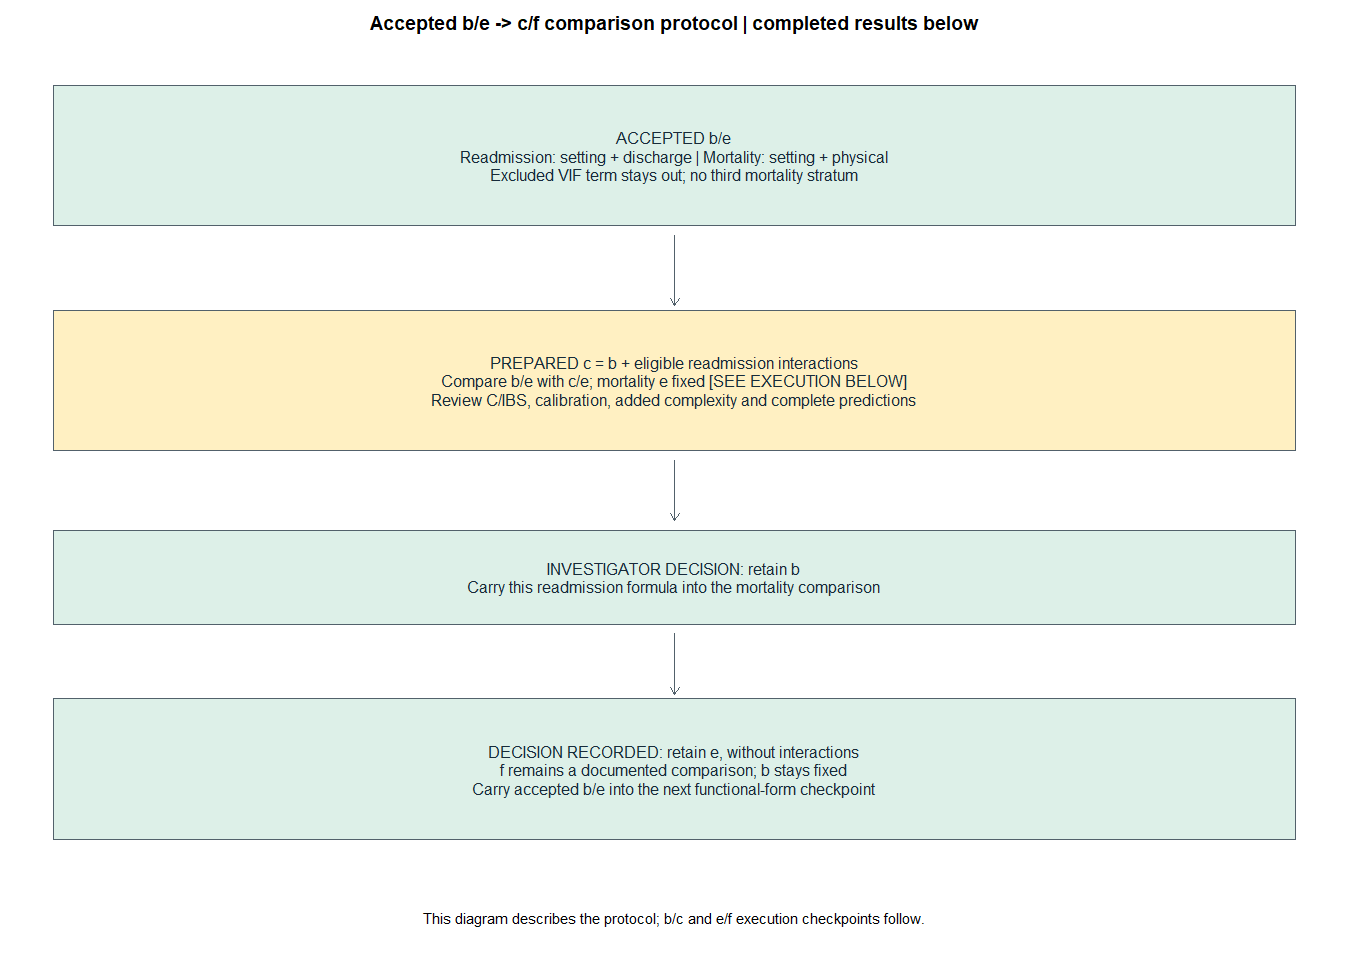

c/f are candidates only. The b/c evaluation block below is gated by its explicit resource scheduling mode.


Elapsed: 0.001 minutes


In [61]:
#| label: shap-interaction-comparison-contract
#| message: true
.t0 <- proc.time()
# Name both cause-specific partners and keep the two investigator decisions separate.
# Bind the recorded investigator choice to the current data, formulas and scoring signature.
mortality_interaction_decision <- shap_settings$mortality_interaction_decision
mortality_interaction_review_accepted <- is.list(mortality_interaction_decision) && identical(mortality_interaction_decision$signature, interaction_signature) && identical(mortality_interaction_decision$choice, "e")
mortality_interaction_choice <- if (mortality_interaction_review_accepted) mortality_interaction_decision$choice else NA_character_
interaction_decision <- shap_settings$readmission_interaction_decision
readmission_interaction_review_accepted <- is.list(interaction_decision) && identical(interaction_decision$signature, interaction_signature) && interaction_decision$choice %in% c("b", "c")
readmission_interaction_choice <- if (readmission_interaction_review_accepted) interaction_decision$choice else NA_character_
interaction_comparison_plan <- data.frame(Step = c("1: readmission interactions", "2: mortality interactions"), Before = c("b + e", "accepted readmission (b or c) + e"), Candidate = c("c + e", "same accepted readmission + f"), Fixed_partner = c("Mortality e in both AJ predictions", "Same accepted readmission formula in both AJ predictions"), Review = c("Review b versus c before progressing", "Review e versus f before functional forms"), Status = c(if (identical(shap_settings$interaction_mode, "readmission")) "Execution enabled below; cached results reused" else "Prepared; not executed", "Prepared; not executed"), stringsAsFactors = FALSE)
if (readmission_interaction_review_accepted) {
  interaction_comparison_plan$Status[interaction_comparison_plan$Step == "1: readmission interactions"] <- paste("Reviewed: retain", readmission_interaction_choice)
  interaction_comparison_plan$Before[interaction_comparison_plan$Step == "2: mortality interactions"] <- paste(readmission_interaction_choice, "+ e")
  interaction_comparison_plan$Candidate[interaction_comparison_plan$Step == "2: mortality interactions"] <- paste(readmission_interaction_choice, "+ f")
  interaction_comparison_plan$Fixed_partner[interaction_comparison_plan$Step == "2: mortality interactions"] <- paste("Readmission", readmission_interaction_choice, "fixed")
}
if (identical(shap_settings$interaction_mode, "mortality")) interaction_comparison_plan$Status[2L] <- "Execution authorized; results below"
if (mortality_interaction_review_accepted) interaction_comparison_plan$Status[interaction_comparison_plan$Step == "2: mortality interactions"] <- "Reviewed: retain e; cached comparison only"
show_table(interaction_comparison_plan, "One outcome changes at each checkpoint; historical omitted-default AJ is not this pair")
show_table(data.frame(Comparison = c("b versus c; e fixed", "e versus f; reviewed readmission fixed"), C_IBS_new_fits = rep(10L * 5L * 5L, 2L), AJ_new_fits = rep(20L * 5L * 5L * 2L, 2L), KM_new_fits = c(0L, 20L * 5L * 5L), Status = c(if (identical(shap_settings$interaction_mode, "readmission")) "Authorized scope; actual fits reported below" else "Cached comparison only", if (mortality_interaction_review_accepted) "Reviewed: cache only; no new fits" else if (identical(shap_settings$interaction_mode, "mortality")) "Execution authorized" else "Not scheduled")), "Future comparison scope using existing engines; saved base results reused")
cat("C/IBS remains 10 x 5 x 5; Graf IBS is integrated from zero, not a mean of horizons. Calibration remains 20 x 5 x 5, with ICI, ECE and E/O shown together. No new PH/VIF is required for this checkpoint. Keep finite predictions and complete coverage; no automatic winner.", fill = TRUE)
cat("Historical difference: original shap-criteria-int2-cal omitted formula_death and reused the readmission RHS for mortality. Current 07 already names both formulas. Prepared c/e follows current b/e pairing, not the old omitted default. No original result is overwritten.", fill = TRUE)
show_diagnostic_png(function() {
  decision_canvas("Accepted b/e -> c/f comparison protocol | completed results below")
  decision_box(0.04, 0.96, 0.88, "ACCEPTED b/e\nReadmission: setting + discharge | Mortality: setting + physical\nExcluded VIF term stays out; no third mortality stratum", "accepted", h = 0.075)
  decision_arrow(0.5, 0.795, y2 = 0.72)
  decision_box(0.04, 0.96, 0.64, "PREPARED c = b + eligible readmission interactions\nCompare b/e with c/e; mortality e fixed [SEE EXECUTION BELOW]\nReview C/IBS, calibration, added complexity and complete predictions", "prepared", h = 0.075)
  decision_arrow(0.5, 0.555, y2 = 0.49)
  decision_box(0.04, 0.96, 0.43, if (readmission_interaction_review_accepted) paste0("INVESTIGATOR DECISION: retain ", readmission_interaction_choice, "\nCarry this readmission formula into the mortality comparison") else "INVESTIGATOR REVIEW: retain b or accept c\nCarry the accepted readmission formula into the next comparison", if (readmission_interaction_review_accepted) "accepted" else "review", h = 0.05)
  decision_arrow(0.5, 0.37, y2 = 0.305)
  decision_box(0.04, 0.96, 0.225, if (mortality_interaction_review_accepted) "DECISION RECORDED: retain e, without interactions\nf remains a documented comparison; b stays fixed\nCarry accepted b/e into the next functional-form checkpoint" else "PREPARED f = e + eligible mortality interactions\nCompare e/f; reviewed readmission formula fixed [SEE EXECUTION BELOW]\nREVIEW before any functional-form or spline branch", if (mortality_interaction_review_accepted) "accepted" else "prepared", h = 0.075)
  graphics::text(0.5, 0.065, "This diagram describes the protocol; b/c and e/f execution checkpoints follow.", cex = 0.84)
}, 1350L, 980L)
interactions_prepared <- TRUE
stopifnot(performance_new_fits == 0L, new_model_fits == 0L, new_ph_tests == 0L)
cat("c/f are candidates only. The b/c evaluation block below is gated by its explicit resource scheduling mode.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)

## Readmission interaction comparison: b versus c, with e fixed
**Investigator decision:** evaluate whether interactions add predictive information through C, integrated IBS and calibration (prioritising ICI). No additional PH/VIF stage is required here. Keep the accepted strata and existing collinear-term exclusion. Valid finite fits/predictions, matched folds and inclusion of every person remain technical requirements.

The current run is preparation only unless `cox_shap.interaction_mode` is explicitly set to `readmission` after resource scheduling. Both baseline and candidate AJ predictions use mortality model e; the historical omitted mortality-formula default is not used. Review this comparison before any e/f evaluation.


In [62]:
#| label: shap-interaction-readmission-contract
#| message: true
.t0 <- proc.time()
# Register c only after both accepted bases have been verified; preserve the completed b/e stage.
stopifnot(shap_settings$interaction_mode %in% c("prepare", "readmission", "mortality"), identical(performance_settings$mode, "prepare"), readmission_step_review_accepted, mortality_step_review_accepted, mortality_step_complete)
interaction_c_run <- shap_settings$interaction_mode %in% c("readmission", "mortality")
interaction_c_complete <- FALSE
interaction_c_metrics <- interaction_c_repetitions <- interaction_c_coverage <- interaction_c_comparison <- interaction_c_calibration_comparison <- interaction_c_completeness <- data.frame()
interaction_c_calibration <- NULL
performance_formulas$readmission$interactions <- formula_shap_readmit_interact
candidate_formulas$readmission$interactions <- formula_shap_readmit_interact
calibration_pairs <- rbind(calibration_pairs, data.frame(Pair = "readmission_interactions", Readmission = "interactions", Death = "physical_stratum"))
interaction_c_key <- performance_formula_key("readmission", "interactions")
interaction_c_aj_key <- paste("cal_aj", interaction_c_key, performance_formula_key("death", "physical_stratum"), sep = "_")
interaction_allowed <- if (identical(shap_settings$interaction_mode, "readmission")) c(paste0("metrics_", interaction_c_key, "_r"), paste0("oof_", interaction_c_key, "_r"), interaction_c_aj_key) else character()
interaction_baseline_calibration <- mortality_step_calibration$readmission
stopifnot(identical(interaction_baseline_calibration$pair, "death_physical"), identical(candidate_formulas$death$physical_stratum, formula_shap_death_rule2), identical(candidate_formulas$readmission$discharge_stratum, formula_shap_readmit_clean_updated))
stopifnot(all(canonical_terms(formula_terms(formula_shap_readmit_clean_updated)) %in% canonical_terms(formula_terms(formula_shap_readmit_interact))), !removed_collinear %in% all.vars(formula_shap_readmit_interact))
show_table(data.frame(Model = c("b: accepted", "c: candidate"), Readmission = c("SHAP with setting + discharge strata", "Same b plus prepared interactions and required parent"), AJ_mortality_partner = "e: SHAP with setting + physical-comorbidity strata", C_IBS = "10 repetitions x 5 folds x 5 imputations", Calibration = "20 repetitions x 5 folds x 5 imputations"), "Exact paired comparison; neither PH/VIF nor the mortality specification changes")
cat("Mode:", shap_settings$interaction_mode, "| Available RAM GiB:", ps::ps_system_memory()$avail / 1024^3, "| Reserve GiB:", shap_settings$reserve_memory_gib, "| C/IBS workers:", performance_settings$workers, fill = TRUE)
cat("Uncached budget: 250 c C/IBS fits plus 1000 c/e AJ fits. Fixed e means a fixed formula; the existing AJ engine still fits both causes in each partition. No new KM, PH/VIF, imputations, tuning, SHAP or bootstrap. Baseline caches cannot be refitted here.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)

Model,Readmission,AJ_mortality_partner,C_IBS,Calibration
b: accepted,SHAP with setting + discharge strata,e: SHAP with setting + physical-comorbidity strata,10 repetitions x 5 folds x 5 imputations,20 repetitions x 5 folds x 5 imputations
c: candidate,Same b plus prepared interactions and required parent,e: SHAP with setting + physical-comorbidity strata,10 repetitions x 5 folds x 5 imputations,20 repetitions x 5 folds x 5 imputations


Mode: mortality | Available RAM GiB: 56.4146 | Reserve GiB: 20 | C/IBS workers: 
8


Uncached budget: 250 c C/IBS fits plus 1000 c/e AJ fits. Fixed e means a fixed formula; the existing AJ engine still fits both causes in each partition. No new KM, PH/VIF, imputations, tuning, SHAP or bootstrap. Baseline caches cannot be refitted here.


Elapsed: 0.001 minutes


In [63]:
#| label: shap-interaction-readmission-evaluate
#| message: true
.t0 <- proc.time()
# Reuse the exact C/IBS and complete twenty-repetition AJ engines; only c is new.
if (interaction_c_run) {
  stopifnot(performance_new_fits == 0L, new_model_fits == 0L, new_ph_tests == 0L, max(metric_control$Maximum_absolute_difference) < 1e-8, max(calibration_historical_control$Maximum_absolute_difference) < 1e-8)
  tasks <- lapply(seq_len(10L), function(r) list(Outcome = "readmission", Stage = "interactions", Repetition = r))
  results <- performance_parallel(tasks)
  for (result in results) { record_performance_fits(result$new_fits); written <- c(written, result$written) }
  interaction_c_repetitions <- do.call(rbind, lapply(results, function(x) x$table))
  interaction_c_coverage <- do.call(rbind, lapply(results, function(x) x$coverage))
  stopifnot(nrow(interaction_c_repetitions) == 40L, !anyDuplicated(interaction_c_repetitions[, c("Repetition", "Horizon")]), all(is.finite(as.matrix(interaction_c_repetitions[, c("C", "IBS")]))))
  stopifnot(nrow(interaction_c_coverage) == 10L, all(interaction_c_coverage$Expected == interaction_c_coverage$Predicted), all(interaction_c_coverage$Omitted == 0L))
  interaction_c_metrics <- stats::aggregate(cbind(C, IBS) ~ Horizon, interaction_c_repetitions, mean)
  paired <- merge(readmission_step_repetitions, interaction_c_repetitions, by = c("Repetition", "Horizon"), suffixes = c("_b", "_c"))
  stopifnot(nrow(paired) == 40L)
  paired$Delta_C <- paired$C_c - paired$C_b
  paired$Delta_IBS <- paired$IBS_c - paired$IBS_b
  interaction_c_comparison <- stats::aggregate(cbind(C_b, C_c, Delta_C, IBS_b, IBS_c, Delta_IBS) ~ Horizon, paired, mean)
  show_table(interaction_c_comparison, "b versus c: ten paired C/IBS repetitions; higher C and lower IBS are favourable")
  results <- performance_parallel(list(list(Kind = "readmission", Pair = "readmission_interactions")), worker = calibration_checkpoint_task)
  stopifnot(length(results) == 1L, identical(results[[1L]]$prefix, interaction_c_aj_key))
  interaction_c_calibration <- results[[1L]]
  record_performance_fits(interaction_c_calibration$new_fits)
  written <- c(written, interaction_c_calibration$written)
  show_table(interaction_c_calibration$value$pooled_summary, "Readmission c/e AJ calibration: complete 20 x 5 x 5; e formula fixed")
} else cat("Prepared only: no c model, C/IBS or calibration has been fitted. Resource scheduling is pending.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)

Horizon,C_b,C_c,Delta_C,IBS_b,IBS_c,Delta_IBS
6,0.6457,0.6464,7e-04,0.0387,0.0387,0
12,0.6327,0.6333,6e-04,0.0610,0.0610,0
36,0.6144,0.6147,3e-04,0.1085,0.1084,0
60,0.6093,0.6096,3e-04,0.1333,0.1333,0


time_months,ici_mean,ici_sd,ici_min,ici_p025,ici_p975,ici_max,e50_mean,e50_sd,e50_min,e50_p025,e50_p975,e50_max,e90_mean,e90_sd,e90_min,e90_p025,e90_p975,e90_max,emax_mean,emax_sd,emax_min,emax_p025,emax_p975,emax_max,ece_mean,ece_sd,ece_min,ece_p025,ece_p975,ece_max,eo_mean,eo_sd,eo_min,eo_p025,eo_p975,eo_max,mean_pred,mean_pred_sd,mean_pred_min,mean_pred_p025,mean_pred_p975,mean_pred_max,observed,observed_sd,observed_min,observed_p025,observed_p975,observed_max,n_runs,n_imp
6,0.0069,2e-04,0.0067,0.0067,0.0072,0.0072,0.0020,3e-04,0.0015,0.0015,0.0027,0.0027,0.0207,3e-04,0.0202,0.0202,0.0211,0.0211,0.4221,0.0168,0.3937,0.3937,0.4586,0.4586,0.0023,2e-04,0.0018,0.0018,0.0027,0.0027,0.9911,1e-04,0.9909,0.9909,0.9914,0.9914,0.0719,0,0.0719,0.0719,0.0719,0.0719,0.0726,0,0.0726,0.0726,0.0726,0.0726,20,5
12,0.0079,2e-04,0.0075,0.0075,0.0081,0.0081,0.0022,3e-04,0.0017,0.0017,0.0028,0.0028,0.0229,4e-04,0.0224,0.0224,0.0239,0.0239,0.4715,0.0200,0.4337,0.4337,0.5088,0.5088,0.0029,4e-04,0.0018,0.0018,0.0035,0.0035,0.9913,1e-04,0.9911,0.9911,0.9916,0.9916,0.1136,0,0.1135,0.1135,0.1136,0.1136,0.1146,0,0.1146,0.1146,0.1146,0.1146,20,5
36,0.0094,2e-04,0.0091,0.0091,0.0098,0.0098,0.0041,5e-04,0.0032,0.0032,0.0052,0.0052,0.0215,5e-04,0.0202,0.0202,0.0221,0.0221,0.5465,0.0205,0.5137,0.5137,0.5848,0.5848,0.0048,6e-04,0.0042,0.0042,0.0063,0.0063,0.9894,1e-04,0.9891,0.9891,0.9895,0.9895,0.1997,0,0.1997,0.1997,0.1997,0.1997,0.2019,0,0.2019,0.2019,0.2019,0.2019,20,5
60,0.0098,2e-04,0.0095,0.0095,0.0101,0.0101,0.0044,4e-04,0.0037,0.0037,0.0055,0.0055,0.0209,6e-04,0.0198,0.0198,0.0217,0.0217,0.5618,0.0210,0.5306,0.5306,0.5970,0.5970,0.0070,8e-04,0.0056,0.0056,0.0084,0.0084,0.9860,1e-04,0.9858,0.9858,0.9861,0.9861,0.2428,0,0.2427,0.2427,0.2428,0.2428,0.2462,0,0.2462,0.2462,0.2462,0.2462,20,5


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.264 minutes


Horizon,C_b,C_c,Delta_C,IBS_b,IBS_c,Delta_IBS,ICI_b,ICI_c,Delta_ICI,ECE_b,ECE_c,Delta_ECE,EO_b,EO_c,Delta_EO
6,0.6457,0.6464,7e-04,0.0387,0.0387,0,0.0068,0.0069,2e-04,0.0024,0.0023,0e+00,0.9910,0.9911,1e-04
12,0.6327,0.6333,6e-04,0.0610,0.0610,0,0.0078,0.0079,1e-04,0.0029,0.0029,0e+00,0.9912,0.9913,1e-04
36,0.6144,0.6147,3e-04,0.1085,0.1084,0,0.0092,0.0094,2e-04,0.0049,0.0048,-1e-04,0.9893,0.9894,1e-04
60,0.6093,0.6096,3e-04,0.1333,0.1333,0,0.0095,0.0098,3e-04,0.0064,0.0070,6e-04,0.9859,0.9860,1e-04


Participants_per_repetition,Repetitions,Prediction_tasks,Omitted,Paired_fold_indices_identical,Minimum_predicted_risk,Maximum_predicted_risk,Zero_risk_entries
70521,20,100,0,TRUE,0.0175,0.822,0


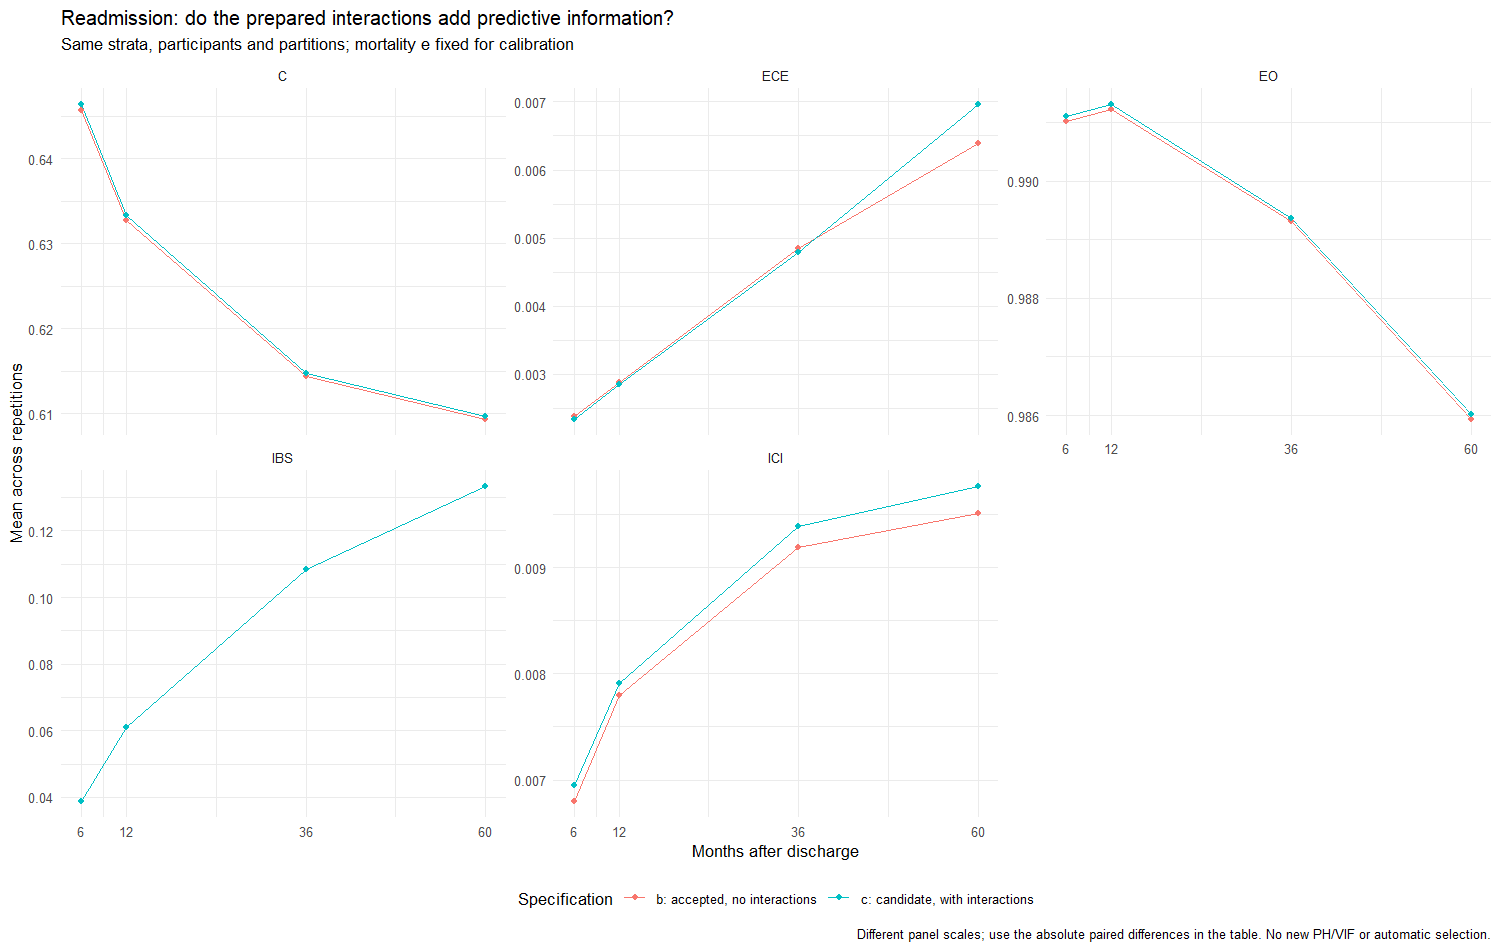

Horizon,Metric,b,c,Difference,b_rounded,c_rounded,Classification
6,C,0.6457,0.6464,7e-04,0.646,0.646,Trivial at displayed precision
12,C,0.6327,0.6333,6e-04,0.633,0.633,Trivial at displayed precision
36,C,0.6144,0.6147,3e-04,0.614,0.615,"Substantial rounding change; reviewed, retain b"
60,C,0.6093,0.6096,3e-04,0.609,0.610,"Substantial rounding change; reviewed, retain b"
6,IBS,0.0387,0.0387,0e+00,0.039,0.039,Trivial at displayed precision
12,IBS,0.0610,0.0610,0e+00,0.061,0.061,Trivial at displayed precision
36,IBS,0.1085,0.1084,0e+00,0.108,0.108,Trivial at displayed precision
60,IBS,0.1333,0.1333,0e+00,0.133,0.133,Trivial at displayed precision
6,ICI,0.0068,0.0069,2e-04,0.007,0.007,Trivial at displayed precision
12,ICI,0.0078,0.0079,1e-04,0.008,0.008,Trivial at displayed precision


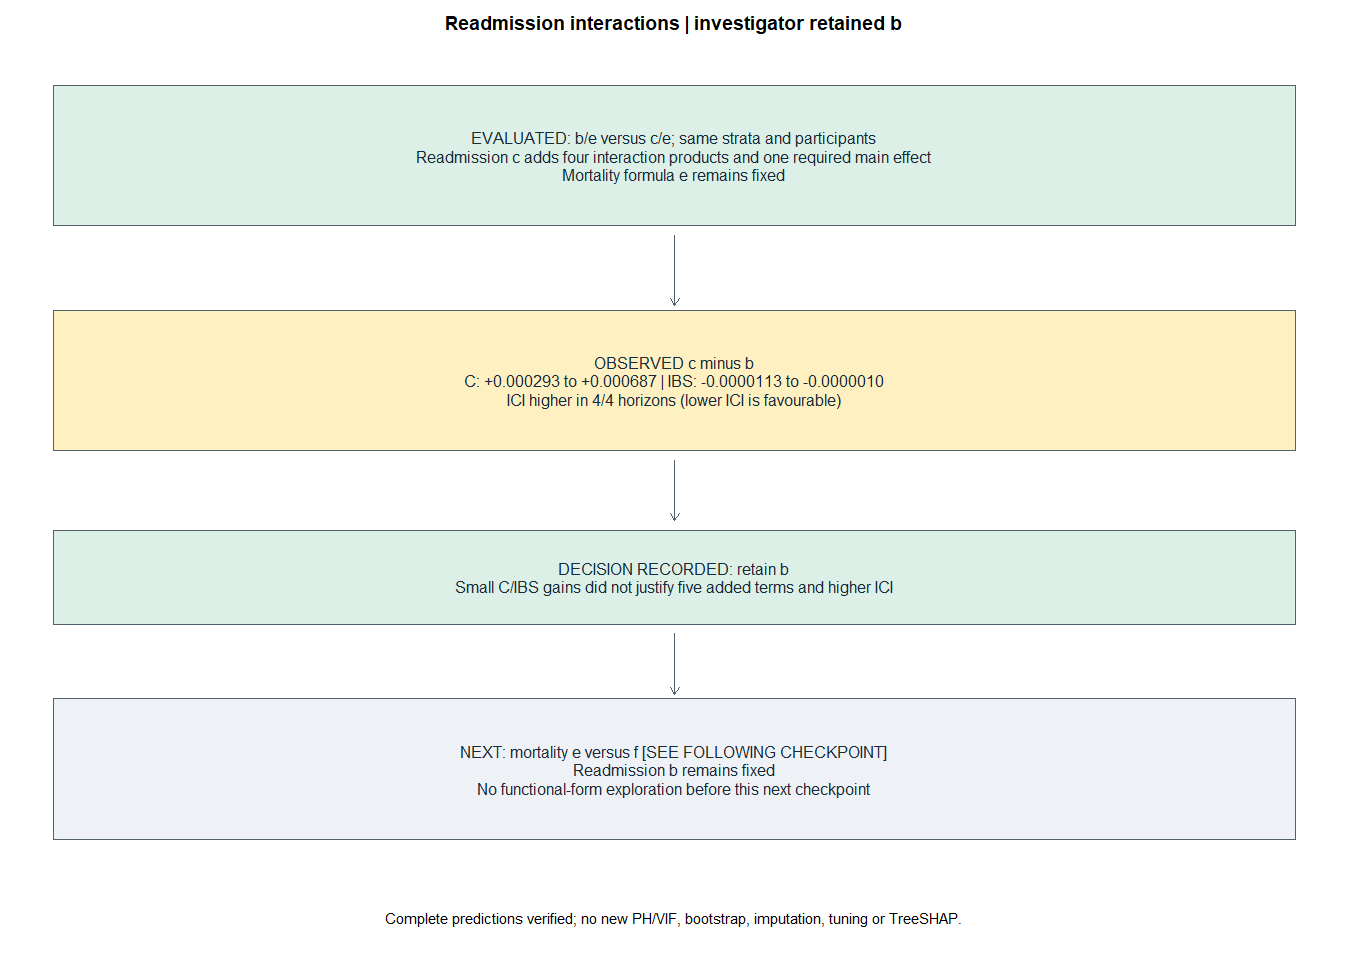

Review complete: investigator retained b 
. Mortality f is handled at the following checkpoint; functional forms remain unexecuted.


Elapsed: 0.512 minutes


In [64]:
#| label: shap-interaction-readmission-checkpoint
#| message: true
.t0 <- proc.time()
# Pair every AJ prediction task with the accepted b/e baseline and retain every participant.
if (interaction_c_run) {
  n_participants <- nrow(py_corrected_datasets[[1L]])
  current <- interaction_c_calibration
  previous <- interaction_baseline_calibration
  metrics <- current$value$by_repetition
  stopifnot(nrow(metrics) == 80L, identical(as.numeric(metrics$time_months), rep(performance_horizons, 20L)), all(is.finite(as.matrix(metrics[, c("ici", "ece", "eo_ratio")]))))
  stopifnot(all(metrics$n_input == n_participants), all(metrics$n_analysis == n_participants), all(metrics$n_dropped == 0L), all(metrics$n_used_calibration == n_participants), all(metrics$n_excluded_calibration == 0L), all(metrics$n_imputations == 5L))
  pooled <- current$value$pooled_summary
  recalculated <- stats::aggregate(cbind(ici, ece, eo_ratio) ~ time_months, metrics, mean)
  recalculated <- recalculated[match(pooled$time_months, recalculated$time_months), ]
  stopifnot(max(abs(as.matrix(recalculated[, c("ici", "ece", "eo_ratio")]) - as.matrix(pooled[, c("ici_mean", "ece_mean", "eo_mean")]))) < 1e-12)
  minimum_risk <- Inf
  maximum_risk <- -Inf
  zero_predictions <- 0L
  for (repetition in seq_len(20L)) {
    indices <- integer()
    for (fold in seq_len(5L)) {
      suffix <- sprintf("_r%02d_f%02d", repetition, fold)
      paths <- lapply(c(current$prefix, previous$prefix), function(prefix) list.files(object_dir, pattern = paste0("^perf07_", prefix, suffix, "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE))
      stopifnot(all(lengths(paths) == 1L))
      objects <- lapply(paths, function(path) readRDS(path[[1L]]))
      stopifnot(all(vapply(objects, function(x) identical(x$signature, performance_signature) && identical(x$value$r, repetition), logical(1L))))
      rows <- objects[[1L]]$value$te_idx
      risk <- objects[[1L]]$value$pred_fold_avg
      stopifnot(identical(rows, objects[[2L]]$value$te_idx), identical(dim(risk), c(length(rows), length(performance_horizons))), all(is.finite(risk)), all(risk >= 0 & risk <= 1))
      indices <- c(indices, rows)
      minimum_risk <- min(minimum_risk, risk)
      maximum_risk <- max(maximum_risk, risk)
      zero_predictions <- zero_predictions + sum(risk == 0)
    }
    stopifnot(length(indices) == n_participants, all(indices >= 1L & indices <= n_participants))
    assert_prediction_coverage(tabulate(indices, nbins = n_participants))
  }
  before <- previous$value$pooled_summary
  after <- pooled[match(before$time_months, pooled$time_months), ]
  interaction_c_calibration_comparison <- data.frame(Horizon = before$time_months, ICI_b = before$ici_mean, ICI_c = after$ici_mean, Delta_ICI = after$ici_mean - before$ici_mean, ECE_b = before$ece_mean, ECE_c = after$ece_mean, Delta_ECE = after$ece_mean - before$ece_mean, EO_b = before$eo_mean, EO_c = after$eo_mean, Delta_EO = after$eo_mean - before$eo_mean)
  interaction_c_comparison <- merge(interaction_c_comparison, interaction_c_calibration_comparison, by = "Horizon")
  interaction_c_completeness <- data.frame(Participants_per_repetition = n_participants, Repetitions = 20L, Prediction_tasks = 100L, Omitted = 0L, Paired_fold_indices_identical = TRUE, Minimum_predicted_risk = minimum_risk, Maximum_predicted_risk = maximum_risk, Zero_risk_entries = zero_predictions)
  show_table(interaction_c_comparison, "b versus c: all paired performance metrics; calibration uses the same mortality e partner")
  show_table(interaction_c_completeness, "All people retained; zero entries count person x repetition x horizon")
  long <- do.call(rbind, lapply(c("C", "IBS", "ICI", "ECE", "EO"), function(metric) do.call(rbind, lapply(c("b", "c"), function(model) data.frame(Horizon = interaction_c_comparison$Horizon, Metric = metric, Model = if (model == "b") "b: accepted, no interactions" else "c: candidate, with interactions", Value = interaction_c_comparison[[paste(metric, model, sep = "_")]])))))
  plot <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Model, group = Model)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(~Metric, scales = "free_y", ncol = 3) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "Readmission: do the prepared interactions add predictive information?", subtitle = "Same strata, participants and partitions; mortality e fixed for calibration", x = "Months after discharge", y = "Mean across repetitions", color = "Specification", caption = "Different panel scales; use the absolute paired differences in the table. No new PH/VIF or automatic selection.") + ggplot2::theme_minimal() + ggplot2::theme(legend.position = "bottom")
  show_diagnostic_png(function() print(plot), 1500L, 950L)
  # Separate small numerical changes from changes at the manuscript's displayed precision.
  interaction_rounding <- do.call(rbind, lapply(c("C", "IBS", "ICI", "EO"), function(metric) {
    digits <- if (metric == "EO") 2L else 3L
    before <- interaction_c_comparison[[paste0(metric, "_b")]]
    after <- interaction_c_comparison[[paste0(metric, "_c")]]
    data.frame(Horizon = interaction_c_comparison$Horizon, Metric = metric, b = before, c = after, Difference = after - before, b_rounded = round(before, digits), c_rounded = round(after, digits), Classification = ifelse(round(before, digits) == round(after, digits), "Trivial at displayed precision", if (readmission_interaction_review_accepted) paste("Substantial rounding change; reviewed, retain", readmission_interaction_choice) else "Substantial rounding change; review"))
  }))
  show_table(interaction_rounding, "Candidate b versus c using Table 2 precision; no manuscript point is replaced")
  # Display the completed comparison without selecting the next model automatically.
  show_diagnostic_png(function() {
    decision_canvas(if (readmission_interaction_review_accepted) paste("Readmission interactions | investigator retained", readmission_interaction_choice) else "Readmission interactions | comparison completed; choice pending")
    decision_box(0.04, 0.96, 0.88, "EVALUATED: b/e versus c/e; same strata and participants\nReadmission c adds four interaction products and one required main effect\nMortality formula e remains fixed", "accepted", h = 0.075)
    decision_arrow(0.5, 0.795, y2 = 0.72)
    decision_box(0.04, 0.96, 0.64, sprintf("OBSERVED c minus b\nC: %+.6f to %+.6f | IBS: %+.7f to %+.7f\nICI higher in %d/%d horizons (lower ICI is favourable)", min(interaction_c_comparison$Delta_C), max(interaction_c_comparison$Delta_C), min(interaction_c_comparison$Delta_IBS), max(interaction_c_comparison$Delta_IBS), sum(interaction_c_comparison$Delta_ICI > 0), nrow(interaction_c_comparison)), "prepared", h = 0.075)
    decision_arrow(0.5, 0.555, y2 = 0.49)
    decision_box(0.04, 0.96, 0.43, if (readmission_interaction_review_accepted) paste0("DECISION RECORDED: retain ", readmission_interaction_choice, "\nSmall C/IBS gains did not justify five added terms and higher ICI") else "INVESTIGATOR REVIEW PENDING: retain b or accept c\nWeigh C/IBS, calibration and the five added terms; no automatic winner", if (readmission_interaction_review_accepted) "accepted" else "review", h = 0.05)
    decision_arrow(0.5, 0.37, y2 = 0.305)
    decision_box(0.04, 0.96, 0.225, if (readmission_interaction_review_accepted) paste0("NEXT: mortality e versus f [SEE FOLLOWING CHECKPOINT]\nReadmission ", readmission_interaction_choice, " remains fixed\nNo functional-form exploration before this next checkpoint") else "NEXT, AFTER REVIEW: mortality e versus f [NOT RUN]\nKeep the reviewed readmission formula fixed\nNo functional-form exploration before this next checkpoint", "pending", h = 0.075)
    graphics::text(0.5, 0.065, "Complete predictions verified; no new PH/VIF, bootstrap, imputation, tuning or TreeSHAP.", cex = 0.82)
  }, 1350L, 980L)
  stopifnot(new_model_fits == 0L, new_ph_tests == 0L)
  interaction_c_complete <- TRUE
  review_pending <- !readmission_interaction_review_accepted
  if (readmission_interaction_review_accepted) cat("Review complete: investigator retained", readmission_interaction_choice, ". Mortality f is handled at the following checkpoint; functional forms remain unexecuted.", fill = TRUE) else cat("STOP for investigator review: retain b or accept c. No mortality-interaction f evaluation or functional-form fitting is authorized by this comparison. No bootstrap intervals were estimated.", fill = TRUE)
} else cat("No new interaction results to interpret; b/e remain accepted. The c comparison is prepared, not executed.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)

## Readmission interaction checkpoint: interpretation of the 2026-10-07 execution
**Investigator decision recorded 2026-10-08T00:00:44-03:00: retain b, without interactions. Candidate c remains documented and is not carried forward.**
The complete comparison gave c small C gains (0.000293 to 0.000687) and IBS reductions (0.0000010 to 0.0000113). ICI was slightly higher at every horizon (0.000105 to 0.000255). ECE improved at 6, 12 and 36 months but worsened at 60 months; E/O moved slightly closer to one. Given the investigator's priority for ICI and the five added terms, these results do not provide a compelling reason to carry c forward. This is descriptive comparison, not an equivalence claim or a bootstrap test.
C at 36 months rounds from 0.614 for b to 0.615 for c; at 60 months, from 0.609 to 0.610. These candidate differences cross the manuscript's displayed precision and were reviewed by the investigator. The selected model remains b. The preceding table identifies them; it does not replace manuscript values or transfer old intervals.
The run retained all 70,521 participants in every repetition. It used C/IBS 10 x 5 x 5 and AJ calibration 20 x 5 x 5, with mortality e fixed. Whole-development imputation and selection still precede internal CV; the previously documented limitation remains. No new PH/VIF, bootstrap, imputation, tuning or TreeSHAP was run, and f remains unevaluated.
The execution emitted 250 identical `survfit.coxph` warnings about the default curve for a model containing interactions. In the unchanged C/IBS engine, `basehaz()` is called only to check the number of strata; its default curve is not used as a patient's prediction. Actual predictions use `pec::predictSurvProb()` with explicit validation `newdata`. The finite-coefficient, finite-probability and full-coverage checks passed. The warnings are documented, not suppressed; no scoring code was changed.
Original full-run evidence: [execution record](../docs/07_readmission_interaction_execution.json). The full run took 49.20 minutes, with sampled peak R working memory 9.412 GiB and 1,250 new predictive Cox fits. Later cache-only presentation replays must not replace that record.


## Mortality: e versus f, with b fixed
The investigator authorized this full comparison. Model f adds only the seven prepared products to accepted e. Both retain treatment-setting and physical-comorbidity strata and exclude the collinear term. C/IBS uses ten paired repetitions; calibration uses twenty. The mortality formula also enters the readmission CIF, so both calibration targets are checked. Previous results are loaded from cache. No new PH/VIF, imputation, tuning, TreeSHAP or bootstrap is performed. Selection awaits investigator review after the results below.

**Completed scientific run (2026-10-08T01:10:55.434355-03:00):** 1,750 predictive Cox fits in 50.80 minutes; sampled peak R working set 9.851 GiB. Source: `../docs/07_mortality_interaction_execution.json`. Subsequent replays reuse these saved predictions and report zero new fits. Changes are displayed to eight decimals; estimates and rounding classifications use the original numeric values.


Outcome,Type,Term,Label
Death,Interaction product,primary_sub_mod_alcohol:adm_age_rec3,"Alcohol (primary at admission) x Age at admission, yr"
Death,Interaction product,occupation_condition_corr24_unemployed:adm_age_rec3,"Unemployed x Age at admission, yr"
Death,Interaction product,primary_sub_mod_alcohol:prim_sub_freq_rec_2_2_6_days_wk,"Alcohol (primary at admission) x Use frequency, primary substance: 2-6 days/week"
Death,Interaction product,primary_sub_mod_alcohol:prim_sub_freq_rec_3_daily,"Alcohol (primary at admission) x Use frequency, primary substance: daily"
Death,Interaction product,cohabitation_with_couple_children:adm_age_rec3,"Lives with partner or children x Age at admission, yr"
Death,Interaction product,eva_fisica_logro_intermedio:adm_age_rec3,"Discharge evaluation, physical health: intermediate achievement x Age at admission, yr"
Death,Interaction product,eva_fisica_logro_minimo:adm_age_rec3,"Discharge evaluation, physical health: minimum achievement x Age at admission, yr"


Model,Ordinary_terms,Strata,Readmission_partner,C_IBS,Calibration
"e: accepted, no interactions",25,Treatment setting + physical comorbidity,b fixed,10 repetitions x 5 folds x 5 imputations,20 repetitions x 5 folds x 5 imputations
"f: candidate, with interactions",32,Treatment setting + physical comorbidity,b fixed,10 repetitions x 5 folds x 5 imputations,20 repetitions x 5 folds x 5 imputations


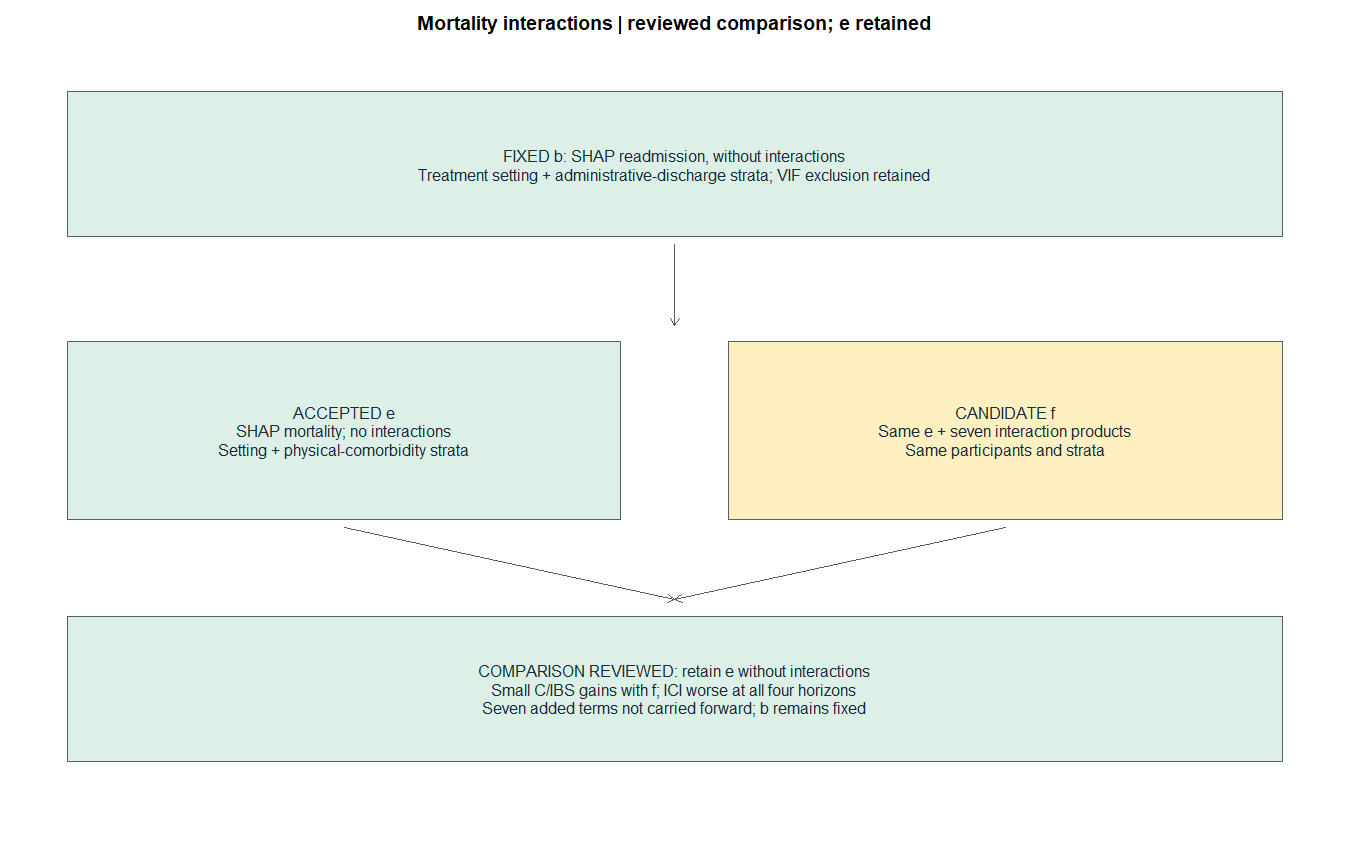

Investigator retained e. Reuse the complete e/f comparison; new fits are disabled and a missing cache stops execution.


Available RAM GiB: 56.6111 | Reserve GiB: 20 | Maximum C/IBS workers: 8 
| Complete single-thread calibration workers: 2


Elapsed: 0.001 minutes


In [65]:
#| label: shap-interaction-mortality-contract
#| message: true
.t0 <- proc.time()
# Only f may require new fits; accepted b/e and the reviewed c comparison must come from cache.
interaction_f_run <- identical(shap_settings$interaction_mode, "mortality")
interaction_f_complete <- FALSE
interaction_f_metrics <- interaction_f_repetitions <- interaction_f_coverage <- interaction_f_comparison <- interaction_f_calibration_comparison <- interaction_f_completeness <- interaction_f_zero_horizon <- interaction_f_rounding <- data.frame()
interaction_f_calibration <- list()
if (interaction_f_run) stopifnot(readmission_interaction_review_accepted, identical(readmission_interaction_choice, "b"), interaction_c_complete, !review_pending, performance_new_fits == 0L)
performance_formulas$death$interactions <- formula_shap_death_interact
candidate_formulas$death$interactions <- formula_shap_death_interact
calibration_pairs <- rbind(calibration_pairs, data.frame(Pair = "mortality_interactions", Readmission = "discharge_stratum", Death = "interactions"))
interaction_f_key <- performance_formula_key("death", "interactions")
interaction_f_aj_key <- paste("cal_aj", performance_formula_key("readmission", "discharge_stratum"), interaction_f_key, sep = "_")
interaction_f_km_key <- paste0("cal_km_", interaction_f_key)
interaction_allowed <- if (interaction_f_run && !mortality_interaction_review_accepted) c(paste0("metrics_", interaction_f_key, "_r"), paste0("oof_", interaction_f_key, "_r"), interaction_f_aj_key, interaction_f_km_key) else character()
stopifnot(identical(candidate_formulas$death$physical_stratum, formula_shap_death_rule2), identical(candidate_formulas$readmission$discharge_stratum, formula_shap_readmit_clean_updated), identical(formula_strata(formula_shap_death_interact), formula_strata(formula_shap_death_rule2)))
added_terms <- setdiff(canonical_terms(formula_terms(formula_shap_death_interact)), canonical_terms(formula_terms(formula_shap_death_rule2)))
stopifnot(length(added_terms) == 7L, all(grepl(":", added_terms, fixed = TRUE)), all(canonical_terms(formula_terms(formula_shap_death_rule2)) %in% canonical_terms(formula_terms(formula_shap_death_interact))), !removed_collinear %in% all.vars(formula_shap_death_interact))
show_table(interaction_additions[interaction_additions$Outcome == "Death", ], "f adds these seven products to accepted mortality e; no extra main effect or stratum")
show_table(data.frame(Model = c("e: accepted, no interactions", "f: candidate, with interactions"), Ordinary_terms = c(25L, 32L), Strata = "Treatment setting + physical comorbidity", Readmission_partner = "b fixed", C_IBS = "10 repetitions x 5 folds x 5 imputations", Calibration = "20 repetitions x 5 folds x 5 imputations"), "Exact e/f comparison; the excluded collinear term remains absent")
show_diagnostic_png(function() {
  decision_canvas(if (mortality_interaction_review_accepted) "Mortality interactions | reviewed comparison; e retained" else "Mortality interactions | investigator authorized e versus f")
  decision_box(0.05, 0.95, 0.85, "FIXED b: SHAP readmission, without interactions\nTreatment setting + administrative-discharge strata; VIF exclusion retained", "accepted", h = 0.09)
  decision_arrow(0.5, 0.75, y2 = 0.65)
  decision_box(0.05, 0.46, 0.52, "ACCEPTED e\nSHAP mortality; no interactions\nSetting + physical-comorbidity strata", "accepted", h = 0.11)
  decision_box(0.54, 0.95, 0.52, "CANDIDATE f\nSame e + seven interaction products\nSame participants and strata", "prepared", h = 0.11)
  decision_arrow(0.255, 0.40, 0.5, 0.31); decision_arrow(0.745, 0.40, 0.5, 0.31)
  decision_box(0.05, 0.95, 0.20, if (mortality_interaction_review_accepted) "COMPARISON REVIEWED: retain e without interactions\nSmall C/IBS gains with f; ICI worse at all four horizons\nSeven added terms not carried forward; b remains fixed" else "COMPARE C/IBS + mortality calibration + readmission CIF calibration\nFlag zero risks and check every participant; no fallback\nREVIEW e/f before any functional-form branch", if (mortality_interaction_review_accepted) "accepted" else "review", h = 0.09)
}, 1350L, 850L)
if (mortality_interaction_review_accepted) cat("Investigator retained e. Reuse the complete e/f comparison; new fits are disabled and a missing cache stops execution.", fill = TRUE) else cat("Uncached budget: 250 f C/IBS fits + 500 f KM fits + 1000 b/f AJ fits. The mortality change can affect readmission CIF calibration even though b is fixed. Existing engines and repetitions are unchanged.", fill = TRUE)
cat("Available RAM GiB:", ps::ps_system_memory()$avail / 1024^3, "| Reserve GiB:", shap_settings$reserve_memory_gib, "| Maximum C/IBS workers:", performance_settings$workers, "| Complete single-thread calibration workers: 2", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)


In [66]:
#| label: shap-interaction-mortality-c-ibs
#| message: true
.t0 <- proc.time()
# Use the unchanged C/IBS engine and pair f with the completed ten repetitions of e.
if (interaction_f_run) {
  stopifnot(performance_new_fits == 0L, new_model_fits == 0L, new_ph_tests == 0L, max(metric_control$Maximum_absolute_difference) < 1e-8, max(calibration_historical_control$Maximum_absolute_difference) < 1e-8)
  tasks <- lapply(seq_len(10L), function(r) list(Outcome = "death", Stage = "interactions", Repetition = r))
  results <- performance_parallel(tasks)
  for (result in results) { record_performance_fits(result$new_fits); written <- c(written, result$written) }
  interaction_f_repetitions <- do.call(rbind, lapply(results, function(x) x$table))
  interaction_f_coverage <- do.call(rbind, lapply(results, function(x) x$coverage))
  stopifnot(nrow(interaction_f_repetitions) == 40L, !anyDuplicated(interaction_f_repetitions[, c("Repetition", "Horizon")]), all(is.finite(as.matrix(interaction_f_repetitions[, c("C", "IBS")]))))
  stopifnot(nrow(interaction_f_coverage) == 10L, all(interaction_f_coverage$Expected == interaction_f_coverage$Predicted), all(interaction_f_coverage$Omitted == 0L))
  interaction_f_metrics <- stats::aggregate(cbind(C, IBS) ~ Horizon, interaction_f_repetitions, mean)
  paired <- merge(mortality_step_repetitions, interaction_f_repetitions, by = c("Repetition", "Horizon"), suffixes = c("_e", "_f"))
  stopifnot(nrow(paired) == 40L)
  paired$Delta_C <- paired$C_f - paired$C_e
  paired$Delta_IBS <- paired$IBS_f - paired$IBS_e
  interaction_f_comparison <- stats::aggregate(cbind(C_e, C_f, Delta_C, IBS_e, IBS_f, Delta_IBS) ~ Horizon, paired, mean)
  display_comparison <- interaction_f_comparison
  for (column in grep("^Delta_", names(display_comparison), value = TRUE)) display_comparison[[column]] <- sprintf("%+.8f", display_comparison[[column]])
  show_table(display_comparison, "e versus f: ten paired C/IBS repetitions; higher C and lower IBS are favourable")
} else cat("Mortality f C/IBS is prepared, not executed.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)


Horizon,C_e,C_f,Delta_C,IBS_e,IBS_f,Delta_IBS
6,0.7675,0.7699,+0.00236654,0.0045,0.0045,-0.00000188
12,0.7605,0.7625,+0.00205461,0.0065,0.0065,-0.00000257
36,0.7657,0.7675,+0.00187302,0.0144,0.0144,-0.00000643
60,0.7638,0.7653,+0.00149092,0.0219,0.0219,-0.00000891


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.194 minutes


In [67]:
#| label: shap-interaction-mortality-calibration
#| message: true
.t0 <- proc.time()
# Run each existing calibration engine whole, preserving its shared cuts and twenty repetitions.
if (interaction_f_run) {
  stopifnot(nrow(interaction_f_metrics) == 4L, max(calibration_historical_control$Maximum_absolute_difference) < 1e-8)
  tasks <- list(list(Kind = "readmission", Pair = "mortality_interactions"), list(Kind = "death", Pair = "interactions"))
  results <- performance_parallel(tasks, worker = calibration_checkpoint_task)
  stopifnot(identical(results[[1L]]$prefix, interaction_f_aj_key), identical(results[[2L]]$prefix, interaction_f_km_key))
  for (result in results) { record_performance_fits(result$new_fits); written <- c(written, result$written) }
  interaction_f_calibration <- stats::setNames(results, c("readmission", "death"))
  show_table(results[[1L]]$value$pooled_summary, "Readmission AJ calibration: fixed b with mortality f; complete 20 x 5 x 5")
  show_table(results[[2L]]$value$pooled_summary, "Mortality KM calibration: candidate f; complete 20 x 5 x 5")
} else cat("Mortality f and b/f calibration are prepared, not executed.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)


time_months,ici_mean,ici_sd,ici_min,ici_p025,ici_p975,ici_max,e50_mean,e50_sd,e50_min,e50_p025,e50_p975,e50_max,e90_mean,e90_sd,e90_min,e90_p025,e90_p975,e90_max,emax_mean,emax_sd,emax_min,emax_p025,emax_p975,emax_max,ece_mean,ece_sd,ece_min,ece_p025,ece_p975,ece_max,eo_mean,eo_sd,eo_min,eo_p025,eo_p975,eo_max,mean_pred,mean_pred_sd,mean_pred_min,mean_pred_p025,mean_pred_p975,mean_pred_max,observed,observed_sd,observed_min,observed_p025,observed_p975,observed_max,n_runs,n_imp
6,0.0068,2e-04,0.0065,0.0065,0.0070,0.0070,0.0016,4e-04,0.0009,0.0009,0.0025,0.0025,0.0208,2e-04,0.0204,0.0204,0.0212,0.0212,0.4213,0.0159,0.3917,0.3917,0.4555,0.4555,0.0024,3e-04,0.0018,0.0018,0.0029,0.0029,0.9910,1e-04,0.9908,0.9908,0.9913,0.9913,0.0719,0,0.0719,0.0719,0.0719,0.0719,0.0726,0,0.0726,0.0726,0.0726,0.0726,20,5
12,0.0078,1e-04,0.0075,0.0075,0.0080,0.0080,0.0021,3e-04,0.0017,0.0017,0.0025,0.0025,0.0231,2e-04,0.0228,0.0228,0.0235,0.0235,0.4706,0.0177,0.4382,0.4382,0.5053,0.5053,0.0029,4e-04,0.0022,0.0022,0.0037,0.0037,0.9912,1e-04,0.9910,0.9910,0.9915,0.9915,0.1136,0,0.1135,0.1135,0.1136,0.1136,0.1146,0,0.1146,0.1146,0.1146,0.1146,20,5
36,0.0092,1e-04,0.0090,0.0090,0.0094,0.0094,0.0036,4e-04,0.0025,0.0025,0.0046,0.0046,0.0218,6e-04,0.0207,0.0207,0.0233,0.0233,0.5538,0.0193,0.5109,0.5109,0.5882,0.5882,0.0048,5e-04,0.0040,0.0040,0.0057,0.0057,0.9893,1e-04,0.9891,0.9891,0.9894,0.9894,0.1997,0,0.1997,0.1997,0.1997,0.1997,0.2019,0,0.2019,0.2019,0.2019,0.2019,20,5
60,0.0095,1e-04,0.0093,0.0093,0.0097,0.0097,0.0039,4e-04,0.0033,0.0033,0.0045,0.0045,0.0213,5e-04,0.0205,0.0205,0.0222,0.0222,0.5716,0.0194,0.5267,0.5267,0.6042,0.6042,0.0064,6e-04,0.0056,0.0056,0.0077,0.0077,0.9859,1e-04,0.9857,0.9857,0.9861,0.9861,0.2428,0,0.2427,0.2427,0.2428,0.2428,0.2462,0,0.2462,0.2462,0.2462,0.2462,20,5


time_months,ici_mean,ici_sd,ici_median,ece_mean,ece_sd,eo_mean,eo_sd,mean_pred_mean,observed_mean,n_bins_mean,n_reps
6,0.0017,0e+00,0.0018,0.0004,1e-04,1.0063,7e-04,0.0069,0.0069,8,20
12,0.0027,1e-04,0.0027,0.0008,1e-04,1.0073,7e-04,0.0108,0.0107,8,20
36,0.0065,1e-04,0.0065,0.0020,1e-04,1.0078,5e-04,0.0288,0.0286,8,20
60,0.0094,2e-04,0.0094,0.0025,3e-04,1.0128,4e-04,0.0458,0.0452,8,20


Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.155 minutes


Horizon,Zero_prediction_entries_e,Distinct_people_e,Death_entries_before_horizon_e,Distinct_people_with_death_e,Maximum_training_deaths_before_horizon_e,Setting_codes_e,Zero_prediction_entries_f,Distinct_people_f,Death_entries_before_horizon_f,Distinct_people_with_death_f,Maximum_training_deaths_before_horizon_f,Setting_codes_f
6,542,422,14,5,0,m-pai; m-pr,542,422,14,5,0,m-pai; m-pr
12,119,119,4,4,0,m-pr,119,119,4,4,0,m-pr
36,0,0,0,0,0,,0,0,0,0,0,
60,0,0,0,0,0,,0,0,0,0,0,


Horizon,C_e,C_f,Delta_C,IBS_e,IBS_f,Delta_IBS,ICI_e,ICI_f,Delta_ICI,ECE_e,ECE_f,Delta_ECE,EO_e,EO_f,Delta_EO
6,0.7675,0.7699,+0.00236654,0.0045,0.0045,-0.00000188,0.0017,0.0017,+0.00006284,0.0004,0.0004,+0.00001558,1.0066,1.0063,-0.00032436
12,0.7605,0.7625,+0.00205461,0.0065,0.0065,-0.00000257,0.0026,0.0027,+0.00004160,0.0007,0.0008,+0.00006535,1.0077,1.0073,-0.00045429
36,0.7657,0.7675,+0.00187302,0.0144,0.0144,-0.00000643,0.0064,0.0065,+0.00010739,0.0022,0.0020,-0.00025384,1.0089,1.0078,-0.00107965
60,0.7638,0.7653,+0.00149092,0.0219,0.0219,-0.00000891,0.0088,0.0094,+0.00059521,0.0026,0.0025,-0.00012971,1.0150,1.0128,-0.00227227


Outcome,Horizon,ICI_e,ICI_f,Delta_ICI,ECE_e,ECE_f,Delta_ECE,EO_e,EO_f,Delta_EO
readmission,6,0.0068,0.0068,+0.00000021,0.0024,0.0024,+0.00000937,0.9910,0.9910,-0.00000199
readmission,12,0.0078,0.0078,-0.00000726,0.0029,0.0029,+0.00002534,0.9912,0.9912,-0.00000196
readmission,36,0.0092,0.0092,-0.00000795,0.0049,0.0048,-0.00001232,0.9893,0.9893,-0.00000261
readmission,60,0.0095,0.0095,+0.00000508,0.0064,0.0064,+0.00001320,0.9859,0.9859,+0.00000190
death,6,0.0017,0.0017,+0.00006284,0.0004,0.0004,+0.00001558,1.0066,1.0063,-0.00032436
death,12,0.0026,0.0027,+0.00004160,0.0007,0.0008,+0.00006535,1.0077,1.0073,-0.00045429
death,36,0.0064,0.0065,+0.00010739,0.0022,0.0020,-0.00025384,1.0089,1.0078,-0.00107965
death,60,0.0088,0.0094,+0.00059521,0.0026,0.0025,-0.00012971,1.0150,1.0128,-0.00227227


Outcome,Participants_per_repetition,Repetitions,Prediction_tasks,Omitted,Paired_fold_indices_identical,Minimum_predicted_risk,Maximum_predicted_risk,Zero_risk_entries,Zero_patterns_identical_to_e_pair
readmission,70521,20,100,0,TRUE,0.0182,0.8236,0,TRUE
death,70521,20,100,0,TRUE,0.0000,0.8078,661,TRUE


Zero mortality prediction entries with accepted e: 661 
Every zero risk above corresponds to no training death before that horizon in the patient's stratum, in all five imputations. All patients remain in evaluation. This does not establish a true zero mortality probability. No fallback or prediction correction was applied.


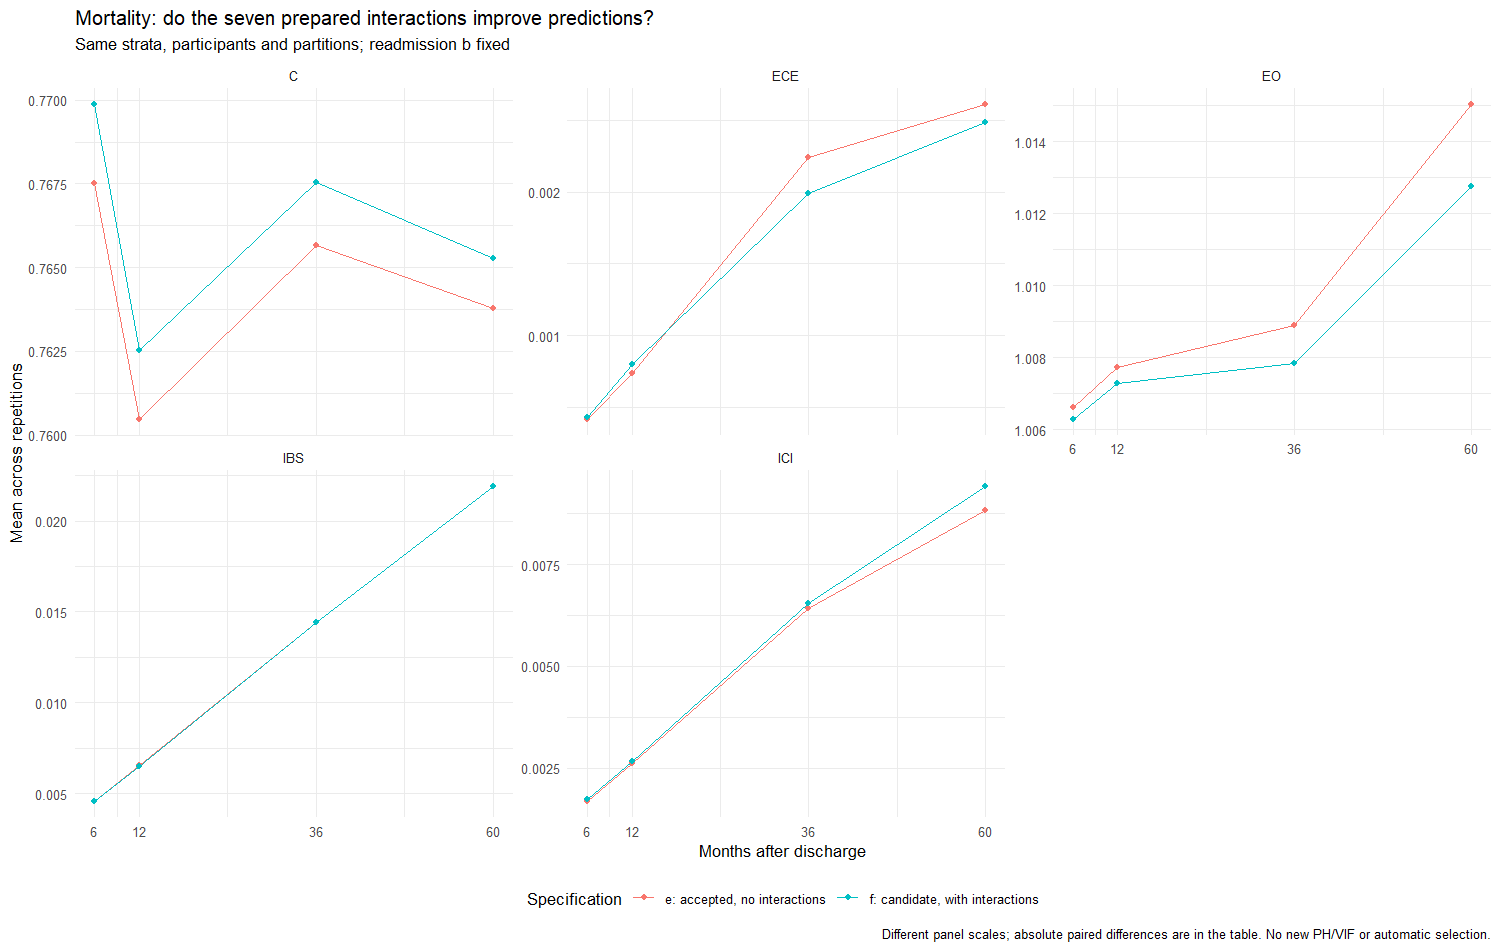

Outcome,Horizon,Metric,e,f,Difference,e_rounded,f_rounded,Classification
death,6,C,0.7675,0.7699,0.0024,0.768,0.770,"Substantial rounding change; reviewed, retain e"
death,12,C,0.7605,0.7625,0.0021,0.760,0.763,"Substantial rounding change; reviewed, retain e"
death,36,C,0.7657,0.7675,0.0019,0.766,0.768,"Substantial rounding change; reviewed, retain e"
death,60,C,0.7638,0.7653,0.0015,0.764,0.765,"Substantial rounding change; reviewed, retain e"
death,6,IBS,0.0045,0.0045,0.0000,0.005,0.005,Trivial at displayed precision
death,12,IBS,0.0065,0.0065,0.0000,0.007,0.007,Trivial at displayed precision
death,36,IBS,0.0144,0.0144,0.0000,0.014,0.014,Trivial at displayed precision
death,60,IBS,0.0219,0.0219,0.0000,0.022,0.022,Trivial at displayed precision
death,6,ICI,0.0017,0.0017,0.0001,0.002,0.002,Trivial at displayed precision
death,12,ICI,0.0026,0.0027,0.0000,0.003,0.003,Trivial at displayed precision


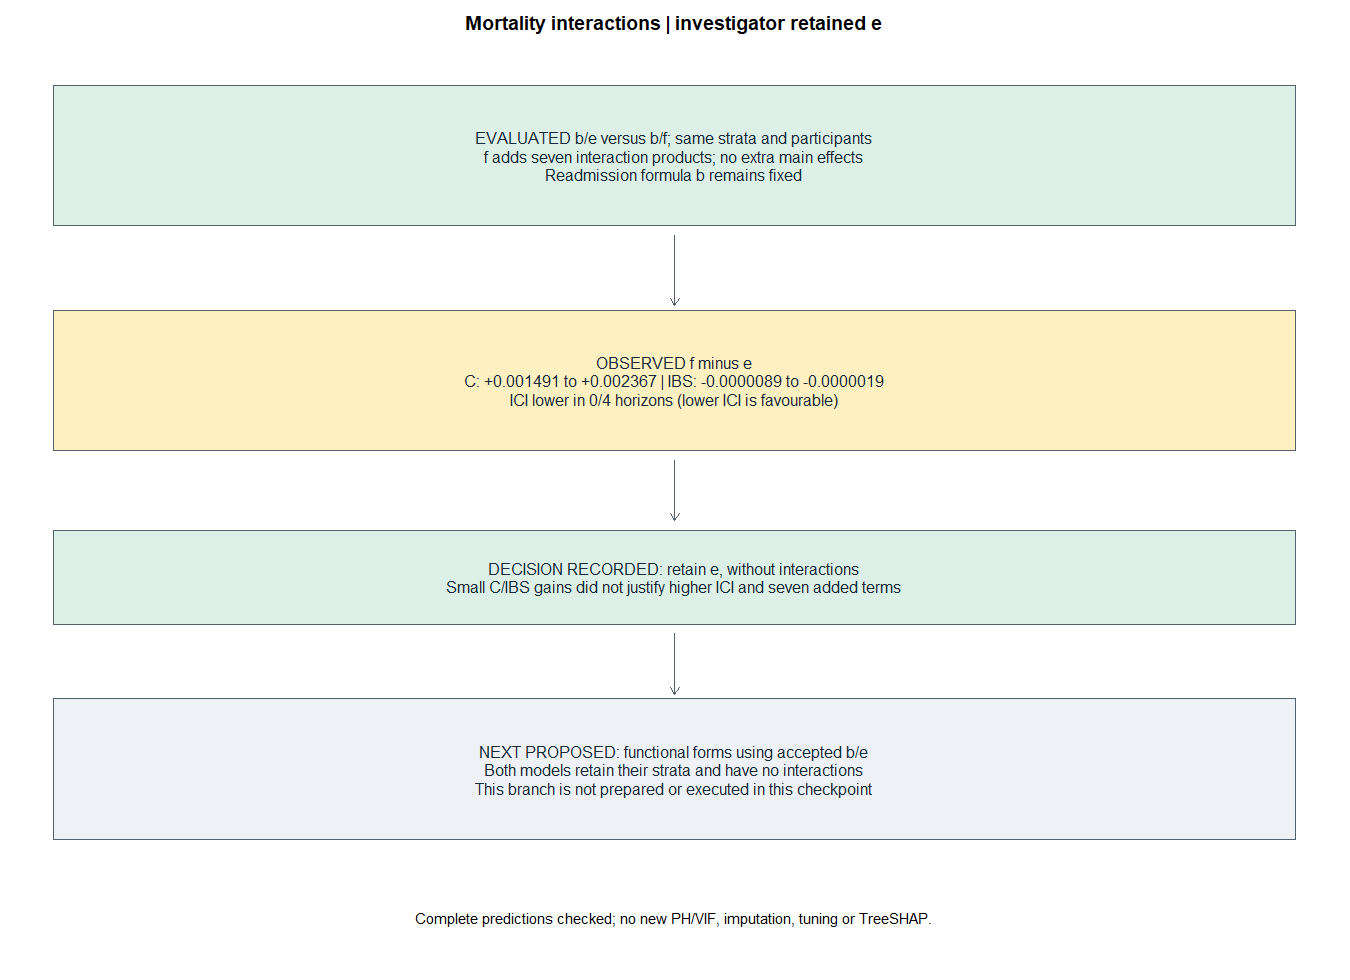

Review complete: investigator retained e, without interactions. Accepted b/e continues; functional forms remain unexecuted.


Elapsed: 1.024 minutes


In [68]:
#| label: shap-interaction-mortality-checkpoint
#| message: true
.t0 <- proc.time()
# Validate every new prediction task against accepted b/e; nobody is omitted or assigned a fallback.
if (interaction_f_run) {
  n_participants <- nrow(py_corrected_datasets[[1L]])
  before_calibration <- mortality_step_calibration
  comparison_rows <- coverage_rows <- zero_rows <- list()
  previous_mortality_zero_entries <- 0L
  for (outcome in c("readmission", "death")) {
    current <- interaction_f_calibration[[outcome]]
    previous <- before_calibration[[outcome]]
    aj <- outcome == "readmission"
    metrics <- if (aj) current$value$by_repetition else current$value$rep_results
    stopifnot(nrow(metrics) == 80L, identical(as.numeric(metrics$time_months), rep(performance_horizons, 20L)), all(is.finite(as.matrix(metrics[, c("ici", "ece", "eo_ratio")]))))
    if (aj) stopifnot(all(metrics$n_input == n_participants), all(metrics$n_analysis == n_participants), all(metrics$n_dropped == 0L), all(metrics$n_used_calibration == n_participants), all(metrics$n_excluded_calibration == 0L), all(metrics$n_imputations == 5L))
    # Check all KM calibration groups too; prediction coverage alone does not certify their inclusion.
    if (!aj) {
      curves <- current$value$calibration_curves
      used <- stats::aggregate(list(n = curves$n_patients * curves$n_reps), list(Horizon = curves$time_months), sum)
      stopifnot(nrow(used) == length(performance_horizons), setequal(used$Horizon, performance_horizons), all(abs(used$n - n_participants * 20L) < 1e-8))
    }
    pooled <- current$value$pooled_summary
    recalculated <- stats::aggregate(cbind(ici, ece, eo_ratio) ~ time_months, metrics, mean)
    recalculated <- recalculated[match(pooled$time_months, recalculated$time_months), ]
    stopifnot(max(abs(as.matrix(recalculated[, c("ici", "ece", "eo_ratio")]) - as.matrix(pooled[, c("ici_mean", "ece_mean", "eo_mean")]))) < 1e-12)
    minimum_risk <- Inf
    maximum_risk <- -Inf
    zero_predictions <- 0L
    zero_patterns_identical <- TRUE
    for (repetition in seq_len(20L)) {
      indices <- integer()
      for (fold in seq_len(5L)) {
        suffix <- sprintf("_r%02d_f%02d", repetition, fold)
        paths <- lapply(c(current$prefix, previous$prefix), function(prefix) list.files(object_dir, pattern = paste0("^perf07_", prefix, suffix, "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE))
        stopifnot(all(lengths(paths) == 1L))
        objects <- lapply(paths, function(path) readRDS(path[[1L]]))
        stopifnot(all(vapply(objects, function(x) identical(x$signature, performance_signature) && identical(x$value$r, repetition), logical(1L))))
        row_name <- if (aj) "te_idx" else "test_idx"
        risk_name <- if (aj) "pred_fold_avg" else "risk_mat"
        rows <- objects[[1L]]$value[[row_name]]
        risk <- objects[[1L]]$value[[risk_name]]
        stopifnot(identical(rows, objects[[2L]]$value[[row_name]]), identical(dim(risk), c(length(rows), length(performance_horizons))), all(is.finite(risk)), all(risk >= 0 & risk <= 1))
        zero_patterns_identical <- zero_patterns_identical && identical(risk == 0, objects[[2L]]$value[[risk_name]] == 0)
        if (!aj) {
          stopifnot(objects[[1L]]$value$fi == fold)
          previous_mortality_zero_entries <- previous_mortality_zero_entries + sum(objects[[2L]]$value$risk_mat == 0)
          # Flag zero horizon risks without omitting patients or changing their predictions.
          for (h in seq_along(performance_horizons)) {
            ids <- rows[risk[, h] == 0]
            if (!length(ids)) next
            training_deaths <- lapply(py_corrected_datasets, function(di) {
              group <- paste(di$plan_type_strata, di$any_phys_dx, sep = "|")
              counts <- tapply(as.integer(di$death_event[-rows] == 1 & di$death_time_from_disch_m[-rows] <= performance_horizons[h]), group[-rows], sum)
              as.integer(counts[group[ids]])
            })
            di <- py_corrected_datasets[[1L]]
            zero_rows[[length(zero_rows) + 1L]] <- data.frame(Repetition = repetition, Horizon = performance_horizons[h], Index = ids, Setting = as.character(di$plan_type_strata[ids]), Physical = di$any_phys_dx[ids], Maximum_training_deaths = do.call(pmax, training_deaths), Observed_death_before_horizon = di$death_event[ids] == 1 & di$death_time_from_disch_m[ids] <= performance_horizons[h])
          }
        }
        indices <- c(indices, rows)
        minimum_risk <- min(minimum_risk, risk)
        maximum_risk <- max(maximum_risk, risk)
        zero_predictions <- zero_predictions + sum(risk == 0)
      }
      stopifnot(length(indices) == n_participants, all(indices >= 1L & indices <= n_participants))
      assert_prediction_coverage(tabulate(indices, nbins = n_participants))
    }
    before <- previous$value$pooled_summary
    after <- pooled[match(before$time_months, pooled$time_months), ]
    comparison_rows[[outcome]] <- data.frame(Outcome = outcome, Horizon = before$time_months, ICI_e = before$ici_mean, ICI_f = after$ici_mean, Delta_ICI = after$ici_mean - before$ici_mean, ECE_e = before$ece_mean, ECE_f = after$ece_mean, Delta_ECE = after$ece_mean - before$ece_mean, EO_e = before$eo_mean, EO_f = after$eo_mean, Delta_EO = after$eo_mean - before$eo_mean)
    coverage_rows[[outcome]] <- data.frame(Outcome = outcome, Participants_per_repetition = n_participants, Repetitions = 20L, Prediction_tasks = 100L, Omitted = 0L, Paired_fold_indices_identical = TRUE, Minimum_predicted_risk = minimum_risk, Maximum_predicted_risk = maximum_risk, Zero_risk_entries = zero_predictions, Zero_patterns_identical_to_e_pair = zero_patterns_identical)
  }
  interaction_f_calibration_comparison <- do.call(rbind, comparison_rows)
  interaction_f_completeness <- do.call(rbind, coverage_rows)
  # Distinguish horizon-specific lack of deaths from a stratum with no deaths over all follow-up.
  zero_detail <- if (length(zero_rows)) do.call(rbind, zero_rows) else data.frame(Horizon = numeric(), Index = integer(), Setting = character(), Maximum_training_deaths = integer(), Observed_death_before_horizon = logical())
  interaction_f_zero_horizon <- do.call(rbind, lapply(performance_horizons, function(h) {
    z <- zero_detail[zero_detail$Horizon == h, ]
    data.frame(Horizon = h, Zero_prediction_entries = nrow(z), Distinct_people = length(unique(z$Index)), Death_entries_before_horizon = sum(z$Observed_death_before_horizon), Distinct_people_with_death = length(unique(z$Index[z$Observed_death_before_horizon])), Maximum_training_deaths_before_horizon = max(c(0L, z$Maximum_training_deaths)), Setting_codes = paste(sort(unique(z$Setting)), collapse = "; "))
  }))
  stopifnot(!anyNA(zero_detail), all(zero_detail$Maximum_training_deaths == 0L), nrow(zero_detail) == interaction_f_completeness$Zero_risk_entries[interaction_f_completeness$Outcome == "death"])
  interaction_f_zero_horizon <- merge(mortality_zero_horizon, interaction_f_zero_horizon, by = "Horizon", suffixes = c("_e", "_f"))
  show_table(interaction_f_zero_horizon, "e/f zero risks: same horizons; entries count person x repetition x horizon, not distinct people")
  cat("Zero mortality prediction entries with accepted e:", previous_mortality_zero_entries, "\n")
  cat("Every zero risk above corresponds to no training death before that horizon in the patient's stratum, in all five imputations. All patients remain in evaluation. This does not establish a true zero mortality probability. No fallback or prediction correction was applied.\n")
  death_change <- comparison_rows$death
  death_change$Outcome <- NULL
  interaction_f_comparison <- merge(interaction_f_comparison, death_change, by = "Horizon")
  display_comparison <- interaction_f_comparison
  for (column in grep("^Delta_", names(display_comparison), value = TRUE)) display_comparison[[column]] <- sprintf("%+.8f", display_comparison[[column]])
  show_table(display_comparison, "e versus f: all paired mortality metrics; readmission model b unchanged")
  display_comparison <- interaction_f_calibration_comparison
  for (column in grep("^Delta_", names(display_comparison), value = TRUE)) display_comparison[[column]] <- sprintf("%+.8f", display_comparison[[column]])
  show_table(display_comparison, "Both calibration targets after changing only the mortality specification")
  show_table(interaction_f_completeness, "All participants predicted in all calibration repetitions; no omission or fallback")
  long <- do.call(rbind, lapply(c("C", "IBS", "ICI", "ECE", "EO"), function(metric) do.call(rbind, lapply(c("e", "f"), function(model) data.frame(Horizon = interaction_f_comparison$Horizon, Metric = metric, Model = if (model == "e") "e: accepted, no interactions" else "f: candidate, with interactions", Value = interaction_f_comparison[[paste(metric, model, sep = "_")]])))))
  plot <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Model, group = Model)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(~Metric, scales = "free_y", ncol = 3) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "Mortality: do the seven prepared interactions improve predictions?", subtitle = "Same strata, participants and partitions; readmission b fixed", x = "Months after discharge", y = "Mean across repetitions", color = "Specification", caption = "Different panel scales; absolute paired differences are in the table. No new PH/VIF or automatic selection.") + ggplot2::theme_minimal() + ggplot2::theme(legend.position = "bottom")
  show_diagnostic_png(function() print(plot), 1500L, 950L)
  # Flag candidate differences at the manuscript's displayed precision without replacing published points.
  interaction_f_rounding <- do.call(rbind, lapply(c("C", "IBS", "ICI", "EO"), function(metric) {
    digits <- if (metric == "EO") 2L else 3L
    before <- interaction_f_comparison[[paste0(metric, "_e")]]
    after <- interaction_f_comparison[[paste0(metric, "_f")]]
    data.frame(Outcome = "death", Horizon = interaction_f_comparison$Horizon, Metric = metric, e = before, f = after, Difference = after - before, e_rounded = round(before, digits), f_rounded = round(after, digits), Classification = ifelse(round(before, digits) == round(after, digits), "Trivial at displayed precision", if (mortality_interaction_review_accepted) "Substantial rounding change; reviewed, retain e" else "Substantial rounding change; investigator review"))
  }))
  partner <- interaction_f_calibration_comparison[interaction_f_calibration_comparison$Outcome == "readmission", ]
  for (metric in c("ICI", "EO")) {
    digits <- if (metric == "EO") 2L else 3L
    before <- partner[[paste0(metric, "_e")]]
    after <- partner[[paste0(metric, "_f")]]
    interaction_f_rounding <- rbind(interaction_f_rounding, data.frame(Outcome = "readmission", Horizon = partner$Horizon, Metric = metric, e = before, f = after, Difference = after - before, e_rounded = round(before, digits), f_rounded = round(after, digits), Classification = ifelse(round(before, digits) == round(after, digits), "Trivial at displayed precision", if (mortality_interaction_review_accepted) "Substantial rounding change; reviewed, retain e" else "Substantial rounding change; investigator review")))
  }
  show_table(interaction_f_rounding, "b/e versus b/f using Table 2 precision; no manuscript point or historical interval is replaced")
  show_diagnostic_png(function() {
    decision_canvas(if (mortality_interaction_review_accepted) "Mortality interactions | investigator retained e" else "Mortality interactions | e/f comparison completed; choice pending")
    decision_box(0.04, 0.96, 0.88, "EVALUATED b/e versus b/f; same strata and participants\nf adds seven interaction products; no extra main effects\nReadmission formula b remains fixed", "accepted", h = 0.075)
    decision_arrow(0.5, 0.795, y2 = 0.72)
    decision_box(0.04, 0.96, 0.64, sprintf("OBSERVED f minus e\nC: %+.6f to %+.6f | IBS: %+.7f to %+.7f\nICI lower in %d/%d horizons (lower ICI is favourable)", min(interaction_f_comparison$Delta_C), max(interaction_f_comparison$Delta_C), min(interaction_f_comparison$Delta_IBS), max(interaction_f_comparison$Delta_IBS), sum(interaction_f_comparison$Delta_ICI < 0), nrow(interaction_f_comparison)), "prepared", h = 0.075)
    decision_arrow(0.5, 0.555, y2 = 0.49)
    decision_box(0.04, 0.96, 0.43, if (mortality_interaction_review_accepted) "DECISION RECORDED: retain e, without interactions\nSmall C/IBS gains did not justify higher ICI and seven added terms" else "INVESTIGATOR REVIEW: retain e or accept f\nWeigh C/IBS, calibration, seven added terms and zero-risk flags", if (mortality_interaction_review_accepted) "accepted" else "review", h = 0.05)
    decision_arrow(0.5, 0.37, y2 = 0.305)
    decision_box(0.04, 0.96, 0.225, if (mortality_interaction_review_accepted) "NEXT PROPOSED: functional forms using accepted b/e\nBoth models retain their strata and have no interactions\nThis branch is not prepared or executed in this checkpoint" else "STOP BEFORE FUNCTIONAL FORMS\nAccepted b/e stays in place until the mortality choice is recorded\nNo new bootstrap or uncertainty interval in this comparison", "pending", h = 0.075)
    graphics::text(0.5, 0.065, "Complete predictions checked; no new PH/VIF, imputation, tuning or TreeSHAP.", cex = 0.84)
  }, 1350L, 980L)
  stopifnot(new_model_fits == 0L, new_ph_tests == 0L)
  interaction_f_complete <- TRUE
  interaction_comparison_plan$Status[2L] <- if (mortality_interaction_review_accepted) "Reviewed: retain e; cached comparison only" else "Complete; investigator choice pending"
  review_pending <- !mortality_interaction_review_accepted
  if (mortality_interaction_review_accepted) cat("Review complete: investigator retained e, without interactions. Accepted b/e continues; functional forms remain unexecuted.", fill = TRUE) else cat("e/f comparison complete. STOP before selecting f or exploring functional forms; b remains fixed. No bootstrap intervals were estimated.", fill = TRUE)
} else cat("Mortality e/f is prepared; no new prediction results to interpret.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)


### Interpretation of the completed e/f comparison

Mortality f improves C slightly at all four horizons (about 0.0015-0.0024), reduces integrated IBS by less than 0.000009, and brings E/O closer to 1. ICI is higher at every horizon; ECE is higher at 6/12 months and lower at 36/60 months. It adds seven interaction products to the same 25-term e specification and retains the same strata. **Investigator decision recorded 2026-10-08T01:26:17-03:00: retain e, without interactions.** Small C/IBS and E/O gains did not justify higher ICI at every horizon and seven additional terms, given the agreed priority for ICI. Candidate f remains documented and is not carried forward. Accepted b/e, both without interactions, is the base for the next checkpoint; functional candidates are prepared below; no functional-form Cox comparison has been executed.

The mortality change has very small effects on readmission calibration with b fixed: the maximum absolute ICI change is below 0.000008. All 70,521 participants are retained in every calibration repetition. The 661 zero mortality-risk entries have exactly the same participant/repetition/horizon positions under e and f; these are repeated entries, not 661 distinct people. They do not favour either candidate. No fallback was used.

At Table 2 precision, six candidate comparisons change their displayed value: C at all horizons, ICI at 36 months, and E/O at 60 months. They were reviewed by the investigator, who retained e; no manuscript point or old confidence interval is substituted. No bootstrap uncertainty was estimated here, and these results do not establish equivalence. Whole-development imputation and selection still precede internal CV, as previously documented.

The scientific run produced 250 identical default-curve warnings from the strata-count check in the C/IBS engine, with no convergence warning. Individual predictions use validation-row newdata; the warned default curve does not enter scoring. The complete executed outputs are preserved in the scientific-output ZIP recorded in notebook metadata.


## Next checkpoint: age shape in readmission, with mortality e fixed
Both investigator decisions are complete: retain readmission b and mortality e, without interactions. The original `prediction22_converted_mod` starts its functional-form trials with age, followed by treatment duration, poverty and categorical/ordinal simplifications. The next comparison would replace only the linear age term in b; e stays fixed. The updated exploration first compares each single change with fixed b/e; combinations require a later investigator checkpoint.
**Approved for this comparison: the complete standard three-column age spline.** The original `shap-criteria-func-form-rcs` supplies four interior knots to `splines::ns()` and saves only its first three columns. That is a three-coefficient restricted subset of a five-column natural-spline basis. It is a valid restricted curve, but differs from a conventional complete three-column natural spline. The manuscript's eTables 5/6 label the candidates "Natural spline, 3 df" without describing this restriction. Their historical performance remains evidence about the actual restricted construction, not about every three-df natural spline.
The code below checks the basis and shows already computed SHAP summaries. It does not change the development matrices, b/e, saved risks or scoring engines, and does not fit a Cox model. The approved conventional spline is evaluated below; its numerical impact is read from that completed comparison.


In [69]:
#| label: shap-functional-exploration-contract
#| message: true
.t0 <- proc.time()
# Apply the investigator's smaller calibration budget only to this new exploratory branch.
functional_settings <- list(c_ibs_repeats = as.integer(shap_settings$c_ibs_repeats), calibration_repeats = as.integer(shap_settings$functional_calibration_repeats), folds = 5L, imputations = length(py_corrected_datasets), c_gain = 0.01, ibs_tolerance = 0.001)
stopifnot(functional_settings$c_ibs_repeats == 10L, functional_settings$calibration_repeats == 1L, functional_settings$imputations == 5L, config$cox_performance$calibration_repeats == 20L, readmission_interaction_review_accepted, mortality_interaction_review_accepted)
functional_bases <- list(b = formula_shap_readmit_clean_updated, e = formula_shap_death_rule2)
functional_predictors <- c("adm_age_rec3", "dit_m", "porc_pobr")
functional_membership <- do.call(rbind, lapply(names(functional_bases), function(b) data.frame(Base = b, Predictor = functional_predictors, Retained = functional_predictors %in% all.vars(functional_bases[[b]]))))
stopifnot(all(functional_membership$Retained[functional_membership$Base == "b"]), identical(functional_membership$Retained[functional_membership$Base == "e"], c(TRUE, FALSE, FALSE)), !any(vapply(functional_bases, function(f) removed_collinear %in% all.vars(f), logical(1L))))
show_table(functional_membership, "Continuous predictors actually retained in b/e; no predictor is added by this preparation")
show_table(data.frame(Component = c("Uno C / Graf integrated IBS", "ICI / E:O", "AICc", "Baseline pairing"), Plan = c("10 repetitions x 5 folds x 5 imputations; keep current scoring", "1 repetition x 5 folds x 5 imputations; same calibration targets", "Keep the historical descriptive average across five imputations", "Compare every single-change candidate with fixed b or e on matching partitions")), "Exploratory evaluation contract; no predictive fitting is enabled")
cat("Calibration b/e references must use the same single repetition, folds, pooling and calibration-bin rules as their candidates, not the earlier twenty-repetition averages. Five imputations are not five independent repetitions. Earlier twenty-repetition results remain unchanged.", fill = TRUE)
cat("The study rule remains delta Uno C >= 0.01 AND delta integrated IBS <= 0.001 by horizon. ICI, E/O and AICc support review; no new numerical veto is introduced. If several single changes pass, their combination needs a later comparison and investigator review.", fill = TRUE)
cat("Whole-development imputation and SHAP selection still precede internal CV. The descriptive SHAP nonlinearity check does not establish Cox prediction improvement. No PH/VIF, bootstrap, imputation, tuning or SHAP calculation is added.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Base,Predictor,Retained
b,"Age at admission, yr",TRUE
b,"Treatment episode length, mo",TRUE
b,Communal poverty rate,TRUE
e,"Age at admission, yr",TRUE
e,"Treatment episode length, mo",FALSE
e,Communal poverty rate,FALSE


Component,Plan
Uno C / Graf integrated IBS,10 repetitions x 5 folds x 5 imputations; keep current scoring
ICI / E:O,1 repetition x 5 folds x 5 imputations; same calibration targets
AICc,Keep the historical descriptive average across five imputations
Baseline pairing,Compare every single-change candidate with fixed b or e on matching partitions


Calibration b/e references must use the same single repetition, folds, pooling and calibration-bin rules as their candidates, not the earlier twenty-repetition averages. Five imputations are not five independent repetitions. Earlier twenty-repetition results remain unchanged.


The study rule remains delta Uno C >= 0.01 AND delta integrated IBS <= 0.001 by horizon. ICI, E/O and AICc support review; no new numerical veto is introduced. If several single changes pass, their combination needs a later comparison and investigator review.


Whole-development imputation and SHAP selection still precede internal CV. The descriptive SHAP nonlinearity check does not establish Cox prediction improvement. No PH/VIF, bootstrap, imputation, tuning or SHAP calculation is added.


Elapsed: 0.001 minutes


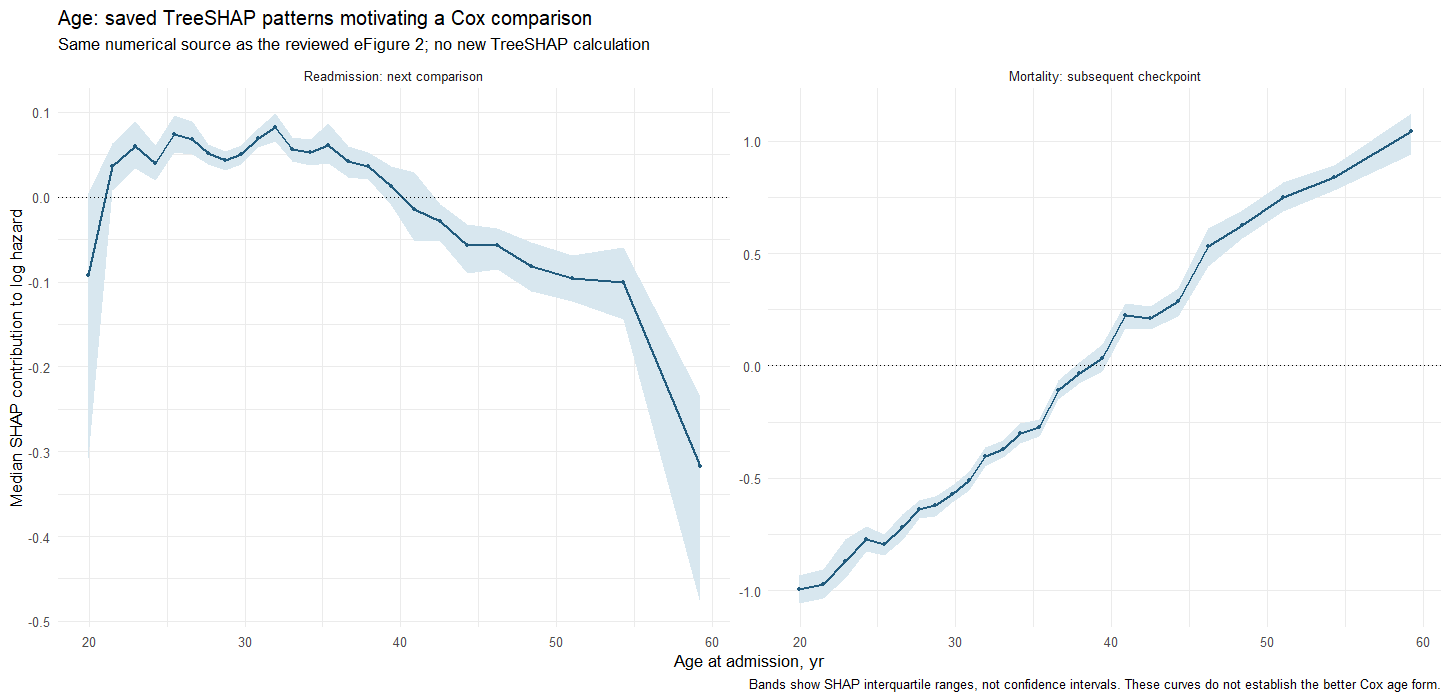

Step,Readmission,Mortality,Status
Current accepted pair,"b: linear age, no interactions","e: linear age, no interactions",Accepted
Next: readmission age,b with one reviewed age transformation,e fixed,Basis choice required; no fitting enabled
Then: mortality age,b fixed,e with the reviewed age candidate,Candidate register below; no fitting
Later original stages,b fixed for each single-change comparison,e fixed for each single-change comparison,Readmission duration/poverty below; categorical/ordinal branch later


Model,Ordinary_terms
b: accepted,26
b with age curve: template only,28


Original source labels: shap-criteria-func-form-precomputed-ns-readm and shap-criteria-func-form-linear-terms-vs-ns-readm-test-simpler. The latter explicitly pairs the readmission age candidate with e. Original AICc comparisons remain in the planned descriptive workflow; no new AICc or PH/VIF has been run.


Elapsed: 0.007 minutes


In [70]:
#| label: shap-functional-age-source-and-plan
#| message: true
.t0 <- proc.time()
# Anchor the next candidate to the reviewed b/e formulas and the verified 03 figure source.
stopifnot(readmission_interaction_review_accepted, identical(readmission_interaction_choice, "b"), mortality_interaction_review_accepted, identical(mortality_interaction_choice, "e"), interaction_f_complete, !review_pending)
functional_record <- jsonlite::read_json(source_path("combined_execution"), simplifyVector = FALSE)
functional_artifact <- Filter(function(x) identical(x$path, config$sources$cox_shap_functional_summary), functional_record$figure_checkpoint$canonical_artifacts)
stopifnot(length(functional_artifact) == 1L, identical(digest::digest(file = source_path("cox_shap_functional_summary"), algo = "sha256"), functional_artifact[[1L]]$sha256))
functional_age_source <- utils::read.csv(source_path("cox_shap_functional_summary"), stringsAsFactors = FALSE, check.names = FALSE)
functional_age_source <- functional_age_source[functional_age_source$Predictor == "adm_age_rec3", ]
stopifnot(setequal(unique(functional_age_source$Outcome), c("Readmission", "Death")), all(is.finite(as.matrix(functional_age_source[, c("X", "Median_SHAP", "Q25_SHAP", "Q75_SHAP")]))), all(stats::aggregate(N ~ Outcome, functional_age_source, sum)$N == nrow(py_corrected_datasets[[1L]])))
functional_age_source$Outcome_label <- factor(functional_age_source$Outcome, levels = c("Readmission", "Death"), labels = c("Readmission: next comparison", "Mortality: subsequent checkpoint"))
plot <- ggplot2::ggplot(functional_age_source, ggplot2::aes(X, Median_SHAP)) + ggplot2::geom_ribbon(ggplot2::aes(ymin = Q25_SHAP, ymax = Q75_SHAP), fill = "#d8e7ef") + ggplot2::geom_line(color = "#215b7d", linewidth = 0.7) + ggplot2::geom_point(color = "#215b7d", size = 1) + ggplot2::geom_hline(yintercept = 0, linetype = "dotted") + ggplot2::facet_wrap(~Outcome_label, scales = "free_y") + ggplot2::labs(title = "Age: saved TreeSHAP patterns motivating a Cox comparison", subtitle = "Same numerical source as the reviewed eFigure 2; no new TreeSHAP calculation", x = display_term("adm_age_rec3"), y = "Median SHAP contribution to log hazard", caption = "Bands show SHAP interquartile ranges, not confidence intervals. These curves do not establish the better Cox age form.") + ggplot2::theme_minimal(base_size = 11)
show_diagnostic_png(function() print(plot), 1450L, 700L)
# Prepare only a formula template; the age basis is not added to any development matrix.
functional_age_formula_template <- stats::update(formula_shap_readmit_clean_updated, . ~ . - adm_age_rec3 + age_ns1 + age_ns2 + age_ns3)
stopifnot(identical(formula_strata(functional_age_formula_template), formula_strata(formula_shap_readmit_clean_updated)), !removed_collinear %in% all.vars(functional_age_formula_template), setequal(setdiff(formula_terms(functional_age_formula_template), c("age_ns1", "age_ns2", "age_ns3")), setdiff(formula_terms(formula_shap_readmit_clean_updated), "adm_age_rec3")))
functional_age_plan <- data.frame(Step = c("Current accepted pair", "Next: readmission age", "Then: mortality age", "Later original stages"), Readmission = c("b: linear age, no interactions", "b with one reviewed age transformation", "b fixed", "b fixed for each single-change comparison"), Mortality = c("e: linear age, no interactions", "e fixed", "e with the reviewed age candidate", "e fixed for each single-change comparison"), Status = c("Accepted", "Basis choice required; no fitting enabled", "Candidate register below; no fitting", "Readmission duration/poverty below; categorical/ordinal branch later"))
show_table(functional_age_plan, "Original predictor order; fixed b/e comparisons under the updated exploration decision")
show_table(data.frame(Model = c("b: accepted", "b with age curve: template only"), Ordinary_terms = c(sum(!startsWith(formula_terms(formula_shap_readmit_clean_updated), "strata(")), sum(!startsWith(formula_terms(functional_age_formula_template), "strata(")))), "Only the age term would change; strata and the VIF exclusion remain")
cat("Original source labels: shap-criteria-func-form-precomputed-ns-readm and shap-criteria-func-form-linear-terms-vs-ns-readm-test-simpler. The latter explicitly pairs the readmission age candidate with e. Original AICc comparisons remain in the planned descriptive workflow; no new AICc or PH/VIF has been run.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)

Imputation,Participants,Minimum_age,Q05,Q35,Q65,Q95,Maximum_age,Original_basis_columns,Original_retained_columns,Proposed_complete_columns,Age_identical_to_first_imputation
1,70521,18,21.09,30.06,39.02,55.33,64,5,3,3,TRUE
2,70521,18,21.09,30.06,39.02,55.33,64,5,3,3,TRUE
3,70521,18,21.09,30.06,39.02,55.33,64,5,3,3,TRUE
4,70521,18,21.09,30.06,39.02,55.33,64,5,3,3,TRUE
5,70521,18,21.09,30.06,39.02,55.33,64,5,3,3,TRUE


Option,Interior_knots,Boundary_knots,Columns_used,Consequence,Status
A: historical construction,"Q05, Q35, Q65, Q95",Observed minimum and maximum,First three of five,Reproduce the original restricted curve; describe the restriction explicitly,Historical construction preserved; not selected
"B: complete natural spline, 3 df (recommended)","Q35, Q65",Q05 and Q95,All three,"New, explicitly chosen candidate; historical results remain documented",Approved for testing; comparison follows


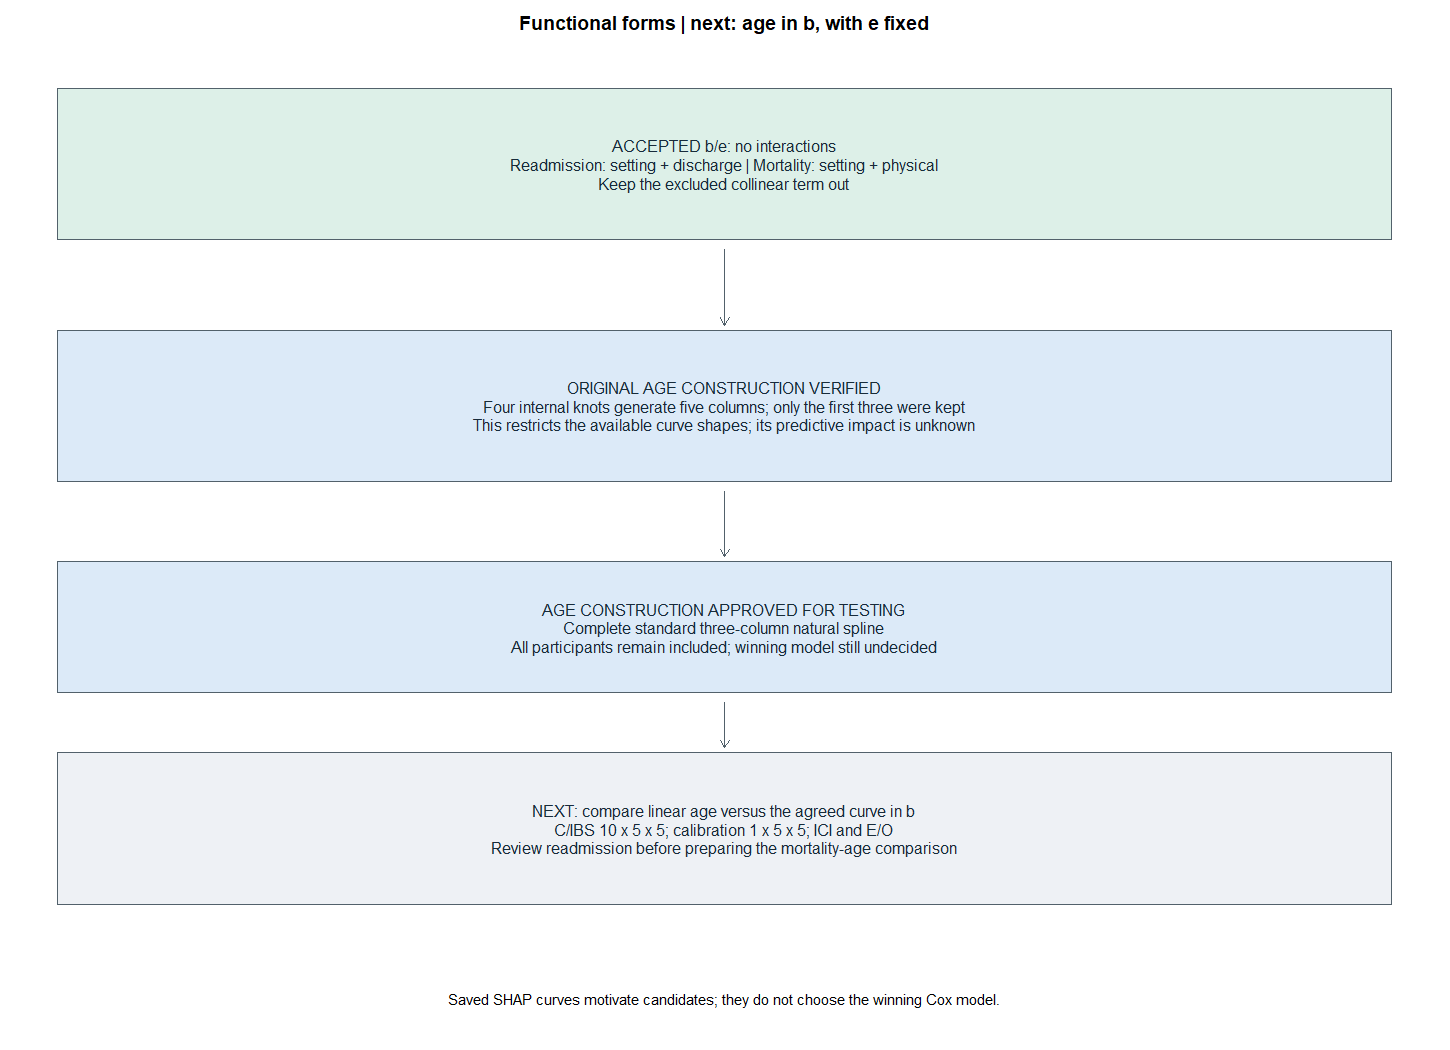

This basis audit itself fits no model. The complete standard curve is approved for the predictive comparison below. Accepted b/e remain unchanged until that result is reviewed.


Budget for the following approved comparison: 250 readmission C/IBS fits plus 50 paired AJ fits, with e fixed. Reuse the approved partitions and Graf integrated IBS. Descriptive AICc also compares the two forms below.


Whole-development preprocessing remains the accepted internal-CV limitation. A future age transformation must be frozen before holdout/additional-cohort application. Boundary knots do not remove or cap observations.


Elapsed: 0.010 minutes


In [71]:
#| label: shap-functional-age-basis-checkpoint
#| message: true
.t0 <- proc.time()
# Check the original basis construction without changing matrices, fitting outcomes or selecting a candidate.
original_functional_notebook <- jsonlite::read_json(source_path("combined_downstream_notebook"), simplifyVector = FALSE)
original_functional_code <- vapply(original_functional_notebook$cells, function(cell) paste(unlist(cell$source), collapse = ""), character(1L))
original_age_code <- original_functional_code[grepl("#| label: shap-criteria-func-form-rcs\n", original_functional_code, fixed = TRUE)]
stopifnot(length(original_age_code) == 1L, length(gregexpr("splines::ns(adm_age_rec3", original_age_code, fixed = TRUE)[[1L]]) == 3L, grepl("c(0.05, 0.35, 0.65, 0.95)", original_age_code, fixed = TRUE))
functional_age_basis_audit <- do.call(rbind, lapply(seq_along(py_corrected_datasets), function(i) {
  age <- py_corrected_datasets[[i]]$adm_age_rec3
  knots <- as.numeric(stats::quantile(age, probs = c(0.05, 0.35, 0.65, 0.95), names = FALSE))
  historical_full <- splines::ns(age, knots = knots)
  historical_retained <- historical_full[, 1:3, drop = FALSE]
  proposed_complete <- splines::ns(age, knots = knots[2:3], Boundary.knots = knots[c(1, 4)])
  stopifnot(length(unique(knots)) == 4L, ncol(historical_full) == 5L, ncol(historical_retained) == 3L, ncol(proposed_complete) == 3L, all(is.finite(historical_retained)), all(is.finite(proposed_complete)), nrow(proposed_complete) == length(age))
  data.frame(Imputation = i, Participants = length(age), Minimum_age = min(age), Q05 = knots[1L], Q35 = knots[2L], Q65 = knots[3L], Q95 = knots[4L], Maximum_age = max(age), Original_basis_columns = ncol(historical_full), Original_retained_columns = ncol(historical_retained), Proposed_complete_columns = ncol(proposed_complete), Age_identical_to_first_imputation = identical(age, py_corrected_datasets[[1L]]$adm_age_rec3))
}))
functional_age_options <- data.frame(Option = c("A: historical construction", "B: complete natural spline, 3 df (recommended)"), Interior_knots = c("Q05, Q35, Q65, Q95", "Q35, Q65"), Boundary_knots = c("Observed minimum and maximum", "Q05 and Q95"), Columns_used = c("First three of five", "All three"), Consequence = c("Reproduce the original restricted curve; describe the restriction explicitly", "New, explicitly chosen candidate; historical results remain documented"), Status = c("Historical construction preserved; not selected", "Approved for testing; comparison follows"))
show_table(functional_age_basis_audit, "Executed basis audit on all five development imputations; no outcome model fitted")
show_table(functional_age_options, "Age construction reviewed: complete standard curve approved for testing; both options use three coefficients")
show_diagnostic_png(function() {
  decision_canvas("Functional forms | next: age in b, with e fixed")
  decision_box(0.04, 0.96, 0.88, "ACCEPTED b/e: no interactions\nReadmission: setting + discharge | Mortality: setting + physical\nKeep the excluded collinear term out", "accepted", h = 0.075)
  decision_arrow(0.5, 0.795, y2 = 0.72)
  decision_box(0.04, 0.96, 0.64, "ORIGINAL AGE CONSTRUCTION VERIFIED\nFour internal knots generate five columns; only the first three were kept\nThis restricts the available curve shapes; its predictive impact is unknown", "review", h = 0.075)
  decision_arrow(0.5, 0.555, y2 = 0.49)
  decision_box(0.04, 0.96, 0.42, "AGE CONSTRUCTION APPROVED FOR TESTING\nComplete standard three-column natural spline\nAll participants remain included; winning model still undecided", "review", h = 0.065)
  decision_arrow(0.5, 0.345, y2 = 0.30)
  decision_box(0.04, 0.96, 0.22, "NEXT: compare linear age versus the agreed curve in b\nC/IBS 10 x 5 x 5; calibration 1 x 5 x 5; ICI and E/O\nReview readmission before preparing the mortality-age comparison", "pending", h = 0.075)
  graphics::text(0.5, 0.05, "Saved SHAP curves motivate candidates; they do not choose the winning Cox model.", cex = 0.84)
}, 1450L, 1050L)
functional_age_method_review_pending <- is.null(shap_settings$functional_age_method)
functional_age_signature <- substr(digest::digest(list(performance_signature, interaction_signature, functional_artifact[[1L]]$sha256, original_age_code, functional_age_options, functional_age_basis_audit), algo = "sha256"), 1L, 12L)
review_pending <- TRUE
stopifnot(new_model_fits == 0L, new_ph_tests == 0L, performance_new_fits == 0L, !any(c("age_ns1", "age_ns2", "age_ns3") %in% names(py_corrected_datasets[[1L]])))
cat("This basis audit itself fits no model. The complete standard curve is approved for the predictive comparison below. Accepted b/e remain unchanged until that result is reviewed.", fill = TRUE)
cat("Budget for the following approved comparison: 250 readmission C/IBS fits plus 50 paired AJ fits, with e fixed. Reuse the approved partitions and Graf integrated IBS. Descriptive AICc also compares the two forms below.", fill = TRUE)
cat("Whole-development preprocessing remains the accepted internal-CV limitation. A future age transformation must be frozen before holdout/additional-cohort application. Boundary knots do not remove or cap observations.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes", unname((proc.time() - .t0)["elapsed"]) / 60), fill = TRUE)

### Age construction approved for testing
**Investigator choice: B, a complete three-column natural spline; preserve the original restricted construction as historical evidence.** This uses Q35/Q65 as internal knots and Q05/Q95 as boundary knots; it is an explicitly accepted change to the candidate shapes and tail boundaries, not a recovered original intention. Both options retain all people and have three age coefficients. The current b/e results are unaffected. The executed comparison appears below. This basis audit does not establish why the historical age variant performed as reported.
Technical references and the method discrepancy are recorded in docs/07_functional_form_preparation.md. SHAP summaries are descriptive motivation, not Cox prediction estimates.
The original functional-form grid compared variants against unchanged bases. The latest investigator instruction also requests fixed b/e references for this exploratory table. The following registry makes the candidate forms explicit before fitting; the complete standard age basis is approved for testing. This approval does not select a winning model. No Word changes.

## Functional candidates and visual support before evaluation
The investigator reduced only this exploratory calibration to one repetition of five folds across five imputations, retaining ten repetitions for C/IBS and the original descriptive AICc. Each single-change candidate is compared with fixed b/e. The full and central-range panels use the same cached SHAP observations; the zoom does not change the analysis sample. Literature and thesis-figure interpretation are recorded in `docs/07_functional_form_preparation.md`.

Predictor,Unit,N,Minimum,Q01,Q05,Median,Q95,Q99,Maximum,Below_Q01,Above_Q99
"Age at admission, yr",Years,70521,18.0000,19.1400,21.0900,34.1700,55.3300,61.1000,64.0000,699,705
"Treatment episode length, mo",Months,70521,0.0000,0.2581,1.0645,5.5806,19.2903,30.8387,60.7097,693,705
Communal poverty rate,Percent,70521,0.1726,3.0472,5.2771,12.3715,26.0717,36.3312,63.6375,631,671


Predictor,Cutoff_original_units,Role,SHAP_source_at_or_below,SHAP_source_above,SHAP_source_percent_above,Imputation_min_above,Imputation_max_above
"Treatment episode length, mo",5.00,Historical b hinge,32095,38426,54.4887,38436,38436
"Treatment episode length, mo",9.00,Historical Full d hinge; outside e,50059,20462,29.0155,20469,20469
"Treatment episode length, mo",36.00,Historical b cap for log/quadratic/hinge,70393,128,0.1815,154,154
Communal poverty rate,0.15,Historical b hinge,47495,23026,32.6513,23026,23026
Communal poverty rate,0.22,Historical Full d hinge; outside e,62368,8153,11.5611,8153,8153


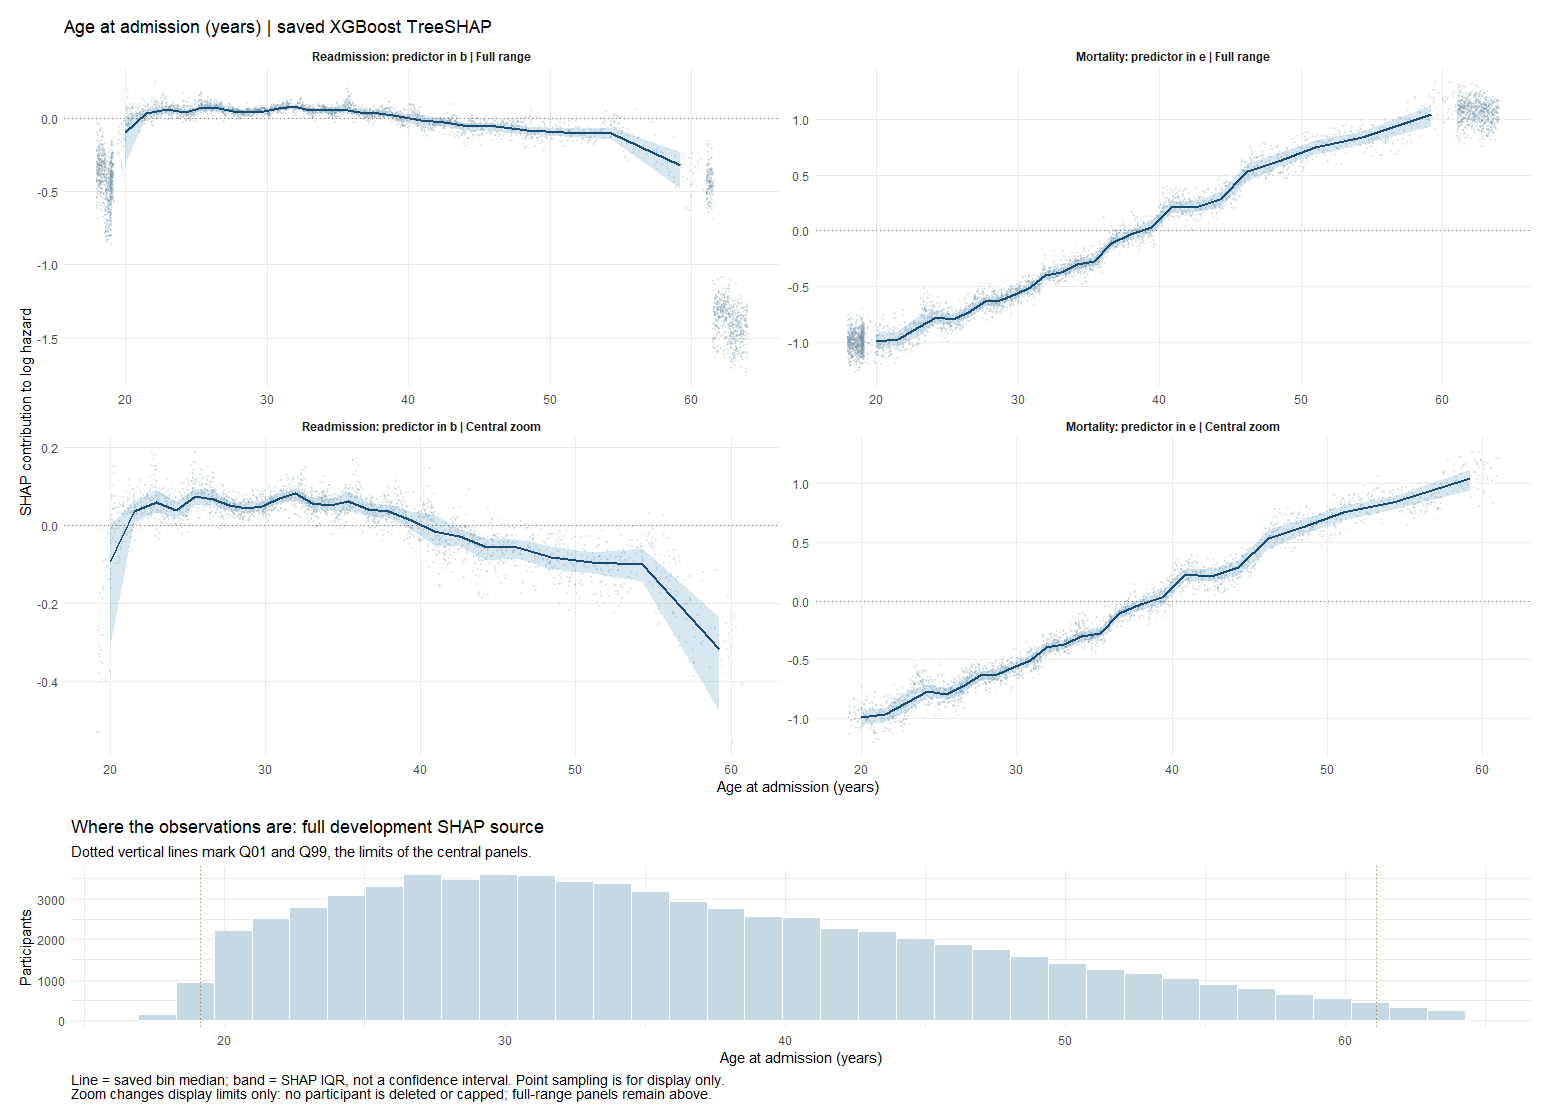

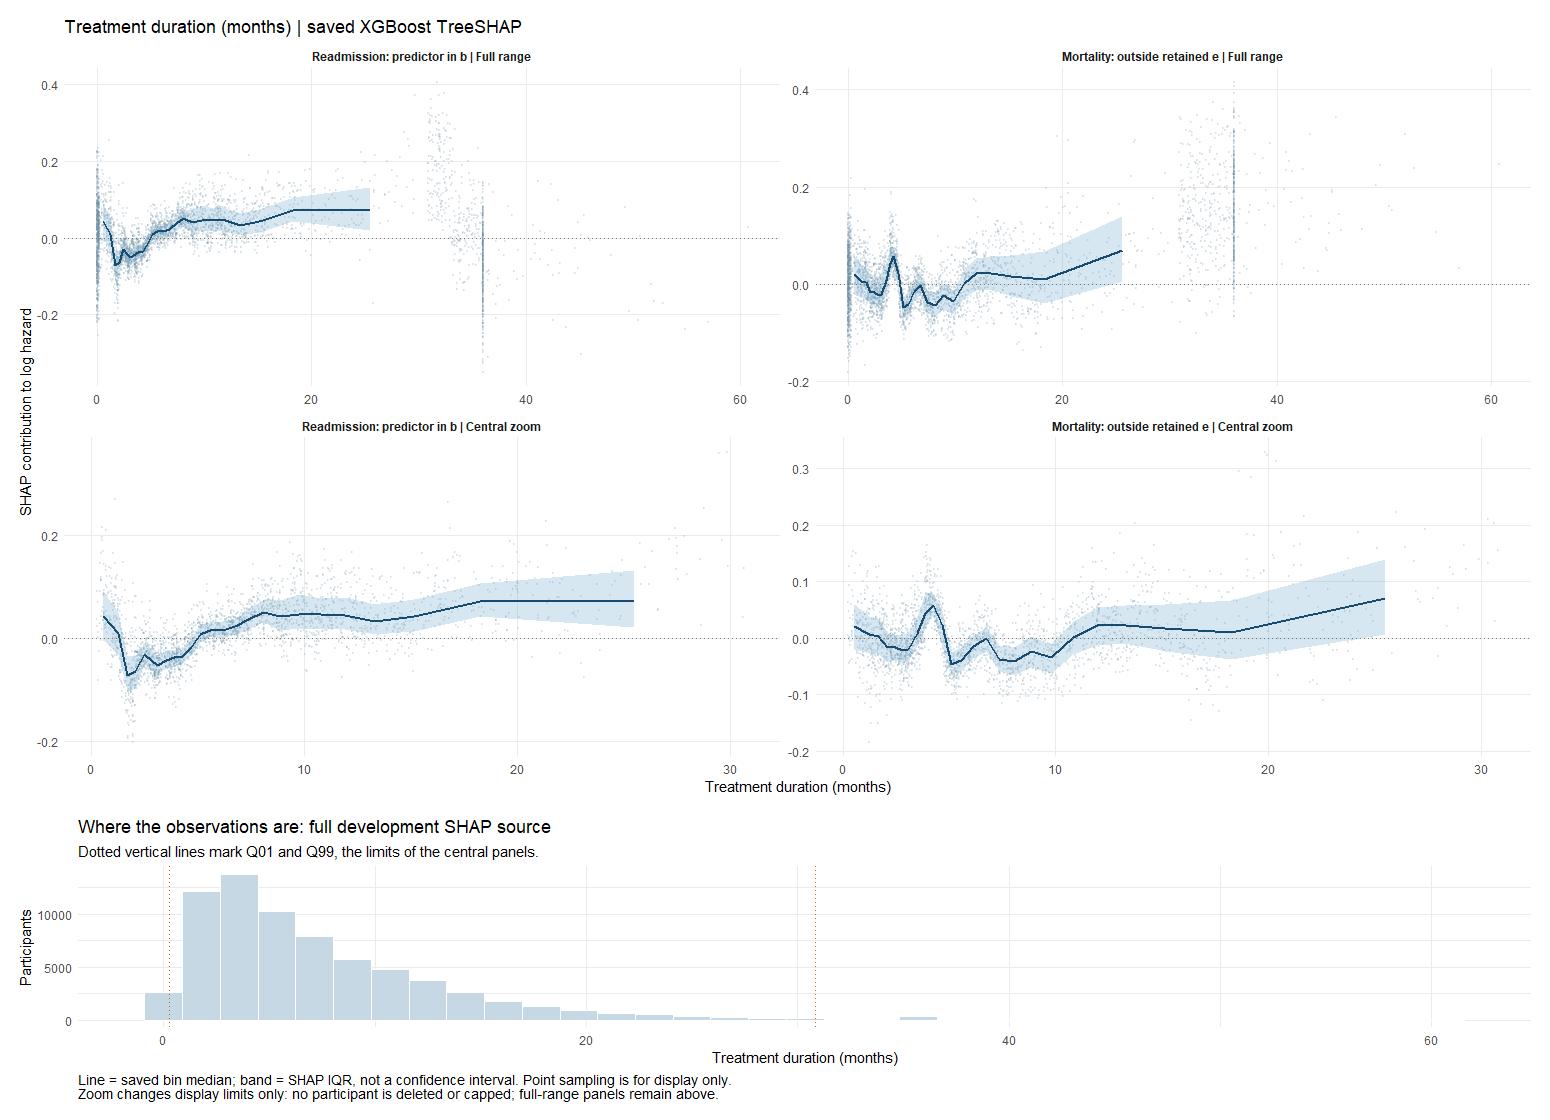

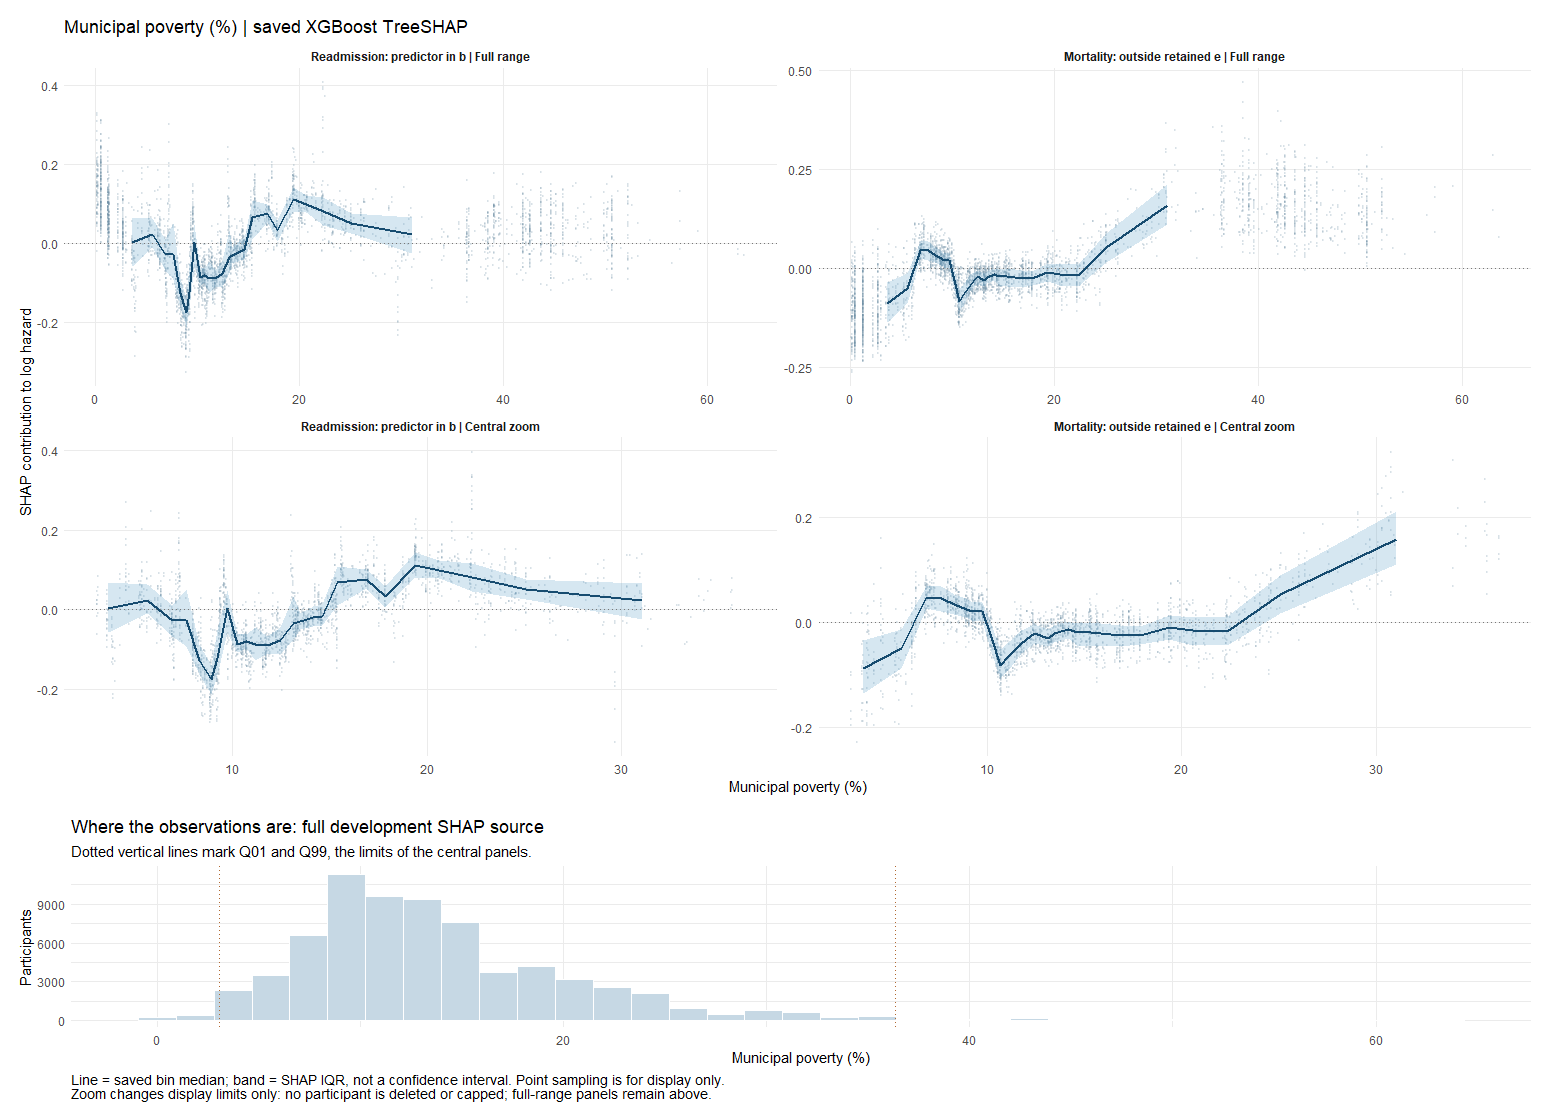

These plots diagnose presentation and tail support. They do not demonstrate that outliers changed a selected Cox model. Pooled SHAP-source values are descriptive; future Cox transformations apply separately to the five completed imputations.


Elapsed: 0.091 minutes


In [72]:
#| label: shap-functional-continuous-evidence
#| message: true
.t0 <- proc.time()
# Reuse the hash-verified individual-level figure source; no patient-level file is exported.
functional_raw_artifact <- Filter(function(x) identical(x$path, config$sources$cox_shap_functional_source), functional_record$figure_checkpoint$canonical_artifacts)
stopifnot(length(functional_raw_artifact) == 1L, identical(digest::digest(file = source_path("cox_shap_functional_source"), algo = "sha256"), functional_raw_artifact[[1L]]$sha256))
functional_raw <- nanoparquet::read_parquet(source_path("cox_shap_functional_source"))
functional_raw <- functional_raw[functional_raw$Predictor %in% functional_predictors, c("Predictor", "Outcome", "Feature_Value", "SHAP_Impact")]
functional_curves <- utils::read.csv(source_path("cox_shap_functional_summary"), stringsAsFactors = FALSE)
functional_curves <- functional_curves[functional_curves$Predictor %in% functional_predictors, ]
stopifnot(nrow(functional_raw) == 6L * nrow(py_corrected_datasets[[1L]]), all(is.finite(functional_raw$Feature_Value)), all(is.finite(functional_raw$SHAP_Impact)), all(stats::aggregate(N ~ Predictor + Outcome, functional_curves, sum)$N == nrow(py_corrected_datasets[[1L]])))
functional_support <- do.call(rbind, lapply(functional_predictors, function(v) {
  x <- functional_raw$Feature_Value[functional_raw$Predictor == v & functional_raw$Outcome == "Readmission"]
  other <- functional_raw$Feature_Value[functional_raw$Predictor == v & functional_raw$Outcome == "Death"]
  stopifnot(identical(x, other))
  q <- as.numeric(stats::quantile(x, c(0.01, 0.05, 0.50, 0.95, 0.99)))
  multiplier <- if (v == "porc_pobr") 100 else 1
  data.frame(Predictor = v, Unit = if (v == "adm_age_rec3") "Years" else if (v == "dit_m") "Months" else "Percent", N = length(x), Minimum = min(x) * multiplier, Q01 = q[1L] * multiplier, Q05 = q[2L] * multiplier, Median = q[3L] * multiplier, Q95 = q[4L] * multiplier, Q99 = q[5L] * multiplier, Maximum = max(x) * multiplier, Below_Q01 = sum(x < q[1L]), Above_Q99 = sum(x > q[5L]))
}))
functional_thresholds <- data.frame(Predictor = c("dit_m", "dit_m", "dit_m", "porc_pobr", "porc_pobr"), Cutoff = c(5, 9, 36, 0.15, 0.22), Role = c("Historical b hinge", "Historical Full d hinge; outside e", "Historical b cap for log/quadratic/hinge", "Historical b hinge", "Historical Full d hinge; outside e"))
functional_threshold_support <- do.call(rbind, lapply(seq_len(nrow(functional_thresholds)), function(i) {
  v <- functional_thresholds$Predictor[i]; cutoff <- functional_thresholds$Cutoff[i]
  x <- functional_raw$Feature_Value[functional_raw$Predictor == v & functional_raw$Outcome == "Readmission"]
  above <- vapply(py_corrected_datasets, function(d) sum(d[[v]] > cutoff), integer(1L))
  data.frame(Predictor = v, Cutoff_original_units = cutoff, Role = functional_thresholds$Role[i], SHAP_source_at_or_below = sum(x <= cutoff), SHAP_source_above = sum(x > cutoff), SHAP_source_percent_above = 100 * mean(x > cutoff), Imputation_min_above = min(above), Imputation_max_above = max(above))
}))
show_table(functional_support, "Distribution supporting the SHAP curves; pooled feature values from the reviewed 03 source")
show_table(functional_threshold_support, "Support around historical thresholds; counts do not justify an automatic cut or exclusion")
# Reuse ggplot2 and base grid for stable panel margins; points are sampled only for display.
set.seed(as.integer(config$imputation$seed))
for (v in functional_predictors) {
  multiplier <- if (v == "porc_pobr") 100 else 1
  x <- functional_raw$Feature_Value[functional_raw$Predictor == v & functional_raw$Outcome == "Readmission"] * multiplier
  central <- as.numeric(stats::quantile(x, c(0.01, 0.99)))
  x_label <- if (v == "adm_age_rec3") "Age at admission (years)" else if (v == "dit_m") "Treatment duration (months)" else "Municipal poverty (%)"
  plot_points <- list(); plot_curves <- list(); plot_limits <- list()
  for (view in c("Full range", "Central zoom")) for (outcome in c("Readmission", "Death")) {
    raw <- functional_raw[functional_raw$Predictor == v & functional_raw$Outcome == outcome, ]; raw$X <- raw$Feature_Value * multiplier
    curve <- functional_curves[functional_curves$Predictor == v & functional_curves$Outcome == outcome, ]; curve$X <- curve$X * multiplier
    limits <- if (view == "Full range") range(raw$X) else central
    chosen <- unique(c(sample.int(nrow(raw), min(2500L, nrow(raw))), which(raw$X < central[1L] | raw$X > central[2L])))
    raw <- raw[chosen, ]; raw <- raw[raw$X >= limits[1L] & raw$X <= limits[2L], ]
    curve <- curve[curve$X >= limits[1L] & curve$X <= limits[2L], ]; curve <- curve[order(curve$X), ]
    panel <- paste(if (outcome == "Readmission") "Readmission: predictor in b" else if (v == "adm_age_rec3") "Mortality: predictor in e" else "Mortality: outside retained e", "|", view)
    raw$Panel <- panel; curve$Panel <- panel
    plot_points[[panel]] <- raw; plot_curves[[panel]] <- curve
    plot_limits[[panel]] <- data.frame(Panel = panel, X = limits, Y = 0)
  }
  points <- do.call(rbind, plot_points); curves <- do.call(rbind, plot_curves); limits <- do.call(rbind, plot_limits)
  for (name in c("points", "curves", "limits")) {
    data <- get(name); data$Panel <- factor(data$Panel, levels = names(plot_points)); assign(name, data)
  }
  curve_plot <- ggplot2::ggplot() + ggplot2::geom_blank(data = limits, ggplot2::aes(X, Y)) + ggplot2::geom_point(data = points, ggplot2::aes(X, SHAP_Impact), color = "#6b8da3", alpha = 0.14, size = 0.28) + ggplot2::geom_ribbon(data = curves, ggplot2::aes(X, ymin = Q25_SHAP, ymax = Q75_SHAP), fill = "#5c9fc7", alpha = 0.25) + ggplot2::geom_line(data = curves, ggplot2::aes(X, Median_SHAP), color = "#174c70", linewidth = 0.65) + ggplot2::geom_hline(yintercept = 0, color = "#777777", linetype = "dotted") + ggplot2::facet_wrap(~Panel, ncol = 2L, scales = "free") + ggplot2::labs(title = paste(x_label, "| saved XGBoost TreeSHAP"), x = x_label, y = "SHAP contribution to log hazard") + ggplot2::theme_minimal(base_size = 10) + ggplot2::theme(strip.text = ggplot2::element_text(face = "bold"), panel.grid.minor = ggplot2::element_blank(), plot.margin = ggplot2::margin(12, 12, 8, 12))
  histogram <- ggplot2::ggplot(data.frame(X = x), ggplot2::aes(X)) + ggplot2::geom_histogram(bins = 35L, fill = "#c6d8e4", color = "white") + ggplot2::geom_vline(xintercept = central, color = "#b16830", linetype = "dotted") + ggplot2::labs(title = "Where the observations are: full development SHAP source", subtitle = "Dotted vertical lines mark Q01 and Q99, the limits of the central panels.", x = x_label, y = "Participants", caption = "Line = saved bin median; band = SHAP IQR, not a confidence interval. Point sampling is for display only.\nZoom changes display limits only: no participant is deleted or capped; full-range panels remain above.") + ggplot2::theme_minimal(base_size = 10) + ggplot2::theme(plot.caption = ggplot2::element_text(hjust = 0, size = 9), plot.margin = ggplot2::margin(8, 12, 12, 12))
  show_diagnostic_png(function() {
    grid::grid.newpage()
    grid::pushViewport(grid::viewport(layout = grid::grid.layout(2L, 1L, heights = grid::unit(c(0.72, 0.28), "npc"))))
    print(curve_plot, newpage = FALSE, vp = grid::viewport(layout.pos.row = 1L, layout.pos.col = 1L))
    print(histogram, newpage = FALSE, vp = grid::viewport(layout.pos.row = 2L, layout.pos.col = 1L))
    grid::popViewport()
  }, 1550L, 1120L)
}
cat("These plots diagnose presentation and tail support. They do not demonstrate that outliers changed a selected Cox model. Pooled SHAP-source values are descriptive; future Cox transformations apply separately to the five completed imputations.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Base,Predictor,Candidate,Form,Extra_coefficients,Provenance,Priority,Status,Reason_before_metrics
b,"Age at admission, yr",b_age_quadratic,age + age^2,1,New proposal for b; not an original b formula,Proposed simple age comparator; investigator review,Prepared for review; not fitted,Broad middle-age peak and decline; quadratic is a simple approximation to test
b,"Age at admission, yr",b_age_spline,Natural spline: historical A or complete B; definition pending,2,Historical restricted construction; complete B is a new proposal,Flexible comparator; A/B choice pending,Prepared for review; not fitted,Allow local age curvature while reviewing tail support and the basis definition
b,"Treatment episode length, mo",b_duration_log,"log1p(min(duration, 36))",0,Original b formula,First simple duration comparator,Prepared for review; not fitted,Historical monotone alternative; cannot reproduce the entire early dip
b,"Treatment episode length, mo",b_duration_quadratic,"min(duration, 36) + min(duration, 36)^2",1,Original b formula,Second simple duration comparator,Prepared for review; not fitted,Initial dip followed by a rise; test a simple turning curve with the historical cap
b,"Treatment episode length, mo",b_duration_hinge5,"max(0, min(duration, 36) - 5)",0,Original b formula,Historical reserve; flat below 5 months,Prepared for review; not fitted,Historical five-month change; flat below the cutoff is an explicit assumption
b,"Treatment episode length, mo",b_duration_spline,Natural spline of raw duration; definition pending,2,"Original b formula uses raw duration, despite capped-spline comment",Flexible comparator; definition pending,Prepared for review; not fitted,Allow local duration curvature; historical spline did not use the cap
b,Communal poverty rate,b_poverty_hinge15,"max(0, poverty_proportion - 0.15)",0,Original b formula,Historical simple comparator; flat below 15%,Prepared for review; not fitted,Historical rise around 15%; flat below the cutoff omits visible earlier variation
b,Communal poverty rate,b_poverty_spline,Natural spline; definition pending,2,Original b formula,Flexible comparator; definition pending,Prepared for review; not fitted,Allow the nonmonotone poverty pattern without selecting an outcome threshold
e,"Age at admission, yr",e_age_quadratic,age + age^2,1,Original e formula defined; simpler CV block evaluated spline only,First simple mortality-age comparator,Prepared for review; not fitted,Mostly rising age pattern; test whether curvature merits an extra coefficient
e,"Age at admission, yr",e_age_spline,Natural spline: historical A or complete B; definition pending,2,Historical restricted construction; complete B is a new proposal,Flexible comparator; A/B choice pending,Prepared for review; not fitted,Allow local age curvature; no gain over the linear term is assumed


Predictor,Historical_interior_knots,Historical_columns,Pending
"Age at admission, yr","Q05, Q35, Q65, Q95",First three of five; boundary knots = observed range,Age A/B choice above
"Treatment episode length, mo","1.1, 3.9, 7.9, 19.3 months",First three of five; boundary knots = observed range,Spline definition and historical cap reviewed before fitting
Communal poverty rate,"0.053, 0.105, 0.146, 0.261",First three of five; boundary knots = observed range,Spline definition and flat-below-threshold hinge reviewed before fitting


Later_branch,Scope
Full-mortality duration/poverty,Historical d only; duration and poverty are not in retained e
Categorical and ordinal recoding,Keep for a separate later checkpoint; no continuous smoothing between categories
Combined transformations,Only after single-change results and investigator decisions; compare again against b/e


Section,Final_table_columns
Specification,Base b/e; predictor; exact transformation; extra coefficients; horizon
Main rule,Uno C and delta C; integrated IBS and delta IBS
Supporting checks,ICI; E/O (target 1); historical descriptive AICc
Decision,Study rule by horizon; explicit investigator decision


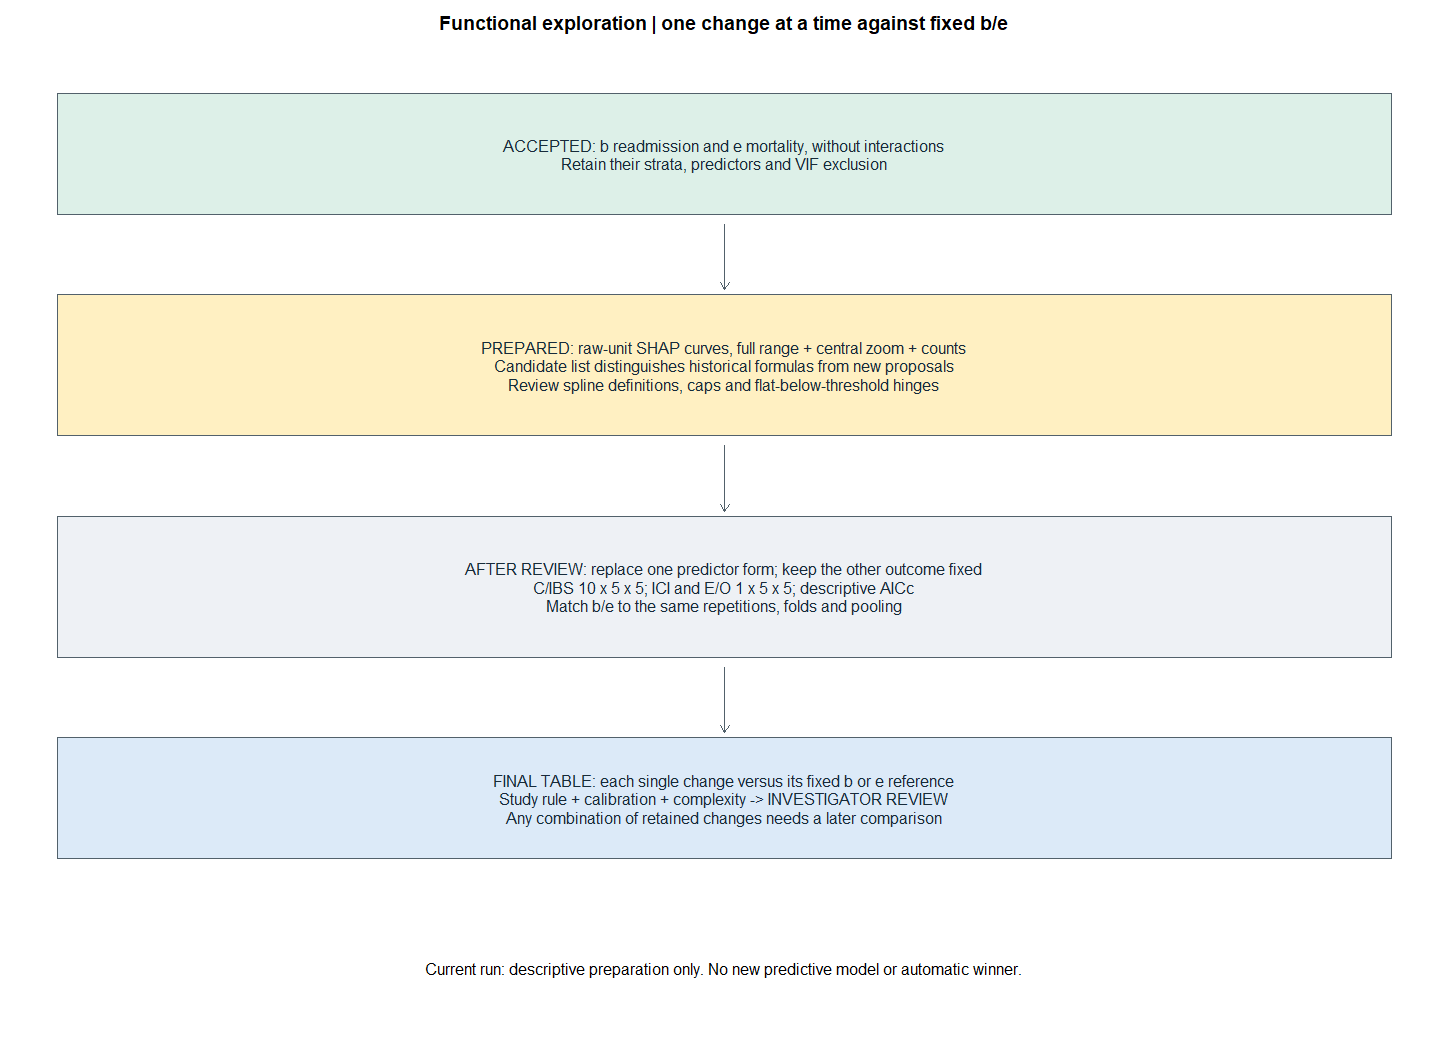

Nothing is promoted automatically. The new b age quadratic, spline definitions, and cap/hinge assumptions remain proposals for investigator review. The historical p-value screen is descriptive, not an independent proof of predictive improvement.


Elapsed: 0.002 minutes


In [73]:
#| label: shap-functional-candidate-register
#| message: true
.t0 <- proc.time()
# Keep original candidates visible and identify new proposals before any predictive comparison.
functional_candidates <- data.frame(Base = c("b", "b", "b", "b", "b", "b", "b", "b", "e", "e"), Predictor = c("adm_age_rec3", "adm_age_rec3", "dit_m", "dit_m", "dit_m", "dit_m", "porc_pobr", "porc_pobr", "adm_age_rec3", "adm_age_rec3"), Candidate = c("b_age_quadratic", "b_age_spline", "b_duration_log", "b_duration_quadratic", "b_duration_hinge5", "b_duration_spline", "b_poverty_hinge15", "b_poverty_spline", "e_age_quadratic", "e_age_spline"), Form = c("age + age^2", "Natural spline: historical A or complete B; definition pending", "log1p(min(duration, 36))", "min(duration, 36) + min(duration, 36)^2", "max(0, min(duration, 36) - 5)", "Natural spline of raw duration; definition pending", "max(0, poverty_proportion - 0.15)", "Natural spline; definition pending", "age + age^2", "Natural spline: historical A or complete B; definition pending"), Extra_coefficients = c(1L, 2L, 0L, 1L, 0L, 2L, 0L, 2L, 1L, 2L), Provenance = c("New proposal for b; not an original b formula", "Historical restricted construction; complete B is a new proposal", "Original b formula", "Original b formula", "Original b formula", "Original b formula uses raw duration, despite capped-spline comment", "Original b formula", "Original b formula", "Original e formula defined; simpler CV block evaluated spline only", "Historical restricted construction; complete B is a new proposal"), Priority = c("Proposed simple age comparator; investigator review", "Flexible comparator; A/B choice pending", "First simple duration comparator", "Second simple duration comparator", "Historical reserve; flat below 5 months", "Flexible comparator; definition pending", "Historical simple comparator; flat below 15%", "Flexible comparator; definition pending", "First simple mortality-age comparator", "Flexible comparator; A/B choice pending"), Status = "Prepared for review; not fitted", stringsAsFactors = FALSE)
stopifnot(!anyDuplicated(functional_candidates$Candidate), all(vapply(seq_len(nrow(functional_candidates)), function(i) functional_candidates$Predictor[i] %in% all.vars(functional_bases[[functional_candidates$Base[i]]]), logical(1L))))
functional_candidates$Reason_before_metrics <- c("Broad middle-age peak and decline; quadratic is a simple approximation to test", "Allow local age curvature while reviewing tail support and the basis definition", "Historical monotone alternative; cannot reproduce the entire early dip", "Initial dip followed by a rise; test a simple turning curve with the historical cap", "Historical five-month change; flat below the cutoff is an explicit assumption", "Allow local duration curvature; historical spline did not use the cap", "Historical rise around 15%; flat below the cutoff omits visible earlier variation", "Allow the nonmonotone poverty pattern without selecting an outcome threshold", "Mostly rising age pattern; test whether curvature merits an extra coefficient", "Allow local age curvature; no gain over the linear term is assumed")
show_table(functional_candidates, "Candidate register before evaluation; coefficient increments assume a full-rank fit")
show_table(data.frame(Predictor = c("adm_age_rec3", "dit_m", "porc_pobr"), Historical_interior_knots = c("Q05, Q35, Q65, Q95", "1.1, 3.9, 7.9, 19.3 months", "0.053, 0.105, 0.146, 0.261"), Historical_columns = "First three of five; boundary knots = observed range", Pending = c("Age A/B choice above", "Spline definition and historical cap reviewed before fitting", "Spline definition and flat-below-threshold hinge reviewed before fitting")), "Spline definitions are not silently repaired or selected")
show_table(data.frame(Later_branch = c("Full-mortality duration/poverty", "Categorical and ordinal recoding", "Combined transformations"), Scope = c("Historical d only; duration and poverty are not in retained e", "Keep for a separate later checkpoint; no continuous smoothing between categories", "Only after single-change results and investigator decisions; compare again against b/e")), "Original exploration retained as an audit trail, without expanding the current b/e predictor sets")
functional_result_columns <- c("Base", "Candidate", "Predictor", "Form", "Extra_coefficients", "Horizon_months", "Uno_C", "Delta_C", "Integrated_IBS", "Delta_IBS", "ICI", "E_O", "AICc", "Study_rule_by_horizon", "Investigator_decision")
show_table(data.frame(Section = c("Specification", "Main rule", "Supporting checks", "Decision"), Final_table_columns = c("Base b/e; predictor; exact transformation; extra coefficients; horizon", "Uno C and delta C; integrated IBS and delta IBS", "ICI; E/O (target 1); historical descriptive AICc", "Study rule by horizon; explicit investigator decision")), "Planned final comparison table; no unexecuted performance values are filled in")
show_diagnostic_png(function() {
  decision_canvas("Functional exploration | one change at a time against fixed b/e")
  decision_box(0.04, 0.96, 0.89, "ACCEPTED: b readmission and e mortality, without interactions\nRetain their strata, predictors and VIF exclusion", "accepted", h = 0.06)
  decision_arrow(0.5, 0.82, y2 = 0.755)
  decision_box(0.04, 0.96, 0.68, "PREPARED: raw-unit SHAP curves, full range + central zoom + counts\nCandidate list distinguishes historical formulas from new proposals\nReview spline definitions, caps and flat-below-threshold hinges", "prepared", h = 0.07)
  decision_arrow(0.5, 0.60, y2 = 0.535)
  decision_box(0.04, 0.96, 0.46, "AFTER REVIEW: replace one predictor form; keep the other outcome fixed\nC/IBS 10 x 5 x 5; ICI and E/O 1 x 5 x 5; descriptive AICc\nMatch b/e to the same repetitions, folds and pooling", "pending", h = 0.07)
  decision_arrow(0.5, 0.38, y2 = 0.315)
  decision_box(0.04, 0.96, 0.25, "FINAL TABLE: each single change versus its fixed b or e reference\nStudy rule + calibration + complexity -> INVESTIGATOR REVIEW\nAny combination of retained changes needs a later comparison", "review", h = 0.06)
  graphics::text(0.5, 0.08, "Current run: descriptive preparation only. No new predictive model or automatic winner.", cex = 0.85)
}, 1450L, 1050L)
functional_candidate_review_pending <- TRUE
functional_exploration_signature <- substr(digest::digest(list(functional_age_signature, functional_settings, functional_raw_artifact[[1L]]$sha256, functional_candidates, functional_support, functional_threshold_support), algo = "sha256"), 1L, 12L)
stopifnot(new_model_fits == 0L, new_ph_tests == 0L, performance_new_fits == 0L)
cat("Nothing is promoted automatically. The new b age quadratic, spline definitions, and cap/hinge assumptions remain proposals for investigator review. The historical p-value screen is descriptive, not an independent proof of predictive improvement.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

## Age in readmission: straight line versus the reviewed curve
Only age changes in accepted b. Mortality e, participants, strata, imputations and partitions remain fixed. The investigator approved the complete standard spline before computation. A completed comparison does not automatically replace b.


In [74]:
#| label: shap-functional-age-evaluate-contract
#| message: true
.t0 <- proc.time()
# Keep the selected construction explicit; missing approval leaves every fit disabled.
functional_age_method <- if (is.null(shap_settings$functional_age_method)) "pending" else shap_settings$functional_age_method
stopifnot(functional_age_method %in% c("pending", "complete", "historical"))
functional_age_enabled <- functional_age_method != "pending"
functional_age_complete <- FALSE
functional_age_comparison <- functional_age_rounding <- functional_age_repetitions <- functional_age_coverage <- functional_age_calibration_completeness <- functional_age_aicc <- data.frame()
functional_age_calibration <- list()
functional_age_evaluation_signature <- NULL
functional_age_evaluation_formula <- NULL
functional_age_new_predictive_fits <- functional_age_new_aicc_fits <- 0L
if (functional_age_enabled) {
  stopifnot(performance_new_fits == 0L, new_model_fits == 0L, new_ph_tests == 0L, shap_settings$interaction_mode == "mortality", identical(mortality_interaction_choice, "e"), identical(readmission_interaction_choice, "b"))
  stopifnot(all(functional_age_basis_audit$Age_identical_to_first_imputation), all(functional_age_basis_audit$Original_retained_columns == 3L), all(functional_age_basis_audit$Proposed_complete_columns == 3L))
  age <- py_corrected_datasets[[1L]]$adm_age_rec3
  age_knots <- as.numeric(stats::quantile(age, c(0.05, 0.35, 0.65, 0.95), names = FALSE))
  literal <- function(x) paste(format(x, digits = 17, scientific = FALSE, trim = TRUE), collapse = ", ")
  age_term <- if (functional_age_method == "complete") sprintf("splines::ns(adm_age_rec3, knots = c(%s), Boundary.knots = c(%s))", literal(age_knots[2:3]), literal(age_knots[c(1L, 4L)])) else sprintf("I(splines::ns(adm_age_rec3, knots = c(%s), Boundary.knots = c(%s))[, 1:3])", literal(age_knots), literal(range(age)))
  functional_age_evaluation_formula <- stats::update(functional_bases$b, stats::as.formula(paste(". ~ . - adm_age_rec3 +", age_term)))
  stopifnot(identical(formula_strata(functional_age_evaluation_formula), formula_strata(functional_bases$b)), setequal(all.vars(functional_age_evaluation_formula), all.vars(functional_bases$b)), !removed_collinear %in% all.vars(functional_age_evaluation_formula))
  generated_basis <- eval(parse(text = age_term), envir = py_corrected_datasets[[1L]])
  expected_basis <- if (functional_age_method == "complete") splines::ns(age, knots = age_knots[2:3], Boundary.knots = age_knots[c(1L, 4L)]) else splines::ns(age, knots = age_knots)[, 1:3, drop = FALSE]
  stopifnot(ncol(generated_basis) == 3L, max(abs(generated_basis - expected_basis)) < 1e-12, all(is.finite(generated_basis)))
  performance_formulas$readmission$functional_age <- functional_age_evaluation_formula
  functional_age_c_key <- performance_formula_key("readmission", "functional_age")
  branch_code <- performance_code[vapply(performance_code, function(x) any(vapply(c("shap-functional-age-calibration", "shap-functional-age-aicc"), function(label) startsWith(x, paste0("#| label: ", label, "\n")), logical(1L))), logical(1L))]
  stopifnot(length(branch_code) == 2L)
  functional_age_evaluation_signature <- substr(digest::digest(list(performance_signature, functional_settings, functional_age_method, age_knots, deparse(functional_age_evaluation_formula), deparse(functional_bases$e), calibration_rng, branch_code), algo = "sha256"), 1L, 12L)
  functional_age_prefix <- paste0("functional_age_", functional_age_evaluation_signature)
  functional_age_baseline_prefix <- interaction_baseline_calibration$prefix
  stopifnot(identical(interaction_baseline_calibration$pair, "death_physical"), identical(candidate_formulas$death$physical_stratum, functional_bases$e))
  functional_age_original_allowed <- interaction_allowed
  # Reviewed age comparisons are cache-only; a missing artifact must not restart a rejected candidate.
  if (is.null(shap_settings$functional_age_decision)) {
    interaction_allowed <- c(interaction_allowed, paste0("metrics_", functional_age_c_key, "_r"), paste0("oof_", functional_age_c_key, "_r"), functional_age_prefix)
  } else stopifnot(identical(shap_settings$functional_age_decision$signature, functional_age_evaluation_signature), identical(shap_settings$functional_age_decision$choice, "b_linear"))
  # Confirm all previous first-repetition prediction caches exist; missing references must never be refitted here.
  for (k in seq_len(5L)) {
    hit <- list.files(object_dir, pattern = paste0("^perf07_", functional_age_baseline_prefix, sprintf("_r01_f%02d", k), "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE)
    stopifnot(length(hit) == 1L)
  }
  functional_age_method_review_pending <- FALSE
  show_table(data.frame(Model = c("b: straight age", "b: reviewed age curve"), Formula = c(paste(deparse(functional_bases$b), collapse = " "), paste(deparse(functional_age_evaluation_formula), collapse = " ")), Mortality_partner = "e unchanged"), "Exact age-only comparison; the reviewed method is a candidate, not a winner")
  cat("Method:", functional_age_method, "| C/IBS 10 x 5 x 5 | ICI/E/O 1 x 5 x 5 | Descriptive AICc across five imputations", fill = TRUE)
  cat("Uncached budget: 250 candidate C/IBS fits, 50 candidate AJ fits, and 9 descriptive AICc fits. Baseline C/IBS, first-repetition AJ predictions and first-imputation b fit are reused. Knots are frozen from development, without outcomes; this does not claim independent preprocessing inside CV.", fill = TRUE)
  cat("Available RAM GiB:", ps::ps_system_memory()$avail / 1024^3, "| Reserve GiB:", shap_settings$reserve_memory_gib, "| Maximum C/IBS workers:", performance_settings$workers, "| Native threads per worker: 1", fill = TRUE)
} else cat("Ready to compare age. Select complete or historical in the configuration after investigator review; no fit is enabled.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Model,Formula,Mortality_partner
b: straight age,"Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + adm_age_rec3 + porc_pobr + sex_rec_woman + ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + evaluacindelprocesoteraputico_logro_intermedio + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)",e unchanged
b: reviewed age curve,"Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + porc_pobr + sex_rec_woman + ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + evaluacindelprocesoteraputico_logro_intermedio + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet) + splines::ns(adm_age_rec3, knots = c(30.06, 39.02), Boundary.knots = c(21.09, 55.33))",e unchanged


Method: complete 
| C/IBS 10 x 5 x 5 | ICI/E/O 1 x 5 x 5 | Descriptive AICc across five imputations
Uncached budget: 250 candidate C/IBS fits, 50 candidate AJ fits, and 9 descriptive AICc fits. Baseline C/IBS, first-repetition AJ predictions and first-imputation b fit are reused. Knots are frozen from development, without outcomes; this does not claim independent preprocessing inside CV.
Available RAM GiB: 56.53966 | Reserve GiB: 20 | Maximum C/IBS workers: 8 
| Native threads per worker: 1


Elapsed: 0.014 minutes


In [75]:
#| label: shap-functional-age-c-ibs
#| message: true
.t0 <- proc.time()
# Reuse the unchanged pooled out-of-fold C and Graf-integrated IBS engine.
if (functional_age_enabled) {
  before_fits <- performance_new_fits
  results <- performance_parallel(lapply(seq_len(10L), function(r) list(Outcome = "readmission", Stage = "functional_age", Repetition = r)))
  for (result in results) { record_performance_fits(result$new_fits); written <- c(written, result$written) }
  functional_age_new_predictive_fits <- functional_age_new_predictive_fits + performance_new_fits - before_fits
  functional_age_repetitions <- do.call(rbind, lapply(results, function(x) x$table))
  functional_age_coverage <- do.call(rbind, lapply(results, function(x) x$coverage))
  stopifnot(nrow(functional_age_repetitions) == 40L, !anyDuplicated(functional_age_repetitions[, c("Repetition", "Horizon")]), all(is.finite(as.matrix(functional_age_repetitions[, c("C", "IBS")]))), nrow(functional_age_coverage) == 10L, all(functional_age_coverage$Expected == functional_age_coverage$Predicted), all(functional_age_coverage$Omitted == 0L))
  paired <- merge(readmission_step_repetitions, functional_age_repetitions, by = c("Repetition", "Horizon"), suffixes = c("_b", "_curve"))
  stopifnot(nrow(paired) == 40L)
  paired$Delta_C <- paired$C_curve - paired$C_b
  paired$Delta_IBS <- paired$IBS_curve - paired$IBS_b
  functional_age_comparison <- stats::aggregate(cbind(C_b, C_curve, Delta_C, IBS_b, IBS_curve, Delta_IBS) ~ Horizon, paired, mean)
  show_table(functional_age_comparison, "Readmission age: curve minus accepted b; same ten partitions")
} else cat("Age C/IBS not run: curve construction pending.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Horizon,C_b,C_curve,Delta_C,IBS_b,IBS_curve,Delta_IBS
6,0.6457,0.6454,-0.0003,0.0387,0.0386,0e+00
12,0.6327,0.6330,0.0003,0.0610,0.0610,0e+00
36,0.6144,0.6152,0.0007,0.1085,0.1084,0e+00
60,0.6093,0.6104,0.0011,0.1333,0.1332,-1e-04


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.164 minutes


In [76]:
#| label: shap-functional-age-calibration
#| message: true
.t0 <- proc.time()
# Recalculate both one-repetition calibration summaries using the intact AJ engine.
functional_age_calibration_task <- function(task) {
  before_fits <- performance_new_fits
  before_written <- written
  previous_rng <- RNGkind()
  on.exit(do.call(RNGkind, as.list(previous_rng)), add = TRUE)
  do.call(RNGkind, as.list(calibration_rng))
  formula <- if (task$Model == "b") functional_bases$b else functional_age_evaluation_formula
  prefix <- if (task$Model == "b") functional_age_baseline_prefix else paste0(functional_age_prefix, "_aj_curve")
  key <- paste0(functional_age_prefix, "_summary_r01_", task$Model)
  value <- performance_cache(key, function() calibrate_cscox_aj_grouped_corr(formula_readmit = formula, formula_death = functional_bases$e, data = py_corrected_datasets, times = performance_horizons, n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = 1L, compute_ici = TRUE, ici_times = performance_horizons, g = 10L, min_bin_n = 20L, ici_span = 0.75, tie_action = "death_first", seed = performance_settings$seed, make_plots = FALSE, parallel_cv = FALSE, parallel_calibration = FALSE, verbose = FALSE, cache_prefix = prefix))
  if (task$Model == "b") stopifnot(performance_new_fits == before_fits)
  list(model = task$Model, prefix = prefix, value = value, new_fits = performance_new_fits - before_fits, written = setdiff(written, before_written))
}
if (functional_age_enabled) {
  before_fits <- performance_new_fits
  results <- performance_parallel(list(list(Model = "b"), list(Model = "curve")), worker = functional_age_calibration_task)
  for (result in results) {
    record_performance_fits(result$new_fits)
    written <- c(written, result$written)
    functional_age_calibration[[result$model]] <- result
    z <- result$value$by_repetition
    stopifnot(result$value$settings$n_repeats == 1L, nrow(z) == length(performance_horizons), all(is.finite(as.matrix(z[, c("ici", "eo_ratio")]))), all(z$n_input == nrow(py_corrected_datasets[[1L]])), all(z$n_analysis == z$n_input), all(z$n_dropped == 0L), all(z$n_used_calibration == z$n_input), all(z$n_excluded_calibration == 0L))
  }
  functional_age_new_predictive_fits <- functional_age_new_predictive_fits + performance_new_fits - before_fits
  indices <- integer()
  risk_range <- c(Inf, -Inf)
  zero_risks <- 0L
  for (k in seq_len(5L)) {
    objects <- lapply(functional_age_calibration, function(x) {
      paths <- list.files(object_dir, pattern = paste0("^perf07_", x$prefix, sprintf("_r01_f%02d", k), "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE)
      stopifnot(length(paths) == 1L)
      saved <- readRDS(paths[[1L]])
      stopifnot(identical(saved$signature, performance_signature))
      saved$value
    })
    stopifnot(identical(objects$b$te_idx, objects$curve$te_idx), all(vapply(objects, function(x) all(is.finite(x$pred_fold_avg)) && all(x$pred_fold_avg >= 0 & x$pred_fold_avg <= 1), logical(1L))))
    indices <- c(indices, objects$curve$te_idx)
    risk_range <- range(risk_range, objects$curve$pred_fold_avg, finite = TRUE)
    zero_risks <- zero_risks + sum(objects$curve$pred_fold_avg == 0)
  }
  stopifnot(length(indices) == nrow(py_corrected_datasets[[1L]]))
  assert_prediction_coverage(tabulate(indices, nbins = nrow(py_corrected_datasets[[1L]])))
  functional_age_calibration_completeness <- data.frame(Participants = length(indices), Repetitions = 1L, Paired_folds = 5L, Omitted = 0L, Minimum_risk = risk_range[1L], Maximum_risk = risk_range[2L], Zero_risk_entries = zero_risks)
  before <- functional_age_calibration$b$value$pooled_summary
  after <- functional_age_calibration$curve$value$pooled_summary
  stopifnot(identical(before$time_months, after$time_months))
  calibration_table <- data.frame(Horizon = before$time_months, ICI_b = before$ici_mean, ICI_curve = after$ici_mean, Delta_ICI = after$ici_mean - before$ici_mean, EO_b = before$eo_mean, EO_curve = after$eo_mean, Delta_EO = after$eo_mean - before$eo_mean)
  functional_age_comparison <- merge(functional_age_comparison, calibration_table, by = "Horizon")
  show_table(calibration_table, "Readmission calibration: same single repetition for b and the age curve; not the earlier twenty-repeat average")
  show_table(functional_age_calibration_completeness, "All participants retained; no fallback or automatic exclusion")
} else cat("Age calibration not run: curve construction pending.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Horizon,ICI_b,ICI_curve,Delta_ICI,EO_b,EO_curve,Delta_EO
6,0.0070,0.0067,-3e-04,0.9910,0.9908,-2e-04
12,0.0077,0.0080,3e-04,0.9912,0.9910,-3e-04
36,0.0092,0.0092,-1e-04,0.9893,0.9889,-4e-04
60,0.0094,0.0098,4e-04,0.9860,0.9853,-7e-04


Participants,Repetitions,Paired_folds,Omitted,Minimum_risk,Maximum_risk,Zero_risk_entries
70521,1,5,0,0.0154,0.8227,0


Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.164 minutes


In [77]:
#| label: shap-functional-age-aicc
#| message: true
.t0 <- proc.time()
# Preserve the original descriptive AICc calculation; do not treat its mean as a pooled inferential test.
if (functional_age_enabled) {
  before_fits <- performance_new_fits
  rows <- lapply(c("b", "curve"), function(model) performance_cache(paste0(functional_age_prefix, "_aicc_", model), function() {
    formula <- if (model == "b") functional_bases$b else functional_age_evaluation_formula
    do.call(rbind, lapply(seq_along(py_corrected_datasets), function(i) {
      reuse <- model == "b" && i == 1L
      fit <- if (reuse) sequential_diagnostics[["readmission_discharge_stratum"]]$fit else survival::coxph(formula, data = py_corrected_datasets[[i]], ties = "efron", na.action = stats::na.fail)
      stopifnot(identical(formula_terms(stats::formula(fit)), formula_terms(formula)))
      k <- length(stats::coef(fit))
      events <- fit$nevent
      stopifnot(fit$n == nrow(py_corrected_datasets[[i]]), events > k + 1L, all(is.finite(stats::coef(fit))))
      correction <- 2 * k * (k + 1) / (events - k - 1)
      if (!reuse) record_performance_fits(1L)
      data.frame(Model = model, Imputation = i, N = fit$n, Events = events, Coefficients = k, AIC = stats::AIC(fit), Correction = correction, AICc = stats::AIC(fit) + correction)
    }))
  }))
  functional_age_new_aicc_fits <- performance_new_fits - before_fits
  functional_age_aicc <- do.call(rbind, rows)
  stopifnot(nrow(functional_age_aicc) == 10L, all(functional_age_aicc$Coefficients[functional_age_aicc$Model == "curve"] - functional_age_aicc$Coefficients[functional_age_aicc$Model == "b"] == 2L))
  show_table(stats::aggregate(cbind(Coefficients, AIC, Correction, AICc) ~ Model, functional_age_aicc, mean), "Descriptive AICc: original event-based correction, averaged over five imputations; lower is favourable")
} else cat("Age AICc not run: curve construction pending.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Model,Coefficients,AIC,Correction,AICc
b,26,272577.9,0.0922,272578.0
curve,28,272519.5,0.1067,272519.6


Elapsed: 0.006 minutes


Horizon,C_b,C_curve,Delta_C,IBS_b,IBS_curve,Delta_IBS,ICI_b,ICI_curve,Delta_ICI,EO_b,EO_curve,Delta_EO,Study_rule_met,Investigator_decision
6,0.6457,0.6454,-0.0003,0.0387,0.0386,0e+00,0.0070,0.0067,-3e-04,0.9910,0.9908,-2e-04,FALSE,Confirmed: retain b with linear age; e unchanged
12,0.6327,0.6330,0.0003,0.0610,0.0610,0e+00,0.0077,0.0080,3e-04,0.9912,0.9910,-3e-04,FALSE,Confirmed: retain b with linear age; e unchanged
36,0.6144,0.6152,0.0007,0.1085,0.1084,0e+00,0.0092,0.0092,-1e-04,0.9893,0.9889,-4e-04,FALSE,Confirmed: retain b with linear age; e unchanged
60,0.6093,0.6104,0.0011,0.1333,0.1332,-1e-04,0.0094,0.0098,4e-04,0.9860,0.9853,-7e-04,FALSE,Confirmed: retain b with linear age; e unchanged


Horizon,Metric,Previous_b,New_curve,Difference,Previous_rounded,New_rounded,Classification,Review
6,C,0.6457,0.6454,-0.0003,0.646,0.645,Substantial rounding change; review,Reviewed: keep b with linear age; candidate not retained
12,C,0.6327,0.6330,0.0003,0.633,0.633,Trivial at displayed precision,Reviewed: keep b with linear age; candidate not retained
36,C,0.6144,0.6152,0.0007,0.614,0.615,Substantial rounding change; review,Reviewed: keep b with linear age; candidate not retained
60,C,0.6093,0.6104,0.0011,0.609,0.610,Substantial rounding change; review,Reviewed: keep b with linear age; candidate not retained
6,IBS,0.0387,0.0386,0.0000,0.039,0.039,Trivial at displayed precision,Reviewed: keep b with linear age; candidate not retained
12,IBS,0.0610,0.0610,0.0000,0.061,0.061,Trivial at displayed precision,Reviewed: keep b with linear age; candidate not retained
36,IBS,0.1085,0.1084,0.0000,0.108,0.108,Trivial at displayed precision,Reviewed: keep b with linear age; candidate not retained
60,IBS,0.1333,0.1332,-0.0001,0.133,0.133,Trivial at displayed precision,Reviewed: keep b with linear age; candidate not retained
6,ICI,0.0070,0.0067,-0.0003,0.007,0.007,Trivial at displayed precision,Reviewed: keep b with linear age; candidate not retained
12,ICI,0.0077,0.0080,0.0003,0.008,0.008,Trivial at displayed precision,Reviewed: keep b with linear age; candidate not retained


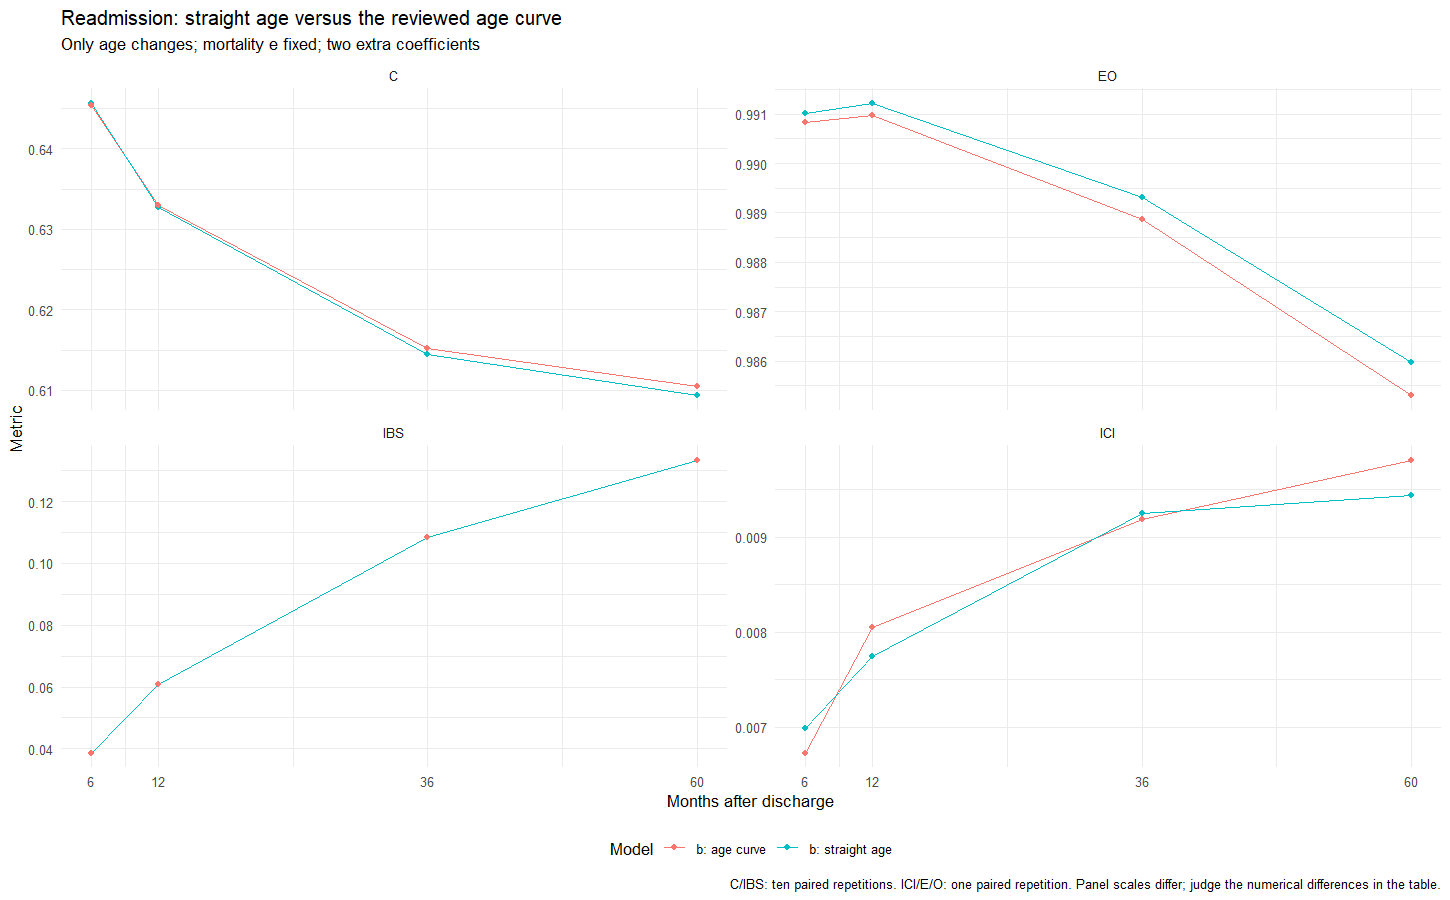

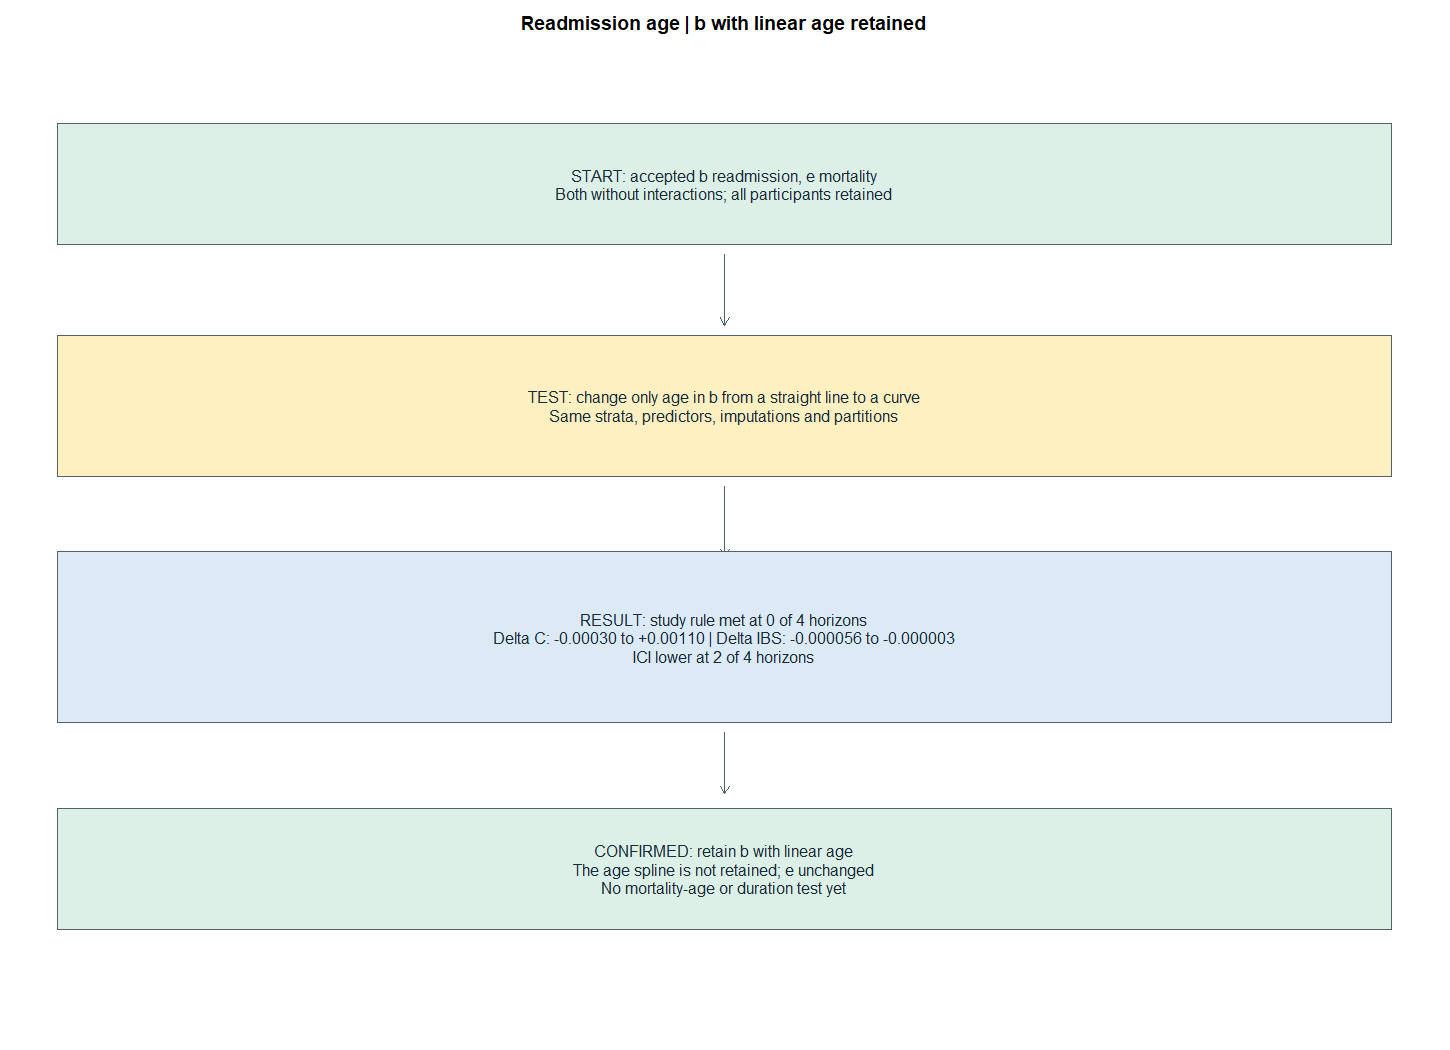

Age comparison finished. Predictive fits this run: 0 | Descriptive AICc fits: 0 
| No new PH/VIF, bootstrap, imputation, tuning or TreeSHAP.


Elapsed: 0.009 minutes


In [78]:
#| label: shap-functional-age-results-checkpoint
#| message: true
.t0 <- proc.time()
# Apply only the recorded decision for this exact comparison; keep other candidate reviews pending.
functional_age_decision <- shap_settings$functional_age_decision
functional_age_review_accepted <- !is.null(functional_age_decision) && identical(functional_age_decision$signature, functional_age_evaluation_signature) && identical(functional_age_decision$choice, "b_linear")
if (!is.null(functional_age_decision)) stopifnot(functional_age_review_accepted, functional_age_enabled)
if (functional_age_enabled) {
  stopifnot(nrow(functional_age_comparison) == 4L, all(is.finite(as.matrix(functional_age_comparison))), all(functional_age_coverage$Omitted == 0L), all(functional_age_calibration_completeness$Omitted == 0L), new_model_fits == 0L, new_ph_tests == 0L)
  functional_age_comparison$Study_rule_met <- functional_age_comparison$Delta_C >= functional_settings$c_gain & functional_age_comparison$Delta_IBS <= functional_settings$ibs_tolerance
  functional_age_comparison$Investigator_decision <- if (functional_age_review_accepted) "Confirmed: retain b with linear age; e unchanged" else "Pending; b/e remain retained"
  functional_age_rounding <- do.call(rbind, lapply(c("C", "IBS", "ICI", "EO"), function(metric) {
    digits <- if (metric == "EO") 2L else 3L
    previous <- functional_age_comparison[[paste0(metric, "_b")]]
    candidate <- functional_age_comparison[[paste0(metric, "_curve")]]
    data.frame(Horizon = performance_horizons, Metric = metric, Previous_b = previous, New_curve = candidate, Difference = candidate - previous, Previous_rounded = round(previous, digits), New_rounded = round(candidate, digits), Classification = ifelse(round(previous, digits) == round(candidate, digits), "Trivial at displayed precision", "Substantial rounding change; review"))
  }))
  functional_age_rounding$Review <- if (functional_age_review_accepted) "Reviewed: keep b with linear age; candidate not retained" else "Investigator review pending"
  show_table(functional_age_comparison, "Does the age curve improve b enough? C higher; IBS/ICI lower; E/O closer to one")
  show_table(functional_age_rounding, "Within-run candidate comparison at Table 2 precision; no manuscript value is replaced")
  long <- do.call(rbind, lapply(c("C", "IBS", "ICI", "EO"), function(metric) do.call(rbind, lapply(c("b", "curve"), function(model) data.frame(Horizon = performance_horizons, Metric = metric, Model = if (model == "b") "b: straight age" else "b: age curve", Value = functional_age_comparison[[paste0(metric, "_", model)]])))))
  plot <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Model, group = Model)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(~Metric, scales = "free_y", ncol = 2L) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "Readmission: straight age versus the reviewed age curve", subtitle = "Only age changes; mortality e fixed; two extra coefficients", x = "Months after discharge", y = "Metric", color = "Model", caption = "C/IBS: ten paired repetitions. ICI/E/O: one paired repetition. Panel scales differ; judge the numerical differences in the table.") + ggplot2::theme_minimal(base_size = 11) + ggplot2::theme(legend.position = "bottom")
  show_diagnostic_png(function() print(plot), 1450L, 900L)
  show_diagnostic_png(function() {
    decision_canvas(if (functional_age_review_accepted) "Readmission age | b with linear age retained" else "Readmission age | comparison complete, your decision next")
    decision_box(0.04, 0.96, 0.86, "START: accepted b readmission, e mortality\nBoth without interactions; all participants retained", "accepted", h = 0.06)
    decision_arrow(0.5, 0.79, y2 = 0.72)
    decision_box(0.04, 0.96, 0.64, "TEST: change only age in b from a straight line to a curve\nSame strata, predictors, imputations and partitions", "prepared", h = 0.07)
    decision_arrow(0.5, 0.56, y2 = 0.49)
    decision_box(0.04, 0.96, 0.41, sprintf("RESULT: study rule met at %d of %d horizons\nDelta C: %+.5f to %+.5f | Delta IBS: %+.6f to %+.6f\nICI lower at %d of %d horizons", sum(functional_age_comparison$Study_rule_met), nrow(functional_age_comparison), min(functional_age_comparison$Delta_C), max(functional_age_comparison$Delta_C), min(functional_age_comparison$Delta_IBS), max(functional_age_comparison$Delta_IBS), sum(functional_age_comparison$Delta_ICI < 0), nrow(functional_age_comparison)), "review", h = 0.085)
    decision_arrow(0.5, 0.315, y2 = 0.255)
    decision_box(0.04, 0.96, 0.18, if (functional_age_review_accepted) "CONFIRMED: retain b with linear age\nThe age spline is not retained; e unchanged\nNo mortality-age or duration test yet" else "REVIEW: keep b or retain its age curve\nNo automatic replacement; no mortality-age or duration test yet", if (functional_age_review_accepted) "accepted" else "pending", h = 0.06)
  }, 1450L, 1050L)
  functional_age_complete <- TRUE
  functional_candidates$Status[functional_candidates$Candidate == "b_age_spline"] <- if (functional_age_review_accepted) "Evaluated; not retained: keep linear age in b" else "Evaluated; investigator decision pending"
  functional_candidates$Form[functional_candidates$Candidate == "b_age_spline"] <- paste(deparse(functional_age_evaluation_formula), collapse = " ")
  cat("Age comparison finished. Predictive fits this run:", functional_age_new_predictive_fits, "| Descriptive AICc fits:", functional_age_new_aicc_fits, "| No new PH/VIF, bootstrap, imputation, tuning or TreeSHAP.", fill = TRUE)
  interaction_allowed <- functional_age_original_allowed
}
review_pending <- TRUE
# The age decision is complete; further functional candidates still require their own review.
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


## Mortality age: comparison complete; linear age retained
Readmission b retains linear age. The evaluated candidate changes only age in accepted mortality e, using the complete three-column natural spline already audited above. Its numeric knots remain fixed from development without outcomes; the accepted within-CV preprocessing limitation remains. The original e-specific CV contrast was linear versus spline. The earlier quadratic-age proposals were not pursued after linear age was confirmed; they are not reported as executed comparisons.
The investigator confirmed the early-discard screen: mean paired delta C below 0.005 and absolute mean paired delta IBS below 0.001 at every horizon, with no clear advantage in the short ICI/E:O review. This is an operational rule, not equivalence; the primary 0.01/0.001 selection rule remains unchanged. The following blocks are runnable but candidate fitting is disabled in preparation mode. A candidate rejected here does not automatically require bootstrap or a further comparison in 225; that later stage concerns retained models and candidates judged worth further evaluation.

**Model fitting completed:** 2026-10-08T22:51:28.390869-03:00. The complete comparison fitted 325 predictive models and nine descriptive AICc models in 8.49 minutes; peak sampled R memory was 9.96 GiB. Later replays reuse those results and may report zero **new** fits. The original fitting record is preserved separately in `docs/07_mortality_age_execution.json`. **Investigator decision, 2026-10-08T23:19:48-03:00: retain e with linear age.** The small ICI and AICc gains were reviewed and did not justify two extra coefficients. b remains linear. The rejected age curve replays from cache only and needs no duplicate comparison in 225. The subsequent section reports the separately authorized remaining comparisons.

Model,Formula,Added_coefficients,Readmission_partner,Status
"e: accepted, linear age","Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo + eva_fisica_logro_intermedio + eva_fisica_logro_minimo + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + sex_rec_woman + strata(plan_type_strata) + strata(any_phys_dx)",0,"b fixed, linear age",Retained
e: proposed complete age spline,"Surv(death_time_from_disch_m, death_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo + eva_fisica_logro_intermedio + eva_fisica_logro_minimo + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + sex_rec_woman + strata(plan_type_strata) + strata(any_phys_dx) + splines::ns(adm_age_rec3, knots = c(30.06, 39.02), Boundary.knots = c(21.09, 55.33))",2,"b fixed, linear age",Prepared only; not fitted


Component,Scheme,Future_new_fits
Mortality C / Graf integrated IBS,10 x 5 x 5,250
Mortality KM ICI and E/O,1 x 5 x 5,25
Readmission AJ ICI and E/O with b fixed,1 x 5 x 5; both cause-specific models,50
Descriptive AICc,Five imputations; reuse e first-imputation fit,9


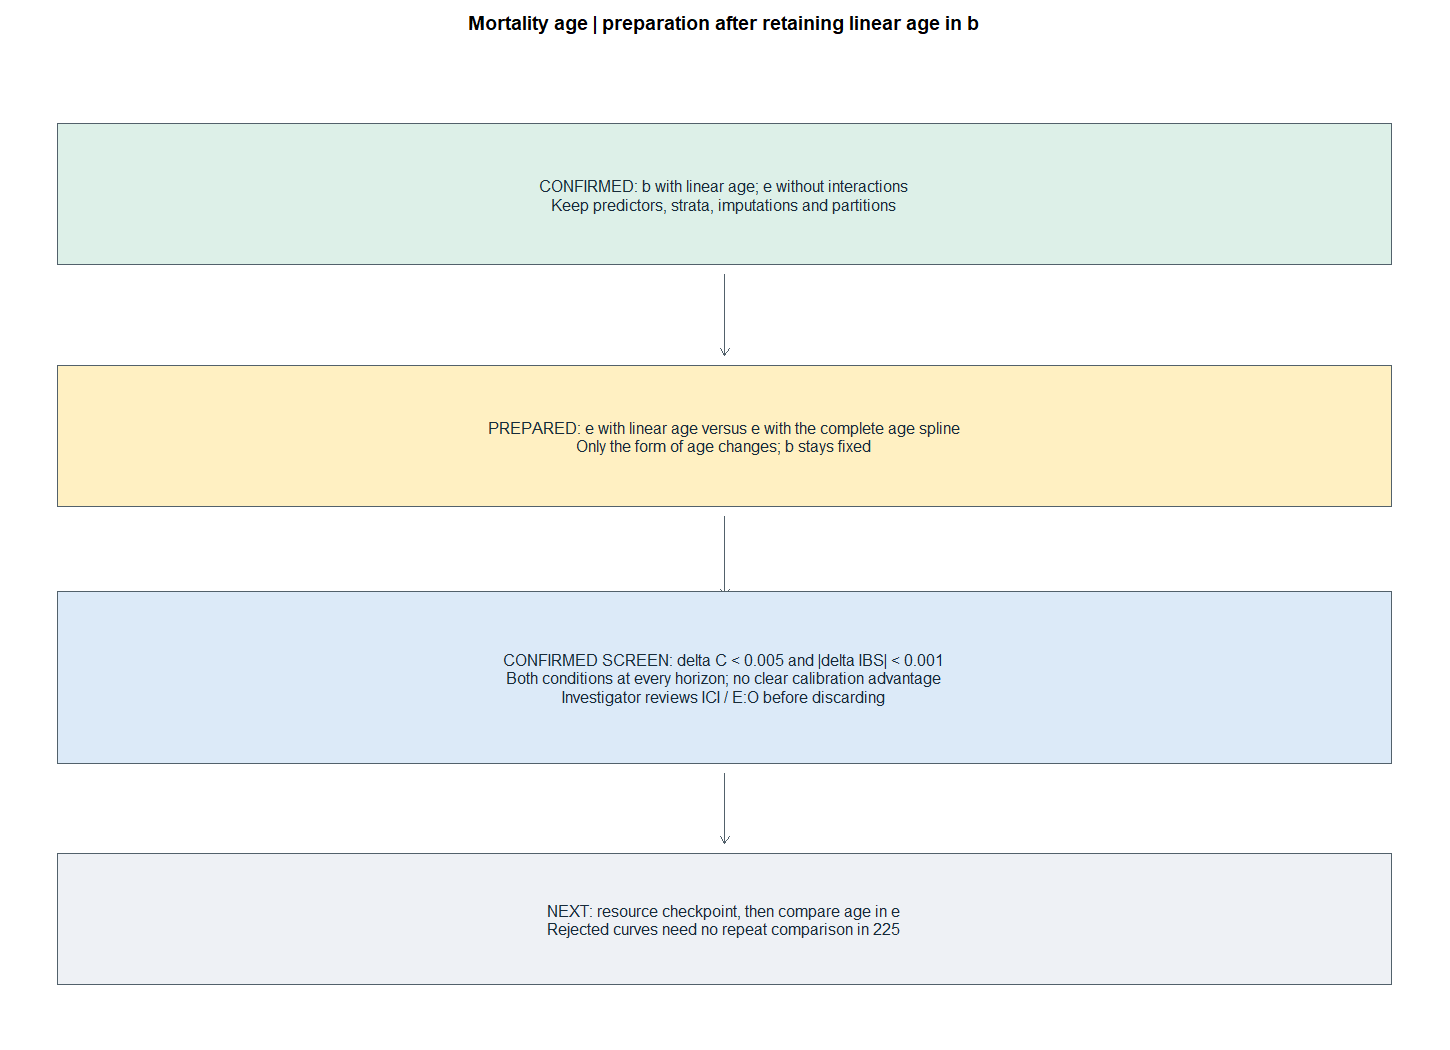

The original e-specific CV compared linear age with its historical spline; quadratic age had descriptive AICc but no corresponding e-specific CV. The proposed complete spline is explicit, not a claim to reproduce that restricted historical basis.


Primary selection rule unchanged: delta C >= 0.01 and delta IBS <= 0.001. The confirmed early-discard screen uses delta C < 0.005 and absolute delta IBS < 0.001 at every horizon, plus investigator review of short calibration; no rule implies statistical equivalence. Retained models and genuinely promising candidates can proceed to 225; rejected candidates do not require duplicate testing.


Available RAM GiB: 56.52118 | Reserve GiB: 20 | Future maximum C/IBS workers: 8 
| Native threads per worker: 1


Elapsed: 0.001 minutes


In [79]:
#| label: shap-mortality-age-preparation
#| message: true
.t0 <- proc.time()
# Prepare the original mortality CV contrast with the complete basis already audited for age.
stopifnot(functional_age_review_accepted, identical(functional_age_decision$choice, "b_linear"), identical(functional_age_method, "complete"), mortality_interaction_review_accepted, performance_new_fits == 0L)
mortality_age_prepared <- TRUE
mortality_age_candidate <- stats::update(functional_bases$e, stats::as.formula(paste(". ~ . - adm_age_rec3 +", age_term)))
stopifnot(identical(formula_strata(mortality_age_candidate), formula_strata(functional_bases$e)), setequal(all.vars(mortality_age_candidate), all.vars(functional_bases$e)), !removed_collinear %in% all.vars(mortality_age_candidate))
mortality_age_plan <- data.frame(Model = c("e: accepted, linear age", "e: proposed complete age spline"), Formula = c(paste(deparse(functional_bases$e), collapse = " "), paste(deparse(mortality_age_candidate), collapse = " ")), Added_coefficients = c(0L, 2L), Readmission_partner = "b fixed, linear age", Status = c("Retained", "Prepared only; not fitted"))
show_table(mortality_age_plan, "Mortality age: same predictors and setting + physical-comorbidity strata; no interactions")
mortality_age_budget <- data.frame(Component = c("Mortality C / Graf integrated IBS", "Mortality KM ICI and E/O", "Readmission AJ ICI and E/O with b fixed", "Descriptive AICc"), Scheme = c("10 x 5 x 5", "1 x 5 x 5", "1 x 5 x 5; both cause-specific models", "Five imputations; reuse e first-imputation fit"), Future_new_fits = c(250L, 25L, 50L, 9L))
show_table(mortality_age_budget, "Budget only; no new model is enabled by this preparation")
show_diagnostic_png(function() {
  decision_canvas("Mortality age | preparation after retaining linear age in b")
  decision_box(0.04, 0.96, 0.85, "CONFIRMED: b with linear age; e without interactions\nKeep predictors, strata, imputations and partitions", "accepted", h = 0.07)
  decision_arrow(0.5, 0.77, y2 = 0.69)
  decision_box(0.04, 0.96, 0.61, "PREPARED: e with linear age versus e with the complete age spline\nOnly the form of age changes; b stays fixed", "prepared", h = 0.07)
  decision_arrow(0.5, 0.53, y2 = 0.45)
  decision_box(0.04, 0.96, 0.37, "CONFIRMED SCREEN: delta C < 0.005 and |delta IBS| < 0.001\nBoth conditions at every horizon; no clear calibration advantage\nInvestigator reviews ICI / E:O before discarding", "review", h = 0.085)
  decision_arrow(0.5, 0.275, y2 = 0.205)
  decision_box(0.04, 0.96, 0.13, "NEXT: resource checkpoint, then compare age in e\nRejected curves need no repeat comparison in 225", "pending", h = 0.065)
}, 1450L, 1050L)
cat("The original e-specific CV compared linear age with its historical spline; quadratic age had descriptive AICc but no corresponding e-specific CV. The proposed complete spline is explicit, not a claim to reproduce that restricted historical basis.", fill = TRUE)
cat("Primary selection rule unchanged: delta C >= 0.01 and delta IBS <= 0.001. The confirmed early-discard screen uses delta C < 0.005 and absolute delta IBS < 0.001 at every horizon, plus investigator review of short calibration; no rule implies statistical equivalence. Retained models and genuinely promising candidates can proceed to 225; rejected candidates do not require duplicate testing.", fill = TRUE)
cat("Available RAM GiB:", ps::ps_system_memory()$avail / 1024^3, "| Reserve GiB:", shap_settings$reserve_memory_gib, "| Future maximum C/IBS workers:", performance_settings$workers, "| Native threads per worker: 1", fill = TRUE)
stopifnot(performance_new_fits == 0L, new_model_fits == 0L, new_ph_tests == 0L)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


In [80]:
#| label: shap-mortality-age-contract
#| message: true
.t0 <- proc.time()
# Keep the confirmed screen separate from the unchanged primary selection rule and cached comparisons.
functional_discard <- shap_settings$functional_early_discard
stopifnot(isTRUE(functional_discard$confirmed), functional_discard$c_gain_upper == 0.005, functional_discard$ibs_absolute_upper == 0.001, identical(functional_discard$calibration_review, "investigator"))
functional_early_screen <- function(delta_c, delta_ibs) {
  stopifnot(length(delta_c) == 4L, length(delta_ibs) == 4L, all(is.finite(c(delta_c, delta_ibs))))
  all(delta_c < functional_discard$c_gain_upper) && all(abs(delta_ibs) < functional_discard$ibs_absolute_upper)
}
# Boundary checks prevent a large IBS improvement or a threshold-equal C gain from being discarded automatically.
stopifnot(functional_early_screen(rep(0.004, 4L), rep(-0.0005, 4L)), !functional_early_screen(c(0.005, rep(0, 3L)), rep(0, 4L)), !functional_early_screen(rep(0, 4L), c(-0.001, rep(0, 3L))), !functional_early_screen(rep(0, 4L), c(0.001, rep(0, 3L))))
mortality_age_mode <- shap_settings$mortality_age_mode
stopifnot(mortality_age_mode %in% c("prepare", "run"), performance_settings$mode == "prepare")
mortality_age_run <- identical(mortality_age_mode, "run")
mortality_age_complete <- FALSE
mortality_age_comparison <- mortality_age_repetitions <- mortality_age_coverage <- mortality_age_rounding <- mortality_age_aicc <- mortality_age_calibration_comparison <- mortality_age_calibration_completeness <- mortality_age_zero_risks <- data.frame()
mortality_age_calibration <- list()
mortality_age_new_predictive_fits <- mortality_age_new_aicc_fits <- 0L
mortality_age_screen <- NA
performance_formulas$death$functional_age <- mortality_age_candidate
mortality_age_c_key <- performance_formula_key("death", "functional_age")
branch_labels <- c("shap-mortality-age-calibration", "shap-mortality-age-aicc")
branch_code <- performance_code[vapply(performance_code, function(x) any(vapply(branch_labels, function(label) startsWith(x, paste0("#| label: ", label, "\n")), logical(1L))), logical(1L))]
stopifnot(length(branch_code) == 2L)
mortality_age_signature <- substr(digest::digest(list(performance_signature, functional_settings, deparse(mortality_age_candidate), deparse(functional_bases$b), calibration_rng, branch_code), algo = "sha256"), 1L, 12L)
mortality_age_decision <- shap_settings$mortality_age_decision
mortality_age_review_accepted <- !is.null(mortality_age_decision) && identical(mortality_age_decision$signature, mortality_age_signature) && identical(mortality_age_decision$choice, "e_linear")
if (!is.null(mortality_age_decision)) stopifnot(mortality_age_review_accepted, mortality_age_run)
mortality_age_prefix <- paste0("functional_mortality_age_", mortality_age_signature)
mortality_age_baseline_prefixes <- vapply(mortality_step_calibration[c("death", "readmission")], function(x) x$prefix, character(1L))
stopifnot(identical(candidate_formulas$death$physical_stratum, functional_bases$e), identical(candidate_formulas$readmission$discharge_stratum, functional_bases$b))
# Baseline prediction caches are mandatory; this branch never refits missing baseline predictions.
for (prefix in mortality_age_baseline_prefixes) for (k in seq_len(5L)) stopifnot(length(list.files(object_dir, pattern = paste0("^perf07_", prefix, sprintf("_r01_f%02d", k), "_[0-9-]+_", performance_signature, "\\.rds$"))) == 1L)
mortality_age_original_allowed <- interaction_allowed
# A reviewed candidate is cache-only: missing results must stop before any replacement fit.
if (is.null(mortality_age_decision)) {
  interaction_allowed <- c(interaction_allowed, paste0(mortality_age_prefix, "_summary_r01_e_"))
  if (mortality_age_run) interaction_allowed <- c(interaction_allowed, paste0("metrics_", mortality_age_c_key, "_r"), paste0("oof_", mortality_age_c_key, "_r"), mortality_age_prefix)
}
show_table(data.frame(Condition = c("Mean paired delta C", "Absolute mean paired delta IBS", "Short ICI / E:O review", "Consequence"), Rule = c("Below 0.005 at every horizon", "Below 0.001 at every horizon", "No clear advantage, judged by investigator", "Discard in 07; no duplicate bootstrap/comparison in 225")), "Confirmed early-discard screen; all conditions are required")
cat("Primary selection remains delta C >= 0.01 and delta IBS <= 0.001. This operational screen does not establish equivalence. Any change at manuscript precision remains separately flagged for review.", fill = TRUE)
cat("Mortality age mode:", mortality_age_mode, "| Signature:", mortality_age_signature, "| No other functional candidate is enabled.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Condition,Rule
Mean paired delta C,Below 0.005 at every horizon
Absolute mean paired delta IBS,Below 0.001 at every horizon
Short ICI / E:O review,"No clear advantage, judged by investigator"
Consequence,Discard in 07; no duplicate bootstrap/comparison in 225


Primary selection remains delta C >= 0.01 and delta IBS <= 0.001. This operational screen does not establish equivalence. Any change at manuscript precision remains separately flagged for review.


Mortality age mode: run | Signature: 33c2840748d1 
| No other functional candidate is enabled.


Elapsed: 0.023 minutes


In [81]:
#| label: shap-mortality-age-calibration
#| message: true
.t0 <- proc.time()
# Reuse the intact calibration engines, preserving their RNG and first-repetition folds.
mortality_age_calibration_task <- function(task) {
  before_fits <- performance_new_fits
  before_written <- written
  previous_rng <- RNGkind()
  on.exit(do.call(RNGkind, as.list(previous_rng)), add = TRUE)
  do.call(RNGkind, as.list(calibration_rng))
  formula <- if (task$Model == "e") functional_bases$e else mortality_age_candidate
  prefix <- if (task$Model == "e") mortality_age_baseline_prefixes[[task$Kind]] else paste(mortality_age_prefix, task$Kind, "curve", sep = "_")
  key <- paste(mortality_age_prefix, "summary_r01", task$Model, task$Kind, sep = "_")
  value <- performance_cache(key, function() {
    if (task$Kind == "death") calibrate_death_km_grouped(formula = formula, data = py_corrected_datasets, times = performance_horizons, validation = "cv", folds = 5L, n_repeats = 1L, g = 10L, min_bin_n = 20L, loess_span = 0.75, seed = performance_settings$seed, parallel_cv = FALSE, verbose = FALSE, cache_prefix = prefix) else calibrate_cscox_aj_grouped_corr(formula_readmit = functional_bases$b, formula_death = formula, data = py_corrected_datasets, times = performance_horizons, n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = 1L, compute_ici = TRUE, ici_times = performance_horizons, g = 10L, min_bin_n = 20L, ici_span = 0.75, tie_action = "death_first", seed = performance_settings$seed, make_plots = FALSE, parallel_cv = FALSE, parallel_calibration = FALSE, verbose = FALSE, cache_prefix = prefix)
  })
  if (task$Model == "e") stopifnot(performance_new_fits == before_fits)
  list(model = task$Model, kind = task$Kind, prefix = prefix, value = value, new_fits = performance_new_fits - before_fits, written = setdiff(written, before_written))
}
models <- if (mortality_age_run) c("e", "curve") else "e"
for (model in models) {
  before_fits <- performance_new_fits
  results <- performance_parallel(lapply(c("death", "readmission"), function(kind) list(Model = model, Kind = kind)), worker = mortality_age_calibration_task)
  for (result in results) {
    record_performance_fits(result$new_fits)
    written <- c(written, result$written)
    mortality_age_calibration[[paste(model, result$kind, sep = "_")]] <- result
    value <- result$value
    summary <- value$pooled_summary
    stopifnot(identical(as.numeric(summary$time_months), performance_horizons), all(is.finite(as.matrix(summary[, c("ici_mean", "eo_mean")]))))
    if (result$kind == "death") {
      stopifnot(nrow(value$rep_results) == 4L, all(summary$n_reps == 1L))
      bins <- stats::aggregate(n_patients ~ time_months, value$calibration_curves, sum)
      stopifnot(nrow(bins) == 4L, all(bins$n_patients == nrow(py_corrected_datasets[[1L]])))
    } else {
      z <- value$by_repetition
      stopifnot(value$settings$n_repeats == 1L, nrow(z) == 4L, all(z$n_input == nrow(py_corrected_datasets[[1L]])), all(z$n_analysis == z$n_input), all(z$n_dropped == 0L), all(z$n_used_calibration == z$n_input), all(z$n_excluded_calibration == 0L))
    }
  }
  mortality_age_new_predictive_fits <- mortality_age_new_predictive_fits + performance_new_fits - before_fits
  if (model == "e") {
    km_previous <- mortality_step_calibration$death$value$rep_results[seq_along(performance_horizons), ]
    km_now <- mortality_age_calibration$e_death$value$rep_results
    aj_previous <- functional_age_calibration$b$value$pooled_summary
    aj_now <- mortality_age_calibration$e_readmission$value$pooled_summary
    stopifnot(identical(as.numeric(km_previous$time_months), performance_horizons), identical(as.numeric(aj_previous$time_months), performance_horizons))
    mortality_age_control <- data.frame(Target = c("Mortality KM first repetition", "Readmission AJ one-repetition reference"), Maximum_absolute_difference = c(max(abs(as.matrix(km_previous[, c("ici", "ece", "eo_ratio")]) - as.matrix(km_now[, c("ici", "ece", "eo_ratio")]))), max(abs(as.matrix(aj_previous[, c("ici_mean", "ece_mean", "eo_mean")]) - as.matrix(aj_now[, c("ici_mean", "ece_mean", "eo_mean")])))))
    stopifnot(all(is.finite(mortality_age_control$Maximum_absolute_difference)), max(mortality_age_control$Maximum_absolute_difference) < 1e-12, performance_new_fits == before_fits)
    show_table(mortality_age_control, "Baseline controls passed before any mortality-age candidate fit; zero baseline fits")
  }
}
# Check every stored prediction, including zero risks; nobody is removed or assigned a fallback.
for (kind in c("death", "readmission")) {
  indices <- integer()
  zeros <- matrix(0L, nrow = length(models), ncol = 4L, dimnames = list(models, NULL))
  for (k in seq_len(5L)) {
    objects <- lapply(models, function(model) {
      prefix <- mortality_age_calibration[[paste(model, kind, sep = "_")]]$prefix
      paths <- list.files(object_dir, pattern = paste0("^perf07_", prefix, sprintf("_r01_f%02d", k), "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE)
      stopifnot(length(paths) == 1L)
      saved <- readRDS(paths[[1L]])
      stopifnot(identical(saved$signature, performance_signature))
      list(index = if (kind == "death") saved$value$test_idx else saved$value$te_idx, risk = if (kind == "death") saved$value$risk_mat else saved$value$pred_fold_avg)
    })
    for (j in seq_along(objects)) {
      x <- objects[[j]]
      stopifnot(identical(x$index, objects[[1L]]$index), nrow(x$risk) == length(x$index), ncol(x$risk) == 4L, all(is.finite(x$risk)), all(x$risk >= 0 & x$risk <= 1))
      zeros[j, ] <- zeros[j, ] + colSums(x$risk == 0)
    }
    indices <- c(indices, objects[[1L]]$index)
  }
  stopifnot(length(indices) == nrow(py_corrected_datasets[[1L]]))
  assert_prediction_coverage(tabulate(indices, nbins = nrow(py_corrected_datasets[[1L]])))
  mortality_age_calibration_completeness <- rbind(mortality_age_calibration_completeness, data.frame(Target = kind, Models = paste(models, collapse = " / "), Participants = length(indices), Repetitions = 1L, Omitted = 0L))
  mortality_age_zero_risks <- rbind(mortality_age_zero_risks, do.call(rbind, lapply(seq_along(models), function(j) data.frame(Target = kind, Model = models[j], Horizon = performance_horizons, Zero_risk_entries = zeros[j, ]))))
  if (mortality_age_run) {
    before <- mortality_age_calibration[[paste("e", kind, sep = "_")]]$value$pooled_summary
    after <- mortality_age_calibration[[paste("curve", kind, sep = "_")]]$value$pooled_summary
    mortality_age_calibration_comparison <- rbind(mortality_age_calibration_comparison, data.frame(Target = kind, Horizon = performance_horizons, ICI_e = before$ici_mean, ICI_curve = after$ici_mean, Delta_ICI = after$ici_mean - before$ici_mean, EO_e = before$eo_mean, EO_curve = after$eo_mean, Delta_EO = after$eo_mean - before$eo_mean))
  }
}
show_table(mortality_age_calibration_completeness, "Prediction and calibration-bin coverage; no omissions")
show_table(mortality_age_zero_risks, "Zero risk counts by target and horizon in one repetition; participants remain included")
if (mortality_age_run) show_table(mortality_age_calibration_comparison, "Short calibration: mortality KM and the effect on readmission CIF with b fixed") else cat("Baseline-only verification complete. Candidate calibration remains disabled.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Target,Maximum_absolute_difference
Mortality KM first repetition,0
Readmission AJ one-repetition reference,0


Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Target,Models,Participants,Repetitions,Omitted
death,e / curve,70521,1,0
readmission,e / curve,70521,1,0


Target,Model,Horizon,Zero_risk_entries
death,e,6,0
death,e,12,0
death,e,36,0
death,e,60,0
death,curve,6,0
death,curve,12,0
death,curve,36,0
death,curve,60,0
readmission,e,6,0
readmission,e,12,0


Target,Horizon,ICI_e,ICI_curve,Delta_ICI,EO_e,EO_curve,Delta_EO
death,6,0.0017,0.0015,-1e-04,1.0063,1.0065,2e-04
death,12,0.0026,0.0025,-1e-04,1.0076,1.0078,2e-04
death,36,0.0064,0.0061,-3e-04,1.0088,1.0091,3e-04
death,60,0.0087,0.0081,-5e-04,1.0150,1.0151,1e-04
readmission,6,0.0070,0.0070,0e+00,0.9910,0.9910,0e+00
readmission,12,0.0077,0.0077,0e+00,0.9912,0.9912,0e+00
readmission,36,0.0092,0.0092,0e+00,0.9893,0.9893,0e+00
readmission,60,0.0094,0.0094,0e+00,0.9860,0.9860,0e+00


Elapsed: 0.379 minutes


In [82]:
#| label: shap-mortality-age-c-ibs
#| message: true
.t0 <- proc.time()
# Reuse the same ten paired partitions and unchanged pooled C / integrated Graf IBS scoring.
if (mortality_age_run) {
  before_fits <- performance_new_fits
  results <- performance_parallel(lapply(seq_len(10L), function(r) list(Outcome = "death", Stage = "functional_age", Repetition = r)))
  for (result in results) { record_performance_fits(result$new_fits); written <- c(written, result$written) }
  mortality_age_new_predictive_fits <- mortality_age_new_predictive_fits + performance_new_fits - before_fits
  mortality_age_repetitions <- do.call(rbind, lapply(results, function(x) x$table))
  mortality_age_coverage <- do.call(rbind, lapply(results, function(x) x$coverage))
  stopifnot(nrow(mortality_age_repetitions) == 40L, !anyDuplicated(mortality_age_repetitions[, c("Repetition", "Horizon")]), all(is.finite(as.matrix(mortality_age_repetitions[, c("C", "IBS")]))), nrow(mortality_age_coverage) == 10L, all(mortality_age_coverage$Expected == mortality_age_coverage$Predicted), all(mortality_age_coverage$Omitted == 0L))
  paired <- merge(mortality_step_repetitions, mortality_age_repetitions, by = c("Repetition", "Horizon"), suffixes = c("_e", "_curve"))
  stopifnot(nrow(paired) == 40L)
  paired$Delta_C <- paired$C_curve - paired$C_e
  paired$Delta_IBS <- paired$IBS_curve - paired$IBS_e
  mortality_age_comparison <- stats::aggregate(cbind(C_e, C_curve, Delta_C, IBS_e, IBS_curve, Delta_IBS) ~ Horizon, paired, mean)
  mortality_age_comparison <- merge(mortality_age_comparison, subset(mortality_age_calibration_comparison, Target == "death", select = -Target), by = "Horizon")
  show_table(mortality_age_comparison, "Mortality age: curve minus accepted e; ten paired repetitions, short calibration")
} else cat("Mortality-age C/IBS prepared; no candidate fit has run.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Horizon,C_e,C_curve,Delta_C,IBS_e,IBS_curve,Delta_IBS,ICI_e,ICI_curve,Delta_ICI,EO_e,EO_curve,Delta_EO
6,0.7675,0.7677,2e-04,0.0045,0.0045,0,0.0017,0.0015,-1e-04,1.0063,1.0065,2e-04
12,0.7605,0.7606,2e-04,0.0065,0.0065,0,0.0026,0.0025,-1e-04,1.0076,1.0078,2e-04
36,0.7657,0.7660,3e-04,0.0144,0.0144,0,0.0064,0.0061,-3e-04,1.0088,1.0091,3e-04
60,0.7638,0.7642,4e-04,0.0219,0.0219,0,0.0087,0.0081,-5e-04,1.0150,1.0151,1e-04


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.160 minutes


In [83]:
#| label: shap-mortality-age-aicc
#| message: true
.t0 <- proc.time()
# Preserve the event-based AICc correction as a descriptive mean across five imputations.
if (mortality_age_run) {
  before_fits <- performance_new_fits
  rows <- lapply(c("e", "curve"), function(model) performance_cache(paste0(mortality_age_prefix, "_aicc_", model), function() {
    formula <- if (model == "e") functional_bases$e else mortality_age_candidate
    do.call(rbind, lapply(seq_along(py_corrected_datasets), function(i) {
      reuse <- model == "e" && i == 1L
      fit <- if (reuse) sequential_diagnostics[["death_physical_stratum"]]$fit else survival::coxph(formula, data = py_corrected_datasets[[i]], ties = "efron", na.action = stats::na.fail)
      stopifnot(identical(formula_terms(stats::formula(fit)), formula_terms(formula)))
      k <- length(stats::coef(fit))
      events <- fit$nevent
      stopifnot(fit$n == nrow(py_corrected_datasets[[i]]), events > k + 1L, all(is.finite(stats::coef(fit))))
      correction <- 2 * k * (k + 1) / (events - k - 1)
      if (!reuse) record_performance_fits(1L)
      data.frame(Model = model, Imputation = i, N = fit$n, Events = events, Coefficients = k, AIC = stats::AIC(fit), Correction = correction, AICc = stats::AIC(fit) + correction)
    }))
  }))
  mortality_age_new_aicc_fits <- performance_new_fits - before_fits
  mortality_age_aicc <- do.call(rbind, rows)
  stopifnot(nrow(mortality_age_aicc) == 10L, all(mortality_age_aicc$Coefficients[mortality_age_aicc$Model == "curve"] - mortality_age_aicc$Coefficients[mortality_age_aicc$Model == "e"] == 2L))
  show_table(stats::aggregate(cbind(Coefficients, AIC, Correction, AICc) ~ Model, mortality_age_aicc, mean), "Descriptive event-corrected AICc; lower is favourable, no pooled inferential test")
} else cat("Mortality-age AICc prepared; no descriptive fit has run.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Model,Coefficients,AIC,Correction,AICc
curve,27,50917.42,0.5022,50917.92
e,25,50932.39,0.4315,50932.82


Elapsed: 0.003 minutes


Horizon,C_e,C_curve,Delta_C,IBS_e,IBS_curve,Delta_IBS,ICI_e,ICI_curve,Delta_ICI,EO_e,EO_curve,Delta_EO,Study_rule_met,Early_screen_all_horizons,Calibration_review
6,0.7675,0.7677,2e-04,0.0045,0.0045,0,0.0017,0.0015,-1e-04,1.0063,1.0065,2e-04,FALSE,TRUE,Reviewed: retain e with linear age; small ICI gains do not justify two extra coefficients
12,0.7605,0.7606,2e-04,0.0065,0.0065,0,0.0026,0.0025,-1e-04,1.0076,1.0078,2e-04,FALSE,TRUE,Reviewed: retain e with linear age; small ICI gains do not justify two extra coefficients
36,0.7657,0.7660,3e-04,0.0144,0.0144,0,0.0064,0.0061,-3e-04,1.0088,1.0091,3e-04,FALSE,TRUE,Reviewed: retain e with linear age; small ICI gains do not justify two extra coefficients
60,0.7638,0.7642,4e-04,0.0219,0.0219,0,0.0087,0.0081,-5e-04,1.0150,1.0151,1e-04,FALSE,TRUE,Reviewed: retain e with linear age; small ICI gains do not justify two extra coefficients


Target,Horizon,Metric,Previous,New,Difference,Classification,Review
death,6,C,0.7675,0.7677,2e-04,Trivial at displayed precision,Reviewed: retain e with linear age; candidate not retained
death,12,C,0.7605,0.7606,2e-04,Substantial rounding change; review,Reviewed: retain e with linear age; candidate not retained
death,36,C,0.7657,0.7660,3e-04,Trivial at displayed precision,Reviewed: retain e with linear age; candidate not retained
death,60,C,0.7638,0.7642,4e-04,Trivial at displayed precision,Reviewed: retain e with linear age; candidate not retained
death,6,IBS,0.0045,0.0045,0e+00,Trivial at displayed precision,Reviewed: retain e with linear age; candidate not retained
death,12,IBS,0.0065,0.0065,0e+00,Trivial at displayed precision,Reviewed: retain e with linear age; candidate not retained
death,36,IBS,0.0144,0.0144,0e+00,Trivial at displayed precision,Reviewed: retain e with linear age; candidate not retained
death,60,IBS,0.0219,0.0219,0e+00,Trivial at displayed precision,Reviewed: retain e with linear age; candidate not retained
death,6,ICI,0.0017,0.0015,-1e-04,Trivial at displayed precision,Reviewed: retain e with linear age; candidate not retained
death,12,ICI,0.0026,0.0025,-1e-04,Trivial at displayed precision,Reviewed: retain e with linear age; candidate not retained


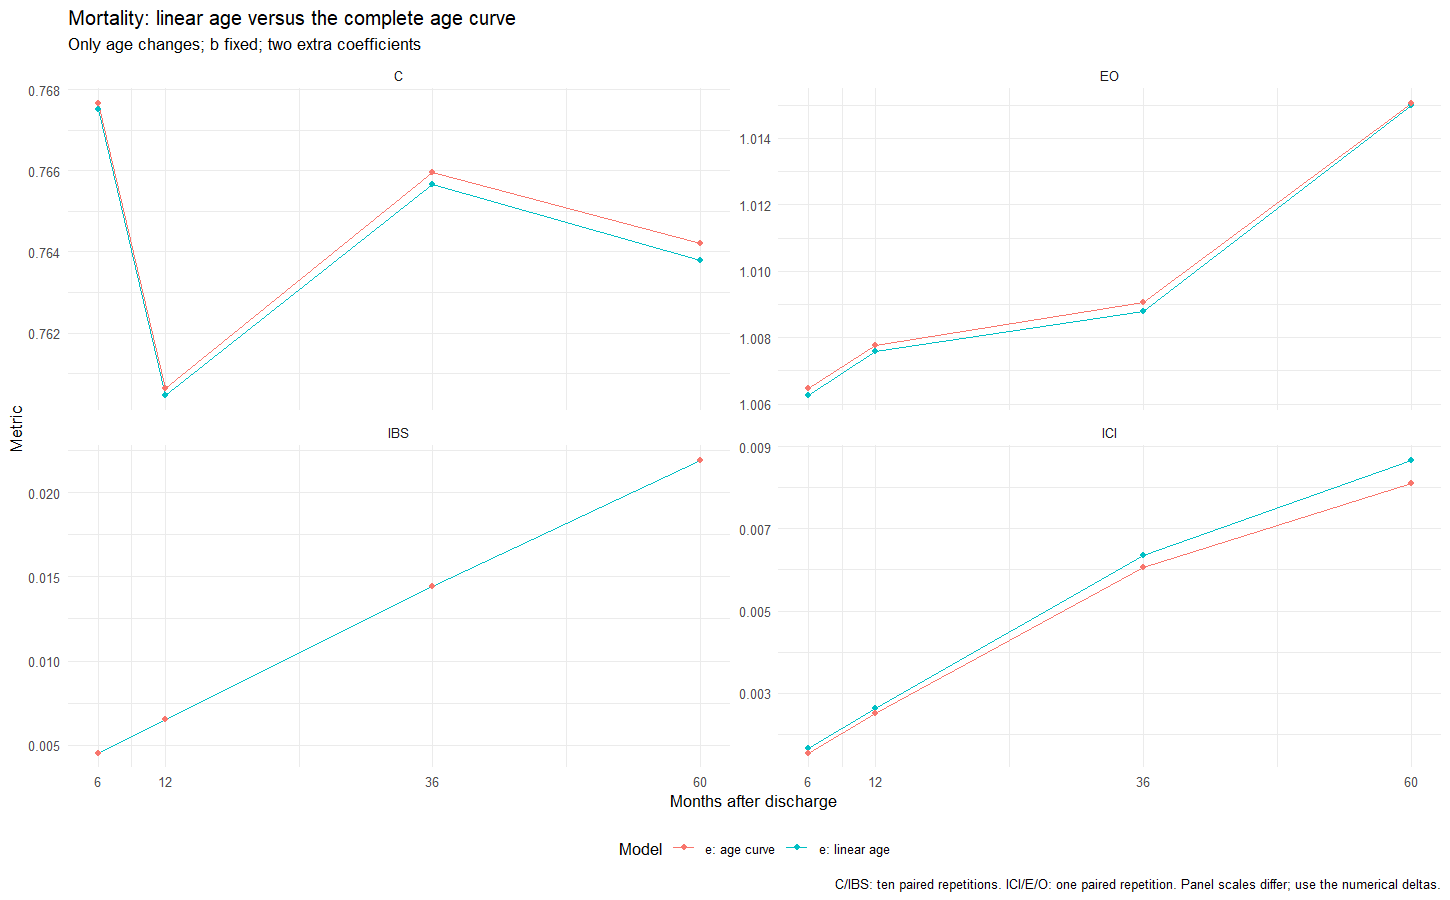

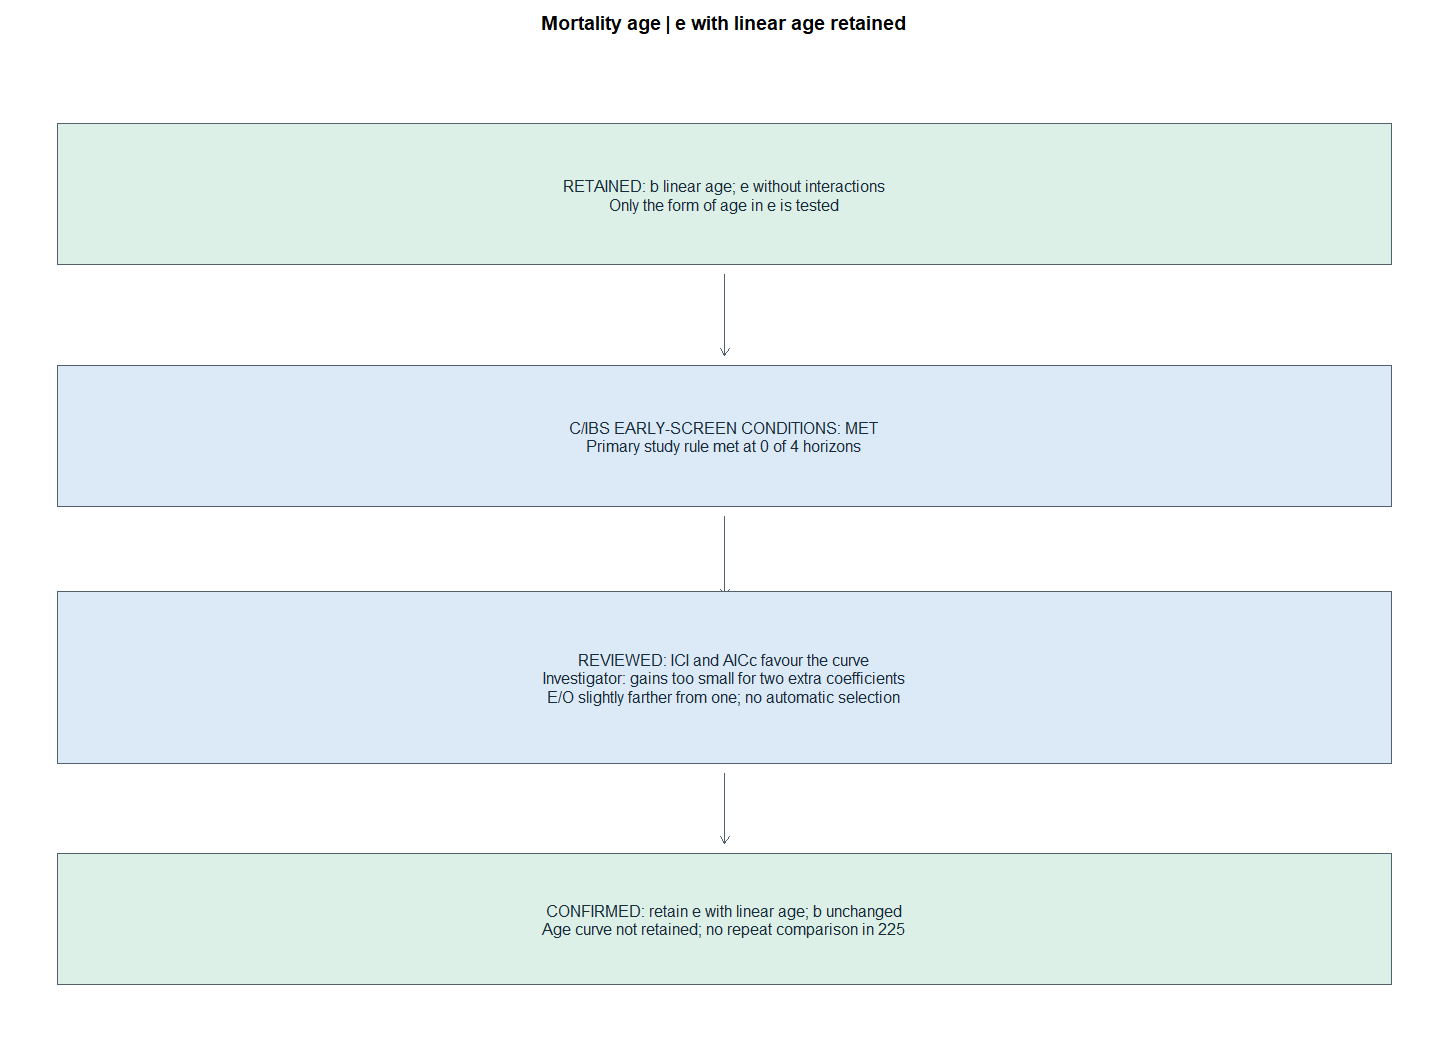

Mortality-age comparison finished. New predictive fits: 0 
| New descriptive AICc fits: 0


Elapsed: 0.006 minutes


In [84]:
#| label: shap-mortality-age-results-checkpoint
#| message: true
.t0 <- proc.time()
# Report the numerical screen without inventing a calibration threshold or selecting a model automatically.
if (mortality_age_run) {
  stopifnot(nrow(mortality_age_comparison) == 4L, all(is.finite(as.matrix(mortality_age_comparison))), all(mortality_age_coverage$Omitted == 0L), new_model_fits == 0L, new_ph_tests == 0L)
  mortality_age_comparison$Study_rule_met <- mortality_age_comparison$Delta_C >= functional_settings$c_gain & mortality_age_comparison$Delta_IBS <= functional_settings$ibs_tolerance
  mortality_age_screen <- functional_early_screen(mortality_age_comparison$Delta_C, mortality_age_comparison$Delta_IBS)
  mortality_age_comparison$Early_screen_all_horizons <- mortality_age_screen
  mortality_age_comparison$Calibration_review <- if (mortality_age_review_accepted) "Reviewed: retain e with linear age; small ICI gains do not justify two extra coefficients" else "Investigator review pending; e remains retained"
  rows <- list(data.frame(Target = "death", Horizon = performance_horizons, Metric = "C", Previous = mortality_age_comparison$C_e, New = mortality_age_comparison$C_curve), data.frame(Target = "death", Horizon = performance_horizons, Metric = "IBS", Previous = mortality_age_comparison$IBS_e, New = mortality_age_comparison$IBS_curve))
  for (metric in c("ICI", "EO")) rows[[length(rows) + 1L]] <- data.frame(Target = mortality_age_calibration_comparison$Target, Horizon = mortality_age_calibration_comparison$Horizon, Metric = metric, Previous = mortality_age_calibration_comparison[[paste0(metric, "_e")]], New = mortality_age_calibration_comparison[[paste0(metric, "_curve")]])
  mortality_age_rounding <- do.call(rbind, rows)
  mortality_age_rounding$Difference <- mortality_age_rounding$New - mortality_age_rounding$Previous
  digits <- ifelse(mortality_age_rounding$Metric == "EO", 2L, 3L)
  mortality_age_rounding$Classification <- ifelse(round(mortality_age_rounding$Previous, digits) == round(mortality_age_rounding$New, digits), "Trivial at displayed precision", "Substantial rounding change; review")
  mortality_age_rounding$Review <- if (mortality_age_review_accepted) "Reviewed: retain e with linear age; candidate not retained" else "Investigator review pending"
  show_table(mortality_age_comparison, "Mortality-age checkpoint: operational screen and unchanged primary study rule")
  show_table(mortality_age_rounding, "Within-run comparisons at Table 2 precision; manuscript values are not replaced")
  long <- do.call(rbind, lapply(c("C", "IBS", "ICI", "EO"), function(metric) do.call(rbind, lapply(c("e", "curve"), function(model) data.frame(Horizon = performance_horizons, Metric = metric, Model = if (model == "e") "e: linear age" else "e: age curve", Value = mortality_age_comparison[[paste0(metric, "_", model)]])))))
  plot <- ggplot2::ggplot(long, ggplot2::aes(Horizon, Value, color = Model, group = Model)) + ggplot2::geom_line() + ggplot2::geom_point() + ggplot2::facet_wrap(~Metric, scales = "free_y", ncol = 2L) + ggplot2::scale_x_continuous(breaks = performance_horizons) + ggplot2::labs(title = "Mortality: linear age versus the complete age curve", subtitle = "Only age changes; b fixed; two extra coefficients", x = "Months after discharge", y = "Metric", color = "Model", caption = "C/IBS: ten paired repetitions. ICI/E/O: one paired repetition. Panel scales differ; use the numerical deltas.") + ggplot2::theme_minimal(base_size = 11) + ggplot2::theme(legend.position = "bottom")
  show_diagnostic_png(function() print(plot), 1450L, 900L)
  show_diagnostic_png(function() {
    decision_canvas(if (mortality_age_review_accepted) "Mortality age | e with linear age retained" else "Mortality age | comparison complete, investigator review next")
    decision_box(0.04, 0.96, 0.85, "RETAINED: b linear age; e without interactions\nOnly the form of age in e is tested", "accepted", h = 0.07)
    decision_arrow(0.5, 0.77, y2 = 0.69)
    decision_box(0.04, 0.96, 0.61, sprintf("C/IBS EARLY-SCREEN CONDITIONS: %s\nPrimary study rule met at %d of 4 horizons", if (mortality_age_screen) "MET" else "NOT MET", sum(mortality_age_comparison$Study_rule_met)), "review", h = 0.07)
    decision_arrow(0.5, 0.53, y2 = 0.45)
    decision_box(0.04, 0.96, 0.37, if (mortality_age_review_accepted) "REVIEWED: ICI and AICc favour the curve\nInvestigator: gains too small for two extra coefficients\nE/O slightly farther from one; no automatic selection" else "REVIEW SHORT CALIBRATION: ICI and E/O\nIf all screen conditions hold, discard the curve here\nAICc stays descriptive; no automatic selection", "review", h = 0.085)
    decision_arrow(0.5, 0.275, y2 = 0.205)
    decision_box(0.04, 0.96, 0.13, if (mortality_age_review_accepted) "CONFIRMED: retain e with linear age; b unchanged\nAge curve not retained; no repeat comparison in 225" else "STOP: investigator decision\nDiscarded curves need no repeat comparison in 225", if (mortality_age_review_accepted) "accepted" else "pending", h = 0.065)
  }, 1450L, 1050L)
  if (mortality_age_review_accepted) stopifnot(performance_new_fits == 0L, mortality_age_new_predictive_fits == 0L, mortality_age_new_aicc_fits == 0L)
  mortality_age_complete <- TRUE
  functional_candidates$Status[functional_candidates$Candidate == "e_age_spline"] <- if (mortality_age_review_accepted) "Evaluated; not retained: keep linear age in e" else "Evaluated; investigator decision pending"
  functional_candidates$Form[functional_candidates$Candidate == "e_age_spline"] <- paste(deparse(mortality_age_candidate), collapse = " ")
  functional_candidates$Priority[functional_candidates$Candidate == "e_age_spline"] <- "Evaluated complete age spline"
  cat("Mortality-age comparison finished. New predictive fits:", mortality_age_new_predictive_fits, "| New descriptive AICc fits:", mortality_age_new_aicc_fits, fill = TRUE)
} else {
  stopifnot(performance_new_fits == 0L, new_model_fits == 0L, new_ph_tests == 0L)
  cat("Preparation and baseline controls passed with zero new fits. The filter is approved; predictive execution awaits the resource checkpoint. b/e remain retained.", fill = TRUE)
}
interaction_allowed <- mortality_age_original_allowed
# The age decision is closed; later functional candidates remain separate checkpoints.
review_pending <- TRUE
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


### Link to the supplement
The following table reads the SHAP-informed age-spline row directly from eTable 6. It distinguishes the historical analysis from the current clean comparison; it does not isolate the effect of a single methodological change. Published rounding changes remain subject to investigator review.

In [85]:
#| label: shap-mortality-age-etable6-source
#| message: true
.t0 <- proc.time()
# Link this completed exploratory comparison to its actual supplement row without editing Word.
mortality_age_manuscript_comparison <- data.frame()
if (mortality_age_complete) {
  # Match the full visible caption so the table-of-contents entry cannot select a different table.
  caption_nodes <- xml2::xml_find_all(document, "//w:body/w:p", namespace)
  caption_text <- vapply(caption_nodes, function(node) paste(xml2::xml_text(xml2::xml_find_all(node, ".//w:t", namespace)), collapse = ""), character(1L))
  caption_nodes <- caption_nodes[trimws(caption_text) == "eTable 6. Iterative evaluation of functional-form specifications for the mortality models, out-of-fold development sample"]
  stopifnot(length(caption_nodes) == 1L)
  etable6_node <- xml2::xml_find_all(caption_nodes[[1L]], "following-sibling::w:tbl[1]", namespace)
  stopifnot(length(etable6_node) == 1L)
  etable6_rows <- lapply(xml2::xml_find_all(etable6_node, "./w:tr", namespace), function(row) vapply(xml2::xml_find_all(row, "./w:tc", namespace), function(cell) paste(xml2::xml_text(xml2::xml_find_all(cell, ".//w:t", namespace)), collapse = ""), character(1L)))
  stopifnot(all(lengths(etable6_rows) == 10L))
  etable6_matrix <- do.call(rbind, etable6_rows)
  block <- which(startsWith(etable6_matrix[, 1L], "SHAP-informed specification"))
  selected <- which(etable6_matrix[, 1L] == "Age at admission" & etable6_matrix[, 2L] == "Natural spline, 3 df")
  stopifnot(length(block) == 1L)
  selected <- selected[selected > block]
  stopifnot(length(selected) == 1L, identical(as.numeric(mortality_age_comparison$Horizon), performance_horizons))
  row <- etable6_matrix[selected, ]
  mortality_age_manuscript_comparison <- do.call(rbind, lapply(c("C", "IBS"), function(metric) {
    columns <- if (metric == "C") 3:6 else 7:10
    previous <- unname(vapply(row[columns], first_number, numeric(1L)))
    digits <- nchar(sub("^[^.]*\\.", "", row[columns]))
    current <- mortality_age_comparison[[paste0("Delta_", metric)]]
    data.frame(Source = "eTable 6; SHAP-informed; Age at admission; Natural spline, 3 df", Horizon = performance_horizons, Metric = paste0("Delta_", metric), Previous_published = unname(previous), Current_clean = current, Difference = current - previous, Published_decimals = unname(digits), Current_rounded = round(current, digits), Classification = ifelse(round(current, digits) == previous, "trivial", "substantial: supplement rounding changes"), Review = if (mortality_age_review_accepted) "Reviewed: retain e with linear age; candidate not retained; Word unchanged" else "Investigator review pending; e retained")
  }))
  stopifnot(nrow(mortality_age_manuscript_comparison) == 8L, all(mortality_age_manuscript_comparison$Published_decimals == 5L), all(is.finite(as.matrix(mortality_age_manuscript_comparison[, c("Previous_published", "Current_clean", "Difference")]))))
  show_table(mortality_age_manuscript_comparison, "eTable 6 age row: manuscript versus clean comparison; these are different analysis pipelines")
  cat("The historical spline kept three columns of a five-column basis; the reviewed candidate uses a complete three-column basis. Development imputation, selected formulas and evaluation conventions also differ from the historical workflow. This comparison does not isolate the numerical effect of any one change. No old interval is transferred and no manuscript value is replaced.", fill = TRUE)
  destination <- file.path(table_dir, paste0("eTable6_mortality_age_spline_previous_vs_clean_", Sys.Date(), "_", mortality_age_signature, ".csv"))
  utils::write.csv(mortality_age_manuscript_comparison, destination, row.names = FALSE, na = "")
  written <- c(written, destination)
  review_pending <- TRUE
} else cat("eTable 6 age comparison pending: no unexecuted value is exported.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Source,Horizon,Metric,Previous_published,Current_clean,Difference,Published_decimals,Current_rounded,Classification,Review
"eTable 6; SHAP-informed; Age at admission; Natural spline, 3 df",6,Delta_C,-0.0111,2e-04,0.0113,5,1e-04,substantial: supplement rounding changes,Reviewed: retain e with linear age; candidate not retained; Word unchanged
"eTable 6; SHAP-informed; Age at admission; Natural spline, 3 df",12,Delta_C,-0.0094,2e-04,0.0096,5,2e-04,substantial: supplement rounding changes,Reviewed: retain e with linear age; candidate not retained; Word unchanged
"eTable 6; SHAP-informed; Age at admission; Natural spline, 3 df",36,Delta_C,-0.0116,3e-04,0.0119,5,3e-04,substantial: supplement rounding changes,Reviewed: retain e with linear age; candidate not retained; Word unchanged
"eTable 6; SHAP-informed; Age at admission; Natural spline, 3 df",60,Delta_C,-0.0110,4e-04,0.0115,5,4e-04,substantial: supplement rounding changes,Reviewed: retain e with linear age; candidate not retained; Word unchanged
"eTable 6; SHAP-informed; Age at admission; Natural spline, 3 df",6,Delta_IBS,0.0000,0e+00,0.0000,5,0e+00,substantial: supplement rounding changes,Reviewed: retain e with linear age; candidate not retained; Word unchanged
"eTable 6; SHAP-informed; Age at admission; Natural spline, 3 df",12,Delta_IBS,0.0000,0e+00,0.0000,5,0e+00,substantial: supplement rounding changes,Reviewed: retain e with linear age; candidate not retained; Word unchanged
"eTable 6; SHAP-informed; Age at admission; Natural spline, 3 df",36,Delta_IBS,0.0000,0e+00,-0.0001,5,0e+00,substantial: supplement rounding changes,Reviewed: retain e with linear age; candidate not retained; Word unchanged
"eTable 6; SHAP-informed; Age at admission; Natural spline, 3 df",60,Delta_IBS,0.0001,0e+00,-0.0001,5,0e+00,substantial: supplement rounding changes,Reviewed: retain e with linear age; candidate not retained; Word unchanged


The historical spline kept three columns of a five-column basis; the reviewed candidate uses a complete three-column basis. Development imputation, selected formulas and evaluation conventions also differ from the historical workflow. This comparison does not isolate the numerical effect of any one change. No old interval is transferred and no manuscript value is replaced.


Elapsed: 0.001 minutes


## Remaining functional forms and category simplifications
The investigator authorized completion of the remaining b/e comparisons. Both age terms remain linear and interactions remain excluded. Each candidate changes one eligible predictor family; the preceding retained b/e formulas remain its fixed reference. Complete three-column splines extend the reviewed age correction while preserving the original fixed knot locations for duration and poverty. Short calibration uses the same first repetition for reference and candidate.
The original selection rule also applies to category simplifications unless a different rule is explicitly recorded. Similar performance alone is not called equivalence. Word remains the authority for previous published values; a known last-decimal discrepancy in the historical CSV is displayed separately. No Word file is modified.
Preparation mode validates formulas and sources without fitting. Execution was authorized with up to eight single-thread processes and a 20 GiB RAM reserve; no age trial, imputation, tuning, SHAP or bootstrap is repeated.

In [86]:
#| label: shap-functional-remaining-register
#| message: true
.t0 <- proc.time()
# Preserve each original single-change comparison against the accepted b/e formulas.
remaining_candidates <- data.frame(Candidate = c("b_duration_log", "b_duration_quadratic", "b_duration_hinge5", "b_duration_spline", "b_poverty_hinge15", "b_poverty_spline", "b_consumo_binary", "b_mental_binary", "e_frequency_daily", "b_consumo_ordinal", "b_mental_ordinal", "b_education_ordinal", "b_frequency_ordinal", "e_occupation_ordinal", "e_physical_ordinal", "e_frequency_ordinal"), Base = c(rep("b", 8L), "e", rep("b", 4L), rep("e", 3L)), Group = c(rep("Duration", 4L), rep("Poverty", 2L), rep("Binary simplification", 3L), rep("Ordinal simplification", 7L)), Label = c(rep("Treatment duration", 4L), rep("Communal poverty index", 2L), "Discharge evaluation, substance use", "Discharge evaluation, mental health", "Primary-substance use frequency", "Discharge evaluation, substance use", "Discharge evaluation, mental health", "Educational attainment", "Primary-substance use frequency", "Discharge evaluation, occupational status", "Discharge evaluation, physical health", "Primary-substance use frequency"), Modification = c("Log(1+x) transformation", "Quadratic term", "Hinge at 5 months", "Natural spline, 3 df", "Hinge at 0.15", "Natural spline, 3 df", rep("Any lower achievement, dummy", 2L), "High frequency, dummy", rep("Ordinal score", 7L)), Source_label = c(rep("shap-criteria-func-form-precomputed-ns-readm", 8L), "shap-criteria-func-form-nonlin-formula-death-simpler", rep("shap-criteria-func-form-ordinal-test", 4L), rep("shap-criteria-func-form-ordinal-test-3-death-simpler", 3L)), Historical_id = c("readm_dit_log", "readm_dit_quad", "readm_dit_hinge5", "readm_dit_ns3", "readm_pobr_hinge015", "readm_pobr_ns3", "readm_eva_consumo_any", "readm_eva_sm_any", "death_rule2_prim_freq_high", "readm_ordinal_eva_consumo", "readm_ordinal_eva_sm", "readm_ordinal_ed_attainment", "readm_ordinal_prim_sub_freq", "death_rule2_ordinal_eva_ocupacion", NA_character_, "death_rule2_ordinal_prim_sub_freq"), Expected_coefficient_change = c(0L, 1L, 0L, 2L, 0L, 2L, rep(-1L, 10L)), stringsAsFactors = FALSE)
stopifnot(nrow(remaining_candidates) == 16L, !anyDuplicated(remaining_candidates$Candidate), length(py_corrected_datasets) == 5L, setequal(names(functional_bases), c("b", "e")))
# All ordinal scores keep the original reference category at zero.
remaining_dummy_pairs <- list(consumo = c("eva_consumo_logro_intermedio", "eva_consumo_logro_minimo"), mental = c("eva_sm_logro_intermedio", "eva_sm_logro_minimo"), education = c("ed_attainment_corr_2_completed_high_school_or_less", "ed_attainment_corr_3_completed_primary_school_or_less"), frequency = c("prim_sub_freq_rec_2_2_6_days_wk", "prim_sub_freq_rec_3_daily"), occupation = c("eva_ocupacion_logro_intermedio", "eva_ocupacion_logro_minimo"), physical = c("eva_fisica_logro_intermedio", "eva_fisica_logro_minimo"))
for (i in seq_along(py_corrected_datasets)) {
  df <- py_corrected_datasets[[i]]
  for (pair in remaining_dummy_pairs) {
    stopifnot(all(pair %in% names(df)))
    indicators <- as.matrix(df[, pair, drop = FALSE])
    stopifnot(!anyNA(indicators), all(indicators %in% c(0, 1)), all(rowSums(indicators) <= 1))
  }
}
remaining_removed_terms <- c(rep(list("dit_m"), 4L), rep(list("porc_pobr"), 2L), list(remaining_dummy_pairs$consumo, remaining_dummy_pairs$mental, remaining_dummy_pairs$frequency, remaining_dummy_pairs$consumo, remaining_dummy_pairs$mental, remaining_dummy_pairs$education, remaining_dummy_pairs$frequency, remaining_dummy_pairs$occupation, remaining_dummy_pairs$physical, remaining_dummy_pairs$frequency))
names(remaining_removed_terms) <- remaining_candidates$Candidate
# The two complete spline bases retain the original four locations, with outer locations as boundaries.
remaining_expressions <- stats::setNames(c("I(log1p(pmin(dit_m, 36)))", "I(pmin(dit_m, 36)) + I(pmin(dit_m, 36)^2)", "I(pmax(0, pmin(dit_m, 36) - 5))", "splines::ns(dit_m, knots = c(3.9, 7.9), Boundary.knots = c(1.1, 19.3))", "I(pmax(0, porc_pobr - 0.15))", "splines::ns(porc_pobr, knots = c(0.105, 0.146), Boundary.knots = c(0.053, 0.261))", "I(eva_consumo_logro_intermedio + eva_consumo_logro_minimo)", "I(eva_sm_logro_intermedio + eva_sm_logro_minimo)", "prim_sub_freq_rec_3_daily", "I(eva_consumo_logro_intermedio + 2 * eva_consumo_logro_minimo)", "I(eva_sm_logro_intermedio + 2 * eva_sm_logro_minimo)", "I(ed_attainment_corr_2_completed_high_school_or_less + 2 * ed_attainment_corr_3_completed_primary_school_or_less)", "I(prim_sub_freq_rec_2_2_6_days_wk + 2 * prim_sub_freq_rec_3_daily)", "I(eva_ocupacion_logro_intermedio + 2 * eva_ocupacion_logro_minimo)", "I(eva_fisica_logro_intermedio + 2 * eva_fisica_logro_minimo)", "I(prim_sub_freq_rec_2_2_6_days_wk + 2 * prim_sub_freq_rec_3_daily)"), remaining_candidates$Candidate)
remaining_formulas <- stats::setNames(lapply(seq_len(nrow(remaining_candidates)), function(j) {
  candidate <- remaining_candidates$Candidate[j]
  base <- functional_bases[[remaining_candidates$Base[j]]]
  removed <- remaining_removed_terms[[candidate]]
  stopifnot(all(removed %in% formula_terms(base)))
  change <- stats::as.formula(paste(". ~ .", paste(paste0("- ", removed), collapse = " "), "+", remaining_expressions[[candidate]]), env = environment(base))
  result <- stats::update(base, change)
  stopifnot(identical(formula_strata(result), formula_strata(base)), identical(result[[2L]], base[[2L]]), !removed_collinear %in% all.vars(result), all(all.vars(result) %in% all.vars(base)))
  stopifnot(all(setdiff(formula_terms(base), removed) %in% formula_terms(result)))
  result
}), remaining_candidates$Candidate)
# Validate only transformation matrices; no Cox model, prediction or development-data mutation is performed.
remaining_validation <- do.call(rbind, lapply(seq_len(nrow(remaining_candidates)), function(j) {
  candidate <- remaining_candidates$Candidate[j]
  transform_formula <- stats::as.formula(paste("~ 0 +", remaining_expressions[[candidate]]), env = environment(remaining_formulas[[candidate]]))
  do.call(rbind, lapply(seq_along(py_corrected_datasets), function(i) {
    df <- py_corrected_datasets[[i]]
    frame <- stats::model.frame(transform_formula, data = df, na.action = stats::na.fail)
    basis <- stats::model.matrix(transform_formula, data = frame)
    expected <- length(remaining_removed_terms[[candidate]]) + remaining_candidates$Expected_coefficient_change[j]
    stopifnot(nrow(basis) == nrow(df), ncol(basis) == expected, all(is.finite(basis)))
    data.frame(Candidate = candidate, Imputation = i, Rows = nrow(basis), Transformation_columns = ncol(basis), Omitted_rows = nrow(df) - nrow(basis))
  }))
}))
stopifnot(nrow(remaining_validation) == 80L, all(remaining_validation$Omitted_rows == 0L))
show_table(remaining_candidates, "Remaining single-change comparisons against fixed b/e; no age model is reopened")
show_table(data.frame(Candidate = names(remaining_expressions), Transformation = unname(remaining_expressions)), "Exact candidate transformations; expected coefficient changes assume full rank")
cat("Duration log, quadratic and hinge retain the historical 36-month cap; the duration spline uses the full raw range. Both spline candidates use complete three-column bases, with the original inner two locations as interior knots and the outer two as boundaries. This extends the reviewed age-basis correction; it is not the historical first-three-of-five construction. No percentiles are re-estimated and no person is excluded.", fill = TRUE)
cat("Binary discharge evaluations combine intermediate and minimum achievement; summing the verified mutually exclusive indicators is exactly their OR. Frequency is scored 0 for at most one day/week, 1 for two to six days/week and 2 for daily use; the binary frequency candidate is daily versus all other frequencies. Evaluation scores are high/intermediate/minimum = 0/1/2. Education retains its original 0/1/2 categories.", fill = TRUE)
cat("Physical-evaluation scoring is newly eligible in e under the original ordinal-family loop because the accepted SHAP selection now includes that family. The historical SHAP mortality model did not evaluate it; the Full-mortality result is not an equivalent previous result. Candidate calculations do not automatically approve simplifications, combinations or replacement of the retained b/e formulas.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Group,Label,Modification,Source_label,Historical_id,Expected_coefficient_change
b_duration_log,b,Duration,Treatment duration,Log(1+x) transformation,shap-criteria-func-form-precomputed-ns-readm,readm_dit_log,0
b_duration_quadratic,b,Duration,Treatment duration,Quadratic term,shap-criteria-func-form-precomputed-ns-readm,readm_dit_quad,1
b_duration_hinge5,b,Duration,Treatment duration,Hinge at 5 months,shap-criteria-func-form-precomputed-ns-readm,readm_dit_hinge5,0
b_duration_spline,b,Duration,Treatment duration,"Natural spline, 3 df",shap-criteria-func-form-precomputed-ns-readm,readm_dit_ns3,2
b_poverty_hinge15,b,Poverty,Communal poverty index,Hinge at 0.15,shap-criteria-func-form-precomputed-ns-readm,readm_pobr_hinge015,0
b_poverty_spline,b,Poverty,Communal poverty index,"Natural spline, 3 df",shap-criteria-func-form-precomputed-ns-readm,readm_pobr_ns3,2
b_consumo_binary,b,Binary simplification,"Discharge evaluation, substance use","Any lower achievement, dummy",shap-criteria-func-form-precomputed-ns-readm,readm_eva_consumo_any,-1
b_mental_binary,b,Binary simplification,"Discharge evaluation, mental health","Any lower achievement, dummy",shap-criteria-func-form-precomputed-ns-readm,readm_eva_sm_any,-1
e_frequency_daily,e,Binary simplification,Primary-substance use frequency,"High frequency, dummy",shap-criteria-func-form-nonlin-formula-death-simpler,death_rule2_prim_freq_high,-1
b_consumo_ordinal,b,Ordinal simplification,"Discharge evaluation, substance use",Ordinal score,shap-criteria-func-form-ordinal-test,readm_ordinal_eva_consumo,-1


Candidate,Transformation
b_duration_log,"I(log1p(pmin(dit_m, 36)))"
b_duration_quadratic,"I(pmin(dit_m, 36)) + I(pmin(dit_m, 36)^2)"
b_duration_hinge5,"I(pmax(0, pmin(dit_m, 36) - 5))"
b_duration_spline,"splines::ns(dit_m, knots = c(3.9, 7.9), Boundary.knots = c(1.1, 19.3))"
b_poverty_hinge15,"I(pmax(0, porc_pobr - 0.15))"
b_poverty_spline,"splines::ns(porc_pobr, knots = c(0.105, 0.146), Boundary.knots = c(0.053, 0.261))"
b_consumo_binary,I(eva_consumo_logro_intermedio + eva_consumo_logro_minimo)
b_mental_binary,I(eva_sm_logro_intermedio + eva_sm_logro_minimo)
e_frequency_daily,prim_sub_freq_rec_3_daily
b_consumo_ordinal,I(eva_consumo_logro_intermedio + 2 * eva_consumo_logro_minimo)


Duration log, quadratic and hinge retain the historical 36-month cap; the duration spline uses the full raw range. Both spline candidates use complete three-column bases, with the original inner two locations as interior knots and the outer two as boundaries. This extends the reviewed age-basis correction; it is not the historical first-three-of-five construction. No percentiles are re-estimated and no person is excluded.


Binary discharge evaluations combine intermediate and minimum achievement; summing the verified mutually exclusive indicators is exactly their OR. Frequency is scored 0 for at most one day/week, 1 for two to six days/week and 2 for daily use; the binary frequency candidate is daily versus all other frequencies. Evaluation scores are high/intermediate/minimum = 0/1/2. Education retains its original 0/1/2 categories.


Physical-evaluation scoring is newly eligible in e under the original ordinal-family loop because the accepted SHAP selection now includes that family. The historical SHAP mortality model did not evaluate it; the Full-mortality result is not an equivalent previous result. Candidate calculations do not automatically approve simplifications, combinations or replacement of the retained b/e formulas.


Elapsed: 0.019 minutes


In [87]:
#| label: shap-functional-remaining-historical-source
#| message: true
.t0 <- proc.time()
# Read the manuscript as the published-value authority and the compact corrected historical CSV as its source control.
remaining_history <- utils::read.csv(source_path("cox_functional_history"), stringsAsFactors = FALSE, check.names = FALSE)
stopifnot(all(c("id", "horizon", "delta_C", "delta_IBS", "baseline_id") %in% names(remaining_history)), !anyDuplicated(paste(remaining_history$id, remaining_history$horizon)), first_number("\u22120.01110") == -0.01110)
remaining_word_captions <- c(b = "eTable 5. Iterative evaluation of functional-form specifications for the readmission models, out-of-fold development sample", e = "eTable 6. Iterative evaluation of functional-form specifications for the mortality models, out-of-fold development sample")
remaining_word_tables <- lapply(names(remaining_word_captions), function(base) {
  path <- paste0("//w:body/w:p[normalize-space(.) = '", remaining_word_captions[[base]], "']/following-sibling::w:tbl[1]")
  node <- xml2::xml_find_all(document, path, namespace)
  stopifnot(length(node) == 1L)
  rows <- lapply(xml2::xml_find_all(node, "./w:tr", namespace), function(row) vapply(xml2::xml_find_all(row, "./w:tc", namespace), function(cell) paste(xml2::xml_text(xml2::xml_find_all(cell, ".//w:t", namespace)), collapse = ""), character(1L)))
  stopifnot(all(lengths(rows) == if (base == "b") 11L else 10L))
  result <- do.call(rbind, rows)
  if (base == "e") {
    block <- which(startsWith(result[, 1L], "SHAP-informed specification"))
    stopifnot(length(block) == 1L, block < nrow(result))
    result <- result[seq.int(block + 1L, nrow(result)), , drop = FALSE]
  }
  result
})
names(remaining_word_tables) <- names(remaining_word_captions)
remaining_source_candidates <- rbind(remaining_candidates[, c("Candidate", "Base", "Label", "Modification", "Historical_id")], data.frame(Candidate = c("b_age_spline", "e_age_spline"), Base = c("b", "e"), Label = "Age at admission", Modification = "Natural spline, 3 df", Historical_id = c("readm_age_ns3", "death_rule2_age_ns3")))
remaining_all_published <- do.call(rbind, lapply(seq_len(nrow(remaining_source_candidates)), function(j) {
  candidate <- remaining_source_candidates[j, ]
  historical_id <- candidate$Historical_id
  if (is.na(historical_id)) return(data.frame(Candidate = candidate$Candidate, Horizon = rep(c(6, 12, 36, 60), 2L), Metric = rep(c("Delta_C", "Delta_IBS"), each = 4L), Previous_published = NA_real_, Published_decimals = NA_integer_, Historical_csv = NA_real_, Provenance = "Not evaluated in historical SHAP mortality; newly eligible physical-evaluation ordinal family; no equivalent published value"))
  table <- remaining_word_tables[[candidate$Base]]
  selected <- which(table[, 1L] == candidate$Label & table[, 2L] == candidate$Modification)
  stopifnot(length(selected) == 1L)
  row <- table[selected, ]
  reference <- remaining_history[remaining_history$id == historical_id, ]
  reference <- reference[match(c(6, 12, 36, 60), reference$horizon), ]
  stopifnot(nrow(reference) == 4L, identical(as.numeric(reference$horizon), c(6, 12, 36, 60)), all(reference$baseline_id == if (candidate$Base == "b") "readm_linear" else "death_rule2_linear"))
  do.call(rbind, lapply(c("C", "IBS"), function(metric) {
    columns <- if (metric == "C") 3:6 else 7:10
    values <- row[columns]
    decimals <- nchar(sub("^[^.]*\\.", "", values))
    previous <- unname(vapply(values, first_number, numeric(1L)))
    stopifnot(all(decimals == 5L), all(is.finite(previous)))
    data.frame(Candidate = candidate$Candidate, Horizon = c(6, 12, 36, 60), Metric = paste0("Delta_", metric), Previous_published = previous, Published_decimals = unname(decimals), Historical_csv = reference[[paste0("delta_", metric)]], Provenance = paste0(if (candidate$Base == "b") "eTable 5" else "eTable 6, SHAP-informed block", "; ", historical_id, "; Word is authoritative for published values"))
  }))
}))
rownames(remaining_all_published) <- NULL
remaining_published <- remaining_all_published[remaining_all_published$Candidate %in% remaining_candidates$Candidate, ]
age_published <- remaining_all_published[remaining_all_published$Candidate %in% c("b_age_spline", "e_age_spline"), ]
remaining_published_rows <- !is.na(remaining_all_published$Previous_published)
stopifnot(nrow(remaining_all_published) == 144L, nrow(remaining_published) == 128L, nrow(age_published) == 16L, sum(remaining_published_rows) == 136L, all(is.finite(remaining_all_published$Historical_csv[remaining_published_rows])))
remaining_history_control <- remaining_all_published[remaining_published_rows, ]
remaining_history_control$Historical_csv_rounded <- round(remaining_history_control$Historical_csv, remaining_history_control$Published_decimals)
remaining_history_control$Matches_published <- remaining_history_control$Historical_csv_rounded == remaining_history_control$Previous_published
remaining_known_discrepancy <- with(remaining_history_control, Candidate == "b_mental_ordinal" & Horizon == 12 & Metric == "Delta_IBS" & Previous_published == 0 & Published_decimals == 5L & abs(Historical_csv - 0.00000526735103595355) < 1e-15)
stopifnot(all(remaining_history_control$Matches_published | remaining_known_discrepancy))
remaining_historical_discrepancies <- remaining_history_control[!remaining_history_control$Matches_published, ]
remaining_historical_discrepancies$Classification <- rep("Substantial historical rounding discrepancy; already reported; Word retained as published authority", nrow(remaining_historical_discrepancies))
show_table(remaining_published, "Published deltas for the remaining candidates; historical and clean pipelines are not identical")
show_table(age_published, "Published age deltas for the already completed comparisons; no age candidate is reopened")
if (nrow(remaining_historical_discrepancies)) show_table(remaining_historical_discrepancies, "Known source discrepancy: mental-health ordinal IBS at 12 months; not caused by this clean comparison")
cat("The historical CSV and Word disagree at the fifth decimal for readmission mental-health ordinal delta IBS at 12 months: Word 0.00000 versus CSV 0.00000526735103595355, which rounds to 0.00001. Its cause has not been isolated. The published Word value is retained here; no manuscript value or historical result is overwritten. Every other available remaining-candidate comparison must match at the published precision.", fill = TRUE)
cat("Readmission historical comparisons used Full mortality as their partner; their readmission net-risk C/IBS calculations do not depend on the mortality partner. The new readmission AJ calibration uses the retained e and has no corresponding historical calibration row in eTable 5. The 21 Full-mortality alternatives in eTable 6 are outside this b/e registry, which does not claim to regenerate that entire table.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Horizon,Metric,Previous_published,Published_decimals,Historical_csv,Provenance
b_duration_log,6,Delta_C,-0.0005,5,-0.0005,eTable 5; readm_dit_log; Word is authoritative for published values
b_duration_log,12,Delta_C,-0.0001,5,-0.0001,eTable 5; readm_dit_log; Word is authoritative for published values
b_duration_log,36,Delta_C,0.0003,5,0.0003,eTable 5; readm_dit_log; Word is authoritative for published values
b_duration_log,60,Delta_C,0.0006,5,0.0006,eTable 5; readm_dit_log; Word is authoritative for published values
b_duration_log,6,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_dit_log; Word is authoritative for published values
b_duration_log,12,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_dit_log; Word is authoritative for published values
b_duration_log,36,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_dit_log; Word is authoritative for published values
b_duration_log,60,Delta_IBS,-0.0001,5,-0.0001,eTable 5; readm_dit_log; Word is authoritative for published values
b_duration_quadratic,6,Delta_C,-0.0001,5,-0.0001,eTable 5; readm_dit_quad; Word is authoritative for published values
b_duration_quadratic,12,Delta_C,0.0001,5,0.0001,eTable 5; readm_dit_quad; Word is authoritative for published values


Candidate,Horizon,Metric,Previous_published,Published_decimals,Historical_csv,Provenance
b_age_spline,6,Delta_C,0.0000,5,0.0000,eTable 5; readm_age_ns3; Word is authoritative for published values
b_age_spline,12,Delta_C,0.0003,5,0.0003,eTable 5; readm_age_ns3; Word is authoritative for published values
b_age_spline,36,Delta_C,0.0002,5,0.0002,eTable 5; readm_age_ns3; Word is authoritative for published values
b_age_spline,60,Delta_C,0.0003,5,0.0003,eTable 5; readm_age_ns3; Word is authoritative for published values
b_age_spline,6,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_age_ns3; Word is authoritative for published values
b_age_spline,12,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_age_ns3; Word is authoritative for published values
b_age_spline,36,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_age_ns3; Word is authoritative for published values
b_age_spline,60,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_age_ns3; Word is authoritative for published values
e_age_spline,6,Delta_C,-0.0111,5,-0.0111,"eTable 6, SHAP-informed block; death_rule2_age_ns3; Word is authoritative for published values"
e_age_spline,12,Delta_C,-0.0094,5,-0.0094,"eTable 6, SHAP-informed block; death_rule2_age_ns3; Word is authoritative for published values"


Candidate,Horizon,Metric,Previous_published,Published_decimals,Historical_csv,Provenance,Historical_csv_rounded,Matches_published,Classification
b_mental_ordinal,12,Delta_IBS,0,5,0,eTable 5; readm_ordinal_eva_sm; Word is authoritative for published values,0,FALSE,Substantial historical rounding discrepancy; already reported; Word retained as published authority


The historical CSV and Word disagree at the fifth decimal for readmission mental-health ordinal delta IBS at 12 months: Word 0.00000 versus CSV 0.00000526735103595355, which rounds to 0.00001. Its cause has not been isolated. The published Word value is retained here; no manuscript value or historical result is overwritten. Every other available remaining-candidate comparison must match at the published precision.


Readmission historical comparisons used Full mortality as their partner; their readmission net-risk C/IBS calculations do not depend on the mortality partner. The new readmission AJ calibration uses the retained e and has no corresponding historical calibration row in eTable 5. The 21 Full-mortality alternatives in eTable 6 are outside this b/e registry, which does not claim to regenerate that entire table.


Elapsed: 0.003 minutes


In [88]:
#| label: shap-functional-remaining-contract
#| message: true
.t0 <- proc.time()
# Reuse the reviewed references; new candidates must not refit a missing earlier result.
stopifnot(functional_age_review_accepted, mortality_age_review_accepted, performance_new_fits == 0L, new_model_fits == 0L, new_ph_tests == 0L)
remaining_mode <- shap_settings$functional_remaining_mode
stopifnot(remaining_mode %in% c("prepare", "run"))
remaining_run <- identical(remaining_mode, "run")
remaining_complete <- FALSE
remaining_results <- list()
remaining_comparison <- remaining_calibration <- remaining_aicc <- remaining_coverage <- remaining_previous_vs_new <- remaining_decisions <- data.frame()
remaining_new_predictive_fits <- remaining_new_aicc_fits <- 0L
remaining_base_repetitions <- list(b = readmission_step_repetitions, e = mortality_step_repetitions)
remaining_base_aicc <- list(b = functional_age_aicc[functional_age_aicc$Model == "b", ], e = mortality_age_aicc[mortality_age_aicc$Model == "e", ])
remaining_base_calibration <- list(readmission = functional_age_calibration$b, death = mortality_age_calibration$e_death)
remaining_engine_labels <- c("shap-functional-remaining-evaluation-functions")
remaining_engine_code <- performance_code[vapply(performance_code, function(s) any(vapply(remaining_engine_labels, function(label) startsWith(s, paste0("#| label: ", label, "\n")), logical(1L))), logical(1L))]
stopifnot(length(remaining_engine_code) == 1L)
remaining_signature <- substr(digest::digest(list(performance_signature, functional_settings, lapply(remaining_formulas, deparse), lapply(functional_bases, deparse), calibration_rng, remaining_engine_code), algo = "sha256"), 1L, 12L)
remaining_prefix <- paste0("functional_remaining_", remaining_signature)
for (id in names(remaining_formulas)) {
  base <- remaining_candidates$Base[remaining_candidates$Candidate == id]
  outcome <- if (base == "b") "readmission" else "death"
  performance_formulas[[outcome]][[id]] <- remaining_formulas[[id]]
}
remaining_budget <- data.frame(Base = c("b", "e"), Candidates = as.integer(table(factor(remaining_candidates$Base, levels = c("b", "e")))), C_IBS_fits_each = 250L, Short_calibration_fits_each = c(50L, 75L), AICc_fits_each = 5L)
remaining_budget$New_fits <- with(remaining_budget, Candidates * (C_IBS_fits_each + Short_calibration_fits_each + AICc_fits_each))
show_table(remaining_budget, "Remaining branch budget; saved b/e references are reused")
show_table(data.frame(Component = c("C / Graf integrated IBS", "Short calibration", "Native threads", "Maximum C/IBS processes", "Maximum calibration processes", "RAM reserve GiB", "Available RAM GiB"), Setting = c("10 x 5 x 5, original paired partitions", "1 x 5 x 5; ICI and E/O; AJ readmission, KM mortality", "Main process: 2; workers: 1", performance_settings$workers, 2L, shap_settings$reserve_memory_gib, round(ps::ps_system_memory()$avail / 1024^3, 2))), "Environment: R 4.4.1, r-main / ir, frozen renv; no new dependency")
cat("Age choices are closed. Each remaining candidate changes one predictor family in fixed b or e. The published early screen is operational, not equivalence. Simplification decisions and any combination of promising changes are recorded separately; no automatic formula replacement.", fill = TRUE)
cat("Mode:", remaining_mode, "| Signature:", remaining_signature, "| No imputation, tuning, SHAP, PH/VIF or bootstrap is enabled.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Base,Candidates,C_IBS_fits_each,Short_calibration_fits_each,AICc_fits_each,New_fits
b,12,250,50,5,3660
e,4,250,75,5,1320


Component,Setting
C / Graf integrated IBS,"10 x 5 x 5, original paired partitions"
Short calibration,"1 x 5 x 5; ICI and E/O; AJ readmission, KM mortality"
Native threads,Main process: 2; workers: 1
Maximum C/IBS processes,8
Maximum calibration processes,2
RAM reserve GiB,20
Available RAM GiB,56.43


Age choices are closed. Each remaining candidate changes one predictor family in fixed b or e. The published early screen is operational, not equivalence. Simplification decisions and any combination of promising changes are recorded separately; no automatic formula replacement.


Mode: run | Signature: dd191173173a 
| No imputation, tuning, SHAP, PH/VIF or bootstrap is enabled.


Elapsed: 0.001 minutes


In [89]:
#| label: shap-functional-remaining-evaluation-functions
#| message: false
.t0 <- proc.time()
# Keep the existing complete calibration engines and their original first-repetition RNG.
remaining_calibration_task <- function(task) {
  before_fits <- performance_new_fits
  before_written <- written
  old_rng <- RNGkind()
  on.exit(do.call(RNGkind, as.list(old_rng)), add = TRUE)
  do.call(RNGkind, as.list(calibration_rng))
  base <- remaining_candidates$Base[remaining_candidates$Candidate == task$Candidate]
  formula_b <- if (base == "b") remaining_formulas[[task$Candidate]] else functional_bases$b
  formula_e <- if (base == "e") remaining_formulas[[task$Candidate]] else functional_bases$e
  prefix <- paste(remaining_prefix, task$Candidate, task$Kind, sep = "_")
  value <- performance_cache(paste0(prefix, "_summary_r01"), function() {
    if (task$Kind == "death") calibrate_death_km_grouped(formula = formula_e, data = py_corrected_datasets, times = performance_horizons, validation = "cv", folds = 5L, n_repeats = 1L, g = 10L, min_bin_n = 20L, loess_span = 0.75, seed = performance_settings$seed, parallel_cv = FALSE, verbose = FALSE, cache_prefix = prefix) else calibrate_cscox_aj_grouped_corr(formula_readmit = formula_b, formula_death = formula_e, data = py_corrected_datasets, times = performance_horizons, n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = 1L, compute_ici = TRUE, ici_times = performance_horizons, g = 10L, min_bin_n = 20L, ici_span = 0.75, tie_action = "death_first", seed = performance_settings$seed, make_plots = FALSE, parallel_cv = FALSE, parallel_calibration = FALSE, verbose = FALSE, cache_prefix = prefix)
  })
  list(kind = task$Kind, prefix = prefix, value = value, new_fits = performance_new_fits - before_fits, written = setdiff(written, before_written))
}
# One reusable evaluator changes only the formula; all scoring, pooling and omissions checks stay intact.
evaluate_remaining_candidate <- function(id) {
  if (!remaining_run) { cat("Prepared, not fitted:", id, "\n"); return(invisible(NULL)) }
  candidate <- remaining_candidates[remaining_candidates$Candidate == id, ]
  stopifnot(nrow(candidate) == 1L)
  base <- candidate$Base
  outcome <- if (base == "b") "readmission" else "death"
  key <- performance_formula_key(outcome, id)
  previous_allowed <- interaction_allowed
  on.exit({ interaction_allowed <<- previous_allowed }, add = TRUE)
  interaction_allowed <<- c(interaction_allowed, paste0("metrics_", key, "_r"), paste0("oof_", key, "_r"), paste(remaining_prefix, id, sep = "_"))
  before_fits <- performance_new_fits
  results <- performance_parallel(lapply(seq_len(10L), function(r) list(Outcome = outcome, Stage = id, Repetition = r)))
  for (result in results) { record_performance_fits(result$new_fits); written <<- c(written, result$written) }
  repetitions <- do.call(rbind, lapply(results, function(x) x$table))
  coverage <- do.call(rbind, lapply(results, function(x) x$coverage))
  stopifnot(nrow(repetitions) == 40L, !anyDuplicated(repetitions[, c("Repetition", "Horizon")]), all(is.finite(as.matrix(repetitions[, c("C", "IBS")]))), nrow(coverage) == 10L, all(coverage$Expected == coverage$Predicted), all(coverage$Omitted == 0L))
  paired <- merge(remaining_base_repetitions[[base]], repetitions, by = c("Repetition", "Horizon"), suffixes = c("_base", "_candidate"))
  stopifnot(nrow(paired) == 40L)
  paired$Delta_C <- paired$C_candidate - paired$C_base
  paired$Delta_IBS <- paired$IBS_candidate - paired$IBS_base
  comparison <- stats::aggregate(cbind(C_base, C_candidate, Delta_C, IBS_base, IBS_candidate, Delta_IBS) ~ Horizon, paired, mean)
  kinds <- if (base == "b") "readmission" else c("death", "readmission")
  calibrated <- performance_parallel(lapply(kinds, function(kind) list(Candidate = id, Kind = kind)), worker = remaining_calibration_task)
  calibration <- calibration_coverage <- list()
  for (result in calibrated) {
    record_performance_fits(result$new_fits)
    written <<- c(written, result$written)
    kind <- result$kind
    before <- remaining_base_calibration[[kind]]$value$pooled_summary
    after <- result$value$pooled_summary
    stopifnot(identical(as.numeric(before$time_months), performance_horizons), identical(before$time_months, after$time_months), all(is.finite(as.matrix(after[, c("ici_mean", "eo_mean")]))))
    if (kind == "death") {
      stopifnot(nrow(result$value$rep_results) == 4L, all(after$n_reps == 1L))
      bins <- stats::aggregate(n_patients ~ time_months, result$value$calibration_curves, sum)
      stopifnot(nrow(bins) == 4L, all(bins$n_patients == nrow(py_corrected_datasets[[1L]])))
    } else {
      z <- result$value$by_repetition
      stopifnot(result$value$settings$n_repeats == 1L, nrow(z) == 4L, all(z$n_input == nrow(py_corrected_datasets[[1L]])), all(z$n_analysis == z$n_input), all(z$n_dropped == 0L), all(z$n_used_calibration == z$n_input), all(z$n_excluded_calibration == 0L))
    }
    indices <- integer()
    zero_risks <- integer(4L)
    for (k in seq_len(5L)) {
      predictions <- lapply(c(remaining_base_calibration[[kind]]$prefix, result$prefix), function(prefix) {
        hits <- list.files(object_dir, pattern = paste0("^perf07_", prefix, sprintf("_r01_f%02d", k), "_[0-9-]+_", performance_signature, "[.]rds$"), full.names = TRUE)
        stopifnot(length(hits) == 1L)
        saved <- readRDS(hits[[1L]])
        stopifnot(identical(saved$signature, performance_signature))
        list(index = if (kind == "death") saved$value$test_idx else saved$value$te_idx, risk = if (kind == "death") saved$value$risk_mat else saved$value$pred_fold_avg)
      })
      stopifnot(identical(predictions[[1L]]$index, predictions[[2L]]$index))
      risk <- predictions[[2L]]$risk
      stopifnot(nrow(risk) == length(predictions[[2L]]$index), ncol(risk) == 4L, all(is.finite(risk)), all(risk >= 0 & risk <= 1))
      indices <- c(indices, predictions[[2L]]$index)
      zero_risks <- zero_risks + colSums(risk == 0)
    }
    stopifnot(length(indices) == nrow(py_corrected_datasets[[1L]]))
    assert_prediction_coverage(tabulate(indices, nbins = nrow(py_corrected_datasets[[1L]])))
    calibration[[kind]] <- data.frame(Target = kind, Horizon = performance_horizons, ICI_base = before$ici_mean, ICI_candidate = after$ici_mean, Delta_ICI = after$ici_mean - before$ici_mean, EO_base = before$eo_mean, EO_candidate = after$eo_mean, Delta_EO = after$eo_mean - before$eo_mean)
    calibration_coverage[[kind]] <- data.frame(Target = kind, Horizon = performance_horizons, Participants = length(indices), Omitted = 0L, Zero_risk_entries = zero_risks)
  }
  predictive_fits <- performance_new_fits - before_fits
  aicc_before <- performance_new_fits
  aicc <- performance_cache(paste(remaining_prefix, id, "aicc", sep = "_"), function() do.call(rbind, lapply(seq_along(py_corrected_datasets), function(i) {
    formula <- remaining_formulas[[id]]
    fit <- survival::coxph(formula, data = py_corrected_datasets[[i]], ties = "efron", na.action = stats::na.fail)
    k <- length(stats::coef(fit))
    events <- fit$nevent
    stopifnot(fit$n == nrow(py_corrected_datasets[[i]]), events > k + 1L, all(is.finite(stats::coef(fit))), identical(formula_terms(stats::formula(fit)), formula_terms(formula)))
    record_performance_fits(1L)
    data.frame(Imputation = i, N = fit$n, Events = events, Coefficients = k, AIC = stats::AIC(fit), AICc = stats::AIC(fit) + 2 * k * (k + 1) / (events - k - 1))
  })))
  aicc_fits <- performance_new_fits - aicc_before
  stopifnot(nrow(aicc) == 5L, all(aicc$Coefficients - remaining_base_aicc[[base]]$Coefficients == candidate$Expected_coefficient_change))
  comparison <- merge(comparison, calibration[[outcome]][, setdiff(names(calibration[[outcome]]), "Target")], by = "Horizon")
  comparison <- cbind(Candidate = id, Base = base, comparison)
  comparison$Delta_AICc <- mean(aicc$AICc) - mean(remaining_base_aicc[[base]]$AICc)
  comparison$Extra_coefficients <- candidate$Expected_coefficient_change
  comparison$Primary_rule_met <- comparison$Delta_C >= functional_settings$c_gain & comparison$Delta_IBS <= functional_settings$ibs_tolerance
  comparison$Early_screen_numeric <- functional_early_screen(comparison$Delta_C, comparison$Delta_IBS)
  history <- remaining_published[remaining_published$Candidate == id, ]
  history$Current_clean <- mapply(function(h, m) comparison[[m]][match(h, comparison$Horizon)], history$Horizon, history$Metric)
  history$Difference <- history$Current_clean - history$Previous_published
  history$Classification <- ifelse(is.na(history$Previous_published), "No equivalent prior e result", ifelse(round(history$Current_clean, history$Published_decimals) == history$Previous_published, "trivial", "substantial: published rounding changes"))
  result <- list(candidate = id, formula = paste(deparse(remaining_formulas[[id]]), collapse = " "), repetitions = repetitions, coverage = coverage, comparison = comparison, calibration = do.call(rbind, calibration), calibration_coverage = do.call(rbind, calibration_coverage), aicc = aicc, previous_vs_new = history)
  # Save each completed candidate before the next one; cache reuse preserves the original execution evidence.
  saved <- performance_cache(paste(remaining_prefix, id, "complete", sep = "_"), function() result)
  stopifnot(identical(saved, result))
  remaining_results[[id]] <<- result
  remaining_new_predictive_fits <<- remaining_new_predictive_fits + predictive_fits
  remaining_new_aicc_fits <<- remaining_new_aicc_fits + aicc_fits
  show_table(comparison, paste(candidate$Label, "| one change versus retained", base))
  show_table(result$calibration_coverage, "All participants retained; zero risks flagged, no fallback")
  cat("Completed:", id, "| New predictive fits:", predictive_fits, "| New AICc fits:", aicc_fits, "| Age and retained formulas remain unchanged pending the recorded rule review.", fill = TRUE)
  invisible(result)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Elapsed: 0.000 minutes


In [90]:
#| label: shap-compare-b-duration-log
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_duration_log")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_duration_log,b,6,0.6457,0.6452,-5e-04,0.0387,0.0387,0e+00,0.0070,0.0068,-2e-04,0.9910,0.9907,-3e-04,-23.4399,0,FALSE,TRUE
b_duration_log,b,12,0.6327,0.6326,-1e-04,0.0610,0.0610,0e+00,0.0077,0.0078,0e+00,0.9912,0.9910,-3e-04,-23.4399,0,FALSE,TRUE
b_duration_log,b,36,0.6144,0.6147,3e-04,0.1085,0.1084,0e+00,0.0092,0.0093,1e-04,0.9893,0.9892,-2e-04,-23.4399,0,FALSE,TRUE
b_duration_log,b,60,0.6093,0.6100,6e-04,0.1333,0.1332,-1e-04,0.0094,0.0097,3e-04,0.9860,0.9858,-2e-04,-23.4399,0,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_duration_log | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.243 minutes


In [91]:
#| label: shap-compare-b-duration-quadratic
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_duration_quadratic")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_duration_quadratic,b,6,0.6457,0.6456,-1e-04,0.0387,0.0386,0e+00,0.0070,0.0069,-1e-04,0.9910,0.9909,-1e-04,-26.1951,1,FALSE,TRUE
b_duration_quadratic,b,12,0.6327,0.6329,1e-04,0.0610,0.0610,0e+00,0.0077,0.0079,2e-04,0.9912,0.9911,-1e-04,-26.1951,1,FALSE,TRUE
b_duration_quadratic,b,36,0.6144,0.6148,4e-04,0.1085,0.1084,0e+00,0.0092,0.0093,1e-04,0.9893,0.9893,0e+00,-26.1951,1,FALSE,TRUE
b_duration_quadratic,b,60,0.6093,0.6101,7e-04,0.1333,0.1332,-1e-04,0.0094,0.0096,1e-04,0.9860,0.9859,-1e-04,-26.1951,1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_duration_quadratic | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.276 minutes


In [92]:
#| label: shap-compare-b-duration-hinge5
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_duration_hinge5")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_duration_hinge5,b,6,0.6457,0.6460,3e-04,0.0387,0.0387,0,0.0070,0.0070,0e+00,0.9910,0.9911,1e-04,10.9933,0,FALSE,TRUE
b_duration_hinge5,b,12,0.6327,0.6328,1e-04,0.0610,0.0610,0,0.0077,0.0079,2e-04,0.9912,0.9913,0e+00,10.9933,0,FALSE,TRUE
b_duration_hinge5,b,36,0.6144,0.6143,-2e-04,0.1085,0.1085,0,0.0092,0.0091,-1e-04,0.9893,0.9893,0e+00,10.9933,0,FALSE,TRUE
b_duration_hinge5,b,60,0.6093,0.6090,-3e-04,0.1333,0.1333,0,0.0094,0.0093,-1e-04,0.9860,0.9860,0e+00,10.9933,0,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_duration_hinge5 | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.254 minutes


In [93]:
#| label: shap-compare-b-duration-spline
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_duration_spline")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_duration_spline,b,6,0.6457,0.6455,-2e-04,0.0387,0.0386,0,0.0070,0.0066,-3e-04,0.9910,0.9906,-4e-04,-26.493,2,FALSE,TRUE
b_duration_spline,b,12,0.6327,0.6327,0e+00,0.0610,0.0610,0,0.0077,0.0078,0e+00,0.9912,0.9908,-4e-04,-26.493,2,FALSE,TRUE
b_duration_spline,b,36,0.6144,0.6148,4e-04,0.1085,0.1084,0,0.0092,0.0095,2e-04,0.9893,0.9891,-3e-04,-26.493,2,FALSE,TRUE
b_duration_spline,b,60,0.6093,0.6101,8e-04,0.1333,0.1332,0,0.0094,0.0097,2e-04,0.9860,0.9857,-3e-04,-26.493,2,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_duration_spline | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.269 minutes


In [94]:
#| label: shap-compare-b-poverty-hinge15
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_poverty_hinge15")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_poverty_hinge15,b,6,0.6457,0.6456,-1e-04,0.0387,0.0387,0,0.0070,0.0072,2e-04,0.9910,0.9913,2e-04,10.9732,0,FALSE,TRUE
b_poverty_hinge15,b,12,0.6327,0.6328,1e-04,0.0610,0.0610,0,0.0077,0.0081,3e-04,0.9912,0.9915,3e-04,10.9732,0,FALSE,TRUE
b_poverty_hinge15,b,36,0.6144,0.6143,-2e-04,0.1085,0.1084,0,0.0092,0.0091,-1e-04,0.9893,0.9899,5e-04,10.9732,0,FALSE,TRUE
b_poverty_hinge15,b,60,0.6093,0.6091,-2e-04,0.1333,0.1332,0,0.0094,0.0094,0e+00,0.9860,0.9868,9e-04,10.9732,0,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_poverty_hinge15 | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.259 minutes


In [95]:
#| label: shap-compare-b-poverty-spline
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_poverty_spline")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_poverty_spline,b,6,0.6457,0.6465,0.0008,0.0387,0.0386,0e+00,0.0070,0.0065,-5e-04,0.9910,0.9891,-0.0019,-50.3315,2,FALSE,TRUE
b_poverty_spline,b,12,0.6327,0.6338,0.0011,0.0610,0.0610,0e+00,0.0077,0.0080,3e-04,0.9912,0.9890,-0.0022,-50.3315,2,FALSE,TRUE
b_poverty_spline,b,36,0.6144,0.6161,0.0016,0.1085,0.1085,1e-04,0.0092,0.0100,7e-04,0.9893,0.9852,-0.0041,-50.3315,2,FALSE,TRUE
b_poverty_spline,b,60,0.6093,0.6109,0.0015,0.1333,0.1336,3e-04,0.0094,0.0104,1e-03,0.9860,0.9801,-0.0059,-50.3315,2,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_poverty_spline | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.231 minutes


In [96]:
#| label: shap-compare-b-consumo-binary
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_consumo_binary")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_consumo_binary,b,6,0.6457,0.6458,1e-04,0.0387,0.0387,0,0.0070,0.0069,0e+00,0.9910,0.9910,0,2.0868,-1,FALSE,TRUE
b_consumo_binary,b,12,0.6327,0.6328,0e+00,0.0610,0.0610,0,0.0077,0.0078,1e-04,0.9912,0.9912,0,2.0868,-1,FALSE,TRUE
b_consumo_binary,b,36,0.6144,0.6143,-1e-04,0.1085,0.1085,0,0.0092,0.0091,-2e-04,0.9893,0.9893,0,2.0868,-1,FALSE,TRUE
b_consumo_binary,b,60,0.6093,0.6093,0e+00,0.1333,0.1333,0,0.0094,0.0094,0e+00,0.9860,0.9860,0,2.0868,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_consumo_binary | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.231 minutes


In [97]:
#| label: shap-compare-b-mental-binary
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_mental_binary")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_mental_binary,b,6,0.6457,0.6458,1e-04,0.0387,0.0387,0,0.0070,0.0069,0e+00,0.9910,0.9910,0,-1.8055,-1,FALSE,TRUE
b_mental_binary,b,12,0.6327,0.6328,0e+00,0.0610,0.0610,0,0.0077,0.0078,1e-04,0.9912,0.9912,0,-1.8055,-1,FALSE,TRUE
b_mental_binary,b,36,0.6144,0.6145,1e-04,0.1085,0.1084,0,0.0092,0.0092,-1e-04,0.9893,0.9893,0,-1.8055,-1,FALSE,TRUE
b_mental_binary,b,60,0.6093,0.6094,1e-04,0.1333,0.1333,0,0.0094,0.0095,0e+00,0.9860,0.9859,0,-1.8055,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_mental_binary | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.210 minutes


In [98]:
#| label: shap-compare-b-consumo-ordinal
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_consumo_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_consumo_ordinal,b,6,0.6457,0.6456,-1e-04,0.0387,0.0386,0,0.0070,0.0068,-1e-04,0.9910,0.9910,0,1.2483,-1,FALSE,TRUE
b_consumo_ordinal,b,12,0.6327,0.6327,-1e-04,0.0610,0.0610,0,0.0077,0.0079,1e-04,0.9912,0.9912,0,1.2483,-1,FALSE,TRUE
b_consumo_ordinal,b,36,0.6144,0.6144,0e+00,0.1085,0.1085,0,0.0092,0.0090,-2e-04,0.9893,0.9893,0,1.2483,-1,FALSE,TRUE
b_consumo_ordinal,b,60,0.6093,0.6093,0e+00,0.1333,0.1333,0,0.0094,0.0094,0e+00,0.9860,0.9860,0,1.2483,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_consumo_ordinal | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.223 minutes


In [99]:
#| label: shap-compare-b-mental-ordinal
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_mental_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_mental_ordinal,b,6,0.6457,0.6455,-2e-04,0.0387,0.0387,0,0.0070,0.0068,-2e-04,0.9910,0.9909,-1e-04,2.9902,-1,FALSE,TRUE
b_mental_ordinal,b,12,0.6327,0.6326,-1e-04,0.0610,0.0610,0,0.0077,0.0080,3e-04,0.9912,0.9911,-1e-04,2.9902,-1,FALSE,TRUE
b_mental_ordinal,b,36,0.6144,0.6145,0e+00,0.1085,0.1085,0,0.0092,0.0092,-1e-04,0.9893,0.9892,-1e-04,2.9902,-1,FALSE,TRUE
b_mental_ordinal,b,60,0.6093,0.6094,0e+00,0.1333,0.1333,0,0.0094,0.0094,0e+00,0.9860,0.9859,-1e-04,2.9902,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_mental_ordinal | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.223 minutes


In [100]:
#| label: shap-compare-b-education-ordinal
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_education_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_education_ordinal,b,6,0.6457,0.6458,1e-04,0.0387,0.0386,0,0.0070,0.0069,0e+00,0.9910,0.9911,1e-04,2.2427,-1,FALSE,TRUE
b_education_ordinal,b,12,0.6327,0.6329,1e-04,0.0610,0.0610,0,0.0077,0.0080,2e-04,0.9912,0.9913,1e-04,2.2427,-1,FALSE,TRUE
b_education_ordinal,b,36,0.6144,0.6144,0e+00,0.1085,0.1084,0,0.0092,0.0091,-2e-04,0.9893,0.9894,1e-04,2.2427,-1,FALSE,TRUE
b_education_ordinal,b,60,0.6093,0.6092,-1e-04,0.1333,0.1333,0,0.0094,0.0093,-1e-04,0.9860,0.9860,1e-04,2.2427,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_education_ordinal | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.232 minutes


In [101]:
#| label: shap-compare-b-frequency-ordinal
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("b_frequency_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_frequency_ordinal,b,6,0.6457,0.6457,0e+00,0.0387,0.0387,0,0.0070,0.0070,0e+00,0.9910,0.9910,0,-1.9563,-1,FALSE,TRUE
b_frequency_ordinal,b,12,0.6327,0.6328,1e-04,0.0610,0.0610,0,0.0077,0.0079,1e-04,0.9912,0.9912,0,-1.9563,-1,FALSE,TRUE
b_frequency_ordinal,b,36,0.6144,0.6145,1e-04,0.1085,0.1084,0,0.0092,0.0092,-1e-04,0.9893,0.9893,0,-1.9563,-1,FALSE,TRUE
b_frequency_ordinal,b,60,0.6093,0.6094,1e-04,0.1333,0.1333,0,0.0094,0.0095,0e+00,0.9860,0.9860,0,-1.9563,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 1 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: b_frequency_ordinal | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.199 minutes


In [102]:
#| label: shap-compare-e-frequency-daily
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("e_frequency_daily")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
e_frequency_daily,e,6,0.7675,0.7677,2e-04,0.0045,0.0045,0,0.0017,0.0017,0,1.0063,1.0063,0e+00,-1.5884,-1,FALSE,TRUE
e_frequency_daily,e,12,0.7605,0.7607,2e-04,0.0065,0.0065,0,0.0026,0.0026,0,1.0076,1.0076,0e+00,-1.5884,-1,FALSE,TRUE
e_frequency_daily,e,36,0.7657,0.7657,1e-04,0.0144,0.0144,0,0.0064,0.0064,0,1.0088,1.0088,1e-04,-1.5884,-1,FALSE,TRUE
e_frequency_daily,e,60,0.7638,0.7639,1e-04,0.0219,0.0219,0,0.0087,0.0087,0,1.0150,1.0151,1e-04,-1.5884,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
death,6,70521,0,0
death,12,70521,0,0
death,36,70521,0,0
death,60,70521,0,0
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: e_frequency_daily | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.321 minutes


In [103]:
#| label: shap-compare-e-occupation-ordinal
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("e_occupation_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
e_occupation_ordinal,e,6,0.7675,0.7674,-1e-04,0.0045,0.0045,0,0.0017,0.0017,0,1.0063,1.0061,-1e-04,-1.0212,-1,FALSE,TRUE
e_occupation_ordinal,e,12,0.7605,0.7603,-1e-04,0.0065,0.0065,0,0.0026,0.0026,0,1.0076,1.0074,-1e-04,-1.0212,-1,FALSE,TRUE
e_occupation_ordinal,e,36,0.7657,0.7657,0e+00,0.0144,0.0144,0,0.0064,0.0064,0,1.0088,1.0086,-2e-04,-1.0212,-1,FALSE,TRUE
e_occupation_ordinal,e,60,0.7638,0.7638,1e-04,0.0219,0.0219,0,0.0087,0.0087,0,1.0150,1.0148,-2e-04,-1.0212,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
death,6,70521,0,0
death,12,70521,0,0
death,36,70521,0,0
death,60,70521,0,0
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: e_occupation_ordinal | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.311 minutes


In [104]:
#| label: shap-compare-e-physical-ordinal
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("e_physical_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
e_physical_ordinal,e,6,0.7675,0.7677,2e-04,0.0045,0.0045,0,0.0017,0.0017,0e+00,1.0063,1.0063,0,-1.3768,-1,FALSE,TRUE
e_physical_ordinal,e,12,0.7605,0.7605,0e+00,0.0065,0.0065,0,0.0026,0.0027,1e-04,1.0076,1.0076,0,-1.3768,-1,FALSE,TRUE
e_physical_ordinal,e,36,0.7657,0.7657,0e+00,0.0144,0.0144,0,0.0064,0.0064,1e-04,1.0088,1.0088,0,-1.3768,-1,FALSE,TRUE
e_physical_ordinal,e,60,0.7638,0.7638,0e+00,0.0219,0.0219,0,0.0087,0.0087,0e+00,1.0150,1.0150,0,-1.3768,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
death,6,70521,0,0
death,12,70521,0,0
death,36,70521,0,0
death,60,70521,0,0
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: e_physical_ordinal | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.379 minutes


In [105]:
#| label: shap-compare-e-frequency-ordinal
#| message: true
.t0 <- proc.time()
# Compare the registered single change with its retained reference.
evaluate_remaining_candidate("e_frequency_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Candidate,Base,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
e_frequency_ordinal,e,6,0.7675,0.7668,-7e-04,0.0045,0.0046,0,0.0017,0.0018,1e-04,1.0063,1.0062,-1e-04,6.6333,-1,FALSE,TRUE
e_frequency_ordinal,e,12,0.7605,0.7597,-8e-04,0.0065,0.0065,0,0.0026,0.0027,0e+00,1.0076,1.0075,-1e-04,6.6333,-1,FALSE,TRUE
e_frequency_ordinal,e,36,0.7657,0.7654,-3e-04,0.0144,0.0144,0,0.0064,0.0064,0e+00,1.0088,1.0086,-2e-04,6.6333,-1,FALSE,TRUE
e_frequency_ordinal,e,60,0.7638,0.7632,-6e-04,0.0219,0.0219,0,0.0087,0.0090,3e-04,1.0150,1.0147,-3e-04,6.6333,-1,FALSE,TRUE


Target,Horizon,Participants,Omitted,Zero_risk_entries
death,6,70521,0,0
death,12,70521,0,0
death,36,70521,0,0
death,60,70521,0,0
readmission,6,70521,0,0
readmission,12,70521,0,0
readmission,36,70521,0,0
readmission,60,70521,0,0


Parallel workers: 7 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Completed: e_frequency_ordinal | New predictive fits: 0 | New AICc fits: 0 
| Age and retained formulas remain unchanged pending the recorded rule review.


Elapsed: 0.330 minutes


Candidate,Base,Horizon,Delta_C,Delta_IBS,Delta_ICI,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Early_screen_numeric
b_age_spline,b,6,-0.0003,0e+00,-3e-04,-0.0002,-58.4336,2,FALSE,TRUE
b_age_spline,b,12,0.0003,0e+00,3e-04,-0.0003,-58.4336,2,FALSE,TRUE
b_age_spline,b,36,0.0007,0e+00,-1e-04,-0.0004,-58.4336,2,FALSE,TRUE
b_age_spline,b,60,0.0011,-1e-04,4e-04,-0.0007,-58.4336,2,FALSE,TRUE
e_age_spline,e,6,0.0002,0e+00,-1e-04,0.0002,-14.8961,2,FALSE,TRUE
e_age_spline,e,12,0.0002,0e+00,-1e-04,0.0002,-14.8961,2,FALSE,TRUE
e_age_spline,e,36,0.0003,0e+00,-3e-04,0.0003,-14.8961,2,FALSE,TRUE
e_age_spline,e,60,0.0004,0e+00,-5e-04,0.0001,-14.8961,2,FALSE,TRUE
b_duration_log,b,6,-0.0005,0e+00,-2e-04,-0.0003,-23.4399,0,FALSE,TRUE
b_duration_log,b,12,-0.0001,0e+00,0e+00,-0.0003,-23.4399,0,FALSE,TRUE


Candidate,Target,Horizon,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO
b_duration_log,readmission,6,0.0070,0.0068,-2e-04,0.9910,0.9907,-0.0003
b_duration_log,readmission,12,0.0077,0.0078,0e+00,0.9912,0.9910,-0.0003
b_duration_log,readmission,36,0.0092,0.0093,1e-04,0.9893,0.9892,-0.0002
b_duration_log,readmission,60,0.0094,0.0097,3e-04,0.9860,0.9858,-0.0002
b_duration_quadratic,readmission,6,0.0070,0.0069,-1e-04,0.9910,0.9909,-0.0001
b_duration_quadratic,readmission,12,0.0077,0.0079,2e-04,0.9912,0.9911,-0.0001
b_duration_quadratic,readmission,36,0.0092,0.0093,1e-04,0.9893,0.9893,0.0000
b_duration_quadratic,readmission,60,0.0094,0.0096,1e-04,0.9860,0.9859,-0.0001
b_duration_hinge5,readmission,6,0.0070,0.0070,0e+00,0.9910,0.9911,0.0001
b_duration_hinge5,readmission,12,0.0077,0.0079,2e-04,0.9912,0.9913,0.0000


Candidate,Horizon,Metric,Previous_published,Published_decimals,Historical_csv,Provenance,Current_clean,Difference,Classification
b_duration_log,6,Delta_C,-0.0005,5,-0.0005,eTable 5; readm_dit_log; Word is authoritative for published values,-0.0005,0e+00,substantial: published rounding changes
b_duration_log,12,Delta_C,-0.0001,5,-0.0001,eTable 5; readm_dit_log; Word is authoritative for published values,-0.0001,0e+00,substantial: published rounding changes
b_duration_log,36,Delta_C,0.0003,5,0.0003,eTable 5; readm_dit_log; Word is authoritative for published values,0.0003,0e+00,trivial
b_duration_log,60,Delta_C,0.0006,5,0.0006,eTable 5; readm_dit_log; Word is authoritative for published values,0.0006,0e+00,trivial
b_duration_log,6,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_dit_log; Word is authoritative for published values,0.0000,0e+00,trivial
b_duration_log,12,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_dit_log; Word is authoritative for published values,0.0000,0e+00,substantial: published rounding changes
b_duration_log,36,Delta_IBS,0.0000,5,0.0000,eTable 5; readm_dit_log; Word is authoritative for published values,0.0000,0e+00,trivial
b_duration_log,60,Delta_IBS,-0.0001,5,-0.0001,eTable 5; readm_dit_log; Word is authoritative for published values,-0.0001,0e+00,substantial: published rounding changes
b_duration_quadratic,6,Delta_C,-0.0001,5,-0.0001,eTable 5; readm_dit_quad; Word is authoritative for published values,-0.0001,0e+00,substantial: published rounding changes
b_duration_quadratic,12,Delta_C,0.0001,5,0.0001,eTable 5; readm_dit_quad; Word is authoritative for published values,0.0001,0e+00,substantial: published rounding changes


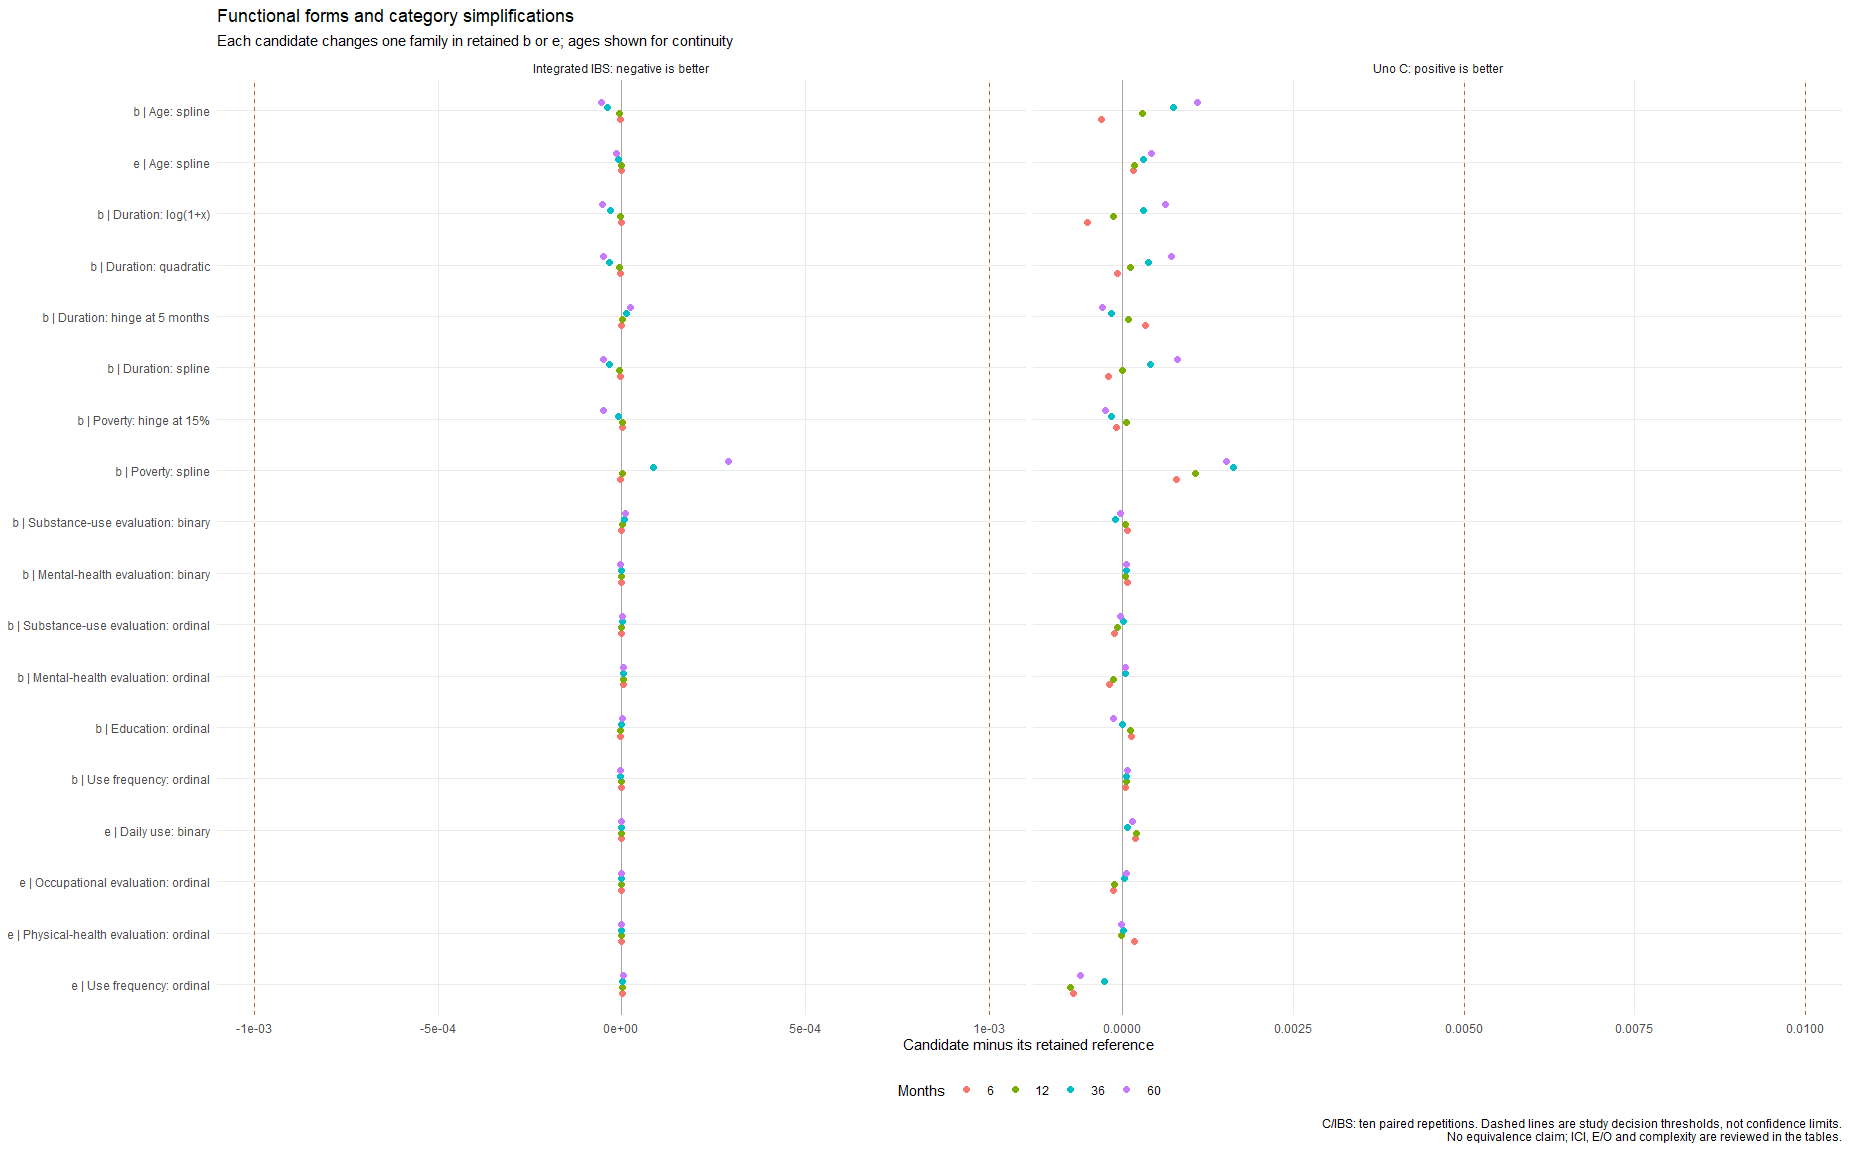

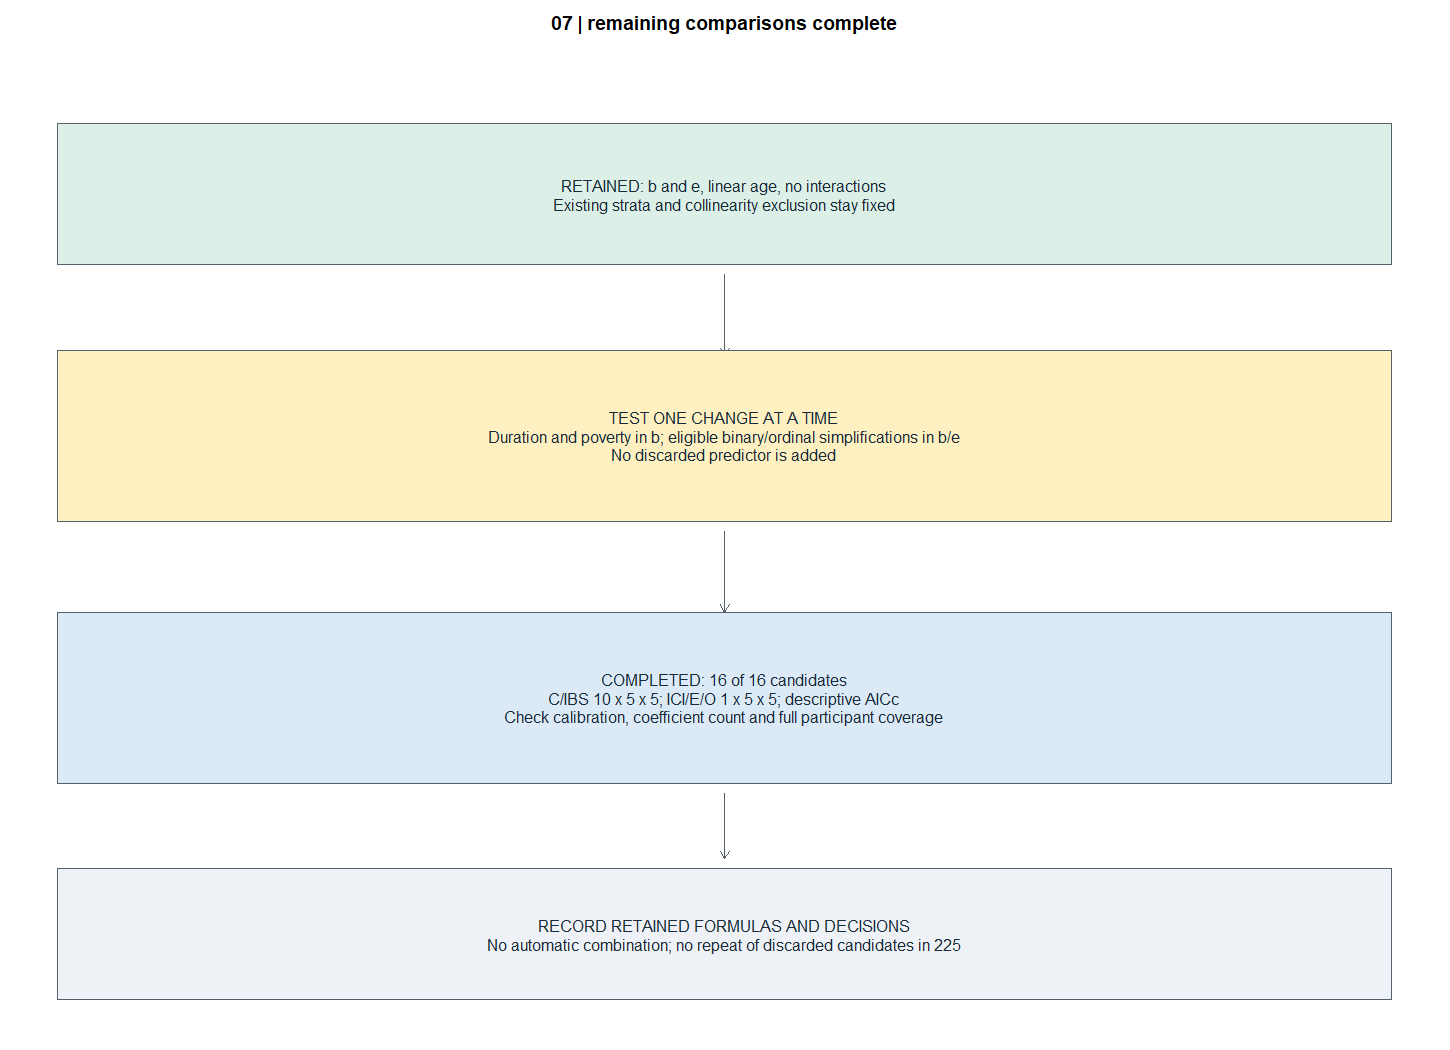

This branch covers b/e only. The 21 historical Full-mortality alternatives in eTable 6 have not been regenerated here. DCA, final consolidation and delta bootstrap belong to 225; holdout evaluation belongs to 23.


Elapsed: 0.008 minutes


In [106]:
#| label: shap-functional-remaining-summary
#| message: true
.t0 <- proc.time()
# Consolidate single-change comparisons without hiding the already completed age trials.
remaining_complete <- length(remaining_results) == nrow(remaining_candidates)
if (remaining_run) stopifnot(remaining_complete, setequal(names(remaining_results), remaining_candidates$Candidate))
if (remaining_complete) {
  remaining_comparison <- do.call(rbind, lapply(remaining_results, function(x) x$comparison))
  remaining_calibration <- do.call(rbind, lapply(names(remaining_results), function(id) cbind(Candidate = id, remaining_results[[id]]$calibration)))
  remaining_coverage <- do.call(rbind, lapply(names(remaining_results), function(id) cbind(Candidate = id, remaining_results[[id]]$calibration_coverage)))
  remaining_aicc <- do.call(rbind, lapply(names(remaining_results), function(id) cbind(Candidate = id, remaining_results[[id]]$aicc)))
  remaining_previous_vs_new <- do.call(rbind, lapply(remaining_results, function(x) x$previous_vs_new))
  stopifnot(nrow(remaining_comparison) == 64L, all(remaining_coverage$Omitted == 0L), nrow(remaining_aicc) == 80L, nrow(remaining_previous_vs_new) == 128L)
  age_rows <- do.call(rbind, lapply(c("b", "e"), function(base) {
    z <- if (base == "b") functional_age_comparison else mortality_age_comparison
    aicc <- if (base == "b") functional_age_aicc else mortality_age_aicc
    data.frame(Candidate = paste0(base, "_age_spline"), Base = base, Horizon = z$Horizon, Delta_C = z$Delta_C, Delta_IBS = z$Delta_IBS, Delta_ICI = z$Delta_ICI, Delta_EO = z$Delta_EO, Delta_AICc = mean(aicc$AICc[aicc$Model == "curve"]) - mean(aicc$AICc[aicc$Model == base]), Extra_coefficients = 2L, Primary_rule_met = z$Study_rule_met, Early_screen_numeric = functional_early_screen(z$Delta_C, z$Delta_IBS))
  }))
  functional_final_comparison <- rbind(age_rows, remaining_comparison[, names(age_rows)])
  show_table(functional_final_comparison, "All b/e single-change comparisons: age already rejected; remaining decisions use the confirmed study rule")
  show_table(remaining_calibration, "Short ICI and E/O comparisons; mortality changes also checked for readmission CIF")
  show_table(remaining_previous_vs_new, "eTables 5/6 sources: historical Word versus clean development; no manuscript replacement")
  plot_data <- rbind(data.frame(Candidate = functional_final_comparison$Candidate, Horizon = factor(functional_final_comparison$Horizon), Metric = "Uno C: positive is better", Difference = functional_final_comparison$Delta_C), data.frame(Candidate = functional_final_comparison$Candidate, Horizon = factor(functional_final_comparison$Horizon), Metric = "Integrated IBS: negative is better", Difference = functional_final_comparison$Delta_IBS))
  candidate_labels <- c(b_age_spline = "b | Age: spline", e_age_spline = "e | Age: spline", b_duration_log = "b | Duration: log(1+x)", b_duration_quadratic = "b | Duration: quadratic", b_duration_hinge5 = "b | Duration: hinge at 5 months", b_duration_spline = "b | Duration: spline", b_poverty_hinge15 = "b | Poverty: hinge at 15%", b_poverty_spline = "b | Poverty: spline", b_consumo_binary = "b | Substance-use evaluation: binary", b_mental_binary = "b | Mental-health evaluation: binary", b_consumo_ordinal = "b | Substance-use evaluation: ordinal", b_mental_ordinal = "b | Mental-health evaluation: ordinal", b_education_ordinal = "b | Education: ordinal", b_frequency_ordinal = "b | Use frequency: ordinal", e_frequency_daily = "e | Daily use: binary", e_occupation_ordinal = "e | Occupational evaluation: ordinal", e_physical_ordinal = "e | Physical-health evaluation: ordinal", e_frequency_ordinal = "e | Use frequency: ordinal")
  stopifnot(all(plot_data$Candidate %in% names(candidate_labels)))
  plot_data$Candidate <- factor(candidate_labels[plot_data$Candidate], levels = candidate_labels[rev(unique(functional_final_comparison$Candidate))])
  limits <- data.frame(Metric = c("Uno C: positive is better", "Uno C: positive is better", "Integrated IBS: negative is better", "Integrated IBS: negative is better"), Limit = c(0.005, 0.01, -0.001, 0.001))
  plot <- ggplot2::ggplot(plot_data, ggplot2::aes(Difference, Candidate, colour = Horizon)) + ggplot2::geom_vline(xintercept = 0, colour = "grey65") + ggplot2::geom_vline(data = limits, ggplot2::aes(xintercept = Limit), linetype = "dashed", colour = "#ad6b38") + ggplot2::geom_point(position = ggplot2::position_dodge(width = 0.45), size = 1.7) + ggplot2::facet_wrap(~Metric, scales = "free_x", nrow = 1L) + ggplot2::labs(title = "Functional forms and category simplifications", subtitle = "Each candidate changes one family in retained b or e; ages shown for continuity", x = "Candidate minus its retained reference", y = NULL, colour = "Months", caption = "C/IBS: ten paired repetitions. Dashed lines are study decision thresholds, not confidence limits.\nNo equivalence claim; ICI, E/O and complexity are reviewed in the tables.") + ggplot2::theme_minimal(base_size = 10) + ggplot2::theme(legend.position = "bottom", panel.grid.minor = ggplot2::element_blank())
  show_diagnostic_png(function() print(plot), 1850L, 1150L)
} else cat("Remaining comparisons prepared, not executed. Saved age results remain unchanged; no new metric is reported.", fill = TRUE)
show_diagnostic_png(function() {
  decision_canvas(if (remaining_complete) "07 | remaining comparisons complete" else "07 | remaining comparisons prepared")
  decision_box(0.04, 0.96, 0.85, "RETAINED: b and e, linear age, no interactions\nExisting strata and collinearity exclusion stay fixed", "accepted", h = 0.07)
  decision_arrow(0.5, 0.77, y2 = 0.69)
  decision_box(0.04, 0.96, 0.61, "TEST ONE CHANGE AT A TIME\nDuration and poverty in b; eligible binary/ordinal simplifications in b/e\nNo discarded predictor is added", "prepared", h = 0.085)
  decision_arrow(0.5, 0.515, y2 = 0.435)
  decision_box(0.04, 0.96, 0.35, sprintf("COMPLETED: %d of %d candidates\nC/IBS 10 x 5 x 5; ICI/E/O 1 x 5 x 5; descriptive AICc\nCheck calibration, coefficient count and full participant coverage", length(remaining_results), nrow(remaining_candidates)), "review", h = 0.085)
  decision_arrow(0.5, 0.255, y2 = 0.19)
  decision_box(0.04, 0.96, 0.115, if (remaining_complete) "RECORD RETAINED FORMULAS AND DECISIONS\nNo automatic combination; no repeat of discarded candidates in 225" else "NEXT: resource checkpoint, then complete the scheduled comparisons\nNo new models fitted in preparation mode", "pending", h = 0.065)
}, 1450L, 1050L)
cat("This branch covers b/e only. The 21 historical Full-mortality alternatives in eTable 6 have not been regenerated here. DCA, final consolidation and delta bootstrap belong to 225; holdout evaluation belongs to 23.", fill = TRUE)
review_pending <- TRUE
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


## Completed comparisons, retained formulas and supplement sources
Each row below represents an executed single change against fixed b/e. The selection rule was confirmed before execution: keep the current model unless C/IBS improves enough. Fewer coefficients alone do not select a replacement. Model retention and review of changed published rounding are recorded separately.

The investigator explicitly confirmed retaining b/e and proceeding to 225. A possible improvement restricted to a small subgroup remains untested; the distribution and SHAP plots do not establish its influence on C/IBS. Treatment duration remains in b and outside e. No subgroup is excluded and no candidate is added.


Candidate,Base,Predictor,Change,Minimum_delta_C,Maximum_delta_C,Minimum_delta_IBS,Maximum_delta_IBS,ICI_improved_horizons,Delta_AICc,Extra_coefficients,Primary_rule_horizons,Early_screen_all_horizons,Decision
b_age_spline,b,Age at admission,"Natural spline, 3 df",-0.000303,0.001098,-0.000056,-0.000003,2,-58.4336,2,0,TRUE,Investigator confirmed linear age
e_age_spline,e,Age at admission,"Natural spline, 3 df",0.000154,0.000426,-0.000014,-0.000000,4,-14.8961,2,0,TRUE,Investigator confirmed linear age
b_duration_log,b,Treatment duration,Log(1+x) transformation,-0.000515,0.000627,-0.000052,-0.000000,1,-23.4399,0,0,TRUE,Retain current model under the confirmed C/IBS rule
b_duration_quadratic,b,Treatment duration,Quadratic term,-0.000075,0.000713,-0.000050,-0.000005,1,-26.1951,1,0,TRUE,Retain current model under the confirmed C/IBS rule
b_duration_hinge5,b,Treatment duration,Hinge at 5 months,-0.000294,0.000330,-0.000000,0.000024,2,10.9933,0,0,TRUE,Retain current model under the confirmed C/IBS rule
b_duration_spline,b,Treatment duration,"Natural spline, 3 df",-0.000201,0.000799,-0.000049,-0.000003,1,-26.4930,2,0,TRUE,Retain current model under the confirmed C/IBS rule
b_poverty_hinge15,b,Communal poverty index,Hinge at 0.15,-0.000246,0.000053,-0.000049,0.000002,2,10.9732,0,0,TRUE,Retain current model under the confirmed C/IBS rule
b_poverty_spline,b,Communal poverty index,"Natural spline, 3 df",0.000784,0.001631,-0.000005,0.000290,1,-50.3315,2,0,TRUE,Retain current model under the confirmed C/IBS rule
b_consumo_binary,b,"Discharge evaluation, substance use","Any lower achievement, dummy",-0.000100,0.000068,0.000000,0.000010,3,2.0868,-1,0,TRUE,Retain current model under the confirmed C/IBS rule
b_mental_binary,b,"Discharge evaluation, mental health","Any lower achievement, dummy",0.000042,0.000066,-0.000003,-0.000000,2,-1.8055,-1,0,TRUE,Retain current model under the confirmed C/IBS rule


Candidate,Horizon,Published_Delta_C,Historical_export_Delta_C,Delta_C,Classification_Delta_C,Published_Delta_IBS,Historical_export_Delta_IBS,Delta_IBS,Classification_Delta_IBS
e_age_spline,6,-0.0111,-0.01109523,0.0001539852,substantial: published rounding changes,1e-05,9.851303e-06,-4.286433e-07,substantial: published rounding changes
e_age_spline,12,-0.0094,-0.00940408,0.0001691142,substantial: published rounding changes,1e-05,9.92094e-06,-1.816325e-06,substantial: published rounding changes
e_age_spline,36,-0.01155,-0.01154529,0.0003130733,substantial: published rounding changes,5e-05,4.987508e-05,-1.008402e-05,substantial: published rounding changes
e_age_spline,60,-0.01103,-0.0110285,0.0004258423,substantial: published rounding changes,0.00013,0.0001274649,-1.434391e-05,substantial: published rounding changes
b_duration_hinge5,6,0.00032,0.0003238948,0.0003296798,substantial: published rounding changes,0,5.415666e-07,-4.291984e-07,substantial: direction changes within published rounding
b_duration_spline,6,0.00011,0.0001085526,-0.0002013967,substantial: published rounding changes,-1e-05,-7.16619e-06,-2.682324e-06,substantial: published rounding changes
b_education_ordinal,60,-0.00012,-0.000116327,-0.0001358354,substantial: published rounding changes,0,-1.845806e-06,1.58455e-06,substantial: direction changes within published rounding
e_occupation_ordinal,36,-0.00017,-0.000168837,3.228154e-05,substantial: published rounding changes,0,-1.139307e-06,-7.692886e-09,trivial
e_occupation_ordinal,60,-0.00012,-0.000115198,5.320857e-05,substantial: published rounding changes,0,6.036494e-07,1.639003e-07,trivial


Model,Stratification,Interactions,Continuous_age,Collinear_term,Formula
b: SHAP readmission,Treatment setting + rule violation/undetermined discharge,None,Linear,Excluded,"Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + adm_age_rec3 + porc_pobr + sex_rec_woman + ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + evaluacindelprocesoteraputico_logro_intermedio + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)"
e: SHAP mortality,Treatment setting + physical comorbidity,None,Linear,Excluded,"Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo + eva_fisica_logro_intermedio + eva_fisica_logro_minimo + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + sex_rec_woman + strata(plan_type_strata) + strata(any_phys_dx)"


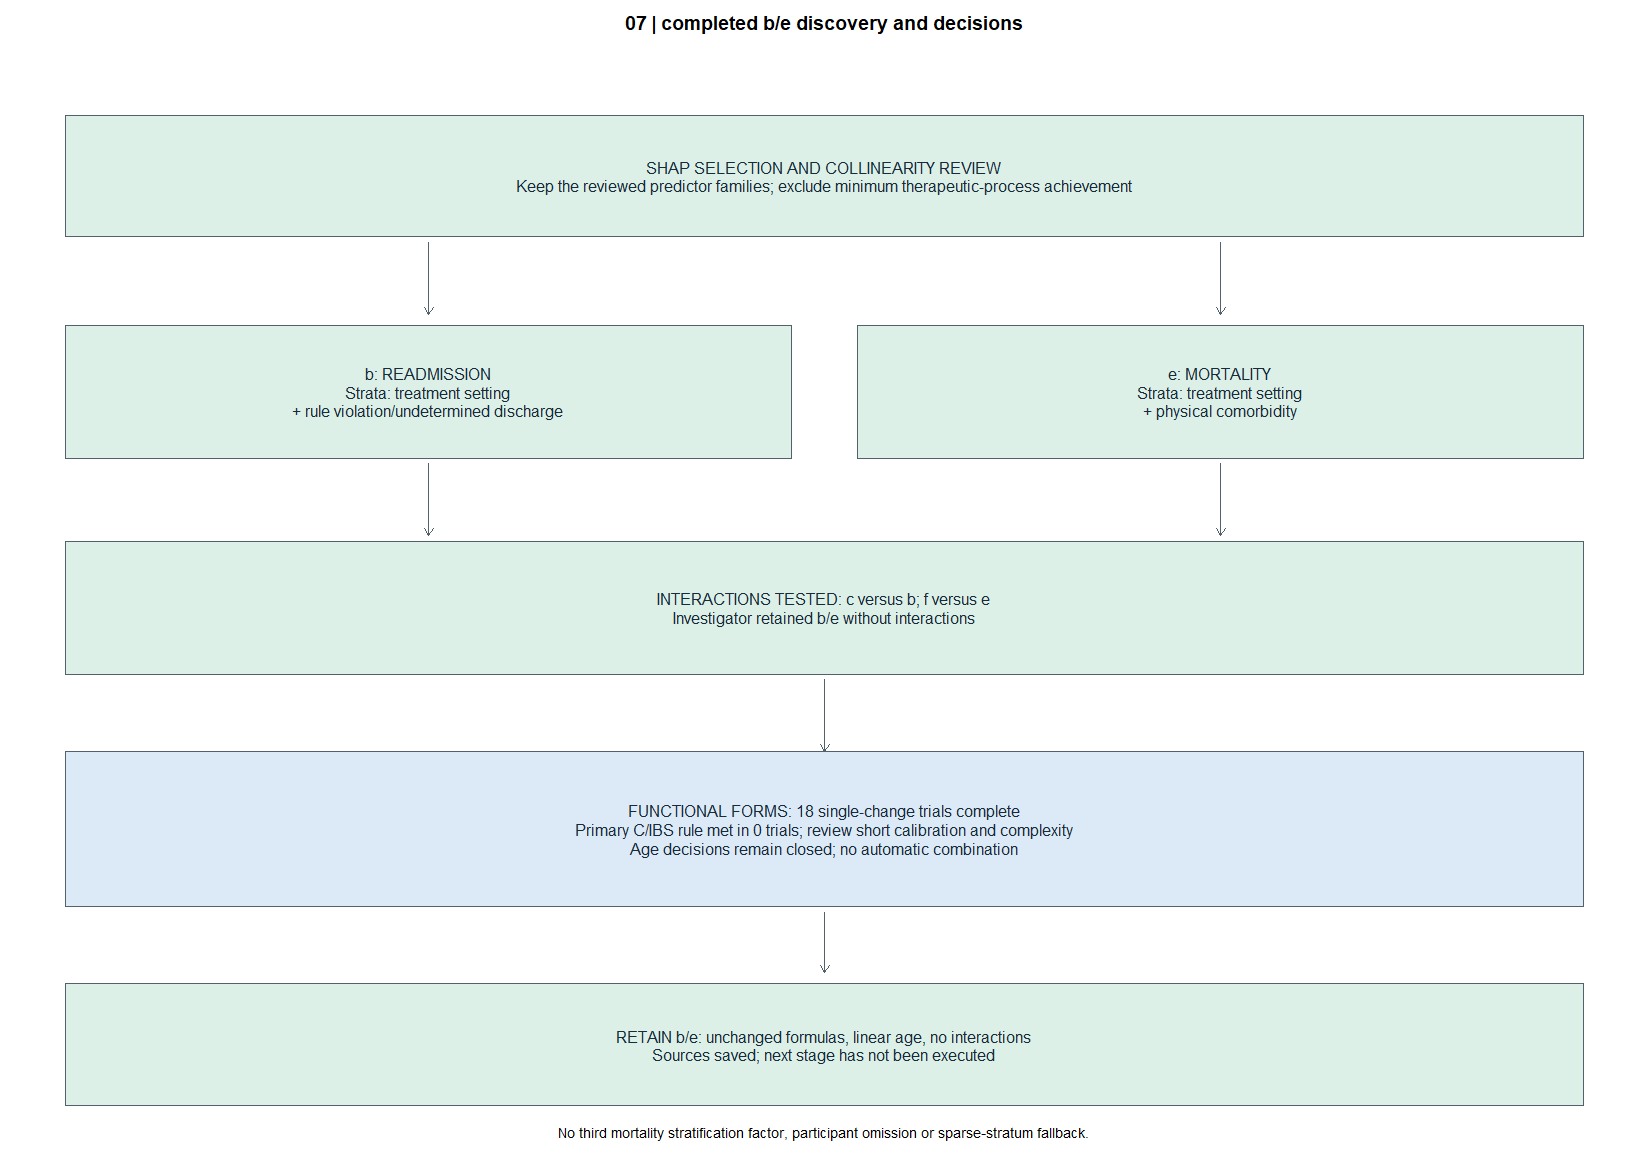

The sources include 13 readmission and five mortality single-change trials, including the two age trials. The 21 historical Full-mortality alternatives in eTable 6 are outside this branch; the complete historical table is not claimed to be reproduced. Rejected candidates need no duplicate comparison in 225. DCA, final consolidation and held-out evaluation have not run here.


The earlier quadratic-age proposals were not pursued after the investigator confirmed linear age in both models. They are not among the 18 executed trials and are not counted as tested or rejected by a numerical comparison.


Historical published and clean-pipeline estimates are retained side by side. Rounding changes are explicitly classified; differences do not isolate the effect of imputation, formula selection, spline construction or scoring conventions. No manuscript value or old interval is transferred.


Model decision recorded: TRUE | Separate manuscript-rounding review pending: TRUE 


Elapsed: 0.004 minutes


In [107]:
#| label: shap-functional-final-sources-and-decision
#| message: true
.t0 <- proc.time()
# Publish only executed comparisons; retain the recorded formulas unless the study rule selects a change.
stopifnot(remaining_complete, nrow(functional_final_comparison) == 72L, all(remaining_coverage$Omitted == 0L))
remaining_decision <- shap_settings$functional_remaining_decision
remaining_rule_accepted <- !is.null(remaining_decision) && identical(remaining_decision$signature, remaining_signature) && identical(remaining_decision$choice, "retain_b_e")
if (!is.null(remaining_decision)) stopifnot(remaining_rule_accepted, !any(remaining_comparison$Primary_rule_met))
remaining_manuscript_review_pending <- any(grepl("^substantial", remaining_previous_vs_new$Classification))
functional_labels <- rbind(data.frame(Candidate = c("b_age_spline", "e_age_spline"), Base = c("b", "e"), Label = "Age at admission", Modification = "Natural spline, 3 df"), remaining_candidates[, c("Candidate", "Base", "Label", "Modification")])
remaining_decisions <- do.call(rbind, lapply(unique(functional_final_comparison$Candidate), function(id) {
  x <- functional_final_comparison[functional_final_comparison$Candidate == id, ]
  label <- functional_labels[functional_labels$Candidate == id, ]
  data.frame(Candidate = id, Base = label$Base, Predictor = label$Label, Change = label$Modification, Minimum_delta_C = min(x$Delta_C), Maximum_delta_C = max(x$Delta_C), Minimum_delta_IBS = min(x$Delta_IBS), Maximum_delta_IBS = max(x$Delta_IBS), ICI_improved_horizons = sum(x$Delta_ICI < 0), Delta_AICc = unique(x$Delta_AICc), Extra_coefficients = unique(x$Extra_coefficients), Primary_rule_horizons = sum(x$Primary_rule_met), Early_screen_all_horizons = all(x$Early_screen_numeric), Decision = if (id %in% c("b_age_spline", "e_age_spline")) "Investigator confirmed linear age" else if (remaining_rule_accepted) "Retain current model under the confirmed C/IBS rule" else "Decision review pending")
}))
stopifnot(nrow(remaining_decisions) == 18L, !anyDuplicated(remaining_decisions$Candidate))
display_decisions <- remaining_decisions
for (column in c("Minimum_delta_C", "Maximum_delta_C", "Minimum_delta_IBS", "Maximum_delta_IBS")) display_decisions[[column]] <- formatC(display_decisions[[column]], format = "f", digits = 6L)
show_table(display_decisions, "Completed single-change trials and recorded decisions; lower AICc alone does not select a model")
# Add absolute values and authoritative historical deltas without substituting intervals from the old analysis.
age_absolute <- do.call(rbind, lapply(c("b", "e"), function(base) {
  x <- if (base == "b") functional_age_comparison else mortality_age_comparison
  z <- data.frame(Candidate = paste0(base, "_age_spline"), Horizon = x$Horizon)
  for (metric in c("C", "IBS", "ICI", "EO")) {
    z[[paste0(metric, "_base")]] <- x[[paste0(metric, "_", base)]]
    z[[paste0(metric, "_candidate")]] <- x[[paste0(metric, "_curve")]]
  }
  z
}))
absolute <- rbind(age_absolute, remaining_comparison[, names(age_absolute)])
functional_final_source <- merge(functional_final_comparison, absolute, by = c("Candidate", "Horizon"), sort = FALSE)
functional_final_source <- merge(functional_final_source, functional_labels[, c("Candidate", "Label", "Modification")], by = "Candidate", sort = FALSE)
functional_final_source <- functional_final_source[order(match(functional_final_source$Candidate, functional_labels$Candidate), functional_final_source$Horizon), ]
functional_final_source$Decision <- remaining_decisions$Decision[match(functional_final_source$Candidate, remaining_decisions$Candidate)]
functional_final_source$Source_table <- ifelse(functional_final_source$Base == "b", "eTable 5, SHAP branch", "eTable 6, SHAP branch")
functional_final_source$Calibration_target <- ifelse(functional_final_source$Base == "b", "Readmission AJ CIF", "Mortality net risk, KM")
functional_final_source$C_IBS_design <- "10 repetitions x 5 folds x 5 imputations"
functional_final_source$Calibration_design <- "1 repetition x 5 folds x 5 imputations"
history_key <- paste(remaining_all_published$Candidate, remaining_all_published$Horizon, remaining_all_published$Metric)
stopifnot(!anyDuplicated(history_key), nrow(functional_final_source) == 72L)
for (metric in c("Delta_C", "Delta_IBS")) {
  index <- match(paste(functional_final_source$Candidate, functional_final_source$Horizon, metric), history_key)
  stopifnot(!anyNA(index))
  previous <- remaining_all_published$Previous_published[index]
  historical <- remaining_all_published$Historical_csv[index]
  digits <- remaining_all_published$Published_decimals[index]
  current <- functional_final_source[[metric]]
  direction_changed <- !is.na(historical) & historical * current < 0
  functional_final_source[[paste0("Published_", metric)]] <- previous
  functional_final_source[[paste0("Historical_export_", metric)]] <- historical
  functional_final_source[[paste0("Direction_changed_", metric)]] <- direction_changed
  functional_final_source[[paste0("Difference_from_published_", metric)]] <- current - previous
  functional_final_source[[paste0("Classification_", metric)]] <- ifelse(is.na(previous), "No equivalent prior e result", ifelse(round(current, digits) != previous, "substantial: published rounding changes", ifelse(direction_changed, "substantial: direction changes within published rounding", "trivial")))
}
new_rows <- !functional_final_source$Candidate %in% c("b_age_spline", "e_age_spline")
remaining_manuscript_review_pending <- any(grepl("^substantial", functional_final_source$Classification_Delta_C[new_rows])) || any(grepl("^substantial", functional_final_source$Classification_Delta_IBS[new_rows]))
direction_review <- functional_final_source[functional_final_source$Direction_changed_Delta_C | functional_final_source$Direction_changed_Delta_IBS, c("Candidate", "Horizon", "Published_Delta_C", "Historical_export_Delta_C", "Delta_C", "Classification_Delta_C", "Published_Delta_IBS", "Historical_export_Delta_IBS", "Delta_IBS", "Classification_Delta_IBS")]
display_direction <- direction_review
for (column in c("Published_Delta_C", "Historical_export_Delta_C", "Delta_C", "Published_Delta_IBS", "Historical_export_Delta_IBS", "Delta_IBS")) display_direction[[column]] <- formatC(display_direction[[column]], format = "g", digits = 7L)
show_table(display_direction, "Historical direction changes, including changes hidden by published rounding; these do not establish a different model choice")
stopifnot(all(is.finite(as.matrix(functional_final_source[, c("C_base", "C_candidate", "IBS_base", "IBS_candidate", "ICI_base", "ICI_candidate", "EO_base", "EO_candidate")]))), identical(formula_terms(functional_bases$b), formula_terms(formula_shap_readmit_clean_updated)), identical(formula_terms(functional_bases$e), formula_terms(formula_shap_death_rule2)))
for (base in c("b", "e")) {
  destination <- file.path(table_dir, paste0(if (base == "b") "eTable5" else "eTable6", "_SHAP_functional_comparisons_", Sys.Date(), "_", remaining_signature, ".csv"))
  utils::write.csv(functional_final_source[functional_final_source$Base == base, ], destination, row.names = FALSE, na = "")
  written <- c(written, destination)
}
# Keep a compact handoff with formulas and metrics, never participant data or an entire R workspace.
functional_handoff <- list(scope = "Completed b/e discovery branch; historical Full-mortality alternatives not regenerated", signature = remaining_signature, performance_signature = performance_signature, formulas = lapply(functional_bases, function(f) paste(deparse(f), collapse = " ")), formula_names = c(b = "formula_shap_readmit_clean_updated", e = "formula_shap_death_rule2"), strata = lapply(functional_bases, formula_strata), decisions = remaining_decisions, comparisons = functional_final_source, additional_calibration = remaining_calibration, calibration_coverage = remaining_coverage, settings = functional_settings, selection_rule = "Retain current model unless delta Uno C >= 0.01 and delta IBS <= 0.001; review calibration and support", imputation_limitation = "Complete-development imputation and SHAP selection precede internal CV; this is not independent validation of the complete preprocessing workflow", manuscript_review_pending = remaining_manuscript_review_pending, manuscript_review = "Model retention follows the confirmed rule; historical rounding discrepancies require their own review; no Word replacement", historical_full_candidates_regenerated = FALSE)
destination <- file.path(object_dir, paste0("Table2_SHAP_retained_model_handoff_", Sys.Date(), "_", remaining_signature, ".rds"))
saveRDS(functional_handoff, destination)
stopifnot(identical(readRDS(destination), functional_handoff))
written <- c(written, destination)
show_table(data.frame(Model = c("b: SHAP readmission", "e: SHAP mortality"), Stratification = c("Treatment setting + rule violation/undetermined discharge", "Treatment setting + physical comorbidity"), Interactions = "None", Continuous_age = "Linear", Collinear_term = "Excluded", Formula = unlist(functional_handoff$formulas, use.names = FALSE)), "Retained formulas for the next stage")
show_diagnostic_png(function() {
  decision_canvas("07 | completed b/e discovery and decisions")
  decision_box(0.04, 0.96, 0.88, "SHAP SELECTION AND COLLINEARITY REVIEW\nKeep the reviewed predictor families; exclude minimum therapeutic-process achievement", "accepted", h = 0.055)
  decision_arrow(0.26, 0.82, y2 = 0.755)
  decision_arrow(0.74, 0.82, y2 = 0.755)
  decision_box(0.04, 0.48, 0.685, "b: READMISSION\nStrata: treatment setting\n+ rule violation/undetermined discharge", "accepted", h = 0.06)
  decision_box(0.52, 0.96, 0.685, "e: MORTALITY\nStrata: treatment setting\n+ physical comorbidity", "accepted", h = 0.06)
  decision_arrow(0.26, 0.62, y2 = 0.555)
  decision_arrow(0.74, 0.62, y2 = 0.555)
  decision_box(0.04, 0.96, 0.49, "INTERACTIONS TESTED: c versus b; f versus e\nInvestigator retained b/e without interactions", "accepted", h = 0.06)
  decision_arrow(0.5, 0.425, y2 = 0.36)
  decision_box(0.04, 0.96, 0.29, sprintf("FUNCTIONAL FORMS: %d single-change trials complete\nPrimary C/IBS rule met in %d trials; review short calibration and complexity\nAge decisions remain closed; no automatic combination", nrow(remaining_decisions), sum(remaining_decisions$Primary_rule_horizons > 0)), "review", h = 0.07)
  decision_arrow(0.5, 0.215, y2 = 0.16)
  decision_box(0.04, 0.96, 0.095, if (remaining_rule_accepted) "RETAIN b/e: unchanged formulas, linear age, no interactions\nSources saved; next stage has not been executed" else "DECISION REVIEW PENDING\nCurrent b/e remain unchanged; sources saved", if (remaining_rule_accepted) "accepted" else "pending", h = 0.055)
  graphics::text(0.5, 0.015, "No third mortality stratification factor, participant omission or sparse-stratum fallback.", cex = 0.75)
}, 1650L, 1150L)
cat("The sources include 13 readmission and five mortality single-change trials, including the two age trials. The 21 historical Full-mortality alternatives in eTable 6 are outside this branch; the complete historical table is not claimed to be reproduced. Rejected candidates need no duplicate comparison in 225. DCA, final consolidation and held-out evaluation have not run here.", fill = TRUE)
cat("The earlier quadratic-age proposals were not pursued after the investigator confirmed linear age in both models. They are not among the 18 executed trials and are not counted as tested or rejected by a numerical comparison.", fill = TRUE)
cat("Historical published and clean-pipeline estimates are retained side by side. Rounding changes are explicitly classified; differences do not isolate the effect of imputation, formula selection, spline construction or scoring conventions. No manuscript value or old interval is transferred.", fill = TRUE)
review_pending <- !remaining_rule_accepted || remaining_manuscript_review_pending
functional_candidate_review_pending <- !remaining_rule_accepted
cat("Model decision recorded:", remaining_rule_accepted, "| Separate manuscript-rounding review pending:", remaining_manuscript_review_pending, "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


### eTables 5 and 6: compact functional-form comparisons

The displays below reuse the completed source tables. Readmission coverage is complete; mortality coverage is the SHAP block only.

In [108]:
#| label: shap-functional-etable5-etable6-display
#| message: true
.t0 <- proc.time()
# Reshape the completed comparisons for display only; keep full-precision sources and decisions unchanged.
stopifnot(nrow(functional_final_source) == 72L, !anyDuplicated(paste(functional_final_source$Candidate, functional_final_source$Horizon)), all(c("Candidate", "Base", "Horizon", "Label", "Modification", "Delta_C", "Delta_IBS", "Decision") %in% names(functional_final_source)))
compact_functional_tables <- lapply(c("b", "e"), function(base) {
  source <- functional_final_source[functional_final_source$Base == base, ]
  alternatives <- unique(source[, c("Candidate", "Label", "Modification", "Decision")])
  reference <- remaining_word_tables[[base]]
  original_order <- match(paste(alternatives$Label, alternatives$Modification), paste(reference[, 1L], reference[, 2L]))
  new_ids <- alternatives$Candidate[is.na(original_order)]
  stopifnot(!anyDuplicated(alternatives$Candidate), nrow(alternatives) == if (base == "b") 13L else 5L, if (base == "b") length(new_ids) == 0L else identical(new_ids, "e_physical_ordinal"))
  alternatives <- alternatives[order(original_order, na.last = TRUE), ]
  display <- alternatives[, c("Label", "Modification"), drop = FALSE]
  names(display) <- c("Alternative specification", "Modification")
  # Match the manuscript row order; append the newly eligible physical-evaluation comparison separately.
  if (base == "e") display[["Alternative specification"]][alternatives$Candidate == "e_physical_ordinal"] <- paste0(display[["Alternative specification"]][alternatives$Candidate == "e_physical_ordinal"], " [new]")
  for (metric in c("Delta_C", "Delta_IBS")) {
    for (horizon in c(6, 12, 36, 60)) {
      index <- match(paste(alternatives$Candidate, horizon), paste(source$Candidate, source$Horizon))
      stopifnot(!anyNA(index), all(is.finite(source[[metric]][index])))
      display[[paste(metric, horizon, sep = "_")]] <- sub("^-0\\.00000$", "0.00000", formatC(source[[metric]][index], format = "f", digits = 5L))
    }
  }
  if (base == "b") display[["Decision"]] <- ifelse(alternatives$Decision %in% c("Investigator confirmed linear age", "Retain current model under the confirmed C/IBS rule"), "Not retained", alternatives$Decision)
  names(display)[3:10] <- c(if (base == "b") "\u0394Uno's C, 6 mo" else "\u0394Uno's C 6 mo", "12 mo", "36 mo", "60 mo", if (base == "b") "\u0394IBS, 6 mo" else "\u0394IBS 6 mo", "12 mo", "36 mo", "60 mo")
  rownames(display) <- NULL
  display
})
names(compact_functional_tables) <- c("b", "e")
stopifnot(identical(dim(compact_functional_tables$b), c(13L, 11L)), identical(dim(compact_functional_tables$e), c(5L, 10L)))
cat("These are newly executed clean-development estimates in the manuscript layout, not the old published values. Each alternative changes one predictor in the fixed retained model: b for readmission or e for mortality. Deltas are candidate minus baseline: positive Uno's C and negative IBS favor the candidate. C/IBS use 10 repetitions x 5 folds x 5 imputations. Five-decimal formatting is for display only; full precision and historical discrepancies remain in the source tables.", fill = TRUE)
show_table(compact_functional_tables$b, "eTable 5. Clean readmission functional-form comparisons against b: all 13 original alternatives")
cat("eTable 6 coverage: all four original SHAP alternatives are shown, followed by one new physical-evaluation ordinal alternative marked [new]. The original table also contains 21 Full-mortality alternatives; those have not been regenerated in this clean b/e branch and are not represented by the SHAP results below. This is the SHAP block, not the complete original eTable 6.", fill = TRUE)
show_table(compact_functional_tables$e, "eTable 6. Clean mortality functional-form comparisons against e: SHAP block only (four original alternatives plus one new)")
cat("Published-rounding and historical-direction discrepancies remain recorded separately. These displays do not alter the manuscript, select a new model or close the separate manuscript review.", fill = TRUE)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

These are newly executed clean-development estimates in the manuscript layout, not the old published values. Each alternative changes one predictor in the fixed retained model: b for readmission or e for mortality. Deltas are candidate minus baseline: positive Uno's C and negative IBS favor the candidate. C/IBS use 10 repetitions x 5 folds x 5 imputations. Five-decimal formatting is for display only; full precision and historical discrepancies remain in the source tables.


Alternative specification,Modification,"ΔUno's C, 6 mo",12 mo,36 mo,60 mo,"ΔIBS, 6 mo",12 mo,36 mo,60 mo,Decision
Communal poverty index,"Natural spline, 3 df",0.00078,0.00107,0.00163,0.00153,0.00000,0.00000,0.00009,0.00029,Not retained
Treatment duration,"Natural spline, 3 df",-0.00020,0.00001,0.00041,0.00080,0.00000,-0.00001,-0.00003,-0.00005,Not retained
Treatment duration,Quadratic term,-0.00008,0.00012,0.00038,0.00071,0.00000,-0.00001,-0.00003,-0.00005,Not retained
Treatment duration,Log(1+x) transformation,-0.00052,-0.00014,0.00031,0.00063,0.00000,0.00000,-0.00003,-0.00005,Not retained
Age at admission,"Natural spline, 3 df",-0.00030,0.00029,0.00075,0.00110,0.00000,-0.00001,-0.00004,-0.00006,Not retained
Treatment duration,Hinge at 5 months,0.00033,0.00008,-0.00017,-0.00029,0.00000,0.00000,0.00001,0.00002,Not retained
Communal poverty index,Hinge at 0.15,-0.00010,0.00005,-0.00016,-0.00025,0.00000,0.00000,-0.00001,-0.00005,Not retained
"Discharge evaluation, mental health","Any lower achievement, dummy",0.00007,0.00004,0.00005,0.00006,0.00000,0.00000,0.00000,0.00000,Not retained
"Discharge evaluation, substance use","Any lower achievement, dummy",0.00007,0.00004,-0.00010,-0.00004,0.00000,0.00000,0.00001,0.00001,Not retained
Educational attainment,Ordinal score,0.00013,0.00012,0.00000,-0.00014,0.00000,0.00000,0.00000,0.00000,Not retained


eTable 6 coverage: all four original SHAP alternatives are shown, followed by one new physical-evaluation ordinal alternative marked [new]. The original table also contains 21 Full-mortality alternatives; those have not been regenerated in this clean b/e branch and are not represented by the SHAP results below. This is the SHAP block, not the complete original eTable 6.


Alternative specification,Modification,ΔUno's C 6 mo,12 mo,36 mo,60 mo,ΔIBS 6 mo,12 mo,36 mo,60 mo
Primary-substance use frequency,"High frequency, dummy",0.00020,0.00021,0.00008,0.00014,0.00000,0.00000,0.00000,0.00000
Age at admission,"Natural spline, 3 df",0.00015,0.00017,0.00031,0.00043,0.00000,0.00000,-0.00001,-0.00001
"Discharge evaluation, occupational status",Ordinal score,-0.00014,-0.00013,0.00003,0.00005,0.00000,0.00000,0.00000,0.00000
Primary-substance use frequency,Ordinal score,-0.00072,-0.00076,-0.00026,-0.00062,0.00000,0.00000,0.00000,0.00001
"Discharge evaluation, physical health [new]",Ordinal score,0.00018,-0.00001,0.00001,-0.00002,0.00000,0.00000,0.00000,0.00000


Published-rounding and historical-direction discrepancies remain recorded separately. These displays do not alter the manuscript, select a new model or close the separate manuscript review.


Elapsed: 0.001 minutes


In [109]:
#| label: shap-stage-status-and-resources
#| message: false
.t0 <- proc.time()
# Report actual work and stop scientific progression at the current investigator checkpoint.
memory <- ps::ps_system_memory()
show_table(data.frame(Checkpoint = "Remaining functional comparisons", Status = if (remaining_complete) "All scheduled comparisons complete; recorded decisions and published-number flags shown above" else "Sixteen comparisons prepared; no new fits; resource checkpoint pending"), "Current completion stage")
show_table(data.frame(Checkpoint = "Mortality age", Status = if (mortality_age_review_accepted) "Confirmed: linear age in b and e; rejected age curves are cache-only" else if (mortality_age_complete) "e age comparison complete; investigator choice pending; b/e remain retained" else "Filter confirmed; evaluation prepared; baseline controls passed; no candidate fits"), "Current checkpoint")
show_table(data.frame(Component = c("Full reference", "SHAP mapping", "Historical formula control", "Initial PH/VIF", "C/IBS and repeated calibration", "Interactions and functional forms"), Status = c("Reused from complete 06; continuation authorized", "Accepted 03 signals expanded with the original rule", "Passed", if (length(diagnostics)) "Initial checkpoint accepted; sequential candidates displayed" else "Ready to execute", if (mortality_step_enabled) if (mortality_step_complete) if (mortality_step_review_accepted) "Models b/e accepted; saved comparison verified" else "Model b accepted; model e review pending" else "Model b accepted; model e prepared, resource scheduling pending" else if (readmission_step_enabled) if (readmission_step_complete) "Readmission discharge-stratum comparison complete; investigator review pending" else "VIF checkpoint accepted; readmission discharge-stratum scheduling pending" else if (vif_complete) "VIF-resolved C/IBS and calibration complete; investigator review pending" else if (performance_complete) "All candidates complete; investigator choice pending" else if (length(performance_results)) "Initial-selection C/IBS complete; investigator review and calibration pending" else "Ten-repeat initial-selection checkpoint prepared; scheduling pending", if (interaction_f_complete) if (mortality_interaction_review_accepted) if (functional_age_review_accepted) "Retain b/e under the confirmed C/IBS rule; all scheduled functional comparisons complete" else if (functional_age_complete) "Retain b/e; age-only comparison complete, review pending" else "Retain b/e; age-only comparison pending" else "e/f C/IBS and both calibration targets complete; investigator choice pending" else if (interaction_c_complete) if (readmission_interaction_review_accepted) paste("b/c review complete; retain", readmission_interaction_choice, "; f not run") else "b/c C/IBS and calibration complete; investigator review pending; f not run" else "b/c C/IBS and calibration prepared; no new PH/VIF; f not run")), "Current execution status")
show_table(data.frame(Item = c("Available RAM (GiB)", "Current R working set (GiB)", "Threads", "New Cox fits", "New PH tests", "New predictive/AICc Cox fits", "New imputations/tuning/SHAP/bootstrap"), Value = c(memory$avail / 1024^3, ps::ps_memory_info()[["rss"]] / 1024^3, threads, new_model_fits, new_ph_tests, performance_new_fits, 0)), "Actual resources and computation")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Checkpoint,Status
Remaining functional comparisons,All scheduled comparisons complete; recorded decisions and published-number flags shown above


Checkpoint,Status
Mortality age,Confirmed: linear age in b and e; rejected age curves are cache-only


Component,Status
Full reference,Reused from complete 06; continuation authorized
SHAP mapping,Accepted 03 signals expanded with the original rule
Historical formula control,Passed
Initial PH/VIF,Initial checkpoint accepted; sequential candidates displayed
C/IBS and repeated calibration,Models b/e accepted; saved comparison verified
Interactions and functional forms,Retain b/e under the confirmed C/IBS rule; all scheduled functional comparisons complete


Item,Value
Available RAM (GiB),58.0604
Current R working set (GiB),0.6264
Threads,2.0000
New Cox fits,0.0000
New PH tests,0.0000
New predictive/AICc Cox fits,0.0000
New imputations/tuning/SHAP/bootstrap,0.0000


Elapsed: 0.001 minutes


## Full mortality: complete eTable 6 comparison
These 21 original alternatives complete the requested manuscript outputs. Each changes one predictor family in the retained Full mortality comparator **d**. Models b/e remain fixed. Existing metrics, first-repetition controls, five imputations, ten paired C/IBS partitions and one calibration repetition are reused. The complete three-column age spline follows the previously accepted basis correction. No participant is excluded and no new interaction, PH/VIF test, imputation or bootstrap is introduced.
```{mermaid}
flowchart TD
 A[Retained Full mortality d] --> B[21 original single-family alternatives]
 B --> C[10 x 5 x 5 risk-based C and integrated IBS]
 B --> D[1 x 5 x 5 ICI and E/O; descriptive AICc]
 C --> E[eTable 6; same materiality rule]
 D --> E
 E --> F[Keep b/e; flag any promising Full alternative]
```

In [110]:
#| label: full-functional-register
#| message: false
.t0 <- proc.time()
# Reuse the original Full formula and exact transformation definitions.
full_base <- cox_formulas$death$stratified
stopifnot(!removed_collinear %in% all.vars(full_base), setequal(formula_strata(full_base), c("plan_type_strata", "tr_outcome_adm_discharge_rule_violation_undet")))
full_pairs <- list(consumo=c("eva_consumo_logro_intermedio","eva_consumo_logro_minimo"),mental=c("eva_sm_logro_intermedio","eva_sm_logro_minimo"),occupation=c("eva_ocupacion_logro_intermedio","eva_ocupacion_logro_minimo"),physical=c("eva_fisica_logro_intermedio","eva_fisica_logro_minimo"),relations=c("eva_relinterp_logro_intermedio","eva_relinterp_logro_minimo"),norms=c("eva_transgnorma_logro_intermedio","eva_transgnorma_logro_minimo"),family=c("eva_fam_logro_intermedio","eva_fam_logro_minimo"),education=c("ed_attainment_corr_2_completed_high_school_or_less","ed_attainment_corr_3_completed_primary_school_or_less"),frequency=c("prim_sub_freq_rec_2_2_6_days_wk","prim_sub_freq_rec_3_daily"),urbanicity=c("urbanicity_cat_2_mixed","urbanicity_cat_1_rural"),tenure=c("tenure_status_household_others","tenure_status_household_renting","tenure_status_household_stays_temporarily_with_a_relative","tenure_status_household_illegal_settlement"))
full_labels <- c(consumo="Discharge evaluation, substance use",mental="Discharge evaluation, mental health",occupation="Discharge evaluation, occupational status",physical="Discharge evaluation, physical health",relations="Discharge evaluation, interpersonal relations",norms="Discharge evaluation, rule transgression",family="Discharge evaluation, family",education="Educational attainment",frequency="Primary-substance use frequency",urbanicity="Urbanicity",tenure="Household tenure")
full_register <- data.frame(Candidate=c("d_age_quadratic","d_age_spline","d_frequency_daily","d_physical_binary","d_poverty_hinge22","d_education_primary","d_mental_binary","d_consumo_binary","d_duration_hinge9","d_tenure_hinge1",paste0("d_",names(full_pairs),"_ordinal")),Label=c("Age at admission","Age at admission",full_labels[c("frequency","physical")],"Communal poverty index",full_labels[c("education","mental","consumo")],"Treatment duration","Household tenure",unname(full_labels)),Modification=c("Quadratic term","Natural spline, 3 df","Daily use, dummy","Any lower achievement, dummy","Hinge at 0.22","Primary school or less, dummy",rep("Any lower achievement, dummy",2),"Hinge at 9 months","Hinge at 1",rep("Ordinal score",11)),stringsAsFactors=FALSE)
full_removed <- c(list("adm_age_rec3","adm_age_rec3"),full_pairs[c("frequency","physical")],list("porc_pobr"),full_pairs[c("education","mental","consumo")],list("dit_m"),full_pairs["tenure"],full_pairs)
full_expressions <- c("adm_age_rec3 + I(adm_age_rec3^2)",age_term,"prim_sub_freq_rec_3_daily","I(eva_fisica_logro_intermedio + eva_fisica_logro_minimo)","I(pmax(0, porc_pobr - 0.22))","ed_attainment_corr_3_completed_primary_school_or_less","I(eva_sm_logro_intermedio + eva_sm_logro_minimo)","I(eva_consumo_logro_intermedio + eva_consumo_logro_minimo)","I(pmax(0, pmin(dit_m, 36) - 9))",paste0("I(pmax(0, ",paste(paste0(seq_along(full_pairs$tenure)," * ",full_pairs$tenure),collapse=" + ")," - 1))"),vapply(full_pairs,function(x)paste0("I(",paste(paste0(seq_along(x)," * ",x),collapse=" + "),")"),character(1)))
full_expected_change <- c(1L,2L,-1L,-1L,0L,-1L,-1L,-1L,0L,-3L,1L-lengths(full_pairs))
stopifnot(nrow(full_register)==21L,length(full_expressions)==21L,!anyDuplicated(full_register$Candidate))
# Take the already reviewed age basis directly instead of introducing new knot values.
full_expressions[2L] <- remaining_age_expression <- formula_terms(mortality_age_candidate)[grepl("splines::ns",formula_terms(mortality_age_candidate),fixed=TRUE)]
stopifnot(length(remaining_age_expression)==1L)
full_formulas <- stats::setNames(lapply(seq_len(21L),function(j) {
  stopifnot(all(full_removed[[j]] %in% formula_terms(full_base)))
  f <- stats::update(full_base,stats::as.formula(paste(". ~ .",paste(paste0("- ",full_removed[[j]]),collapse=" "),"+",full_expressions[j]),env=environment(full_base)))
  stopifnot(identical(formula_strata(f),formula_strata(full_base)),!removed_collinear %in% all.vars(f))
  for(d in py_corrected_datasets) {m<-stats::model.matrix(stats::as.formula(paste("~ 0 +",full_expressions[j])),data=d);stopifnot(nrow(m)==nrow(d),ncol(m)==length(full_removed[[j]])+full_expected_change[j],all(is.finite(m)))}
  f
}),full_register$Candidate)
full_signature <- substr(digest::digest(list(performance_signature,lapply(full_formulas,deparse),calibration_rng,performance_code[startsWith(performance_code,"#| label: full-functional-evaluation-functions\n")]),algo="sha256"),1L,12L)
full_prefix <- paste0("full_functional_",full_signature)
performance_formulas$death <- c(performance_formulas$death,list(d_full_reference=full_base),full_formulas)
full_results <- list()
performance_settings$workers <- min(6L,performance_settings$workers)
for(id in c("d_full_reference",names(full_formulas))) {key<-performance_formula_key("death",id);interaction_allowed<-c(interaction_allowed,paste0("metrics_",key,"_r"),paste0("oof_",key,"_r"))}
interaction_allowed <- c(interaction_allowed,full_prefix)
show_table(full_register,"All 21 original Full mortality alternatives; baseline d")
show_table(data.frame(Available_RAM_GiB=ps::ps_system_memory()$avail/1024^3,Reserved_RAM_GiB=20,Maximum_processes=performance_settings$workers,Native_threads_per_worker=1,C_IBS_fits=225+21*250,Calibration_fits=21*25,AICc_fits=21*5),"Compute budget; baseline first-repetition and complete-development fits are reused")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Label,Modification
d_age_quadratic,Age at admission,Quadratic term
d_age_spline,Age at admission,"Natural spline, 3 df"
d_frequency_daily,Primary-substance use frequency,"Daily use, dummy"
d_physical_binary,"Discharge evaluation, physical health","Any lower achievement, dummy"
d_poverty_hinge22,Communal poverty index,Hinge at 0.22
d_education_primary,Educational attainment,"Primary school or less, dummy"
d_mental_binary,"Discharge evaluation, mental health","Any lower achievement, dummy"
d_consumo_binary,"Discharge evaluation, substance use","Any lower achievement, dummy"
d_duration_hinge9,Treatment duration,Hinge at 9 months
d_tenure_hinge1,Household tenure,Hinge at 1


Available_RAM_GiB,Reserved_RAM_GiB,Maximum_processes,Native_threads_per_worker,C_IBS_fits,Calibration_fits,AICc_fits
57.7536,20,6,1,5475,525,105


Elapsed: 0.022 minutes


In [111]:
#| label: full-functional-baseline-controls
#| message: false
.t0 <- proc.time()
# Verify the first partition and reuse its completed Full d results before any new fit.
full_reference <- reference_metrics[reference_metrics$Outcome=="death" & reference_metrics$Stage=="stratified",]
stopifnot(nrow(full_reference)==4L,identical(performance_folds[[1L]],historical_folds))
p <- list.files(object_dir,pattern=paste0("^perf06_metrics_death_stratified_[0-9-]+_",shap_settings$reference_performance_signature,"[.]rds$"),full.names=TRUE)
stopifnot(length(p)==1L)
saved <- readRDS(p)$value
stopifnot(max(abs(saved$table$C-full_reference$C),abs(saved$table$IBS-full_reference$IBS))<1e-12)
full_baseline_repetitions <- transform(full_reference[,c("Horizon","C","IBS")],Repetition=1L)
for(result in performance_parallel(lapply(2:10,function(r)list(Outcome="death",Stage="d_full_reference",Repetition=r)))) {record_performance_fits(result$new_fits);written<-c(written,result$written);stopifnot(all(result$coverage$Omitted==0L));full_baseline_repetitions<-rbind(full_baseline_repetitions,result$table[,c("Horizon","C","IBS","Repetition")])}
p <- list.files(object_dir,pattern=paste0("^perf06_calibration_stratified_[0-9-]+_",shap_settings$reference_performance_signature,"[.]rds$"),full.names=TRUE)
stopifnot(length(p)==1L)
full_baseline_calibration <- readRDS(p)$value$death$rep_results[seq_len(4L),]
stopifnot(identical(as.numeric(full_baseline_calibration$time_months),performance_horizons))
full_baseline_aicc <- do.call(rbind,lapply(seq_len(5L),function(i) {
  p<-list.files(object_dir,pattern=paste0("^cox_death_stratified_imp",i,"_[0-9-]+_",shap_settings$reference_cox_signature,"[.]rds$"),full.names=TRUE);stopifnot(length(p)==1L)
  fit<-readRDS(p)$value;k<-length(stats::coef(fit));stopifnot(identical(formula_terms(stats::formula(fit)),formula_terms(full_base)),fit$n==nrow(py_corrected_datasets[[i]]),all(is.finite(stats::coef(fit))))
  data.frame(Imputation=i,Coefficients=k,AICc=stats::AIC(fit)+2*k*(k+1)/(fit$nevent-k-1))
}))
show_table(stats::aggregate(cbind(C,IBS)~Horizon,full_baseline_repetitions,mean),"Full mortality d reference: ten paired partitions; exact first-repetition control passed")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Horizon,C,IBS
6,0.7833,0.0044
12,0.7662,0.0064
36,0.7653,0.0144
60,0.7634,0.0218


Elapsed: 0.139 minutes


In [112]:
#| label: full-functional-evaluation-functions
#| message: false
.t0 <- proc.time()
# The existing metric and calibration engines keep their definitions and complete-row checks.
full_evaluate <- function(id) {
  info <- full_register[full_register$Candidate==id,];j<-match(id,full_register$Candidate)
  results <- performance_parallel(lapply(seq_len(10L),function(r)list(Outcome="death",Stage=id,Repetition=r)))
  for(x in results) {record_performance_fits(x$new_fits);written<<-c(written,x$written);stopifnot(all(x$coverage$Omitted==0L))}
  repeated <- do.call(rbind,lapply(results,function(x)x$table))
  z <- merge(full_baseline_repetitions,repeated,by=c("Repetition","Horizon"),suffixes=c("_base","_candidate"));stopifnot(nrow(z)==40L)
  z$Delta_C<-z$C_candidate-z$C_base;z$Delta_IBS<-z$IBS_candidate-z$IBS_base
  result <- stats::aggregate(cbind(C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS)~Horizon,z,mean)
  old_rng<-RNGkind();on.exit(do.call(RNGkind,as.list(old_rng)),add=TRUE);do.call(RNGkind,as.list(calibration_rng))
  prefix<-paste(full_prefix,id,sep="_")
  calibrated<-performance_cache(paste0(prefix,"_calibration"),function()calibrate_death_km_grouped(formula=full_formulas[[id]],data=py_corrected_datasets,times=performance_horizons,validation="cv",folds=5L,n_repeats=1L,g=10L,min_bin_n=20L,loess_span=0.75,seed=performance_settings$seed,parallel_cv=FALSE,verbose=FALSE,cache_prefix=prefix))
  after<-calibrated$pooled_summary;before<-full_baseline_calibration
  stopifnot(identical(as.numeric(after$time_months),performance_horizons),all(after$n_reps==1L),all(stats::aggregate(n_patients~time_months,calibrated$calibration_curves,sum)$n_patients==nrow(py_corrected_datasets[[1L]])))
  indices<-integer()
  for(k in seq_len(5L)) {p<-list.files(object_dir,pattern=paste0("^perf07_",prefix,sprintf("_r01_f%02d",k),"_[0-9-]+_",performance_signature,"[.]rds$"),full.names=TRUE);stopifnot(length(p)==1L);v<-readRDS(p)$value;stopifnot(all(is.finite(v$risk_mat)),all(v$risk_mat>=0 & v$risk_mat<=1));indices<-c(indices,v$test_idx)}
  assert_prediction_coverage(tabulate(indices,nbins=nrow(py_corrected_datasets[[1L]])))
  result$ICI_base<-before$ici;result$ICI_candidate<-after$ici_mean;result$Delta_ICI<-result$ICI_candidate-result$ICI_base
  result$EO_base<-before$eo_ratio;result$EO_candidate<-after$eo_mean;result$Delta_EO<-result$EO_candidate-result$EO_base
  aicc<-performance_cache(paste0(prefix,"_aicc"),function()do.call(rbind,lapply(seq_len(5L),function(i) {
    fit<-survival::coxph(full_formulas[[id]],data=py_corrected_datasets[[i]],ties="efron",na.action=stats::na.fail);k<-length(stats::coef(fit));stopifnot(fit$n==nrow(py_corrected_datasets[[i]]),all(is.finite(stats::coef(fit))))
    record_performance_fits(1L);data.frame(Imputation=i,Coefficients=k,AICc=stats::AIC(fit)+2*k*(k+1)/(fit$nevent-k-1))
  })))
  stopifnot(all(aicc$Coefficients-full_baseline_aicc$Coefficients==full_expected_change[j]))
  result<-cbind(Candidate=id,Base="d",Label=info$Label,Modification=info$Modification,result)
  result$Delta_AICc<-mean(aicc$AICc-full_baseline_aicc$AICc);result$Extra_coefficients<-full_expected_change[j]
  result$Primary_rule_met<-result$Delta_C>=functional_settings$c_gain & result$Delta_IBS<=functional_settings$ibs_tolerance
  result$Decision<-if(any(result$Primary_rule_met))"Flag for manuscript review; b/e unchanged" else "Retain Full d under the established C/IBS rule"
  result$C_IBS_design<-"10 repetitions x 5 folds x 5 imputations";result$Calibration_design<-"1 repetition x 5 folds x 5 imputations"
  result$Calibration_target<-"Mortality net risk, KM";result$Omitted<-0L
  stopifnot(all(is.finite(as.matrix(result[,c("C_base","C_candidate","IBS_base","IBS_candidate","ICI_candidate","EO_candidate","Delta_AICc")]))))
  full_results[[id]]<<-performance_cache(paste0(prefix,"_complete"),function()result)
  stopifnot(identical(full_results[[id]],result))
  show_table(result,paste("Full mortality d:",info$Label,info$Modification))
  invisible(result)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [113]:
#| label: full-compare-d-age-quadratic
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_age_quadratic")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_age_quadratic,d,Age at admission,Quadratic term,6,0.7833,0.7845,0.0012,0.0044,0.0044,0,0.0023,0.0023,0e+00,1.0055,1.0057,2e-04,-13.8087,1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_age_quadratic,d,Age at admission,Quadratic term,12,0.7662,0.7668,0.0006,0.0064,0.0064,0,0.0031,0.0032,1e-04,1.0092,1.0094,2e-04,-13.8087,1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_age_quadratic,d,Age at admission,Quadratic term,36,0.7653,0.7660,0.0007,0.0144,0.0143,0,0.0068,0.0065,-2e-04,1.0142,1.0146,4e-04,-13.8087,1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_age_quadratic,d,Age at admission,Quadratic term,60,0.7634,0.7642,0.0008,0.0218,0.0218,0,0.0094,0.0087,-7e-04,1.0244,1.0248,4e-04,-13.8087,1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.148 minutes


In [114]:
#| label: full-compare-d-age-spline
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_age_spline")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_age_spline,d,Age at admission,"Natural spline, 3 df",6,0.7833,0.7842,9e-04,0.0044,0.0044,0,0.0023,0.0023,0e+00,1.0055,1.0058,2e-04,-14.13,2,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_age_spline,d,Age at admission,"Natural spline, 3 df",12,0.7662,0.7667,5e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0095,3e-04,-14.13,2,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_age_spline,d,Age at admission,"Natural spline, 3 df",36,0.7653,0.7656,4e-04,0.0144,0.0143,0,0.0068,0.0064,-4e-04,1.0142,1.0148,6e-04,-14.13,2,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_age_spline,d,Age at admission,"Natural spline, 3 df",60,0.7634,0.7639,5e-04,0.0218,0.0218,0,0.0094,0.0086,-8e-04,1.0244,1.0252,8e-04,-14.13,2,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.182 minutes


In [115]:
#| label: full-compare-d-frequency-daily
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_frequency_daily")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_frequency_daily,d,Primary-substance use frequency,"Daily use, dummy",6,0.7833,0.7834,2e-04,0.0044,0.0044,0,0.0023,0.0023,0,1.0055,1.0056,0e+00,-1.7773,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_frequency_daily,d,Primary-substance use frequency,"Daily use, dummy",12,0.7662,0.7663,2e-04,0.0064,0.0064,0,0.0031,0.0031,0,1.0092,1.0092,0e+00,-1.7773,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_frequency_daily,d,Primary-substance use frequency,"Daily use, dummy",36,0.7653,0.7653,1e-04,0.0144,0.0144,0,0.0068,0.0067,0,1.0142,1.0142,0e+00,-1.7773,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_frequency_daily,d,Primary-substance use frequency,"Daily use, dummy",60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0094,0,1.0244,1.0245,1e-04,-1.7773,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.163 minutes


In [116]:
#| label: full-compare-d-physical-binary
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_physical_binary")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_physical_binary,d,"Discharge evaluation, physical health","Any lower achievement, dummy",6,0.7833,0.7834,1e-04,0.0044,0.0044,0,0.0023,0.0023,0e+00,1.0055,1.0052,-4e-04,7.4611,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_physical_binary,d,"Discharge evaluation, physical health","Any lower achievement, dummy",12,0.7662,0.7665,3e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0089,-3e-04,7.4611,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_physical_binary,d,"Discharge evaluation, physical health","Any lower achievement, dummy",36,0.7653,0.7657,4e-04,0.0144,0.0144,0,0.0068,0.0067,-1e-04,1.0142,1.0141,-1e-04,7.4611,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_physical_binary,d,"Discharge evaluation, physical health","Any lower achievement, dummy",60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0091,-3e-04,1.0244,1.0246,2e-04,7.4611,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.162 minutes


In [117]:
#| label: full-compare-d-poverty-hinge22
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_poverty_hinge22")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_poverty_hinge22,d,Communal poverty index,Hinge at 0.22,6,0.7833,0.7834,1e-04,0.0044,0.0044,0,0.0023,0.0024,0e+00,1.0055,1.0056,0e+00,-0.1175,0,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_poverty_hinge22,d,Communal poverty index,Hinge at 0.22,12,0.7662,0.7663,1e-04,0.0064,0.0064,0,0.0031,0.0032,0e+00,1.0092,1.0093,1e-04,-0.1175,0,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_poverty_hinge22,d,Communal poverty index,Hinge at 0.22,36,0.7653,0.7653,0e+00,0.0144,0.0144,0,0.0068,0.0068,1e-04,1.0142,1.0145,3e-04,-0.1175,0,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_poverty_hinge22,d,Communal poverty index,Hinge at 0.22,60,0.7634,0.7634,0e+00,0.0218,0.0218,0,0.0094,0.0094,0e+00,1.0244,1.0251,7e-04,-0.1175,0,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.158 minutes


In [118]:
#| label: full-compare-d-education-primary
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_education_primary")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_education_primary,d,Educational attainment,"Primary school or less, dummy",6,0.7833,0.7833,1e-04,0.0044,0.0044,0,0.0023,0.0023,0,1.0055,1.0056,0,-2.0734,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_education_primary,d,Educational attainment,"Primary school or less, dummy",12,0.7662,0.7662,1e-04,0.0064,0.0064,0,0.0031,0.0031,0,1.0092,1.0092,0,-2.0734,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_education_primary,d,Educational attainment,"Primary school or less, dummy",36,0.7653,0.7653,1e-04,0.0144,0.0144,0,0.0068,0.0067,0,1.0142,1.0142,0,-2.0734,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_education_primary,d,Educational attainment,"Primary school or less, dummy",60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0094,0,1.0244,1.0244,0,-2.0734,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.168 minutes


In [119]:
#| label: full-compare-d-mental-binary
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_mental_binary")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_mental_binary,d,"Discharge evaluation, mental health","Any lower achievement, dummy",6,0.7833,0.7833,1e-04,0.0044,0.0044,0,0.0023,0.0024,0e+00,1.0055,1.0057,2e-04,-2.0166,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_mental_binary,d,"Discharge evaluation, mental health","Any lower achievement, dummy",12,0.7662,0.7662,1e-04,0.0064,0.0064,0,0.0031,0.0032,1e-04,1.0092,1.0093,1e-04,-2.0166,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_mental_binary,d,"Discharge evaluation, mental health","Any lower achievement, dummy",36,0.7653,0.7653,1e-04,0.0144,0.0144,0,0.0068,0.0068,0e+00,1.0142,1.0142,1e-04,-2.0166,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_mental_binary,d,"Discharge evaluation, mental health","Any lower achievement, dummy",60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0094,0e+00,1.0244,1.0244,1e-04,-2.0166,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.186 minutes


In [120]:
#| label: full-compare-d-consumo-binary
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_consumo_binary")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_consumo_binary,d,"Discharge evaluation, substance use","Any lower achievement, dummy",6,0.7833,0.7833,1e-04,0.0044,0.0044,0,0.0023,0.0023,0,1.0055,1.0056,1e-04,-2.0678,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_consumo_binary,d,"Discharge evaluation, substance use","Any lower achievement, dummy",12,0.7662,0.7662,1e-04,0.0064,0.0064,0,0.0031,0.0031,0,1.0092,1.0092,0e+00,-2.0678,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_consumo_binary,d,"Discharge evaluation, substance use","Any lower achievement, dummy",36,0.7653,0.7653,1e-04,0.0144,0.0144,0,0.0068,0.0068,0,1.0142,1.0142,0e+00,-2.0678,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_consumo_binary,d,"Discharge evaluation, substance use","Any lower achievement, dummy",60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0094,0,1.0244,1.0244,0e+00,-2.0678,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.157 minutes


In [121]:
#| label: full-compare-d-duration-hinge9
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_duration_hinge9")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_duration_hinge9,d,Treatment duration,Hinge at 9 months,6,0.7833,0.7830,-2e-04,0.0044,0.0044,0,0.0023,0.0023,0e+00,1.0055,1.0058,2e-04,2.4325,0,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_duration_hinge9,d,Treatment duration,Hinge at 9 months,12,0.7662,0.7660,-2e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0094,2e-04,2.4325,0,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_duration_hinge9,d,Treatment duration,Hinge at 9 months,36,0.7653,0.7651,-2e-04,0.0144,0.0144,0,0.0068,0.0068,1e-04,1.0142,1.0143,1e-04,2.4325,0,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_duration_hinge9,d,Treatment duration,Hinge at 9 months,60,0.7634,0.7633,-1e-04,0.0218,0.0218,0,0.0094,0.0093,-1e-04,1.0244,1.0246,2e-04,2.4325,0,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.119 minutes


In [122]:
#| label: full-compare-d-tenure-hinge1
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_tenure_hinge1")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_tenure_hinge1,d,Household tenure,Hinge at 1,6,0.7833,0.7830,-3e-04,0.0044,0.0044,0,0.0023,0.0024,0e+00,1.0055,1.0051,-4e-04,0.3172,-3,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_tenure_hinge1,d,Household tenure,Hinge at 1,12,0.7662,0.7655,-7e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0088,-4e-04,0.3172,-3,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_tenure_hinge1,d,Household tenure,Hinge at 1,36,0.7653,0.7652,-1e-04,0.0144,0.0144,0,0.0068,0.0068,0e+00,1.0142,1.0138,-3e-04,0.3172,-3,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_tenure_hinge1,d,Household tenure,Hinge at 1,60,0.7634,0.7636,2e-04,0.0218,0.0218,0,0.0094,0.0093,-1e-04,1.0244,1.0239,-5e-04,0.3172,-3,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.169 minutes


In [123]:
#| label: full-compare-d-consumo-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_consumo_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_consumo_ordinal,d,"Discharge evaluation, substance use",Ordinal score,6,0.7833,0.7833,1e-04,0.0044,0.0044,0,0.0023,0.0023,0,1.0055,1.0056,0e+00,-2.042,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_consumo_ordinal,d,"Discharge evaluation, substance use",Ordinal score,12,0.7662,0.7662,0e+00,0.0064,0.0064,0,0.0031,0.0031,0,1.0092,1.0092,0e+00,-2.042,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_consumo_ordinal,d,"Discharge evaluation, substance use",Ordinal score,36,0.7653,0.7653,0e+00,0.0144,0.0144,0,0.0068,0.0067,0,1.0142,1.0141,-1e-04,-2.042,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_consumo_ordinal,d,"Discharge evaluation, substance use",Ordinal score,60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0094,0,1.0244,1.0244,0e+00,-2.042,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.149 minutes


In [124]:
#| label: full-compare-d-mental-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_mental_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_mental_ordinal,d,"Discharge evaluation, mental health",Ordinal score,6,0.7833,0.7832,-1e-04,0.0044,0.0044,0,0.0023,0.0024,1e-04,1.0055,1.0056,0e+00,1.1407,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_mental_ordinal,d,"Discharge evaluation, mental health",Ordinal score,12,0.7662,0.7662,1e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0092,0e+00,1.1407,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_mental_ordinal,d,"Discharge evaluation, mental health",Ordinal score,36,0.7653,0.7654,1e-04,0.0144,0.0144,0,0.0068,0.0067,0e+00,1.0142,1.0142,0e+00,1.1407,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_mental_ordinal,d,"Discharge evaluation, mental health",Ordinal score,60,0.7634,0.7634,1e-04,0.0218,0.0218,0,0.0094,0.0094,0e+00,1.0244,1.0243,-1e-04,1.1407,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.160 minutes


In [125]:
#| label: full-compare-d-occupation-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_occupation_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_occupation_ordinal,d,"Discharge evaluation, occupational status",Ordinal score,6,0.7833,0.7832,-1e-04,0.0044,0.0044,0,0.0023,0.0024,0,1.0055,1.0054,-1e-04,-1.7657,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_occupation_ordinal,d,"Discharge evaluation, occupational status",Ordinal score,12,0.7662,0.7661,0e+00,0.0064,0.0064,0,0.0031,0.0031,0,1.0092,1.0091,-1e-04,-1.7657,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_occupation_ordinal,d,"Discharge evaluation, occupational status",Ordinal score,36,0.7653,0.7653,0e+00,0.0144,0.0144,0,0.0068,0.0068,0,1.0142,1.0140,-1e-04,-1.7657,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_occupation_ordinal,d,"Discharge evaluation, occupational status",Ordinal score,60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0094,0,1.0244,1.0242,-2e-04,-1.7657,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Elapsed: 0.149 minutes


In [126]:
#| label: full-compare-d-physical-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_physical_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
17:34:34 | saved oof_death_3f1721eff7b1_r07 | seconds 196.53 
17:34:39 | saved metrics_death_3f1721eff7b1_r07 | seconds 201.71 
17:34:37 | saved oof_death_3f1721eff7b1_r08 | seconds 198.73 
17:34:42 | saved metrics_death_3f1721eff7b1_r08 | seconds 204.53 
17:34:35 | saved oof_death_3f1721eff7b1_r09 | seconds 197.29 
17:34:41 | saved metrics_death_3f1721eff7b1_r09 | seconds 202.8 
17:34:37 | saved oof_death_3f1721eff7b1_r10 | seconds 197.55 
17:34:42 | saved metrics_death_3f1721eff7b1_r10 | seconds 203.08 
[2026-10-10 17:34:44] full_functional_c9876362d63e_d_physical_ordinal_r01_f01 start (fit or cache)


17:35:02 | saved full_functional_c9876362d63e_d_physical_ordinal_r01_f01 | seconds 17.82 


[2026-10-10 17:35:02] full_functional_c9876362d63e_d_physical_ordinal_r01_f01 complete


[2026-10-10 17:35:02] full_functional_c9876362d63e_d_physical_ordinal_r01_f02 start (fit or cache)


17:35:17 | saved full_functional_c9876362d63e_d_physical_ordinal_r01_f02 | seconds 15.15 


...

17:38:04 | saved full_functional_c9876362d63e_d_physical_ordinal_calibration | seconds 201.59 


17:38:18 | saved full_functional_c9876362d63e_d_physical_ordinal_aicc | seconds 13.21 


17:38:18 | saved full_functional_c9876362d63e_d_physical_ordinal_complete | seconds 0.11 


Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_physical_ordinal,d,"Discharge evaluation, physical health",Ordinal score,6,0.7833,0.7833,0e+00,0.0044,0.0044,0,0.0023,0.0023,0e+00,1.0055,1.0055,-1e-04,-2.0787,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_physical_ordinal,d,"Discharge evaluation, physical health",Ordinal score,12,0.7662,0.7662,0e+00,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0091,-1e-04,-2.0787,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_physical_ordinal,d,"Discharge evaluation, physical health",Ordinal score,36,0.7653,0.7653,1e-04,0.0144,0.0144,0,0.0068,0.0068,0e+00,1.0142,1.0141,0e+00,-2.0787,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_physical_ordinal,d,"Discharge evaluation, physical health",Ordinal score,60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0095,1e-04,1.0244,1.0244,0e+00,-2.0787,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Elapsed: 7.144 minutes


In [127]:
#| label: full-compare-d-relations-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_relations_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
17:42:09 | saved oof_death_58ca5513a122_r01 | seconds 225.39 
17:42:13 | saved metrics_death_58ca5513a122_r01 | seconds 229.73 
17:42:10 | saved oof_death_58ca5513a122_r02 | seconds 225.16 
17:42:15 | saved metrics_death_58ca5513a122_r02 | seconds 229.63 
17:42:14 | saved oof_death_58ca5513a122_r03 | seconds 227.43 
17:42:19 | saved metrics_death_58ca5513a122_r03 | seconds 232.88 
17:42:14 | saved oof_death_58ca5513a122_r04 | seconds 227.47 
17:42:20 | saved metrics_death_58ca5513a122_r04 | seconds 233.22 
17:42:16 | saved oof_death_58ca5513a122_r05 | seconds 228.3 
17:42:21 | saved metrics_death_58ca5513a122_r05 | seconds 233.98 
17:42:15 | saved oof_death_58ca5513a122_r06 | seconds 227.01 
17:42:21 | saved metrics_death_58ca5513a122_r06 | seconds 232.82 
17:45:31 | saved oof_death_58ca5513a122_r07 | seconds 195.39 
17:45:34 | saved metrics_death_58ca5513a122_r07 | seconds 198.99 
17:45:31 | saved oof_de

17:45:58 | saved full_functional_c9876362d63e_d_relations_ordinal_r01_f01 | seconds 18.42 


[2026-10-10 17:45:58] full_functional_c9876362d63e_d_relations_ordinal_r01_f01 complete


[2026-10-10 17:45:58] full_functional_c9876362d63e_d_relations_ordinal_r01_f02 start (fit or cache)


17:46:15 | saved full_functional_c9876362d63e_d_relations_ordinal_r01_f02 | seconds 16.97 


...

17:48:50 | saved full_functional_c9876362d63e_d_relations_ordinal_calibration | seconds 190.63 


17:49:04 | saved full_functional_c9876362d63e_d_relations_ordinal_aicc | seconds 12.91 


17:49:04 | saved full_functional_c9876362d63e_d_relations_ordinal_complete | seconds 0.12 


Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_relations_ordinal,d,"Discharge evaluation, interpersonal relations",Ordinal score,6,0.7833,0.7833,0e+00,0.0044,0.0044,0,0.0023,0.0023,0,1.0055,1.0055,-1e-04,-2.0819,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_relations_ordinal,d,"Discharge evaluation, interpersonal relations",Ordinal score,12,0.7662,0.7662,0e+00,0.0064,0.0064,0,0.0031,0.0031,0,1.0092,1.0091,-1e-04,-2.0819,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_relations_ordinal,d,"Discharge evaluation, interpersonal relations",Ordinal score,36,0.7653,0.7653,1e-04,0.0144,0.0144,0,0.0068,0.0068,0,1.0142,1.0141,-1e-04,-2.0819,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_relations_ordinal,d,"Discharge evaluation, interpersonal relations",Ordinal score,60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0094,0,1.0244,1.0243,-1e-04,-2.0819,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Elapsed: 10.751 minutes


In [128]:
#| label: full-compare-d-norms-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_norms_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
17:52:47 | saved oof_death_9e9527b62010_r01 | seconds 216.43 
17:52:52 | saved metrics_death_9e9527b62010_r01 | seconds 221.94 
17:52:47 | saved oof_death_9e9527b62010_r02 | seconds 215.24 
17:52:52 | saved metrics_death_9e9527b62010_r02 | seconds 220.74 
17:52:47 | saved oof_death_9e9527b62010_r03 | seconds 214.98 
17:52:52 | saved metrics_death_9e9527b62010_r03 | seconds 220.32 
17:52:48 | saved oof_death_9e9527b62010_r04 | seconds 215.25 
17:52:54 | saved metrics_death_9e9527b62010_r04 | seconds 220.94 
17:52:49 | saved oof_death_9e9527b62010_r05 | seconds 214.96 
17:52:54 | saved metrics_death_9e9527b62010_r05 | seconds 220.28 
17:52:48 | saved oof_death_9e9527b62010_r06 | seconds 213.6 
17:52:53 | saved metrics_death_9e9527b62010_r06 | seconds 219.05 
17:56:09 | saved oof_death_9e9527b62010_r07 | seconds 196.14 
17:56:13 | saved metrics_death_9e9527b62010_r07 | seconds 200.84 
17:56:10 | saved oof_de

17:56:35 | saved full_functional_c9876362d63e_d_norms_ordinal_r01_f01 | seconds 17.77 


[2026-10-10 17:56:35] full_functional_c9876362d63e_d_norms_ordinal_r01_f01 complete


[2026-10-10 17:56:35] full_functional_c9876362d63e_d_norms_ordinal_r01_f02 start (fit or cache)


17:56:53 | saved full_functional_c9876362d63e_d_norms_ordinal_r01_f02 | seconds 18.04 


...

17:59:32 | saved full_functional_c9876362d63e_d_norms_ordinal_calibration | seconds 195.01 


17:59:43 | saved full_functional_c9876362d63e_d_norms_ordinal_aicc | seconds 10.62 


17:59:43 | saved full_functional_c9876362d63e_d_norms_ordinal_complete | seconds 0.09 


Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_norms_ordinal,d,"Discharge evaluation, rule transgression",Ordinal score,6,0.7833,0.7831,-1e-04,0.0044,0.0044,0,0.0023,0.0024,0e+00,1.0055,1.0056,0e+00,-0.122,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_norms_ordinal,d,"Discharge evaluation, rule transgression",Ordinal score,12,0.7662,0.7663,1e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0092,0e+00,-0.122,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_norms_ordinal,d,"Discharge evaluation, rule transgression",Ordinal score,36,0.7653,0.7653,1e-04,0.0144,0.0144,0,0.0068,0.0067,0e+00,1.0142,1.0141,-1e-04,-0.122,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_norms_ordinal,d,"Discharge evaluation, rule transgression",Ordinal score,60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0093,-1e-04,1.0244,1.0244,0e+00,-0.122,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Elapsed: 10.627 minutes


In [129]:
#| label: full-compare-d-family-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_family_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
18:03:18 | saved oof_death_68459b0307be_r01 | seconds 209.13 
18:03:22 | saved metrics_death_68459b0307be_r01 | seconds 213.65 
18:03:20 | saved oof_death_68459b0307be_r02 | seconds 210.65 
18:03:25 | saved metrics_death_68459b0307be_r02 | seconds 215.95 
18:03:21 | saved oof_death_68459b0307be_r03 | seconds 211.67 
18:03:27 | saved metrics_death_68459b0307be_r03 | seconds 217.19 
18:03:20 | saved oof_death_68459b0307be_r04 | seconds 209.62 
18:03:25 | saved metrics_death_68459b0307be_r04 | seconds 215.21 
18:03:22 | saved oof_death_68459b0307be_r05 | seconds 210.76 
18:03:28 | saved metrics_death_68459b0307be_r05 | seconds 216.58 
18:03:22 | saved oof_death_68459b0307be_r06 | seconds 209.92 
18:03:27 | saved metrics_death_68459b0307be_r06 | seconds 215.73 
18:06:35 | saved oof_death_68459b0307be_r07 | seconds 192.39 
18:06:39 | saved metrics_death_68459b0307be_r07 | seconds 196.48 
18:06:38 | saved oof_d

18:07:03 | saved full_functional_c9876362d63e_d_family_ordinal_r01_f01 | seconds 16.55 


[2026-10-10 18:07:03] full_functional_c9876362d63e_d_family_ordinal_r01_f01 complete


[2026-10-10 18:07:03] full_functional_c9876362d63e_d_family_ordinal_r01_f02 start (fit or cache)


18:07:19 | saved full_functional_c9876362d63e_d_family_ordinal_r01_f02 | seconds 16.31 


...

18:10:08 | saved full_functional_c9876362d63e_d_family_ordinal_calibration | seconds 201.77 


18:10:20 | saved full_functional_c9876362d63e_d_family_ordinal_aicc | seconds 11.64 


18:10:20 | saved full_functional_c9876362d63e_d_family_ordinal_complete | seconds 0.11 


Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_family_ordinal,d,"Discharge evaluation, family",Ordinal score,6,0.7833,0.7834,2e-04,0.0044,0.0044,0,0.0023,0.0024,0,1.0055,1.0056,0e+00,-1.0842,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_family_ordinal,d,"Discharge evaluation, family",Ordinal score,12,0.7662,0.7664,2e-04,0.0064,0.0064,0,0.0031,0.0031,0,1.0092,1.0092,0e+00,-1.0842,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_family_ordinal,d,"Discharge evaluation, family",Ordinal score,36,0.7653,0.7654,1e-04,0.0144,0.0144,0,0.0068,0.0068,0,1.0142,1.0141,-1e-04,-1.0842,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_family_ordinal,d,"Discharge evaluation, family",Ordinal score,60,0.7634,0.7636,2e-04,0.0218,0.0218,0,0.0094,0.0094,0,1.0244,1.0243,-1e-04,-1.0842,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Elapsed: 10.596 minutes


In [130]:
#| label: full-compare-d-education-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_education_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
18:13:58 | saved oof_death_9c7c41e82522_r01 | seconds 212.76 
18:14:03 | saved metrics_death_9c7c41e82522_r01 | seconds 217.3 
18:13:59 | saved oof_death_9c7c41e82522_r02 | seconds 212.95 
18:14:04 | saved metrics_death_9c7c41e82522_r02 | seconds 217.98 
18:14:00 | saved oof_death_9c7c41e82522_r03 | seconds 213.49 
18:14:05 | saved metrics_death_9c7c41e82522_r03 | seconds 218.95 
18:14:01 | saved oof_death_9c7c41e82522_r04 | seconds 213.38 
18:14:07 | saved metrics_death_9c7c41e82522_r04 | seconds 218.84 
18:14:03 | saved oof_death_9c7c41e82522_r05 | seconds 214.1 
18:14:08 | saved metrics_death_9c7c41e82522_r05 | seconds 219.54 
18:14:02 | saved oof_death_9c7c41e82522_r06 | seconds 212.22 
18:14:07 | saved metrics_death_9c7c41e82522_r06 | seconds 217.72 
18:17:13 | saved oof_death_9c7c41e82522_r07 | seconds 188.82 
18:17:17 | saved metrics_death_9c7c41e82522_r07 | seconds 193 
18:17:16 | saved oof_death_

18:17:44 | saved full_functional_c9876362d63e_d_education_ordinal_r01_f01 | seconds 20.68 


[2026-10-10 18:17:44] full_functional_c9876362d63e_d_education_ordinal_r01_f01 complete


[2026-10-10 18:17:44] full_functional_c9876362d63e_d_education_ordinal_r01_f02 start (fit or cache)


18:18:02 | saved full_functional_c9876362d63e_d_education_ordinal_r01_f02 | seconds 18.25 


...

18:20:44 | saved full_functional_c9876362d63e_d_education_ordinal_calibration | seconds 200.96 


18:21:00 | saved full_functional_c9876362d63e_d_education_ordinal_aicc | seconds 14.83 


18:21:00 | saved full_functional_c9876362d63e_d_education_ordinal_complete | seconds 0.11 


Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_education_ordinal,d,Educational attainment,Ordinal score,6,0.7833,0.7832,-1e-04,0.0044,0.0044,0,0.0023,0.0023,0e+00,1.0055,1.0056,1e-04,-0.2024,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_education_ordinal,d,Educational attainment,Ordinal score,12,0.7662,0.7663,1e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0092,0e+00,-0.2024,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_education_ordinal,d,Educational attainment,Ordinal score,36,0.7653,0.7652,0e+00,0.0144,0.0144,0,0.0068,0.0069,2e-04,1.0142,1.0142,1e-04,-0.2024,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_education_ordinal,d,Educational attainment,Ordinal score,60,0.7634,0.7633,-1e-04,0.0218,0.0218,0,0.0094,0.0095,1e-04,1.0244,1.0244,0e+00,-0.2024,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Elapsed: 10.647 minutes


In [131]:
#| label: full-compare-d-frequency-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_frequency_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
18:24:40 | saved oof_death_04c6d37291b9_r01 | seconds 213.72 
18:24:45 | saved metrics_death_04c6d37291b9_r01 | seconds 218.54 
18:24:41 | saved oof_death_04c6d37291b9_r02 | seconds 213.9 
18:24:46 | saved metrics_death_04c6d37291b9_r02 | seconds 219.15 
18:24:41 | saved oof_death_04c6d37291b9_r03 | seconds 213.06 
18:24:45 | saved metrics_death_04c6d37291b9_r03 | seconds 218 
18:24:42 | saved oof_death_04c6d37291b9_r04 | seconds 214.09 
18:24:47 | saved metrics_death_04c6d37291b9_r04 | seconds 219.13 
18:24:42 | saved oof_death_04c6d37291b9_r05 | seconds 211.95 
18:24:47 | saved metrics_death_04c6d37291b9_r05 | seconds 216.97 
18:24:44 | saved oof_death_04c6d37291b9_r06 | seconds 213.49 
18:24:48 | saved metrics_death_04c6d37291b9_r06 | seconds 217.98 
18:27:35 | saved oof_death_04c6d37291b9_r07 | seconds 168.91 
18:27:39 | saved metrics_death_04c6d37291b9_r07 | seconds 172.86 
18:27:33 | saved oof_death

18:27:58 | saved full_functional_c9876362d63e_d_frequency_ordinal_r01_f01 | seconds 13.76 


[2026-10-10 18:27:58] full_functional_c9876362d63e_d_frequency_ordinal_r01_f01 complete


[2026-10-10 18:27:58] full_functional_c9876362d63e_d_frequency_ordinal_r01_f02 start (fit or cache)


18:28:15 | saved full_functional_c9876362d63e_d_frequency_ordinal_r01_f02 | seconds 17.06 


...

18:30:47 | saved full_functional_c9876362d63e_d_frequency_ordinal_calibration | seconds 183.2 


18:31:02 | saved full_functional_c9876362d63e_d_frequency_ordinal_aicc | seconds 13.53 


18:31:02 | saved full_functional_c9876362d63e_d_frequency_ordinal_complete | seconds 0.09 


Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_frequency_ordinal,d,Primary-substance use frequency,Ordinal score,6,0.7833,0.7826,-7e-04,0.0044,0.0044,0,0.0023,0.0024,1e-04,1.0055,1.0055,-1e-04,6.9587,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_frequency_ordinal,d,Primary-substance use frequency,Ordinal score,12,0.7662,0.7656,-5e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0091,-1e-04,6.9587,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_frequency_ordinal,d,Primary-substance use frequency,Ordinal score,36,0.7653,0.7651,-2e-04,0.0144,0.0144,0,0.0068,0.0067,0e+00,1.0142,1.0140,-1e-04,6.9587,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_frequency_ordinal,d,Primary-substance use frequency,Ordinal score,60,0.7634,0.7628,-6e-04,0.0218,0.0218,0,0.0094,0.0094,0e+00,1.0244,1.0241,-2e-04,6.9587,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Elapsed: 10.010 minutes


In [132]:
#| label: full-compare-d-urbanicity-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_urbanicity_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
18:34:36 | saved oof_death_24c1fd6efc03_r01 | seconds 209.84 
18:34:41 | saved metrics_death_24c1fd6efc03_r01 | seconds 214.58 
18:34:36 | saved oof_death_24c1fd6efc03_r02 | seconds 208.96 
18:34:41 | saved metrics_death_24c1fd6efc03_r02 | seconds 214.05 
18:34:36 | saved oof_death_24c1fd6efc03_r03 | seconds 208.44 
18:34:41 | saved metrics_death_24c1fd6efc03_r03 | seconds 213.28 
18:34:40 | saved oof_death_24c1fd6efc03_r04 | seconds 210.84 
18:34:44 | saved metrics_death_24c1fd6efc03_r04 | seconds 215.27 
18:34:39 | saved oof_death_24c1fd6efc03_r05 | seconds 209.93 
18:34:44 | saved metrics_death_24c1fd6efc03_r05 | seconds 214.45 
18:34:39 | saved oof_death_24c1fd6efc03_r06 | seconds 209.06 
18:34:44 | saved metrics_death_24c1fd6efc03_r06 | seconds 213.89 
18:37:39 | saved oof_death_24c1fd6efc03_r07 | seconds 177.03 
18:37:43 | saved metrics_death_24c1fd6efc03_r07 | seconds 181.09 
18:37:35 | saved oof_d

18:38:00 | saved full_functional_c9876362d63e_d_urbanicity_ordinal_r01_f01 | seconds 15.45 


[2026-10-10 18:38:00] full_functional_c9876362d63e_d_urbanicity_ordinal_r01_f01 complete


[2026-10-10 18:38:00] full_functional_c9876362d63e_d_urbanicity_ordinal_r01_f02 start (fit or cache)


18:38:14 | saved full_functional_c9876362d63e_d_urbanicity_ordinal_r01_f02 | seconds 13.77 


...

18:40:50 | saved full_functional_c9876362d63e_d_urbanicity_ordinal_calibration | seconds 185.54 


18:41:04 | saved full_functional_c9876362d63e_d_urbanicity_ordinal_aicc | seconds 13.35 


18:41:04 | saved full_functional_c9876362d63e_d_urbanicity_ordinal_complete | seconds 0.1 


Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_urbanicity_ordinal,d,Urbanicity,Ordinal score,6,0.7833,0.7834,1e-04,0.0044,0.0044,0,0.0023,0.0023,0e+00,1.0055,1.0058,2e-04,-1.7632,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_urbanicity_ordinal,d,Urbanicity,Ordinal score,12,0.7662,0.7663,1e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0094,2e-04,-1.7632,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_urbanicity_ordinal,d,Urbanicity,Ordinal score,36,0.7653,0.7653,1e-04,0.0144,0.0144,0,0.0068,0.0068,1e-04,1.0142,1.0142,1e-04,-1.7632,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_urbanicity_ordinal,d,Urbanicity,Ordinal score,60,0.7634,0.7635,1e-04,0.0218,0.0218,0,0.0094,0.0094,0e+00,1.0244,1.0243,-1e-04,-1.7632,-1,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Elapsed: 10.026 minutes


In [133]:
#| label: full-compare-d-tenure-ordinal
#| message: false
.t0 <- proc.time()
# Execute one original alternative and retain its completed cache.
full_evaluate("d_tenure_ordinal")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
18:44:33 | saved oof_death_1cb0ecba66bd_r01 | seconds 203.11 
18:44:39 | saved metrics_death_1cb0ecba66bd_r01 | seconds 208.86 
18:44:31 | saved oof_death_1cb0ecba66bd_r02 | seconds 200.68 
18:44:36 | saved metrics_death_1cb0ecba66bd_r02 | seconds 205.4 
18:44:33 | saved oof_death_1cb0ecba66bd_r03 | seconds 202.5 
18:44:39 | saved metrics_death_1cb0ecba66bd_r03 | seconds 208.29 
18:44:35 | saved oof_death_1cb0ecba66bd_r04 | seconds 202.38 
18:44:40 | saved metrics_death_1cb0ecba66bd_r04 | seconds 208.36 
18:44:34 | saved oof_death_1cb0ecba66bd_r05 | seconds 201.06 
18:44:40 | saved metrics_death_1cb0ecba66bd_r05 | seconds 206.88 
18:44:34 | saved oof_death_1cb0ecba66bd_r06 | seconds 200.73 
18:44:40 | saved metrics_death_1cb0ecba66bd_r06 | seconds 206.52 
18:47:38 | saved oof_death_1cb0ecba66bd_r07 | seconds 180.67 
18:47:42 | saved metrics_death_1cb0ecba66bd_r07 | seconds 184.88 
18:47:42 | saved oof_dea

18:48:05 | saved full_functional_c9876362d63e_d_tenure_ordinal_r01_f01 | seconds 17 


[2026-10-10 18:48:05] full_functional_c9876362d63e_d_tenure_ordinal_r01_f01 complete


[2026-10-10 18:48:05] full_functional_c9876362d63e_d_tenure_ordinal_r01_f02 start (fit or cache)


18:48:22 | saved full_functional_c9876362d63e_d_tenure_ordinal_r01_f02 | seconds 16.91 


...

18:50:48 | saved full_functional_c9876362d63e_d_tenure_ordinal_calibration | seconds 180.41 


18:50:59 | saved full_functional_c9876362d63e_d_tenure_ordinal_aicc | seconds 10.9 


18:51:00 | saved full_functional_c9876362d63e_d_tenure_ordinal_complete | seconds 0.13 


Candidate,Base,Label,Modification,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,Delta_ICI,EO_base,EO_candidate,Delta_EO,Delta_AICc,Extra_coefficients,Primary_rule_met,Decision,C_IBS_design,Calibration_design,Calibration_target,Omitted
d_tenure_ordinal,d,Household tenure,Ordinal score,6,0.7833,0.7829,-3e-04,0.0044,0.0044,0,0.0023,0.0024,1e-04,1.0055,1.0052,-4e-04,1.5967,-3,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_tenure_ordinal,d,Household tenure,Ordinal score,12,0.7662,0.7652,-9e-04,0.0064,0.0064,0,0.0031,0.0031,0e+00,1.0092,1.0089,-3e-04,1.5967,-3,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_tenure_ordinal,d,Household tenure,Ordinal score,36,0.7653,0.7652,-1e-04,0.0144,0.0144,0,0.0068,0.0067,-1e-04,1.0142,1.0139,-3e-04,1.5967,-3,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0
d_tenure_ordinal,d,Household tenure,Ordinal score,60,0.7634,0.7635,2e-04,0.0218,0.0218,0,0.0094,0.0093,-1e-04,1.0244,1.0239,-5e-04,1.5967,-3,FALSE,Retain Full d under the established C/IBS rule,10 repetitions x 5 folds x 5 imputations,1 repetition x 5 folds x 5 imputations,"Mortality net risk, KM",0


Elapsed: 9.904 minutes


In [134]:
#| label: full-functional-etable6-export
#| message: false
.t0 <- proc.time()
# Export complete current sources without borrowing historical point estimates or intervals.
full_final <- do.call(rbind,full_results)
stopifnot(nrow(full_final)==84L,length(unique(full_final$Candidate))==21L,all(full_final$Omitted==0L))
full_path<-file.path(table_dir,paste0("eTable6_Full_functional_comparisons_",Sys.Date(),"_",full_signature,".csv"))
utils::write.csv(full_final,full_path,row.names=FALSE,na="");written<-c(written,full_path)
full_decisions<-stats::aggregate(cbind(Delta_C,Delta_IBS,Delta_ICI)~Candidate,full_final,max)
show_table(full_final[,c("Label","Modification","Horizon","Delta_C","Delta_IBS","Delta_ICI","Delta_EO","Delta_AICc","Decision")],"eTable 6: all 21 Full mortality alternatives; five SHAP alternatives remain in the preceding source")
cat("All Full alternatives are completed. No held-out data, new imputation, tuning, SHAP or bootstrap entered these comparisons. The retained b/e model handoff is unchanged.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Label,Modification,Horizon,Delta_C,Delta_IBS,Delta_ICI,Delta_EO,Delta_AICc,Decision
Age at admission,Quadratic term,6,0.0012,0,0e+00,2e-04,-13.8087,Retain Full d under the established C/IBS rule
Age at admission,Quadratic term,12,0.0006,0,1e-04,2e-04,-13.8087,Retain Full d under the established C/IBS rule
Age at admission,Quadratic term,36,0.0007,0,-2e-04,4e-04,-13.8087,Retain Full d under the established C/IBS rule
Age at admission,Quadratic term,60,0.0008,0,-7e-04,4e-04,-13.8087,Retain Full d under the established C/IBS rule
Age at admission,"Natural spline, 3 df",6,0.0009,0,0e+00,2e-04,-14.1300,Retain Full d under the established C/IBS rule
Age at admission,"Natural spline, 3 df",12,0.0005,0,0e+00,3e-04,-14.1300,Retain Full d under the established C/IBS rule
Age at admission,"Natural spline, 3 df",36,0.0004,0,-4e-04,6e-04,-14.1300,Retain Full d under the established C/IBS rule
Age at admission,"Natural spline, 3 df",60,0.0005,0,-8e-04,8e-04,-14.1300,Retain Full d under the established C/IBS rule
Primary-substance use frequency,"Daily use, dummy",6,0.0002,0,0e+00,0e+00,-1.7773,Retain Full d under the established C/IBS rule
Primary-substance use frequency,"Daily use, dummy",12,0.0002,0,0e+00,0e+00,-1.7773,Retain Full d under the established C/IBS rule


All Full alternatives are completed. No held-out data, new imputation, tuning, SHAP or bootstrap entered these comparisons. The retained b/e model handoff is unchanged.


Elapsed: 0.001 minutes


## Session info

In [135]:
#| label: shap-session-info
#| message: false
.t0 <- proc.time()
# Use base R session information; display loaded packages in the same browsable table style.
session <- utils::sessionInfo()
quarto_version <- system2(resolve_path(config$runtime$quarto_executable), "--version", stdout = TRUE, stderr = TRUE)
show_table(data.frame(Item = c("R", "Platform", "Operating system", "Run date", "Quarto", "Mode", "Base seed", "Threads"), Value = c(session$R.version$version.string, session$platform, session$running, format(Sys.time(), "%Y-%m-%d %H:%M:%S %Z"), paste(quarto_version, collapse = " "), shap_settings$mode, config$imputation$seed, threads)), "Session information")
session_packages <- c(session$otherPkgs, session$loadedOnly)
package_table <- do.call(rbind, lapply(session_packages, function(x) data.frame(Package = x$Package, Version = x$Version, Source = if (is.null(x$Repository)) "Installed library" else x$Repository)))
show_table(package_table[order(package_table$Package), , drop = FALSE], "Loaded R packages")
# Save the exact session metadata alongside the retained-model handoff for reproducibility.
session_path <- file.path(object_dir, paste0("SessionInfo_07_", format(Sys.time(), "%Y-%m-%d_%H%M%S"), "_", remaining_signature, ".txt"))
session_lines <- c(paste("Recorded:", format(Sys.time(), "%Y-%m-%d %H:%M:%S %Z")), paste("Quarto:", paste(quarto_version, collapse = " ")), paste("Base seed:", config$imputation$seed, "| Main threads:", threads, "| Maximum C/IBS workers:", performance_settings$workers), capture.output(print(session)))
writeLines(session_lines, session_path, useBytes = TRUE)
stopifnot(identical(readLines(session_path, warn = FALSE), session_lines))
written <- c(written, session_path)
show_table(data.frame(Path = substring(session_path, nchar(root) + 2L), Bytes = as.numeric(file.info(session_path)$size)), "Saved session information")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Item,Value
R,R version 4.4.1 (2024-06-14 ucrt)
Platform,x86_64-w64-mingw32/x64
Operating system,Windows 11 x64 (build 26200)
Run date,2026-10-10 18:51:02 -03
Quarto,1.9.36
Mode,diagnostics
Base seed,2125
Threads,2


Package,Version,Source
backports,1.5.0,RSPM
base64enc,0.1-3,RSPM
caret,7.0-1,RSPM
checkmate,2.3.2,RSPM
class,7.3-22,CRAN
cli,3.6.4,RSPM
cluster,2.1.8.1,CRAN
cmprsk,2.2-12,RSPM
codetools,0.2-20,CRAN
colorspace,2.1-1,RSPM


Path,Bytes
outputs/objects/SessionInfo_07_2026-10-10_185102_dd191173173a.txt,3933


Elapsed: 0.016 minutes


## Files written and checkpoint
The dated `Table2_SHAP_retained_model_handoff` RDS saves the retained b/e formulas, selection decisions and aggregate results for 225. The eTable5/eTable6 CSV files preserve previous and current comparisons. `SessionInfo_07` records this R session and package versions. All files below have been written and their sizes checked. Model/prediction caches remain in `outputs/objects`; the handoff does not duplicate participant data or save an entire R workspace. Changed published values remain flagged for separate manuscript review.


In [136]:
#| label: shap-written-files-and-checkpoint
#| message: false
.t0 <- proc.time()
# List only actual writes in outputs; intermediate tables and figures remain in this notebook.
manifest <- data.frame(Path = substring(unique(written), nchar(root) + 2L), Bytes = as.numeric(file.info(unique(written))$size))
show_table(manifest, "Files written in outputs during this run")
status <- list(status = if (remaining_rule_accepted) if (remaining_manuscript_review_pending) "b_e_comparisons_complete_manuscript_review_pending" else "b_e_comparisons_complete_retained" else if (remaining_complete) "remaining_comparisons_complete_decision_review_pending" else if (!remaining_run) "remaining_comparisons_prepared_resource_checkpoint_pending" else if (mortality_age_review_accepted) "mortality_age_reviewed_e_linear_retained" else if (mortality_age_complete) "mortality_age_comparison_complete_review_pending" else if (mortality_age_prepared) "mortality_age_prepared_resource_checkpoint_pending" else if (functional_age_review_accepted) "functional_age_reviewed_b_linear_retained" else if (functional_age_complete) "functional_age_comparison_complete_review_pending" else if (functional_candidate_review_pending) "functional_candidates_prepared_review_pending" else if (functional_age_method_review_pending) "functional_age_method_review_pending" else if (interaction_f_complete) if (mortality_interaction_review_accepted) "mortality_interactions_reviewed_e_retained" else "mortality_interaction_comparison_complete_review_pending" else if (interaction_c_complete) if (readmission_interaction_review_accepted) paste0("readmission_interactions_reviewed_", readmission_interaction_choice, "_retained") else "readmission_interaction_comparison_complete_review_pending" else if (interactions_prepared) "b_e_accepted_interactions_prepared_not_fitted" else if (mortality_step_enabled) if (mortality_step_complete) "mortality_physical_comparison_complete_review_pending" else "mortality_physical_prepared_scheduling_pending" else if (readmission_step_enabled) if (readmission_step_complete) "readmission_discharge_comparison_complete_review_pending" else "readmission_discharge_prepared_scheduling_pending" else if (vif_complete) "vif_resolved_comparison_complete_review_pending" else if (performance_complete) "all_comparisons_complete_investigator_choice_pending" else if (length(performance_results)) "initial_selection_c_ibs_complete_review_pending" else if (run_sequential) "all_candidates_prepared_scheduling_pending" else if (length(diagnostics)) "initial_diagnostics_complete_review_pending" else "preparation_complete_diagnostics_ready", scientific_notebook_complete = remaining_rule_accepted && !remaining_manuscript_review_pending, completed_scope = "b/e discovery and functional-form comparisons; all 21 Full alternatives regenerated in the appended eTable 6 branch", b_e_comparisons_complete = remaining_complete, remaining_rule_accepted = remaining_rule_accepted, remaining_decision = remaining_decision, remaining_manuscript_review_pending = remaining_manuscript_review_pending, functional_final_comparison = functional_final_comparison, functional_final_source = functional_final_source, remaining_decisions = remaining_decisions, retained_formulas = functional_handoff$formulas, remaining_mode = remaining_mode, remaining_signature = remaining_signature, remaining_complete = remaining_complete, remaining_candidates = remaining_candidates, remaining_formulas = lapply(remaining_formulas, function(f) paste(deparse(f), collapse = " ")), remaining_budget = remaining_budget, remaining_published = remaining_published, age_published = age_published, remaining_comparison = remaining_comparison, remaining_calibration = remaining_calibration, remaining_aicc = remaining_aicc, remaining_coverage = remaining_coverage, remaining_previous_vs_new = remaining_previous_vs_new, remaining_new_predictive_fits = remaining_new_predictive_fits, remaining_new_aicc_fits = remaining_new_aicc_fits, mortality_age_mode = mortality_age_mode, mortality_age_decision = mortality_age_decision, mortality_age_review_accepted = mortality_age_review_accepted, mortality_age_complete = mortality_age_complete, mortality_age_signature = mortality_age_signature, functional_early_discard = functional_discard, mortality_age_screen = mortality_age_screen, mortality_age_control = mortality_age_control, mortality_age_comparison = mortality_age_comparison, mortality_age_repetitions = mortality_age_repetitions, mortality_age_coverage = mortality_age_coverage, mortality_age_calibration_comparison = mortality_age_calibration_comparison, mortality_age_calibration_completeness = mortality_age_calibration_completeness, mortality_age_zero_risks = mortality_age_zero_risks, mortality_age_rounding = mortality_age_rounding, mortality_age_manuscript_comparison = mortality_age_manuscript_comparison, mortality_age_aicc = mortality_age_aicc, mortality_age_new_predictive_fits = mortality_age_new_predictive_fits, mortality_age_new_aicc_fits = mortality_age_new_aicc_fits, mortality_age_prepared = mortality_age_prepared, mortality_age_candidate = paste(deparse(mortality_age_candidate), collapse = " "), mortality_age_plan = mortality_age_plan, mortality_age_budget = mortality_age_budget, functional_age_complete = functional_age_complete, functional_age_review_accepted = functional_age_review_accepted, functional_age_decision = functional_age_decision, functional_age_method = functional_age_method, functional_age_evaluation_signature = functional_age_evaluation_signature, functional_age_evaluation_formula = if (functional_age_enabled) paste(deparse(functional_age_evaluation_formula), collapse = " ") else NULL, functional_age_comparison = functional_age_comparison, functional_age_rounding = functional_age_rounding, functional_age_repetitions = functional_age_repetitions, functional_age_coverage = functional_age_coverage, functional_age_calibration_completeness = functional_age_calibration_completeness, functional_age_aicc = functional_age_aicc, functional_age_new_predictive_fits = functional_age_new_predictive_fits, functional_age_new_aicc_fits = functional_age_new_aicc_fits, functional_candidate_review_pending = functional_candidate_review_pending, functional_settings = functional_settings, functional_candidates = functional_candidates, functional_support = functional_support, functional_threshold_support = functional_threshold_support, functional_membership = functional_membership, functional_result_columns = functional_result_columns, functional_exploration_signature = functional_exploration_signature, functional_age_method_review_pending = functional_age_method_review_pending, functional_age_signature = functional_age_signature, functional_age_basis_audit = functional_age_basis_audit, functional_age_options = functional_age_options, functional_age_plan = functional_age_plan, functional_age_formula_template = paste(deparse(functional_age_formula_template), collapse = " "), interaction_mode = shap_settings$interaction_mode, readmission_interaction_review_accepted = readmission_interaction_review_accepted, readmission_interaction_choice = readmission_interaction_choice, mortality_interaction_review_accepted = mortality_interaction_review_accepted, mortality_interaction_choice = mortality_interaction_choice, interaction_f_complete = interaction_f_complete, interaction_f_metrics = interaction_f_metrics, interaction_f_repetitions = interaction_f_repetitions, interaction_f_coverage = interaction_f_coverage, interaction_f_comparison = interaction_f_comparison, interaction_f_calibration_comparison = interaction_f_calibration_comparison, interaction_f_completeness = interaction_f_completeness, interaction_f_zero_horizon = interaction_f_zero_horizon, interaction_f_rounding = interaction_f_rounding, interaction_c_complete = interaction_c_complete, interaction_c_metrics = interaction_c_metrics, interaction_c_repetitions = interaction_c_repetitions, interaction_c_coverage = interaction_c_coverage, interaction_c_comparison = interaction_c_comparison, interaction_c_calibration_comparison = interaction_c_calibration_comparison, interaction_c_completeness = interaction_c_completeness, interactions_prepared = interactions_prepared, interaction_signature = interaction_signature, interaction_formulas = lapply(interaction_formulas, function(f) paste(deparse(f), collapse = " ")), interaction_summary = interaction_summary, interaction_additions = interaction_additions, interaction_eligibility = interaction_preview, interaction_design = interaction_design, interaction_support = interaction_support, interaction_comparison_plan = interaction_comparison_plan, mortality_step_review_accepted = mortality_step_review_accepted, thesis_model_key = thesis_model_key, readmission_step_review_accepted = readmission_step_review_accepted, mortality_step_complete = mortality_step_complete, mortality_step_metrics = mortality_step_metrics, mortality_step_repetitions = mortality_step_repetitions, mortality_step_coverage = mortality_step_coverage, mortality_step_comparison = mortality_step_comparison, mortality_step_calibration_comparison = mortality_step_calibration_comparison, mortality_step_published = mortality_step_published, mortality_step_completeness = mortality_step_completeness, mortality_zero_horizon = mortality_zero_horizon, mortality_step_ph = mortality_step_ph, mortality_step_support = mortality_step_support, kernel = "r-main", threads = threads, signature = shap_signature, mode = shap_settings$mode, reference_cox_signature = entry$snapshot$cox_signature, reference_performance_signature = entry$snapshot$performance_signature, new_model_fits = new_model_fits, new_ph_tests = new_ph_tests, performance_signature = performance_signature, performance_mode = performance_settings$mode, performance_step = shap_settings$performance_step, c_ibs_repeats = performance_settings$c_ibs_repeats, maximum_workers = performance_settings$workers, fold_signatures = fold_signatures, support = support_table, prediction_coverage = performance_coverage, performance_new_fits = performance_new_fits, performance_complete = performance_complete, vif_complete = vif_complete, vif_review_accepted = readmission_step_enabled, readmission_step_complete = readmission_step_complete, readmission_step_metrics = readmission_step_metrics, readmission_step_repetitions = readmission_step_repetitions, readmission_step_coverage = readmission_step_coverage, readmission_step_comparison = readmission_step_comparison, readmission_step_published = readmission_step_published, readmission_step_completeness = readmission_step_completeness, readmission_step_ph = readmission_step_ph, readmission_step_support = readmission_step_support, vif_diagnostics = vif_diagnostics, vif_metrics = vif_metrics, vif_repetitions = vif_repetitions, vif_prediction_coverage = vif_coverage, vif_steps = vif_steps, vif_calibration = vif_calibration, vif_calibration_delta = vif_calibration_delta, vif_completeness = vif_completeness, vif_initial_changes = vif_initial_changes, calibration_rng = calibration_rng, vif_resource_estimate = vif_resource_estimate, completeness = completeness_table, metric_control_max = max(metric_control$Maximum_absolute_difference), calibration_control_max = max(calibration_historical_control$Maximum_absolute_difference), metrics = performance_table, calibration = calibration_summary, sequential_performance_changes = performance_steps, table2_comparison = table2_comparison, resource_estimate = resource_estimate, new_imputation_fits = 0L, new_bootstrap_replicates = 0L, elapsed_seconds = as.numeric(difftime(Sys.time(), run_started, units = "secs")), review_pending = review_pending, initial_review_accepted = initial_review_accepted, sequential_signature = sequential_signature, triple_candidate_evaluated = triple_candidate_evaluated, rejected_predictive_candidate = rejected_predictive_candidate, sequential_summary = sequential_summary, sequential_screening_changes = if (nrow(sequential_comparison)) sequential_comparison[sequential_comparison$Screening_changed, c("Outcome", "Stage", "Term", "Previous", "Previous_df", "Previous_p", "Chi_square", "df", "p", "Reference_source")] else data.frame(), post_ph_control_max = if (nrow(post_ph_control)) max(abs(post_ph_control$Previous - post_ph_control$Chi_square)) else NULL, artifacts = manifest$Path, selection_comparison = selection_comparison)
status$full_functional_complete <- nrow(full_final)==84L
status$full_functional_source <- substring(full_path,nchar(root)+2L)
status$full_functional_signature <- full_signature
cat(jsonlite::toJSON(status, auto_unbox = TRUE, digits = 16), "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Path,Bytes
outputs/tables/eTable10_SHAP_initial_PH_previous_vs_clean_2026-10-10_c08d0b80e3b8.csv,774
outputs/tables/Table2_readmission_C_IBS_discharge_candidate_2026-10-10_a9e685eb9086.csv,2121
outputs/tables/Table2_SHAP_b_e_candidate_2026-10-10_a9e685eb9086.csv,7032
outputs/tables/eTable6_mortality_age_spline_previous_vs_clean_2026-10-10_33c2840748d1.csv,2212
outputs/tables/eTable5_SHAP_functional_comparisons_2026-10-10_dd191173173a.csv,36473
outputs/tables/eTable6_SHAP_functional_comparisons_2026-10-10_dd191173173a.csv,14275
outputs/objects/Table2_SHAP_retained_model_handoff_2026-10-10_dd191173173a.rds,14755
outputs/objects/perf07_oof_death_3f1721eff7b1_r07_2026-10-10_a9e685eb9086.rds,120499458
outputs/objects/perf07_metrics_death_3f1721eff7b1_r07_2026-10-10_a9e685eb9086.rds,2067471
outputs/objects/perf07_oof_death_3f1721eff7b1_r08_2026-10-10_a9e685eb9086.rds,120501747


{"status":"b_e_comparisons_complete_manuscript_review_pending","scientific_notebook_complete":false,"completed_scope":"b/e discovery and functional-form comparisons; all 21 Full alternatives regenerated in the appended eTable 6 branch","b_e_comparisons_complete":true,"remaining_rule_accepted":true,"remaining_decision":{"choice":"retain_b_e","signature":"dd191173173a","basis":"investigator_authorized_current_rule","recorded_at":"2026-10-09T01:28:19-03:00"},"remaining_manuscript_review_pending":true,"functional_final_comparison":[{"Candidate":"b_age_spline","Base":"b","Horizon":6,"Delta_C":-0.00030293515663860627,"Delta_IBS":-2.6910897796252054e-06,"Delta_ICI":-0.00025658596318790979,"Delta_EO":-0.00019289895876228869,"Delta_AICc":-58.433580948680174,"Extra_coefficients":2,"Primary_rule_met":false,"Early_screen_numeric":true,"_row":"1"},{"Candidate":"b_age_spline","Base":"b","Horizon":12,"Delta_C":0.0002894737898675004,"Delta_IBS":-7.5561129060618126e-06,"Delta_ICI":0.0002967845462671448

Elapsed: 0.012 minutes
